In [ ]:

# ============================================
# EARTHPULSE-X | STEP 1.1
# Google Drive Mount & Project Initialization
# ============================================

from google.colab import drive
from pathlib import Path

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define project root directory
PROJECT_ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

# 3. Define project directories
directories = [
    "data/raw",
    "data/interim",
    "data/processed",
    "data/metadata",
    "notebooks",
    "src/ingestion",
    "src/preprocessing",
    "src/feature_selection",
    "src/trend_detection",
    "src/uncertainty",
    "src/interaction_graph",
    "src/physics_checks",
    "src/anomaly_detection",
    "src/evaluation",
    "experiments/baselines",
    "experiments/ablations",
    "experiments/results",
    "reports",
    "models",
    "logs"
]

# 4. Create directories
for directory in directories:
    (PROJECT_ROOT / directory).mkdir(
        parents=True,
        exist_ok=True
    )

# 5. Display project structure
print("EARTHPULSE-X PROJECT INITIALIZED!")
print("=" * 50)
print(f"Project Location: {PROJECT_ROOT}")
print("\nCreated Directories:")

for directory in directories:
    print(f"  [OK] {directory}")

print("\nTotal directories created:", len(directories))
print("\nDrive setup completed successfully!")


Mounted at /content/drive
EARTHPULSE-X PROJECT INITIALIZED!
Project Location: /content/drive/MyDrive/EARTHPULSE_X

Created Directories:
  [OK] data/raw
  [OK] data/interim
  [OK] data/processed
  [OK] data/metadata
  [OK] notebooks
  [OK] src/ingestion
  [OK] src/preprocessing
  [OK] src/feature_selection
  [OK] src/trend_detection
  [OK] src/uncertainty
  [OK] src/interaction_graph
  [OK] src/physics_checks
  [OK] src/anomaly_detection
  [OK] src/evaluation
  [OK] experiments/baselines
  [OK] experiments/ablations
  [OK] experiments/results
  [OK] reports
  [OK] models
  [OK] logs

Total directories created: 20

Drive setup completed successfully!


In [ ]:

# ============================================
# EARTHPULSE-X | STEP 1.2
# Install Research Dependencies
# ============================================

%pip install -q \
    earthaccess \
    xarray \
    netCDF4 \
    h5netcdf \
    rasterio \
    rioxarray \
    geopandas \
    shapely \
    pyproj \
    scipy \
    statsmodels \
    pymannkendall \
    scikit-learn \
    xgboost \
    matplotlib \
    seaborn \
    plotly \
    folium \
    networkx \
    pyarrow \
    tqdm \
    requests \
    pyyaml \
    shap

print("Dependency installation command completed!")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
Dependency installation command completed!


In [ ]:

# ============================================
# EARTHPULSE-X | STEP 1.2.2
# Dependency Verification
# ============================================

import importlib

libraries = {
    "numpy": "NumPy",
    "pandas": "Pandas",
    "xarray": "Xarray",
    "netCDF4": "NetCDF4",
    "rasterio": "Rasterio",
    "rioxarray": "RioXarray",
    "geopandas": "GeoPandas",
    "scipy": "SciPy",
    "statsmodels": "Statsmodels",
    "pymannkendall": "PyMannKendall",
    "sklearn": "Scikit-learn",
    "xgboost": "XGBoost",
    "torch": "PyTorch",
    "plotly": "Plotly",
    "folium": "Folium",
    "networkx": "NetworkX",
    "shap": "SHAP",
    "earthaccess": "Earthaccess"
}

print("=" * 60)
print("EARTHPULSE-X DEPENDENCY VERIFICATION")
print("=" * 60)

successful = []
failed = []

for module, name in libraries.items():
    try:
        imported = importlib.import_module(module)
        version = getattr(imported, "__version__", "Available")
        successful.append(name)
        print(f"[OK] {name}: {version}")
    except Exception as e:
        failed.append((name, str(e)))
        print(f"[FAILED] {name}: {e}")

print("\n" + "=" * 60)
print(f"Successful: {len(successful)}/{len(libraries)}")
print(f"Failed: {len(failed)}/{len(libraries)}")
print("=" * 60)


EARTHPULSE-X DEPENDENCY VERIFICATION
[OK] NumPy: 2.4.6
[OK] Pandas: 2.2.3
[OK] Xarray: 2026.9.0
[OK] NetCDF4: 1.7.5.1.post1
[OK] Rasterio: 1.5.2
[OK] RioXarray: 0.24.0
[OK] GeoPandas: 1.2.0
[OK] SciPy: 1.16.3
[OK] Statsmodels: 0.15.0
[OK] PyMannKendall: 1.4.3
[OK] Scikit-learn: 1.6.1
[OK] XGBoost: 3.4.1
[OK] PyTorch: 2.11.0+cpu
[OK] Plotly: 5.24.1
[OK] Folium: 0.20.0
[OK] NetworkX: 3.7
[OK] SHAP: 0.54.1
[OK] Earthaccess: 0.19.0

Successful: 18/18
Failed: 0/18


In [ ]:

# ============================================
# EARTHPULSE-X | STEP 1.2.3
# Hardware & Runtime Verification
# ============================================

import sys
import platform
import torch
import psutil

print("PYTHON VERSION:", sys.version)
print("PLATFORM:", platform.platform())

print("\nCPU CORES:", psutil.cpu_count())
print("AVAILABLE RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2),
      "GB")

print("\nGPU AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU NAME:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU — sufficient for initial statistical work.")

print("\nEARTHPULSE-X ENVIRONMENT CHECK COMPLETE!")


PYTHON VERSION: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PLATFORM: Linux-6.6.159+-x86_64-with-glibc2.39

CPU CORES: 2
AVAILABLE RAM: 11.13 GB

GPU AVAILABLE: False
Running on CPU — sufficient for initial statistical work.

EARTHPULSE-X ENVIRONMENT CHECK COMPLETE!


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.2
# NASA Earthdata Collection Discovery
# ==========================================================

import earthaccess
import json
from pathlib import Path

# 1. Define study region
ROI_BBOX = (77.5, 28.7, 81.1, 31.5)

# 2. Define common historical analysis window
START_DATE = "2015-04-01"
END_DATE = "2025-09-30"

# 3. Candidate NASA datasets
DATASET_CANDIDATES = {
    "land_surface_temperature": {
        "short_name": "MOD11A2",
        "version": "061",
        "variable": "LST_Day_1km",
        "mission": "MODIS Terra"
    },

    "soil_moisture": {
        "short_name": "SPL3SMP_E",
        "version": "006",
        "variable": "Soil_Moisture_Retrieval_Data",
        "mission": "SMAP"
    },

    "precipitation": {
        "short_name": "GPM_3IMERGDF",
        "version": "07",
        "variable": "precipitation",
        "mission": "GPM IMERG Final Daily"
    },

    "vegetation_index": {
        "short_name": "MOD13Q1",
        "version": "061",
        "variable": "250m 16 days NDVI",
        "mission": "MODIS Terra"
    }
}

print("=" * 70)
print("EARTHPULSE-X | NASA EARTHDATA DISCOVERY")
print("=" * 70)

print("\nStudy Region:", ROI_BBOX)
print("Analysis Window:", START_DATE, "to", END_DATE)

# 4. Search NASA CMR catalog
discovered_datasets = {}
discovery_metadata = {}

for key, config in DATASET_CANDIDATES.items():

    print("\n" + "-" * 70)
    print("Searching:", key.upper())
    print("Product:", config["short_name"])
    print("Version:", config["version"])

    try:

        results = earthaccess.search_datasets(
            short_name=config["short_name"],
            version=config["version"],
            temporal=(START_DATE, END_DATE),
            bounding_box=ROI_BBOX,
            count=10
        )

        discovered_datasets[key] = results

        print("Collections found:", len(results))

        summaries = []

        for dataset in results:

            summary = dataset.summary()

            summaries.append(summary)

            print("\nCollection Metadata:")
            print(json.dumps(
                summary,
                indent=2,
                default=str
            ))

        discovery_metadata[key] = {
            "candidate": config,
            "collections_found": len(results),
            "metadata": summaries
        }

        if len(results) == 0:
            print("[WARNING] No matching collection found.")

    except Exception as error:

        print("[ERROR]", str(error))

        discovery_metadata[key] = {
            "candidate": config,
            "error": str(error)
        }

# 5. Save discovery results in Google Drive
metadata_path = (
    PROJECT_ROOT / "data/metadata/nasa_dataset_discovery.json"
)

with open(metadata_path, "w") as file:
    json.dump(
        discovery_metadata,
        file,
        indent=4,
        default=str
    )

# 6. Final discovery summary
print("\n" + "=" * 70)
print("NASA DATASET DISCOVERY SUMMARY")
print("=" * 70)

for key, results in discovered_datasets.items():

    print(
        f"{key:25s} : {len(results)} collection(s)"
    )

print("\nMetadata saved at:")
print(metadata_path)

print("\nDATASET DISCOVERY COMPLETED!")


EARTHPULSE-X | NASA EARTHDATA DISCOVERY

Study Region: (77.5, 28.7, 81.1, 31.5)
Analysis Window: 2015-04-01 to 2025-09-30

----------------------------------------------------------------------
Searching: LAND_SURFACE_TEMPERATURE
Product: MOD11A2
Version: 061
Collections found: 1
[ERROR] 'dict' object is not callable

----------------------------------------------------------------------
Searching: SOIL_MOISTURE
Product: SPL3SMP_E
Version: 006
Collections found: 1
[ERROR] 'dict' object is not callable

----------------------------------------------------------------------
Searching: PRECIPITATION
Product: GPM_3IMERGDF
Version: 07
Collections found: 1
[ERROR] 'dict' object is not callable

----------------------------------------------------------------------
Searching: VEGETATION_INDEX
Product: MOD13Q1
Version: 061
Collections found: 1
[ERROR] 'dict' object is not callable

NASA DATASET DISCOVERY SUMMARY
land_surface_temperature  : 1 collection(s)
soil_moisture             : 1 collecti

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.2 (FIX)
# Extract NASA Collection Metadata
# ==========================================================

import json

discovery_metadata = {}

print("=" * 70)
print("NASA COLLECTION METADATA EXTRACTION")
print("=" * 70)

for key, datasets in discovered_datasets.items():

    print(f"\n{'-' * 60}")
    print("DATASET:", key.upper())

    extracted_metadata = []

    for i, dataset in enumerate(datasets):

        # Earthaccess compatibility:
        # summary may be a property OR a callable method.

        summary = getattr(dataset, "summary", None)

        if callable(summary):
            summary = summary()

        elif summary is None:
            summary = getattr(dataset, "__dict__", {})

        # Ensure JSON-compatible metadata
        if not isinstance(summary, dict):
            summary = {"metadata": str(summary)}

        extracted_metadata.append(summary)

        print(f"\nCollection {i + 1}")
        print("Object Type:", type(dataset).__name__)
        print(json.dumps(summary, indent=4, default=str))

    discovery_metadata[key] = {
        "collections_found": len(datasets),
        "metadata": extracted_metadata
    }

# Save corrected metadata
metadata_path = (
    PROJECT_ROOT / "data/metadata/nasa_dataset_discovery.json"
)

with open(metadata_path, "w") as file:
    json.dump(
        discovery_metadata,
        file,
        indent=4,
        default=str
    )

print("\n" + "=" * 70)
print("METADATA EXTRACTION SUMMARY")
print("=" * 70)

for key, value in discovery_metadata.items():
    print(
        f"{key:25s}: "
        f"{value['collections_found']} collection(s)"
    )

print("\nMetadata saved successfully:")
print(metadata_path)


NASA COLLECTION METADATA EXTRACTION

------------------------------------------------------------
DATASET: LAND_SURFACE_TEMPERATURE

Collection 1
Object Type: DataCollection
{
    "short-name": "MOD11A2",
    "concept-id": "C2269056084-LPCLOUD",
    "version": "061",
    "file-type": "[{'Format': 'HDF-EOS2', 'FormatType': 'Native', 'FormatDescription': 'Hierarchical Data Format - Earth Observing System Version 2', 'Media': ['HTTPS', 'Earthdata Cloud'], 'AverageFileSize': 3.6, 'AverageFileSizeUnit': 'MB', 'TotalCollectionFileSizeBeginDate': '2000-02-18T00:00:00.000Z'}]",
    "get-data": [
        "https://search.earthdata.nasa.gov/search/granules?p=C2269056084-LPCLOUD",
        "https://appeears.earthdatacloud.nasa.gov/"
    ],
    "cloud-info": {
        "Region": "us-west-2",
        "S3BucketAndObjectPrefixNames": [
            "s3://lp-prod-protected/MOD11A2.061",
            "s3://lp-prod-public/MOD11A2.061"
        ],
        "S3CredentialsAPIEndpoint": "https://data.lpdaac.earthd

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.3
# NASA Granule Availability & Spatial Coverage
# ==========================================================

import earthaccess
import json
from pathlib import Path

# 1. Product configuration
PRODUCTS = {
    "land_surface_temperature": {
        "short_name": "MOD11A2",
        "version": "061"
    },
    "soil_moisture": {
        "short_name": "SPL3SMP_E",
        "version": "006"
    },
    "precipitation": {
        "short_name": "GPM_3IMERGDF",
        "version": "07"
    },
    "vegetation_index": {
        "short_name": "MOD13Q1",
        "version": "061"
    }
}

# 2. Discovery configuration
BBOX = ROI_BBOX
TEMPORAL = (START_DATE, END_DATE)

granule_results = {}
granule_report = {}

print("=" * 75)
print("EARTHPULSE-X | NASA GRANULE DISCOVERY")
print("=" * 75)

print("Region:", BBOX)
print("Period:", TEMPORAL)

# 3. Search all matching granules
for key, config in PRODUCTS.items():

    print("\n" + "-" * 75)
    print("SEARCHING:", key.upper())
    print("Product:", config["short_name"])

    try:

        granules = earthaccess.search_data(
            short_name=config["short_name"],
            version=config["version"],
            temporal=TEMPORAL,
            bounding_box=BBOX,
            count=-1
        )

        granule_results[key] = granules

        print("Granules found:", len(granules))

        if not granules:
            granule_report[key] = {
                "count": 0,
                "status": "NO GRANULES FOUND"
            }
            continue

        # Inspect first and last granule
        sample_indices = sorted(
            set([0, len(granules) // 2, len(granules) - 1])
        )

        samples = []

        for idx in sample_indices:

            granule = granules[idx]

            summary = getattr(granule, "summary", None)

            if callable(summary):
                summary = summary()

            if not isinstance(summary, dict):
                summary = {}

            # Extract data access links
            try:
                links = granule.data_links(access="indirect")
            except Exception:
                links = []

            sample = {
                "index": idx,
                "summary": summary,
                "data_links": links[:2]
            }

            samples.append(sample)

            print(f"\nSample granule {idx + 1}:")

            if summary:
                print(json.dumps(
                    summary,
                    indent=2,
                    default=str
                ))
            else:
                print("Summary unavailable; object:", str(granule)[:500])

            print("Data links:", links[:2])

        granule_report[key] = {
            "product": config["short_name"],
            "version": config["version"],
            "count": len(granules),
            "status": "GRANULES FOUND",
            "sample_granules": samples
        }

    except Exception as error:

        print("[ERROR]", str(error))

        granule_report[key] = {
            "product": config["short_name"],
            "status": "SEARCH FAILED",
            "error": str(error)
        }

# 4. Save granule discovery report
report_path = (
    PROJECT_ROOT /
    "data/metadata/nasa_granule_discovery.json"
)

with open(report_path, "w") as file:

    json.dump(
        granule_report,
        file,
        indent=4,
        default=str
    )

# 5. Display final summary
print("\n" + "=" * 75)
print("GRANULE DISCOVERY SUMMARY")
print("=" * 75)

for key, report in granule_report.items():

    print(
        f"{key:25s} | "
        f"Count: {report.get('count', 'N/A')} | "
        f"Status: {report['status']}"
    )

print("\nReport saved at:")
print(report_path)

print("\nGRANULE DISCOVERY FINISHED!")


EARTHPULSE-X | NASA GRANULE DISCOVERY
Region: (77.5, 28.7, 81.1, 31.5)
Period: ('2015-04-01', '2025-09-30')

---------------------------------------------------------------------------
SEARCHING: LAND_SURFACE_TEMPERATURE
Product: MOD11A2
Granules found: 1932

Sample granule 1:
Summary unavailable; object: Collection: {'ShortName': 'MOD11A2', 'Version': '061'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': 63.8496292562943, 'Latitude': 20.0041666666667}, {'Longitude': 74.4919530471604, 'Latitude': 20.0041666666667}, {'Longitude': 80.8242083410262, 'Latitude': 29.9958333333333}, {'Longitude': 69.2772224997651, 'Latitude': 29.9958333333333}, {'Longitude': 63.8496292562943, 'Latitude': 20.0041666666667}]}}]}}}
Temporal coverage: {'Rang
Data links: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-public/MOD11A2.061/MOD11A2.A2015089.h24v06.061.2021352083215/BROWSE.MOD11A2.A2015089.h24v06.061.2021352033216.1.jpg', 'https:/

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.4
# Granule Metadata Structure Inspection
# ==========================================================

import json

print("=" * 75)
print("EARTHPULSE-X | GRANULE METADATA INSPECTION")
print("=" * 75)

for key, granules in granule_results.items():

    if not granules:
        continue

    granule = granules[0]

    print("\n" + "-" * 75)
    print("DATASET:", key.upper())
    print("CLASS:", type(granule))
    print("MODULE:", type(granule).__module__)

    # Inspect available attributes
    attributes = [
        attr for attr in dir(granule)
        if not attr.startswith("_")
    ]

    print("\nAvailable Attributes:")
    print(attributes)

    # Inspect internal object structure
    try:
        internal_data = vars(granule)

        print("\nInternal Dictionary Keys:")
        print(list(internal_data.keys()))

        print("\nInternal Dictionary Preview:")

        print(json.dumps(
            internal_data,
            indent=2,
            default=str
        )[:3000])

    except Exception as error:
        print("Could not inspect __dict__:", error)

    # Inspect metadata-related attributes
    for attr in ["meta", "umm", "metadata", "collection"]:

        try:
            value = getattr(granule, attr, None)

            if value is not None:

                if callable(value):
                    value = value()

                print(f"\nAttribute: {attr}")
                print("Type:", type(value))

                print(str(value)[:1500])

        except Exception as error:
            print(f"{attr} inspection error:", error)

print("\n" + "=" * 75)
print("INSPECTION COMPLETED")
print("=" * 75)


EARTHPULSE-X | GRANULE METADATA INSPECTION

---------------------------------------------------------------------------
DATASET: LAND_SURFACE_TEMPERATURE
CLASS: <class 'earthaccess.results.DataGranule'>
MODULE: earthaccess.results

Available Attributes:
['clear', 'cloud_hosted', 'copy', 'data_links', 'dataviz_links', 'fromkeys', 'get', 'get_s3_credentials_endpoint', 'items', 'keys', 'pop', 'popitem', 'render_dict', 'setdefault', 'size', 'update', 'uuid', 'values']

Internal Dictionary Keys:
['cloud_hosted', 'uuid', 'render_dict']

Internal Dictionary Preview:
{
  "cloud_hosted": true,
  "uuid": "b34eb3bc-c3b4-4a72-b98c-350096616806",
  "render_dict": {
    "meta": {
      "concept-type": "granule",
      "concept-id": "G2271363116-LPCLOUD",
      "revision-id": 2,
      "native-id": "MOD11A2.A2015089.h24v06.061.2021352083215",
      "collection-concept-id": "C2269056084-LPCLOUD",
      "provider-id": "LPCLOUD",
      "format": "application/echo10+xml",
      "revision-date": "2025-08-0

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.5
# Temporal & Spatial Coverage Analysis
# ==========================================================

import pandas as pd
import numpy as np
import re
import json

from collections import Counter
from shapely.geometry import Polygon, box
from pathlib import Path

# ----------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------

study_bbox = box(*ROI_BBOX)

PRODUCT_FREQUENCIES = {
    "land_surface_temperature": 8,
    "soil_moisture": 1,
    "precipitation": 1,
    "vegetation_index": 16
}

coverage_results = {}

# ----------------------------------------------------------
# 2. Metadata extraction helper
# ----------------------------------------------------------

def extract_granule_metadata(granule):

    record = getattr(granule, "render_dict", {})
    umm = record.get("umm", {})
    meta = record.get("meta", {})

    # Temporal information
    temporal = (
        umm.get("TemporalExtent", {})
        .get("RangeDateTime", {})
    )

    start = temporal.get("BeginningDateTime")
    end = temporal.get("EndingDateTime")

    # Granule identifier
    granule_id = (
        umm.get("GranuleUR")
        or meta.get("native-id")
    )

    # Additional attributes
    attributes = {}

    for item in umm.get("AdditionalAttributes", []):

        name = item.get("Name")
        values = item.get("Values", [])

        if name and values:
            attributes[name] = values[0]

    # MODIS tile identification
    horizontal = attributes.get("HORIZONTALTILENUMBER")
    vertical = attributes.get("VERTICALTILENUMBER")

    if horizontal is None or vertical is None:

        match = re.search(
            r"\.h(\d{2})v(\d{2})\.",
            str(granule_id)
        )

        if match:
            horizontal = match.group(1)
            vertical = match.group(2)

    tile = None

    if horizontal is not None and vertical is not None:
        tile = f"h{int(horizontal):02d}v{int(vertical):02d}"

    # Spatial intersection
    spatial = (
        umm.get("SpatialExtent", {})
        .get("HorizontalSpatialDomain", {})
        .get("Geometry", {})
    )

    intersects = False

    # MODIS polygon geometry
    for polygon_data in spatial.get("GPolygons", []):

        points = (
            polygon_data.get("Boundary", {})
            .get("Points", [])
        )

        coordinates = [
            (p["Longitude"], p["Latitude"])
            for p in points
            if "Longitude" in p and "Latitude" in p
        ]

        if len(coordinates) >= 3:

            polygon = Polygon(coordinates)

            if polygon.intersects(study_bbox):
                intersects = True

    # Global or rectangular coverage
    for rectangle in spatial.get("BoundingRectangles", []):

        west = rectangle.get("WestBoundingCoordinate")
        east = rectangle.get("EastBoundingCoordinate")
        south = rectangle.get("SouthBoundingCoordinate")
        north = rectangle.get("NorthBoundingCoordinate")

        if None not in [west, east, south, north]:

            spatial_box = box(west, south, east, north)

            if spatial_box.intersects(study_bbox):
                intersects = True

    # Granule-level quality summaries
    quality = {}

    for item in umm.get("AdditionalAttributes", []):

        name = item.get("Name")

        if name and name.startswith("QAPERCENT"):
            values = item.get("Values", [])

            if values:
                try:
                    quality[name] = float(values[0])
                except (ValueError, TypeError):
                    pass

    return {
        "granule_id": granule_id,
        "start": start,
        "end": end,
        "tile": tile,
        "intersects_roi": intersects,
        "quality": quality
    }


# ----------------------------------------------------------
# 3. Analyse each product
# ----------------------------------------------------------

for product, granules in granule_results.items():

    print("\n" + "=" * 75)
    print("ANALYSING:", product.upper())
    print("=" * 75)

    records = [
        extract_granule_metadata(g)
        for g in granules
    ]

    df = pd.DataFrame(records)

    df["start"] = pd.to_datetime(
        df["start"], utc=True, errors="coerce"
    )

    df["end"] = pd.to_datetime(
        df["end"], utc=True, errors="coerce"
    )

    valid_dates = df.dropna(subset=["start"])

    unique_dates = sorted(
        valid_dates["start"].dt.date.unique()
    )

    # Temporal statistics
    first_date = (
        valid_dates["start"].min()
        if not valid_dates.empty else None
    )

    last_date = (
        valid_dates["end"].max()
        if not valid_dates.empty else None
    )

    # Tile statistics
    tile_counts = Counter(
        df["tile"].dropna()
    )

    # Spatial statistics
    intersecting_count = int(
        df["intersects_roi"].sum()
    )

    # Temporal gaps
    frequency = PRODUCT_FREQUENCIES[product]

    if frequency == 1:

        expected_dates = set(
            pd.date_range(
                START_DATE,
                END_DATE,
                freq="D"
            ).date
        )

        observed_dates = set(unique_dates)

        missing_dates = sorted(
            expected_dates - observed_dates
        )

        temporal_gap_count = len(missing_dates)

    else:

        date_series = pd.Series(unique_dates)

        date_differences = (
            date_series.diff().dropna().dt.days
        )

        # Allow slight calendar variation at year boundaries
        temporal_gap_count = int(
            (date_differences > frequency + 2).sum()
        )

        missing_dates = []

    # Granule quality statistics
    quality_values = {}

    for field in [
        "QAPERCENTGOODQUALITY",
        "QAPERCENTOTHERQUALITY",
        "QAPERCENTNOTPRODUCEDCLOUD"
    ]:

        values = [
            row.get(field)
            for row in df["quality"]
            if field in row
        ]

        if values:

            quality_values[field] = {
                "mean": round(float(np.mean(values)), 2),
                "min": float(np.min(values)),
                "max": float(np.max(values))
            }

    # Save results
    coverage_results[product] = {

        "granule_count": len(df),

        "unique_observation_dates": len(unique_dates),

        "first_observation": (
            str(first_date) if first_date is not None else None
        ),

        "last_observation": (
            str(last_date) if last_date is not None else None
        ),

        "roi_intersecting_granule_records": intersecting_count,

        "unique_modis_tiles": sorted(tile_counts.keys()),

        "tile_distribution": dict(tile_counts),

        "temporal_gap_count": temporal_gap_count,

        "missing_daily_dates": [
            str(d) for d in missing_dates
        ],

        "granule_quality_summary": quality_values
    }

    # Print summary
    print("Total granules:", len(df))
    print("Unique observation dates:", len(unique_dates))
    print("First observation:", first_date)
    print("Last observation:", last_date)

    print(
        "ROI intersecting granule records:",
        intersecting_count
    )

    print("MODIS tiles:", dict(tile_counts))

    print("Temporal gap count:", temporal_gap_count)

    if frequency == 1:
        print("Missing daily dates:", len(missing_dates))

    print("Quality summaries:", quality_values)


# ----------------------------------------------------------
# 4. Save coverage report
# ----------------------------------------------------------

output_path = (
    PROJECT_ROOT /
    "data/metadata/nasa_coverage_analysis.json"
)

with open(output_path, "w") as file:

    json.dump(
        coverage_results,
        file,
        indent=4,
        default=str
    )

print("\n" + "=" * 75)
print("COVERAGE ANALYSIS COMPLETED")
print("=" * 75)

print("Report saved:", output_path)



ANALYSING: LAND_SURFACE_TEMPERATURE
Total granules: 1932
Unique observation dates: 483
First observation: 2015-03-30 00:00:00+00:00
Last observation: 2025-10-07 23:59:59+00:00
ROI intersecting granule records: 1932
MODIS tiles: {'h24v06': 483, 'h25v06': 483, 'h25v05': 483, 'h24v05': 483}
Temporal gap count: 1
Quality summaries: {'QAPERCENTGOODQUALITY': {'mean': 67.89, 'min': 3.0, 'max': 98.0}, 'QAPERCENTOTHERQUALITY': {'mean': 19.65, 'min': 2.0, 'max': 46.0}, 'QAPERCENTNOTPRODUCEDCLOUD': {'mean': 6.94, 'min': 0.0, 'max': 85.0}}

ANALYSING: SOIL_MOISTURE
Total granules: 3752
Unique observation dates: 3752
First observation: 2015-04-01 00:00:00+00:00
Last observation: 2025-09-30 23:59:59.999000+00:00
ROI intersecting granule records: 3752
MODIS tiles: {}
Temporal gap count: 84
Missing daily dates: 84
Quality summaries: {}

ANALYSING: PRECIPITATION
Total granules: 3836
Unique observation dates: 3836
First observation: 2015-04-01 00:00:00+00:00
Last observation: 2025-09-30 23:59:59.999000

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.6
# Temporal Gap Audit & MODIS Tile Validation
# ==========================================================

import pandas as pd
import numpy as np
import json

from pathlib import Path

# ----------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------

START = pd.Timestamp(START_DATE, tz="UTC")

END = (
    pd.Timestamp(END_DATE, tz="UTC")
    + pd.Timedelta(days=1)
    - pd.Timedelta(nanoseconds=1)
)

EXPECTED_FREQUENCY = {
    "land_surface_temperature": 8,
    "soil_moisture": 1,
    "precipitation": 1,
    "vegetation_index": 16
}

GAP_TOLERANCE = {
    "land_surface_temperature": 2,
    "vegetation_index": 2
}

audit_results = {}
audit_records = {}

# ----------------------------------------------------------
# 2. Extract temporal metadata
# ----------------------------------------------------------

def get_temporal_records(granules):

    records = []

    for granule in granules:

        umm = granule.render_dict.get("umm", {})

        temporal = (
            umm.get("TemporalExtent", {})
            .get("RangeDateTime", {})
        )

        start = temporal.get("BeginningDateTime")
        end = temporal.get("EndingDateTime")

        granule_id = (
            umm.get("GranuleUR")
            or granule.render_dict.get("meta", {}).get("native-id")
        )

        tile = None

        # Extract tile ID from MODIS granule identifier
        import re

        match = re.search(
            r"\.h(\d{2})v(\d{2})\.",
            str(granule_id)
        )

        if match:
            tile = f"h{match.group(1)}v{match.group(2)}"

        if start and end:

            records.append({
                "granule_id": granule_id,
                "start": start,
                "end": end,
                "tile": tile
            })

    df = pd.DataFrame(records)

    df["start"] = pd.to_datetime(
        df["start"], utc=True
    )

    df["end"] = pd.to_datetime(
        df["end"], utc=True
    )

    return df


# ----------------------------------------------------------
# 3. Analyse every dataset
# ----------------------------------------------------------

for product, granules in granule_results.items():

    print("\n" + "=" * 75)
    print("TEMPORAL AUDIT:", product.upper())
    print("=" * 75)

    df = get_temporal_records(granules)

    # Select composites that overlap analysis period
    df = df[
        (df["end"] >= START) &
        (df["start"] <= END)
    ].copy()

    audit_records[product] = df

    frequency = EXPECTED_FREQUENCY[product]

    unique_dates = sorted(
        df["start"].dt.normalize().unique()
    )

    observed_dates = pd.DatetimeIndex(unique_dates)

    result = {
        "records_in_analysis_window": len(df),
        "unique_observation_dates": len(unique_dates),
        "first_composite_start": str(df["start"].min()),
        "last_composite_end": str(df["end"].max())
    }

    # ------------------------------------------------------
    # DAILY DATASETS: SMAP and GPM
    # ------------------------------------------------------

    if frequency == 1:

        expected_dates = pd.date_range(
            START.normalize(),
            END.normalize(),
            freq="D"
        )

        missing = expected_dates.difference(
            observed_dates
        )

        result["expected_daily_dates"] = len(expected_dates)
        result["missing_daily_dates"] = len(missing)
        result["missing_dates"] = [
            str(d.date()) for d in missing
        ]

        print("Expected daily observations:", len(expected_dates))
        print("Observed dates:", len(observed_dates))
        print("Missing dates:", len(missing))

        if len(missing):

            print("\nFirst 30 missing dates:")

            for date in missing[:30]:
                print(date.date())

        else:
            print("No missing daily dates!")

    # ------------------------------------------------------
    # COMPOSITE DATASETS: MODIS
    # ------------------------------------------------------

    else:

        tolerance = GAP_TOLERANCE[product]

        tile_results = {}

        for tile, tile_df in df.groupby("tile"):

            tile_dates = pd.DatetimeIndex(
                sorted(tile_df["start"].dt.normalize().unique())
            )

            differences = tile_dates.to_series().diff().dt.days

            gaps = differences[
                differences > frequency + tolerance
            ]

            tile_results[tile] = {
                "granule_count": len(tile_df),
                "unique_dates": len(tile_dates),
                "large_gap_count": len(gaps),
                "gap_intervals_days": [
                    int(x) for x in gaps.tolist()
                ]
            }

            print(f"\nTile: {tile}")
            print("Granules:", len(tile_df))
            print("Unique dates:", len(tile_dates))
            print("Large temporal gaps:", len(gaps))

            if len(gaps):

                print("Gap details:")

                for date, gap in gaps.items():
                    print(
                        f"  Before {date.date()}: "
                        f"{int(gap)} days"
                    )

        result["tile_results"] = tile_results

    audit_results[product] = result

# ----------------------------------------------------------
# 4. Compare daily dataset overlap
# ----------------------------------------------------------

print("\n" + "=" * 75)
print("DAILY DATASET OVERLAP")
print("=" * 75)

smap_dates = set(
    audit_records["soil_moisture"]["start"]
    .dt.normalize().unique()
)

gpm_dates = set(
    audit_records["precipitation"]["start"]
    .dt.normalize().unique()
)

common_daily_dates = sorted(smap_dates & gpm_dates)

print("SMAP dates:", len(smap_dates))
print("GPM dates:", len(gpm_dates))
print("Common daily dates:", len(common_daily_dates))
print("SMAP-only dates:", len(smap_dates - gpm_dates))
print("GPM-only dates:", len(gpm_dates - smap_dates))

audit_results["daily_overlap"] = {
    "common_daily_dates": len(common_daily_dates),
    "smap_only_dates": len(smap_dates - gpm_dates),
    "gpm_only_dates": len(gpm_dates - smap_dates)
}

# ----------------------------------------------------------
# 5. Save reports
# ----------------------------------------------------------

output_path = (
    PROJECT_ROOT /
    "data/metadata/temporal_gap_audit.json"
)

with open(output_path, "w") as file:

    json.dump(
        audit_results,
        file,
        indent=4,
        default=str
    )

# Save missing SMAP dates separately
missing_smap = sorted(
    set(
        pd.date_range(
            START.normalize(),
            END.normalize(),
            freq="D"
        )
    ) - smap_dates
)

missing_df = pd.DataFrame({
    "missing_date": missing_smap
})

missing_path = (
    PROJECT_ROOT /
    "data/metadata/smap_missing_dates.csv"
)

missing_df.to_csv(missing_path, index=False)

print("\n" + "=" * 75)
print("TEMPORAL GAP AUDIT COMPLETED")
print("=" * 75)

print("JSON report:", output_path)
print("SMAP missing dates CSV:", missing_path)



TEMPORAL AUDIT: LAND_SURFACE_TEMPERATURE

Tile: h24v05
Granules: 483
Unique dates: 483
Large temporal gaps: 1
Gap details:
  Before 2022-10-24: 16 days

Tile: h24v06
Granules: 483
Unique dates: 483
Large temporal gaps: 1
Gap details:
  Before 2022-10-24: 16 days

Tile: h25v05
Granules: 483
Unique dates: 483
Large temporal gaps: 1
Gap details:
  Before 2022-10-24: 16 days

Tile: h25v06
Granules: 483
Unique dates: 483
Large temporal gaps: 1
Gap details:
  Before 2022-10-24: 16 days

TEMPORAL AUDIT: SOIL_MOISTURE
Expected daily observations: 3836
Observed dates: 3752
Missing dates: 84

First 30 missing dates:
2015-05-13
2015-12-16
2016-05-01
2016-09-27
2019-06-20
2019-06-21
2019-06-22
2019-06-23
2019-06-24
2019-06-25
2019-06-26
2019-06-27
2019-06-28
2019-06-29
2019-06-30
2019-07-01
2019-07-02
2019-07-03
2019-07-04
2019-07-05
2019-07-06
2019-07-07
2019-07-08
2019-07-09
2019-07-10
2019-07-11
2019-07-12
2019-07-13
2019-07-14
2019-07-15

TEMPORAL AUDIT: PRECIPITATION
Expected daily observati

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.7
# Inspect NASA Granule Data Access Links
# Metadata only — NO downloads
# ==========================================================

import json

def get_value(obj, attribute):
    """Safely read an attribute that may be a property or method."""
    value = getattr(obj, attribute, None)

    if callable(value):
        try:
            value = value()
        except Exception as e:
            value = f"Could not retrieve: {e}"

    return value


for product, granules in granule_results.items():

    print("\n" + "=" * 80)
    print("DATA ACCESS INSPECTION:", product.upper())
    print("=" * 80)

    if not granules:
        print("No granules found.")
        continue

    # Select a representative middle granule
    granule = granules[len(granules) // 2]

    render = granule.render_dict
    umm = render.get("umm", {})
    meta = render.get("meta", {})

    print("\nGranule ID:")
    print(
        umm.get("GranuleUR")
        or meta.get("native-id")
    )

    print("\nFile size:")
    print(get_value(granule, "size"))

    print("\nCloud hosted:")
    print(getattr(granule, "cloud_hosted", "Not available"))

    # ------------------------------------------------------
    # 1. Data links exposed by earthaccess
    # ------------------------------------------------------

    print("\nEarthaccess data links:")

    links = get_value(granule, "data_links")

    if isinstance(links, (list, tuple)):

        print("Total links:", len(links))

        for link in links[:5]:
            print(" ", link)

    else:
        print(links)

    # ------------------------------------------------------
    # 2. Related URLs from NASA UMM metadata
    # ------------------------------------------------------

    print("\nNASA Related URLs:")

    related_urls = umm.get("RelatedUrls", [])

    if related_urls:

        for item in related_urls[:8]:

            print({
                "type": item.get("Type"),
                "subtype": item.get("Subtype"),
                "url": item.get("URL")
            })

    else:
        print("No RelatedUrls found.")

    # ------------------------------------------------------
    # 3. Access metadata summary
    # ------------------------------------------------------

    access_summary = {
        "granule_id": (
            umm.get("GranuleUR")
            or meta.get("native-id")
        ),
        "size": str(get_value(granule, "size")),
        "cloud_hosted": str(
            getattr(granule, "cloud_hosted", None)
        ),
        "data_links": (
            list(links)
            if isinstance(links, (list, tuple))
            else str(links)
        ),
        "related_urls": related_urls
    }

    output_file = (
        PROJECT_ROOT /
        "data/metadata" /
        f"{product}_access_metadata.json"
    )

    with open(output_file, "w") as f:
        json.dump(access_summary, f, indent=4, default=str)

    print("\nSaved:", output_file)


print("\n" + "=" * 80)
print("DATA ACCESS METADATA INSPECTION COMPLETED")
print("=" * 80)



DATA ACCESS INSPECTION: LAND_SURFACE_TEMPERATURE

Granule ID:
MOD11A2.A2020177.h25v05.061.2021012123735

File size:
8.68664

Cloud hosted:
True

Earthaccess data links:
Total links: 4
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-public/MOD11A2.061/MOD11A2.A2020177.h25v05.061.2021012123735/BROWSE.MOD11A2.A2020177.h25v05.061.2021012073736.1.jpg
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/MOD11A2.061/MOD11A2.A2020177.h25v05.061.2021012123735/MOD11A2.A2020177.h25v05.061.2021012123735.hdf
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-public/MOD11A2.061/MOD11A2.A2020177.h25v05.061.2021012123735/BROWSE.MOD11A2.A2020177.h25v05.061.2021012073736.2.jpg
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/MOD11A2.061/MOD11A2.A2020177.h25v05.061.2021012123735/MOD11A2.A2020177.h25v05.061.2021012123735.cmr.xml

NASA Related URLs:
{'type': 'GET DATA', 'subtype': None, 'url': 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-public/MOD11A2.061/MOD11A

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.3.8
# NASA Archive Size & Download Feasibility Audit
# ==========================================================

import pandas as pd

size_records = []

for product, granules in granule_results.items():

    sizes_mb = []

    for granule in granules:

        size = granule.size

        if size is not None and size > 0:
            sizes_mb.append(float(size))

    total_mb = sum(sizes_mb)

    size_records.append({
        "product": product,
        "granule_count": len(granules),
        "granules_with_size": len(sizes_mb),
        "mean_size_mb": (
            sum(sizes_mb) / len(sizes_mb)
            if sizes_mb else 0
        ),
        "median_size_mb": (
            pd.Series(sizes_mb).median()
            if sizes_mb else 0
        ),
        "total_size_gb": total_mb / 1000,
        "total_size_gib": total_mb / 1024
    })

size_df = pd.DataFrame(size_records)

print("=" * 80)
print("NASA DATA DOWNLOAD VOLUME AUDIT")
print("=" * 80)

print(
    size_df.to_string(
        index=False,
        formatters={
            "mean_size_mb": "{:.2f}".format,
            "median_size_mb": "{:.2f}".format,
            "total_size_gb": "{:.2f}".format,
            "total_size_gib": "{:.2f}".format
        }
    )
)

total_gb = size_df["total_size_gb"].sum()
total_gib = size_df["total_size_gib"].sum()

print("\n" + "=" * 80)
print(f"TOTAL ARCHIVE SIZE: {total_gb:.2f} GB")
print(f"TOTAL ARCHIVE SIZE: {total_gib:.2f} GiB")
print("=" * 80)

# Save report
output_path = (
    PROJECT_ROOT /
    "data/metadata/download_volume_audit.csv"
)

size_df.to_csv(output_path, index=False)

print("\nReport saved:", output_path)


NASA DATA DOWNLOAD VOLUME AUDIT
                 product  granule_count  granules_with_size mean_size_mb median_size_mb total_size_gb total_size_gib
land_surface_temperature           1932                1932         7.30           7.62         14.11          13.78
           soil_moisture           3752                3752       634.83         642.72       2381.89        2326.07
           precipitation           3836                3836        29.66          29.76        113.78         111.12
        vegetation_index            972                 972       231.89         241.13        225.40         220.12

TOTAL ARCHIVE SIZE: 2735.18 GB
TOTAL ARCHIVE SIZE: 2671.08 GiB

Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/download_volume_audit.csv


In [ ]:
# Verify NASA Earthdata authentication

print("Authentication object:", type(auth))

authenticated = auth.authenticated

print("Authenticated:", authenticated)

if authenticated:
    print("\nSUCCESS: NASA Earthdata login is active!")
else:
    print("\nAuthentication needs to be checked.")

Authentication object: <class 'earthaccess.auth.Auth'>
Authenticated: True

SUCCESS: NASA Earthdata login is active!


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.2
# Check NASA AppEEARS API availability
# ==========================================================

import requests

APPEEARS_URL = "https://appeears.earthdatacloud.nasa.gov/api"

# Check public API availability
try:
    response = requests.get(
        f"{APPEEARS_URL}/",
        timeout=30
    )

    print("HTTP Status:", response.status_code)
    print("API URL:", APPEEARS_URL)

    if response.status_code == 200:
        print("\nAppEEARS API is reachable.")

        try:
            print("\nAPI response:")
            print(response.json())
        except Exception:
            print(response.text[:1000])

    else:
        print("\nAPI returned a non-success response.")
        print(response.text[:1000])

except requests.exceptions.RequestException as error:
    print("Connection error:", error)


HTTP Status: 200
API URL: https://appeears.earthdatacloud.nasa.gov/api

AppEEARS API is reachable.

API response:
<!doctype html>
<html lang=en>
   <head>
      <meta charset=utf-8>
      <meta name=viewport content="width=device-width, initial-scale=1, maximum-scale=1">
      <meta name=robots content="index, follow">
      <meta name=description content="AppEEARS API Documentation">
      <title>AppEEARS API Documentation</title>
      <link rel=icon href="images/favicon.1b1b2272.ico">
      <link href=css/screen.944d3b8a.css rel=stylesheet media=screen>
      <link href=css/print.2d384fdd.css rel=stylesheet media=print>
      <link href=css/highlight-night-owl.6e1d3fbc.css rel=stylesheet media=screen,print>
      <script src=js/all.5a58a399.js></script>
   </head>
   <body class="" data-languages="[[&#34;shell&#34;,&#34;cURL&#34;],[&#34;python&#34;,&#34;Python 3&#34;],[&#34;r&#34;,&#34;R&#34;]]">
      <a href=# id=nav-button>
         <span>MENU <img alt=navbar class=image-navbar s

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.3 (CORRECTED)
# Check AppEEARS using ProductAndVersion
# ==========================================================

required_products = [
    "MOD11A2.061",
    "MOD13Q1.061"
]

print("Catalogue sample:")
print(
    product_df[
        ["Product", "ProductAndVersion", "Available"]
    ].head(5).to_string(index=False)
)

print("\n" + "=" * 75)
print("MODIS PRODUCT AVAILABILITY")
print("=" * 75)

for product_id in required_products:

    matched = product_df[
        product_df["ProductAndVersion"].astype(str)
        == product_id
    ]

    if not matched.empty:

        print(f"\nFOUND: {product_id}")

        columns = [
            "Product",
            "ProductAndVersion",
            "Description",
            "Resolution",
            "TemporalGranularity",
            "Available",
            "TemporalExtentStart",
            "TemporalExtentEnd"
        ]

        print(
            matched[columns].to_string(index=False)
        )

    else:

        print(f"\nNOT FOUND: {product_id}")

        # Search partial matches for diagnosis
        partial = product_df[
            product_df["ProductAndVersion"]
            .astype(str)
            .str.contains(product_id.split(".")[0], case=False)
        ]

        if not partial.empty:
            print("Related products:")
            print(
                partial[
                    ["ProductAndVersion", "Description", "Available"]
                ].to_string(index=False)
            )

print("\nProduct availability check completed.")


Catalogue sample:
 Product ProductAndVersion  Available
 MCD12Q1       MCD12Q1.061       True
 MCD12Q2       MCD12Q2.061       True
MCD15A2H      MCD15A2H.061       True
MCD15A3H      MCD15A3H.061       True
 MCD43A1       MCD43A1.061       True

MODIS PRODUCT AVAILABILITY

FOUND: MOD11A2.061
Product ProductAndVersion                                   Description Resolution TemporalGranularity  Available TemporalExtentStart TemporalExtentEnd
MOD11A2       MOD11A2.061 Land Surface Temperature & Emissivity (LST&E)      1000m               8 day       True          2000-02-18           Present

FOUND: MOD13Q1.061
Product ProductAndVersion                     Description Resolution TemporalGranularity  Available TemporalExtentStart TemporalExtentEnd
MOD13Q1       MOD13Q1.061 Vegetation Indices (NDVI & EVI)       250m              16 day       True          2000-02-18           Present

Product availability check completed.


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.4 (CORRECTED)
# Retrieve MODIS Science & QA Layers
# ==========================================================

import requests
import json
import pandas as pd

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

products_to_inspect = [
    "MOD11A2.061",
    "MOD13Q1.061"
]

layer_results = {}

for product_id in products_to_inspect:

    print("\n" + "=" * 80)
    print("INSPECTING:", product_id)
    print("=" * 80)

    # Correct endpoint: /product/{ProductAndVersion}
    endpoint = f"{API_URL}product/{product_id}"

    response = requests.get(
        endpoint,
        timeout=60
    )

    print("HTTP Status:", response.status_code)

    if response.status_code != 200:
        print("Request failed:", response.text[:1000])
        continue

    layers = response.json()

    layer_results[product_id] = layers

    # API normally returns a dictionary of layer names
    print("Total layers:", len(layers))

    layer_records = []

    for layer_name, metadata in layers.items():

        record = {
            "Layer": layer_name
        }

        if isinstance(metadata, dict):
            record.update(metadata)

        layer_records.append(record)

    layer_df = pd.DataFrame(layer_records)

    print("\nAll available layers:")

    if not layer_df.empty:
        print(layer_df.to_string(index=False))

    # Identify science and QA candidates
    print("\nPotential science / QA layers:")

    keywords = [
        "LST",
        "QC",
        "NDVI",
        "EVI",
        "VI QUALITY",
        "PIXEL RELIABILITY"
    ]

    if not layer_df.empty:

        mask = layer_df.astype(str).apply(
            lambda column: column.str.contains(
                "|".join(keywords),
                case=False,
                regex=True
            )
        ).any(axis=1)

        print(
            layer_df.loc[mask].to_string(index=False)
        )

# Save metadata
output_path = (
    PROJECT_ROOT /
    "data/metadata/appeears_modis_layer_metadata.json"
)

with open(output_path, "w") as f:
    json.dump(layer_results, f, indent=4, default=str)

print("\n" + "=" * 80)
print("LAYER INSPECTION COMPLETED")
print("Saved:", output_path)
print("=" * 80)



INSPECTING: MOD11A2.061
HTTP Status: 200
Total layers: 12

All available layers:
           Layer AddOffset  Available DataType                                               Description         Dimensions  FillValue FillValueAll Group Info  IsQA OrigDataType  OrigValidMax  OrigValidMin QualityLayers QualityProductAndVersion ScaleFactor     Units    ValidMax  ValidMin  XSize  YSize
  Clear_sky_days                 True     byte   the days in clear-sky conditions and with validate LSTs [time, YDim, XDim]          0          [0]         {} False         byte           255             0                                                               255.000000     0.000   1200   1200
Clear_sky_nights                 True     byte the nights in clear-sky conditions and with validate LSTs [time, YDim, XDim]          0          [0]         {} False         byte           255             0                                                               255.000000     0.000   1200   1200
   Day_vi

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.5
# AppEEARS API Authentication
# ==========================================================

import requests
import base64
import getpass

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

# Securely collect Earthdata credentials
username = input("Earthdata username: ")
password = getpass.getpass("Earthdata password: ")

# Encode credentials for AppEEARS authentication
credentials = f"{username}:{password}"

encoded_credentials = base64.b64encode(
    credentials.encode("utf-8")
).decode("utf-8")

headers = {
    "Authorization": f"Basic {encoded_credentials}",
    "Content-Type": "application/x-www-form-urlencoded"
}

# Request temporary API token
response = requests.post(
    API_URL + "login",
    headers=headers,
    data="grant_type=client_credentials",
    timeout=60
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:

    token_data = response.json()

    APPEEARS_TOKEN = token_data["token"]

    print("\nSUCCESS: AppEEARS authentication completed!")
    print("Token type:", token_data.get("token_type"))
    print("Token expires in:", token_data.get("expires_in"), "seconds")

    # Prepare authorization header for future API requests
    APPEEARS_HEADERS = {
        "Authorization": f"Bearer {APPEEARS_TOKEN}"
    }

else:

    print("\nAuthentication failed.")
    print("Response:", response.text[:1000])

    APPEEARS_TOKEN = None
    APPEEARS_HEADERS = None

# Clear credential variables
del password
del credentials
del encoded_credentials
del headers

print("\nToken stored in Colab memory only.")


Earthdata username: adityasuyal0001
Earthdata password: ··········
HTTP Status: 200

SUCCESS: AppEEARS authentication completed!
Token type: Bearer
Token expires in: None seconds

Token stored in Colab memory only.


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.6
# Verify Authenticated AppEEARS Product Access
# ==========================================================

import requests

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

products_to_verify = {
    "MOD11A2.061": [
        "LST_Day_1km",
        "QC_Day"
    ],
    "MOD13Q1.061": [
        "_250m_16_days_NDVI",
        "_250m_16_days_VI_Quality"
    ]
}

verification_results = {}

for product_id, required_layers in products_to_verify.items():

    print("\n" + "=" * 75)
    print("VERIFYING:", product_id)
    print("=" * 75)

    response = requests.get(
        f"{API_URL}product/{product_id}",
        headers=APPEEARS_HEADERS,
        timeout=60
    )

    print("HTTP Status:", response.status_code)

    if response.status_code != 200:
        print("Request failed:", response.text[:500])
        continue

    layer_metadata = response.json()

    available_layers = set(layer_metadata.keys())

    print("Total layers returned:", len(available_layers))

    product_verified = True

    for layer in required_layers:

        if layer in available_layers:
            print(f"  [OK] {layer}")
        else:
            print(f"  [MISSING] {layer}")
            product_verified = False

    verification_results[product_id] = {
        "authenticated_access": True,
        "required_layers_verified": product_verified,
        "total_layers": len(available_layers)
    }

print("\n" + "=" * 75)
print("AUTHENTICATED ACCESS SUMMARY")
print("=" * 75)

for product_id, result in verification_results.items():
    print(product_id, ":", result)

if (
    len(verification_results) == 2
    and all(
        result["required_layers_verified"]
        for result in verification_results.values()
    )
):
    print("\nSUCCESS: Both products and all four required layers verified!")
else:
    print("\nSome checks need investigation.")



VERIFYING: MOD11A2.061
HTTP Status: 200
Total layers returned: 12
  [OK] LST_Day_1km
  [OK] QC_Day

VERIFYING: MOD13Q1.061
HTTP Status: 200
Total layers returned: 12
  [OK] _250m_16_days_NDVI
  [OK] _250m_16_days_VI_Quality

AUTHENTICATED ACCESS SUMMARY
MOD11A2.061 : {'authenticated_access': True, 'required_layers_verified': True, 'total_layers': 12}
MOD13Q1.061 : {'authenticated_access': True, 'required_layers_verified': True, 'total_layers': 12}

SUCCESS: Both products and all four required layers verified!


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.7
# Validate Uttarakhand Pilot Extraction Area
# ==========================================================

import requests
import json

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

# Existing approximate study-area bounding box
ROI_BBOX = (77.5, 28.7, 81.1, 31.5)

west, south, east, north = ROI_BBOX

# AppEEARS area requests use GeoJSON.
# GeoJSON coordinate order: longitude, latitude.

study_area_geojson = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {
                "name": "Uttarakhand_Pilot_ROI"
            },
            "geometry": {
                "type": "Polygon",
                "coordinates": [[
                    [west, south],
                    [east, south],
                    [east, north],
                    [west, north],
                    [west, south]
                ]]
            }
        }
    ]
}

# Validate geometry locally
from shapely.geometry import shape

geometry = shape(
    study_area_geojson["features"][0]["geometry"]
)

print("Study area geometry valid:", geometry.is_valid)
print("Geometry type:", geometry.geom_type)
print("Bounding box:", geometry.bounds)
print("Approximate area (square degrees):", geometry.area)

# Check AppEEARS area endpoint
response = requests.get(
    API_URL + "area",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("\nAppEEARS area endpoint status:", response.status_code)

if response.status_code == 200:

    areas = response.json()

    print("Existing saved areas:", len(areas))

else:

    print("Response:", response.text[:500])

# Save our pilot geometry to Drive
output_path = (
    PROJECT_ROOT /
    "data/metadata/uttarakhand_pilot_roi.geojson"
)

with open(output_path, "w") as f:
    json.dump(study_area_geojson, f, indent=4)

print("\nPilot ROI saved:", output_path)
print("\nArea validation completed.")


Study area geometry valid: True
Geometry type: Polygon
Bounding box: (77.5, 28.7, 81.1, 31.5)
Approximate area (square degrees): 10.079999999999986

AppEEARS area endpoint status: 404
Response: <!doctype html>
<html lang=en>
<title>404 Not Found</title>
<h1>Not Found</h1>
<p>The requested URL was not found on the server. If you entered the URL manually please check your spelling and try again.</p>


Pilot ROI saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/uttarakhand_pilot_roi.geojson

Area validation completed.


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.8
# Inspect AppEEARS Spatial Projection Options
# ==========================================================

import requests
import pandas as pd

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

response = requests.get(
    API_URL + "spatial/proj",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

projections = response.json()

projection_df = pd.DataFrame(projections)

print("\nAvailable output projections:")
print(projection_df.to_string(index=False))

# Identify geographic projection
geographic = projection_df[
    projection_df["Name"].astype(str).str.lower()
    == "geographic"
]

if not geographic.empty:
    print("\nGeographic projection confirmed:")
    print(geographic.to_string(index=False))
else:
    print("\nGeographic projection not found.")

# Save projection metadata
output_path = (
    PROJECT_ROOT /
    "data/metadata/appeears_projection_options.json"
)

import json

with open(output_path, "w") as f:
    json.dump(projections, f, indent=4)

print("\nSaved:", output_path)


HTTP Status: 200

Available output projections:
              Name                             LongName Description                                                                                                                  Platforms                                                                                                    Proj4 Datum    EPSG   Units                    GridMapping  Available
            native                    Native Projection                                                                                                                                                                                                                                                                                                            True
        geographic                           Geographic             ['SRTM', 'ECOSTRESS', 'SSEBop ET', 'GPW', 'ASTER GDEM', 'NASADEM', 'MEaSUREs LSTE', 'EMIT', 'PACE_OCI', 'ECOSTRESS/OCO-3']                                          

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.9
# Build AppEEARS Pilot Extraction Request
# ==========================================================

import json
from pathlib import Path

# ----------------------------------------------------------
# 1. Pilot configuration
# ----------------------------------------------------------

PILOT_START_DATE = "04-01-2020"
PILOT_END_DATE = "04-30-2020"

TASK_NAME = "EARTHPULSE_X_MODIS_PILOT_APRIL_2020"

TASK_TYPE = "area"

OUTPUT_PROJECTION = "native"
OUTPUT_FORMAT = "geotiff"

# ----------------------------------------------------------
# 2. Define science and QA layers
# ----------------------------------------------------------

selected_layers = [
    {
        "product": "MOD11A2.061",
        "layer": "LST_Day_1km"
    },
    {
        "product": "MOD11A2.061",
        "layer": "QC_Day"
    },
    {
        "product": "MOD13Q1.061",
        "layer": "_250m_16_days_NDVI"
    },
    {
        "product": "MOD13Q1.061",
        "layer": "_250m_16_days_VI_Quality"
    }
]

# ----------------------------------------------------------
# 3. Load our saved GeoJSON
# ----------------------------------------------------------

geojson_path = (
    PROJECT_ROOT /
    "data/metadata/uttarakhand_pilot_roi.geojson"
)

with open(geojson_path, "r") as f:
    study_area = json.load(f)

# ----------------------------------------------------------
# 4. Build AppEEARS task payload
# ----------------------------------------------------------

task_payload = {
    "task_name": TASK_NAME,

    "task_type": TASK_TYPE,

    "params": {
        "dates": [
            {
                "startDate": PILOT_START_DATE,
                "endDate": PILOT_END_DATE
            }
        ],

        "layers": selected_layers,

        "output": {
            "projection": OUTPUT_PROJECTION,
            "format": {
                "type": OUTPUT_FORMAT
            }
        },

        "geo": study_area
    }
}

# ----------------------------------------------------------
# 5. Validate payload locally
# ----------------------------------------------------------

assert task_payload["task_type"] == "area"

assert len(task_payload["params"]["layers"]) == 4

assert study_area["type"] == "FeatureCollection"

assert OUTPUT_PROJECTION == "native"

assert OUTPUT_FORMAT == "geotiff"

print("=" * 75)
print("EARTHPULSE-X PILOT TASK PREVIEW")
print("=" * 75)

print("Task name:", TASK_NAME)
print("Task type:", TASK_TYPE)
print("Start date:", PILOT_START_DATE)
print("End date:", PILOT_END_DATE)
print("Projection:", OUTPUT_PROJECTION)
print("Format:", OUTPUT_FORMAT)

print("\nSelected layers:")

for layer in selected_layers:
    print(
        f"  {layer['product']} -> {layer['layer']}"
    )

print("\nGeometry valid:", study_area["type"] == "FeatureCollection")

# ----------------------------------------------------------
# 6. Save request configuration
# ----------------------------------------------------------

payload_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_task_request.json"
)

with open(payload_path, "w") as f:
    json.dump(task_payload, f, indent=4)

print("\nPayload saved:", payload_path)

print("\n" + "=" * 75)
print("REQUEST PREPARATION COMPLETED")
print("NO TASK SUBMITTED")
print("=" * 75)


EARTHPULSE-X PILOT TASK PREVIEW
Task name: EARTHPULSE_X_MODIS_PILOT_APRIL_2020
Task type: area
Start date: 04-01-2020
End date: 04-30-2020
Projection: native
Format: geotiff

Selected layers:
  MOD11A2.061 -> LST_Day_1km
  MOD11A2.061 -> QC_Day
  MOD13Q1.061 -> _250m_16_days_NDVI
  MOD13Q1.061 -> _250m_16_days_VI_Quality

Geometry valid: True

Payload saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_pilot_task_request.json

REQUEST PREPARATION COMPLETED
NO TASK SUBMITTED


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.10
# Submit MODIS Pilot Extraction Task
# ==========================================================

import requests
import json

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

# Load the validated request from Google Drive
payload_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_task_request.json"
)

with open(payload_path, "r") as f:
    task_payload = json.load(f)

# Submit task to NASA AppEEARS
response = requests.post(
    API_URL + "task",
    headers={
        **APPEEARS_HEADERS,
        "Content-Type": "application/json"
    },
    json=task_payload,
    timeout=120
)

print("HTTP Status:", response.status_code)

if response.status_code in (200, 201, 202):

    result = response.json()

    # Store task ID for subsequent steps
    PILOT_TASK_ID = result.get("task_id")

    print("\nSUCCESS: Pilot task submitted!")

    print("Task ID:", PILOT_TASK_ID)
    print("Task name:", result.get("task_name"))
    print("Task type:", result.get("task_type"))
    print("Status:", result.get("status"))

    # Save non-sensitive task information
    task_record = {
        "task_id": PILOT_TASK_ID,
        "task_name": result.get("task_name"),
        "task_type": result.get("task_type"),
        "status": result.get("status"),
        "submitted_payload": task_payload
    }

    record_path = (
        PROJECT_ROOT /
        "data/metadata/modis_pilot_task_record.json"
    )

    with open(record_path, "w") as f:
        json.dump(task_record, f, indent=4)

    print("\nTask record saved:", record_path)

else:

    print("\nTASK SUBMISSION FAILED")
    print("Response:", response.text[:2000])

    PILOT_TASK_ID = None


HTTP Status: 202

SUCCESS: Pilot task submitted!
Task ID: 0599311a-2c07-4688-a797-5d86e81e1870
Task name: None
Task type: None
Status: pending

Task record saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_pilot_task_record.json


In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.11
# Check AppEEARS Pilot Task Status
# ==========================================================

import requests
import json

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

# Recover task ID if the Colab variable is unavailable
if "PILOT_TASK_ID" not in globals() or not PILOT_TASK_ID:

    record_path = (
        PROJECT_ROOT /
        "data/metadata/modis_pilot_task_record.json"
    )

    with open(record_path, "r") as f:
        task_record = json.load(f)

    PILOT_TASK_ID = task_record["task_id"]

# Query NASA task status
response = requests.get(
    f"{API_URL}task/{PILOT_TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

task_status = response.json()

print("\nNASA TASK STATUS")
print("=" * 65)

print(json.dumps(task_status, indent=4))

# Save latest status
status_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_latest_status.json"
)

with open(status_path, "w") as f:
    json.dump(task_status, f, indent=4)

print("\nLatest status saved:", status_path)

print("\nCurrent task status:", task_status.get("status"))


HTTP Status: 200

NASA TASK STATUS
{
    "tier": 1,
    "error": null,
    "params": {
        "geo": {
            "type": "FeatureCollection",
            "features": [
                {
                    "type": "Feature",
                    "geometry": {
                        "type": "Polygon",
                        "coordinates": [
                            [
                                [
                                    77.5,
                                    28.7
                                ],
                                [
                                    81.1,
                                    28.7
                                ],
                                [
                                    81.1,
                                    31.5
                                ],
                                [
                                    77.5,
                                    31.5
                                ],
                

In [ ]:

# ==========================================================
# EARTHPULSE-X | STEP 1.4.12
# Refresh NASA Task Status
# ==========================================================

import requests
import json

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

response = requests.get(
    f"{API_URL}task/{PILOT_TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

task_status = response.json()

current_status = task_status.get("status")

print("\nTask name:", task_status.get("task_name"))
print("Task ID:", task_status.get("task_id"))
print("Current status:", current_status)
print("Error:", task_status.get("error"))

if current_status == "done":

    print("\nSUCCESS! NASA processing completed.")

elif current_status in ["queued", "processing"]:

    print("\nNASA is still processing the extraction.")

else:

    print("\nPlease inspect the returned status and error details.")

# Save latest status
status_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_latest_status.json"
)

with open(status_path, "w") as f:
    json.dump(task_status, f, indent=4)

print("\nStatus saved:", status_path)


HTTP Status: 200

Task name: EARTHPULSE_X_MODIS_PILOT_APRIL_2020
Task ID: 0599311a-2c07-4688-a797-5d86e81e1870
Current status: done
Error: None

SUCCESS! NASA processing completed.

Status saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_pilot_latest_status.json


In [ ]:
import requests
import json
from pathlib import Path

# Retrieve completed task's output bundle
bundle_url = f"{API_URL}bundle/{PILOT_TASK_ID}"

response = requests.get(
    bundle_url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    bundle_data = response.json()

    # Save bundle manifest to Google Drive
    manifest_path = (
        PROJECT_ROOT / "data/metadata/modis_pilot_bundle_manifest.json"
    )

    with open(manifest_path, "w") as f:
        json.dump(bundle_data, f, indent=4)

    print("\nNASA output bundle retrieved successfully!")

    print("\nResponse type:", type(bundle_data).__name__)

    if isinstance(bundle_data, list):
        print("Total output files:", len(bundle_data))

        for i, item in enumerate(bundle_data, 1):
            print(f"\nFile {i}:")
            print(json.dumps(item, indent=2))

    elif isinstance(bundle_data, dict):
        print("Response keys:", list(bundle_data.keys()))
        print(json.dumps(bundle_data, indent=2))

    print("\nManifest saved:", manifest_path)

else:
    print("Bundle retrieval failed.")
    print(response.text[:2000])

HTTP Status: 200

NASA output bundle retrieved successfully!

Response type: dict
Response keys: ['files', 'created', 'task_id', 'updated', 'bundle_type']
{
  "files": [
    {
      "sha256": "815913fc4315869022973fc8e58904b742ed525b1e70be5c372b4881afe71d57",
      "file_id": "c3734d50-6713-45ee-aa6f-69d2c0d2389e",
      "file_name": "MOD11A2.061_2020085_to_2020121/MOD11A2.061_LST_Day_1km_doy2020089000000_aid0001.tif",
      "file_size": 325120,
      "file_type": "tif",
      "s3_url": "s3://appeears-output/0599311a-2c07-4688-a797-5d86e81e1870/MOD11A2.061_2020085_to_2020121/MOD11A2.061_LST_Day_1km_doy2020089000000_aid0001.tif"
    },
    {
      "sha256": "5b4b9c050c9436efcac9822c2aaa3359dfbaf2e0a794d681421272c47cd3963b",
      "file_id": "3aa3e727-bff3-4e56-89eb-ceaa1a3765b4",
      "file_name": "MOD11A2.061_2020085_to_2020121/MOD11A2.061_LST_Day_1km_doy2020097000000_aid0001.tif",
      "file_size": 331802,
      "file_type": "tif",
      "s3_url": "s3://appeears-output/0599311a-2c07

In [ ]:
import requests
import hashlib
from pathlib import Path
from tqdm.auto import tqdm

# Load the previously saved manifest
manifest_path = (
    PROJECT_ROOT / "data/metadata/modis_pilot_bundle_manifest.json"
)

import json

with open(manifest_path, "r") as f:
    bundle_data = json.load(f)

files = bundle_data["files"]

# Destination directory
DOWNLOAD_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("Total files in manifest:", len(files))
print("Destination:", DOWNLOAD_DIR)

downloaded = 0
skipped = 0
failed = []

for item in tqdm(files, desc="Downloading NASA files"):

    file_id = item["file_id"]
    file_name = item["file_name"]
    expected_hash = item["sha256"]

    # Preserve NASA's original folder structure
    destination = DOWNLOAD_DIR / file_name
    destination.parent.mkdir(parents=True, exist_ok=True)

    # Skip files already downloaded and verified
    if destination.exists():
        existing_hash = hashlib.sha256(
            destination.read_bytes()
        ).hexdigest()

        if existing_hash == expected_hash:
            skipped += 1
            continue

    download_url = (
        f"{API_URL}bundle/{PILOT_TASK_ID}/{file_id}"
    )

    temp_path = destination.with_suffix(
        destination.suffix + ".part"
    )

    try:
        response = requests.get(
            download_url,
            headers=APPEEARS_HEADERS,
            stream=True,
            timeout=(30, 180)
        )

        response.raise_for_status()

        sha256 = hashlib.sha256()

        with open(temp_path, "wb") as f:
            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    f.write(chunk)
                    sha256.update(chunk)

        actual_hash = sha256.hexdigest()

        if actual_hash != expected_hash:
            temp_path.unlink(missing_ok=True)
            raise ValueError("SHA-256 checksum mismatch")

        temp_path.replace(destination)
        downloaded += 1

    except Exception as e:
        temp_path.unlink(missing_ok=True)
        failed.append({
            "file_name": file_name,
            "error": str(e)
        })

print("\n========== DOWNLOAD SUMMARY ==========")
print("Successfully downloaded:", downloaded)
print("Already verified/skipped:", skipped)
print("Failed:", len(failed))

if failed:
    print("\nFailed files:")
    for item in failed:
        print(item)

else:
    print("\nSUCCESS! All bundle files are downloaded and verified.")

print("\nDownload directory:", DOWNLOAD_DIR)

Total files in manifest: 27
Destination: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_pilot_april_2020



========== DOWNLOAD SUMMARY ==========
Successfully downloaded: 27
Already verified/skipped: 0
Failed: 0

SUCCESS! All bundle files are downloaded and verified.

Download directory: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_pilot_april_2020


In [ ]:
import rasterio
import pandas as pd
import numpy as np
from pathlib import Path

DOWNLOAD_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)

tif_files = sorted(DOWNLOAD_DIR.rglob("*.tif"))
csv_files = sorted(DOWNLOAD_DIR.rglob("*.csv"))

print("=" * 65)
print("GEO-TIFF INSPECTION")
print("=" * 65)
print("Total GeoTIFF files:", len(tif_files))

raster_records = []

for file_path in tif_files:

    with rasterio.open(file_path) as src:

        data = src.read(1, masked=True)

        valid = data.compressed()

        record = {
            "file": file_path.name,
            "width": src.width,
            "height": src.height,
            "resolution": src.res,
            "CRS": str(src.crs),
            "bounds": tuple(src.bounds),
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "valid_pixels": int(valid.size),
            "min": float(valid.min()) if valid.size else None,
            "max": float(valid.max()) if valid.size else None,
            "mean": float(valid.mean()) if valid.size else None
        }

        raster_records.append(record)

        print(f"\nFile: {file_path.name}")
        print(f"Dimensions: {src.width} x {src.height}")
        print(f"CRS: {src.crs}")
        print(f"Resolution: {src.res}")
        print(f"NoData: {src.nodata}")
        print(f"Data type: {src.dtypes[0]}")
        print(f"Valid pixels: {record['valid_pixels']}")
        print(f"Raw min/max: {record['min']} / {record['max']}")

# Save raster inspection report
raster_df = pd.DataFrame(raster_records)

report_path = (
    PROJECT_ROOT / "data/metadata/modis_raster_inspection.csv"
)

raster_df.to_csv(report_path, index=False)

print("\nRaster inspection report saved:", report_path)


# --------------------------------------------------
# Inspect QA lookup tables
# --------------------------------------------------

print("\n" + "=" * 65)
print("QA LOOKUP TABLE INSPECTION")
print("=" * 65)

for csv_path in csv_files:

    if "lookup" in csv_path.name.lower():

        print(f"\nLookup file: {csv_path.name}")

        df = pd.read_csv(csv_path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nFirst 10 rows:")
        print(df.head(10).to_string(index=False))

print("\nInspection completed.")

GEO-TIFF INSPECTION
Total GeoTIFF files: 16

File: MOD11A2.061_LST_Day_1km_doy2020089000000_aid0001.tif
Dimensions: 608 x 337
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (926.62543305, 926.62543305)
NoData: 0.0
Data type: uint16
Valid pixels: 126023
Raw min/max: 12573.0 / 15549.0

File: MOD11A2.061_LST_Day_1km_doy2020097000000_aid0001.tif
Dimensions: 608 x 337
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],U

In [ ]:
import rasterio
import numpy as np
import pandas as pd
from pathlib import Path
import re

DOWNLOAD_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)

tif_files = list(DOWNLOAD_DIR.rglob("*.tif"))

def get_doy(filename):
    match = re.search(r"doy(\d{7})", filename)
    return match.group(1) if match else None

def get_counts(array):
    values, counts = np.unique(array, return_counts=True)
    return dict(zip(values.tolist(), counts.tolist()))

print("=" * 70)
print("PART A — MOD11A2 LST AND QC_DAY COMPARISON")
print("=" * 70)

lst_files = [
    p for p in tif_files if "LST_Day_1km" in p.name
]

qc_files = [
    p for p in tif_files if "QC_Day" in p.name
]

for lst_path in sorted(lst_files):

    doy = get_doy(lst_path.name)

    qc_path = next(
        (p for p in qc_files if get_doy(p.name) == doy),
        None
    )

    if qc_path is None:
        print("Missing QC file for:", lst_path.name)
        continue

    with rasterio.open(lst_path) as src:
        lst = src.read(1)
        lst_valid = (lst >= 7500) & (lst <= 65535)
        lst_transform = src.transform
        lst_crs = src.crs

    with rasterio.open(qc_path) as src:
        qc = src.read(1, masked=False)
        qc_mask = src.read_masks(1) == 0

    # Analyze QA only where LST is valid
    qc_on_valid_lst = qc[lst_valid]

    print(f"\nComposite DOY: {doy}")
    print("Valid LST pixels:", int(lst_valid.sum()))
    print("Total QC raw zero pixels:", int((qc == 0).sum()))
    print(
        "QC zero pixels where LST is valid:",
        int(((qc == 0) & lst_valid).sum())
    )
    print(
        "QC zero pixels where LST is missing:",
        int(((qc == 0) & (~lst_valid)).sum())
    )
    print(
        "QC pixels marked masked by GeoTIFF:",
        int(qc_mask.sum())
    )
    print("QC values over valid LST pixels:")
    print(get_counts(qc_on_valid_lst))

    # Mandatory QA = bits 0 and 1
    mandatory_qa = qc_on_valid_lst & 0b11

    print("Mandatory QA distribution (valid LST only):")
    print(get_counts(mandatory_qa))


print("\n" + "=" * 70)
print("PART B — MOD13Q1 NDVI AND VI_QUALITY COMPARISON")
print("=" * 70)

ndvi_files = [
    p for p in tif_files if "_NDVI_" in p.name
]

viqa_files = [
    p for p in tif_files if "VI_Quality" in p.name
]

viqa_records = []

for ndvi_path in sorted(ndvi_files):

    doy = get_doy(ndvi_path.name)

    qa_path = next(
        (p for p in viqa_files if get_doy(p.name) == doy),
        None
    )

    if qa_path is None:
        print("Missing VI Quality file for:", ndvi_path.name)
        continue

    with rasterio.open(ndvi_path) as src:
        ndvi = src.read(1)
        ndvi_valid = (
            (ndvi >= -2000) &
            (ndvi <= 10000)
        )

    with rasterio.open(qa_path) as src:
        qa = src.read(1, masked=False)

    qa_valid = qa != 65535

    # Analyze QA only where both NDVI and QA are valid
    common_valid = ndvi_valid & qa_valid
    qa_values = qa[common_valid]

    # Decode documented QA fields
    modland = qa_values & 0b11
    usefulness = (qa_values >> 2) & 0b1111
    aerosol = (qa_values >> 6) & 0b11

    print(f"\nComposite DOY: {doy}")
    print("Valid NDVI pixels:", int(ndvi_valid.sum()))
    print("Valid VI Quality pixels:", int(qa_valid.sum()))
    print("Common valid pixels:", int(common_valid.sum()))
    print("NDVI valid but QA missing:", int((ndvi_valid & ~qa_valid).sum()))

    print("MODLAND mandatory QA distribution:")
    print(get_counts(modland))

    print("VI usefulness distribution:")
    print(get_counts(usefulness))

    print("Aerosol quantity distribution:")
    print(get_counts(aerosol))

    viqa_records.append({
        "doy": doy,
        "valid_ndvi": int(ndvi_valid.sum()),
        "valid_qa": int(qa_valid.sum()),
        "common_valid": int(common_valid.sum()),
        "ndvi_without_qa": int((ndvi_valid & ~qa_valid).sum())
    })


# Save diagnostic report
qa_report = pd.DataFrame(viqa_records)

report_path = (
    PROJECT_ROOT / "data/metadata/modis_qa_diagnostic.csv"
)

qa_report.to_csv(report_path, index=False)

print("\nQA diagnostic saved:", report_path)
print("\nDiagnostic completed. No original data was modified.")

PART A — MOD11A2 LST AND QC_DAY COMPARISON

Composite DOY: 2020089
Valid LST pixels: 126023
Total QC raw zero pixels: 194749
QC zero pixels where LST is valid: 115964
QC zero pixels where LST is missing: 78785
QC pixels marked masked by GeoTIFF: 194749
QC values over valid LST pixels:
{0: 115964, 17: 3239, 33: 53, 65: 5980, 81: 766, 97: 21}
Mandatory QA distribution (valid LST only):
{0: 115964, 1: 10059}

Composite DOY: 2020097
Valid LST pixels: 126102
Total QC raw zero pixels: 199674
QC zero pixels where LST is valid: 120889
QC zero pixels where LST is missing: 78785
QC pixels marked masked by GeoTIFF: 199674
QC values over valid LST pixels:
{0: 120889, 17: 2897, 33: 51, 65: 1755, 81: 510}
Mandatory QA distribution (valid LST only):
{0: 120889, 1: 5213}

Composite DOY: 2020105
Valid LST pixels: 121410
Total QC raw zero pixels: 153495
QC zero pixels where LST is valid: 74710
QC zero pixels where LST is missing: 78785
QC pixels marked masked by GeoTIFF: 153495
QC values over valid LST 

In [ ]:
import rasterio
import numpy as np
import pandas as pd
import re

DOWNLOAD_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)

tif_files = list(DOWNLOAD_DIR.rglob("*.tif"))

def get_doy(path):
    match = re.search(r"doy(\d{7})", path.name)
    return match.group(1) if match else None

records = []

# --------------------------------------------------
# PART A: LST QA retention
# --------------------------------------------------

lst_files = sorted(
    [p for p in tif_files if "LST_Day_1km" in p.name]
)

qc_files = [
    p for p in tif_files if "QC_Day" in p.name
]

for lst_path in lst_files:

    doy = get_doy(lst_path)

    qc_path = next(
        p for p in qc_files if get_doy(p) == doy
    )

    with rasterio.open(lst_path) as src:
        lst = src.read(1, masked=False)

    with rasterio.open(qc_path) as src:
        qc = src.read(1, masked=False)

    # Science-data validity
    lst_valid = (
        (lst >= 7500) &
        (lst <= 65535)
    )

    # Decode mandatory QA bits
    mandatory_qa = qc & 0b11

    good = lst_valid & (mandatory_qa == 0)
    other_quality = lst_valid & (mandatory_qa == 1)
    cloud_flagged = lst_valid & (mandatory_qa == 2)
    other_invalid = lst_valid & (mandatory_qa == 3)

    total_valid = int(lst_valid.sum())

    records.append({
        "variable": "LST",
        "doy": doy,
        "valid_science_pixels": total_valid,
        "good_quality_pixels": int(good.sum()),
        "other_quality_pixels": int(other_quality.sum()),
        "cloud_flagged_pixels": int(cloud_flagged.sum()),
        "other_invalid_pixels": int(other_invalid.sum()),
        "retention_percent": (
            100 * good.sum() / total_valid
            if total_valid else 0
        )
    })


# --------------------------------------------------
# PART B: NDVI QA retention
# --------------------------------------------------

ndvi_files = sorted(
    [p for p in tif_files if "_NDVI_" in p.name]
)

viqa_files = [
    p for p in tif_files if "VI_Quality" in p.name
]

for ndvi_path in ndvi_files:

    doy = get_doy(ndvi_path)

    qa_path = next(
        p for p in viqa_files if get_doy(p) == doy
    )

    with rasterio.open(ndvi_path) as src:
        ndvi = src.read(1, masked=False)

    with rasterio.open(qa_path) as src:
        qa = src.read(1, masked=False)

    ndvi_valid = (
        (ndvi >= -2000) &
        (ndvi <= 10000)
    )

    qa_valid = qa != 65535
    common_valid = ndvi_valid & qa_valid

    # Decode mandatory MODLAND QA
    mandatory_qa = qa & 0b11

    good = common_valid & (mandatory_qa == 0)
    check_other = common_valid & (mandatory_qa == 1)
    cloudy = common_valid & (mandatory_qa == 2)
    not_produced = common_valid & (mandatory_qa == 3)

    total_valid = int(common_valid.sum())

    records.append({
        "variable": "NDVI",
        "doy": doy,
        "valid_science_pixels": total_valid,
        "good_quality_pixels": int(good.sum()),
        "other_quality_pixels": int(check_other.sum()),
        "cloud_flagged_pixels": int(cloudy.sum()),
        "other_invalid_pixels": int(not_produced.sum()),
        "retention_percent": (
            100 * good.sum() / total_valid
            if total_valid else 0
        )
    })


# --------------------------------------------------
# PART C: Save and display report
# --------------------------------------------------

qa_summary = pd.DataFrame(records)

summary_path = (
    PROJECT_ROOT / "data/metadata/modis_qa_retention_summary.csv"
)

qa_summary.to_csv(summary_path, index=False)

print("=" * 75)
print("MODIS QA RETENTION SUMMARY")
print("=" * 75)

print(
    qa_summary.to_string(
        index=False,
        formatters={
            "retention_percent": "{:.2f}%".format
        }
    )
)

print("\nAverage retention by variable:")

print(
    qa_summary.groupby("variable")["retention_percent"]
    .mean()
    .round(2)
)

print("\nReport saved:", summary_path)
print("\nNo original raster files were modified.")

MODIS QA RETENTION SUMMARY
variable     doy  valid_science_pixels  good_quality_pixels  other_quality_pixels  cloud_flagged_pixels  other_invalid_pixels retention_percent
     LST 2020089                126023               115964                 10059                     0                     0            92.02%
     LST 2020097                126102               120889                  5213                     0                     0            95.87%
     LST 2020105                121410                74710                 46700                     0                     0            61.54%
     LST 2020113                124453                77620                 46833                     0                     0            62.37%
     LST 2020121                123707                79614                 44093                     0                     0            64.36%
    NDVI 2020081               1961083              1305775                567030                 88278      

In [ ]:
import rasterio
import numpy as np
import pandas as pd
import re

from pathlib import Path

RAW_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)

PROCESSED_DIR = (
    PROJECT_ROOT / "data/processed/modis_pilot_april_2020"
)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_NODATA = -9999.0

tif_files = list(RAW_DIR.rglob("*.tif"))

def get_doy(path):
    match = re.search(r"doy(\d{7})", path.name)
    return match.group(1) if match else None

processing_records = []


# ==================================================
# PART A — LST PROCESSING
# ==================================================

lst_files = sorted([
    p for p in tif_files
    if "LST_Day_1km" in p.name
])

qc_files = [
    p for p in tif_files
    if "QC_Day" in p.name
]

for lst_path in lst_files:

    doy = get_doy(lst_path)

    qc_path = next(
        p for p in qc_files
        if get_doy(p) == doy
    )

    with rasterio.open(lst_path) as src:
        raw_lst = src.read(1, masked=False)
        profile = src.profile.copy()

        lst_transform = src.transform
        lst_crs = src.crs

    with rasterio.open(qc_path) as src:
        raw_qc = src.read(1, masked=False)

        # Ensure exact spatial alignment
        assert src.shape == raw_lst.shape
        assert src.transform == lst_transform
        assert src.crs == lst_crs

    # Science-data validity
    science_valid = (
        (raw_lst >= 7500) &
        (raw_lst <= 65535)
    )

    # Decode mandatory QA: bits 0-1
    mandatory_qa = raw_qc & 0b11

    good_quality = (
        science_valid &
        (mandatory_qa == 0)
    )

    # Apply scale factor
    cleaned_lst = np.full(
        raw_lst.shape,
        OUTPUT_NODATA,
        dtype=np.float32
    )

    cleaned_lst[good_quality] = (
        raw_lst[good_quality].astype(np.float32) * 0.02
    )

    output_path = (
        PROCESSED_DIR /
        f"LST_Day_1km_{doy}_clean.tif"
    )

    profile.update(
        dtype="float32",
        count=1,
        nodata=OUTPUT_NODATA,
        compress="deflate",
        predictor=3
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(cleaned_lst, 1)

        dst.update_tags(
            VARIABLE="Land Surface Temperature",
            UNITS="Kelvin",
            SCALE_FACTOR="0.02",
            QA_POLICY="Mandatory QA bits 0-1 equal to 0",
            SOURCE=lst_path.name
        )

    processing_records.append({
        "variable": "LST",
        "doy": doy,
        "source_valid_pixels": int(science_valid.sum()),
        "retained_pixels": int(good_quality.sum()),
        "rejected_pixels": int(
            science_valid.sum() - good_quality.sum()
        ),
        "retention_percent": (
            100 * good_quality.sum() / science_valid.sum()
        ),
        "output_min": float(cleaned_lst[good_quality].min()),
        "output_max": float(cleaned_lst[good_quality].max()),
        "output_file": output_path.name
    })


# ==================================================
# PART B — NDVI PROCESSING
# ==================================================

ndvi_files = sorted([
    p for p in tif_files
    if "_NDVI_" in p.name
])

viqa_files = [
    p for p in tif_files
    if "VI_Quality" in p.name
]

for ndvi_path in ndvi_files:

    doy = get_doy(ndvi_path)

    qa_path = next(
        p for p in viqa_files
        if get_doy(p) == doy
    )

    with rasterio.open(ndvi_path) as src:
        raw_ndvi = src.read(1, masked=False)
        profile = src.profile.copy()

        ndvi_transform = src.transform
        ndvi_crs = src.crs

    with rasterio.open(qa_path) as src:
        raw_qa = src.read(1, masked=False)

        assert src.shape == raw_ndvi.shape
        assert src.transform == ndvi_transform
        assert src.crs == ndvi_crs

    # Science-data validity
    science_valid = (
        (raw_ndvi >= -2000) &
        (raw_ndvi <= 10000)
    )

    # QA fill value
    qa_valid = raw_qa != 65535

    # Decode mandatory MODLAND QA: bits 0-1
    mandatory_qa = raw_qa & 0b11

    good_quality = (
        science_valid &
        qa_valid &
        (mandatory_qa == 0)
    )

    # Apply scale factor
    cleaned_ndvi = np.full(
        raw_ndvi.shape,
        OUTPUT_NODATA,
        dtype=np.float32
    )

    cleaned_ndvi[good_quality] = (
        raw_ndvi[good_quality].astype(np.float32) * 0.0001
    )

    output_path = (
        PROCESSED_DIR /
        f"NDVI_{doy}_clean.tif"
    )

    profile.update(
        dtype="float32",
        count=1,
        nodata=OUTPUT_NODATA,
        compress="deflate",
        predictor=3
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(cleaned_ndvi, 1)

        dst.update_tags(
            VARIABLE="Normalized Difference Vegetation Index",
            UNITS="NDVI",
            SCALE_FACTOR="0.0001",
            QA_POLICY="Mandatory MODLAND QA bits 0-1 equal to 0",
            SOURCE=ndvi_path.name
        )

    processing_records.append({
        "variable": "NDVI",
        "doy": doy,
        "source_valid_pixels": int(science_valid.sum()),
        "retained_pixels": int(good_quality.sum()),
        "rejected_pixels": int(
            science_valid.sum() - good_quality.sum()
        ),
        "retention_percent": (
            100 * good_quality.sum() / science_valid.sum()
        ),
        "output_min": float(cleaned_ndvi[good_quality].min()),
        "output_max": float(cleaned_ndvi[good_quality].max()),
        "output_file": output_path.name
    })


# ==================================================
# PART C — SAVE PROCESSING REPORT
# ==================================================

processing_df = pd.DataFrame(processing_records)

report_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_processing_report.csv"
)

processing_df.to_csv(report_path, index=False)

print("=" * 70)
print("MODIS PROCESSING COMPLETED")
print("=" * 70)

print(processing_df.to_string(index=False))

print("\nProcessed raster count:", len(processing_records))
print("Output directory:", PROCESSED_DIR)
print("Processing report:", report_path)

print("\nOriginal NASA files remain unchanged.")

MODIS PROCESSING COMPLETED
variable     doy  source_valid_pixels  retained_pixels  rejected_pixels  retention_percent  output_min  output_max                   output_file
     LST 2020089               126023           115964            10059          92.018124  257.579987  310.979980 LST_Day_1km_2020089_clean.tif
     LST 2020097               126102           120889             5213          95.866045  255.539993  313.320007 LST_Day_1km_2020097_clean.tif
     LST 2020105               121410            74710            46700          61.535294  260.720001  310.799988 LST_Day_1km_2020105_clean.tif
     LST 2020113               124453            77620            46833          62.368926  260.720001  314.380005 LST_Day_1km_2020113_clean.tif
     LST 2020121               123707            79614            44093          64.356908  261.220001  315.479980 LST_Day_1km_2020121_clean.tif
    NDVI 2020081              1961083          1305775           655308          66.584382   -0.199100 

In [ ]:
import rasterio
import numpy as np
import pandas as pd
import re

PROCESSED_DIR = (
    PROJECT_ROOT / "data/processed/modis_pilot_april_2020"
)

RAW_DIR = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
)

report_path = (
    PROJECT_ROOT / "data/metadata/modis_pilot_processing_report.csv"
)

processing_report = pd.read_csv(report_path)

clean_files = sorted(PROCESSED_DIR.glob("*.tif"))
raw_files = list(RAW_DIR.rglob("*.tif"))

validation_results = []

for clean_path in clean_files:

    match = re.search(r"(\d{7})_clean", clean_path.name)
    doy = match.group(1)

    variable = "LST" if clean_path.name.startswith("LST") else "NDVI"

    source_keyword = (
        "LST_Day_1km" if variable == "LST" else "_NDVI_"
    )

    source_path = next(
        p for p in raw_files
        if source_keyword in p.name
        and re.search(r"doy" + doy, p.name)
    )

    expected = processing_report[
        processing_report["output_file"] == clean_path.name
    ].iloc[0]

    with rasterio.open(clean_path) as clean:
        data = clean.read(1, masked=True)

        valid = data.compressed()

        with rasterio.open(source_path) as source:

            checks = {
                "dimensions_match": clean.shape == source.shape,
                "crs_match": clean.crs == source.crs,
                "transform_match": clean.transform == source.transform
            }

        valid_count = int(valid.size)

        checks.update({
            "float32": clean.dtypes[0] == "float32",
            "nodata_correct": clean.nodata == -9999.0,
            "pixel_count_matches": (
                valid_count == int(expected["retained_pixels"])
            ),
            "all_valid_values_finite": bool(
                np.isfinite(valid).all()
            ),
            "scale_tag_present": bool(clean.tags().get("SCALE_FACTOR"))
        })

        all_passed = all(checks.values())

        validation_results.append({
            "file": clean_path.name,
            "variable": variable,
            "valid_pixels": valid_count,
            "minimum": float(valid.min()) if valid_count else None,
            "maximum": float(valid.max()) if valid_count else None,
            "checks_passed": sum(checks.values()),
            "total_checks": len(checks),
            "validation": "PASS" if all_passed else "FAIL",
            **checks
        })

validation_df = pd.DataFrame(validation_results)

validation_path = (
    PROJECT_ROOT / "data/metadata/modis_raster_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

print("=" * 70)
print("CLEANED RASTER VALIDATION")
print("=" * 70)

print(validation_df.to_string(index=False))

print("\nTotal rasters:", len(validation_df))
print("Passed:", (validation_df["validation"] == "PASS").sum())
print("Failed:", (validation_df["validation"] == "FAIL").sum())

print("\nValidation report saved:", validation_path)

CLEANED RASTER VALIDATION
                         file variable  valid_pixels    minimum    maximum  checks_passed  total_checks validation  dimensions_match  crs_match  transform_match  float32  nodata_correct  pixel_count_matches  all_valid_values_finite  scale_tag_present
LST_Day_1km_2020089_clean.tif      LST        115964 257.579987 310.979980              8             8       PASS              True       True             True     True            True                 True                     True               True
LST_Day_1km_2020097_clean.tif      LST        120889 255.539993 313.320007              8             8       PASS              True       True             True     True            True                 True                     True               True
LST_Day_1km_2020105_clean.tif      LST         74710 260.720001 310.799988              8             8       PASS              True       True             True     True            True                 True               

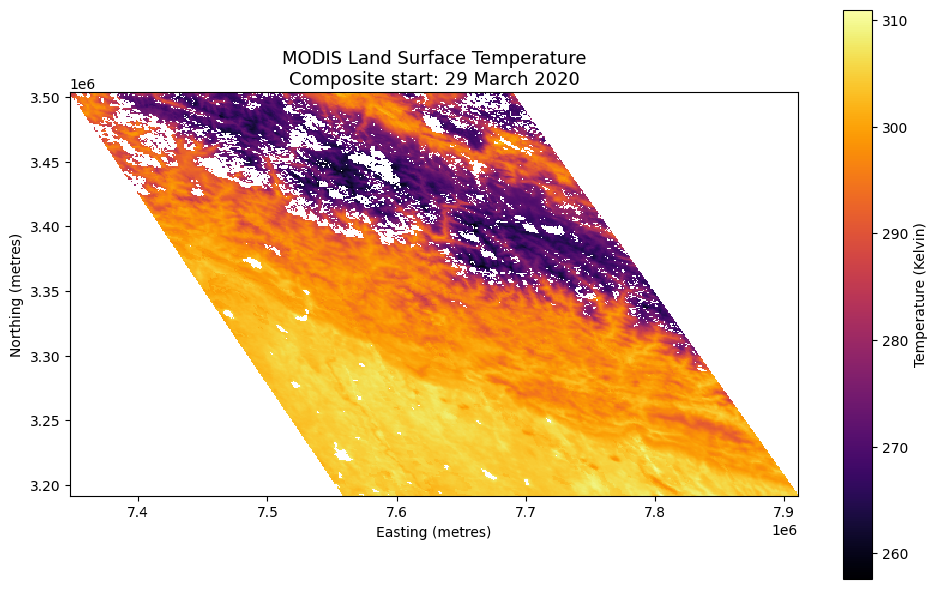


File: LST_Day_1km_2020089_clean.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (926.62543305, 926.62543305) metres
Valid pixels: 115964
Minimum: 257.5799865722656
Maximum: 310.97998046875
Mean: 292.7530517578125
Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/pilot_lst_map.png


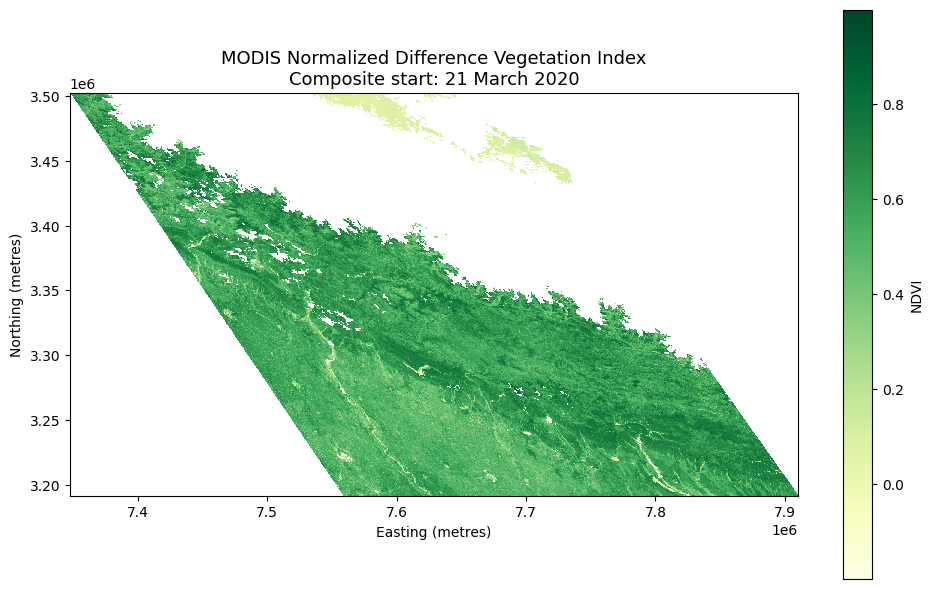


File: NDVI_2020081_clean.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (231.6563582625, 231.6563582625) metres
Valid pixels: 1305775
Minimum: -0.19909998774528503
Maximum: 0.9979999661445618
Mean: 0.5605239272117615
Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/pilot_ndvi_map.png


In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timedelta

PROCESSED_DIR = (
    PROJECT_ROOT / "data/processed/modis_pilot_april_2020"
)

REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)


def visualize_raster(filename, title, cmap, unit, output_name):

    raster_path = PROCESSED_DIR / filename

    with rasterio.open(raster_path) as src:

        data = src.read(1, masked=True)
        bounds = src.bounds
        resolution = src.res
        crs = src.crs

        extent = (
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top
        )

        valid = data.compressed()

    # Convert composite DOY to calendar date
    import re

    doy = re.search(r"(\d{7})", filename).group(1)
    year = int(doy[:4])
    day_of_year = int(doy[4:])

    composite_date = (
        datetime(year, 1, 1) +
        timedelta(days=day_of_year - 1)
    ).strftime("%d %B %Y")

    fig, ax = plt.subplots(figsize=(10, 7))

    image = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmap,
        interpolation="nearest"
    )

    colorbar = plt.colorbar(image, ax=ax, shrink=0.85)
    colorbar.set_label(unit)

    ax.set_title(
        f"{title}\nComposite start: {composite_date}",
        fontsize=13
    )

    ax.set_xlabel("Easting (metres)")
    ax.set_ylabel("Northing (metres)")

    ax.set_aspect("equal")

    plt.tight_layout()

    output_path = REPORT_DIR / output_name

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("\nFile:", filename)
    print("CRS:", crs)
    print("Resolution:", resolution, "metres")
    print("Valid pixels:", len(valid))
    print("Minimum:", float(valid.min()))
    print("Maximum:", float(valid.max()))
    print("Mean:", float(valid.mean()))
    print("Saved:", output_path)


# --------------------------------------------------
# 1. LAND SURFACE TEMPERATURE
# --------------------------------------------------

visualize_raster(
    filename="LST_Day_1km_2020089_clean.tif",
    title="MODIS Land Surface Temperature",
    cmap="inferno",
    unit="Temperature (Kelvin)",
    output_name="pilot_lst_map.png"
)


# --------------------------------------------------
# 2. NORMALIZED DIFFERENCE VEGETATION INDEX
# --------------------------------------------------

visualize_raster(
    filename="NDVI_2020081_clean.tif",
    title="MODIS Normalized Difference Vegetation Index",
    cmap="YlGn",
    unit="NDVI",
    output_name="pilot_ndvi_map.png"
)

In [ ]:
import requests
import json
import pandas as pd
from pathlib import Path

# geoBoundaries API: India, first-level administrative boundaries
API_URL = (
    "https://www.geoboundaries.org/api/current/gbOpen/IND/ADM1/"
)

response = requests.get(API_URL, timeout=60)

print("HTTP Status:", response.status_code)

response.raise_for_status()

boundary_data = response.json()

# Save original metadata for reproducibility
metadata_path = (
    PROJECT_ROOT / "data/metadata/india_adm1_boundary_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(boundary_data, f, indent=4)

print("\nBoundary dataset metadata retrieved successfully!")

# Display important metadata
important_fields = [
    "boundaryID",
    "boundaryName",
    "boundaryISO",
    "boundaryYearRepresented",
    "boundaryType",
    "boundarySource",
    "boundaryLicense",
    "licenseDetail",
    "licenseSource",
    "sourceDataUpdateDate",
    "buildDate",
    "admUnitCount",
    "gjDownloadURL",
    "simplifiedGeometryGeoJSON"
]

print("\n========== DATASET DETAILS ==========")

for field in important_fields:
    print(f"{field}: {boundary_data.get(field, 'Not available')}")

print("\nMetadata saved:", metadata_path)

# Inspect download links without downloading geometry
print("\n========== AVAILABLE GEOMETRY OPTIONS ==========")

print(
    "Full-resolution GeoJSON available:",
    bool(boundary_data.get("gjDownloadURL"))
)

print(
    "Simplified GeoJSON available:",
    bool(boundary_data.get("simplifiedGeometryGeoJSON"))
)

HTTP Status: 200

Boundary dataset metadata retrieved successfully!

========== DATASET DETAILS ==========
boundaryID: IND-ADM1-1811400
boundaryName: India
boundaryISO: IND
boundaryYearRepresented: 2011
boundaryType: ADM1
boundarySource: DataMeet India community, Election Commission of India
boundaryLicense: Creative Commons Attribution 2.5 India (CC BY 2.5 IN)
licenseDetail: nan
licenseSource: github.com/datameet/maps
sourceDataUpdateDate: Thu Jan 19 07:31:04 2023
buildDate: Dec 12, 2023
admUnitCount: 36
gjDownloadURL: https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/IND/ADM1/geoBoundaries-IND-ADM1.geojson
simplifiedGeometryGeoJSON: https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/IND/ADM1/geoBoundaries-IND-ADM1_simplified.geojson

Metadata saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/india_adm1_boundary_metadata.json

========== AVAILABLE GEOMETRY OPTIONS ==========
Full-resolution GeoJSON available: True
Simplified GeoJSON 

In [ ]:
import requests
import geopandas as gpd
import json
from pathlib import Path

# Load saved dataset metadata
metadata_path = (
    PROJECT_ROOT / "data/metadata/india_adm1_boundary_metadata.json"
)

with open(metadata_path, "r") as f:
    boundary_metadata = json.load(f)

# Full-resolution GeoJSON URL
geojson_url = boundary_metadata["gjDownloadURL"]

# Download original boundary dataset
BOUNDARY_DIR = PROJECT_ROOT / "data/raw/boundaries"
BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)

geojson_path = BOUNDARY_DIR / "india_adm1_full.geojson"

response = requests.get(geojson_url, timeout=120)
response.raise_for_status()

with open(geojson_path, "wb") as f:
    f.write(response.content)

print("Boundary GeoJSON downloaded successfully!")
print("File size (MB):", round(len(response.content) / (1024**2), 3))
print("Saved:", geojson_path)

# Load using GeoPandas
india_gdf = gpd.read_file(geojson_path)

print("\n========== GEOMETRY INSPECTION ==========")

print("Total administrative units:", len(india_gdf))
print("CRS:", india_gdf.crs)
print("Geometry types:")
print(india_gdf.geometry.geom_type.value_counts())

print("\nAvailable columns:")
print(india_gdf.columns.tolist())

print("\n========== ADMINISTRATIVE UNIT NAMES ==========")

# Inspect all non-geometry attributes
print(india_gdf.drop(columns="geometry").to_string(index=False))

print("\n========== GEOMETRY VALIDITY ==========")

print("Null geometries:", india_gdf.geometry.isna().sum())
print("Invalid geometries:", (~india_gdf.geometry.is_valid).sum())
print("Empty geometries:", india_gdf.geometry.is_empty.sum())

# Save attribute schema for reproducibility
schema_path = (
    PROJECT_ROOT / "data/metadata/india_adm1_attribute_schema.json"
)

schema = {
    "columns": india_gdf.columns.tolist(),
    "crs": str(india_gdf.crs),
    "feature_count": len(india_gdf),
    "geometry_types": (
        india_gdf.geometry.geom_type.value_counts().to_dict()
    )
}

with open(schema_path, "w") as f:
    json.dump(schema, f, indent=4)

print("\nSchema saved:", schema_path)

Boundary GeoJSON downloaded successfully!
File size (MB): 44.032
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/raw/boundaries/india_adm1_full.geojson

========== GEOMETRY INSPECTION ==========
Total administrative units: 36
CRS: EPSG:4326
Geometry types:
Polygon         24
MultiPolygon    12
Name: count, dtype: int64

Available columns:
['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']

========== ADMINISTRATIVE UNIT NAMES ==========
                               shapeName shapeISO                shapeID shapeGroup shapeType
                              Puducherry    IN-PY 1811400B81659894240990        IND      ADM1
                             Mahārāshtra    IN-MH 1811400B15614733245507        IND      ADM1
                                Nāgāland    IN-NL 1811400B74762431478096        IND      ADM1
                             Lakshadweep    IN-LD 1811400B55669546485086        IND      ADM1
                           Uttar Pradesh    IN-UP 1811400B112311

In [ ]:
import geopandas as gpd
import json
from shapely.geometry import box

# Load India ADM1 boundaries
india_gdf = gpd.read_file(
    PROJECT_ROOT / "data/raw/boundaries/india_adm1_full.geojson"
)

# Extract Uttarakhand using its ISO code
uttarakhand_gdf = india_gdf[
    india_gdf["shapeISO"] == "IN-UT"
].copy()

# Ensure exactly one feature was found
assert len(uttarakhand_gdf) == 1, (
    f"Expected 1 Uttarakhand feature, found {len(uttarakhand_gdf)}"
)

# Validate geometry
geometry = uttarakhand_gdf.geometry.iloc[0]

assert geometry is not None
assert not geometry.is_empty
assert geometry.is_valid

# Save state boundary
BOUNDARY_DIR = PROJECT_ROOT / "data/raw/boundaries"

uttarakhand_path = (
    BOUNDARY_DIR / "uttarakhand_adm1.geojson"
)

uttarakhand_gdf.to_file(
    uttarakhand_path,
    driver="GeoJSON"
)

# --------------------------------------------------
# Compare with our previous approximate pilot bbox
# --------------------------------------------------

ROI_BBOX = (77.5, 28.7, 81.1, 31.5)

pilot_bbox = box(*ROI_BBOX)

intersection = geometry.intersection(pilot_bbox)

bbox_coverage = (
    intersection.area / pilot_bbox.area * 100
)

state_coverage = (
    intersection.area / geometry.area * 100
)

# --------------------------------------------------
# Display results
# --------------------------------------------------

print("=" * 65)
print("UTTARAKHAND BOUNDARY EXTRACTION")
print("=" * 65)

print("State:", uttarakhand_gdf["shapeName"].iloc[0])
print("ISO code:", uttarakhand_gdf["shapeISO"].iloc[0])
print("Shape ID:", uttarakhand_gdf["shapeID"].iloc[0])

print("\nGeometry type:", geometry.geom_type)
print("CRS:", uttarakhand_gdf.crs)
print("Geometry valid:", geometry.is_valid)
print("Geometry area (square degrees):", geometry.area)

print("\nGeographic bounds:")
print("West:", geometry.bounds[0])
print("South:", geometry.bounds[1])
print("East:", geometry.bounds[2])
print("North:", geometry.bounds[3])

print("\n========== PILOT BBOX COMPARISON ==========")

print("Pilot bbox:", ROI_BBOX)

print(
    "Approx. bbox area inside Uttarakhand:",
    round(bbox_coverage, 2), "%"
)

print(
    "Approx. Uttarakhand area covered by pilot bbox:",
    round(state_coverage, 2), "%"
)

print("\nSaved boundary:", uttarakhand_path)

# Save extraction metadata
extraction_metadata = {
    "state": uttarakhand_gdf["shapeName"].iloc[0],
    "iso_code": "IN-UT",
    "source": "geoBoundaries India ADM1 / DataMeet",
    "boundary_year": 2011,
    "crs": str(uttarakhand_gdf.crs),
    "geometry_type": geometry.geom_type,
    "bounds": list(geometry.bounds),
    "geometry_valid": bool(geometry.is_valid),
    "pilot_bbox": list(ROI_BBOX),
    "pilot_bbox_coverage_percent": round(bbox_coverage, 2),
    "state_coverage_percent": round(state_coverage, 2),
    "boundary_file": str(uttarakhand_path)
}

metadata_path = (
    PROJECT_ROOT /
    "data/metadata/uttarakhand_boundary_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(extraction_metadata, f, indent=4)

print("Metadata saved:", metadata_path)

UTTARAKHAND BOUNDARY EXTRACTION
State: Uttarākhand
ISO code: IN-UT
Shape ID: 1811400B3558497485804

Geometry type: Polygon
CRS: EPSG:4326
Geometry valid: True
Geometry area (square degrees): 5.002005190226826

Geographic bounds:
West: 77.57230026174163
South: 28.722894906447042
East: 81.04528735631932
North: 31.456126767118253

========== PILOT BBOX COMPARISON ==========
Pilot bbox: (77.5, 28.7, 81.1, 31.5)
Approx. bbox area inside Uttarakhand: 49.62 %
Approx. Uttarakhand area covered by pilot bbox: 100.0 %

Saved boundary: /content/drive/MyDrive/EARTHPULSE_X/data/raw/boundaries/uttarakhand_adm1.geojson
Metadata saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/uttarakhand_boundary_metadata.json


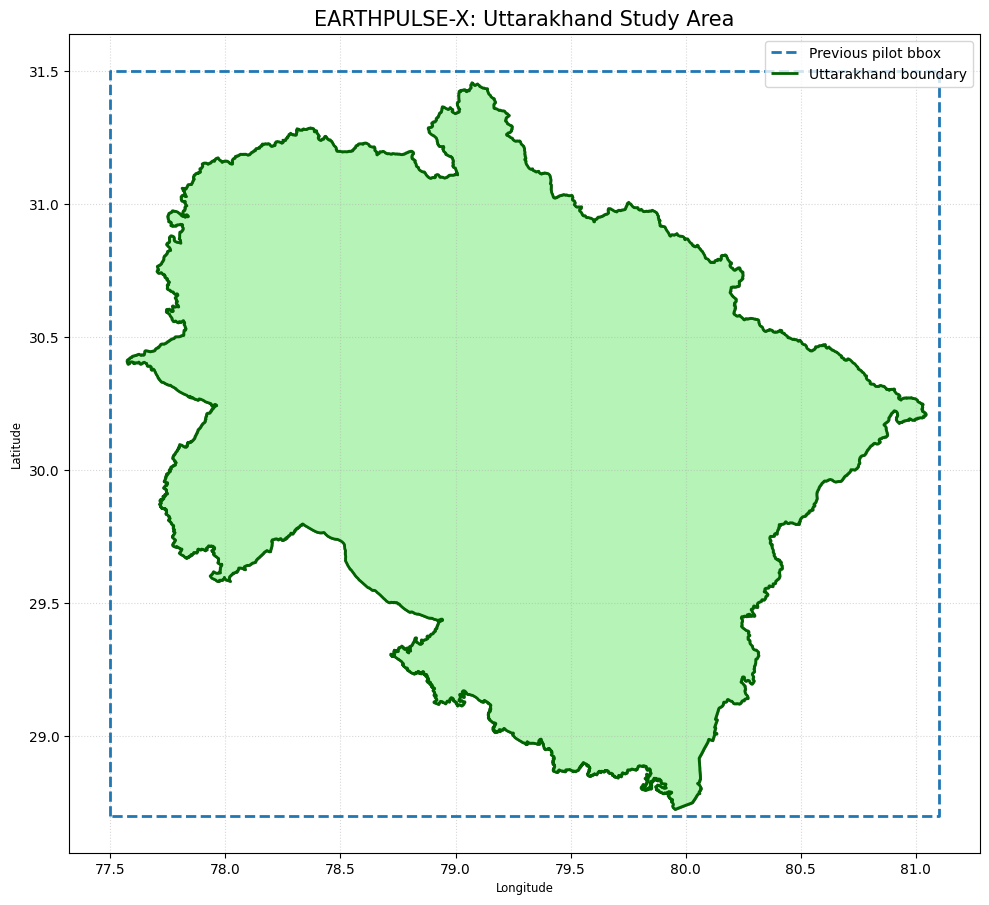

GEODESIC STUDY AREA VALIDATION
Uttarakhand area: 53,414.48 km²
Pilot bbox area: 107,704.55 km²
Intersection area: 53,414.48 km²

State covered by pilot bbox: 100.00%
Pilot bbox inside state: 49.59%

Map saved: /content/drive/MyDrive/EARTHPULSE_X/reports/uttarakhand_boundary_validation.png


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box
from pyproj import Geod

# Load extracted Uttarakhand boundary
boundary_path = (
    PROJECT_ROOT / "data/raw/boundaries/uttarakhand_adm1.geojson"
)

uttarakhand = gpd.read_file(boundary_path)

geometry = uttarakhand.geometry.iloc[0]

# Previous pilot bounding box
ROI_BBOX = (77.5, 28.7, 81.1, 31.5)
pilot_bbox = box(*ROI_BBOX)

# Geodesic area calculations using WGS84 ellipsoid
geod = Geod(ellps="WGS84")

state_area_m2, _ = geod.geometry_area_perimeter(geometry)

intersection = geometry.intersection(pilot_bbox)

intersection_area_m2, _ = geod.geometry_area_perimeter(
    intersection
)

bbox_area_m2, _ = geod.geometry_area_perimeter(
    pilot_bbox
)

state_area_km2 = abs(state_area_m2) / 1e6
intersection_area_km2 = abs(intersection_area_m2) / 1e6
bbox_area_km2 = abs(bbox_area_m2) / 1e6

state_coverage = (
    intersection_area_km2 / state_area_km2 * 100
)

bbox_coverage = (
    intersection_area_km2 / bbox_area_km2 * 100
)

# --------------------------------------------------
# Visualization
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 10))

# Pilot rectangle
pilot_gdf = gpd.GeoDataFrame(
    {"name": ["Previous pilot bounding box"]},
    geometry=[pilot_bbox],
    crs="EPSG:4326"
)

pilot_gdf.boundary.plot(
    ax=ax,
    linewidth=2,
    linestyle="--",
    label="Previous pilot bbox"
)

# Uttarakhand polygon
uttarakhand.plot(
    ax=ax,
    color="lightgreen",
    edgecolor="black",
    linewidth=1.5,
    alpha=0.65
)

# State boundary on top
uttarakhand.boundary.plot(
    ax=ax,
    color="darkgreen",
    linewidth=2,
    label="Uttarakhand boundary"
)

ax.set_title(
    "EARTHPULSE-X: Uttarakhand Study Area",
    fontsize=15
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.legend()
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()

map_path = (
    PROJECT_ROOT / "reports/uttarakhand_boundary_validation.png"
)

plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# Report
# --------------------------------------------------

print("=" * 65)
print("GEODESIC STUDY AREA VALIDATION")
print("=" * 65)

print(f"Uttarakhand area: {state_area_km2:,.2f} km²")
print(f"Pilot bbox area: {bbox_area_km2:,.2f} km²")
print(f"Intersection area: {intersection_area_km2:,.2f} km²")

print(
    f"\nState covered by pilot bbox: {state_coverage:.2f}%"
)

print(
    f"Pilot bbox inside state: {bbox_coverage:.2f}%"
)

print("\nMap saved:", map_path)

In [ ]:
import geopandas as gpd
import json
import hashlib
from pathlib import Path
from pyproj import Geod

# Load validated Uttarakhand polygon
SOURCE_PATH = (
    PROJECT_ROOT / "data/raw/boundaries/uttarakhand_adm1.geojson"
)

study_area = gpd.read_file(SOURCE_PATH)

assert len(study_area) == 1
assert study_area.crs.to_epsg() == 4326
assert study_area.geometry.iloc[0].is_valid

# Canonical study-area file
CANONICAL_PATH = (
    PROJECT_ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

study_area.to_file(CANONICAL_PATH, driver="GeoJSON")

# Calculate geodesic area
geod = Geod(ellps="WGS84")

area_m2, _ = geod.geometry_area_perimeter(
    study_area.geometry.iloc[0]
)

area_km2 = abs(area_m2) / 1e6

# Generate SHA-256 fingerprint
file_hash = hashlib.sha256(
    CANONICAL_PATH.read_bytes()
).hexdigest()

# Create reproducibility metadata
roi_metadata = {
    "project": "EARTHPULSE-X",
    "study_area": "Uttarakhand, India",
    "administrative_level": "ADM1",
    "iso_code": "IN-UT",
    "boundary_year": 2011,
    "source": "geoBoundaries / DataMeet India / Election Commission of India",
    "source_dataset": "India ADM1",
    "source_boundary_id": "IND-ADM1-1811400",
    "license": "CC BY 2.5 India",
    "crs": "EPSG:4326",
    "geometry_type": study_area.geometry.iloc[0].geom_type,
    "geodesic_area_km2": round(area_km2, 2),
    "bounds": list(study_area.total_bounds),
    "geometry_valid": bool(
        study_area.geometry.iloc[0].is_valid
    ),
    "canonical_file": str(CANONICAL_PATH),
    "sha256": file_hash
}

metadata_path = (
    PROJECT_ROOT / "data/metadata/canonical_study_area.json"
)

with open(metadata_path, "w") as f:
    json.dump(roi_metadata, f, indent=4)

print("=" * 65)
print("CANONICAL STUDY AREA FROZEN")
print("=" * 65)

print("Study area:", roi_metadata["study_area"])
print("CRS:", roi_metadata["crs"])
print("Area:", roi_metadata["geodesic_area_km2"], "km²")
print("Geometry valid:", roi_metadata["geometry_valid"])
print("SHA-256:", file_hash)

print("\nCanonical boundary:", CANONICAL_PATH)
print("Metadata:", metadata_path)

CANONICAL STUDY AREA FROZEN
Study area: Uttarakhand, India
CRS: EPSG:4326
Area: 53414.48 km²
Geometry valid: True
SHA-256: 1d140821038aa72c385450cefc85badbdeffb75cd3583c6248dcab63d36c6b26

Canonical boundary: /content/drive/MyDrive/EARTHPULSE_X/data/raw/boundaries/uttarakhand_study_area.geojson
Metadata: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/canonical_study_area.json


In [ ]:
import json
from pathlib import Path
from shapely.geometry import shape

BOUNDARY_PATH = (
    PROJECT_ROOT /
    "data/raw/boundaries/uttarakhand_study_area.geojson"
)

with open(BOUNDARY_PATH, "r") as f:
    geojson_data = json.load(f)

# Validate GeoJSON structure
assert geojson_data["type"] == "FeatureCollection"
assert len(geojson_data["features"]) == 1

feature = geojson_data["features"][0]
geometry = shape(feature["geometry"])

assert geometry.is_valid
assert not geometry.is_empty
assert geometry.geom_type == "Polygon"

# Create reusable AppEEARS geometry file
appeears_geometry = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {},
            "geometry": feature["geometry"]
        }
    ]
}

output_path = (
    PROJECT_ROOT /
    "data/metadata/uttarakhand_appeears_geometry.json"
)

with open(output_path, "w") as f:
    json.dump(appeears_geometry, f, indent=2)

# Verify saved geometry
with open(output_path, "r") as f:
    verification = json.load(f)

verified_geometry = shape(
    verification["features"][0]["geometry"]
)

print("AppEEARS geometry prepared successfully!")
print("Geometry type:", verified_geometry.geom_type)
print("Geometry valid:", verified_geometry.is_valid)
print("CRS: EPSG:4326")
print("Number of features:", len(verification["features"]))
print("Saved:", output_path)

AppEEARS geometry prepared successfully!
Geometry type: Polygon
Geometry valid: True
CRS: EPSG:4326
Number of features: 1
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/uttarakhand_appeears_geometry.json


In [ ]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from shapely.geometry import shape

# --------------------------------------------------
# 1. Inspect canonical geometry complexity
# --------------------------------------------------

geometry_path = (
    PROJECT_ROOT /
    "data/metadata/uttarakhand_appeears_geometry.json"
)

with open(geometry_path, "r") as f:
    geojson = json.load(f)

geometry = shape(geojson["features"][0]["geometry"])

vertex_count = len(geometry.exterior.coords)

print("========== STUDY AREA COMPLEXITY ==========")
print("Geometry type:", geometry.geom_type)
print("Boundary vertices:", vertex_count)
print("Geometry valid:", geometry.is_valid)


# --------------------------------------------------
# 2. Load actual pilot bundle manifest
# --------------------------------------------------

manifest_path = (
    PROJECT_ROOT /
    "data/metadata/modis_pilot_bundle_manifest.json"
)

with open(manifest_path, "r") as f:
    manifest = json.load(f)

files = manifest["files"]

file_df = pd.DataFrame(files)

# Group raster sizes by layer
layer_groups = {
    "LST": "LST_Day_1km",
    "QC_Day": "QC_Day",
    "NDVI": "_NDVI_",
    "VI_Quality": "VI_Quality"
}

pilot_sizes = {}

for layer, keyword in layer_groups.items():

    selected = file_df[
        file_df["file_name"].str.contains(
            keyword, regex=False
        )
    ]

    pilot_sizes[layer] = {
        "count": len(selected),
        "total_mb": selected["file_size"].sum() / (1024**2),
        "average_mb": (
            selected["file_size"].mean() / (1024**2)
            if len(selected) else 0
        )
    }

print("\n========== PILOT FILE SIZE BASELINE ==========")

for layer, values in pilot_sizes.items():
    print(
        f"{layer}: {values['count']} files | "
        f"Average: {values['average_mb']:.3f} MB"
    )


# --------------------------------------------------
# 3. Estimate full-period output volume
# --------------------------------------------------

# Previously discovered temporal coverage
FULL_LST_COMPOSITES = 483
FULL_NDVI_COMPOSITES = 243

PILOT_LST_COMPOSITES = 5
PILOT_NDVI_COMPOSITES = 3

projected_files = {
    "LST": FULL_LST_COMPOSITES,
    "QC_Day": FULL_LST_COMPOSITES,
    "NDVI": FULL_NDVI_COMPOSITES,
    "VI_Quality": FULL_NDVI_COMPOSITES
}

estimated_total_mb = 0

print("\n========== FULL PERIOD ESTIMATE ==========")

for layer, count in projected_files.items():

    average_mb = pilot_sizes[layer]["average_mb"]

    estimated_mb = average_mb * count
    estimated_total_mb += estimated_mb

    print(
        f"{layer}: {count} files | "
        f"Estimated size: {estimated_mb:.2f} MB"
    )

print("\nEstimated total GeoTIFF volume:")
print(f"{estimated_total_mb / 1024:.2f} GB")


# --------------------------------------------------
# 4. Annual extraction plan
# --------------------------------------------------

annual_plan = []

for year in range(2015, 2026):

    lst_count = 0
    ndvi_count = 0

    # Use approximate annual distribution for planning
    # Actual task granules will be verified before submission.
    if year == 2015:
        months = 9  # April to December
    elif year == 2025:
        months = 9  # January to September
    else:
        months = 12

    lst_count = round(483 * months / 126)
    ndvi_count = round(243 * months / 126)

    annual_plan.append({
        "year": year,
        "months": months,
        "estimated_LST_composites": lst_count,
        "estimated_NDVI_composites": ndvi_count
    })

annual_df = pd.DataFrame(annual_plan)

print("\n========== PROPOSED ANNUAL BATCH PLAN ==========")
print(annual_df.to_string(index=False))

plan_path = (
    PROJECT_ROOT /
    "data/metadata/full_period_extraction_plan.csv"
)

annual_df.to_csv(plan_path, index=False)

print("\nPlan saved:", plan_path)

========== STUDY AREA COMPLEXITY ==========
Geometry type: Polygon
Boundary vertices: 18790
Geometry valid: True

========== PILOT FILE SIZE BASELINE ==========
LST: 5 files | Average: 0.313 MB
QC_Day: 5 files | Average: 0.021 MB
NDVI: 3 files | Average: 5.505 MB
VI_Quality: 3 files | Average: 0.505 MB

========== FULL PERIOD ESTIMATE ==========
LST: 483 files | Estimated size: 150.95 MB
QC_Day: 483 files | Estimated size: 10.14 MB
NDVI: 243 files | Estimated size: 1337.67 MB
VI_Quality: 243 files | Estimated size: 122.71 MB

Estimated total GeoTIFF volume:
1.58 GB

========== PROPOSED ANNUAL BATCH PLAN ==========
 year  months  estimated_LST_composites  estimated_NDVI_composites
 2015       9                        34                         17
 2016      12                        46                         23
 2017      12                        46                         23
 2018      12                        46                         23
 2019      12                        46    

In [ ]:
import json
from pathlib import Path

metadata_path = (
    PROJECT_ROOT / "data/metadata/nasa_granule_discovery.json"
)

with open(metadata_path, "r") as f:
    granule_data = json.load(f)

print("Top-level data type:", type(granule_data).__name__)

if isinstance(granule_data, dict):

    print("\nAvailable dataset keys:")
    for key, value in granule_data.items():
        print(
            key,
            "| Type:", type(value).__name__,
            "| Records:", len(value) if hasattr(value, "__len__") else "N/A"
        )

        if isinstance(value, list) and value:
            print("\nFirst record structure:")
            print(json.dumps(value[0], indent=2)[:2500])
            break

elif isinstance(granule_data, list):

    print("Total records:", len(granule_data))
    if granule_data:
        print(json.dumps(granule_data[0], indent=2)[:2500])

print("\nInspection complete.")

Top-level data type: dict

Available dataset keys:
land_surface_temperature | Type: dict | Records: 5
soil_moisture | Type: dict | Records: 5
precipitation | Type: dict | Records: 5
vegetation_index | Type: dict | Records: 5

Inspection complete.


In [ ]:
import json

metadata_path = (
    PROJECT_ROOT / "data/metadata/nasa_granule_discovery.json"
)

with open(metadata_path, "r") as f:
    granule_data = json.load(f)

for dataset_name, dataset_info in granule_data.items():

    print("\n" + "=" * 65)
    print("DATASET:", dataset_name)
    print("=" * 65)

    for key, value in dataset_info.items():

        print(f"\nField: {key}")
        print("Type:", type(value).__name__)

        if isinstance(value, list):
            print("Number of records:", len(value))
            if value:
                print("First record:")
                print(json.dumps(value[0], indent=2)[:1500])

        elif isinstance(value, dict):
            print("Nested keys:", list(value.keys()))

        else:
            print("Value:", str(value)[:1000])


DATASET: land_surface_temperature

Field: product
Type: str
Value: MOD11A2

Field: version
Type: str
Value: 061

Field: count
Type: int
Value: 1932

Field: status
Type: str
Value: GRANULES FOUND

Field: sample_granules
Type: list
Number of records: 3
First record:
{
  "index": 0,
  "summary": {},
  "data_links": [
    "https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-public/MOD11A2.061/MOD11A2.A2015089.h24v06.061.2021352083215/BROWSE.MOD11A2.A2015089.h24v06.061.2021352033216.1.jpg",
    "https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/MOD11A2.061/MOD11A2.A2015089.h24v06.061.2021352083215/MOD11A2.A2015089.h24v06.061.2021352083215.hdf"
  ]
}

DATASET: soil_moisture

Field: product
Type: str
Value: SPL3SMP_E

Field: version
Type: str
Value: 006

Field: count
Type: int
Value: 3752

Field: status
Type: str
Value: GRANULES FOUND

Field: sample_granules
Type: list
Number of records: 3
First record:
{
  "index": 0,
  "summary": {},
  "data_links": [
    "https://data.nsidc.ea

In [ ]:
import earthaccess
import json
from pathlib import Path

# Load canonical Uttarakhand boundary
boundary_path = (
    PROJECT_ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

with open(boundary_path, "r") as f:
    boundary_data = json.load(f)

from shapely.geometry import shape

geometry = shape(boundary_data["features"][0]["geometry"])

# Bounding box used only for granule discovery.
# Final extraction will still use the exact canonical polygon.
bbox = tuple(geometry.bounds)

print("Study-area bounding box:", bbox)

# Retrieve full-period MODIS granule metadata
products = {
    "LST": {"short_name": "MOD11A2", "version": "061"},
    "NDVI": {"short_name": "MOD13Q1", "version": "061"}
}

granule_results = {}

for name, product in products.items():

    print(f"\nSearching {name} ({product['short_name']})...")

    results = earthaccess.search_data(
        short_name=product["short_name"],
        version=product["version"],
        temporal=("2015-04-01", "2025-09-30"),
        bounding_box=bbox
    )

    granule_results[name] = results

    print("Granules retrieved:", len(results))

    if results:
        sample = results[0]

        print("Sample record type:", type(sample).__name__)
        print("Sample record fields:", list(sample.keys())[:15])

        print(
            "Sample granule identifier:",
            sample.get("umm", {}).get("GranuleUR", "Not found")
        )

print("\nGranule retrieval inspection complete.")

Study-area bounding box: (77.57230026174163, 28.722894906447042, 81.04528735631932, 31.456126767118253)

Searching LST (MOD11A2)...
Granules retrieved: 1932
Sample record type: DataGranule
Sample record fields: ['meta', 'umm', 'size']
Sample granule identifier: MOD11A2.A2015089.h24v06.061.2021352083215

Searching NDVI (MOD13Q1)...
Granules retrieved: 972
Sample record type: DataGranule
Sample record fields: ['meta', 'umm', 'size']
Sample granule identifier: MOD13Q1.A2015081.h24v06.061.2021321195741

Granule retrieval inspection complete.


In [ ]:
import re
import pandas as pd
import json

def extract_modis_records(results, variable_name):

    records = []

    for granule in results:

        granule_id = granule.get("umm", {}).get("GranuleUR", "")

        # Example: MOD11A2.A2015089.h24v06.061...
        match = re.search(
            r"\.A(\d{4})(\d{3})\.(h\d{2}v\d{2})\.",
            granule_id
        )

        if not match:
            print("Could not parse:", granule_id)
            continue

        year = int(match.group(1))
        doy = int(match.group(2))
        tile = match.group(3)

        date = (
            pd.Timestamp(year=year, month=1, day=1)
            + pd.Timedelta(days=doy - 1)
        )

        records.append({
            "variable": variable_name,
            "granule_id": granule_id,
            "year": year,
            "doy": doy,
            "date": date,
            "tile": tile
        })

    return pd.DataFrame(records)


# Create complete granule tables
lst_df = extract_modis_records(granule_results["LST"], "LST")
ndvi_df = extract_modis_records(granule_results["NDVI"], "NDVI")

# Unique date counts per year
lst_yearly = (
    lst_df.drop_duplicates(["date"])
    .groupby("year")["date"]
    .nunique()
    .rename("LST_composites")
)

ndvi_yearly = (
    ndvi_df.drop_duplicates(["date"])
    .groupby("year")["date"]
    .nunique()
    .rename("NDVI_composites")
)

yearly_counts = pd.concat(
    [lst_yearly, ndvi_yearly],
    axis=1
).fillna(0).astype(int)

print("========== EXACT YEARLY COMPOSITE COUNTS ==========")
print(yearly_counts.to_string())

print("\n========== VALIDATION ==========")
print("LST granules:", len(lst_df))
print("LST unique dates:", lst_df["date"].nunique())
print("NDVI granules:", len(ndvi_df))
print("NDVI unique dates:", ndvi_df["date"].nunique())

print("\nLST tiles per date:")
print(lst_df.groupby("date")["tile"].nunique().value_counts().sort_index())

print("\nNDVI tiles per date:")
print(ndvi_df.groupby("date")["tile"].nunique().value_counts().sort_index())

# Save auditable metadata
yearly_counts.to_csv(
    PROJECT_ROOT / "data/metadata/exact_modis_yearly_counts.csv"
)

lst_df.to_csv(
    PROJECT_ROOT / "data/metadata/lst_granule_inventory.csv",
    index=False
)

ndvi_df.to_csv(
    PROJECT_ROOT / "data/metadata/ndvi_granule_inventory.csv",
    index=False
)

print("\nSaved yearly counts and granule inventories.")

========== EXACT YEARLY COMPOSITE COUNTS ==========
      LST_composites  NDVI_composites
year                                 
2015              35               18
2016              46               23
2017              46               23
2018              46               23
2019              46               23
2020              46               23
2021              46               23
2022              45               23
2023              46               23
2024              46               23
2025              35               18

========== VALIDATION ==========
LST granules: 1932
LST unique dates: 483
NDVI granules: 972
NDVI unique dates: 243

LST tiles per date:
tile
4    483
Name: count, dtype: int64

NDVI tiles per date:
tile
4    243
Name: count, dtype: int64

Saved yearly counts and granule inventories.


In [ ]:
import pandas as pd
import json

schedule = yearly_counts.reset_index()

schedule["start_date"] = [
    "2015-04-01" if y == 2015 else f"{y}-01-01"
    for y in schedule["year"]
]

schedule["end_date"] = [
    "2025-09-30" if y == 2025 else f"{y}-12-31"
    for y in schedule["year"]
]

schedule["status"] = "PLANNED_NOT_SUBMITTED"

schedule_path = (
    PROJECT_ROOT / "data/metadata/verified_modis_extraction_schedule.csv"
)

schedule.to_csv(schedule_path, index=False)

print("Verified schedule saved:", schedule_path)
print("\n", schedule.to_string(index=False))
print("\nTotal LST composites:", schedule["LST_composites"].sum())
print("Total NDVI composites:", schedule["NDVI_composites"].sum())
print("Annual tasks planned:", len(schedule))

Verified schedule saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/verified_modis_extraction_schedule.csv

  year  LST_composites  NDVI_composites start_date   end_date                status
 2015              35               18 2015-04-01 2015-12-31 PLANNED_NOT_SUBMITTED
 2016              46               23 2016-01-01 2016-12-31 PLANNED_NOT_SUBMITTED
 2017              46               23 2017-01-01 2017-12-31 PLANNED_NOT_SUBMITTED
 2018              46               23 2018-01-01 2018-12-31 PLANNED_NOT_SUBMITTED
 2019              46               23 2019-01-01 2019-12-31 PLANNED_NOT_SUBMITTED
 2020              46               23 2020-01-01 2020-12-31 PLANNED_NOT_SUBMITTED
 2021              46               23 2021-01-01 2021-12-31 PLANNED_NOT_SUBMITTED
 2022              45               23 2022-01-01 2022-12-31 PLANNED_NOT_SUBMITTED
 2023              46               23 2023-01-01 2023-12-31 PLANNED_NOT_SUBMITTED
 2024              46               23 2024-01-01 2024

In [ ]:
import requests

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

response = requests.get(
    API_URL,
    headers=APPEEARS_HEADERS,
    timeout=30
)

print("API URL:", API_URL)
print("HTTP Status:", response.status_code)
print("Content Type:", response.headers.get("Content-Type"))
print("\nResponse:")
print(response.text[:4000])

API URL: https://appeears.earthdatacloud.nasa.gov/api/
HTTP Status: 200
Content Type: text/html; charset=utf-8

Response:
<!doctype html>
<html lang=en>
   <head>
      <meta charset=utf-8>
      <meta name=viewport content="width=device-width, initial-scale=1, maximum-scale=1">
      <meta name=robots content="index, follow">
      <meta name=description content="AppEEARS API Documentation">
      <title>AppEEARS API Documentation</title>
      <link rel=icon href="images/favicon.1b1b2272.ico">
      <link href=css/screen.944d3b8a.css rel=stylesheet media=screen>
      <link href=css/print.2d384fdd.css rel=stylesheet media=print>
      <link href=css/highlight-night-owl.6e1d3fbc.css rel=stylesheet media=screen,print>
      <script src=js/all.5a58a399.js></script>
   </head>
   <body class="" data-languages="[[&#34;shell&#34;,&#34;cURL&#34;],[&#34;python&#34;,&#34;Python 3&#34;],[&#34;r&#34;,&#34;R&#34;]]">
      <a href=# id=nav-button>
         <span>MENU <img alt=navbar class=image-

In [ ]:
from bs4 import BeautifulSoup
import requests

response = requests.get(API_URL, timeout=30)
soup = BeautifulSoup(response.text, "html.parser")

keywords = [
    "task",
    "area",
    "projection",
    "format",
    "bundle",
    "limit",
    "layers"
]

for heading in soup.find_all(["h1", "h2", "h3"]):

    heading_text = heading.get_text(" ", strip=True)

    if any(word in heading_text.lower() for word in keywords):

        print("\n" + "=" * 65)
        print("SECTION:", heading_text)
        print("=" * 65)

        content = []
        for element in heading.find_all_next():
            if element.name in ["h1", "h2", "h3"]:
                break

            text = element.get_text(" ", strip=True)
            if text:
                content.append(text)

        print("\n".join(content)[:3500])


SECTION: Formatting
Example request
Example request
$ curl "https://appeears.earthdatacloud.nasa.gov/api/product/SRTMGL1_NC.003?pretty=true"
$ curl "https://appeears.earthdatacloud.nasa.gov/api/product/SRTMGL1_NC.003?pretty=true"
$
curl "https://appeears.earthdatacloud.nasa.gov/api/product/SRTMGL1_NC.003?pretty=true"
"https://appeears.earthdatacloud.nasa.gov/api/product/SRTMGL1_NC.003?pretty=true"
import requests

params = { 'pretty' : True }
product_id = 'SRTMGL1_NC.003' response = requests.get( 'https://appeears.earthdatacloud.nasa.gov/api/product/{0}' . format (product_id),
    params=params)
product_response = response.text print (product_response)
import requests

params = { 'pretty' : True }
product_id = 'SRTMGL1_NC.003' response = requests.get( 'https://appeears.earthdatacloud.nasa.gov/api/product/{0}' . format (product_id),
    params=params)
product_response = response.text print (product_response)
import
'pretty'
True
'SRTMGL1_NC.003'
'https://appeears.earthdatacloud.nasa.go

In [ ]:
import requests

projection_url = API_URL + "spatial/proj"

response = requests.get(
    projection_url,
    headers=APPEEARS_HEADERS,
    timeout=30
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

projection_data = response.json()

for projection in projection_data:

    if projection.get("Name") in ["native", "sinu_modis", "geographic"]:

        print("\nProjection:", projection.get("Name"))
        print("Description:", projection.get("Description"))
        print("Available:", projection.get("Available"))
        print("Platforms:", projection.get("Platforms"))
        print("Units:", projection.get("Units"))

HTTP Status: 200

Projection: native
Description: 
Available: True
Platforms: 
Units: 

Projection: geographic
Description: 
Available: True
Platforms: ['SRTM', 'ECOSTRESS', 'SSEBop ET', 'GPW', 'ASTER GDEM', 'NASADEM', 'MEaSUREs LSTE', 'EMIT', 'PACE_OCI', 'ECOSTRESS/OCO-3']
Units: degrees

Projection: sinu_modis
Description: 
Available: True
Platforms: ['Combined MODIS', 'Terra MODIS', 'Aqua MODIS', 'Suomi NPP VIIRS', 'NOAA-20 VIIRS', 'NOAA-21 VIIRS', 'Global WELD']
Units: meters


In [ ]:
import json
from pathlib import Path

# Load canonical AppEEARS geometry
geometry_path = (
    PROJECT_ROOT / "data/metadata/uttarakhand_appeears_geometry.json"
)

with open(geometry_path, "r") as f:
    uttarakhand_geometry = json.load(f)

# First annual LST request
lst_2015_task = {
    "task_type": "area",
    "task_name": "EARTHPULSE_X_LST_2015",
    "params": {
        "dates": [
            {
                "startDate": "04-01-2015",
                "endDate": "12-31-2015",
                "recurring": False,
                "yearRange": [2015, 2015]
            }
        ],
        "layers": [
            {
                "product": "MOD11A2.061",
                "layer": "LST_Day_1km"
            },
            {
                "product": "MOD11A2.061",
                "layer": "QC_Day"
            }
        ],
        "geo": uttarakhand_geometry,
        "output": {
            "format": {
                "type": "geotiff"
            },
            "projection": "native"
        }
    }
}

# Basic validation
assert lst_2015_task["task_type"] == "area"
assert len(lst_2015_task["params"]["layers"]) == 2
assert lst_2015_task["params"]["geo"]["type"] == "FeatureCollection"
assert lst_2015_task["params"]["output"]["projection"] == "native"
assert lst_2015_task["params"]["output"]["format"]["type"] == "geotiff"

# Save locally
payload_path = (
    PROJECT_ROOT / "data/metadata/appeears_lst_2015_request.json"
)

with open(payload_path, "w") as f:
    json.dump(lst_2015_task, f, indent=4)

print("Request payload validated successfully!")
print("Task name:", lst_2015_task["task_name"])
print("Task type:", lst_2015_task["task_type"])
print("Layers:", [x["layer"] for x in lst_2015_task["params"]["layers"]])
print("Projection:", lst_2015_task["params"]["output"]["projection"])
print("Output:", lst_2015_task["params"]["output"]["format"]["type"])
print("Geometry:", uttarakhand_geometry["type"])
print("Saved:", payload_path)

print("\nSubmission status: NOT SUBMITTED")

Request payload validated successfully!
Task name: EARTHPULSE_X_LST_2015
Task type: area
Layers: ['LST_Day_1km', 'QC_Day']
Projection: native
Output: geotiff
Geometry: FeatureCollection
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_lst_2015_request.json

Submission status: NOT SUBMITTED


In [ ]:
import json
from pathlib import Path

pilot_path = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
    / "MOD11A2.061_request.json"
)

print("Pilot request path:", pilot_path)
print("File exists:", pilot_path.exists())

if pilot_path.exists():

    with open(pilot_path, "r") as f:
        pilot_request = json.load(f)

    print("\nPilot request structure:")
    print(json.dumps(pilot_request, indent=2)[:7000])

else:
    print("\nSearching for request JSON in pilot folder:")

    for path in (
        PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
    ).glob("*request*.json"):
        print(path.name)

Pilot request path: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_pilot_april_2020/MOD11A2.061_request.json
File exists: False

Searching for request JSON in pilot folder:
EARTHPULSE-X-MODIS-PILOT-APRIL-2020-request.json


In [ ]:
import json

pilot_path = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
    / "EARTHPULSE-X-MODIS-PILOT-APRIL-2020-request.json"
)

with open(pilot_path, "r") as f:
    pilot_request = json.load(f)

print("PILOT REQUEST FOUND")
print("=" * 60)

print("\nTask type:", pilot_request.get("task_type"))
print("Task name:", pilot_request.get("task_name"))

print("\nDate configuration:")
print(json.dumps(
    pilot_request.get("params", {}).get("dates"),
    indent=4
))

print("\nOutput configuration:")
print(json.dumps(
    pilot_request.get("params", {}).get("output"),
    indent=4
))

print("\nSelected layers:")
print(json.dumps(
    pilot_request.get("params", {}).get("layers"),
    indent=4
))

print("\nGeometry type:",
      pilot_request.get("params", {}).get("geo", {}).get("type"))

print("\nFull request saved for comparison.")

PILOT REQUEST FOUND

Task type: area
Task name: EARTHPULSE_X_MODIS_PILOT_APRIL_2020

Date configuration:
[
    {
        "endDate": "04-30-2020",
        "startDate": "04-01-2020"
    }
]

Output configuration:
{
    "format": {
        "type": "geotiff"
    },
    "projection": "native"
}

Selected layers:
[
    {
        "layer": "LST_Day_1km",
        "product": "MOD11A2.061"
    },
    {
        "layer": "QC_Day",
        "product": "MOD11A2.061"
    },
    {
        "layer": "_250m_16_days_NDVI",
        "product": "MOD13Q1.061"
    },
    {
        "layer": "_250m_16_days_VI_Quality",
        "product": "MOD13Q1.061"
    }
]

Geometry type: FeatureCollection

Full request saved for comparison.


In [ ]:
import json

# Use the successful pilot's date-object structure
lst_2015_task["params"]["dates"] = [
    {
        "startDate": "04-01-2015",
        "endDate": "12-31-2015"
    }
]

# Save corrected request
payload_path = (
    PROJECT_ROOT / "data/metadata/appeears_lst_2015_request.json"
)

with open(payload_path, "w") as f:
    json.dump(lst_2015_task, f, indent=4)

# Verify date structure
with open(payload_path, "r") as f:
    verified_payload = json.load(f)

print("Corrected date configuration:")
print(json.dumps(verified_payload["params"]["dates"], indent=4))

print("\nMatches pilot date-object structure:",
      set(verified_payload["params"]["dates"][0].keys())
      == set(pilot_request["params"]["dates"][0].keys()))

print("\nSaved:", payload_path)
print("Submission status: NOT SUBMITTED")

Corrected date configuration:
[
    {
        "startDate": "04-01-2015",
        "endDate": "12-31-2015"
    }
]

Matches pilot date-object structure: True

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_lst_2015_request.json
Submission status: NOT SUBMITTED


In [ ]:
import json

# Build combined 2015 MODIS request
combined_2015_task = {
    "task_type": "area",
    "task_name": "EARTHPULSE_X_MODIS_COMBINED_2015",
    "params": {
        "dates": [
            {
                "startDate": "04-01-2015",
                "endDate": "12-31-2015"
            }
        ],
        "layers": [
            {
                "product": "MOD11A2.061",
                "layer": "LST_Day_1km"
            },
            {
                "product": "MOD11A2.061",
                "layer": "QC_Day"
            },
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_NDVI"
            },
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_VI_Quality"
            }
        ],
        "geo": uttarakhand_geometry,
        "output": {
            "format": {
                "type": "geotiff"
            },
            "projection": "native"
        }
    }
}

# Validate the request
assert combined_2015_task["task_type"] == "area"
assert len(combined_2015_task["params"]["layers"]) == 4
assert combined_2015_task["params"]["geo"]["type"] == "FeatureCollection"

products = {
    layer["product"]
    for layer in combined_2015_task["params"]["layers"]
}

assert products == {"MOD11A2.061", "MOD13Q1.061"}

# Save locally
combined_path = (
    PROJECT_ROOT
    / "data/metadata/appeears_combined_modis_2015_request.json"
)

with open(combined_path, "w") as f:
    json.dump(combined_2015_task, f, indent=4)

print("Combined request validated!")
print("Task:", combined_2015_task["task_name"])
print("Date:", combined_2015_task["params"]["dates"])
print("Products:", sorted(products))
print("Total layers:", len(combined_2015_task["params"]["layers"]))
print("Projection:", combined_2015_task["params"]["output"]["projection"])
print("Geometry:", combined_2015_task["params"]["geo"]["type"])
print("Saved:", combined_path)
print("\nSubmission status: NOT SUBMITTED")

Combined request validated!
Task: EARTHPULSE_X_MODIS_COMBINED_2015
Date: [{'startDate': '04-01-2015', 'endDate': '12-31-2015'}]
Products: ['MOD11A2.061', 'MOD13Q1.061']
Total layers: 4
Projection: native
Geometry: FeatureCollection
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2015_request.json

Submission status: NOT SUBMITTED


In [ ]:
import json
from pathlib import Path
from shapely.geometry import shape
from shapely.validation import explain_validity

# Load saved combined request
with open(combined_path, "r") as f:
    request_data = json.load(f)

# Extract submitted geometry
geojson = request_data["params"]["geo"]
feature = geojson["features"][0]
geometry = shape(feature["geometry"])

# Count polygon vertices, including interior rings
def count_vertices(polygon):
    total = len(polygon.exterior.coords)

    for ring in polygon.interiors:
        total += len(ring.coords)

    return total

if geometry.geom_type == "Polygon":
    vertex_count = count_vertices(geometry)

elif geometry.geom_type == "MultiPolygon":
    vertex_count = sum(
        count_vertices(polygon)
        for polygon in geometry.geoms
    )

else:
    raise ValueError(f"Unexpected geometry: {geometry.geom_type}")

# Request file size
request_size_bytes = Path(combined_path).stat().st_size

# Compare with canonical geometry
canonical_path = (
    PROJECT_ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

with open(canonical_path, "r") as f:
    canonical_geojson = json.load(f)

canonical_geometry = shape(
    canonical_geojson["features"][0]["geometry"]
)

same_geometry = geometry.equals(canonical_geometry)

print("========== GEOMETRY AUDIT ==========")
print("Geometry type:", geometry.geom_type)
print("Valid:", geometry.is_valid)
print("Validity reason:", explain_validity(geometry))
print("Closed exterior ring:", geometry.exterior.is_ring)
print("Vertex count:", vertex_count)
print("Bounds:", geometry.bounds)
print("Canonical geometry matches:", same_geometry)

print("\n========== REQUEST SIZE ==========")
print("Request size:", f"{request_size_bytes:,} bytes")
print("Request size:", f"{request_size_bytes / 1024:.2f} KB")
print("Request size:", f"{request_size_bytes / (1024**2):.3f} MB")

print("\n========== FINAL CHECK ==========")
print("Four layers:", len(request_data["params"]["layers"]) == 4)
print("Valid geometry:", geometry.is_valid)
print("Exact canonical geometry:", same_geometry)

print("\nSubmission status: NOT SUBMITTED")

========== GEOMETRY AUDIT ==========
Geometry type: Polygon
Valid: True
Validity reason: Valid Geometry
Closed exterior ring: True
Vertex count: 18790
Bounds: (77.57230026174163, 28.722894906447042, 81.04528735631932, 31.456126767118253)
Canonical geometry matches: True

========== REQUEST SIZE ==========
Request size: 3,354,163 bytes
Request size: 3275.55 KB
Request size: 3.199 MB

========== FINAL CHECK ==========
Four layers: True
Valid geometry: True
Exact canonical geometry: True

Submission status: NOT SUBMITTED


In [ ]:
import requests

response = requests.get(
    API_URL + "task",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

existing_tasks = response.json()

print("\nExisting task records:", len(existing_tasks))

for task in existing_tasks:

    print("\nTask:", task.get("task_name"))
    print("Type:", task.get("task_type"))
    print("Status:", task.get("status"))
    print("Created:", task.get("created"))
    print("Task ID:", task.get("task_id"))

    if task.get("task_name") == "EARTHPULSE_X_MODIS_PILOT_APRIL_2020":
        print("Pilot task found!")

HTTP Status: 200

Existing task records: 1

Task: EARTHPULSE_X_MODIS_PILOT_APRIL_2020
Type: area
Status: done
Created: 2026-11-04T16:13:52.097315
Task ID: 0599311a-2c07-4688-a797-5d86e81e1870
Pilot task found!


In [ ]:
import json
from pathlib import Path
from shapely.geometry import shape

pilot_path = (
    PROJECT_ROOT / "data/raw/modis_pilot_april_2020"
    / "EARTHPULSE-X-MODIS-PILOT-APRIL-2020-request.json"
)

with open(pilot_path, "r") as f:
    pilot_data = json.load(f)

with open(combined_path, "r") as f:
    full_data = json.load(f)

def geometry_stats(request):
    geo = request["params"]["geo"]
    geom = shape(geo["features"][0]["geometry"])

    if geom.geom_type == "Polygon":
        vertices = len(geom.exterior.coords)
    else:
        vertices = sum(
            len(p.exterior.coords)
            for p in geom.geoms
        )

    return {
        "geometry_type": geom.geom_type,
        "vertices": vertices,
        "valid": geom.is_valid,
        "request_kb": len(
            json.dumps(request).encode("utf-8")
        ) / 1024
    }

print("PILOT REQUEST:")
print(geometry_stats(pilot_data))

print("\nFULL-STATE REQUEST:")
print(geometry_stats(full_data))

PILOT REQUEST:
{'geometry_type': 'Polygon', 'vertices': 5, 'valid': True, 'request_kb': 1.17578125}

FULL-STATE REQUEST:
{'geometry_type': 'Polygon', 'vertices': 18790, 'valid': True, 'request_kb': 742.5986328125}


In [ ]:
import requests
from bs4 import BeautifulSoup

response = requests.get(API_URL, timeout=60)

print("HTTP Status:", response.status_code)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("\n========== DOCUMENTATION LINKS ==========")

for link in soup.find_all("a", href=True):
    href = link["href"]
    label = link.get_text(" ", strip=True)

    if any(word in (href + " " + label).lower()
           for word in ["swagger", "openapi", "schema", "task", "document"]):
        print(f"{label or 'Link'}: {href}")

print("\n========== LIMIT-RELATED REFERENCES ==========")

page_text = soup.get_text(" ", strip=True)
terms = [
    "geometry",
    "polygon",
    "vertices",
    "maximum",
    "maximum size",
    "payload",
    "request size",
    "limit"
]

for term in terms:
    count = page_text.lower().count(term.lower())
    print(f"{term}: {count} occurrence(s)")

print("\nDocumentation page inspected.")
print("No task submitted.")

HTTP Status: 200

========== DOCUMENTATION LINKS ==========
below: #list-tasks
Task object: #task-object
query parameters: #task-query-parameters
task object section: #task-object
task query parameters section: #task-query-parameters

========== LIMIT-RELATED REFERENCES ==========
geometry: 1 occurrence(s)
polygon: 12 occurrence(s)
vertices: 1 occurrence(s)
maximum: 1 occurrence(s)
maximum size: 0 occurrence(s)
payload: 4 occurrence(s)
request size: 0 occurrence(s)
limit: 11 occurrence(s)

Documentation page inspected.
No task submitted.


In [ ]:
from bs4 import BeautifulSoup
import requests

response = requests.get(API_URL, timeout=60)
soup = BeautifulSoup(response.text, "html.parser")

for section_id in ["task-object", "task-query-parameters", "list-tasks"]:
    section = soup.find(id=section_id)

    print(f"\n{'='*20} {section_id.upper()} {'='*20}")

    if section:
        parent = section.find_parent(["section", "div"])
        print(
            parent.get_text(" ", strip=True)[:5000]
            if parent else section.get_text(" ", strip=True)[:5000]
        )
    else:
        print("Section not found using this ID.")

print("\nRead-only inspection complete.")



==================== TASK-OBJECT ====================
Introduction Welcome to the A pp EEARS API! This API allows users to write programs to interact with A pp EEARS. This is largely the same API that powers the A pp EEARS user interface. The A pp EEARS API adheres to basic REST principles. The API has predictable resource-oriented URLs and uses HTTP response codes to indicate success or failure of API calls. The API uses JSON for all request and response payloads and makes use of standard HTTP constructs which are understood by publicly available HTTP clients and code modules. The A pp EEARS API is segmented into several endpoints to logically divide the different resources available. Some endpoints require an authentication token which is necessary for resources that are directly associated with a user account. See the Authentication section for more details. Please send any questions or feedback you may have through the AppEEARS Feedback Form General Formatting Example request $ cu

In [ ]:
import requests

endpoints = [
    "task",
    "task/",
    "task/{task_id}",
    "task/{task_id}/status"
]

for endpoint in endpoints:
    url = API_URL.rstrip("/") + "/" + endpoint

    print(f"\nEndpoint: {endpoint}")
    print("URL:", url)

    # Only inspect the documentation page links, not API submissions.
    response = requests.get(
        API_URL,
        timeout=60
    )

    print("Documentation HTTP:", response.status_code)

    break


Endpoint: task
URL: https://appeears.earthdatacloud.nasa.gov/api/task
Documentation HTTP: 200


In [ ]:
import requests

url = API_URL.rstrip("/") + "/task"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    params={"limit": 10, "offset": 0},
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

data = response.json()

print("\nResponse type:", type(data).__name__)

if isinstance(data, dict):
    print("Response keys:", list(data.keys()))
    print("\nResponse preview:")
    print({k: v for k, v in data.items() if k != "token"})

elif isinstance(data, list):
    print("Number of tasks:", len(data))

    for task in data:
        print({
            "task_id": task.get("task_id"),
            "task_name": task.get("task_name"),
            "status": task.get("status")
        })

print("\nRead-only GET request completed.")

HTTP Status: 200

Response type: list
Number of tasks: 1
{'task_id': '0599311a-2c07-4688-a797-5d86e81e1870', 'task_name': 'EARTHPULSE_X_MODIS_PILOT_APRIL_2020', 'status': 'done'}

Read-only GET request completed.


In [ ]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

docs_url = API_URL.rstrip("/") + "/"

response = requests.get(docs_url, timeout=60)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

keywords = ["swagger", "openapi", "schema", "json", "spec"]

print("========== MATCHING DOCUMENTATION LINKS ==========")

for tag in soup.find_all(["a", "script", "link"]):
    href = tag.get("href") or tag.get("src") or ""
    label = tag.get_text(" ", strip=True)

    combined = (href + " " + label).lower()

    if any(word in combined for word in keywords):
        print({
            "label": label[:120],
            "url": urljoin(docs_url, href)
        })

print("\n========== TASK-RELATED ANCHORS ==========")

for tag in soup.find_all(id=True):
    if "task" in tag.get("id", "").lower():
        print("ID:", tag.get("id"))

print("\nInspection completed. No API task submitted.")

========== MATCHING DOCUMENTATION LINKS ==========
{'label': 'JSON', 'url': 'https://en.wikipedia.org/wiki/JSON'}
{'label': 'Point Example JSON', 'url': 'https://appeears.earthdatacloud.nasa.gov/api/examples/sample_point_request.json'}
{'label': 'Area Example JSON', 'url': 'https://appeears.earthdatacloud.nasa.gov/api/examples/sample_area_request.json'}

========== TASK-RELATED ANCHORS ==========
ID: tasks
ID: task-object
ID: task-query-parameters
ID: list-tasks
ID: submit-task
ID: retrieve-task
ID: delete-task
ID: task-status

Inspection completed. No API task submitted.


In [ ]:
import requests
import json
from pathlib import Path

example_url = (
    API_URL.rstrip("/")
    + "/examples/sample_area_request.json"
)

response = requests.get(example_url, timeout=60)
response.raise_for_status()

official_example = response.json()

with open(combined_path, "r") as f:
    our_request = json.load(f)

print("========== TOP-LEVEL STRUCTURE ==========")

print("NASA example:", list(official_example.keys()))
print("Our request:", list(our_request.keys()))

print("\n========== PARAMETER STRUCTURE ==========")

print("NASA params:", list(official_example["params"].keys()))
print("Our params:", list(our_request["params"].keys()))

print("\n========== GEOMETRY STRUCTURE ==========")

print("NASA geometry type:",
      official_example["params"]["geo"]["type"])

print("Our geometry type:",
      our_request["params"]["geo"]["type"])

print("\n========== LAYER COUNTS ==========")

print("NASA example layers:",
      len(official_example["params"]["layers"]))

print("Our request layers:",
      len(our_request["params"]["layers"]))

print("\n========== OUTPUT CONFIGURATION ==========")

print("NASA example:",
      official_example["params"]["output"])

print("Our request:",
      our_request["params"]["output"])

print("\n========== REQUEST SIZE ==========")

print(
    "NASA example:",
    round(len(json.dumps(official_example).encode()) / 1024, 2),
    "KB"
)

print(
    "Our request:",
    round(len(json.dumps(our_request).encode()) / 1024, 2),
    "KB"
)

print("\nComparison complete. No task submitted.")

========== TOP-LEVEL STRUCTURE ==========
NASA example: ['params', 'task_name', 'task_type']
Our request: ['task_type', 'task_name', 'params']

========== PARAMETER STRUCTURE ==========
NASA params: ['geo', 'dates', 'layers', 'output']
Our params: ['dates', 'layers', 'geo', 'output']

========== GEOMETRY STRUCTURE ==========
NASA geometry type: FeatureCollection
Our geometry type: FeatureCollection

========== LAYER COUNTS ==========
NASA example layers: 2
Our request layers: 4

========== OUTPUT CONFIGURATION ==========
NASA example: {'format': {'type': 'geotiff', 'filename_date': 'calendar'}, 'projection': 'albers_weld_conus'}
Our request: {'format': {'type': 'geotiff'}, 'projection': 'native'}

========== REQUEST SIZE ==========
NASA example: 0.74 KB
Our request: 742.6 KB

Comparison complete. No task submitted.


In [ ]:
import requests
from bs4 import BeautifulSoup

response = requests.get(API_URL, timeout=60)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

section = soup.find(id="submit-task")

if section:
    parent = section.find_parent(["section", "div"])

    if parent:
        print(parent.get_text(" ", strip=True)[:10000])
    else:
        print(section.get_text(" ", strip=True)[:10000])
else:
    print("submit-task section not found.")

print("\nDocumentation inspection only.")
print("No POST request made.")

Introduction Welcome to the A pp EEARS API! This API allows users to write programs to interact with A pp EEARS. This is largely the same API that powers the A pp EEARS user interface. The A pp EEARS API adheres to basic REST principles. The API has predictable resource-oriented URLs and uses HTTP response codes to indicate success or failure of API calls. The API uses JSON for all request and response payloads and makes use of standard HTTP constructs which are understood by publicly available HTTP clients and code modules. The A pp EEARS API is segmented into several endpoints to logically divide the different resources available. Some endpoints require an authentication token which is necessary for resources that are directly associated with a user account. See the Authentication section for more details. Please send any questions or feedback you may have through the AppEEARS Feedback Form General Formatting Example request $ curl "https://appeears.earthdatacloud.nasa.gov/api/produc

In [ ]:
import requests
import json

example_url = API_URL.rstrip("/") + "/examples/sample_area_request.json"

response = requests.get(example_url, timeout=60)
response.raise_for_status()

example = response.json()

print("========== NASA AREA EXAMPLE ==========")

print("Task type:", example.get("task_type"))
print("Task name:", example.get("task_name"))

params = example.get("params", {})

print("\nParameter keys:", list(params.keys()))
print("Date configuration:", params.get("dates"))
print("Output configuration:", params.get("output"))

geo = params.get("geo", {})

print("\nGeometry type:", geo.get("type"))
print("Feature count:", len(geo.get("features", [])))

if geo.get("features"):
    geometry = geo["features"][0].get("geometry", {})
    print("Polygon type:", geometry.get("type"))

    coordinates = geometry.get("coordinates", [])
    if coordinates:
        print("Outer ring vertices:", len(coordinates[0]))

print("\nNASA example inspection complete.")
print("No task submitted.")

========== NASA AREA EXAMPLE ==========
Task type: area
Task name: Area Example

Parameter keys: ['geo', 'dates', 'layers', 'output']
Date configuration: [{'endDate': '09-30-2018', 'startDate': '05-01-2017', 'recurring': False, 'yearRange': [2000, 2050]}]
Output configuration: {'format': {'type': 'geotiff', 'filename_date': 'calendar'}, 'projection': 'albers_weld_conus'}

Geometry type: FeatureCollection
Feature count: 1
Polygon type: Polygon
Outer ring vertices: 5

NASA example inspection complete.
No task submitted.


In [ ]:
import requests
import json

notebook_url = (
    "https://raw.githubusercontent.com/nasa/"
    "AppEEARS-Data-Resources/main/"
    "Python/tutorials/AppEEARS_API_Area.ipynb"
)

response = requests.get(notebook_url, timeout=60)
response.raise_for_status()

notebook = response.json()

print("Notebook:", notebook.get("metadata", {}).get("kernelspec", {}))
print("Total cells:", len(notebook["cells"]))

keywords = [
    "geojson",
    "geometry",
    "coordinates",
    "simplify",
    "vertex",
    "vertices",
    "polygon",
    "task_json",
    "requests.post"
]

print("\n========== RELEVANT NOTEBOOK CELLS ==========")

for index, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    matched = [
        word for word in keywords
        if word in source.lower()
    ]

    if matched:
        print(f"\n--- Cell {index} | Matches: {matched} ---")
        print(source[:2500])

print("\nNotebook inspection complete.")
print("No task submitted.")

Notebook: {'display_name': 'lpdaac_vitals', 'language': 'python', 'name': 'lpdaac_vitals'}
Total cells: 97

========== RELEVANT NOTEBOOK CELLS ==========

--- Cell 0 | Matches: ['geojson', 'polygon'] ---
# Getting Started with the AρρEEARS API: Submitting and Downloading an Area Request
### This tutorial demonstrates how to use Python to connect to the AρρEEARS API 
The Application for Extracting and Exploring Analysis Ready Samples ([AρρEEARS](https://appeears.earthdatacloud.nasa.gov/)) offers a simple and efficient way to access and transform geospatial data from a variety of federal data archives in an easy-to-use web application interface. AρρEEARS enables users to subset [geospatial data](https://appeears.earthdatacloud.nasa.gov/products) spatially, temporally, and by band/layer for point and area samples. AρρEEARS returns not only the requested data, but also the associated quality values, and offers interactive visualizations with summary statistics in the web interface.  The [A

In [ ]:
print("========== NOTEBOOK CELL INDEX ==========")

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    source_lower = source.lower()

    if any(term in source_lower for term in [
        "task_type",
        "task_name",
        "submit",
        "requests.post",
        "task_response",
        "task_id"
    ]):
        print(f"\n--- CELL {i} ---")
        print(source[:3500])

========== NOTEBOOK CELL INDEX ==========

--- CELL 0 ---
# Getting Started with the AρρEEARS API: Submitting and Downloading an Area Request
### This tutorial demonstrates how to use Python to connect to the AρρEEARS API 
The Application for Extracting and Exploring Analysis Ready Samples ([AρρEEARS](https://appeears.earthdatacloud.nasa.gov/)) offers a simple and efficient way to access and transform geospatial data from a variety of federal data archives in an easy-to-use web application interface. AρρEEARS enables users to subset [geospatial data](https://appeears.earthdatacloud.nasa.gov/products) spatially, temporally, and by band/layer for point and area samples. AρρEEARS returns not only the requested data, but also the associated quality values, and offers interactive visualizations with summary statistics in the web interface.  The [AρρEEARS API](https://appeears.earthdatacloud.nasa.gov/api/) offers users **programmatic access** to all features available in AρρEEARS, with the e

In [ ]:
import json
from pathlib import Path

with open(combined_path, "r") as f:
    request_data = json.load(f)

required_top = ["task_type", "task_name", "params"]
required_params = ["geo", "dates", "layers", "output"]

assert all(k in request_data for k in required_top)
assert all(k in request_data["params"] for k in required_params)

assert request_data["task_type"] == "area"
assert len(request_data["params"]["layers"]) == 4
assert len(request_data["params"]["dates"]) == 1

geo = request_data["params"]["geo"]

assert geo["type"] == "FeatureCollection"
assert len(geo["features"]) == 1

print("========== FINAL REQUEST VALIDATION ==========")
print("Task name:", request_data["task_name"])
print("Task type:", request_data["task_type"])
print("Layers:", len(request_data["params"]["layers"]))
print("Dates:", request_data["params"]["dates"])
print("Geometry:", geo["type"])
print("Features:", len(geo["features"]))
print("Request file:", combined_path)

print("\nAll structural checks passed.")
print("NASA task submission: NOT PERFORMED.")

========== FINAL REQUEST VALIDATION ==========
Task name: EARTHPULSE_X_MODIS_COMBINED_2015
Task type: area
Layers: 4
Dates: [{'startDate': '04-01-2015', 'endDate': '12-31-2015'}]
Geometry: FeatureCollection
Features: 1
Request file: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2015_request.json

All structural checks passed.
NASA task submission: NOT PERFORMED.


In [ ]:
import json
import requests
from pathlib import Path

# 1. Load the already validated request
request_path = Path(combined_path)

assert request_path.exists(), "Request JSON file not found."

with open(request_path, "r") as f:
    payload = json.load(f)

assert payload["task_name"] == "EARTHPULSE_X_MODIS_COMBINED_2015"
assert payload["task_type"] == "area"
assert len(payload["params"]["layers"]) == 4

# 2. Check existing tasks to prevent duplicate submission
task_url = API_URL.rstrip("/") + "/task"

check = requests.get(
    task_url,
    headers=APPEEARS_HEADERS,
    params={"limit": 100, "offset": 0},
    timeout=60
)

print("Existing task check:", check.status_code)

if check.status_code == 403:
    raise RuntimeError(
        "AppEEARS token may have expired. Refresh authentication first."
    )

check.raise_for_status()
existing_tasks = check.json()

existing = [
    task for task in existing_tasks
    if task.get("task_name") == payload["task_name"]
]

if existing:
    print("\nTask already exists. No duplicate submitted.")
    for task in existing:
        print({
            "task_id": task.get("task_id"),
            "task_name": task.get("task_name"),
            "status": task.get("status")
        })

else:
    # 3. Submit exactly one annual extraction task
    print("\nSubmitting 2015 combined MODIS extraction...")

    response = requests.post(
        task_url,
        headers=APPEEARS_HEADERS,
        json=payload,
        timeout=120
    )

    print("Submission HTTP status:", response.status_code)

    try:
        result = response.json()
    except ValueError:
        result = {"response_text": response.text[:1000]}

    if response.ok:
        print("\nSubmission response:")
        print({
            "task_id": result.get("task_id"),
            "task_name": payload["task_name"],
            "message": result.get("message"),
            "status": result.get("status")
        })
    else:
        print("\nSubmission error:")
        print({
            "status_code": response.status_code,
            "message": result.get("message", result)
        })

print("\nNo credentials or authentication tokens displayed.")

Existing task check: 200

Submitting 2015 combined MODIS extraction...
Submission HTTP status: 202

Submission response:
{'task_id': '19904cc8-655a-4a92-bea8-f65e9bb81e31', 'task_name': 'EARTHPULSE_X_MODIS_COMBINED_2015', 'message': None, 'status': 'pending'}

No credentials or authentication tokens displayed.


In [ ]:
import requests

task_id = "19904cc8-655a-4a92-bea8-f65e9bb81e31"

status_url = API_URL.rstrip("/") + f"/status/{task_id}"

response = requests.get(
    status_url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

status_data = response.json()

print("\n========== NASA TASK STATUS ==========")
print("Task ID:", task_id)
print("Status:", status_data.get("status"))
print("Details:", status_data)

HTTP Status: 200

========== NASA TASK STATUS ==========
Task ID: 19904cc8-655a-4a92-bea8-f65e9bb81e31
Status: None
Details: {'task_id': '19904cc8-655a-4a92-bea8-f65e9bb81e31', 'updated': '2026-11-04T17:07:08.059827', 'user_id': 'adityasuyal@birlainstitute.co.in', 'progress': {'details': [{'desc': 'Initializing', 'step': 1, 'pct_complete': 100}, {'desc': 'Downloading', 'step': 2, 'pct_complete': 79}, {'desc': 'Subsetting', 'step': 3, 'pct_complete': 0}, {'desc': 'Generating Files', 'step': 4, 'pct_complete': 0}, {'desc': 'Extracting Stats', 'step': 5, 'pct_complete': 0}, {'desc': 'Finalizing', 'step': 6, 'pct_complete': 0}], 'summary': 32, 'user_consider_limit': True}, 'has_swath': False, 'status_id': '4606f060-f1ae-45a1-806c-1fc8367eaff0', 'status_type': 'task'}


In [ ]:
import requests
import time

task_id = "19904cc8-655a-4a92-bea8-f65e9bb81e31"

time.sleep(120)

url = API_URL.rstrip("/") + f"/status/{task_id}"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()
data = response.json()

progress = data.get("progress", {})

print("Task ID:", task_id)
print("Overall progress:", progress.get("summary", "N/A"), "%")

print("\nProcessing stages:")

for step in progress.get("details", []):
    print(
        f"{step.get('desc')}: "
        f"{step.get('pct_complete')}%"
    )

print("\nUpdated:", data.get("updated"))

Task ID: 19904cc8-655a-4a92-bea8-f65e9bb81e31
Overall progress: 87 %

Processing stages:
Initializing: 100%
Downloading: 100%
Subsetting: 100%
Generating Files: 100%
Extracting Stats: 21%
Finalizing: 0%

Updated: 2026-11-04T17:13:44.478410


In [ ]:
import requests
import time

task_id = "19904cc8-655a-4a92-bea8-f65e9bb81e31"

time.sleep(120)

response = requests.get(
    API_URL.rstrip("/") + f"/status/{task_id}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()
data = response.json()

progress = data.get("progress", {})

print("Task ID:", task_id)
print("Overall progress:", progress.get("summary"), "%")
print("Task status:", data.get("status", "Not provided"))

for step in progress.get("details", []):
    print(f"{step['desc']}: {step['pct_complete']}%")

print("Updated:", data.get("updated"))

Task ID: 19904cc8-655a-4a92-bea8-f65e9bb81e31
Overall progress: None %
Task status: done
Updated: 2026-11-04T17:15:09.270985


In [ ]:
import json

print("========== BUNDLE STRUCTURE ==========")

print("Top-level type:", type(bundle).__name__)
print("Top-level keys:", list(bundle.keys()))

files = bundle.get("files", [])

print("\nFiles container type:", type(files).__name__)
print("Total files:", len(files))

print("\n========== FIRST 10 FILE RECORDS ==========")

for index, item in enumerate(files[:10]):
    print(f"\nFile {index + 1}:")
    print(json.dumps(item, indent=2)[:1500])

print("\n========== FILE TYPE SUMMARY ==========")

from collections import Counter

extensions = Counter(
    str(item.get("file_name", item.get("file", ""))).split(".")[-1]
    for item in files
)

print(extensions)

========== BUNDLE STRUCTURE ==========
Top-level type: dict
Top-level keys: ['files', 'created', 'task_id', 'updated', 'bundle_type']

Files container type: list
Total files: 117

========== FIRST 10 FILE RECORDS ==========

File 1:
{
  "sha256": "424062a4bb47ff6435d88305b771a4abbd9855217495390cac9b3bb323b62449",
  "file_id": "07b0e50e-e270-4668-b03a-f76b72ab3f95",
  "file_name": "MOD11A2.061_2015084_to_2015365/MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001.tif",
  "file_size": 120896,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/19904cc8-655a-4a92-bea8-f65e9bb81e31/MOD11A2.061_2015084_to_2015365/MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001.tif"
}

File 2:
{
  "sha256": "60bcf920df72bb665f42aa646e5d5053a5ec970110cb3f079b05be788b827733",
  "file_id": "75eb1abf-f888-4156-a309-f9f3669cea51",
  "file_name": "MOD11A2.061_2015084_to_2015365/MOD11A2.061_LST_Day_1km_doy2015097000000_aid0001.tif",
  "file_size": 122573,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/19

In [ ]:
import pandas as pd
from collections import Counter
from pathlib import Path

files = bundle["files"]

inventory = pd.DataFrame(files)

# Extract useful filename information
inventory["product"] = inventory["file_name"].str.extract(
    r"^(MOD\d+A\d+)"
)

inventory["layer"] = inventory["file_name"].str.extract(
    r"_([A-Za-z0-9_]+)_doy"
)

inventory["doy"] = inventory["file_name"].str.extract(
    r"doy(\d{7})"
)

inventory["date"] = pd.to_datetime(
    inventory["doy"],
    format="%Y%j",
    errors="coerce"
)

print("========== PRODUCT DISTRIBUTION ==========")
print(inventory["product"].value_counts(dropna=False))

print("\n========== FILE TYPE DISTRIBUTION ==========")
print(inventory["file_type"].value_counts())

print("\n========== RASTER LAYER DISTRIBUTION ==========")

raster_inventory = inventory[
    inventory["file_type"] == "tif"
]

print(raster_inventory["layer"].value_counts(dropna=False))

print("\n========== TOTAL DOWNLOAD SIZE ==========")

total_bytes = inventory["file_size"].sum()

print("Total MB:", round(total_bytes / (1024**2), 2))
print("Total GB:", round(total_bytes / (1024**3), 4))

print("\n========== UNIQUE RASTER DATES ==========")

for product, group in raster_inventory.groupby("product"):
    print(
        product,
        "| Files:", len(group),
        "| Unique dates:", group["date"].nunique(),
        "| Date range:",
        group["date"].min(),
        "to",
        group["date"].max()
    )

# Save inventory
inventory_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_complete_inventory.csv"
)

inventory.to_csv(inventory_path, index=False)

print("\nInventory saved:", inventory_path)

========== PRODUCT DISTRIBUTION ==========
product
MOD11A2    73
NaN        44
Name: count, dtype: int64

========== FILE TYPE DISTRIBUTION ==========
file_type
tif     106
csv       6
txt       2
xml       2
json      1
Name: count, dtype: int64

========== RASTER LAYER DISTRIBUTION ==========
layer
LST_Day_1km                 35
QC_Day                      35
_250m_16_days_NDVI          18
_250m_16_days_VI_Quality    18
Name: count, dtype: int64

========== TOTAL DOWNLOAD SIZE ==========
Total MB: 63.75
Total GB: 0.0623

========== UNIQUE RASTER DATES ==========
MOD11A2 | Files: 70 | Unique dates: 35 | Date range: 2015-03-30 00:00:00 to 2015-12-27 00:00:00

Inventory saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_complete_inventory.csv


In [ ]:
import re
import pandas as pd

raster_inventory = inventory[
    inventory["file_type"] == "tif"
].copy()

def classify_layer(filename):
    if "LST_Day_1km" in filename:
        return "LST"
    elif "QC_Day" in filename:
        return "LST_QA"
    elif "_250m_16_days_NDVI" in filename:
        return "NDVI"
    elif "_250m_16_days_VI_Quality" in filename:
        return "NDVI_QA"
    return "UNKNOWN"

raster_inventory["layer_type"] = (
    raster_inventory["file_name"].apply(classify_layer)
)

raster_inventory["doy_code"] = (
    raster_inventory["file_name"]
    .str.extract(r"doy(\d{7})")[0]
)

print("========== DATE MATCHING ==========")

for science, qa in [
    ("LST", "LST_QA"),
    ("NDVI", "NDVI_QA")
]:
    science_dates = set(
        raster_inventory.loc[
            raster_inventory["layer_type"] == science,
            "doy_code"
        ].dropna()
    )

    qa_dates = set(
        raster_inventory.loc[
            raster_inventory["layer_type"] == qa,
            "doy_code"
        ].dropna()
    )

    print(f"\n{science} vs {qa}")
    print("Science dates:", len(science_dates))
    print("QA dates:", len(qa_dates))
    print("Matching dates:", len(science_dates & qa_dates))
    print("Missing QA dates:", sorted(science_dates - qa_dates))
    print("Extra QA dates:", sorted(qa_dates - science_dates))

print("\n========== UNKNOWN FILES ==========")

print(
    inventory[
        inventory["file_type"] == "tif"
    ].loc[
        raster_inventory["layer_type"].values == "UNKNOWN",
        "file_name"
    ].to_string(index=False)
)

========== DATE MATCHING ==========

LST vs LST_QA
Science dates: 35
QA dates: 35
Matching dates: 35
Missing QA dates: []
Extra QA dates: []

NDVI vs NDVI_QA
Science dates: 18
QA dates: 18
Matching dates: 18
Missing QA dates: []
Extra QA dates: []

========== UNKNOWN FILES ==========
Series([], )


In [ ]:
import requests
import hashlib
import time
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

task_id = "19904cc8-655a-4a92-bea8-f65e9bb81e31"

download_root = (
    PROJECT_ROOT / "data/raw/modis_2015"
)
download_root.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers.update(APPEEARS_HEADERS)

download_report = []

for item in tqdm(bundle["files"], desc="Downloading NASA bundle"):

    relative_path = Path(item["file_name"])
    output_path = download_root / relative_path
    output_path.parent.mkdir(parents=True, exist_ok=True)

    expected_hash = item["sha256"]

    # Skip files already downloaded and verified
    if output_path.exists():
        existing_hash = hashlib.sha256(
            output_path.read_bytes()
        ).hexdigest()

        if existing_hash == expected_hash:
            download_report.append({
                "file": item["file_name"],
                "status": "already_verified",
                "sha256_match": True
            })
            continue

    file_url = (
        API_URL.rstrip("/")
        + f"/bundle/{task_id}/{item['file_id']}"
    )

    success = False
    error_message = None

    for attempt in range(3):
        try:
            with session.get(
                file_url,
                stream=True,
                timeout=(30, 180),
                allow_redirects=True
            ) as response:

                response.raise_for_status()

                hasher = hashlib.sha256()
                temp_path = output_path.with_suffix(
                    output_path.suffix + ".part"
                )

                with open(temp_path, "wb") as f:
                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            f.write(chunk)
                            hasher.update(chunk)

                actual_hash = hasher.hexdigest()

                if actual_hash != expected_hash:
                    temp_path.unlink(missing_ok=True)
                    raise ValueError("SHA256 mismatch")

                temp_path.replace(output_path)

                success = True
                error_message = None
                break

        except Exception as exc:
            error_message = str(exc)
            time.sleep(2 * (attempt + 1))

    download_report.append({
        "file": item["file_name"],
        "status": "downloaded" if success else "failed",
        "sha256_match": success,
        "error": error_message
    })

report_df = pd.DataFrame(download_report)

report_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_download_report.csv"
)

report_df.to_csv(report_path, index=False)

print("\n========== DOWNLOAD SUMMARY ==========")
print(report_df["status"].value_counts())
print("Total files:", len(report_df))
print("Verified files:", report_df["sha256_match"].sum())
print("Failed files:", (~report_df["sha256_match"]).sum())
print("Report:", report_path)
print("Data directory:", download_root)


========== DOWNLOAD SUMMARY ==========
status
downloaded    117
Name: count, dtype: int64
Total files: 117
Verified files: 117
Failed files: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_download_report.csv
Data directory: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2015


In [ ]:
import rasterio
import pandas as pd
from pathlib import Path

raw_dir = PROJECT_ROOT / "data/raw/modis_2015"

raster_files = sorted(raw_dir.rglob("*.tif"))

raster_records = []

for file_path in raster_files:
    with rasterio.open(file_path) as src:

        raster_records.append({
            "file": file_path.name,
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "resolution_x": src.res[0],
            "resolution_y": src.res[1],
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "bounds": str(src.bounds),
            "is_valid": src.width > 0 and src.height > 0
        })

raster_df = pd.DataFrame(raster_records)

print("========== RASTER VALIDATION ==========")
print("Total TIFF files:", len(raster_df))
print("\nCRS distribution:")
print(raster_df["crs"].value_counts())

print("\nRaster dimensions:")
print(raster_df.groupby(
    ["width", "height"]
).size())

print("\nData types:")
print(raster_df["dtype"].value_counts())

print("\nNoData values:")
print(raster_df["nodata"].value_counts(dropna=False))

print("\nAll rasters valid:", raster_df["is_valid"].all())

metadata_path = (
    PROJECT_ROOT / "data/metadata/modis_2015_raster_metadata.csv"
)

raster_df.to_csv(metadata_path, index=False)

print("\nMetadata saved:", metadata_path)

========== RASTER VALIDATION ==========
Total TIFF files: 106

CRS distribution:
crs
PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]    106
Name: count, dtype: int64

Raster dimensions:
width  height
423    329       70
1688   1313      36
dtype: int64

Data types:
dtype
uint16    53
uint8     35
int16     18
Name: count, dtype: int64

NoData values:
nodata
 0.0        70
-3000.0     18
 65535.0    18
Name: count, dtype: int64

All rasters valid: True

Metadata saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_raster_metadata.csv


In [ ]:
import rasterio
import pandas as pd
from pathlib import Path

raw_dir = PROJECT_ROOT / "data/raw/modis_2015"

layer_pairs = [
    ("LST_Day_1km", "QC_Day"),
    ("_250m_16_days_NDVI", "_250m_16_days_VI_Quality")
]

alignment_results = []

for science_layer, qa_layer in layer_pairs:

    science_files = sorted(
        raw_dir.rglob(f"*{science_layer}*.tif")
    )

    qa_files = sorted(
        raw_dir.rglob(f"*{qa_layer}*.tif")
    )

    qa_lookup = {
        file.name.replace(qa_layer, ""):
        file for file in qa_files
    }

    for science_file in science_files:

        key = science_file.name.replace(
            science_layer, ""
        )

        qa_file = qa_lookup.get(key)

        if qa_file is None:
            alignment_results.append({
                "science_file": science_file.name,
                "qa_file": None,
                "alignment": False,
                "reason": "Matching QA file not found"
            })
            continue

        with rasterio.open(science_file) as sci, \
             rasterio.open(qa_file) as qa:

            same_grid = (
                sci.width == qa.width
                and sci.height == qa.height
                and sci.crs == qa.crs
                and sci.transform == qa.transform
                and sci.bounds == qa.bounds
            )

            alignment_results.append({
                "science_file": science_file.name,
                "qa_file": qa_file.name,
                "alignment": same_grid,
                "reason": "Matched" if same_grid else "Grid mismatch"
            })

alignment_df = pd.DataFrame(alignment_results)

print("========== SCIENCE-QA ALIGNMENT ==========")
print(alignment_df["alignment"].value_counts())
print("\nMismatches:")
print(alignment_df[~alignment_df["alignment"]])

alignment_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_spatial_alignment.csv"
)

alignment_df.to_csv(alignment_path, index=False)

print("\nReport saved:", alignment_path)

========== SCIENCE-QA ALIGNMENT ==========
alignment
True    53
Name: count, dtype: int64

Mismatches:
Empty DataFrame
Columns: [science_file, qa_file, alignment, reason]
Index: []

Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_spatial_alignment.csv


In [ ]:
import numpy as np
import rasterio
import pandas as pd

raw_dir = PROJECT_ROOT / "data/raw/modis_2015"

qa_layers = {
    "LST_QA": "QC_Day",
    "NDVI_QA": "_250m_16_days_VI_Quality"
}

qa_summary = []

for product, layer_name in qa_layers.items():

    files = sorted(raw_dir.rglob(f"*{layer_name}*.tif"))

    for file_path in files:

        with rasterio.open(file_path) as src:
            data = src.read(1)

            values, counts = np.unique(
                data,
                return_counts=True
            )

            for value, count in zip(values, counts):
                qa_summary.append({
                    "product": product,
                    "file": file_path.name,
                    "qa_value": int(value),
                    "pixel_count": int(count)
                })

qa_df = pd.DataFrame(qa_summary)

print("========== QA VALUE INSPECTION ==========")

for product in qa_layers:

    subset = qa_df[qa_df["product"] == product]

    print(f"\n{product}")
    print(
        subset.groupby("qa_value")["pixel_count"]
        .sum()
        .sort_values(ascending=False)
        .head(20)
    )

qa_path = (
    PROJECT_ROOT / "data/metadata/modis_2015_qa_value_audit.csv"
)

qa_df.to_csv(qa_path, index=False)

print("\nAudit saved:", qa_path)

========== QA VALUE INSPECTION ==========

LST_QA
qa_value
0      4250338
65      493450
2        90895
17       20134
81       12203
33        2322
97        1349
145        150
129          4
Name: pixel_count, dtype: int64

NDVI_QA
qa_value
65535    21901112
2116      8259248
2185      2119350
2062       843403
2445       647283
2120       589869
18449      550834
2066       516377
2189       415909
2376       386920
2061       281122
2321       263276
2449       241837
18453      223906
2257       218576
2325       172401
2065       165134
3098       162909
35221      158207
2517       150134
Name: pixel_count, dtype: int64

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_qa_value_audit.csv


In [ ]:
import numpy as np
import pandas as pd
import rasterio

raw_dir = PROJECT_ROOT / "data/raw/modis_2015"

def find_qa_pair(science_layer, qa_layer):
    science_files = sorted(raw_dir.rglob(f"*{science_layer}*.tif"))
    qa_files = sorted(raw_dir.rglob(f"*{qa_layer}*.tif"))

    qa_lookup = {
        f.name.replace(qa_layer, ""): f
        for f in qa_files
    }

    for science_file in science_files:
        key = science_file.name.replace(science_layer, "")
        qa_file = qa_lookup.get(key)

        if qa_file:
            yield science_file, qa_file


decoded_records = []

# ---------------- LST QA DECODING ----------------

for science_file, qa_file in find_qa_pair(
    "LST_Day_1km", "QC_Day"
):
    with rasterio.open(science_file) as src:
        science = src.read(1)

    with rasterio.open(qa_file) as src:
        qa = src.read(1)

    # MOD11A2 valid science range
    valid = (science >= 7500) & (science <= 65535)

    qa_valid = qa[valid].astype(np.uint8)

    if qa_valid.size == 0:
        continue

    decoded_records.append({
        "product": "LST",
        "file": science_file.name,
        "valid_science_pixels": int(valid.sum()),
        "qa_value": -1,
        "pixel_count": int(qa_valid.size),
        "mandatory_qa": -1,
        "data_quality": -1,
        "emissivity_error": -1,
        "lst_error": -1
    })

    values, counts = np.unique(
        qa_valid, return_counts=True
    )

    for value, count in zip(values, counts):
        decoded_records.append({
            "product": "LST",
            "file": science_file.name,
            "valid_science_pixels": int(valid.sum()),
            "qa_value": int(value),
            "pixel_count": int(count),
            "mandatory_qa": int(value & 3),
            "data_quality": int((value >> 2) & 3),
            "emissivity_error": int((value >> 4) & 3),
            "lst_error": int((value >> 6) & 3)
        })


# ---------------- NDVI QA DECODING ----------------

for science_file, qa_file in find_qa_pair(
    "_250m_16_days_NDVI",
    "_250m_16_days_VI_Quality"
):
    with rasterio.open(science_file) as src:
        science = src.read(1)

    with rasterio.open(qa_file) as src:
        qa = src.read(1)

    # MOD13Q1 valid NDVI science range
    valid = (science >= -2000) & (science <= 10000)

    # Exclude QA fill values
    valid &= qa != 65535

    qa_valid = qa[valid].astype(np.uint16)

    if qa_valid.size == 0:
        continue

    values, counts = np.unique(
        qa_valid, return_counts=True
    )

    for value, count in zip(values, counts):
        decoded_records.append({
            "product": "NDVI",
            "file": science_file.name,
            "valid_science_pixels": int(valid.sum()),
            "qa_value": int(value),
            "pixel_count": int(count),
            "mandatory_qa": int(value & 3),
            "data_quality": -1,
            "emissivity_error": -1,
            "lst_error": -1,
            "vi_usefulness": int((value >> 2) & 15),
            "aerosol_quantity": int((value >> 6) & 3),
            "adjacent_cloud": int((value >> 8) & 1),
            "brdf_correction": int((value >> 9) & 1),
            "mixed_clouds": int((value >> 10) & 1),
            "land_water": int((value >> 11) & 7),
            "possible_snow": int((value >> 14) & 1),
            "possible_shadow": int((value >> 15) & 1)
        })


decoded_df = pd.DataFrame(decoded_records)

print("========== DECODED QA SUMMARY ==========")

for product in ["LST", "NDVI"]:
    subset = decoded_df[
        (decoded_df["product"] == product)
        & (decoded_df["qa_value"] >= 0)
    ]

    print(f"\n{product}")
    print("Total valid QA pixels:", subset["pixel_count"].sum())

    print("\nMandatory QA distribution:")
    print(
        subset.groupby("mandatory_qa")["pixel_count"]
        .sum()
        .sort_index()
    )

    if product == "LST":
        print("\nData quality distribution:")
        print(
            subset.groupby("data_quality")["pixel_count"]
            .sum()
            .sort_index()
        )

        print("\nLST error distribution:")
        print(
            subset.groupby("lst_error")["pixel_count"]
            .sum()
            .sort_index()
        )

    else:
        print("\nVI usefulness distribution:")
        print(
            subset.groupby("vi_usefulness")["pixel_count"]
            .sum()
            .sort_index()
        )

        print("\nAerosol distribution:")
        print(
            subset.groupby("aerosol_quantity")["pixel_count"]
            .sum()
            .sort_index()
        )

output_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_decoded_qa_audit.csv"
)

decoded_df.to_csv(output_path, index=False)

print("\nDecoded QA audit saved:", output_path)

========== DECODED QA SUMMARY ==========

LST
Total valid QA pixels: 2130660

Mandatory QA distribution:
mandatory_qa
0    1601048
1     529612
Name: pixel_count, dtype: int64

Data quality distribution:
data_quality
0    2130660
Name: pixel_count, dtype: int64

LST error distribution:
lst_error
0    1623504
1     507002
2        154
Name: pixel_count, dtype: int64

NDVI
Total valid QA pixels: 17966022

Mandatory QA distribution:
mandatory_qa
0    9703085
1    6095525
2    2167412
Name: pixel_count, dtype: int64

VI usefulness distribution:
vi_usefulness
1.0     8425156
2.0     3149942
3.0     2376594
4.0     2177679
5.0      980415
6.0      377411
7.0      293062
8.0      119635
9.0       37191
10.0      19666
11.0       9245
12.0         26
Name: pixel_count, dtype: int64

Aerosol distribution:
aerosol_quantity
0.0    3799787
1.0    9745815
2.0    3729282
3.0     691138
Name: pixel_count, dtype: int64

Decoded QA audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_20

In [ ]:
import numpy as np
import pandas as pd
import rasterio

raw_dir = PROJECT_ROOT / "data/raw/modis_2015"

results = []

def get_pairs(science_layer, qa_layer):
    science_files = sorted(raw_dir.rglob(f"*{science_layer}*.tif"))

    qa_files = sorted(raw_dir.rglob(f"*{qa_layer}*.tif"))

    qa_lookup = {
        f.name.replace(qa_layer, ""): f
        for f in qa_files
    }

    for science_file in science_files:
        key = science_file.name.replace(science_layer, "")
        qa_file = qa_lookup.get(key)

        if qa_file is not None:
            yield science_file, qa_file


# ---------------- LST MASK AUDIT ----------------

for science_file, qa_file in get_pairs(
    "LST_Day_1km", "QC_Day"
):

    with rasterio.open(science_file) as src:
        science = src.read(1)

    with rasterio.open(qa_file) as src:
        qa = src.read(1)

    # Valid MOD11A2 science pixels
    valid = (science >= 7500) & (science <= 65535)

    mandatory = qa & 3
    data_quality = (qa >> 2) & 3
    lst_error = (qa >> 6) & 3

    strict = (
        valid
        & (mandatory == 0)
        & (data_quality == 0)
        & (lst_error == 0)
    )

    relaxed = (
        valid
        & (mandatory <= 1)
        & (data_quality == 0)
        & (lst_error <= 1)
    )

    total = int(valid.sum())

    results.append({
        "product": "LST",
        "file": science_file.name,
        "valid_science_pixels": total,
        "strict_pixels": int(strict.sum()),
        "relaxed_pixels": int(relaxed.sum()),
        "strict_retention_pct": (
            100 * strict.sum() / total if total else 0
        ),
        "relaxed_retention_pct": (
            100 * relaxed.sum() / total if total else 0
        )
    })


# ---------------- NDVI MASK AUDIT ----------------

for science_file, qa_file in get_pairs(
    "_250m_16_days_NDVI",
    "_250m_16_days_VI_Quality"
):

    with rasterio.open(science_file) as src:
        science = src.read(1)

    with rasterio.open(qa_file) as src:
        qa = src.read(1)

    # Valid science and QA pixels
    valid = (
        (science >= -2000)
        & (science <= 10000)
        & (qa != 65535)
    )

    mandatory = qa & 3
    usefulness = (qa >> 2) & 15

    strict = (
        valid
        & (mandatory == 0)
        & (usefulness <= 2)
    )

    relaxed = (
        valid
        & (mandatory <= 1)
        & (usefulness <= 4)
    )

    total = int(valid.sum())

    results.append({
        "product": "NDVI",
        "file": science_file.name,
        "valid_science_pixels": total,
        "strict_pixels": int(strict.sum()),
        "relaxed_pixels": int(relaxed.sum()),
        "strict_retention_pct": (
            100 * strict.sum() / total if total else 0
        ),
        "relaxed_retention_pct": (
            100 * relaxed.sum() / total if total else 0
        )
    })


# ---------------- SUMMARY ----------------

mask_audit_df = pd.DataFrame(results)

print("========== MASK RETENTION AUDIT ==========")

for product in ["LST", "NDVI"]:

    subset = mask_audit_df[
        mask_audit_df["product"] == product
    ]

    total = subset["valid_science_pixels"].sum()
    strict_total = subset["strict_pixels"].sum()
    relaxed_total = subset["relaxed_pixels"].sum()

    print(f"\n{product}")
    print("Composites:", len(subset))
    print("Valid science pixels:", total)

    print(
        "Strict retained:",
        strict_total,
        f"({100 * strict_total / total:.2f}%)"
    )

    print(
        "Relaxed retained:",
        relaxed_total,
        f"({100 * relaxed_total / total:.2f}%)"
    )

audit_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_mask_retention_audit.csv"
)

mask_audit_df.to_csv(audit_path, index=False)

print("\nAudit saved:", audit_path)

========== MASK RETENTION AUDIT ==========

LST
Composites: 35
Valid science pixels: 2130660
Strict retained: 1601048 (75.14%)
Relaxed retained: 2130506 (99.99%)

NDVI
Composites: 18
Valid science pixels: 17966022
Strict retained: 9451936 (52.61%)
Relaxed retained: 14648149 (81.53%)

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_mask_retention_audit.csv


In [ ]:
from pathlib import Path
import json

RAW_DIR = PROJECT_ROOT / "data/raw/modis_2015"

PROCESSED_DIR = PROJECT_ROOT / "data/processed/modis_2015"

OUTPUT_DIRS = {
    "lst_strict": PROCESSED_DIR / "lst/strict",
    "lst_relaxed": PROCESSED_DIR / "lst/relaxed",
    "ndvi_strict": PROCESSED_DIR / "ndvi/strict",
    "ndvi_relaxed": PROCESSED_DIR / "ndvi/relaxed"
}

for directory in OUTPUT_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

PROCESSING_CONFIG = {
    "year": 2015,
    "study_area": "Uttarakhand, India",
    "source": "NASA AppEEARS MODIS Collection 6.1",
    "lst": {
        "scale_factor": 0.02,
        "output_unit": "Kelvin",
        "valid_raw_min": 7500,
        "valid_raw_max": 65535,
        "strict": {
            "mandatory_qa": 0,
            "data_quality": 0,
            "lst_error": 0
        },
        "relaxed": {
            "mandatory_qa_max": 1,
            "data_quality": 0,
            "lst_error_max": 1
        }
    },
    "ndvi": {
        "scale_factor": 0.0001,
        "output_unit": "NDVI",
        "valid_raw_min": -2000,
        "valid_raw_max": 10000,
        "strict": {
            "mandatory_qa": 0,
            "vi_usefulness_max": 2
        },
        "relaxed": {
            "mandatory_qa_max": 1,
            "vi_usefulness_max": 4
        }
    },
    "output": {
        "dtype": "float32",
        "nodata": -9999,
        "preserve_native_grid": True
    }
}

config_path = (
    PROJECT_ROOT / "data/metadata/modis_2015_processing_config.json"
)

with open(config_path, "w") as f:
    json.dump(PROCESSING_CONFIG, f, indent=4)

print("========== PROCESSING SETUP ==========")

for name, directory in OUTPUT_DIRS.items():
    print(f"{name}: {directory}")

print("\nConfiguration saved:", config_path)
print("All output directories ready!")

========== PROCESSING SETUP ==========
lst_strict: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/strict
lst_relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/relaxed
ndvi_strict: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/strict
ndvi_relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/relaxed

Configuration saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_processing_config.json
All output directories ready!


In [ ]:
import numpy as np
import rasterio
import pandas as pd

def process_modis_pair(
    science_file,
    qa_file,
    product,
    mask_type
):
    """
    Process one MODIS science raster with its matching QA raster.
    Preserves the native spatial grid.
    """

    # Read science and QA rasters
    with rasterio.open(science_file) as src:
        science = src.read(1)
        profile = src.profile.copy()

    with rasterio.open(qa_file) as src:
        qa = src.read(1)

    if science.shape != qa.shape:
        raise ValueError("Science and QA dimensions differ.")

    # ---------------- LST ----------------

    if product == "LST":

        valid = (
            (science >= 7500)
            & (science <= 65535)
        )

        mandatory = qa & 3
        data_quality = (qa >> 2) & 3
        lst_error = (qa >> 6) & 3

        if mask_type == "strict":
            mask = (
                valid
                & (mandatory == 0)
                & (data_quality == 0)
                & (lst_error == 0)
            )

        elif mask_type == "relaxed":
            mask = (
                valid
                & (mandatory <= 1)
                & (data_quality == 0)
                & (lst_error <= 1)
            )

        else:
            raise ValueError("Unknown LST mask type.")

        scale_factor = 0.02

    # ---------------- NDVI ----------------

    elif product == "NDVI":

        valid = (
            (science >= -2000)
            & (science <= 10000)
            & (qa != 65535)
        )

        mandatory = qa & 3
        usefulness = (qa >> 2) & 15

        if mask_type == "strict":
            mask = (
                valid
                & (mandatory == 0)
                & (usefulness <= 2)
            )

        elif mask_type == "relaxed":
            mask = (
                valid
                & (mandatory <= 1)
                & (usefulness <= 4)
            )

        else:
            raise ValueError("Unknown NDVI mask type.")

        scale_factor = 0.0001

    else:
        raise ValueError("Product must be LST or NDVI.")

    # Convert raw science values into physical units
    output = np.full(
        science.shape,
        -9999.0,
        dtype=np.float32
    )

    output[mask] = (
        science[mask].astype(np.float32)
        * scale_factor
    )

    # Prepare output profile
    profile.update({
        "driver": "GTiff",
        "dtype": "float32",
        "count": 1,
        "nodata": -9999.0,
        "compress": "deflate",
        "predictor": 3
    })

    # Choose output folder
    if product == "LST":
        output_dir = OUTPUT_DIRS[f"lst_{mask_type}"]
    else:
        output_dir = OUTPUT_DIRS[f"ndvi_{mask_type}"]

    output_path = (
        output_dir /
        f"{science_file.stem}_{mask_type}.tif"
    )

    # Write processed raster
    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(output, 1)

        dst.update_tags(
            PRODUCT=product,
            MASK_TYPE=mask_type,
            SCALE_FACTOR=str(scale_factor),
            QA_SOURCE=qa_file.name,
            NODATA_VALUE="-9999"
        )

    total_valid = int(valid.sum())
    retained = int(mask.sum())

    return {
        "product": product,
        "mask": mask_type,
        "source_file": science_file.name,
        "output_file": str(output_path),
        "total_valid_pixels": total_valid,
        "retained_pixels": retained,
        "removed_pixels": total_valid - retained,
        "retention_pct": (
            100 * retained / total_valid
            if total_valid else 0
        ),
        "output_min": float(output[mask].min()) if retained else None,
        "output_max": float(output[mask].max()) if retained else None,
        "output_mean": float(output[mask].mean()) if retained else None
    }


print("MODIS processing function defined successfully!")
print("Products supported: LST, NDVI")
print("Masks supported: strict, relaxed")

MODIS processing function defined successfully!
Products supported: LST, NDVI
Masks supported: strict, relaxed


In [ ]:
from tqdm.auto import tqdm
import pandas as pd

processing_results = []

# LST processing
lst_pairs = list(
    get_pairs("LST_Day_1km", "QC_Day")
)

# NDVI processing
ndvi_pairs = list(
    get_pairs(
        "_250m_16_days_NDVI",
        "_250m_16_days_VI_Quality"
    )
)

jobs = [
    ("LST", lst_pairs),
    ("NDVI", ndvi_pairs)
]

total_jobs = sum(
    len(pairs) * 2 for _, pairs in jobs
)

print("Total processing jobs:", total_jobs)

with tqdm(total=total_jobs, desc="Processing MODIS") as pbar:

    for product, pairs in jobs:

        for science_file, qa_file in pairs:

            for mask_type in ["strict", "relaxed"]:

                result = process_modis_pair(
                    science_file=science_file,
                    qa_file=qa_file,
                    product=product,
                    mask_type=mask_type
                )

                processing_results.append(result)
                pbar.update(1)


# Create processing report
processing_df = pd.DataFrame(processing_results)

report_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_processing_report.csv"
)

processing_df.to_csv(report_path, index=False)


# Summary
print("\n========== PROCESSING SUMMARY ==========")

print("\nProduct and mask counts:")
print(
    processing_df.groupby(
        ["product", "mask"]
    ).size()
)

print("\nTotal outputs:", len(processing_df))

print(
    "Empty outputs:",
    (processing_df["retained_pixels"] == 0).sum()
)

print("\nAverage retention:")
print(
    processing_df.groupby(
        ["product", "mask"]
    )["retention_pct"].mean().round(2)
)

print("\nProcessing report:", report_path)

Total processing jobs: 106


Processing MODIS:   0%|          | 0/106 [00:00<?, ?it/s]


========== PROCESSING SUMMARY ==========

Product and mask counts:
product  mask   
LST      relaxed    35
         strict     35
NDVI     relaxed    18
         strict     18
dtype: int64

Total outputs: 106
Empty outputs: 0

Average retention:
product  mask   
LST      relaxed    99.99
         strict     73.46
NDVI     relaxed    81.56
         strict     52.65
Name: retention_pct, dtype: float64

Processing report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_processing_report.csv


In [ ]:
import numpy as np
import rasterio
import pandas as pd
from pathlib import Path

validation_results = []

# Build recursive source-file lookup
source_lookup = {
    file.name: file
    for file in RAW_DIR.rglob("*.tif")
}

for _, row in processing_df.iterrows():

    source_name = row["source_file"]
    source_path = source_lookup.get(source_name)
    output_path = Path(row["output_file"])

    if source_path is None:
        print("Missing source:", source_name)
        continue

    if not output_path.exists():
        print("Missing output:", output_path)
        continue

    with rasterio.open(source_path) as original, \
         rasterio.open(output_path) as processed:

        data = processed.read(1, masked=True)
        values = data.compressed()

        grid_match = (
            original.width == processed.width
            and original.height == processed.height
            and original.crs == processed.crs
            and original.transform == processed.transform
            and original.bounds == processed.bounds
        )

        nodata_match = processed.nodata == -9999.0

        finite_values = bool(
            np.isfinite(values).all()
        )

        if row["product"] == "LST":
            physical_range = bool(
                ((values >= 150) & (values <= 400)).all()
            )
            unit = "Kelvin"

        else:
            physical_range = bool(
                ((values >= -0.2) & (values <= 1.0)).all()
            )
            unit = "NDVI"

        validation_results.append({
            "product": row["product"],
            "mask": row["mask"],
            "file": output_path.name,
            "readable": True,
            "grid_match": grid_match,
            "nodata_match": nodata_match,
            "finite_values": finite_values,
            "physical_range_check": physical_range,
            "valid_pixels": len(values),
            "minimum": float(values.min()) if len(values) else None,
            "maximum": float(values.max()) if len(values) else None,
            "mean": float(values.mean()) if len(values) else None,
            "unit": unit
        })


validation_df = pd.DataFrame(validation_results)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "physical_range_check"
]

print("========== INDEPENDENT OUTPUT VALIDATION ==========")

print("Total validated:", len(validation_df))

for check in checks:
    print(
        f"{check}: "
        f"{validation_df[check].sum()}/{len(validation_df)}"
    )

print("\nPhysical range failures:")

print(
    validation_df[
        ~validation_df["physical_range_check"]
    ][["product", "mask", "file", "minimum", "maximum"]]
)

print("\nProduct-wise statistics:")

print(
    validation_df.groupby(
        ["product", "mask"]
    )[["minimum", "maximum", "mean"]].mean().round(4)
)

validation_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_output_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

print("\nValidation report saved:", validation_path)

========== INDEPENDENT OUTPUT VALIDATION ==========
Total validated: 106
readable: 106/106
grid_match: 106/106
nodata_match: 106/106
finite_values: 106/106
physical_range_check: 106/106

Physical range failures:
Empty DataFrame
Columns: [product, mask, file, minimum, maximum]
Index: []

Product-wise statistics:
                  minimum   maximum      mean
product mask                                 
LST     relaxed  259.3691  309.2223  293.0820
        strict   262.2989  308.7234  293.7221
NDVI    relaxed   -0.1966    0.9988    0.5650
        strict    -0.1933    0.9977    0.6209

Validation report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_output_validation.csv


In [ ]:
import pandas as pd
import re
from pathlib import Path

def extract_modis_date(filename):
    match = re.search(r"doy(\d{7})", filename)

    if match:
        return pd.to_datetime(
            match.group(1),
            format="%Y%j"
        )

    return pd.NaT


map_candidates = []

for _, row in processing_df.iterrows():

    filename = Path(row["output_file"]).name
    composite_date = extract_modis_date(filename)

    map_candidates.append({
        "product": row["product"],
        "mask": row["mask"],
        "date": composite_date,
        "file": row["output_file"]
    })

map_candidates_df = pd.DataFrame(map_candidates)

print("========== COMPOSITE DATE SUMMARY ==========")

for product in ["LST", "NDVI"]:

    subset = map_candidates_df[
        map_candidates_df["product"] == product
    ]

    print(f"\n{product}")
    print("Number of composites:", len(subset))
    print("First date:", subset["date"].min())
    print("Last date:", subset["date"].max())

    unique_dates = sorted(
        subset["date"].dropna().unique()
    )

    # Select median-date composite
    selected_date = unique_dates[len(unique_dates) // 2]

    print("Selected representative date:", selected_date)

    selected = subset[
        subset["date"] == selected_date
    ]

    print(selected[["mask", "file"]].to_string(index=False))

========== COMPOSITE DATE SUMMARY ==========

LST
Number of composites: 70
First date: 2015-03-30 00:00:00
Last date: 2015-12-27 00:00:00
Selected representative date: 2015-08-13 00:00:00
   mask                                                                                                                                   file
 strict   /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/strict/MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_strict.tif
relaxed /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/relaxed/MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_relaxed.tif

NDVI
Number of composites: 36
First date: 2015-03-22 00:00:00
Last date: 2015-12-19 00:00:00
Selected representative date: 2015-08-13 00:00:00
   mask                                                                                                                                           file
 strict   /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/strict/MOD1

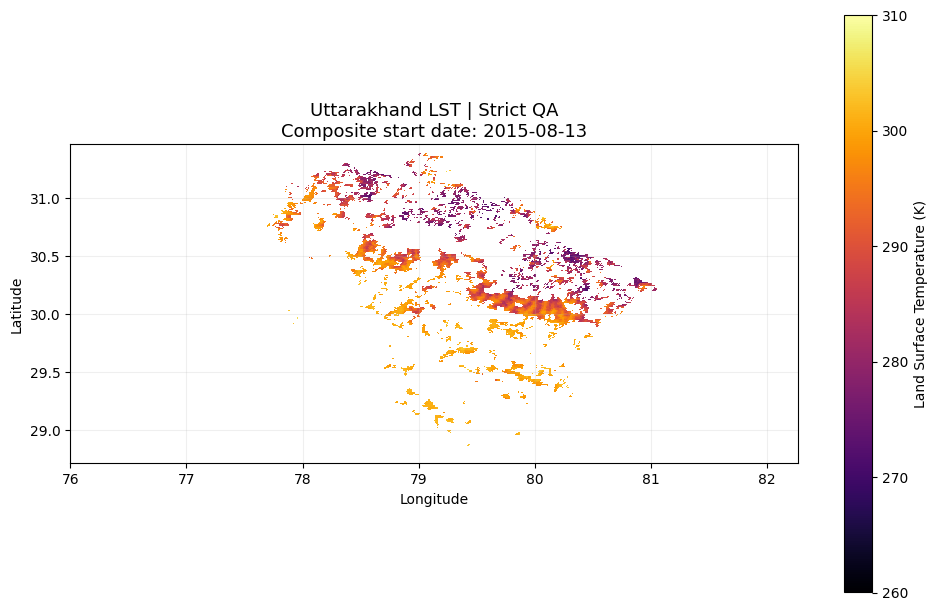

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_maps/lst_strict_2015_08_13.png


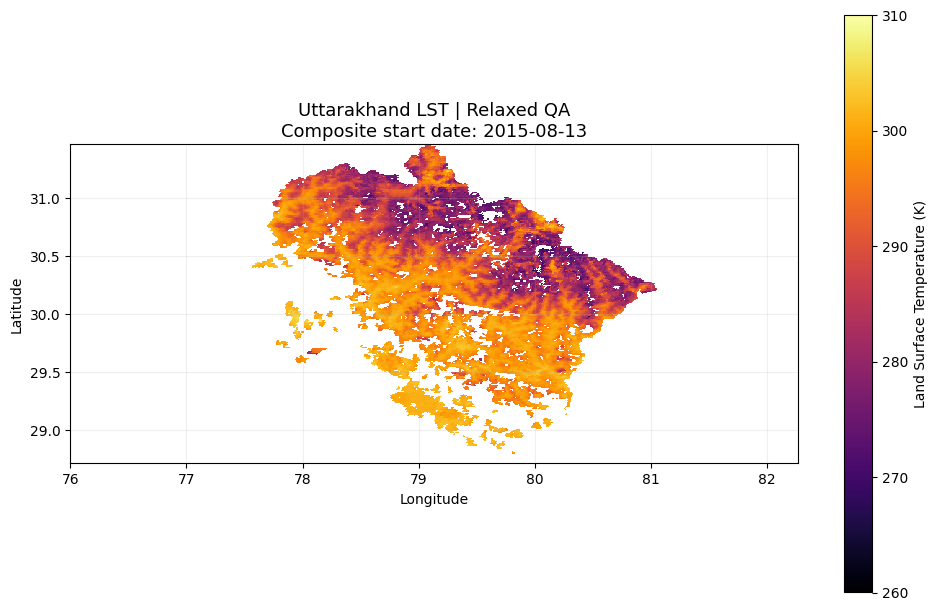

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_maps/lst_relaxed_2015_08_13.png


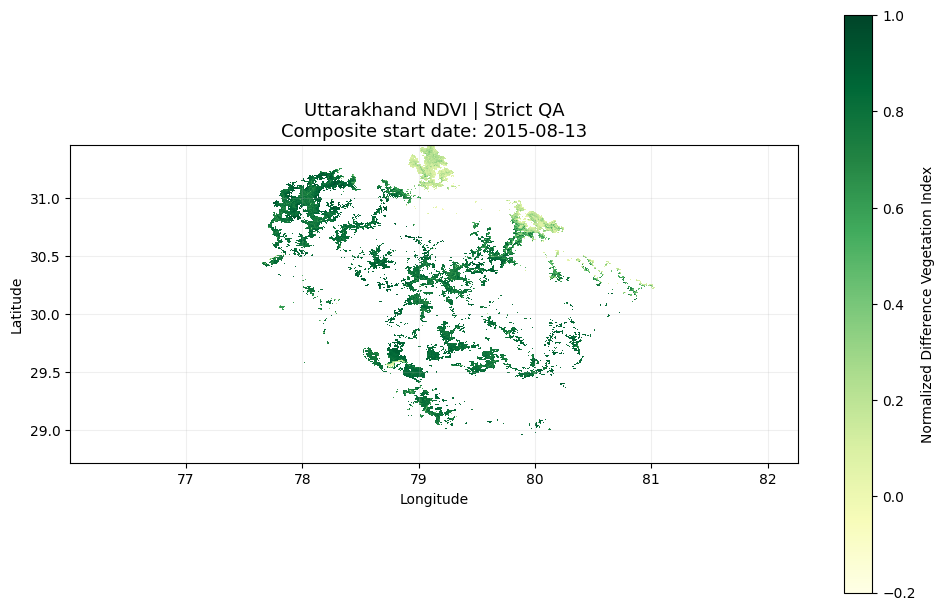

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_maps/ndvi_strict_2015_08_13.png


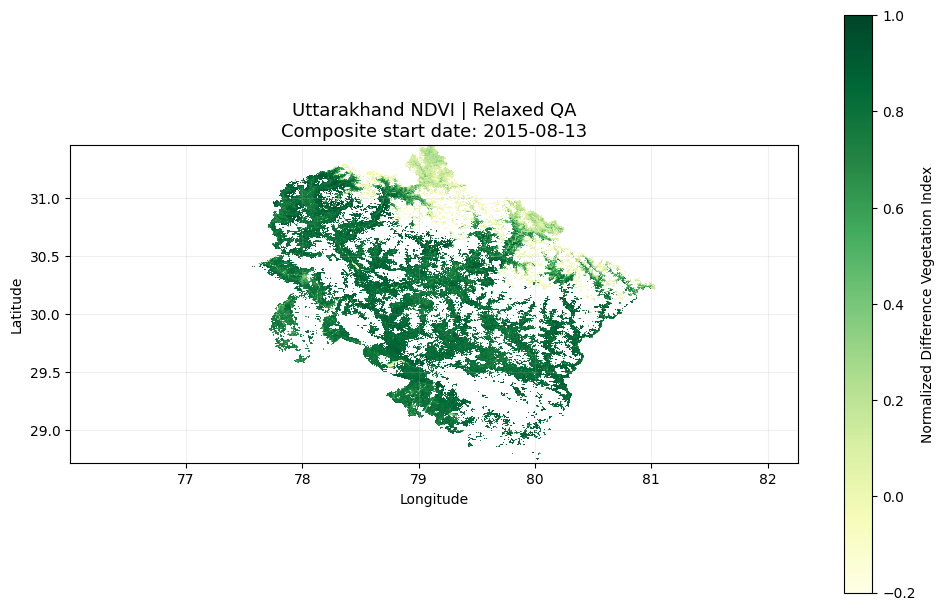

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_maps/ndvi_relaxed_2015_08_13.png

All four maps generated!


In [ ]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.transform import array_bounds
from pathlib import Path
import numpy as np

MAP_DIR = PROJECT_ROOT / "reports/modis_2015_maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

def read_geographic_raster(file_path):

    with rasterio.open(file_path) as src:

        destination_crs = "EPSG:4326"

        transform, width, height = calculate_default_transform(
            src.crs,
            destination_crs,
            src.width,
            src.height,
            *src.bounds
        )

        destination = np.full(
            (height, width),
            -9999.0,
            dtype=np.float32
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=destination_crs,
            dst_nodata=-9999.0,
            resampling=Resampling.nearest
        )

        bounds = array_bounds(
            height, width, transform
        )

        destination = np.ma.masked_equal(
            destination, -9999.0
        )

    return destination, bounds


def create_map(product, mask_type, file_path, date):

    data, bounds = read_geographic_raster(file_path)

    fig, ax = plt.subplots(figsize=(10, 8))

    if product == "LST":
        cmap = "inferno"
        vmin, vmax = 260, 310
        label = "Land Surface Temperature (K)"
    else:
        cmap = "YlGn"
        vmin, vmax = -0.2, 1.0
        label = "Normalized Difference Vegetation Index"

    image = ax.imshow(
        data,
        extent=[
            bounds[0], bounds[2],
            bounds[1], bounds[3]
        ],
        origin="upper",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    colorbar = fig.colorbar(image, ax=ax, shrink=0.75)
    colorbar.set_label(label)

    ax.set_title(
        f"Uttarakhand {product} | {mask_type.title()} QA\n"
        f"Composite start date: {date.date()}",
        fontsize=13
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)

    output_file = (
        MAP_DIR /
        f"{product.lower()}_{mask_type}_2015_08_13.png"
    )

    plt.tight_layout()
    plt.savefig(output_file, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", output_file)


selected_date = pd.Timestamp("2015-08-13")

for product in ["LST", "NDVI"]:

    selected = map_candidates_df[
        (map_candidates_df["product"] == product)
        & (map_candidates_df["date"] == selected_date)
    ]

    for _, row in selected.iterrows():

        create_map(
            product=product,
            mask_type=row["mask"],
            file_path=row["file"],
            date=row["date"]
        )

print("\nAll four maps generated!")

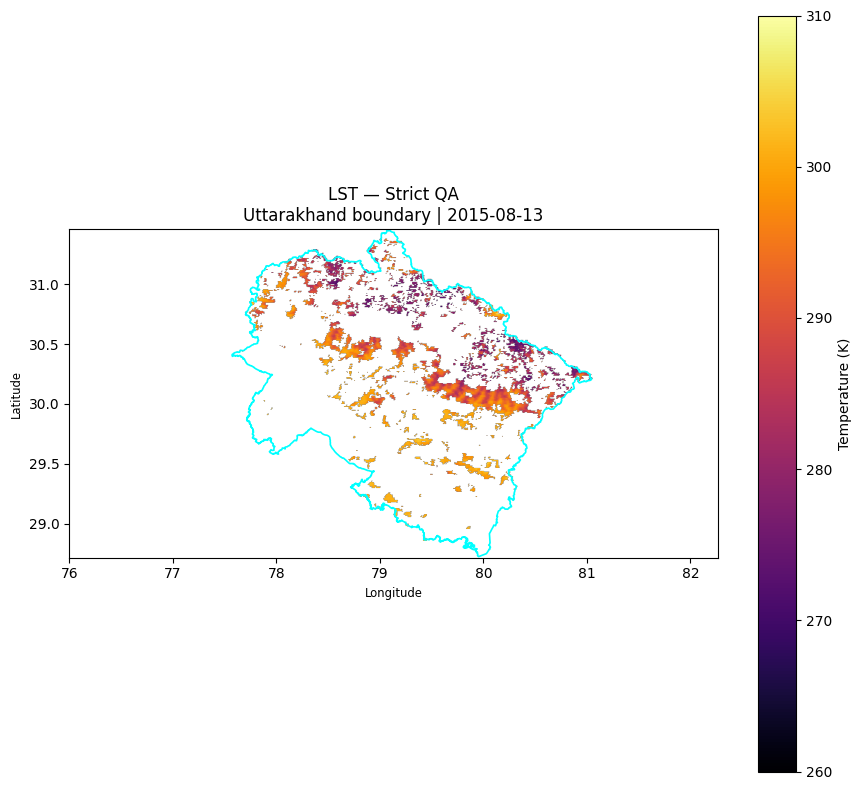

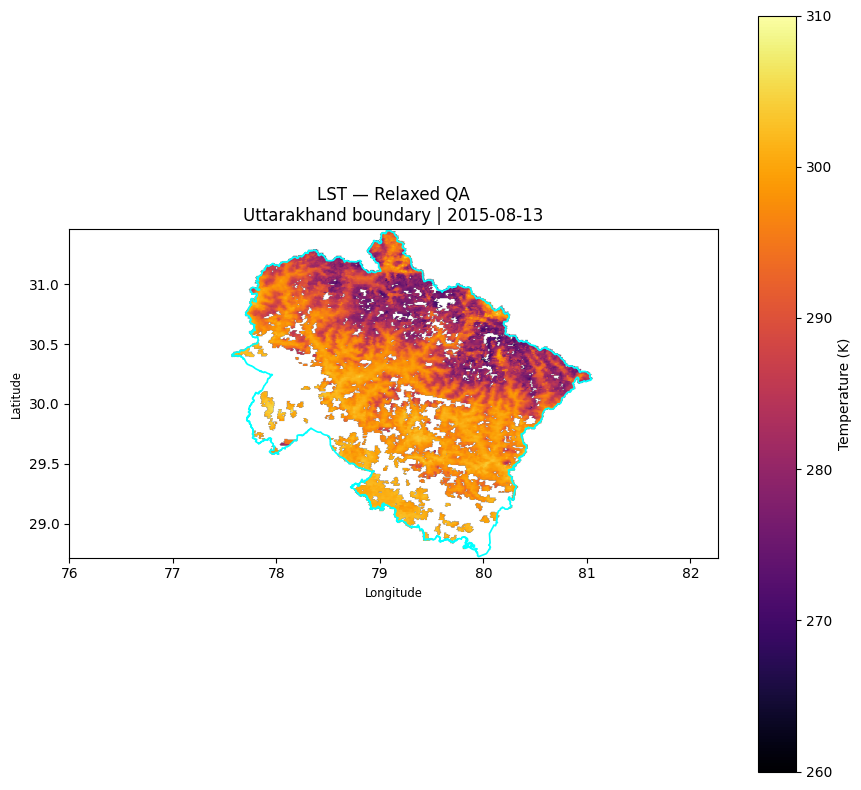

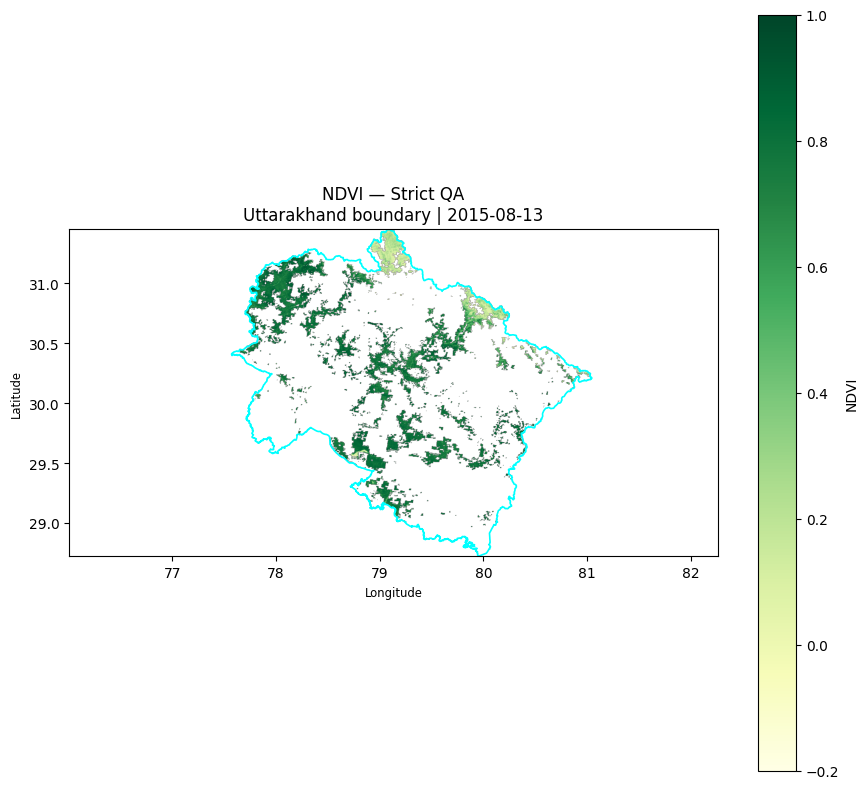

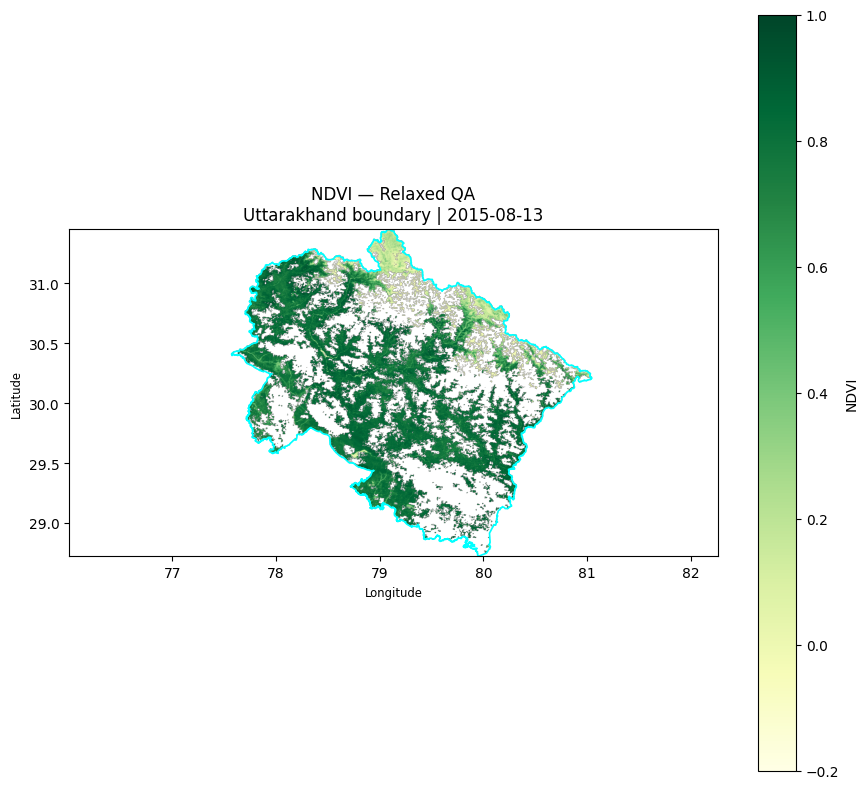

========== STATE BOUNDARY COVERAGE ==========
product    mask  total_boundary_pixels  valid_pixels  coverage_pct
    LST  strict                  62289         10109     16.229190
    LST relaxed                  62289         46641     74.878389
   NDVI  strict                 996399        182917     18.357806
   NDVI relaxed                 996399        536908     53.884839

Coverage report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_boundary_coverage.csv


In [ ]:
import geopandas as gpd
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.features import geometry_mask
from pathlib import Path

boundary_path = (
    PROJECT_ROOT /
    "data/raw/boundaries/uttarakhand_study_area.geojson"
)

boundary = gpd.read_file(boundary_path).to_crs("EPSG:4326")

coverage_results = []

for product in ["LST", "NDVI"]:

    selected = map_candidates_df[
        (map_candidates_df["product"] == product)
        & (map_candidates_df["date"] == selected_date)
    ]

    for _, row in selected.iterrows():

        with rasterio.open(row["file"]) as src:

            data = src.read(1)

            # Transform boundary into native raster CRS
            boundary_native = boundary.to_crs(src.crs)

            inside = geometry_mask(
                boundary_native.geometry,
                transform=src.transform,
                out_shape=data.shape,
                invert=True
            )

            valid = (
                inside
                & (data != src.nodata)
                & np.isfinite(data)
            )

            total_pixels = int(inside.sum())
            valid_pixels = int(valid.sum())

            coverage = (
                100 * valid_pixels / total_pixels
                if total_pixels else 0
            )

            coverage_results.append({
                "product": product,
                "mask": row["mask"],
                "total_boundary_pixels": total_pixels,
                "valid_pixels": valid_pixels,
                "coverage_pct": coverage
            })

        # Plot geographic map with state outline
        raster_data, bounds = read_geographic_raster(row["file"])

        fig, ax = plt.subplots(figsize=(9, 8))

        if product == "LST":
            cmap, vmin, vmax = "inferno", 260, 310
            label = "Temperature (K)"
        else:
            cmap, vmin, vmax = "YlGn", -0.2, 1.0
            label = "NDVI"

        im = ax.imshow(
            raster_data,
            extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
            origin="upper",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        boundary.boundary.plot(
            ax=ax,
            color="cyan",
            linewidth=1.2
        )

        fig.colorbar(im, ax=ax, label=label)

        ax.set_title(
            f"{product} — {row['mask'].title()} QA\n"
            f"Uttarakhand boundary | {selected_date.date()}"
        )

        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

        plt.tight_layout()
        plt.show()
        plt.close()


coverage_df = pd.DataFrame(coverage_results)

print("========== STATE BOUNDARY COVERAGE ==========")
print(coverage_df.to_string(index=False))

coverage_path = (
    PROJECT_ROOT /
    "data/metadata/modis_2015_boundary_coverage.csv"
)

coverage_df.to_csv(coverage_path, index=False)

print("\nCoverage report saved:", coverage_path)

In [ ]:
print("========== UTTARAKHAND COVERAGE SUMMARY ==========")

print(
    coverage_df[
        [
            "product",
            "mask",
            "total_boundary_pixels",
            "valid_pixels",
            "coverage_pct"
        ]
    ].to_string(index=False)
)

print("\n========== STRICT VS RELAXED ==========")

comparison = coverage_df.pivot(
    index="product",
    columns="mask",
    values="coverage_pct"
)

comparison["coverage_improvement_pp"] = (
    comparison["relaxed"] - comparison["strict"]
)

print(comparison.round(2))

print("\nCoverage report:")
print(
    PROJECT_ROOT /
    "data/metadata/modis_2015_boundary_coverage.csv"
)

========== UTTARAKHAND COVERAGE SUMMARY ==========
product    mask  total_boundary_pixels  valid_pixels  coverage_pct
    LST  strict                  62289         10109     16.229190
    LST relaxed                  62289         46641     74.878389
   NDVI  strict                 996399        182917     18.357806
   NDVI relaxed                 996399        536908     53.884839

========== STRICT VS RELAXED ==========
mask     relaxed  strict  coverage_improvement_pp
product                                          
LST        74.88   16.23                    58.65
NDVI       53.88   18.36                    35.53

Coverage report:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_boundary_coverage.csv


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from pathlib import Path

boundary_path = (
    PROJECT_ROOT /
    "data/raw/boundaries/uttarakhand_study_area.geojson"
)

boundary = gpd.read_file(boundary_path)

annual_coverage = []

for _, row in processing_df.iterrows():

    raster_path = Path(row["output_file"])

    with rasterio.open(raster_path) as src:

        data = src.read(1)

        boundary_native = boundary.to_crs(src.crs)

        inside = geometry_mask(
            boundary_native.geometry,
            transform=src.transform,
            out_shape=data.shape,
            invert=True
        )

        valid = (
            inside
            & (data != src.nodata)
            & np.isfinite(data)
        )

        total_pixels = int(inside.sum())
        valid_pixels = int(valid.sum())

        date = extract_modis_date(raster_path.name)

        annual_coverage.append({
            "product": row["product"],
            "mask": row["mask"],
            "date": date,
            "month": date.month,
            "total_boundary_pixels": total_pixels,
            "valid_pixels": valid_pixels,
            "coverage_pct": (
                100 * valid_pixels / total_pixels
                if total_pixels else 0
            )
        })


annual_coverage_df = pd.DataFrame(annual_coverage)

print("========== 2015 ANNUAL COVERAGE AUDIT ==========")

# Weighted coverage across all composite pixel-observations
summary = (
    annual_coverage_df
    .groupby(["product", "mask"])
    .agg(
        composites=("date", "nunique"),
        total_pixel_observations=("total_boundary_pixels", "sum"),
        valid_pixel_observations=("valid_pixels", "sum"),
        mean_composite_coverage=("coverage_pct", "mean"),
        minimum_composite_coverage=("coverage_pct", "min"),
        maximum_composite_coverage=("coverage_pct", "max")
    )
)

summary["weighted_coverage_pct"] = (
    100 * summary["valid_pixel_observations"]
    / summary["total_pixel_observations"]
)

print("\nOVERALL SUMMARY")
print(summary.round(2).to_string())

print("\nMONTHLY MEAN COVERAGE")

monthly = (
    annual_coverage_df
    .groupby(["product", "mask", "month"])
    ["coverage_pct"]
    .mean()
    .round(2)
)

print(monthly.to_string())

# Save detailed audit and summaries
coverage_dir = PROJECT_ROOT / "data/metadata"

annual_coverage_df.to_csv(
    coverage_dir / "modis_2015_annual_composite_coverage.csv",
    index=False
)

summary.to_csv(
    coverage_dir / "modis_2015_annual_coverage_summary.csv"
)

monthly.to_csv(
    coverage_dir / "modis_2015_monthly_coverage_summary.csv"
)

print("\nAll annual coverage reports saved successfully.")

========== 2015 ANNUAL COVERAGE AUDIT ==========

OVERALL SUMMARY
                 composites  total_pixel_observations  valid_pixel_observations  mean_composite_coverage  minimum_composite_coverage  maximum_composite_coverage  weighted_coverage_pct
product mask                                                                                                                                                                           
LST     relaxed          35                   2180115                   2090937                    95.91                       56.78                      100.00                  95.91
        strict           35                   2180115                   1570094                    72.02                        9.93                       97.59                  72.02
NDVI    relaxed          18                  17935182                  14574984                    81.26                       53.09                       92.73                  81.26
        strict

In [ ]:
import pandas as pd

temporal_audit = annual_coverage_df.copy()

# Product-specific composite duration
temporal_audit["duration_days"] = (
    temporal_audit["product"]
    .map({"LST": 8, "NDVI": 16})
)

temporal_audit["composite_start"] = temporal_audit["date"]

# End is exclusive
temporal_audit["composite_end_exclusive"] = (
    temporal_audit["composite_start"]
    + pd.to_timedelta(
        temporal_audit["duration_days"], unit="D"
    )
)

# Requested analysis period: April 1 to January 1
period_start = pd.Timestamp("2015-04-01")
period_end = pd.Timestamp("2016-01-01")

temporal_audit["overlap_start"] = (
    temporal_audit["composite_start"].clip(lower=period_start)
)

temporal_audit["overlap_end"] = (
    temporal_audit["composite_end_exclusive"].clip(upper=period_end)
)

temporal_audit["overlap_days"] = (
    temporal_audit["overlap_end"]
    - temporal_audit["overlap_start"]
).dt.days.clip(lower=0)

temporal_audit["outside_period"] = (
    temporal_audit["overlap_days"]
    < temporal_audit["duration_days"]
)

temporal_audit["overlaps_analysis_period"] = (
    temporal_audit["overlap_days"] > 0
)

print("========== TEMPORAL SUPPORT AUDIT ==========")

for product in ["LST", "NDVI"]:

    subset = temporal_audit[
        (temporal_audit["product"] == product)
        & (temporal_audit["mask"] == "strict")
    ].sort_values("composite_start")

    print(f"\n{product}")
    print("Total composites:", len(subset))
    print(
        "Fully within period:",
        (~subset["outside_period"]).sum()
    )
    print(
        "Partially overlapping boundary:",
        subset["outside_period"].sum()
    )

    print("\nBoundary composites:")
    print(
        subset[
            subset["outside_period"]
        ][[
            "composite_start",
            "composite_end_exclusive",
            "overlap_days",
            "duration_days"
        ]].to_string(index=False)
    )

temporal_path = (
    PROJECT_ROOT
    / "data/metadata/modis_2015_temporal_support_audit.csv"
)

temporal_audit.to_csv(temporal_path, index=False)

print("\nTemporal audit saved:", temporal_path)

========== TEMPORAL SUPPORT AUDIT ==========

LST
Total composites: 35
Fully within period: 33
Partially overlapping boundary: 2

Boundary composites:
composite_start composite_end_exclusive  overlap_days  duration_days
     2015-03-30              2015-04-07             6              8
     2015-12-27              2016-01-04             5              8

NDVI
Total composites: 18
Fully within period: 16
Partially overlapping boundary: 2

Boundary composites:
composite_start composite_end_exclusive  overlap_days  duration_days
     2015-03-22              2015-04-07             6             16
     2015-12-19              2016-01-04            13             16

Temporal audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_temporal_support_audit.csv


In [ ]:
import json
import copy
from pathlib import Path

# Load previously validated 2015 request
template_path = (
    PROJECT_ROOT
    / "data/metadata/appeears_combined_modis_2015_request.json"
)

with open(template_path, "r") as f:
    request_2015 = json.load(f)

# Create independent 2016 request
request_2016 = copy.deepcopy(request_2015)

request_2016["task_name"] = "EARTHPULSE_X_MODIS_COMBINED_2016"

request_2016["params"]["dates"] = [
    {
        "startDate": "01-01-2016",
        "endDate": "12-31-2016"
    }
]

# Save request
request_2016_path = (
    PROJECT_ROOT
    / "data/metadata/appeears_combined_modis_2016_request.json"
)

with open(request_2016_path, "w") as f:
    json.dump(request_2016, f, indent=4)

# Validate request structure
assert request_2016["task_type"] == "area"
assert len(request_2016["params"]["layers"]) == 4
assert len(request_2016["params"]["dates"]) == 1

date_config = request_2016["params"]["dates"][0]

assert date_config["startDate"] == "01-01-2016"
assert date_config["endDate"] == "12-31-2016"

assert (
    request_2016["params"]["output"]["format"]["type"]
    == "geotiff"
)

print("========== 2016 REQUEST VALIDATION ==========")
print("Task:", request_2016["task_name"])
print("Start:", date_config["startDate"])
print("End:", date_config["endDate"])
print("Layers:", len(request_2016["params"]["layers"]))
print("Output format: GeoTIFF")
print("Projection:", request_2016["params"]["output"]["projection"])
print("Request saved:", request_2016_path)
print("Validation passed!")

========== 2016 REQUEST VALIDATION ==========
Task: EARTHPULSE_X_MODIS_COMBINED_2016
Start: 01-01-2016
End: 12-31-2016
Layers: 4
Output format: GeoTIFF
Projection: native
Request saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2016_request.json
Validation passed!


In [ ]:
import json

template_path = (
    PROJECT_ROOT
    / "data/metadata/appeears_combined_modis_2015_request.json"
)

request_path = (
    PROJECT_ROOT
    / "data/metadata/appeears_combined_modis_2016_request.json"
)

with open(template_path) as f:
    baseline = json.load(f)

with open(request_path) as f:
    current = json.load(f)

checks = {
    "Task type unchanged":
        current["task_type"] == baseline["task_type"],

    "Study area geometry unchanged":
        current["params"]["geo"] == baseline["params"]["geo"],

    "Four MODIS layers unchanged":
        current["params"]["layers"] == baseline["params"]["layers"],

    "Native projection unchanged":
        current["params"]["output"]["projection"]
        == baseline["params"]["output"]["projection"],

    "GeoTIFF format unchanged":
        current["params"]["output"]["format"]
        == baseline["params"]["output"]["format"],

    "Date range is 2016":
        current["params"]["dates"] == [
            {
                "startDate": "01-01-2016",
                "endDate": "12-31-2016"
            }
        ]
}

print("========== 2016 REQUEST COMPARISON ==========")

for check, passed in checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

print("\nOverall:", all(checks.values()))

assert all(checks.values()), "Request comparison failed!"

print("\n2016 request matches the validated 2015 baseline.")

========== 2016 REQUEST COMPARISON ==========
Task type unchanged: PASS
Study area geometry unchanged: PASS
Four MODIS layers unchanged: PASS
Native projection unchanged: PASS
GeoTIFF format unchanged: PASS
Date range is 2016: PASS

Overall: True

2016 request matches the validated 2015 baseline.


In [ ]:
import requests
import json
import time

task_name = "EARTHPULSE_X_MODIS_COMBINED_2016"

# Check whether this task was already submitted
response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

existing_tasks = response.json()

if isinstance(existing_tasks, dict):
    existing_tasks = existing_tasks.get("tasks", [])

existing = [
    task for task in existing_tasks
    if task.get("task_name") == task_name
]

if existing:
    print("Task already exists. Skipping duplicate submission.")
    print("Task ID:", existing[0].get("task_id"))
    print("Status:", existing[0].get("status", "Check task status"))

else:
    with open(request_path, "r") as f:
        payload = json.load(f)

    submit_response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=payload,
        timeout=120
    )

    print("HTTP status:", submit_response.status_code)

    submit_response.raise_for_status()

    result = submit_response.json()

    task_id = result.get("task_id")

    print("\n========== 2016 TASK SUBMISSION ==========")
    print("Task:", task_name)
    print("Task ID:", task_id)
    print("Submission response:", result)

    if task_id:
        task_record = {
            "task_name": task_name,
            "task_id": task_id,
            "year": 2016,
            "status": "submitted",
            "request_file": str(request_path)
        }

        task_record_path = (
            PROJECT_ROOT
            / "data/metadata/modis_2016_task_record.json"
        )

        with open(task_record_path, "w") as f:
            json.dump(task_record, f, indent=4)

        print("\nTask record saved:", task_record_path)

HTTP status: 202

========== 2016 TASK SUBMISSION ==========
Task: EARTHPULSE_X_MODIS_COMBINED_2016
Task ID: 65798b30-1b3f-41d7-9838-a8472feff666
Submission response: {'task_id': '65798b30-1b3f-41d7-9838-a8472feff666', 'status': 'pending'}

Task record saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_task_record.json


In [ ]:
import requests

task_id = "65798b30-1b3f-41d7-9838-a8472feff666"

url = API_URL.rstrip("/") + f"/task/{task_id}"
response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()

print("Task:", data.get("task_name"))
print("Status:", data.get("status"))
print("Created:", data.get("created"))
print("Updated:", data.get("updated"))

Task: EARTHPULSE_X_MODIS_COMBINED_2016
Status: processing
Created: 2026-11-04T17:38:30.789282
Updated: 2026-11-04T17:39:17.870503


In [ ]:
import requests

url = API_URL.rstrip("/") + "/task"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()

tasks = response.json()

task_id = "65798b30-1b3f-41d7-9838-a8472feff666"

for task in tasks:
    if task.get("task_id") == task_id:
        print("Task Name:", task.get("task_name"))
        print("Status:", task.get("status"))
        print("Created:", task.get("created"))
        print("Updated:", task.get("updated"))
        print("Task ID:", task.get("task_id"))
        break
else:
    print("Task not found in task list.")

Task Name: EARTHPULSE_X_MODIS_COMBINED_2016
Status: done
Created: 2026-11-04T17:38:30.789282
Updated: 2026-11-04T17:55:18.432019
Task ID: 65798b30-1b3f-41d7-9838-a8472feff666


In [ ]:
import requests
import json
from pathlib import Path

task_id = "65798b30-1b3f-41d7-9838-a8472feff666"

bundle_url = API_URL.rstrip("/") + f"/bundle/{task_id}"

response = requests.get(
    bundle_url,
    headers=APPEEARS_HEADERS,
    timeout=120
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

bundle = response.json()

# Save bundle manifest
metadata_dir = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data/metadata"
)
metadata_dir.mkdir(parents=True, exist_ok=True)

manifest_path = metadata_dir / "modis_2016_bundle_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(bundle, f, indent=2)

files = bundle.get("files", [])

print("\n========== 2016 BUNDLE SUMMARY ==========")
print("Task ID:", bundle.get("task_id"))
print("Bundle files:", len(files))
print("Manifest saved:", manifest_path)

if files:
    total_bytes = sum(item.get("file_size", 0) for item in files)
    print("Total bundle size:", round(total_bytes / (1024**2), 2), "MB")
    print("\nFile types:")
    from collections import Counter
    print(Counter(item.get("file_type") for item in files))
else:
    print("No files listed in bundle. We will inspect the response.")

HTTP Status: 200

========== 2016 BUNDLE SUMMARY ==========
Task ID: 65798b30-1b3f-41d7-9838-a8472feff666
Bundle files: 153
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_bundle_manifest.json
Total bundle size: 85.07 MB

File types:
Counter({'tif': 142, 'csv': 6, 'txt': 2, 'xml': 2, 'json': 1})


In [ ]:
import requests
import hashlib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Paths
BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
MANIFEST_PATH = BASE_DIR / "data/metadata/modis_2016_bundle_manifest.json"
RAW_DIR = BASE_DIR / "data/raw/modis_2016"
REPORT_PATH = BASE_DIR / "data/metadata/modis_2016_download_report.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)

# Load manifest
with open(MANIFEST_PATH, "r") as f:
    bundle = json.load(f)

files = bundle["files"]

def calculate_sha256(file_path):
    sha = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)
    return sha.hexdigest()

session = requests.Session()
session.headers.update(APPEEARS_HEADERS)

results = []

for item in tqdm(files, desc="Downloading 2016 files"):
    filename = item["file_name"]
    expected_hash = item["sha256"]
    file_path = RAW_DIR / filename
    status = "FAILED"
    actual_hash = None
    error = None

    try:
        # Reuse an existing file only if its checksum matches
        if file_path.exists():
            actual_hash = calculate_sha256(file_path)
            if actual_hash == expected_hash:
                status = "ALREADY_VERIFIED"

        if status == "FAILED":
            url = item["s3_url"]

            with session.get(url, stream=True, timeout=(30, 300)) as r:
                r.raise_for_status()
                temp_path = file_path.with_suffix(file_path.suffix + ".part")

                with open(temp_path, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)

            actual_hash = calculate_sha256(temp_path)

            if actual_hash == expected_hash:
                temp_path.replace(file_path)
                status = "VERIFIED"
            else:
                temp_path.unlink(missing_ok=True)
                status = "HASH_MISMATCH"

    except Exception as e:
        error = str(e)

    results.append({
        "file_name": filename,
        "file_type": item.get("file_type"),
        "expected_sha256": expected_hash,
        "actual_sha256": actual_hash,
        "file_size": item.get("file_size"),
        "status": status,
        "error": error
    })

# Save report
report = pd.DataFrame(results)
report.to_csv(REPORT_PATH, index=False)

print("\n========== 2016 DOWNLOAD AUDIT ==========")
print(report["status"].value_counts(dropna=False))
print("\nTotal files:", len(report))
print("Verified:", report["status"].isin(
    ["VERIFIED", "ALREADY_VERIFIED"]
).sum())
print("Failed:", (report["status"] == "FAILED").sum())
print("Hash mismatches:", (report["status"] == "HASH_MISMATCH").sum())
print("\nDownload directory:", RAW_DIR)
print("Report:", REPORT_PATH)


========== 2016 DOWNLOAD AUDIT ==========
status
FAILED    153
Name: count, dtype: int64

Total files: 153
Verified: 0
Failed: 153
Hash mismatches: 0

Download directory: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2016
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_download_report.csv


In [ ]:
import pandas as pd
import json
from pathlib import Path
from collections import Counter
from urllib.parse import urlparse

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")

report_path = BASE_DIR / "data/metadata/modis_2016_download_report.csv"
manifest_path = BASE_DIR / "data/metadata/modis_2016_bundle_manifest.json"

report = pd.read_csv(report_path)

print("========== FAILURE DIAGNOSTICS ==========")

print("\nError distribution:")
print(report["error"].fillna("No error recorded").value_counts().head(10))

print("\nFirst 5 failed records:")
print(report.loc[
    report["status"] == "FAILED",
    ["file_name", "error"]
].head().to_string(index=False))

with open(manifest_path, "r") as f:
    bundle = json.load(f)

print("\nManifest file keys:")
print(list(bundle["files"][0].keys()))

print("\nFirst file URL domain:")
first_url = bundle["files"][0].get("s3_url", "")
print(urlparse(first_url).netloc if first_url else "No URL found")

print("\nExisting downloaded files:",
      len(list((BASE_DIR / "data/raw/modis_2016").glob("*"))))

========== FAILURE DIAGNOSTICS ==========

Error distribution:
error
No connection adapters were found for 's3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001.tif'    1
No connection adapters were found for 's3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2016001000000_aid0001.tif'    1
No connection adapters were found for 's3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2016009000000_aid0001.tif'    1
No connection adapters were found for 's3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2016017000000_aid0001.tif'    1
No connection adapters were found for 's3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2016025000000_aid0001.tif'  

In [ ]:
import requests
import json

task_id = "65798b30-1b3f-41d7-9838-a8472feff666"

# Inspect AppEEARS bundle metadata
url = API_URL.rstrip("/") + f"/bundle/{task_id}"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=120
)

response.raise_for_status()
bundle = response.json()

print("Bundle type:", bundle.get("bundle_type"))
print("Bundle keys:", list(bundle.keys()))

print("\nFirst file metadata:")
print(json.dumps(bundle["files"][0], indent=2))

print("\nAppEEARS API URL:", API_URL)

Bundle type: area
Bundle keys: ['files', 'created', 'task_id', 'updated', 'bundle_type']

First file metadata:
{
  "sha256": "ac76131a288013c8ed0b9db21c6384671496db6186f368f34dd8a52d6a4fd6bd",
  "file_id": "2428498a-fbe3-44c2-a0fe-1633c8ee6280",
  "file_name": "MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001.tif",
  "file_size": 114929,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/65798b30-1b3f-41d7-9838-a8472feff666/MOD11A2.061_2015359_to_2016366/MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001.tif"
}

AppEEARS API URL: https://appeears.earthdatacloud.nasa.gov/api/


In [ ]:
import requests
import hashlib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW_DIR = BASE_DIR / "data/raw/modis_2016"
REPORT_PATH = BASE_DIR / "data/metadata/modis_2016_download_report.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)

task_id = "65798b30-1b3f-41d7-9838-a8472feff666"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

results = []

session = requests.Session()
session.headers.update(APPEEARS_HEADERS)

for item in tqdm(bundle["files"], desc="Downloading 2016"):
    relative_path = Path(item["file_name"])
    destination = RAW_DIR / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    expected_hash = item["sha256"]
    status = "FAILED"
    error = None

    try:
        if destination.exists() and sha256_file(destination) == expected_hash:
            status = "ALREADY_VERIFIED"
        else:
            download_url = (
                API_URL.rstrip("/")
                + f"/bundle/{task_id}/{item['file_id']}"
            )

            temp_path = destination.with_suffix(
                destination.suffix + ".part"
            )

            with session.get(
                download_url,
                stream=True,
                timeout=(30, 300)
            ) as response:
                response.raise_for_status()

                with open(temp_path, "wb") as f:
                    for chunk in response.iter_content(1024 * 1024):
                        if chunk:
                            f.write(chunk)

            actual_hash = sha256_file(temp_path)

            if actual_hash == expected_hash:
                temp_path.replace(destination)
                status = "VERIFIED"
            else:
                temp_path.unlink(missing_ok=True)
                status = "HASH_MISMATCH"

    except Exception as e:
        error = str(e)

    results.append({
        "file_name": item["file_name"],
        "file_type": item["file_type"],
        "file_size": item["file_size"],
        "expected_sha256": expected_hash,
        "status": status,
        "error": error
    })

report = pd.DataFrame(results)
report.to_csv(REPORT_PATH, index=False)

print("\n========== 2016 DOWNLOAD RESULTS ==========")
print(report["status"].value_counts())
print("Total:", len(report))
print("Verified:", report["status"].isin(
    ["VERIFIED", "ALREADY_VERIFIED"]
).sum())
print("Failed:", (report["status"] == "FAILED").sum())
print("Hash mismatches:", (report["status"] == "HASH_MISMATCH").sum())
print("Report:", REPORT_PATH)


========== 2016 DOWNLOAD RESULTS ==========
status
VERIFIED    153
Name: count, dtype: int64
Total: 153
Verified: 153
Failed: 0
Hash mismatches: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_download_report.csv


In [ ]:
import re
import pandas as pd
from pathlib import Path
from collections import Counter

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW_DIR = BASE_DIR / "data/raw/modis_2016"
METADATA_DIR = BASE_DIR / "data/metadata"

records = []

for path in RAW_DIR.rglob("*"):
    if not path.is_file():
        continue

    record = {
        "file_name": path.name,
        "relative_path": str(path.relative_to(RAW_DIR)),
        "file_type": path.suffix.lower(),
        "file_size_bytes": path.stat().st_size,
        "product": None,
        "layer": None,
        "doy": None,
        "date": None
    }

    if path.suffix.lower() == ".tif":
        match = re.match(
            r"^(MOD\d+[A-Z]\d+\.\d+)_(.+?)_doy(\d{7})",
            path.name
        )

        if match:
            product, layer, doy_code = match.groups()
            year = int(doy_code[:4])
            doy = int(doy_code[4:])

            record["product"] = product
            record["layer"] = layer
            record["doy"] = doy

            record["date"] = (
                pd.Timestamp(year=year, month=1, day=1)
                + pd.Timedelta(days=doy - 1)
            ).date()

    records.append(record)

inventory = pd.DataFrame(records)

inventory_path = METADATA_DIR / "modis_2016_raster_inventory.csv"
inventory.to_csv(inventory_path, index=False)

raster_inventory = inventory[
    inventory["file_type"] == ".tif"
].copy()

print("========== 2016 FILE INVENTORY ==========")
print("Total files:", len(inventory))
print("Total GeoTIFFs:", len(raster_inventory))

print("\nFile type counts:")
print(inventory["file_type"].value_counts())

print("\nProduct counts:")
print(raster_inventory["product"].value_counts(dropna=False))

print("\nLayer counts:")
print(raster_inventory["layer"].value_counts(dropna=False))

print("\nUnique observation dates by product:")
print(
    raster_inventory.groupby("product")["date"]
    .nunique()
)

print("\nUnique dates by layer:")
print(
    raster_inventory.groupby("layer")["date"]
    .nunique()
)

print("\nTiles per observation date:")
print(
    raster_inventory.groupby(["product", "date"])
    .size()
    .value_counts()
    .sort_index()
)

print("\nUnparsed raster files:")
print(
    raster_inventory[
        raster_inventory["product"].isna()
    ]["file_name"].head(10).to_list()
)

print("\nInventory saved:", inventory_path)

========== 2016 FILE INVENTORY ==========
Total files: 153
Total GeoTIFFs: 142

File type counts:
file_type
.tif     142
.csv       6
.xml       2
.txt       1
.json      1
.md        1
Name: count, dtype: int64

Product counts:
product
MOD11A2.061    94
MOD13Q1.061    48
Name: count, dtype: int64

Layer counts:
layer
LST_Day_1km                 47
QC_Day                      47
_250m_16_days_NDVI          24
_250m_16_days_VI_Quality    24
Name: count, dtype: int64

Unique observation dates by product:
product
MOD11A2.061    47
MOD13Q1.061    24
Name: date, dtype: int64

Unique dates by layer:
layer
LST_Day_1km                 47
QC_Day                      47
_250m_16_days_NDVI          24
_250m_16_days_VI_Quality    24
Name: date, dtype: int64

Tiles per observation date:
2    71
Name: count, dtype: int64

Unparsed raster files:
[]

Inventory saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_raster_inventory.csv


In [ ]:
# Separate science and QA layers
lst_science = set(
    raster_inventory.loc[
        raster_inventory["layer"] == "LST_Day_1km", "date"
    ]
)

lst_qa = set(
    raster_inventory.loc[
        raster_inventory["layer"] == "QC_Day", "date"
    ]
)

ndvi_science = set(
    raster_inventory.loc[
        raster_inventory["layer"] == "_250m_16_days_NDVI", "date"
    ]
)

ndvi_qa = set(
    raster_inventory.loc[
        raster_inventory["layer"] == "_250m_16_days_VI_Quality", "date"
    ]
)

print("========== 2016 SCIENCE-QA DATE AUDIT ==========")

print("\nLST science dates:", len(lst_science))
print("LST QA dates:", len(lst_qa))
print("LST matching dates:", len(lst_science & lst_qa))
print("LST missing QA:", sorted(lst_science - lst_qa))
print("LST extra QA:", sorted(lst_qa - lst_science))

print("\nNDVI science dates:", len(ndvi_science))
print("NDVI QA dates:", len(ndvi_qa))
print("NDVI matching dates:", len(ndvi_science & ndvi_qa))
print("NDVI missing QA:", sorted(ndvi_science - ndvi_qa))
print("NDVI extra QA:", sorted(ndvi_qa - ndvi_science))

print("\n========== DATE RANGE ==========")
print("LST:", min(lst_science), "to", max(lst_science))
print("NDVI:", min(ndvi_science), "to", max(ndvi_science))

print("\n========== RESULT ==========")
print("LST QA pairing:", "PASS" if lst_science == lst_qa else "CHECK")
print("NDVI QA pairing:", "PASS" if ndvi_science == ndvi_qa else "CHECK")

========== 2016 SCIENCE-QA DATE AUDIT ==========

LST science dates: 47
LST QA dates: 47
LST matching dates: 47
LST missing QA: []
LST extra QA: []

NDVI science dates: 24
NDVI QA dates: 24
NDVI matching dates: 24
NDVI missing QA: []
NDVI extra QA: []

========== DATE RANGE ==========
LST: 2015-12-27 to 2016-12-26
NDVI: 2015-12-19 to 2016-12-18

========== RESULT ==========
LST QA pairing: PASS
NDVI QA pairing: PASS


In [ ]:
import rasterio
import pandas as pd
from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2016")
METADATA_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")

pair_definitions = {
    "LST": ("LST_Day_1km", "QC_Day"),
    "NDVI": ("_250m_16_days_NDVI", "_250m_16_days_VI_Quality")
}

audit = []

for product, (science_layer, qa_layer) in pair_definitions.items():

    science_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in raster_inventory[
            raster_inventory["layer"] == science_layer
        ].iterrows()
    }

    qa_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in raster_inventory[
            raster_inventory["layer"] == qa_layer
        ].iterrows()
    }

    for date in sorted(set(science_files) & set(qa_files)):
        science_path = science_files[date]
        qa_path = qa_files[date]

        try:
            with rasterio.open(science_path) as s, rasterio.open(qa_path) as q:

                same_grid = (
                    s.width == q.width
                    and s.height == q.height
                    and s.crs == q.crs
                    and s.transform == q.transform
                    and s.bounds == q.bounds
                )

                audit.append({
                    "product": product,
                    "date": str(date),
                    "science_file": science_path.name,
                    "qa_file": qa_path.name,
                    "science_width": s.width,
                    "science_height": s.height,
                    "qa_width": q.width,
                    "qa_height": q.height,
                    "science_crs": str(s.crs),
                    "qa_crs": str(q.crs),
                    "science_nodata": s.nodata,
                    "qa_nodata": q.nodata,
                    "same_grid": same_grid,
                    "readable": True,
                    "error": None
                })

        except Exception as e:
            audit.append({
                "product": product,
                "date": str(date),
                "same_grid": False,
                "readable": False,
                "error": str(e)
            })

alignment_df = pd.DataFrame(audit)

output_path = METADATA_DIR / "modis_2016_spatial_alignment.csv"
alignment_df.to_csv(output_path, index=False)

print("========== 2016 SPATIAL ALIGNMENT AUDIT ==========")
print("Total pairs:", len(alignment_df))
print("Readable pairs:", alignment_df["readable"].sum())
print("Matching grids:", alignment_df["same_grid"].sum())
print("Mismatched grids:", (~alignment_df["same_grid"]).sum())

print("\nProduct-wise results:")
print(
    alignment_df.groupby("product").agg(
        total_pairs=("date", "count"),
        readable=("readable", "sum"),
        matching_grids=("same_grid", "sum")
    )
)

print("\nRaster dimensions:")
print(
    alignment_df.groupby(
        ["product", "science_width", "science_height"]
    ).size()
)

print("\nCRS values:")
print(alignment_df["science_crs"].value_counts(dropna=False))

print("\nAudit saved:", output_path)

========== 2016 SPATIAL ALIGNMENT AUDIT ==========
Total pairs: 71
Readable pairs: 71
Matching grids: 71
Mismatched grids: 0

Product-wise results:
         total_pairs  readable  matching_grids
product                                       
LST               47        47              47
NDVI              24        24              24

Raster dimensions:
product  science_width  science_height
LST      423            329               47
NDVI     1688           1313              24
dtype: int64

CRS values:
science_crs
PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]    71
Name: count, dtype: int64

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_201

In [ ]:
import rasterio
import numpy as np
import pandas as pd
from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2016")
METADATA_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")

qa_layers = [
    "QC_Day",
    "_250m_16_days_VI_Quality"
]

qa_results = []

for layer in qa_layers:
    layer_files = raster_inventory[
        raster_inventory["layer"] == layer
    ]

    all_values = []

    for _, row in layer_files.iterrows():
        path = RAW_DIR / row["relative_path"]

        with rasterio.open(path) as src:
            arr = src.read(1)
            values, counts = np.unique(arr, return_counts=True)

            for value, count in zip(values, counts):
                qa_results.append({
                    "layer": layer,
                    "date": str(row["date"]),
                    "qa_value": int(value),
                    "pixel_count": int(count)
                })

qa_df = pd.DataFrame(qa_results)

qa_summary = (
    qa_df.groupby(["layer", "qa_value"])["pixel_count"]
    .sum()
    .reset_index()
    .sort_values(["layer", "pixel_count"], ascending=[True, False])
)

output_path = METADATA_DIR / "modis_2016_qa_value_audit.csv"
qa_summary.to_csv(output_path, index=False)

for layer in qa_layers:
    print(f"\n========== {layer} ==========")
    print(
        qa_summary[qa_summary["layer"] == layer]
        .head(20)
        .to_string(index=False)
    )

print("\nQA audit saved:", output_path)


========== QC_Day ==========
 layer  qa_value  pixel_count
QC_Day         0      5527742
QC_Day        65       693728
QC_Day         2       252824
QC_Day        17        32309
QC_Day        81        27004
QC_Day        97         3327
QC_Day        33         3293
QC_Day       145          491
QC_Day       129          131

========== _250m_16_days_VI_Quality ==========
                   layer  qa_value  pixel_count
_250m_16_days_VI_Quality     65535     29193989
_250m_16_days_VI_Quality      2116     10394579
_250m_16_days_VI_Quality      2185      3478325
_250m_16_days_VI_Quality      2062      1472137
_250m_16_days_VI_Quality      2066       985896
_250m_16_days_VI_Quality      2445       743968
_250m_16_days_VI_Quality      2120       681626
_250m_16_days_VI_Quality      2376       500496
_250m_16_days_VI_Quality      2189       474911
_250m_16_days_VI_Quality     18449       388576
_250m_16_days_VI_Quality     18453       348711
_250m_16_days_VI_Quality      3098       31401

In [ ]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path
from collections import Counter

RAW_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2016")
METADATA_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")

# Bit definitions: (field name, bit shift, bit mask)
LST_FIELDS = [
    ("mandatory_qa", 0, 0b11),
    ("data_quality", 2, 0b11),
    ("emissivity_error", 4, 0b11),
    ("lst_error", 6, 0b11)
]

NDVI_FIELDS = [
    ("overall_vi_quality", 0, 0b11),
    ("vi_usefulness", 2, 0b1111),
    ("aerosol_quantity", 6, 0b11),
    ("adjacent_cloud", 8, 0b1),
    ("brdf_correction", 9, 0b1),
    ("mixed_clouds", 10, 0b1),
    ("land_water", 11, 0b111),
    ("snow_ice", 14, 0b1),
    ("shadow", 15, 0b1)
]

decoded_counts = Counter()
fill_counts = Counter()

for layer, fields in [
    ("QC_Day", LST_FIELDS),
    ("_250m_16_days_VI_Quality", NDVI_FIELDS)
]:
    layer_rows = raster_inventory[
        raster_inventory["layer"] == layer
    ]

    for _, row in layer_rows.iterrows():
        path = RAW_DIR / row["relative_path"]

        with rasterio.open(path) as src:
            arr = src.read(1)

        if layer == "_250m_16_days_VI_Quality":
            fill_mask = arr == 65535
            fill_counts[layer] += int(fill_mask.sum())
            valid = arr[~fill_mask].astype(np.uint16)
        else:
            # QC_Day value 0 is valid; do not treat it as NoData.
            valid = arr.astype(np.uint8)

        for field_name, shift, mask in fields:
            decoded = (valid >> shift) & mask
            values, counts = np.unique(decoded, return_counts=True)

            for value, count in zip(values, counts):
                decoded_counts[(layer, field_name, int(value))] += int(count)

rows = []

for (layer, field, value), count in decoded_counts.items():
    rows.append({
        "layer": layer,
        "field": field,
        "decoded_value": value,
        "pixel_count": count
    })

decoded_df = pd.DataFrame(rows).sort_values(
    ["layer", "field", "decoded_value"]
)

output_path = METADATA_DIR / "modis_2016_decoded_qa_audit.csv"
decoded_df.to_csv(output_path, index=False)

print("========== 2016 DECODED QA AUDIT ==========")

print("\nNDVI fill pixels:", fill_counts["_250m_16_days_VI_Quality"])

for layer in ["QC_Day", "_250m_16_days_VI_Quality"]:
    print(f"\n--- {layer} ---")

    for field in decoded_df.loc[
        decoded_df["layer"] == layer, "field"
    ].unique():
        print(f"\n{field}:")
        print(
            decoded_df[
                (decoded_df["layer"] == layer) &
                (decoded_df["field"] == field)
            ][["decoded_value", "pixel_count"]].to_string(index=False)
        )

print("\nSaved:", output_path)

========== 2016 DECODED QA AUDIT ==========

NDVI fill pixels: 29193989

--- QC_Day ---

data_quality:
 decoded_value  pixel_count
             0      6540849

emissivity_error:
 decoded_value  pixel_count
             0      6474425
             1        59804
             2         6620

lst_error:
 decoded_value  pixel_count
             0      5816168
             1       724059
             2          622

mandatory_qa:
 decoded_value  pixel_count
             0      5527742
             1       760283
             2       252824

--- _250m_16_days_VI_Quality ---

adjacent_cloud:
 decoded_value  pixel_count
             0     20450071
             1      3548196

aerosol_quantity:
 decoded_value  pixel_count
             0      5354851
             1     12249154
             2      5386309
             3      1007953

brdf_correction:
 decoded_value  pixel_count
             0     23998267

land_water:
 decoded_value  pixel_count
             1     23617354
             2       3

In [ ]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2016")
METADATA_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")

pair_definitions = {
    "LST": {
        "science_layer": "LST_Day_1km",
        "qa_layer": "QC_Day"
    },
    "NDVI": {
        "science_layer": "_250m_16_days_NDVI",
        "qa_layer": "_250m_16_days_VI_Quality"
    }
}

results = []

for product, config in pair_definitions.items():

    science_rows = raster_inventory[
        raster_inventory["layer"] == config["science_layer"]
    ]

    qa_rows = raster_inventory[
        raster_inventory["layer"] == config["qa_layer"]
    ]

    science_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in science_rows.iterrows()
    }

    qa_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in qa_rows.iterrows()
    }

    for date in sorted(set(science_files) & set(qa_files)):

        with rasterio.open(science_files[date]) as s:
            science = s.read(1).astype(np.int32)

        with rasterio.open(qa_files[date]) as q:
            qa = q.read(1).astype(np.uint32)

        if product == "LST":

            valid = (science >= 7500) & (science <= 65535)

            mandatory = qa & 0b11
            data_quality = (qa >> 2) & 0b11
            lst_error = (qa >> 6) & 0b11

            strict = (
                valid
                & (mandatory == 0)
                & (data_quality == 0)
                & (lst_error == 0)
            )

            relaxed = (
                valid
                & (mandatory <= 1)
                & (data_quality == 0)
                & (lst_error <= 1)
            )

        else:

            valid = (
                (science >= -2000)
                & (science <= 10000)
                & (qa != 65535)
            )

            overall_quality = qa & 0b11
            usefulness = (qa >> 2) & 0b1111

            strict = (
                valid
                & (overall_quality == 0)
                & (usefulness <= 2)
            )

            relaxed = (
                valid
                & (overall_quality <= 1)
                & (usefulness <= 4)
            )

        total_valid = int(valid.sum())
        strict_count = int(strict.sum())
        relaxed_count = int(relaxed.sum())

        results.append({
            "product": product,
            "date": str(date),
            "total_valid_pixels": total_valid,
            "strict_pixels": strict_count,
            "relaxed_pixels": relaxed_count,
            "strict_retention_pct": (
                strict_count / total_valid * 100 if total_valid else 0
            ),
            "relaxed_retention_pct": (
                relaxed_count / total_valid * 100 if total_valid else 0
            )
        })

retention_df = pd.DataFrame(results)

# Save per-composite audit
output_path = METADATA_DIR / "modis_2016_mask_retention_audit.csv"
retention_df.to_csv(output_path, index=False)

# Calculate pixel-weighted product summaries
summary = (
    retention_df.groupby("product")
    .agg(
        total_valid_pixels=("total_valid_pixels", "sum"),
        strict_pixels=("strict_pixels", "sum"),
        relaxed_pixels=("relaxed_pixels", "sum"),
        composites=("date", "count")
    )
    .reset_index()
)

summary["strict_retention_pct"] = (
    summary["strict_pixels"] / summary["total_valid_pixels"] * 100
)

summary["relaxed_retention_pct"] = (
    summary["relaxed_pixels"] / summary["total_valid_pixels"] * 100
)

print("========== 2016 QA MASK RETENTION ==========")
print(summary.to_string(index=False))

print("\n========== COMPOSITE-LEVEL RANGE ==========")

print(
    retention_df.groupby("product")[
        ["strict_retention_pct", "relaxed_retention_pct"]
    ].agg(["min", "mean", "max"]).round(2)
)

print("\nSaved:", output_path)

========== 2016 QA MASK RETENTION ==========
product  total_valid_pixels  strict_pixels  relaxed_pixels  composites  strict_retention_pct  relaxed_retention_pct
    LST             2730407        1970124         2729785          47             72.154957              99.977220
   NDVI            23958388       11863502        18363773          24             49.517113              76.648617

========== COMPOSITE-LEVEL RANGE ==========
        strict_retention_pct               relaxed_retention_pct              
                         min   mean    max                   min   mean    max
product                                                                       
LST                    10.39  68.93  98.04                 99.87  99.98  100.0
NDVI                    6.84  49.54  84.42                 27.76  76.67   93.8

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_mask_retention_audit.csv


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path
from tqdm.auto import tqdm

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW_DIR = BASE_DIR / "data/raw/modis_2016"
OUTPUT_DIR = BASE_DIR / "data/processed/modis_2016"
METADATA_DIR = BASE_DIR / "data/metadata"

NODATA_OUT = -9999.0

pair_definitions = {
    "LST": {
        "science_layer": "LST_Day_1km",
        "qa_layer": "QC_Day",
        "scale": 0.02,
        "unit": "Kelvin"
    },
    "NDVI": {
        "science_layer": "_250m_16_days_NDVI",
        "qa_layer": "_250m_16_days_VI_Quality",
        "scale": 0.0001,
        "unit": "NDVI"
    }
}

processing_results = []

for product, config in pair_definitions.items():

    science_rows = raster_inventory[
        raster_inventory["layer"] == config["science_layer"]
    ]

    qa_rows = raster_inventory[
        raster_inventory["layer"] == config["qa_layer"]
    ]

    science_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in science_rows.iterrows()
    }

    qa_files = {
        row["date"]: RAW_DIR / row["relative_path"]
        for _, row in qa_rows.iterrows()
    }

    for date in tqdm(
        sorted(set(science_files) & set(qa_files)),
        desc=f"Processing {product}"
    ):

        science_path = science_files[date]
        qa_path = qa_files[date]

        with rasterio.open(science_path) as src:
            raw = src.read(1).astype(np.int32)
            profile = src.profile.copy()

        with rasterio.open(qa_path) as src:
            qa = src.read(1).astype(np.uint32)

        if product == "LST":

            valid = (raw >= 7500) & (raw <= 65535)

            mandatory = qa & 0b11
            data_quality = (qa >> 2) & 0b11
            lst_error = (qa >> 6) & 0b11

            strict_mask = (
                valid
                & (mandatory == 0)
                & (data_quality == 0)
                & (lst_error == 0)
            )

            relaxed_mask = (
                valid
                & (mandatory <= 1)
                & (data_quality == 0)
                & (lst_error <= 1)
            )

        else:

            valid = (
                (raw >= -2000)
                & (raw <= 10000)
                & (qa != 65535)
            )

            overall_quality = qa & 0b11
            usefulness = (qa >> 2) & 0b1111

            strict_mask = (
                valid
                & (overall_quality == 0)
                & (usefulness <= 2)
            )

            relaxed_mask = (
                valid
                & (overall_quality <= 1)
                & (usefulness <= 4)
            )

        for mask_name, mask in [
            ("strict", strict_mask),
            ("relaxed", relaxed_mask)
        ]:

            output_folder = OUTPUT_DIR / product.lower() / mask_name
            output_folder.mkdir(parents=True, exist_ok=True)

            output_path = (
                output_folder /
                f"{product.lower()}_{date}_{mask_name}.tif"
            )

            processed = np.full(
                raw.shape,
                NODATA_OUT,
                dtype=np.float32
            )

            processed[mask] = (
                raw[mask].astype(np.float32) * config["scale"]
            )

            output_profile = profile.copy()
            output_profile.update(
                driver="GTiff",
                dtype="float32",
                count=1,
                nodata=NODATA_OUT,
                compress="deflate",
                predictor=3
            )

            with rasterio.open(
                output_path, "w", **output_profile
            ) as dst:
                dst.write(processed, 1)
                dst.update_tags(
                    product=product,
                    observation_date=str(date),
                    qa_mask=mask_name,
                    scale_factor=str(config["scale"]),
                    units=config["unit"],
                    source="NASA AppEEARS MODIS"
                )

            processing_results.append({
                "product": product,
                "date": str(date),
                "mask": mask_name,
                "source_file": science_path.name,
                "output_file": str(output_path),
                "valid_pixels": int(valid.sum()),
                "retained_pixels": int(mask.sum()),
                "retention_pct": (
                    float(mask.sum() / valid.sum() * 100)
                    if valid.sum() else 0
                ),
                "output_min": (
                    float(processed[mask].min()) if mask.any() else None
                ),
                "output_max": (
                    float(processed[mask].max()) if mask.any() else None
                ),
                "output_mean": (
                    float(processed[mask].mean()) if mask.any() else None
                )
            })

processing_df_2016 = pd.DataFrame(processing_results)

report_path = METADATA_DIR / "modis_2016_processing_report.csv"
processing_df_2016.to_csv(report_path, index=False)

print("\n========== 2016 PROCESSING SUMMARY ==========")
print("Total processed rasters:", len(processing_df_2016))
print("\nProduct and mask counts:")
print(processing_df_2016.groupby(["product", "mask"]).size())

print("\nAverage retention:")
print(
    processing_df_2016.groupby(["product", "mask"])["retention_pct"]
    .mean()
    .round(2)
)

print("\nOutput directory:", OUTPUT_DIR)
print("Processing report:", report_path)

Processing LST:   0%|          | 0/47 [00:00<?, ?it/s]

Processing NDVI:   0%|          | 0/24 [00:00<?, ?it/s]


========== 2016 PROCESSING SUMMARY ==========
Total processed rasters: 142

Product and mask counts:
product  mask   
LST      relaxed    47
         strict     47
NDVI     relaxed    24
         strict     24
dtype: int64

Average retention:
product  mask   
LST      relaxed    99.98
         strict     68.93
NDVI     relaxed    76.67
         strict     49.54
Name: retention_pct, dtype: float64

Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016
Processing report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_processing_report.csv


In [ ]:
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW_DIR = BASE_DIR / "data/raw/modis_2016"
OUTPUT_DIR = BASE_DIR / "data/processed/modis_2016"
METADATA_DIR = BASE_DIR / "data/metadata"

source_lookup = {
    row["file_name"]: RAW_DIR / row["relative_path"]
    for _, row in raster_inventory[
        raster_inventory["file_type"] == ".tif"
    ].iterrows()
}

validation_results = []

for _, row in processing_df_2016.iterrows():

    output_path = Path(row["output_file"])
    source_path = source_lookup[row["source_file"]]

    result = {
        "product": row["product"],
        "date": row["date"],
        "mask": row["mask"],
        "output_file": output_path.name,
        "readable": False,
        "grid_match": False,
        "nodata_match": False,
        "finite_values": False,
        "range_check": False,
        "pixel_count_match": False,
        "valid_pixels": 0,
        "output_min": np.nan,
        "output_max": np.nan,
        "output_mean": np.nan
    }

    try:
        with rasterio.open(source_path) as src, \
             rasterio.open(output_path) as dst:

            arr = dst.read(1)
            result["readable"] = True

            result["grid_match"] = (
                src.width == dst.width
                and src.height == dst.height
                and src.crs == dst.crs
                and src.transform == dst.transform
                and src.bounds == dst.bounds
            )

            result["nodata_match"] = (
                dst.nodata == -9999.0
            )

            valid_values = arr[arr != -9999.0]
            result["valid_pixels"] = len(valid_values)

            result["finite_values"] = (
                np.isfinite(valid_values).all()
            )

            if len(valid_values):
                result["output_min"] = float(valid_values.min())
                result["output_max"] = float(valid_values.max())
                result["output_mean"] = float(valid_values.mean())

                if row["product"] == "LST":
                    result["range_check"] = (
                        valid_values.min() >= 150
                        and valid_values.max() <= 400
                    )
                else:
                    result["range_check"] = (
                        valid_values.min() >= -0.2
                        and valid_values.max() <= 1.0
                    )

            result["pixel_count_match"] = (
                result["valid_pixels"] == row["retained_pixels"]
            )

    except Exception as e:
        result["error"] = str(e)

    validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_path = (
    METADATA_DIR / "modis_2016_output_validation.csv"
)
validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "range_check",
    "pixel_count_match"
]

print("========== 2016 INDEPENDENT VALIDATION ==========")
print("Total outputs:", len(validation_df))

for check in checks:
    passed = int(validation_df[check].sum())
    print(f"{check}: {passed}/{len(validation_df)}")

print("\nProduct-wise validation:")
print(
    validation_df.groupby("product")[checks].sum()
)

print("\nFailed validation records:")
print(
    validation_df[
        ~validation_df[checks].all(axis=1)
    ][["product", "date", "mask", "output_file"]]
)

print("\nValidation report:", validation_path)

========== 2016 INDEPENDENT VALIDATION ==========
Total outputs: 142
readable: 142/142
grid_match: 142/142
nodata_match: 142/142
finite_values: 142/142
range_check: 142/142
pixel_count_match: 142/142

Product-wise validation:
         readable  grid_match  nodata_match  finite_values  range_check  \
product                                                                   
LST            94          94            94             94           94   
NDVI           48          48            48             48           48   

         pixel_count_match  
product                     
LST                     94  
NDVI                    48  

Failed validation records:
Empty DataFrame
Columns: [product, date, mask, output_file]
Index: []

Validation report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_output_validation.csv


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
BOUNDARY_FILE = BASE_DIR / "data/raw/boundaries/uttarakhand_study_area.geojson"
OUTPUT_FILE = BASE_DIR / "data/metadata/modis_2016_spatial_coverage_audit.csv"

# Load canonical Uttarakhand boundary
study_area = gpd.read_file(BOUNDARY_FILE)

if study_area.empty:
    raise ValueError("Study area boundary is empty.")

boundary_geometry = study_area.geometry.union_all()

coverage_results = []

for _, row in processing_df_2016.iterrows():

    output_path = Path(row["output_file"])

    with rasterio.open(output_path) as src:

        if src.crs is None:
            raise ValueError(f"Missing CRS: {output_path.name}")

        # Reproject boundary to the raster's native CRS
        boundary_projected = gpd.GeoSeries(
            [boundary_geometry],
            crs=study_area.crs
        ).to_crs(src.crs).iloc[0]

        # Create mask: True means pixel is inside Uttarakhand
        inside_mask = geometry_mask(
            [boundary_projected],
            out_shape=(src.height, src.width),
            transform=src.transform,
            invert=True,
            all_touched=False
        )

        data = src.read(1)

        valid_mask = (
            inside_mask
            & (data != src.nodata)
            & np.isfinite(data)
        )

        total_pixels = int(inside_mask.sum())
        valid_pixels = int(valid_mask.sum())
        missing_pixels = total_pixels - valid_pixels

        coverage_pct = (
            valid_pixels / total_pixels * 100
            if total_pixels > 0 else np.nan
        )

        coverage_results.append({
            "product": row["product"],
            "date": row["date"],
            "mask": row["mask"],
            "source_file": row["source_file"],
            "total_study_area_pixels": total_pixels,
            "valid_pixels": valid_pixels,
            "missing_pixels": missing_pixels,
            "coverage_percent": coverage_pct
        })

coverage_df_2016 = pd.DataFrame(coverage_results)

coverage_df_2016.to_csv(OUTPUT_FILE, index=False)

print("========== 2016 SPATIAL COVERAGE AUDIT ==========")
print("Total records:", len(coverage_df_2016))
print("Report saved:", OUTPUT_FILE)

print("\nProduct and QA-wise coverage summary:")

summary_2016 = (
    coverage_df_2016
    .groupby(["product", "mask"])
    .agg(
        composites=("date", "count"),
        mean_coverage=("coverage_percent", "mean"),
        median_coverage=("coverage_percent", "median"),
        min_coverage=("coverage_percent", "min"),
        max_coverage=("coverage_percent", "max")
    )
    .round(2)
)

print(summary_2016)

print("\nLowest coverage composites:")
print(
    coverage_df_2016
    .sort_values("coverage_percent")
    .groupby(["product", "mask"])
    .head(3)[
        ["product", "date", "mask", "coverage_percent"]
    ].to_string(index=False)
)

========== 2016 SPATIAL COVERAGE AUDIT ==========
Total records: 142
Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_spatial_coverage_audit.csv

Product and QA-wise coverage summary:
                 composites  mean_coverage  median_coverage  min_coverage  \
product mask                                                                
LST     relaxed          47          91.52            98.68         30.36   
        strict           47          66.04            73.83          3.11   
NDVI    relaxed          24          76.41            81.29         27.71   
        strict           24          49.40            50.94          6.84   

                 max_coverage  
product mask                   
LST     relaxed        100.00  
        strict          97.76  
NDVI    relaxed         93.78  
        strict          84.43  

Lowest coverage composites:
product       date    mask  coverage_percent
    LST 2016-08-12  strict          3.111304
   NDVI 2016-07-

In [ ]:
import pandas as pd

# Convert composite dates to datetime
coverage_df_2016["date"] = pd.to_datetime(
    coverage_df_2016["date"]
)

coverage_df_2016["month"] = (
    coverage_df_2016["date"].dt.month
)

coverage_df_2016["month_name"] = (
    coverage_df_2016["date"].dt.strftime("%b")
)

# Monthly mean spatial coverage
monthly_coverage_2016 = (
    coverage_df_2016
    .groupby(["product", "mask", "month"], as_index=False)
    .agg(
        composites=("date", "count"),
        mean_coverage=("coverage_percent", "mean"),
        median_coverage=("coverage_percent", "median"),
        min_coverage=("coverage_percent", "min")
    )
)

monthly_coverage_2016["month_name"] = (
    pd.to_datetime(
        monthly_coverage_2016["month"],
        format="%m"
    ).dt.strftime("%b")
)

monthly_coverage_2016 = monthly_coverage_2016.round(2)

print("========== 2016 MONTHLY SPATIAL COVERAGE ==========")

for product in ["LST", "NDVI"]:
    print(f"\n{product}")

    display(
        monthly_coverage_2016[
            monthly_coverage_2016["product"] == product
        ][
            [
                "month_name",
                "mask",
                "composites",
                "mean_coverage",
                "median_coverage",
                "min_coverage"
            ]
        ].sort_values(["month_name", "mask"])
    )

# Save report
output_file = (
    BASE_DIR /
    "data/metadata/modis_2016_monthly_spatial_coverage.csv"
)

monthly_coverage_2016.to_csv(output_file, index=False)

print("\nMonthly report saved:", output_file)

========== 2016 MONTHLY SPATIAL COVERAGE ==========

LST


,month_name,mask,composites,mean_coverage,median_coverage,min_coverage
3,Apr,relaxed,4,99.75,99.95,99.15
15,Apr,strict,4,90.41,93.00,80.53
7,Aug,relaxed,4,73.84,84.42,30.36
19,Aug,strict,4,28.40,33.85,3.11
11,Dec,relaxed,5,98.77,99.06,97.37
23,Dec,strict,5,86.24,91.49,61.69
1,Feb,relaxed,4,87.50,98.55,53.26
13,Feb,strict,4,66.48,75.13,35.31
0,Jan,relaxed,4,98.22,98.30,97.64
12,Jan,strict,4,66.23,67.13,61.77



NDVI


,month_name,mask,composites,mean_coverage,median_coverage,min_coverage
27,Apr,relaxed,2,87.10,87.10,86.41
39,Apr,strict,2,41.52,41.52,24.01
31,Aug,relaxed,2,55.87,55.87,49.52
43,Aug,strict,2,32.25,32.25,26.68
35,Dec,relaxed,3,88.34,92.05,80.24
47,Dec,strict,3,66.61,70.31,50.73
25,Feb,relaxed,2,80.36,80.36,79.56
37,Feb,strict,2,49.83,49.83,42.64
24,Jan,relaxed,2,77.71,77.71,76.48
36,Jan,strict,2,46.38,46.38,41.63



Monthly report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2016_monthly_spatial_coverage.csv


In [ ]:
print("2015 processing_df columns:")
print(processing_df.columns.tolist())

print("\nFirst 3 records:")
display(processing_df.head(3))

print("\nData types:")
print(processing_df.dtypes)

2015 processing_df columns:
['product', 'mask', 'source_file', 'output_file', 'total_valid_pixels', 'retained_pixels', 'removed_pixels', 'retention_pct', 'output_min', 'output_max', 'output_mean']

First 3 records:


,product,mask,source_file,output_file,total_valid_pixels,retained_pixels,removed_pixels,retention_pct,output_min,output_max,output_mean
0,LST,strict,MOD11A2.061_LST_Day_1km_doy2015089000000_aid00...,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,63394,55177,8217,87.038206,258.440002,306.019989,288.921844
1,LST,relaxed,MOD11A2.061_LST_Day_1km_doy2015089000000_aid00...,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,63394,63394,0,100.000000,251.720001,306.019989,288.523895
2,LST,strict,MOD11A2.061_LST_Day_1km_doy2015097000000_aid00...,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,63467,61496,1971,96.894449,257.500000,309.919983,291.718994



Data types:
product                object
mask                   object
source_file            object
output_file            object
total_valid_pixels      int64
retained_pixels         int64
removed_pixels          int64
retention_pct         float64
output_min            float64
output_max            float64
output_mean           float64
dtype: object


In [ ]:
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")
BOUNDARY_FILE = BASE_DIR / "data/raw/boundaries/uttarakhand_study_area.geojson"

study_area = gpd.read_file(BOUNDARY_FILE)
boundary_geometry = study_area.geometry.union_all()


def extract_modis_date(filename):

    match = re.search(r"doy(\d{4})(\d{3})", filename)

    if not match:
        raise ValueError(f"Date not found in filename: {filename}")

    year = int(match.group(1))
    day_of_year = int(match.group(2))

    return pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(
        days=day_of_year - 1
    )


def calculate_spatial_coverage(processing_data, year):

    results = []

    for _, row in processing_data.iterrows():

        output_path = Path(row["output_file"])

        with rasterio.open(output_path) as src:

            boundary_projected = gpd.GeoSeries(
                [boundary_geometry],
                crs=study_area.crs
            ).to_crs(src.crs).iloc[0]

            inside_mask = geometry_mask(
                [boundary_projected],
                out_shape=(src.height, src.width),
                transform=src.transform,
                invert=True,
                all_touched=False
            )

            data = src.read(1)

            valid_mask = (
                inside_mask
                & (data != src.nodata)
                & np.isfinite(data)
            )

            total_pixels = int(inside_mask.sum())
            valid_pixels = int(valid_mask.sum())

            results.append({
                "year": year,
                "product": row["product"],
                "date": extract_modis_date(row["source_file"]),
                "mask": row["mask"],
                "total_study_area_pixels": total_pixels,
                "valid_pixels": valid_pixels,
                "coverage_percent": (
                    valid_pixels / total_pixels * 100
                    if total_pixels > 0 else np.nan
                )
            })

    return pd.DataFrame(results)


# Calculate 2015 coverage
coverage_2015 = calculate_spatial_coverage(
    processing_df,
    2015
)

# Reuse 2016 audit
coverage_2016 = coverage_df_2016.copy()

coverage_2016["date"] = pd.to_datetime(
    coverage_2016["date"]
)

coverage_2016["year"] = 2016

# Combine
coverage_comparison = pd.concat(
    [coverage_2015, coverage_2016],
    ignore_index=True
)

# Save detailed reports
coverage_2015.to_csv(
    BASE_DIR / "data/metadata/modis_2015_spatial_coverage_audit.csv",
    index=False
)

coverage_comparison.to_csv(
    BASE_DIR / "data/metadata/modis_2015_2016_spatial_coverage.csv",
    index=False
)

# Annual summary
annual_comparison = (
    coverage_comparison
    .groupby(["year", "product", "mask"])
    .agg(
        composites=("date", "count"),
        mean_coverage=("coverage_percent", "mean"),
        median_coverage=("coverage_percent", "median"),
        min_coverage=("coverage_percent", "min"),
        max_coverage=("coverage_percent", "max")
    )
    .round(2)
)

print("========== 2015 vs 2016 SPATIAL COVERAGE ==========")
print(annual_comparison)

print("\nTotal records:", len(coverage_comparison))
print("\nReports saved successfully.")

========== 2015 vs 2016 SPATIAL COVERAGE ==========
                      composites  mean_coverage  median_coverage  \
year product mask                                                  
2015 LST     relaxed          35          95.91            99.66   
             strict           35          72.02            85.56   
     NDVI    relaxed          18          81.26            87.33   
             strict           18          52.49            57.56   
2016 LST     relaxed          47          91.52            98.68   
             strict           47          66.04            73.83   
     NDVI    relaxed          24          76.41            81.29   
             strict           24          49.40            50.94   

                      min_coverage  max_coverage  
year product mask                                 
2015 LST     relaxed         56.78        100.00  
             strict           9.93         97.59  
     NDVI    relaxed         53.09         92.73  
            

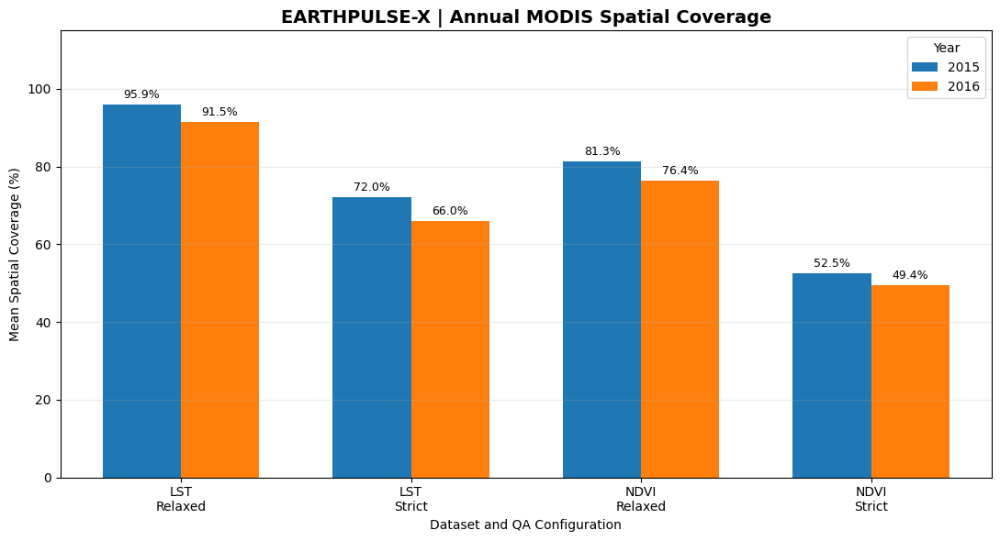

Chart saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_2016_annual_coverage_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Annual summary from the previous audit
plot_df = annual_comparison.reset_index()

categories = [
    ("LST", "relaxed"),
    ("LST", "strict"),
    ("NDVI", "relaxed"),
    ("NDVI", "strict")
]

years = [2015, 2016]
x = np.arange(len(categories))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 6))

for i, year in enumerate(years):

    values = []

    for product, mask in categories:

        value = plot_df.loc[
            (plot_df["year"] == year)
            & (plot_df["product"] == product)
            & (plot_df["mask"] == mask),
            "mean_coverage"
        ].iloc[0]

        values.append(value)

    positions = x + (i - 0.5) * width

    bars = ax.bar(
        positions,
        values,
        width,
        label=str(year)
    )

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "EARTHPULSE-X | Annual MODIS Spatial Coverage",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Mean Spatial Coverage (%)")
ax.set_xlabel("Dataset and QA Configuration")

ax.set_xticks(x)
ax.set_xticklabels([
    "LST\nRelaxed",
    "LST\nStrict",
    "NDVI\nRelaxed",
    "NDVI\nStrict"
])

ax.set_ylim(0, 115)
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

chart_path = (
    BASE_DIR /
    "reports/modis_2015_2016_annual_coverage_comparison.png"
)

chart_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)

In [ ]:
import pandas as pd

comparison_dates = coverage_comparison.copy()

comparison_dates["date"] = pd.to_datetime(
    comparison_dates["date"]
)

august_data = comparison_dates[
    comparison_dates["date"].dt.month == 8
]

for product in ["LST", "NDVI"]:

    print(f"\n========== {product} AUGUST COMPOSITES ==========")

    for year in [2015, 2016]:

        subset = august_data[
            (august_data["product"] == product)
            & (august_data["year"] == year)
        ]

        print(f"\n{year}")

        display(
            subset[
                ["date", "mask", "coverage_percent"]
            ].sort_values(["date", "mask"])
        )


========== LST AUGUST COMPOSITES ==========

2015


,date,mask,coverage_percent
33,2015-08-05,relaxed,56.777280
32,2015-08-05,strict,9.929522
35,2015-08-13,relaxed,74.878389
34,2015-08-13,strict,16.229190
37,2015-08-21,relaxed,96.790766
36,2015-08-21,strict,38.953908
39,2015-08-29,relaxed,99.699786
38,2015-08-29,strict,51.697732



2016


,date,mask,coverage_percent
163,2016-08-04,relaxed,73.356451
162,2016-08-04,strict,28.004945
165,2016-08-12,relaxed,30.361701
164,2016-08-12,strict,3.111304
167,2016-08-20,relaxed,96.179101
166,2016-08-20,strict,42.789257
169,2016-08-28,relaxed,95.474321
168,2016-08-28,strict,39.685980



========== NDVI AUGUST COMPOSITES ==========

2015


,date,mask,coverage_percent
89,2015-08-13,relaxed,53.884839
88,2015-08-13,strict,18.357806
91,2015-08-29,relaxed,83.747776
90,2015-08-29,strict,58.391267



2016


,date,mask,coverage_percent
231,2016-08-12,relaxed,49.521326
230,2016-08-12,strict,26.683387
233,2016-08-28,relaxed,62.224671
232,2016-08-28,strict,37.811961


In [ ]:
import pandas as pd
import re

def get_doy_date(filename):
    match = re.search(r"doy(\d{4})(\d{3})", filename)
    if not match:
        return None

    year = int(match.group(1))
    doy = int(match.group(2))

    return (
        pd.Timestamp(year=year, month=1, day=1)
        + pd.Timedelta(days=doy - 1)
    )


def find_composite(processing_data, product, year, month, day, mask):

    target_date = pd.Timestamp(year, month, day)

    matches = processing_data[
        (processing_data["product"] == product)
        & (processing_data["mask"] == mask)
    ].copy()

    matches["date"] = matches["source_file"].apply(get_doy_date)

    matches = matches[matches["date"] == target_date]

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly 1 file for {product}, {target_date}, "
            f"{mask}; found {len(matches)}"
        )

    return matches.iloc[0]["output_file"]


# Selected August dates
selected_dates = {
    "LST": {2015: (8, 13), 2016: (8, 12)},
    "NDVI": {2015: (8, 13), 2016: (8, 12)}
}

for product, year_dates in selected_dates.items():

    print(f"\n========== {product} ==========")

    for year, (month, day) in year_dates.items():

        df = processing_df if year == 2015 else processing_df_2016

        for mask in ["relaxed", "strict"]:

            path = find_composite(
                df, product, year, month, day, mask
            )

            print(f"{year} | {mask}: {path}")


========== LST ==========
2015 | relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/relaxed/MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_relaxed.tif
2015 | strict: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/strict/MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_strict.tif
2016 | relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/relaxed/lst_2016-08-12_relaxed.tif
2016 | strict: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-08-12_strict.tif

========== NDVI ==========
2015 | relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/relaxed/MOD13Q1.061__250m_16_days_NDVI_doy2015225000000_aid0001_relaxed.tif
2015 | strict: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/strict/MOD13Q1.061__250m_16_days_NDVI_doy2015225000000_aid0001_strict.tif
2016 | relaxed: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/ndvi/relaxed/ndvi_2016

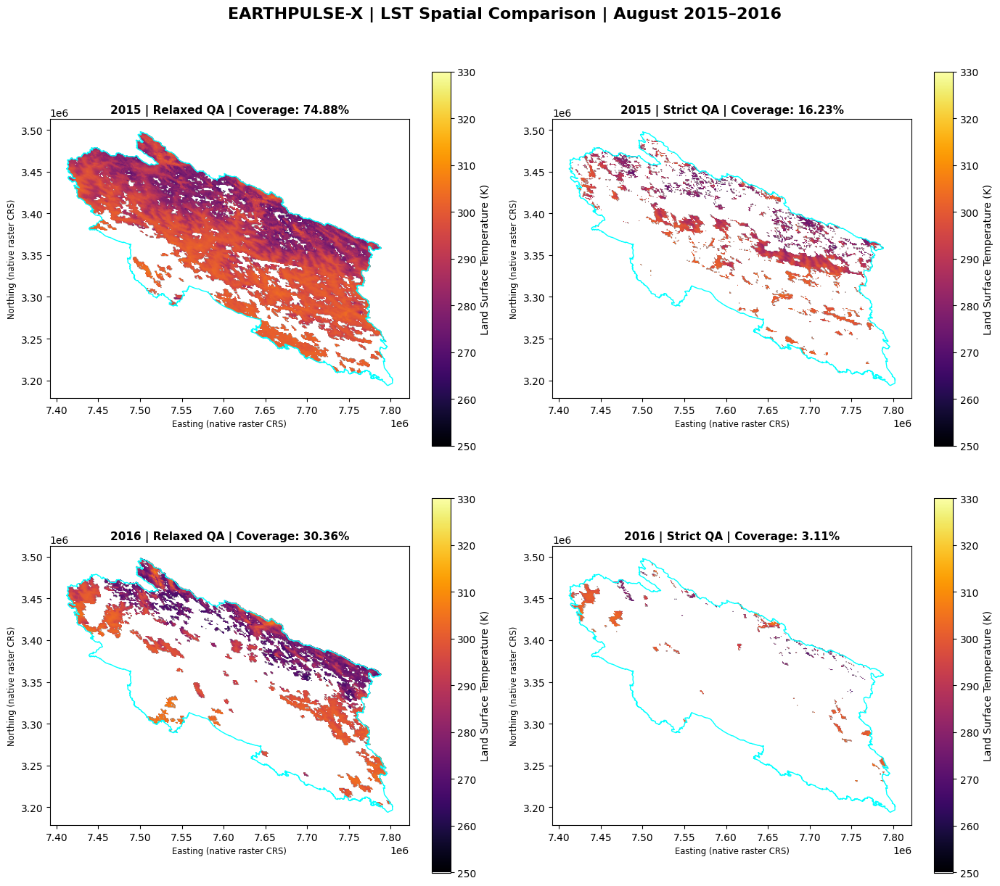

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_2016_maps/lst_august_2015_2016_comparison.png


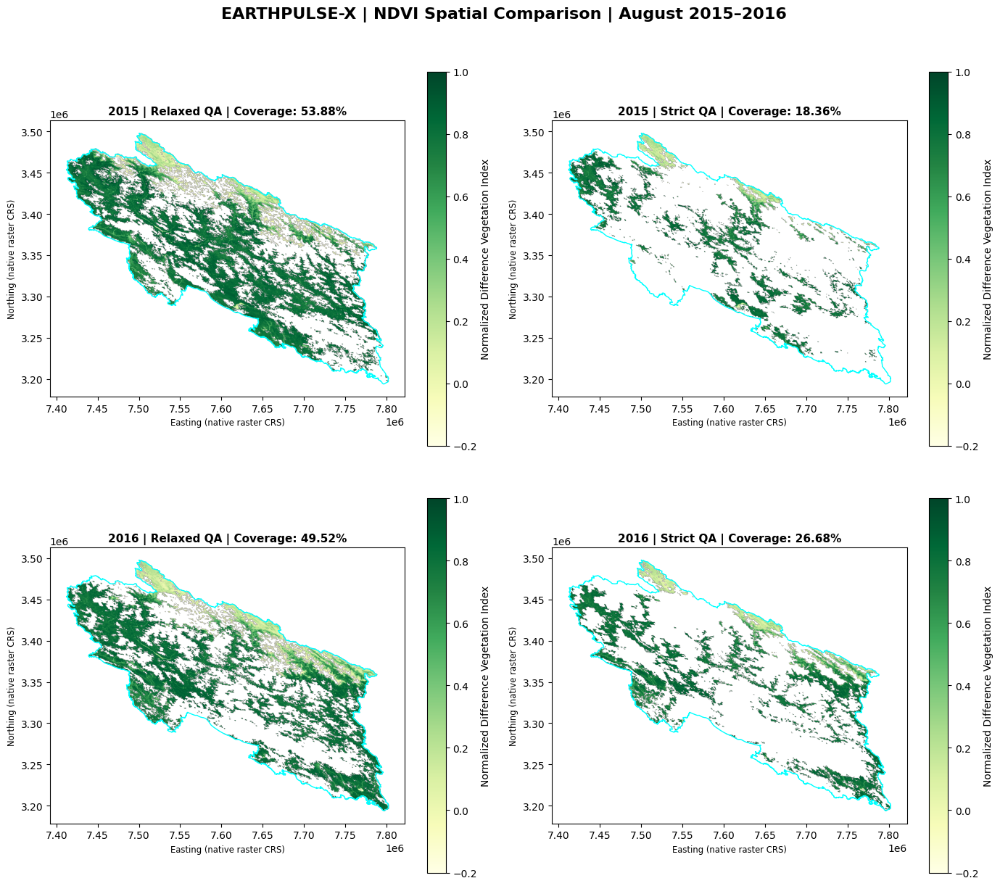

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/modis_2015_2016_maps/ndvi_august_2015_2016_comparison.png

Corrected spatial maps generated.


In [ ]:
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")

BOUNDARY_FILE = (
    BASE_DIR / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

MAP_DIR = BASE_DIR / "reports/modis_2015_2016_maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

study_area = gpd.read_file(BOUNDARY_FILE)
boundary_geometry = study_area.geometry.union_all()

selected_dates = {
    "LST": {
        2015: (8, 13),
        2016: (8, 12)
    },
    "NDVI": {
        2015: (8, 13),
        2016: (8, 12)
    }
}

visual_settings = {
    "LST": {
        "vmin": 250,
        "vmax": 330,
        "cmap": "inferno",
        "label": "Land Surface Temperature (K)"
    },
    "NDVI": {
        "vmin": -0.2,
        "vmax": 1.0,
        "cmap": "YlGn",
        "label": "Normalized Difference Vegetation Index"
    }
}

processing_lookup = {
    2015: processing_df,
    2016: processing_df_2016
}

for product in ["LST", "NDVI"]:

    settings = visual_settings[product]

    fig, axes = plt.subplots(2, 2, figsize=(14, 13))

    fig.suptitle(
        f"EARTHPULSE-X | {product} Spatial Comparison | August 2015–2016",
        fontsize=16,
        fontweight="bold"
    )

    for row_index, year in enumerate([2015, 2016]):

        month, day = selected_dates[product][year]

        for col_index, mask in enumerate(["relaxed", "strict"]):

            ax = axes[row_index, col_index]

            raster_path = find_composite(
                processing_lookup[year],
                product,
                year,
                month,
                day,
                mask
            )

            with rasterio.open(raster_path) as src:

                data = src.read(1).astype("float32")

                boundary_projected = gpd.GeoSeries(
                    [boundary_geometry],
                    crs=study_area.crs
                ).to_crs(src.crs).iloc[0]

                inside = geometry_mask(
                    [boundary_projected],
                    out_shape=(src.height, src.width),
                    transform=src.transform,
                    invert=True,
                    all_touched=False
                )

                valid = (
                    inside
                    & np.isfinite(data)
                    & (data != src.nodata)
                )

                masked_data = np.ma.masked_where(
                    ~valid,
                    data
                )

                # Correct coordinate order:
                # west, south, east, north
                west, south, east, north = array_bounds(
                    src.height,
                    src.width,
                    src.transform
                )

                # Correct imshow extent:
                # left, right, bottom, top
                image = ax.imshow(
                    masked_data,
                    extent=(west, east, south, north),
                    origin="upper",
                    cmap=settings["cmap"],
                    vmin=settings["vmin"],
                    vmax=settings["vmax"]
                )

                gpd.GeoSeries(
                    [boundary_projected],
                    crs=src.crs
                ).boundary.plot(
                    ax=ax,
                    color="cyan",
                    linewidth=1.0
                )

                coverage_pct = (
                    valid.sum() / inside.sum() * 100
                    if inside.sum() > 0 else np.nan
                )

                # Zoom to Uttarakhand boundary
                bx_min, by_min, bx_max, by_max = (
                    boundary_projected.bounds
                )

                x_margin = (bx_max - bx_min) * 0.05
                y_margin = (by_max - by_min) * 0.05

                ax.set_xlim(
                    bx_min - x_margin,
                    bx_max + x_margin
                )

                ax.set_ylim(
                    by_min - y_margin,
                    by_max + y_margin
                )

            ax.set_title(
                f"{year} | {mask.title()} QA | Coverage: {coverage_pct:.2f}%",
                fontsize=11,
                fontweight="bold"
            )

            ax.set_xlabel("Easting (native raster CRS)")
            ax.set_ylabel("Northing (native raster CRS)")
            ax.set_aspect("equal")

            fig.colorbar(
                image,
                ax=ax,
                shrink=0.8,
                label=settings["label"]
            )

    plt.tight_layout()

    output_file = (
        MAP_DIR /
        f"{product.lower()}_august_2015_2016_comparison.png"
    )

    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output_file)

print("\nCorrected spatial maps generated.")

In [ ]:
import rasterio
import pandas as pd

grid_audit = []

for product in ["LST", "NDVI"]:

    print(f"\n========== {product} GRID AUDIT ==========")

    for mask in ["relaxed", "strict"]:

        paths = {}

        for year in [2015, 2016]:

            month, day = selected_dates[product][year]

            paths[year] = find_composite(
                processing_lookup[year],
                product,
                year,
                month,
                day,
                mask
            )

        with rasterio.open(paths[2015]) as src15, \
             rasterio.open(paths[2016]) as src16:

            result = {
                "product": product,
                "mask": mask,
                "same_width": src15.width == src16.width,
                "same_height": src15.height == src16.height,
                "same_crs": src15.crs == src16.crs,
                "same_transform": src15.transform == src16.transform,
                "same_bounds": src15.bounds == src16.bounds
            }

            result["grid_compatible"] = all(
                result[key] for key in [
                    "same_width",
                    "same_height",
                    "same_crs",
                    "same_transform",
                    "same_bounds"
                ]
            )

            grid_audit.append(result)

            print(f"\nQA: {mask}")
            print("2015 dimensions:", src15.width, src15.height)
            print("2016 dimensions:", src16.width, src16.height)
            print("CRS identical:", result["same_crs"])
            print("Transform identical:", result["same_transform"])
            print("Bounds identical:", result["same_bounds"])
            print("GRID COMPATIBLE:", result["grid_compatible"])

grid_audit_df = pd.DataFrame(grid_audit)

audit_path = (
    BASE_DIR /
    "data/metadata/modis_cross_year_grid_audit.csv"
)

grid_audit_df.to_csv(audit_path, index=False)

print("\nAudit saved:", audit_path)


========== LST GRID AUDIT ==========

QA: relaxed
2015 dimensions: 423 329
2016 dimensions: 423 329
CRS identical: True
Transform identical: True
Bounds identical: True
GRID COMPATIBLE: True

QA: strict
2015 dimensions: 423 329
2016 dimensions: 423 329
CRS identical: True
Transform identical: True
Bounds identical: True
GRID COMPATIBLE: True

========== NDVI GRID AUDIT ==========

QA: relaxed
2015 dimensions: 1688 1313
2016 dimensions: 1688 1313
CRS identical: True
Transform identical: True
Bounds identical: True
GRID COMPATIBLE: True

QA: strict
2015 dimensions: 1688 1313
2016 dimensions: 1688 1313
CRS identical: True
Transform identical: True
Bounds identical: True
GRID COMPATIBLE: True

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_cross_year_grid_audit.csv


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterio.features import geometry_mask
from pathlib import Path

DIFF_DIR = BASE_DIR / "data/processed/cross_year_differences"
DIFF_DIR.mkdir(parents=True, exist_ok=True)

study_area = gpd.read_file(BOUNDARY_FILE)
boundary_geometry = study_area.geometry.union_all()

comparison_results = []

for product in ["LST", "NDVI"]:

    for mask in ["relaxed", "strict"]:

        print(f"\nProcessing {product} | {mask}")

        year_arrays = {}
        common_inside = None

        for year in [2015, 2016]:

            month, day = selected_dates[product][year]

            raster_path = find_composite(
                processing_lookup[year],
                product,
                year,
                month,
                day,
                mask
            )

            with rasterio.open(raster_path) as src:

                data = src.read(1).astype("float32")

                projected_boundary = gpd.GeoSeries(
                    [boundary_geometry],
                    crs=study_area.crs
                ).to_crs(src.crs).iloc[0]

                inside = geometry_mask(
                    [projected_boundary],
                    out_shape=(src.height, src.width),
                    transform=src.transform,
                    invert=True,
                    all_touched=False
                )

                valid = (
                    inside
                    & np.isfinite(data)
                    & (data != src.nodata)
                )

                year_arrays[year] = {
                    "data": data,
                    "valid": valid,
                    "profile": src.profile.copy(),
                    "path": str(raster_path)
                }

                if common_inside is None:
                    common_inside = inside

        # Common valid pixels
        common_valid = (
            common_inside
            & year_arrays[2015]["valid"]
            & year_arrays[2016]["valid"]
        )

        total_inside = int(common_inside.sum())
        common_count = int(common_valid.sum())

        if common_count == 0:
            raise ValueError(
                f"No common valid pixels: {product} {mask}"
            )

        values_2015 = year_arrays[2015]["data"][common_valid]
        values_2016 = year_arrays[2016]["data"][common_valid]

        difference = values_2016 - values_2015

        stats = {
            "product": product,
            "mask": mask,
            "total_study_area_pixels": total_inside,
            "common_valid_pixels": common_count,
            "common_coverage_pct": (
                common_count / total_inside * 100
            ),
            "mean_2015": float(np.mean(values_2015)),
            "mean_2016": float(np.mean(values_2016)),
            "mean_difference": float(np.mean(difference)),
            "median_difference": float(np.median(difference)),
            "std_difference": float(np.std(difference)),
            "min_difference": float(np.min(difference)),
            "max_difference": float(np.max(difference))
        }

        comparison_results.append(stats)

        # IMPORTANT: Preserve 2D raster shape
        diff_array = np.full(
            year_arrays[2015]["data"].shape,
            -9999.0,
            dtype="float32"
        )

        # Assign only at common valid pixel positions
        diff_array[common_valid] = difference

        profile = year_arrays[2015]["profile"].copy()

        profile.update(
            dtype="float32",
            count=1,
            nodata=-9999.0,
            compress="deflate"
        )

        output_path = (
            DIFF_DIR /
            f"{product.lower()}_2016_minus_2015_{mask}.tif"
        )

        with rasterio.open(output_path, "w", **profile) as dst:

            dst.write(diff_array, 1)

            dst.update_tags(
                comparison="2016 minus 2015",
                product=product,
                qa_mask=mask,
                common_valid_pixels=str(common_count)
            )

        print("Common pixels:", common_count)
        print(
            "Common coverage:",
            round(stats["common_coverage_pct"], 2), "%"
        )
        print(
            "Mean difference:",
            round(stats["mean_difference"], 4)
        )
        print("Saved:", output_path)


# Save final comparison report
comparison_df = pd.DataFrame(comparison_results)

stats_path = (
    BASE_DIR /
    "data/metadata/modis_common_pixel_comparison_2015_2016.csv"
)

comparison_df.to_csv(stats_path, index=False)

print("\n========== COMMON PIXEL COMPARISON ==========")
display(comparison_df.round(4))

print("\nStatistics saved:", stats_path)
print("Difference rasters saved:", DIFF_DIR)


Processing LST | relaxed
Common pixels: 17194
Common coverage: 27.6 %
Mean difference: -2.4471
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/processed/cross_year_differences/lst_2016_minus_2015_relaxed.tif

Processing LST | strict
Common pixels: 655
Common coverage: 1.05 %
Mean difference: 0.7898
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/processed/cross_year_differences/lst_2016_minus_2015_strict.tif

Processing NDVI | relaxed
Common pixels: 334104
Common coverage: 33.53 %
Mean difference: -0.0059
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/processed/cross_year_differences/ndvi_2016_minus_2015_relaxed.tif

Processing NDVI | strict
Common pixels: 92070
Common coverage: 9.24 %
Mean difference: -0.0053
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/processed/cross_year_differences/ndvi_2016_minus_2015_strict.tif

========== COMMON PIXEL COMPARISON ==========


,product,mask,total_study_area_pixels,common_valid_pixels,common_coverage_pct,mean_2015,mean_2016,mean_difference,median_difference,std_difference,min_difference,max_difference
0,LST,relaxed,62289,17194,27.6036,289.2094,286.7623,-2.4471,-1.3800,6.5107,-33.0800,18.2200
1,LST,strict,62289,655,1.0516,291.5415,292.3314,0.7898,1.3600,4.1154,-18.2800,18.2200
2,NDVI,relaxed,996399,334104,33.5311,0.6876,0.6817,-0.0059,-0.0037,0.0844,-0.8827,0.9110
3,NDVI,strict,996399,92070,9.2403,0.6275,0.6222,-0.0053,-0.0028,0.0561,-0.7709,0.5892



Statistics saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_common_pixel_comparison_2015_2016.csv
Difference rasters saved: /content/drive/MyDrive/EARTHPULSE_X/data/processed/cross_year_differences


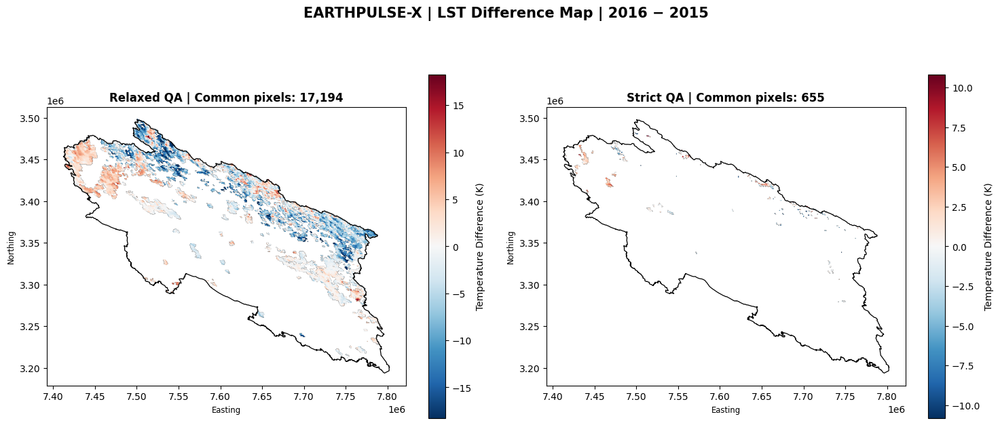

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/lst_difference_2016_minus_2015.png


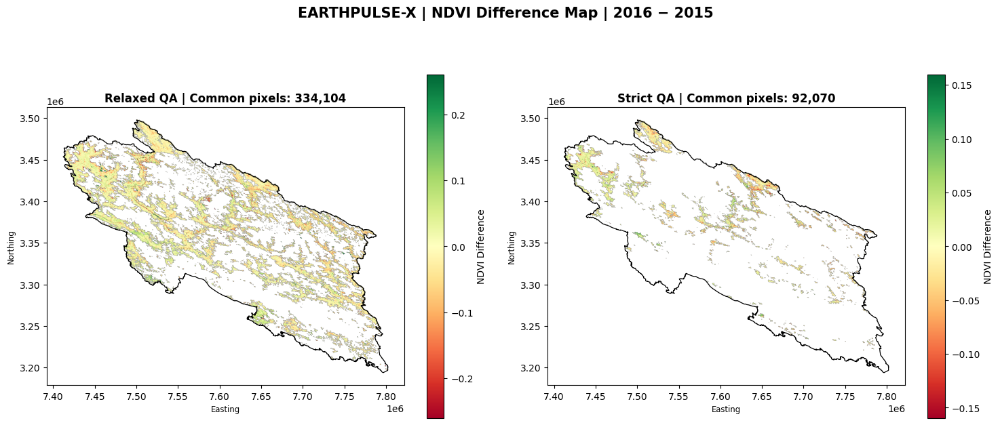

Saved: /content/drive/MyDrive/EARTHPULSE_X/reports/ndvi_difference_2016_minus_2015.png

Difference map generation complete.


In [ ]:
import numpy as np
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from pathlib import Path

DIFF_DIR = BASE_DIR / "data/processed/cross_year_differences"

study_area = gpd.read_file(BOUNDARY_FILE)
boundary_geometry = study_area.geometry.union_all()

difference_settings = {
    "LST": {
        "unit": "Temperature Difference (K)",
        "cmap": "RdBu_r"
    },
    "NDVI": {
        "unit": "NDVI Difference",
        "cmap": "RdYlGn"
    }
}

for product in ["LST", "NDVI"]:

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    fig.suptitle(
        f"EARTHPULSE-X | {product} Difference Map | 2016 − 2015",
        fontsize=15,
        fontweight="bold"
    )

    for ax, mask in zip(axes, ["relaxed", "strict"]):

        raster_path = (
            DIFF_DIR /
            f"{product.lower()}_2016_minus_2015_{mask}.tif"
        )

        with rasterio.open(raster_path) as src:

            data = src.read(1).astype("float32")

            boundary_projected = gpd.GeoSeries(
                [boundary_geometry],
                crs=study_area.crs
            ).to_crs(src.crs).iloc[0]

            inside = geometry_mask(
                [boundary_projected],
                out_shape=(src.height, src.width),
                transform=src.transform,
                invert=True,
                all_touched=False
            )

            valid = (
                inside
                & np.isfinite(data)
                & (data != src.nodata)
            )

            values = data[valid]

            if len(values) == 0:
                raise ValueError(f"No valid differences in {raster_path}")

            # Symmetric colour limits using robust 98th percentile
            limit = float(np.percentile(np.abs(values), 98))
            limit = max(limit, 1e-6)

            masked_data = np.ma.masked_where(
                ~valid,
                data
            )

            west, south, east, north = array_bounds(
                src.height,
                src.width,
                src.transform
            )

            image = ax.imshow(
                masked_data,
                extent=(west, east, south, north),
                origin="upper",
                cmap=difference_settings[product]["cmap"],
                vmin=-limit,
                vmax=limit
            )

            gpd.GeoSeries(
                [boundary_projected],
                crs=src.crs
            ).boundary.plot(
                ax=ax,
                color="black",
                linewidth=0.9
            )

            bx_min, by_min, bx_max, by_max = boundary_projected.bounds

            ax.set_xlim(
                bx_min - (bx_max - bx_min) * 0.05,
                bx_max + (bx_max - bx_min) * 0.05
            )

            ax.set_ylim(
                by_min - (by_max - by_min) * 0.05,
                by_max + (by_max - by_min) * 0.05
            )

            ax.set_title(
                f"{mask.title()} QA | "
                f"Common pixels: {len(values):,}",
                fontweight="bold"
            )

            ax.set_xlabel("Easting")
            ax.set_ylabel("Northing")
            ax.set_aspect("equal")

            fig.colorbar(
                image,
                ax=ax,
                shrink=0.8,
                label=difference_settings[product]["unit"]
            )

    plt.tight_layout()

    output_path = (
        BASE_DIR /
        "reports" /
        f"{product.lower()}_difference_2016_minus_2015.png"
    )

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

print("\nDifference map generation complete.")

In [ ]:

# ==========================================================
# EARTHPULSE-X | SESSION CHECKPOINT
# Save project progress before Colab runtime disconnects
# ==========================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import csv
import os
import sys
import platform
import importlib.metadata

# ----------------------------------------------------------
# 1. Project paths
# ----------------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

assert PROJECT_ROOT.exists(), (
    "Project folder not found. Check that Google Drive is mounted."
)

METADATA_DIR = PROJECT_ROOT / "data/metadata"
CHECKPOINT_DIR = PROJECT_ROOT / "logs/checkpoints"

METADATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# 2. Record important project milestones
# ----------------------------------------------------------

checkpoint = {
    "project": "EARTHPULSE-X",
    "checkpoint_time_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(PROJECT_ROOT),
    "current_stage": "MODIS 2015-2016 extraction, QA processing and comparison completed",
    "completed_years": [2015, 2016],
    "completed_work": [
        "NASA MODIS LST and NDVI extraction",
        "Raw bundle downloads and SHA256 verification",
        "Science and QA pairing validation",
        "Spatial grid alignment validation",
        "Decoded QA audits",
        "Strict and relaxed QA processing",
        "Independent processed raster validation",
        "Annual and monthly spatial coverage audits",
        "2015 versus 2016 common-pixel comparison",
        "LST and NDVI difference rasters and maps"
    ],
    "appeears_tasks": {
        "2015": {
            "task_name": "EARTHPULSE_X_MODIS_COMBINED_2015",
            "task_id": "19904cc8-655a-4a92-bea8-f65e9bb81e31",
            "status": "done"
        },
        "2016": {
            "task_name": "EARTHPULSE_X_MODIS_COMBINED_2016",
            "task_id": "65798b30-1b3f-41d7-9838-a8472feff666",
            "status": "done"
        }
    },
    "important_directories": [
        "data/raw",
        "data/processed",
        "data/metadata",
        "data/metadata",
        "notebooks",
        "src",
        "reports",
        "experiments",
        "logs"
    ],
    "next_step": (
        "Build reusable MODIS annual extraction and processing pipeline, "
        "then continue with 2017."
    ),
    "important_notes": [
        "Preserve native MODIS grids.",
        "Keep strict and relaxed QA outputs separate.",
        "Do not interpret missing pixels as zero.",
        "Do not interpret correlations as causal relationships.",
        "Do not download the entire SMAP archive.",
        "Never save Earthdata passwords or API tokens in checkpoints."
    ]
}

# ----------------------------------------------------------
# 3. Inventory all project files
# ----------------------------------------------------------

inventory = []

for path in PROJECT_ROOT.rglob("*"):

    if not path.is_file():
        continue

    try:
        stat = path.stat()

        inventory.append({
            "relative_path": str(path.relative_to(PROJECT_ROOT)),
            "size_bytes": stat.st_size,
            "modified_utc": datetime.fromtimestamp(
                stat.st_mtime, timezone.utc
            ).isoformat()
        })

    except OSError as error:
        print("Could not inspect:", path, error)

inventory.sort(key=lambda x: x["relative_path"])

inventory_path = METADATA_DIR / "project_file_inventory.csv"

with open(inventory_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "relative_path",
            "size_bytes",
            "modified_utc"
        ]
    )
    writer.writeheader()
    writer.writerows(inventory)

# ----------------------------------------------------------
# 4. Verify critical project outputs
# ----------------------------------------------------------

critical_files = [
    "data/metadata/canonical_study_area.json",
    "data/metadata/modis_2015_download_report.csv",
    "data/metadata/modis_2016_download_report.csv",
    "data/metadata/modis_2015_output_validation.csv",
    "data/metadata/modis_2016_output_validation.csv",
    "data/metadata/modis_2015_spatial_alignment.csv",
    "data/metadata/modis_2016_spatial_alignment.csv",
    "data/metadata/modis_2016_monthly_spatial_coverage.csv",
    "data/metadata/modis_common_pixel_comparison_2015_2016.csv",
    "data/metadata/modis_cross_year_grid_audit.csv",
    "data/processed/cross_year_differences/lst_2016_minus_2015_relaxed.tif",
    "data/processed/cross_year_differences/lst_2016_minus_2015_strict.tif",
    "data/processed/cross_year_differences/ndvi_2016_minus_2015_relaxed.tif",
    "data/processed/cross_year_differences/ndvi_2016_minus_2015_strict.tif"
]

verification = {}

for relative_path in critical_files:

    path = PROJECT_ROOT / relative_path

    verification[relative_path] = {
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    }

# ----------------------------------------------------------
# 5. Record environment information
# ----------------------------------------------------------

checkpoint["environment"] = {
    "python": sys.version,
    "platform": platform.platform()
}

for package in [
    "numpy", "pandas", "rasterio", "geopandas",
    "xarray", "scikit-learn", "torch", "earthaccess"
]:
    try:
        checkpoint["environment"][package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        checkpoint["environment"][package] = "Not installed"

checkpoint["file_inventory_count"] = len(inventory)
checkpoint["critical_file_verification"] = verification

# ----------------------------------------------------------
# 6. Save checkpoint atomically
# ----------------------------------------------------------

checkpoint_path = CHECKPOINT_DIR / "latest_checkpoint.json"
temporary_path = CHECKPOINT_DIR / "latest_checkpoint.tmp"

with open(temporary_path, "w") as f:
    json.dump(checkpoint, f, indent=4)

os.replace(temporary_path, checkpoint_path)

# ----------------------------------------------------------
# 7. Create human-readable resume instructions
# ----------------------------------------------------------

resume_text = f"""
EARTHPULSE-X — PROJECT RESUME GUIDE
===================================

Last checkpoint:
{checkpoint["checkpoint_time_utc"]}

PROJECT ROOT:
{PROJECT_ROOT}

COMPLETED:
- MODIS 2015 extraction and processing
- MODIS 2016 extraction and processing
- QA strict and relaxed outputs
- Independent raster validation
- Spatial coverage audits
- Cross-year comparison
- Difference maps

NEXT TASK:
Build a reusable annual MODIS extraction and processing pipeline.
Continue with 2017.

IMPORTANT:
1. Mount Google Drive in Colab.
2. Open the saved EARTHPULSE-X notebook from Drive.
3. Read logs/checkpoints/latest_checkpoint.json.
4. Inspect data/metadata/project_file_inventory.csv.
5. Recreate runtime variables and imports as needed.
6. Refresh AppEEARS authentication if required.
7. Do not submit duplicate NASA extraction tasks.
8. Continue from the next unfinished task.

Runtime variables and authentication tokens are not persisted.
Project files saved in Google Drive remain available.
"""

resume_path = PROJECT_ROOT / "SESSION_RESUME.txt"
resume_path.write_text(resume_text, encoding="utf-8")

# ----------------------------------------------------------
# 8. Final report
# ----------------------------------------------------------

print("=" * 65)
print("EARTHPULSE-X | CHECKPOINT COMPLETED")
print("=" * 65)

print("Project:", PROJECT_ROOT)
print("Files inventoried:", len(inventory))
print("Checkpoint:", checkpoint_path)
print("Inventory:", inventory_path)
print("Resume guide:", resume_path)

print("\nCRITICAL FILE VERIFICATION:")

for path, result in verification.items():
    status = "OK" if result["exists"] else "MISSING"
    print(f"[{status}] {path}")

missing = [
    path for path, result in verification.items()
    if not result["exists"]
]

print("\nOverall:", "ALL CRITICAL FILES FOUND" if not missing
      else f"{len(missing)} FILES NEED ATTENTION")

print("\nCheckpoint saved to Google Drive.")
print("You can safely disconnect after this cell completes.")


EARTHPULSE-X | CHECKPOINT COMPLETED
Project: /content/drive/MyDrive/EARTHPULSE_X
Files inventoried: 640
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/logs/checkpoints/latest_checkpoint.json
Inventory: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/project_file_inventory.csv
Resume guide: /content/drive/MyDrive/EARTHPULSE_X/SESSION_RESUME.txt

CRITICAL FILE VERIFICATION:
[OK] data/metadata/canonical_study_area.json
[OK] data/metadata/modis_2015_download_report.csv
[OK] data/metadata/modis_2016_download_report.csv
[OK] data/metadata/modis_2015_output_validation.csv
[OK] data/metadata/modis_2016_output_validation.csv
[OK] data/metadata/modis_2015_spatial_alignment.csv
[OK] data/metadata/modis_2016_spatial_alignment.csv
[OK] data/metadata/modis_2016_monthly_spatial_coverage.csv
[OK] data/metadata/modis_common_pixel_comparison_2015_2016.csv
[OK] data/metadata/modis_cross_year_grid_audit.csv
[OK] data/processed/cross_year_differences/lst_2016_minus_2015_relaxed.tif
[OK] data/processed/c

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")

CHECKPOINT_FILE = (
    BASE_DIR / "logs/checkpoints/latest_checkpoint.json"
)

RESUME_FILE = BASE_DIR / "SESSION_RESUME.txt"

INVENTORY_FILE = (
    BASE_DIR / "data/metadata/project_file_inventory.csv"
)

# Verify project
assert BASE_DIR.exists(), "EARTHPULSE-X folder not found!"

# Load checkpoint
assert CHECKPOINT_FILE.exists(), "Checkpoint file missing!"

with open(CHECKPOINT_FILE, "r") as f:
    checkpoint = json.load(f)

print("=" * 60)
print("EARTHPULSE-X | SESSION RECOVERY")
print("=" * 60)

print("\nLast saved checkpoint:")
print(checkpoint["checkpoint_time_utc"])

print("\nCurrent stage:")
print(checkpoint["current_stage"])

print("\nCompleted years:")
print(checkpoint["completed_years"])

print("\nNext task:")
print(checkpoint["next_step"])

# Load inventory
if INVENTORY_FILE.exists():
    inventory = pd.read_csv(INVENTORY_FILE)
    print("\nProject files inventoried:", len(inventory))
else:
    print("\nWARNING: Project inventory not found.")

# Display resume instructions
if RESUME_FILE.exists():
    print("\nSESSION RESUME GUIDE:")
    print(RESUME_FILE.read_text())

print("\nSESSION RECOVERY CHECK COMPLETE")

Mounted at /content/drive
EARTHPULSE-X | SESSION RECOVERY

Last saved checkpoint:
2026-11-04T18:22:06.834993+00:00

Current stage:
MODIS 2015-2016 extraction, QA processing and comparison completed

Completed years:
[2015, 2016]

Next task:
Build reusable MODIS annual extraction and processing pipeline, then continue with 2017.

Project files inventoried: 640

SESSION RESUME GUIDE:

EARTHPULSE-X — PROJECT RESUME GUIDE

Last checkpoint:
2026-11-04T18:22:06.834993+00:00

PROJECT ROOT:
/content/drive/MyDrive/EARTHPULSE_X

COMPLETED:
- MODIS 2015 extraction and processing
- MODIS 2016 extraction and processing
- QA strict and relaxed outputs
- Independent raster validation
- Spatial coverage audits
- Cross-year comparison
- Difference maps

NEXT TASK:
Build a reusable annual MODIS extraction and processing pipeline.
Continue with 2017.

IMPORTANT:
1. Mount Google Drive in Colab.
2. Open the saved EARTHPULSE-X notebook from Drive.
3. Read logs/checkpoints/latest_checkpoint.json.
4. Inspect 

In [ ]:
from pathlib import Path
import json
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")

print("=" * 65)
print("EARTHPULSE-X | PRE-PIPELINE AUDIT")
print("=" * 65)

# 1. Raw and processed data
print("\n1. YEAR-WISE DATA DIRECTORIES")

for year in range(2015, 2026):
    raw_dir = BASE_DIR / f"data/raw/modis_{year}"
    processed_dir = BASE_DIR / f"data/processed/modis_{year}"

    raw_count = sum(1 for p in raw_dir.rglob("*") if p.is_file()) if raw_dir.exists() else 0
    processed_count = sum(1 for p in processed_dir.rglob("*.tif")) if processed_dir.exists() else 0

    print(
        f"{year}: Raw files={raw_count}, "
        f"Processed rasters={processed_count}"
    )

# 2. Existing metadata
print("\n2. MODIS METADATA FILES")

metadata_dir = BASE_DIR / "data/metadata"

for path in sorted(metadata_dir.glob("*")):
    if "modis" in path.name.lower() or "appeears" in path.name.lower():
        print(path.name)

# 3. Existing 2017 task/request records
print("\n3. EXISTING 2017 REQUEST/TASK RECORDS")

found_2017 = []

for path in metadata_dir.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in [".json", ".csv", ".txt"]:
        continue

    try:
        content = path.read_text(errors="ignore")
        if "2017" in content and (
            "EARTHPULSE" in content.upper()
            or "APPEEARS" in content.upper()
        ):
            found_2017.append(path.name)
    except Exception:
        pass

if found_2017:
    for name in sorted(set(found_2017)):
        print(name)
else:
    print("No existing 2017 task/request record found in metadata.")

# 4. Existing reusable Python modules
print("\n4. EXISTING SOURCE CODE")

src_dir = BASE_DIR / "src"

if src_dir.exists():
    modules = list(src_dir.rglob("*.py"))

    if modules:
        for module in modules:
            print(module.relative_to(BASE_DIR))
    else:
        print("No Python modules created yet.")
else:
    print("src directory not found.")

# 5. Existing 2015/2016 request templates
print("\n5. APPEEARS REQUEST TEMPLATES")

for path in sorted(metadata_dir.glob("*request*.json")):
    print(path.name)

print("\nPRE-PIPELINE AUDIT COMPLETE")

EARTHPULSE-X | PRE-PIPELINE AUDIT

1. YEAR-WISE DATA DIRECTORIES
2015: Raw files=117, Processed rasters=106
2016: Raw files=153, Processed rasters=142
2017: Raw files=0, Processed rasters=0
2018: Raw files=0, Processed rasters=0
2019: Raw files=0, Processed rasters=0
2020: Raw files=0, Processed rasters=0
2021: Raw files=0, Processed rasters=0
2022: Raw files=0, Processed rasters=0
2023: Raw files=0, Processed rasters=0
2024: Raw files=0, Processed rasters=0
2025: Raw files=0, Processed rasters=0

2. MODIS METADATA FILES
appeears_combined_modis_2015_request.json
appeears_combined_modis_2016_request.json
appeears_lst_2015_request.json
appeears_modis_layer_metadata.json
appeears_product_catalogue.csv
appeears_projection_options.json
exact_modis_yearly_counts.csv
modis_2015_2016_spatial_coverage.csv
modis_2015_annual_composite_coverage.csv
modis_2015_annual_coverage_summary.csv
modis_2015_boundary_coverage.csv
modis_2015_bundle_manifest.json
modis_2015_complete_inventory.csv
modis_2015_de

In [ ]:
import json
from pathlib import Path

METADATA_DIR = BASE_DIR / "data/metadata"

request_files = {
    2015: METADATA_DIR / "appeears_combined_modis_2015_request.json",
    2016: METADATA_DIR / "appeears_combined_modis_2016_request.json"
}

def summarize_request(request, year):

    print(f"\n{'='*60}")
    print(f"APPEEARS REQUEST: {year}")
    print("="*60)

    print("Top-level keys:", list(request.keys()))

    # Task information
    task = request.get("task", {})
    print("\nTask configuration:")
    print(json.dumps(task, indent=2))

    # Product and layer information
    products = request.get("layers", [])

    print("\nProducts and layers:")

    for product in products:
        print({
            "product": product.get("product"),
            "layer_names": [
                layer.get("layer")
                for layer in product.get("layer", [])
            ]
        })

    # Temporal information
    dates = request.get("dates", [])

    print("\nDate configuration:")
    print(json.dumps(dates, indent=2))

    # Projection
    print("\nProjection:")
    print(json.dumps(request.get("output", {}), indent=2))

    # File format
    print("\nFile format:", request.get("format", {}))

    # Geometry summary without printing huge polygon
    geo = request.get("geo", {})

    print("\nStudy area geometry:")
    print("Geometry type:", geo.get("type"))

    coordinates = geo.get("coordinates", [])

    def count_vertices(obj):
        if isinstance(obj, list):
            if (
                len(obj) >= 2
                and isinstance(obj[0], (int, float))
                and isinstance(obj[1], (int, float))
            ):
                return 1
            return sum(count_vertices(x) for x in obj)
        return 0

    print("Coordinate vertices:", count_vertices(coordinates))


loaded_requests = {}

for year, path in request_files.items():

    if not path.exists():
        raise FileNotFoundError(path)

    with open(path, "r") as f:
        request = json.load(f)

    loaded_requests[year] = request
    summarize_request(request, year)


# Compare structure
print("\n" + "="*60)
print("REQUEST STRUCTURE COMPARISON")
print("="*60)

request_2015 = loaded_requests[2015]
request_2016 = loaded_requests[2016]

print(
    "Same top-level keys:",
    set(request_2015.keys()) == set(request_2016.keys())
)

print(
    "Same layer configuration:",
    request_2015.get("layers") == request_2016.get("layers")
)

print(
    "Same output configuration:",
    request_2015.get("output") == request_2016.get("output")
)

print(
    "Same geometry:",
    request_2015.get("geo") == request_2016.get("geo")
)

print("\nREQUEST TEMPLATE INSPECTION COMPLETE")


APPEEARS REQUEST: 2015
Top-level keys: ['task_type', 'task_name', 'params']

Task configuration:
{}

Products and layers:

Date configuration:
[]

Projection:
{}

File format: {}

Study area geometry:
Geometry type: None
Coordinate vertices: 0

APPEEARS REQUEST: 2016
Top-level keys: ['task_type', 'task_name', 'params']

Task configuration:
{}

Products and layers:

Date configuration:
[]

Projection:
{}

File format: {}

Study area geometry:
Geometry type: None
Coordinate vertices: 0

REQUEST STRUCTURE COMPARISON
Same top-level keys: True
Same layer configuration: True
Same output configuration: True
Same geometry: True

REQUEST TEMPLATE INSPECTION COMPLETE


In [ ]:
import json
from pathlib import Path

METADATA_DIR = BASE_DIR / "data/metadata"

for year in [2015, 2016]:

    file_path = (
        METADATA_DIR /
        f"appeears_combined_modis_{year}_request.json"
    )

    with open(file_path, "r") as f:
        request = json.load(f)

    print("\n" + "=" * 65)
    print(f"REQUEST STRUCTURE: {year}")
    print("=" * 65)

    print("Task type:", request.get("task_type"))
    print("Task name:", request.get("task_name"))

    params = request.get("params", {})

    print("\nPARAMS KEYS:")
    print(list(params.keys()))

    print("\nPARAMETER DETAILS:")

    for key, value in params.items():

        if key == "geo":
            print("\nGeometry:")
            print("Type:", value.get("type") if isinstance(value, dict) else type(value))
            print("Geometry present:", bool(value))

        elif isinstance(value, (dict, list)):
            print(f"\n{key}:")
            print(json.dumps(value, indent=2)[:5000])

        else:
            print(f"\n{key}: {value}")

    print("\nREQUEST SIZE:", file_path.stat().st_size, "bytes")

print("\nNESTED REQUEST INSPECTION COMPLETE")


REQUEST STRUCTURE: 2015
Task type: area
Task name: EARTHPULSE_X_MODIS_COMBINED_2015

PARAMS KEYS:
['dates', 'layers', 'geo', 'output']

PARAMETER DETAILS:

dates:
[
  {
    "startDate": "04-01-2015",
    "endDate": "12-31-2015"
  }
]

layers:
[
  {
    "product": "MOD11A2.061",
    "layer": "LST_Day_1km"
  },
  {
    "product": "MOD11A2.061",
    "layer": "QC_Day"
  },
  {
    "product": "MOD13Q1.061",
    "layer": "_250m_16_days_NDVI"
  },
  {
    "product": "MOD13Q1.061",
    "layer": "_250m_16_days_VI_Quality"
  }
]

Geometry:
Type: FeatureCollection
Geometry present: True

output:
{
  "format": {
    "type": "geotiff"
  },
  "projection": "native"
}

REQUEST SIZE: 3354163 bytes

REQUEST STRUCTURE: 2016
Task type: area
Task name: EARTHPULSE_X_MODIS_COMBINED_2016

PARAMS KEYS:
['dates', 'layers', 'geo', 'output']

PARAMETER DETAILS:

dates:
[
  {
    "startDate": "01-01-2016",
    "endDate": "12-31-2016"
  }
]

layers:
[
  {
    "product": "MOD11A2.061",
    "layer": "LST_Day_1km"
 

In [ ]:
import json
import copy
from pathlib import Path

METADATA_DIR = BASE_DIR / "data/metadata"

# Load the previously successful 2016 request
template_path = (
    METADATA_DIR / "appeears_combined_modis_2016_request.json"
)

with open(template_path, "r") as f:
    template_2016 = json.load(f)

# Deep copy: original template remains untouched
request_2017 = copy.deepcopy(template_2016)

# Update only year-specific fields
request_2017["task_name"] = "EARTHPULSE_X_MODIS_COMBINED_2017"

request_2017["params"]["dates"] = [
    {
        "startDate": "01-01-2017",
        "endDate": "12-31-2017"
    }
]

# Save generated request
request_path = (
    METADATA_DIR / "appeears_combined_modis_2017_request.json"
)

with open(request_path, "w") as f:
    json.dump(request_2017, f, indent=2)

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

checks = {
    "task_type_area": request_2017["task_type"] == "area",

    "correct_task_name":
        request_2017["task_name"] ==
        "EARTHPULSE_X_MODIS_COMBINED_2017",

    "correct_dates":
        request_2017["params"]["dates"] == [
            {
                "startDate": "01-01-2017",
                "endDate": "12-31-2017"
            }
        ],

    "layers_unchanged":
        request_2017["params"]["layers"] ==
        template_2016["params"]["layers"],

    "geometry_unchanged":
        request_2017["params"]["geo"] ==
        template_2016["params"]["geo"],

    "output_unchanged":
        request_2017["params"]["output"] ==
        template_2016["params"]["output"],

    "four_layers_present":
        len(request_2017["params"]["layers"]) == 4,

    "native_projection":
        request_2017["params"]["output"]["projection"] == "native",

    "geotiff_format":
        request_2017["params"]["output"]["format"]["type"] == "geotiff"
}

print("=" * 60)
print("EARTHPULSE-X | 2017 REQUEST VALIDATION")
print("=" * 60)

for check, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {check}")

print("\nAll checks passed:", all(checks.values()))
print("Request size:", request_path.stat().st_size, "bytes")
print("Saved:", request_path)

assert all(checks.values()), "Request validation failed!"

print("\n2017 REQUEST READY FOR REVIEW")
print("No NASA task has been submitted yet.")

EARTHPULSE-X | 2017 REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] layers_unchanged
[PASS] geometry_unchanged
[PASS] output_unchanged
[PASS] four_layers_present
[PASS] native_projection
[PASS] geotiff_format

All checks passed: True
Request size: 2076099 bytes
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2017_request.json

2017 REQUEST READY FOR REVIEW
No NASA task has been submitted yet.


In [ ]:
from pathlib import Path

module_path = BASE_DIR / "src/ingestion/modis_appeears.py"
module_path.parent.mkdir(parents=True, exist_ok=True)

module_code = r'''
"""Reusable AppEEARS request generation and validation for EARTHPULSE-X."""

import copy
import json
from pathlib import Path


EXPECTED_LAYERS = [
    {"product": "MOD11A2.061", "layer": "LST_Day_1km"},
    {"product": "MOD11A2.061", "layer": "QC_Day"},
    {"product": "MOD13Q1.061", "layer": "_250m_16_days_NDVI"},
    {"product": "MOD13Q1.061", "layer": "_250m_16_days_VI_Quality"},
]


def load_request(path):
    """Load an existing AppEEARS request JSON."""
    path = Path(path)

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def build_annual_request(template_path, year, output_path=None):
    """
    Build an annual request from a previously validated template.

    Only task_name and dates are changed. Layers, geometry,
    projection and output format are preserved.
    """
    year = int(year)

    if year < 2000 or year > 2100:
        raise ValueError(f"Invalid year: {year}")

    request = load_request(template_path)
    request = copy.deepcopy(request)

    request["task_name"] = f"EARTHPULSE_X_MODIS_COMBINED_{year}"

    request["params"]["dates"] = [
        {
            "startDate": f"01-01-{year}",
            "endDate": f"12-31-{year}"
        }
    ]

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)

        with output_path.open("w", encoding="utf-8") as file:
            json.dump(request, file, indent=2)

    return request


def validate_annual_request(request, year, reference_request=None):
    """Validate the annual request without submitting it."""

    year = int(year)
    params = request.get("params", {})

    checks = {
        "task_type_area": request.get("task_type") == "area",

        "correct_task_name":
            request.get("task_name") ==
            f"EARTHPULSE_X_MODIS_COMBINED_{year}",

        "correct_dates":
            params.get("dates") == [{
                "startDate": f"01-01-{year}",
                "endDate": f"12-31-{year}"
            }],

        "expected_layers":
            params.get("layers") == EXPECTED_LAYERS,

        "four_layers_present":
            len(params.get("layers", [])) == 4,

        "native_projection":
            params.get("output", {}).get("projection") == "native",

        "geotiff_format":
            params.get("output", {}).get("format", {}).get("type")
            == "geotiff",

        "geometry_present":
            isinstance(params.get("geo"), dict)
            and bool(params["geo"])
    }

    if reference_request is not None:
        ref_params = reference_request.get("params", {})

        checks["geometry_unchanged"] = (
            params.get("geo") == ref_params.get("geo")
        )

        checks["layers_unchanged"] = (
            params.get("layers") == ref_params.get("layers")
        )

        checks["output_unchanged"] = (
            params.get("output") == ref_params.get("output")
        )

    return checks


def print_validation_report(checks):
    """Print a readable validation report."""
    print("=" * 60)
    print("EARTHPULSE-X | APPEEARS REQUEST VALIDATION")
    print("=" * 60)

    for name, passed in checks.items():
        print(f"[{'PASS' if passed else 'FAIL'}] {name}")

    print("-" * 60)
    print(f"Passed: {sum(checks.values())}/{len(checks)}")
    print(f"All checks passed: {all(checks.values())}")

    return all(checks.values())
'''

module_path.write_text(module_code, encoding="utf-8")

print("Module created:", module_path)
print("File size:", module_path.stat().st_size, "bytes")
print("\nModule preview:")
print(module_code[:1200])

Module created: /content/drive/MyDrive/EARTHPULSE_X/src/ingestion/modis_appeears.py
File size: 3441 bytes

Module preview:

"""Reusable AppEEARS request generation and validation for EARTHPULSE-X."""

import copy
import json
from pathlib import Path


EXPECTED_LAYERS = [
    {"product": "MOD11A2.061", "layer": "LST_Day_1km"},
    {"product": "MOD11A2.061", "layer": "QC_Day"},
    {"product": "MOD13Q1.061", "layer": "_250m_16_days_NDVI"},
    {"product": "MOD13Q1.061", "layer": "_250m_16_days_VI_Quality"},
]


def load_request(path):
    """Load an existing AppEEARS request JSON."""
    path = Path(path)

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def build_annual_request(template_path, year, output_path=None):
    """
    Build an annual request from a previously validated template.

    Only task_name and dates are changed. Layers, geometry,
    projection and output format are preserved.
    """
    year = int(year)

    if year < 2000 or year

In [ ]:
import sys
from pathlib import Path

# Add project root to Python path
PROJECT_ROOT = BASE_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import our reusable module
from src.ingestion.modis_appeears import (
    load_request,
    build_annual_request,
    validate_annual_request,
    print_validation_report
)

METADATA_DIR = BASE_DIR / "data/metadata"

# Load the validated 2016 reference request
reference_path = (
    METADATA_DIR / "appeears_combined_modis_2016_request.json"
)

reference_request = load_request(reference_path)

# Generate 2017 request using our module
output_path = (
    METADATA_DIR / "appeears_combined_modis_2017_module_test.json"
)

request_2017 = build_annual_request(
    template_path=reference_path,
    year=2017,
    output_path=output_path
)

# Validate generated request
checks = validate_annual_request(
    request=request_2017,
    year=2017,
    reference_request=reference_request
)

success = print_validation_report(checks)

print("\nGenerated file:", output_path)
print("File exists:", output_path.exists())

assert success, "Module validation failed!"

print("\nSUCCESS: Reusable request module is working!")

EARTHPULSE-X | APPEEARS REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] expected_layers
[PASS] four_layers_present
[PASS] native_projection
[PASS] geotiff_format
[PASS] geometry_present
[PASS] geometry_unchanged
[PASS] layers_unchanged
[PASS] output_unchanged
------------------------------------------------------------
Passed: 11/11
All checks passed: True

Generated file: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2017_module_test.json
File exists: True

SUCCESS: Reusable request module is working!


In [ ]:
import requests

print("=" * 60)
print("EARTHPULSE-X | APPEEARS CONNECTION CHECK")
print("=" * 60)

# Check existing authentication variables
print("\nAuthentication variable availability:")

for name in ["API_URL", "APPEEARS_HEADERS", "APPEEARS_TOKEN"]:
    exists = name in globals()
    print(f"{name}: {'Available' if exists else 'Not available'}")

# Check API URL
if "API_URL" in globals():
    print("\nAPI URL configured:", bool(API_URL))

# Check authorization header without revealing its value
if "APPEEARS_HEADERS" in globals():
    auth_present = any(
        key.lower() == "authorization"
        for key in APPEEARS_HEADERS
    )
    print("Authorization header present:", auth_present)

# Test API connectivity only if API_URL exists
if "API_URL" in globals():
    try:
        response = requests.get(
            API_URL.rstrip("/") + "/",
            timeout=30
        )

        print("\nAPI HTTP status:", response.status_code)
        print("API reachable:", response.ok)

    except requests.RequestException as error:
        print("\nAPI connection error:", type(error).__name__)

else:
    print("\nAPI URL unavailable. Authentication setup may be required.")

print("\nConnection check complete. No task was submitted.")

EARTHPULSE-X | APPEEARS CONNECTION CHECK

Authentication variable availability:
API_URL: Not available
APPEEARS_HEADERS: Not available
APPEEARS_TOKEN: Not available

API URL unavailable. Authentication setup may be required.

Connection check complete. No task was submitted.


In [ ]:
%pip install -q earthaccess requests
import earthaccess

print("=" * 60)
print("EARTHPULSE-X | EARTHDATA AUTHENTICATION")
print("=" * 60)

try:
    auth = earthaccess.login(
        strategy="interactive",
        persist=True
    )

    authenticated = auth.authenticated

    print("\nEarthdata authenticated:", authenticated)

    if authenticated:
        print("Authentication restored successfully!")
        print("Credentials persistence:", "Enabled")
    else:
        print("Authentication was not completed.")
        print("Please complete the Earthdata login process.")

except Exception as error:
    print("\nAuthentication error:", type(error).__name__)
    print("Please share the error message, without sharing credentials.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
EARTHPULSE-X | EARTHDATA AUTHENTICATION
Enter your Earthdata Login username: adityasuyal0001
Enter your Earthdata password: ··········

Earthdata authenticated: True
Authentication restored successfully!
Credentials persistence: Enabled


In [ ]:
import requests
from getpass import getpass

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

print("=" * 60)
print("EARTHPULSE-X | APPEEARS API AUTHENTICATION")
print("=" * 60)

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")

try:
    response = requests.post(
        API_URL.rstrip("/") + "/login",
        auth=(username, password),
        timeout=30
    )

    print("\nHTTP Status:", response.status_code)

    response.raise_for_status()

    auth_data = response.json()

    APPEEARS_TOKEN = auth_data.get("token")

    if not APPEEARS_TOKEN:
        raise ValueError("Authentication response did not contain a token.")

    APPEEARS_HEADERS = {
        "Authorization": f"Bearer {APPEEARS_TOKEN}"
    }

    print("AppEEARS authentication: SUCCESS")
    print("API token received: Yes")
    print("Authorization header configured: Yes")

except requests.RequestException as error:
    APPEEARS_TOKEN = None
    APPEEARS_HEADERS = {}

    print("AppEEARS authentication failed.")
    print("Error:", type(error).__name__)

except (ValueError, KeyError) as error:
    APPEEARS_TOKEN = None
    APPEEARS_HEADERS = {}

    print("Authentication response error:", str(error))

EARTHPULSE-X | APPEEARS API AUTHENTICATION
Earthdata username: adityasuyal0001
Earthdata password: ··········

HTTP Status: 200
AppEEARS authentication: SUCCESS
API token received: Yes
Authorization header configured: Yes


In [ ]:
import requests

print("=" * 60)
print("EARTHPULSE-X | EXISTING APPEEARS TASK AUDIT")
print("=" * 60)

try:
    response = requests.get(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        timeout=60
    )

    print("HTTP Status:", response.status_code)
    response.raise_for_status()

    task_data = response.json()

    if isinstance(task_data, dict):
        tasks = task_data.get("tasks", [])
    elif isinstance(task_data, list):
        tasks = task_data
    else:
        tasks = []

    print("Total tasks returned:", len(tasks))

    print("\nEARTHPULSE-X MODIS TASKS:")
    print("-" * 60)

    for task in tasks:
        name = task.get("task_name", "")
        if "EARTHPULSE_X_MODIS_COMBINED" in name:
            print("Name:", name)
            print("Task ID:", task.get("task_id"))
            print("Status:", task.get("status"))
            print("-" * 60)

    matching_2017 = [
        task for task in tasks
        if task.get("task_name") == "EARTHPULSE_X_MODIS_COMBINED_2017"
    ]

    print("\n2017 task already exists:", bool(matching_2017))

except requests.RequestException as error:
    print("Task audit failed:", type(error).__name__)

print("\nTask audit complete. No task was submitted.")

EARTHPULSE-X | EXISTING APPEEARS TASK AUDIT
HTTP Status: 200
Total tasks returned: 3

EARTHPULSE-X MODIS TASKS:
------------------------------------------------------------
Name: EARTHPULSE_X_MODIS_COMBINED_2016
Task ID: 65798b30-1b3f-41d7-9838-a8472feff666
Status: done
------------------------------------------------------------
Name: EARTHPULSE_X_MODIS_COMBINED_2015
Task ID: 19904cc8-655a-4a92-bea8-f65e9bb81e31
Status: done
------------------------------------------------------------

2017 task already exists: False

Task audit complete. No task was submitted.


In [ ]:
import json
import requests
from datetime import datetime, timezone
from pathlib import Path

from src.ingestion.modis_appeears import (
    load_request,
    validate_annual_request,
    print_validation_report
)

METADATA_DIR = BASE_DIR / "data/metadata"

request_path = (
    METADATA_DIR / "appeears_combined_modis_2017_request.json"
)
reference_path = (
    METADATA_DIR / "appeears_combined_modis_2016_request.json"
)

# 1. Load and validate request
request_2017 = load_request(request_path)
reference_2016 = load_request(reference_path)

checks = validate_annual_request(
    request_2017, 2017, reference_2016
)

if not print_validation_report(checks):
    raise RuntimeError("Request validation failed. Submission cancelled.")

# 2. Refresh task list immediately before submission
task_response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
task_response.raise_for_status()

task_data = task_response.json()
tasks = (
    task_data.get("tasks", [])
    if isinstance(task_data, dict)
    else task_data
)

task_name = "EARTHPULSE_X_MODIS_COMBINED_2017"

existing = [
    task for task in tasks
    if task.get("task_name") == task_name
]

if existing:
    print("\nSubmission cancelled: matching task already exists.")
    for task in existing:
        print("Task ID:", task.get("task_id"))
        print("Status:", task.get("status"))
else:
    # 3. Submit the validated request
    print("\nSubmitting 2017 task to NASA AppEEARS...")

    response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=request_2017,
        timeout=120
    )

    print("HTTP Status:", response.status_code)
    response.raise_for_status()

    submission_data = response.json()

    # 4. Save task record without credentials
    submission_record = {
        "task_name": task_name,
        "submitted_at_utc": datetime.now(timezone.utc).isoformat(),
        "http_status": response.status_code,
        "response": submission_data
    }

    record_path = (
        METADATA_DIR / "appeears_combined_modis_2017_submission.json"
    )

    with open(record_path, "w", encoding="utf-8") as f:
        json.dump(submission_record, f, indent=2)

    print("\nSubmission response:")
    print(json.dumps(submission_data, indent=2))

    print("\nSubmission record saved:", record_path)

EARTHPULSE-X | APPEEARS REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] expected_layers
[PASS] four_layers_present
[PASS] native_projection
[PASS] geotiff_format
[PASS] geometry_present
[PASS] geometry_unchanged
[PASS] layers_unchanged
[PASS] output_unchanged
------------------------------------------------------------
Passed: 11/11
All checks passed: True

Submitting 2017 task to NASA AppEEARS...
HTTP Status: 202

Submission response:
{
  "task_id": "f4771d0a-f287-444e-8c64-317276dd6ff6",
  "status": "pending"
}

Submission record saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_combined_modis_2017_submission.json


In [ ]:
import requests
import json

TASK_ID = "f4771d0a-f287-444e-8c64-317276dd6ff6"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()
task_status = response.json()

print("=" * 60)
print("EARTHPULSE-X | NASA EXTRACTION STATUS")
print("=" * 60)

print(json.dumps(task_status, indent=2))

EARTHPULSE-X | NASA EXTRACTION STATUS
{
  "tier": 1,
  "params": {
    "geo": {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "geometry": {
            "type": "Polygon",
            "coordinates": [
              [
                [
                  80.06508911589948,
                  28.836732767314864
                ],
                [
                  80.06497335899196,
                  28.837782087196427
                ],
                [
                  80.06487686376079,
                  28.838831304428773
                ],
                [
                  80.06481932127694,
                  28.83989673298802
                ],
                [
                  80.06474243087852,
                  28.841204221353745
                ],
                [
                  80.06468482641091,
                  28.842156595721008
                ],
                [
                  80.06460779048543,
      

In [ ]:
import requests

TASK_ID = "f4771d0a-f287-444e-8c64-317276dd6ff6"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()
task = response.json()

print("Task:", task.get("task_name"))
print("Status:", task.get("status"))
print("Updated:", task.get("updated"))

if task.get("status") == "done":
    print("\nSUCCESS! 2017 extraction completed.")
elif task.get("status") == "pending":
    print("\nNASA task is waiting for processing.")
elif task.get("status") == "processing":
    print("\nNASA is processing the extraction.")
else:
    print("\nPlease inspect the returned task status.")

Task: EARTHPULSE_X_MODIS_COMBINED_2017
Status: pending
Updated: 2026-11-05T09:18:27.131938

NASA task is waiting for processing.


In [ ]:
import json
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

CHECKPOINT_DIR = PROJECT_ROOT / "logs/checkpoints"
METADATA_DIR = PROJECT_ROOT / "data/metadata"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. VERIFY IMPORTANT PROJECT FILES
# --------------------------------------------------

important_files = [
    "src/ingestion/modis_appeears.py",
    "data/metadata/appeears_combined_modis_2015_request.json",
    "data/metadata/appeears_combined_modis_2016_request.json",
    "data/metadata/appeears_combined_modis_2017_request.json",
    "data/metadata/appeears_combined_modis_2017_submission.json",
    "data/metadata/canonical_study_area.json",
]

file_status = {}

for relative_path in important_files:
    path = PROJECT_ROOT / relative_path
    file_status[relative_path] = {
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    }

# --------------------------------------------------
# 3. PROJECT CHECKPOINT
# --------------------------------------------------

now = datetime.now(ZoneInfo("Asia/Kolkata"))

checkpoint = {
    "project": "EARTHPULSE-X",
    "project_title": "Physics-Aware, Uncertainty-Guided Earth System Intelligence",
    "last_saved_ist": now.isoformat(),
    "project_root": str(PROJECT_ROOT),

    "current_stage": "MODIS extraction and QA processing",

    "completed_years": [2015, 2016],

    "completed_work": [
        "Study area boundary preparation",
        "NASA AppEEARS data discovery",
        "2015 MODIS extraction and download",
        "2016 MODIS extraction and download",
        "MODIS QA decoding and strict/relaxed masking",
        "Science raster processing and validation",
        "Cross-year spatial grid audit",
        "2015-2016 comparison",
        "Reusable AppEEARS request-generation module",
        "2017 annual request generation and 11/11 validation",
        "Earthdata and AppEEARS authentication restored",
        "2017 NASA extraction task submitted"
    ],

    "active_task": {
        "task_name": "EARTHPULSE_X_MODIS_COMBINED_2017",
        "task_id": "f4771d0a-f287-444e-8c64-317276dd6ff6",
        "last_known_status": "pending",
        "submission_date": "2026-11-05",
        "next_action": "Check NASA task status; download only when status is done"
    },

    "upcoming_years": list(range(2018, 2026)),

    "important_modules": [
        "src/ingestion/modis_appeears.py"
    ],

    "important_metadata": important_files,

    "runtime_recovery": {
        "google_drive_data_persistent": True,
        "python_variables_persistent": False,
        "installed_packages_may_need_reinstallation": True,
        "earthdata_authentication_may_need_restoration": True,
        "appeears_token_should_not_be_saved": True
    },

    "next_steps": [
        "Mount Google Drive and restore project paths",
        "Check 2017 AppEEARS task status",
        "If done, download the bundle",
        "Verify downloaded files using SHA256",
        "Create 2017 raster inventory",
        "Run science-QA alignment and QA audits",
        "Process strict and relaxed products",
        "Validate processed rasters",
        "Update checkpoint",
        "Continue with 2018 extraction"
    ],

    "file_verification": file_status
}

# --------------------------------------------------
# 4. WRITE CHECKPOINT ATOMICALLY
# --------------------------------------------------

checkpoint_path = CHECKPOINT_DIR / "latest_checkpoint.json"
temporary_path = CHECKPOINT_DIR / "latest_checkpoint.tmp"

with open(temporary_path, "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=2)

temporary_path.replace(checkpoint_path)

# --------------------------------------------------
# 5. CREATE SESSION RESUME GUIDE
# --------------------------------------------------

resume_guide = f"""
EARTHPULSE-X — SESSION RESUME GUIDE
===================================

Last saved: {now.strftime("%d %B %Y, %I:%M %p IST")}

PROJECT LOCATION
----------------
{PROJECT_ROOT}

CHECKPOINT
----------
logs/checkpoints/latest_checkpoint.json

CURRENT PROGRESS
----------------
2015: Extraction, QA processing and validation completed.
2016: Extraction, QA processing and validation completed.

2017: NASA AppEEARS task submitted.
Task ID: f4771d0a-f287-444e-8c64-317276dd6ff6
Last known status: PENDING

2018–2025: Upcoming extraction years.

IMPORTANT MODULE
----------------
src/ingestion/modis_appeears.py

NEXT SESSION — START HERE
-------------------------
1. Mount Google Drive.
2. Set BASE_DIR to:
   {PROJECT_ROOT}
3. Read latest_checkpoint.json.
4. Reinstall missing Python packages if required.
5. Restore Earthdata and AppEEARS authentication.
6. Check the 2017 task status using its existing task ID.
7. Do NOT submit the 2017 task again.
8. If status is done, download its bundle.
9. Verify every downloaded file's SHA256 checksum.
10. Continue the 2017 QA processing pipeline.

IMPORTANT
---------
- Never save NASA passwords or API tokens in checkpoint files.
- Colab runtime variables do not survive disconnection.
- Google Drive files persist after runtime disconnection.
- NASA AppEEARS task processing is independent of Colab.
- Do not download the bundle until NASA reports status DONE.

PROJECT ARCHITECTURE
--------------------
data/       — Raw, interim, processed data and metadata
src/        — Reusable Python modules
notebooks/  — Experiments
experiments/— Baselines, ablations and results
reports/    — Scientific reports and visualizations
models/     — Saved models
logs/       — Checkpoints and execution logs

Resume from the latest checkpoint. Do not repeat completed work.
"""

resume_path = PROJECT_ROOT / "SESSION_RESUME.txt"
resume_path.write_text(resume_guide, encoding="utf-8")

# --------------------------------------------------
# 6. VERIFY SAVED FILES
# --------------------------------------------------

print("=" * 65)
print("EARTHPULSE-X | SESSION RECOVERY SYSTEM")
print("=" * 65)

print("\nIMPORTANT FILE VERIFICATION:")

for relative_path, details in file_status.items():
    status = "SAVED" if details["exists"] else "MISSING"
    print(f"[{status}] {relative_path}")

print("\nCHECKPOINT:")
print(checkpoint_path)
print("Exists:", checkpoint_path.exists())

print("\nRESUME GUIDE:")
print(resume_path)
print("Exists:", resume_path.exists())

print("\nACTIVE NASA TASK:")
print("Task ID:", checkpoint["active_task"]["task_id"])
print("Last known status:", checkpoint["active_task"]["last_known_status"])

print("\nAll checkpoint files saved to Google Drive.")
print("No credentials or API tokens were stored.")

print("\n" + "=" * 65)
print("SESSION SAFELY CHECKPOINTED!")
print("GOOD NIGHT! 🌙")
print("=" * 65)

EARTHPULSE-X | SESSION RECOVERY SYSTEM

IMPORTANT FILE VERIFICATION:
[SAVED] src/ingestion/modis_appeears.py
[SAVED] data/metadata/appeears_combined_modis_2015_request.json
[SAVED] data/metadata/appeears_combined_modis_2016_request.json
[SAVED] data/metadata/appeears_combined_modis_2017_request.json
[SAVED] data/metadata/appeears_combined_modis_2017_submission.json
[SAVED] data/metadata/canonical_study_area.json

CHECKPOINT:
/content/drive/MyDrive/EARTHPULSE_X/logs/checkpoints/latest_checkpoint.json
Exists: True

RESUME GUIDE:
/content/drive/MyDrive/EARTHPULSE_X/SESSION_RESUME.txt
Exists: True

ACTIVE NASA TASK:
Task ID: f4771d0a-f287-444e-8c64-317276dd6ff6
Last known status: pending

All checkpoint files saved to Google Drive.
No credentials or API tokens were stored.

SESSION SAFELY CHECKPOINTED!
GOOD NIGHT! 🌙


In [ ]:
import requests

TASK_ID = "f4771d0a-f287-444e-8c64-317276dd6ff6"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

response.raise_for_status()
task = response.json()

print("Task:", task.get("task_name"))
print("Status:", task.get("status"))
print("Updated:", task.get("updated"))

if task.get("status") == "done":
    print("\nSUCCESS! 2017 extraction completed.")
elif task.get("status") == "pending":
    print("\nNASA task is waiting for processing.")
elif task.get("status") == "processing":
    print("\nNASA is processing the extraction.")
else:
    print("\nPlease inspect the returned task status.")

Task: EARTHPULSE_X_MODIS_COMBINED_2017
Status: done
Updated: 2026-11-05T09:43:08.783762

SUCCESS! 2017 extraction completed.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json

BASE_DIR = Path("/content/drive/MyDrive/EARTHPULSE_X")

with open(
    BASE_DIR / "logs/checkpoints/latest_checkpoint.json",
    "r"
) as f:
    checkpoint = json.load(f)

print("Project:", checkpoint["project"])
print("Last saved:", checkpoint["last_saved_ist"])
print("Current stage:", checkpoint["current_stage"])
print("2017 task:", checkpoint["active_task"]["task_id"])
print("Status:", checkpoint["active_task"]["last_known_status"])

print("\nResume guide:")
print((BASE_DIR / "SESSION_RESUME.txt").read_text())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: EARTHPULSE-X
Last saved: 2026-11-05T14:54:57.643546+05:30
Current stage: MODIS extraction and QA processing
2017 task: f4771d0a-f287-444e-8c64-317276dd6ff6
Status: pending

Resume guide:

EARTHPULSE-X — SESSION RESUME GUIDE

Last saved: 05 November 2026, 02:54 PM IST

PROJECT LOCATION
----------------
/content/drive/MyDrive/EARTHPULSE_X

CHECKPOINT
----------
logs/checkpoints/latest_checkpoint.json

CURRENT PROGRESS
----------------
2015: Extraction, QA processing and validation completed.
2016: Extraction, QA processing and validation completed.

2017: NASA AppEEARS task submitted.
Task ID: f4771d0a-f287-444e-8c64-317276dd6ff6
Last known status: PENDING

2018–2025: Upcoming extraction years.

IMPORTANT MODULE
----------------
src/ingestion/modis_appeears.py

NEXT SESSION — START HERE
-------------------------
1. Mount Google Drive.
2. Set BASE_DIR t

In [ ]:
import requests
import json
from pathlib import Path
from datetime import datetime, timezone

TASK_ID = "f4771d0a-f287-444e-8c64-317276dd6ff6"

METADATA_DIR = BASE_DIR / "data/metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

# 1. Confirm task is completed
task_response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)
task_response.raise_for_status()

task = task_response.json()

if task.get("status") != "done":
    raise RuntimeError(
        f"Task is not completed. Current status: {task.get('status')}"
    )

print("NASA task status:", task.get("status"))

# 2. Retrieve bundle manifest
bundle_response = requests.get(
    API_URL.rstrip("/") + f"/bundle/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=120
)
bundle_response.raise_for_status()

bundle_data = bundle_response.json()

# 3. Save original bundle manifest
manifest_path = (
    METADATA_DIR / "modis_2017_bundle_manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(bundle_data, f, indent=2)

# 4. Inspect bundle entries
files = bundle_data.get("files", [])

print("\n" + "=" * 60)
print("EARTHPULSE-X | 2017 BUNDLE INVENTORY")
print("=" * 60)

print("Task ID:", TASK_ID)
print("Bundle entries:", len(files))

for item in files:
    print(
        item.get("file_name"),
        "|",
        item.get("file_size"),
        "|",
        item.get("file_id")
    )

print("\nManifest saved:", manifest_path)

# 5. Update persistent checkpoint
checkpoint_path = BASE_DIR / "logs/checkpoints/latest_checkpoint.json"

with open(checkpoint_path, "r", encoding="utf-8") as f:
    checkpoint = json.load(f)

checkpoint["active_task"]["last_known_status"] = "done"
checkpoint["active_task"]["completed_at"] = task.get("updated")
checkpoint["current_stage"] = "2017 bundle inventory and download"

with open(checkpoint_path, "w", encoding="utf-8") as f:
    json.dump(checkpoint, f, indent=2)

print("\nCheckpoint updated successfully.")

NASA task status: done

EARTHPULSE-X | 2017 BUNDLE INVENTORY
Task ID: f4771d0a-f287-444e-8c64-317276dd6ff6
Bundle entries: 153
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2016361000000_aid0001.tif | 113758 | 216ac8e4-4b3e-480d-9c59-2496cfd93e9c
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017001000000_aid0001.tif | 115328 | 3d5a5072-e59d-4025-b368-f7b0be2eee16
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017009000000_aid0001.tif | 113703 | b0480908-b6c9-4268-b9f9-baac6e2a11aa
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017017000000_aid0001.tif | 115249 | ef4887dc-10c5-41d2-b4a2-3a2ea6d93601
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017025000000_aid0001.tif | 114672 | 4bd5bcfb-975a-4606-8724-8234047d720b
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017033000000_aid0001.tif | 118873 | 0a8c28a1-36cb-4062-b39d-250265313ca3
MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017041000000_aid0001.t

In [ ]:
import json
import pandas as pd
from pathlib import Path

METADATA_DIR = BASE_DIR / "data/metadata"

# Load 2017 manifest
manifest_path = METADATA_DIR / "modis_2017_bundle_manifest.json"

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

files = manifest.get("files", [])

print("=" * 60)
print("EARTHPULSE-X | DOWNLOAD SCHEMA INSPECTION")
print("=" * 60)

print("\n2017 manifest top-level keys:")
print(list(manifest.keys()))

print("\n2017 file entry keys:")
if files:
    print(list(files[0].keys()))
    print("\nFirst file entry:")
    print(json.dumps(files[0], indent=2))

# Inspect previous verified download report
report_path = METADATA_DIR / "modis_2016_download_report.csv"

if report_path.exists():
    previous_report = pd.read_csv(report_path)

    print("\n2016 download report columns:")
    print(previous_report.columns.tolist())

    print("\n2016 download report sample:")
    print(previous_report.head(3).to_string(index=False))
else:
    print("\n2016 download report not found at expected path.")

# Check bundle category counts
from collections import Counter

categories = Counter()

for item in files:
    name = item.get("file_name", "").lower()

    if name.endswith((".tif", ".tiff")):
        categories["GeoTIFF"] += 1
    elif name.endswith(".csv"):
        categories["CSV"] += 1
    elif name.endswith(".xml"):
        categories["XML"] += 1
    elif name.endswith(".txt"):
        categories["TXT"] += 1
    elif name.endswith(".json"):
        categories["JSON"] += 1
    elif name.endswith(".md"):
        categories["Markdown"] += 1
    else:
        categories["Other"] += 1

print("\n2017 bundle category counts:")
for category, count in categories.items():
    print(f"{category}: {count}")

print("\nTotal entries:", len(files))
print("\nSchema inspection complete. No files downloaded yet.")

EARTHPULSE-X | DOWNLOAD SCHEMA INSPECTION

2017 manifest top-level keys:
['files', 'created', 'task_id', 'updated', 'bundle_type']

2017 file entry keys:
['sha256', 'file_id', 'file_name', 'file_size', 'file_type', 's3_url']

First file entry:
{
  "sha256": "e82a12730747317b868704e9a8787771ed95abca20a49dd588391100c8f0bc6f",
  "file_id": "216ac8e4-4b3e-480d-9c59-2496cfd93e9c",
  "file_name": "MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2016361000000_aid0001.tif",
  "file_size": 113758,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/f4771d0a-f287-444e-8c64-317276dd6ff6/MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2016361000000_aid0001.tif"
}

2016 download report columns:
['file_name', 'file_type', 'file_size', 'expected_sha256', 'status', 'error']

2016 download report sample:
                                                                          file_name file_type  file_size                                                  expected_sha256   statu

In [ ]:
from pathlib import Path

module_path = BASE_DIR / "src/ingestion/appeears_downloader.py"
module_path.parent.mkdir(parents=True, exist_ok=True)

module_code = r'''
import csv
import hashlib
import os
import time
from pathlib import Path, PurePosixPath

import requests


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def safe_output_path(base_dir, filename):
    relative = PurePosixPath(filename)

    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError(f"Unsafe bundle filename: {filename}")

    base = Path(base_dir).resolve()
    output = (base / Path(*relative.parts)).resolve()

    if not output.is_relative_to(base):
        raise ValueError(f"Path escapes destination: {filename}")

    return output


def download_bundle(
    manifest,
    task_id,
    api_url,
    headers,
    output_dir,
    report_path,
    timeout=180
):
    output_dir = Path(output_dir)
    report_path = Path(report_path)

    output_dir.mkdir(parents=True, exist_ok=True)
    report_path.parent.mkdir(parents=True, exist_ok=True)

    entries = manifest.get("files", [])
    records = {}

    # Load previous report for recovery
    if report_path.exists():
        with open(report_path, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                records[row["file_name"]] = row

    def save_report():
        fields = [
            "file_name", "file_type", "file_size",
            "expected_sha256", "status", "error"
        ]

        temporary = report_path.with_suffix(".tmp")

        with open(temporary, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fields)
            writer.writeheader()

            for entry in entries:
                name = entry["file_name"]
                if name in records:
                    writer.writerow(records[name])

        os.replace(temporary, report_path)

    session = requests.Session()
    session.headers.update(headers)

    for index, entry in enumerate(entries, start=1):
        name = entry["file_name"]
        expected_hash = entry["sha256"].lower()
        expected_size = int(entry["file_size"])

        destination = safe_output_path(output_dir, name)
        destination.parent.mkdir(parents=True, exist_ok=True)

        print(f"\n[{index}/{len(entries)}] {name}")

        # Skip already verified files
        if destination.exists():
            actual_size = destination.stat().st_size

            if (
                actual_size == expected_size
                and sha256_file(destination) == expected_hash
            ):
                print("Already verified. Skipping.")

                records[name] = {
                    "file_name": name,
                    "file_type": entry.get("file_type", ""),
                    "file_size": expected_size,
                    "expected_sha256": expected_hash,
                    "status": "VERIFIED",
                    "error": ""
                }
                save_report()
                continue

            print("Existing file failed verification. Re-downloading.")
            destination.unlink()

        temporary = destination.with_name(destination.name + ".part")

        try:
            url = (
                api_url.rstrip("/")
                + f"/bundle/{task_id}/{entry['file_id']}"
            )

            digest = hashlib.sha256()
            downloaded_size = 0

            with session.get(
                url,
                stream=True,
                timeout=timeout
            ) as response:

                response.raise_for_status()

                with open(temporary, "wb") as file:
                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            file.write(chunk)
                            digest.update(chunk)
                            downloaded_size += len(chunk)

            actual_hash = digest.hexdigest()

            if downloaded_size != expected_size:
                raise ValueError(
                    f"Size mismatch: expected {expected_size}, "
                    f"received {downloaded_size}"
                )

            if actual_hash.lower() != expected_hash:
                raise ValueError("SHA256 checksum mismatch")

            os.replace(temporary, destination)

            status = "VERIFIED"
            error = ""

            print(f"Verified: {downloaded_size:,} bytes")

        except Exception as exc:
            if temporary.exists():
                temporary.unlink()

            status = "FAILED"
            error = f"{type(exc).__name__}: {exc}"

            print("Download failed:", error)

        records[name] = {
            "file_name": name,
            "file_type": entry.get("file_type", ""),
            "file_size": expected_size,
            "expected_sha256": expected_hash,
            "status": status,
            "error": error
        }

        save_report()

    session.close()

    verified = sum(
        row["status"] == "VERIFIED"
        for row in records.values()
    )

    failed = sum(
        row["status"] == "FAILED"
        for row in records.values()
    )

    return {
        "total": len(entries),
        "verified": verified,
        "failed": failed,
        "report_path": str(report_path)
    }
'''

module_path.write_text(module_code, encoding="utf-8")

print("Downloader module created:", module_path)

# --------------------------------------------------
# RUN DOWNLOAD
# --------------------------------------------------

from src.ingestion.appeears_downloader import download_bundle

MANIFEST_PATH = BASE_DIR / "data/metadata/modis_2017_bundle_manifest.json"

import json

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest_2017 = json.load(f)

assert manifest_2017["task_id"] == (
    "f4771d0a-f287-444e-8c64-317276dd6ff6"
), "Manifest task ID mismatch!"

DOWNLOAD_DIR = BASE_DIR / "data/raw/modis_2017"
REPORT_PATH = BASE_DIR / "data/metadata/modis_2017_download_report.csv"

download_result = download_bundle(
    manifest=manifest_2017,
    task_id=manifest_2017["task_id"],
    api_url=API_URL,
    headers=APPEEARS_HEADERS,
    output_dir=DOWNLOAD_DIR,
    report_path=REPORT_PATH
)

print("\n" + "=" * 60)
print("2017 DOWNLOAD SUMMARY")
print("=" * 60)
print(download_result)

Downloader module created: /content/drive/MyDrive/EARTHPULSE_X/src/ingestion/appeears_downloader.py

[1/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2016361000000_aid0001.tif
Verified: 113,758 bytes

[2/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017001000000_aid0001.tif
Verified: 115,328 bytes

[3/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017009000000_aid0001.tif
Verified: 113,703 bytes

[4/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017017000000_aid0001.tif
Verified: 115,249 bytes

[5/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017025000000_aid0001.tif
Verified: 114,672 bytes

[6/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017033000000_aid0001.tif
Verified: 118,873 bytes

[7/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017041000000_aid0001.tif
Verified: 118,894 bytes

[8/153] MOD11A2.061_2016360_to_2017365/MOD11A2.061_LST_Day_1km_doy2017049000000_

In [ ]:
from pathlib import Path
import json
import re
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw/modis_2017"
META = ROOT / "data/metadata"

manifest_path = META / "modis_2017_bundle_manifest.json"
download_report_path = META / "modis_2017_download_report.csv"

with open(manifest_path) as f:
    manifest = json.load(f)

report = pd.read_csv(download_report_path)

# 1. Confirm all manifest files exist and were verified
missing_files = []
for item in manifest["files"]:
    path = RAW / item["file_name"]
    if not path.is_file():
        missing_files.append(item["file_name"])

verified_count = (report["status"] == "VERIFIED").sum()

print("DOWNLOAD CHECK")
print("Manifest files:", len(manifest["files"]))
print("Verified in report:", verified_count)
print("Missing files:", len(missing_files))

assert len(manifest["files"]) == 153
assert verified_count == 153
assert not missing_files, f"Missing files: {missing_files[:5]}"

# 2. Build GeoTIFF inventory
records = []

for path in sorted(RAW.rglob("*.tif")):
    name = path.name

    if "LST_Day_1km" in name:
        layer = "LST_Day_1km"
        product = "MOD11A2"
        pair_layer = "QC_Day"
    elif "QC_Day" in name:
        layer = "QC_Day"
        product = "MOD11A2"
        pair_layer = "LST_Day_1km"
    elif "_NDVI_" in name:
        layer = "NDVI"
        product = "MOD13Q1"
        pair_layer = "VI_Quality"
    elif "VI_Quality" in name:
        layer = "VI_Quality"
        product = "MOD13Q1"
        pair_layer = "NDVI"
    else:
        continue

    match = re.search(r"doy(\d{7})", name)
    if not match:
        raise ValueError(f"Could not parse date: {name}")

    doy = match.group(1)
    year = int(doy[:4])
    day_of_year = int(doy[4:])
    date = pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=day_of_year - 1)

    with rasterio.open(path) as src:
        records.append({
            "file_name": name,
            "path": str(path),
            "product": product,
            "layer": layer,
            "pair_layer": pair_layer,
            "doy": doy,
            "date": date.strftime("%Y-%m-%d"),
            "width": src.width,
            "height": src.height,
            "crs": str(src.crs),
            "transform": tuple(src.transform),
            "bounds": tuple(src.bounds),
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "readable": True
        })

inventory = pd.DataFrame(records)

# 3. Pair science and QA rasters by product and composite date
pair_records = []

for (product, doy), group in inventory.groupby(["product", "doy"]):
    science_layer = "LST_Day_1km" if product == "MOD11A2" else "NDVI"
    qa_layer = "QC_Day" if product == "MOD11A2" else "VI_Quality"

    science = group[group["layer"] == science_layer]
    qa = group[group["layer"] == qa_layer]

    matched = len(science) == 1 and len(qa) == 1

    if matched:
        s = science.iloc[0]
        q = qa.iloc[0]
        grid_match = (
            s["width"] == q["width"]
            and s["height"] == q["height"]
            and s["crs"] == q["crs"]
            and s["transform"] == q["transform"]
            and s["bounds"] == q["bounds"]
        )
    else:
        grid_match = False

    pair_records.append({
        "product": product,
        "doy": doy,
        "date": group["date"].iloc[0],
        "science_count": len(science),
        "qa_count": len(qa),
        "pair_matched": matched,
        "grid_match": grid_match
    })

pairs = pd.DataFrame(pair_records)

# 4. Save audit reports
inventory_path = META / "modis_2017_raster_inventory.csv"
pair_path = META / "modis_2017_spatial_alignment.csv"

inventory.drop(columns=["transform", "bounds"]).to_csv(inventory_path, index=False)
pairs.to_csv(pair_path, index=False)

print("\nRASTER INVENTORY")
print(inventory.groupby(["product", "layer"]).size().to_string())

print("\nSPATIAL ALIGNMENT AUDIT")
print(pairs.groupby("product").agg(
    date_pairs=("doy", "count"),
    matched_pairs=("pair_matched", "sum"),
    aligned_pairs=("grid_match", "sum")
).to_string())

print("\nTOTAL TIFFs:", len(inventory))
print("Matched pairs:", int(pairs["pair_matched"].sum()))
print("Grid-aligned pairs:", int(pairs["grid_match"].sum()))
print("Inventory saved:", inventory_path)
print("Alignment audit saved:", pair_path)

assert len(inventory) == 142
assert pairs["pair_matched"].all(), "Science/QA date pairing issue found."
assert pairs["grid_match"].all(), "Raster grid mismatch found."

print("\n2017 INVENTORY AND ALIGNMENT AUDIT PASSED.")

DOWNLOAD CHECK
Manifest files: 153
Verified in report: 153
Missing files: 0

RASTER INVENTORY
product  layer      
MOD11A2  LST_Day_1km    47
         QC_Day         47
MOD13Q1  NDVI           24
         VI_Quality     24

SPATIAL ALIGNMENT AUDIT
         date_pairs  matched_pairs  aligned_pairs
product                                          
MOD11A2          47             47             47
MOD13Q1          24             24             24

TOTAL TIFFs: 142
Matched pairs: 71
Grid-aligned pairs: 71
Inventory saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2017_raster_inventory.csv
Alignment audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2017_spatial_alignment.csv

2017 INVENTORY AND ALIGNMENT AUDIT PASSED.


In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw/modis_2017"
OUT = ROOT / "data/processed/modis_2017"
SRC = ROOT / "src/preprocessing"

SRC.mkdir(parents=True, exist_ok=True)

module_code = r'''
from pathlib import Path
import re
import numpy as np
import pandas as pd
import rasterio

NODATA_OUT = -9999.0

def decode_lst_qa(qa):
    qa = qa.astype(np.uint16)
    mandatory = qa & 0b11
    data_quality = (qa >> 2) & 0b11
    lst_error = (qa >> 6) & 0b11

    strict = (
        (mandatory == 0) &
        (data_quality == 0) &
        (lst_error == 0)
    )
    relaxed = (
        (mandatory <= 1) &
        (data_quality == 0) &
        (lst_error <= 1)
    )
    return strict, relaxed

def decode_ndvi_qa(qa):
    qa = qa.astype(np.uint16)
    overall_quality = qa & 0b11
    usefulness = (qa >> 2) & 0b1111

    strict = (overall_quality == 0) & (usefulness <= 2)
    relaxed = (overall_quality <= 1) & (usefulness <= 4)
    return strict, relaxed

def process_pair(science_path, qa_path, output_dir, product, date):
    records = []

    with rasterio.open(science_path) as sci, rasterio.open(qa_path) as qas:
        if (
            sci.width != qas.width or
            sci.height != qas.height or
            sci.crs != qas.crs or
            sci.transform != qas.transform
        ):
            raise ValueError(f"Science/QA grid mismatch: {date}")

        raw = sci.read(1)
        qa = qas.read(1)

        if product == "LST":
            science_valid = (raw >= 7500) & (raw <= 65535)
            strict_mask, relaxed_mask = decode_lst_qa(qa)
            scaled = raw.astype(np.float32) * 0.02
            layer = "lst"
        elif product == "NDVI":
            science_valid = (raw >= -2000) & (raw <= 10000)
            strict_mask, relaxed_mask = decode_ndvi_qa(qa)
            qa_valid = qa != 65535
            strict_mask &= qa_valid
            relaxed_mask &= qa_valid
            scaled = raw.astype(np.float32) * 0.0001
            layer = "ndvi"
        else:
            raise ValueError(f"Unknown product: {product}")

        # Do not treat QC_Day == 0 as NoData.
        # Science validity and decoded QA determine output validity.
        masks = {
            "strict": science_valid & strict_mask,
            "relaxed": science_valid & relaxed_mask
        }

        profile = sci.profile.copy()
        profile.update(
            driver="GTiff",
            dtype="float32",
            count=1,
            nodata=NODATA_OUT,
            compress="deflate",
            predictor=3
        )

        total_valid = int(science_valid.sum())

        for mask_name, mask in masks.items():
            output = np.full(raw.shape, NODATA_OUT, dtype=np.float32)
            output[mask] = scaled[mask]

            destination = (
                Path(output_dir) / layer / mask_name /
                f"{layer}_{date}_{mask_name}.tif"
            )
            destination.parent.mkdir(parents=True, exist_ok=True)

            with rasterio.open(destination, "w", **profile) as dst:
                dst.write(output, 1)

            retained = int(mask.sum())
            values = output[mask]

            records.append({
                "product": product,
                "date": date,
                "mask": mask_name,
                "source_file": Path(science_path).name,
                "qa_file": Path(qa_path).name,
                "output_file": str(destination),
                "total_valid_pixels": total_valid,
                "retained_pixels": retained,
                "removed_pixels": total_valid - retained,
                "retention_pct": (
                    retained / total_valid * 100 if total_valid else 0
                ),
                "output_min": float(values.min()) if retained else np.nan,
                "output_max": float(values.max()) if retained else np.nan,
                "output_mean": float(values.mean()) if retained else np.nan
            })

    return records

def process_year(raw_dir, output_dir):
    raw_dir = Path(raw_dir)
    files = list(raw_dir.rglob("*.tif"))

    science = {}
    qa_files = {}

    for path in files:
        name = path.name
        match = re.search(r"doy(\d{7})", name)
        if not match:
            continue

        doy = match.group(1)

        if "LST_Day_1km" in name:
            science[("LST", doy)] = path
        elif "QC_Day" in name:
            qa_files[("LST", doy)] = path
        elif "_NDVI_" in name:
            science[("NDVI", doy)] = path
        elif "VI_Quality" in name:
            qa_files[("NDVI", doy)] = path

    if set(science) != set(qa_files):
        raise ValueError("Science/QA date keys do not match.")

    all_records = []
    for (product, doy), science_path in sorted(science.items()):
        qa_path = qa_files[(product, doy)]
        year, day = int(doy[:4]), int(doy[4:])
        date = (
            pd.Timestamp(year=year, month=1, day=1)
            + pd.Timedelta(days=day - 1)
        ).strftime("%Y%m%d")

        all_records.extend(
            process_pair(
                science_path, qa_path, output_dir, product, date
            )
        )

    return pd.DataFrame(all_records)
'''

module_path = SRC / "modis_qa.py"
module_path.write_text(module_code)

# Import the reusable module
import sys, importlib
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.preprocessing.modis_qa as modis_qa
importlib.reload(modis_qa)

# Process all 2017 science/QA pairs
processing_df = modis_qa.process_year(RAW, OUT)

report_path = ROOT / "data/metadata/modis_2017_processing_report.csv"
processing_df.to_csv(report_path, index=False)

print("=" * 55)
print("2017 MODIS QA PREPROCESSING SUMMARY")
print("=" * 55)

print("\nProcessed outputs:", len(processing_df))
print("\nProduct and mask counts:")
print(processing_df.groupby(["product", "mask"]).size().to_string())

print("\nPixel-weighted retention:")
summary = processing_df.groupby(["product", "mask"]).agg(
    total_valid_pixels=("total_valid_pixels", "sum"),
    retained_pixels=("retained_pixels", "sum")
)
summary["retention_pct"] = (
    summary["retained_pixels"] /
    summary["total_valid_pixels"] * 100
)
print(summary.to_string())

print("\nOutput directory:", OUT)
print("Processing report:", report_path)
print("Reusable module:", module_path)

assert len(processing_df) == 142
assert set(processing_df["mask"]) == {"strict", "relaxed"}
assert processing_df["output_file"].map(
    lambda p: Path(p).is_file()
).all()

print("\n2017 QA PREPROCESSING COMPLETED.")

2017 MODIS QA PREPROCESSING SUMMARY

Processed outputs: 142

Product and mask counts:
product  mask   
LST      relaxed    47
         strict     47
NDVI     relaxed    24
         strict     24

Pixel-weighted retention:
                 total_valid_pixels  retained_pixels  retention_pct
product mask                                                       
LST     relaxed             2739492          2738958      99.980507
        strict              2739492          1994275      72.797256
NDVI    relaxed            23856520         18331891      76.842268
        strict             23856520         13053910      54.718417

Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2017
Processing report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2017_processing_report.csv
Reusable module: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/modis_qa.py

2017 QA PREPROCESSING COMPLETED.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw/modis_2017"
OUT = ROOT / "data/processed/modis_2017"
META = ROOT / "data/metadata"

processing_df = pd.read_csv(
    META / "modis_2017_processing_report.csv"
)

results = []

for _, row in processing_df.iterrows():
    source_path = Path(row["source_file"])
    output_path = Path(row["output_file"])

    # Resolve source filename from downloaded raw directory
    matches = list(RAW.rglob(source_path.name))
    if len(matches) != 1:
        results.append({
            "output_file": str(output_path),
            "readable": False,
            "error": f"Source match count: {len(matches)}"
        })
        continue

    source_path = matches[0]

    try:
        with rasterio.open(source_path) as src, rasterio.open(output_path) as dst:
            arr = dst.read(1)
            valid = arr != -9999.0

            grid_match = (
                src.width == dst.width
                and src.height == dst.height
                and src.crs == dst.crs
                and src.transform == dst.transform
                and src.bounds == dst.bounds
            )

            nodata_match = dst.nodata == -9999.0
            finite_values = bool(np.isfinite(arr[valid]).all())

            if row["product"] == "LST":
                range_check = bool(
                    ((arr[valid] >= 150) & (arr[valid] <= 400)).all()
                )
            else:
                range_check = bool(
                    ((arr[valid] >= -1.0) & (arr[valid] <= 1.0)).all()
                )

            pixel_count_match = (
                int(valid.sum()) == int(row["retained_pixels"])
            )

            results.append({
                "output_file": str(output_path),
                "product": row["product"],
                "mask": row["mask"],
                "readable": True,
                "grid_match": grid_match,
                "nodata_match": nodata_match,
                "finite_values": finite_values,
                "range_check": range_check,
                "pixel_count_match": pixel_count_match,
                "valid_pixels": int(valid.sum()),
                "expected_pixels": int(row["retained_pixels"]),
                "error": None
            })

    except Exception as e:
        results.append({
            "output_file": str(output_path),
            "product": row["product"],
            "mask": row["mask"],
            "readable": False,
            "error": str(e)
        })

validation_df = pd.DataFrame(results)

validation_path = META / "modis_2017_output_validation.csv"
validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "range_check",
    "pixel_count_match"
]

print("=" * 55)
print("2017 INDEPENDENT OUTPUT VALIDATION")
print("=" * 55)

for check in checks:
    passed = (
        int(validation_df[check].fillna(False).sum())
        if check in validation_df.columns else 0
    )
    print(f"{check}: {passed}/{len(validation_df)}")

failed = validation_df[
    ~validation_df[checks].fillna(False).all(axis=1)
]

print("\nTotal outputs:", len(validation_df))
print("Failed outputs:", len(failed))
print("Validation report:", validation_path)

if len(failed):
    print("\nFAILED OUTPUTS:")
    print(failed.to_string(index=False))
else:
    print("\nALL 142 OUTPUTS PASSED VALIDATION.")

2017 INDEPENDENT OUTPUT VALIDATION
readable: 142/142
grid_match: 142/142
nodata_match: 142/142
finite_values: 142/142
range_check: 142/142
pixel_count_match: 142/142

Total outputs: 142
Failed outputs: 0
Validation report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2017_output_validation.csv

ALL 142 OUTPUTS PASSED VALIDATION.


In [ ]:
from pathlib import Path
import ast
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MODULE = ROOT / "src/ingestion/modis_appeears.py"
TEMPLATE = ROOT / "data/metadata/appeears_combined_modis_2017_request.json"

assert MODULE.exists(), f"Missing module: {MODULE}"
assert TEMPLATE.exists(), f"Missing request template: {TEMPLATE}"

# Inspect reusable module functions
source = MODULE.read_text()
tree = ast.parse(source)

print("=" * 60)
print("EXISTING INGESTION MODULE")
print("=" * 60)

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
        print(f"\n{type(node).__name__}: {node.name}")
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print("Arguments:", [arg.arg for arg in node.args.args])

# Inspect request template without exposing credentials
with open(TEMPLATE) as f:
    request = json.load(f)

print("\n" + "=" * 60)
print("2017 REQUEST TEMPLATE")
print("=" * 60)

print("Top-level keys:", list(request.keys()))

for key, value in request.items():
    if key.lower() in {"token", "password", "authorization"}:
        continue

    if isinstance(value, dict):
        print(f"\n{key}: dictionary keys =", list(value.keys()))
    elif isinstance(value, list):
        print(f"\n{key}: list length =", len(value))
        if value:
            print("First item:", value[0] if not isinstance(value[0], dict)
                  else list(value[0].keys()))
    else:
        print(f"\n{key}:", str(value)[:250])

print("\nInspection complete. No request submitted.")

EXISTING INGESTION MODULE

FunctionDef: load_request
Arguments: ['path']

FunctionDef: build_annual_request
Arguments: ['template_path', 'year', 'output_path']

FunctionDef: validate_annual_request
Arguments: ['request', 'year', 'reference_request']

FunctionDef: print_validation_report
Arguments: ['checks']

2017 REQUEST TEMPLATE
Top-level keys: ['task_type', 'task_name', 'params']

task_type: area

task_name: EARTHPULSE_X_MODIS_COMBINED_2017

params: dictionary keys = ['dates', 'layers', 'geo', 'output']

Inspection complete. No request submitted.


In [ ]:
from pathlib import Path
import sys
import inspect

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.ingestion.modis_appeears as ingestion

functions = [
    ingestion.build_annual_request,
    ingestion.validate_annual_request,
    ingestion.print_validation_report
]

for func in functions:
    print("\n" + "=" * 65)
    print(f"FUNCTION: {func.__name__}")
    print("=" * 65)
    print(inspect.getsource(func))


FUNCTION: build_annual_request
def build_annual_request(template_path, year, output_path=None):
    """
    Build an annual request from a previously validated template.

    Only task_name and dates are changed. Layers, geometry,
    projection and output format are preserved.
    """
    year = int(year)

    if year < 2000 or year > 2100:
        raise ValueError(f"Invalid year: {year}")

    request = load_request(template_path)
    request = copy.deepcopy(request)

    request["task_name"] = f"EARTHPULSE_X_MODIS_COMBINED_{year}"

    request["params"]["dates"] = [
        {
            "startDate": f"01-01-{year}",
            "endDate": f"12-31-{year}"
        }
    ]

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)

        with output_path.open("w", encoding="utf-8") as file:
            json.dump(request, file, indent=2)

    return request


FUNCTION: validate_annual_request
def validate_an

In [ ]:
from pathlib import Path
import sys
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
TEMPLATE = META / "appeears_combined_modis_2017_request.json"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ingestion.modis_appeears import (
    build_annual_request,
    validate_annual_request,
    print_validation_report,
    load_request
)

# Load the validated 2017 reference
reference = load_request(TEMPLATE)

years = range(2018, 2026)
validation_records = []
generated_paths = []

for year in years:
    output_path = META / f"appeears_combined_modis_{year}_request.json"

    request = build_annual_request(
        template_path=TEMPLATE,
        year=year,
        output_path=output_path
    )

    checks = validate_annual_request(
        request=request,
        year=year,
        reference_request=reference
    )

    print(f"\n\nYEAR: {year}")
    passed = print_validation_report(checks)

    validation_records.append({
        "year": year,
        "request_file": str(output_path),
        "checks_passed": sum(checks.values()),
        "total_checks": len(checks),
        "all_passed": passed
    })

    generated_paths.append(output_path)

# Save consolidated validation report
validation_df = pd.DataFrame(validation_records)

report_path = META / "modis_2018_2025_request_validation.csv"
validation_df.to_csv(report_path, index=False)

print("\n" + "=" * 65)
print("2018–2025 REQUEST GENERATION SUMMARY")
print("=" * 65)

print(validation_df.to_string(index=False))
print("\nRequests generated:", len(generated_paths))
print("Fully validated:", int(validation_df["all_passed"].sum()))
print("Validation report:", report_path)

assert len(generated_paths) == 8
assert validation_df["all_passed"].all()

print("\nALL EIGHT ANNUAL REQUESTS GENERATED AND VALIDATED.")
print("No AppEEARS tasks have been submitted.")



YEAR: 2018
EARTHPULSE-X | APPEEARS REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] expected_layers
[PASS] four_layers_present
[PASS] native_projection
[PASS] geotiff_format
[PASS] geometry_present
[PASS] geometry_unchanged
[PASS] layers_unchanged
[PASS] output_unchanged
------------------------------------------------------------
Passed: 11/11
All checks passed: True


YEAR: 2019
EARTHPULSE-X | APPEEARS REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] expected_layers
[PASS] four_layers_present
[PASS] native_projection
[PASS] geotiff_format
[PASS] geometry_present
[PASS] geometry_unchanged
[PASS] layers_unchanged
[PASS] output_unchanged
------------------------------------------------------------
Passed: 11/11
All checks passed: True


YEAR: 2020
EARTHPULSE-X | APPEEARS REQUEST VALIDATION
[PASS] task_type_area
[PASS] correct_task_name
[PASS] correct_dates
[PASS] expected_layers
[PASS] four_layer

In [ ]:
import requests
import pandas as pd

# Confirm authentication variables are available
assert "API_URL" in globals(), "API_URL missing. Restore AppEEARS authentication."
assert "APPEEARS_HEADERS" in globals(), "AppEEARS headers missing. Restore authentication."

response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("AppEEARS HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()

# Normalize API response
if isinstance(data, dict):
    tasks = data.get("tasks", data.get("data", []))
elif isinstance(data, list):
    tasks = data
else:
    raise ValueError("Unexpected AppEEARS task response format.")

task_df = pd.DataFrame(tasks)

print("\nTotal tasks returned:", len(task_df))
print("Available fields:", task_df.columns.tolist())

if not task_df.empty:
    # Show only EARTHPULSE-X annual MODIS tasks
    relevant = task_df[
        task_df.astype(str).apply(
            lambda col: col.str.contains(
                "EARTHPULSE_X_MODIS_COMBINED_",
                case=False,
                regex=False
            )
        ).any(axis=1)
    ].copy()

    print("\nEARTHPULSE-X MODIS TASKS:")
    display(relevant)

    # Identify existing tasks for 2018–2025
    target_years = [str(y) for y in range(2018, 2026)]

    matching = relevant[
        relevant.astype(str).apply(
            lambda col: col.str.contains(
                "|".join(target_years),
                regex=True
            )
        ).any(axis=1)
    ]

    print("\nExisting 2018–2025 matching tasks:", len(matching))

    if "status" in task_df.columns:
        active_statuses = ["pending", "queued", "processing", "running"]
        active = task_df[
            task_df["status"].astype(str).str.lower().isin(active_statuses)
        ]
        print("Currently active tasks:", len(active))
        print("Active task statuses:")
        print(active["status"].value_counts().to_string())
else:
    print("No tasks returned by AppEEARS.")

print("\nQueue inspection complete. No new tasks submitted.")

AppEEARS HTTP status: 200

Total tasks returned: 4
Available fields: ['tier', 'error', 'params', 'status', 'crashed', 'created', 'task_id', 'updated', 'user_id', 'attempts', 'estimate', 'retry_at', 'completed', 'has_swath', 'task_name', 'task_type', 'api_version', 'svc_version', 'web_version', 'cached_files', 'has_nsidc_daac', 'worker_version', 'expires_on']

EARTHPULSE-X MODIS TASKS:


,tier,error,params,status,crashed,created,task_id,updated,user_id,attempts,...,has_swath,task_name,task_type,api_version,svc_version,web_version,cached_files,has_nsidc_daac,worker_version,expires_on
0,1,None,"{'dates': [{'endDate': '12-31-2017', 'startDat...",done,False,2026-11-05T09:18:26.809673,f4771d0a-f287-444e-8c64-317276dd6ff6,2026-11-05T09:43:08.783762,adityasuyal@birlainstitute.co.in,1,...,False,EARTHPULSE_X_MODIS_COMBINED_2017,area,v1,3.135,None,{},False,3.135,2026-12-05T09:43:08.783762
1,1,None,"{'dates': [{'endDate': '12-31-2016', 'startDat...",done,False,2026-11-04T17:38:30.789282,65798b30-1b3f-41d7-9838-a8472feff666,2026-11-04T17:55:18.432019,adityasuyal@birlainstitute.co.in,1,...,False,EARTHPULSE_X_MODIS_COMBINED_2016,area,v1,3.135,None,{},False,3.135,2026-12-04T17:55:18.432019
2,1,None,"{'dates': [{'endDate': '12-31-2015', 'startDat...",done,False,2026-11-04T17:01:33.104392,19904cc8-655a-4a92-bea8-f65e9bb81e31,2026-11-04T17:15:09.270985,adityasuyal@birlainstitute.co.in,1,...,False,EARTHPULSE_X_MODIS_COMBINED_2015,area,v1,3.135,None,{},False,3.135,2026-12-04T17:15:09.270985



Existing 2018–2025 matching tasks: 1
Currently active tasks: 0
Active task statuses:
Series([], )

Queue inspection complete. No new tasks submitted.


In [ ]:
from pathlib import Path
import json
import requests
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

assert "API_URL" in globals()
assert "APPEEARS_HEADERS" in globals()

# Fetch current task queue
response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()
tasks = (
    data.get("tasks", data.get("data", []))
    if isinstance(data, dict) else data
)

# Exact task-name matching only
existing_names = {
    task.get("task_name")
    for task in tasks
    if isinstance(task, dict)
}

batch_years = [2018, 2019]
records = []

for year in batch_years:
    task_name = f"EARTHPULSE_X_MODIS_COMBINED_{year}"
    request_path = META / f"appeears_combined_modis_{year}_request.json"

    if task_name in existing_names:
        print(f"SKIPPED — exact task already exists: {task_name}")
        records.append({
            "year": year,
            "task_name": task_name,
            "status": "SKIPPED_DUPLICATE",
            "task_id": None,
            "http_status": None
        })
        continue

    with open(request_path, encoding="utf-8") as f:
        annual_request = json.load(f)

    submit_response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=annual_request,
        timeout=120
    )

    print(f"\nYear: {year}")
    print("HTTP status:", submit_response.status_code)

    try:
        result = submit_response.json()
    except ValueError:
        result = {"response_text": submit_response.text[:500]}

    print("API response:", result)

    if submit_response.status_code in (200, 201, 202):
        task_id = (
            result.get("task_id")
            or result.get("taskId")
            or result.get("id")
        )
        status = "SUBMITTED" if task_id else "ACCEPTED_ID_UNCONFIRMED"
    else:
        task_id = None
        status = "FAILED"

    records.append({
        "year": year,
        "task_name": task_name,
        "status": status,
        "task_id": task_id,
        "http_status": submit_response.status_code
    })

    # Persist after each submission
    pd.DataFrame(records).to_csv(
        META / "modis_2018_2025_submission_progress.csv",
        index=False
    )

submission_path = META / "modis_2018_2025_batch1_submission.json"

with open(submission_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("\nBATCH 1 SUMMARY")
print(pd.DataFrame(records).to_string(index=False))
print("\nSaved:", submission_path)


Year: 2018
HTTP status: 202
API response: {'task_id': 'e513c0b9-2fd7-4702-b3ee-fef71d11c794', 'status': 'pending'}

Year: 2019
HTTP status: 202
API response: {'task_id': '6877bff8-a223-4c72-bcc4-69147a9594c8', 'status': 'pending'}

BATCH 1 SUMMARY
 year                        task_name    status                              task_id  http_status
 2018 EARTHPULSE_X_MODIS_COMBINED_2018 SUBMITTED e513c0b9-2fd7-4702-b3ee-fef71d11c794          202
 2019 EARTHPULSE_X_MODIS_COMBINED_2019 SUBMITTED 6877bff8-a223-4c72-bcc4-69147a9594c8          202

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2025_batch1_submission.json


In [ ]:
from pathlib import Path
import json
import requests
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

# Fetch latest task queue
response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()
tasks = data.get("tasks", data.get("data", [])) if isinstance(data, dict) else data

existing_names = {
    task.get("task_name")
    for task in tasks
    if isinstance(task, dict)
}

records = []

for year in [2020, 2021]:
    task_name = f"EARTHPULSE_X_MODIS_COMBINED_{year}"
    request_path = META / f"appeears_combined_modis_{year}_request.json"

    if task_name in existing_names:
        print(f"SKIPPED — already exists: {task_name}")
        records.append({
            "year": year,
            "task_name": task_name,
            "status": "SKIPPED_DUPLICATE",
            "task_id": None,
            "http_status": None
        })
        continue

    with open(request_path, encoding="utf-8") as f:
        annual_request = json.load(f)

    result_response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=annual_request,
        timeout=120
    )

    try:
        result = result_response.json()
    except ValueError:
        result = {"response_text": result_response.text[:500]}

    task_id = (
        result.get("task_id")
        or result.get("taskId")
        or result.get("id")
    )

    status = (
        "SUBMITTED" if result_response.status_code in (200, 201, 202) and task_id
        else "FAILED"
    )

    records.append({
        "year": year,
        "task_name": task_name,
        "status": status,
        "task_id": task_id,
        "http_status": result_response.status_code
    })

    print(f"\nYear: {year}")
    print("HTTP:", result_response.status_code)
    print("Response:", result)

    pd.DataFrame(records).to_csv(
        META / "modis_2018_2025_batch2_submission.csv",
        index=False
    )

output_path = META / "modis_2018_2025_batch2_submission.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("\nBATCH 2 SUMMARY")
print(pd.DataFrame(records).to_string(index=False))
print("\nSaved:", output_path)


Year: 2020
HTTP: 202
Response: {'task_id': '856a3fc2-15b2-494c-a2eb-079655bda24a', 'status': 'pending'}

Year: 2021
HTTP: 202
Response: {'task_id': 'dd1b7545-e791-4f99-87d6-59fa37a97c70', 'status': 'pending'}

BATCH 2 SUMMARY
 year                        task_name    status                              task_id  http_status
 2020 EARTHPULSE_X_MODIS_COMBINED_2020 SUBMITTED 856a3fc2-15b2-494c-a2eb-079655bda24a          202
 2021 EARTHPULSE_X_MODIS_COMBINED_2021 SUBMITTED dd1b7545-e791-4f99-87d6-59fa37a97c70          202

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2025_batch2_submission.json


In [ ]:
from pathlib import Path
import json
import requests
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()
tasks = data.get("tasks", data.get("data", [])) if isinstance(data, dict) else data

existing_names = {
    task.get("task_name")
    for task in tasks
    if isinstance(task, dict)
}

records = []

for year in [2022, 2023]:
    task_name = f"EARTHPULSE_X_MODIS_COMBINED_{year}"
    request_path = META / f"appeears_combined_modis_{year}_request.json"

    if task_name in existing_names:
        print(f"SKIPPED — already exists: {task_name}")
        records.append({
            "year": year,
            "task_name": task_name,
            "status": "SKIPPED_DUPLICATE",
            "task_id": None,
            "http_status": None
        })
        continue

    with open(request_path, encoding="utf-8") as f:
        annual_request = json.load(f)

    result_response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=annual_request,
        timeout=120
    )

    try:
        result = result_response.json()
    except ValueError:
        result = {"response_text": result_response.text[:500]}

    task_id = (
        result.get("task_id")
        or result.get("taskId")
        or result.get("id")
    )

    status = (
        "SUBMITTED"
        if result_response.status_code in (200, 201, 202) and task_id
        else "FAILED"
    )

    records.append({
        "year": year,
        "task_name": task_name,
        "status": status,
        "task_id": task_id,
        "http_status": result_response.status_code
    })

    print(f"\nYear: {year}")
    print("HTTP:", result_response.status_code)
    print("Response:", result)

    pd.DataFrame(records).to_csv(
        META / "modis_2018_2025_batch3_submission.csv",
        index=False
    )

output_path = META / "modis_2018_2025_batch3_submission.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("\nBATCH 3 SUMMARY")
print(pd.DataFrame(records).to_string(index=False))
print("\nSaved:", output_path)


Year: 2022
HTTP: 202
Response: {'task_id': '28b9a0ac-65f4-4d68-9a9a-e16e2446adb8', 'status': 'pending'}

Year: 2023
HTTP: 202
Response: {'task_id': '53f7690a-43c7-44bc-a10d-875e36af01f7', 'status': 'pending'}

BATCH 3 SUMMARY
 year                        task_name    status                              task_id  http_status
 2022 EARTHPULSE_X_MODIS_COMBINED_2022 SUBMITTED 28b9a0ac-65f4-4d68-9a9a-e16e2446adb8          202
 2023 EARTHPULSE_X_MODIS_COMBINED_2023 SUBMITTED 53f7690a-43c7-44bc-a10d-875e36af01f7          202

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2025_batch3_submission.json


In [ ]:
from pathlib import Path
import json
import requests
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

# Fetch latest AppEEARS task queue
response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()
tasks = data.get("tasks", data.get("data", [])) if isinstance(data, dict) else data

existing_names = {
    task.get("task_name")
    for task in tasks
    if isinstance(task, dict)
}

records = []

for year in [2024, 2025]:
    task_name = f"EARTHPULSE_X_MODIS_COMBINED_{year}"
    request_path = META / f"appeears_combined_modis_{year}_request.json"

    if task_name in existing_names:
        print(f"SKIPPED — already exists: {task_name}")
        records.append({
            "year": year,
            "task_name": task_name,
            "status": "SKIPPED_DUPLICATE",
            "task_id": None,
            "http_status": None
        })
        continue

    with open(request_path, encoding="utf-8") as f:
        annual_request = json.load(f)

    result_response = requests.post(
        API_URL.rstrip("/") + "/task",
        headers=APPEEARS_HEADERS,
        json=annual_request,
        timeout=120
    )

    try:
        result = result_response.json()
    except ValueError:
        result = {"response_text": result_response.text[:500]}

    task_id = (
        result.get("task_id")
        or result.get("taskId")
        or result.get("id")
    )

    status = (
        "SUBMITTED"
        if result_response.status_code in (200, 201, 202) and task_id
        else "FAILED"
    )

    records.append({
        "year": year,
        "task_name": task_name,
        "status": status,
        "task_id": task_id,
        "http_status": result_response.status_code
    })

    print(f"\nYear: {year}")
    print("HTTP:", result_response.status_code)
    print("Response:", result)

    pd.DataFrame(records).to_csv(
        META / "modis_2018_2025_batch4_submission.csv",
        index=False
    )

output_path = META / "modis_2018_2025_batch4_submission.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

print("\nBATCH 4 SUMMARY")
print(pd.DataFrame(records).to_string(index=False))
print("\nSaved:", output_path)


Year: 2024
HTTP: 202
Response: {'task_id': 'e9e0864f-052f-40e8-b84b-cc4069566d16', 'status': 'pending'}

Year: 2025
HTTP: 202
Response: {'task_id': '0ed3cddb-970e-432f-a97c-7cace2af5f1b', 'status': 'pending'}

BATCH 4 SUMMARY
 year                        task_name    status                              task_id  http_status
 2024 EARTHPULSE_X_MODIS_COMBINED_2024 SUBMITTED e9e0864f-052f-40e8-b84b-cc4069566d16          202
 2025 EARTHPULSE_X_MODIS_COMBINED_2025 SUBMITTED 0ed3cddb-970e-432f-a97c-7cace2af5f1b          202

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2025_batch4_submission.json


In [ ]:
from pathlib import Path
import requests
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

expected_tasks = {
    2018: "e513c0b9-2fd7-4702-b3ee-fef71d11c794",
    2019: "6877bff8-a223-4c72-bcc4-69147a9594c8",
    2020: "856a3fc2-15b2-494c-a2eb-079655bda24a",
    2021: "dd1b7545-e791-4f99-87d6-59fa37a97c70",
    2022: "28b9a0ac-65f4-4d68-9a9a-e16e2446adb8",
    2023: "53f7690a-43c7-44bc-a10d-875e36af01f7",
    2024: "e9e0864f-052f-40e8-b84b-cc4069566d16",
    2025: "0ed3cddb-970e-432f-a97c-7cace2af5f1b"
}

response = requests.get(
    API_URL.rstrip("/") + "/task",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

data = response.json()
tasks = (
    data.get("tasks", data.get("data", []))
    if isinstance(data, dict) else data
)

task_by_id = {
    task.get("task_id"): task
    for task in tasks
    if isinstance(task, dict)
}

records = []

for year, task_id in expected_tasks.items():
    task = task_by_id.get(task_id)

    if task:
        records.append({
            "year": year,
            "task_id": task_id,
            "task_name": task.get("task_name"),
            "status": task.get("status"),
            "created": task.get("created"),
            "updated": task.get("updated"),
            "error": task.get("error")
        })
    else:
        records.append({
            "year": year,
            "task_id": task_id,
            "task_name": f"EARTHPULSE_X_MODIS_COMBINED_{year}",
            "status": "NOT_RETURNED_BY_TASK_LIST",
            "created": None,
            "updated": None,
            "error": None
        })

status_df = pd.DataFrame(records)

report_path = META / "modis_2018_2025_task_status.csv"
status_df.to_csv(report_path, index=False)

print("=" * 65)
print("EARTHPULSE-X | 2018–2025 APPEEARS TASK STATUS")
print("=" * 65)
print(status_df[["year", "status", "task_id"]].to_string(index=False))

print("\nSTATUS COUNTS:")
print(status_df["status"].value_counts().to_string())
print("\nStatus report saved:", report_path)

EARTHPULSE-X | 2018–2025 APPEEARS TASK STATUS
 year status                              task_id
 2018   done e513c0b9-2fd7-4702-b3ee-fef71d11c794
 2019   done 6877bff8-a223-4c72-bcc4-69147a9594c8
 2020   done 856a3fc2-15b2-494c-a2eb-079655bda24a
 2021   done dd1b7545-e791-4f99-87d6-59fa37a97c70
 2022   done 28b9a0ac-65f4-4d68-9a9a-e16e2446adb8
 2023   done 53f7690a-43c7-44bc-a10d-875e36af01f7
 2024   done e9e0864f-052f-40e8-b84b-cc4069566d16
 2025   done 0ed3cddb-970e-432f-a97c-7cace2af5f1b

STATUS COUNTS:
status
done    8

Status report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2025_task_status.csv


In [ ]:
from pathlib import Path
import requests
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
META.mkdir(parents=True, exist_ok=True)

task_ids = {
    2018: "e513c0b9-2fd7-4702-b3ee-fef71d11c794",
    2019: "6877bff8-a223-4c72-bcc4-69147a9594c8",
    2020: "856a3fc2-15b2-494c-a2eb-079655bda24a",
    2021: "dd1b7545-e791-4f99-87d6-59fa37a97c70",
    2022: "28b9a0ac-65f4-4d68-9a9a-e16e2446adb8",
    2023: "53f7690a-43c7-44bc-a10d-875e36af01f7",
    2024: "e9e0864f-052f-40e8-b84b-cc4069566d16",
    2025: "0ed3cddb-970e-432f-a97c-7cace2af5f1b"
}

records = []

for year, task_id in task_ids.items():
    print(f"\nRetrieving {year} manifest...")

    url = API_URL.rstrip("/") + f"/bundle/{task_id}"

    response = requests.get(
        url,
        headers=APPEEARS_HEADERS,
        timeout=120
    )
    response.raise_for_status()

    manifest = response.json()

    if not isinstance(manifest, dict) or "files" not in manifest:
        raise ValueError(
            f"Unexpected manifest format for {year}: "
            f"{list(manifest.keys()) if isinstance(manifest, dict) else type(manifest)}"
        )

    if manifest.get("task_id") and manifest["task_id"] != task_id:
        raise ValueError(f"Task ID mismatch for {year}")

    manifest_path = META / f"modis_{year}_bundle_manifest.json"

    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)

    files = manifest["files"]

    tif_count = sum(
        item.get("file_name", "").lower().endswith((".tif", ".tiff"))
        for item in files
    )

    records.append({
        "year": year,
        "task_id": task_id,
        "manifest_files": len(files),
        "geotiff_files": tif_count,
        "manifest_saved": manifest_path.exists(),
        "manifest_path": str(manifest_path)
    })

    print(f"Files: {len(files)} | GeoTIFFs: {tif_count}")
    print("Saved:", manifest_path)

manifest_df = pd.DataFrame(records)

summary_path = META / "modis_2018_2025_manifest_summary.csv"
manifest_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("2018–2025 MANIFEST SUMMARY")
print("=" * 65)
print(manifest_df.to_string(index=False))
print("\nTotal manifest files:", manifest_df["manifest_files"].sum())
print("Total GeoTIFFs:", manifest_df["geotiff_files"].sum())
print("Summary saved:", summary_path)

assert len(manifest_df) == 8
assert manifest_df["manifest_saved"].all()

print("\nALL EIGHT MANIFESTS RETRIEVED.")


Retrieving 2018 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_bundle_manifest.json

Retrieving 2019 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2019_bundle_manifest.json

Retrieving 2020 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2020_bundle_manifest.json

Retrieving 2021 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2021_bundle_manifest.json

Retrieving 2022 manifest...
Files: 151 | GeoTIFFs: 140
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2022_bundle_manifest.json

Retrieving 2023 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2023_bundle_manifest.json

Retrieving 2024 manifest...
Files: 153 | GeoTIFFs: 142
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2024_bundle

In [ ]:
from pathlib import Path
import json
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

years = range(2018, 2026)
records = []
date_records = []

for year in years:
    path = META / f"modis_{year}_bundle_manifest.json"

    with open(path, encoding="utf-8") as f:
        manifest = json.load(f)

    layer_dates = {
        "LST_Day_1km": set(),
        "QC_Day": set(),
        "NDVI": set(),
        "VI_Quality": set()
    }

    counts = {key: 0 for key in layer_dates}

    for item in manifest["files"]:
        name = item.get("file_name", "")

        if not name.lower().endswith((".tif", ".tiff")):
            continue

        match = re.search(r"doy(\d{7})", name)
        if not match:
            continue

        doy = match.group(1)

        if "LST_Day_1km" in name:
            layer = "LST_Day_1km"
        elif "QC_Day" in name:
            layer = "QC_Day"
        elif "_NDVI_" in name:
            layer = "NDVI"
        elif "VI_Quality" in name:
            layer = "VI_Quality"
        else:
            continue

        counts[layer] += 1
        layer_dates[layer].add(doy)

    # Pair matching by exact composite date
    lst_pair_dates = layer_dates["LST_Day_1km"] & layer_dates["QC_Day"]
    ndvi_pair_dates = layer_dates["NDVI"] & layer_dates["VI_Quality"]

    lst_unmatched = (
        layer_dates["LST_Day_1km"] ^ layer_dates["QC_Day"]
    )
    ndvi_unmatched = (
        layer_dates["NDVI"] ^ layer_dates["VI_Quality"]
    )

    records.append({
        "year": year,
        **counts,
        "lst_unique_dates": len(layer_dates["LST_Day_1km"]),
        "lst_matched_dates": len(lst_pair_dates),
        "lst_unmatched_dates": len(lst_unmatched),
        "ndvi_unique_dates": len(layer_dates["NDVI"]),
        "ndvi_matched_dates": len(ndvi_pair_dates),
        "ndvi_unmatched_dates": len(ndvi_unmatched)
    })

    for layer, dates in layer_dates.items():
        for doy in sorted(dates):
            date_records.append({
                "manifest_year": year,
                "layer": layer,
                "doy": doy
            })

audit_df = pd.DataFrame(records)
date_df = pd.DataFrame(date_records)

audit_path = META / "modis_2018_2025_manifest_layer_audit.csv"
dates_path = META / "modis_2018_2025_manifest_dates.csv"

audit_df.to_csv(audit_path, index=False)
date_df.to_csv(dates_path, index=False)

print("=" * 75)
print("2018–2025 MANIFEST LAYER AUDIT")
print("=" * 75)
print(audit_df.to_string(index=False))

print("\nTOTAL LAYER FILES")
print(audit_df[
    ["LST_Day_1km", "QC_Day", "NDVI", "VI_Quality"]
].sum().to_string())

print("\nUNMATCHED SCIENCE/QA DATE COUNTS")
print("LST unmatched:", audit_df["lst_unmatched_dates"].sum())
print("NDVI unmatched:", audit_df["ndvi_unmatched_dates"].sum())

print("\nSaved:", audit_path)
print("Date inventory:", dates_path)

assert (audit_df["lst_unmatched_dates"] == 0).all()
assert (audit_df["ndvi_unmatched_dates"] == 0).all()

print("\nSCIENCE/QA DATE PAIRING AUDIT PASSED.")

2018–2025 MANIFEST LAYER AUDIT
 year  LST_Day_1km  QC_Day  NDVI  VI_Quality  lst_unique_dates  lst_matched_dates  lst_unmatched_dates  ndvi_unique_dates  ndvi_matched_dates  ndvi_unmatched_dates
 2018           47      47    24          24                47                 47                    0                 24                  24                     0
 2019           47      47    24          24                47                 47                    0                 24                  24                     0
 2020           47      47    24          24                47                 47                    0                 24                  24                     0
 2021           47      47    24          24                47                 47                    0                 24                  24                     0
 2022           46      46    24          24                46                 46                    0                 24                  24        

In [ ]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ingestion.appeears_downloader import download_bundle

batch_summary = []

for year in [2018, 2019]:
    print("\n" + "=" * 65)
    print(f"DOWNLOADING MODIS {year}")
    print("=" * 65)

    manifest_path = META / f"modis_{year}_bundle_manifest.json"

    with open(manifest_path, encoding="utf-8") as f:
        manifest = json.load(f)

    task_id = manifest["task_id"]

    output_dir = ROOT / f"data/raw/modis_{year}"
    report_path = META / f"modis_{year}_download_report.csv"

    download_report = download_bundle(
        manifest=manifest,
        task_id=task_id,
        api_url=API_URL,
        headers=APPEEARS_HEADERS,
        output_dir=output_dir,
        report_path=report_path,
        timeout=180
    )

    if isinstance(download_report, pd.DataFrame):
        report_df = download_report
    else:
        report_df = pd.read_csv(report_path)

    verified = int((report_df["status"] == "VERIFIED").sum())
    failed = int((report_df["status"] != "VERIFIED").sum())

    batch_summary.append({
        "year": year,
        "manifest_files": len(manifest["files"]),
        "verified_files": verified,
        "failed_files": failed,
        "download_report": str(report_path)
    })

    print(f"\n{year} summary: {verified} verified, {failed} failed")

summary_df = pd.DataFrame(batch_summary)

summary_path = META / "modis_2018_2019_download_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 65)
print("2018–2019 DOWNLOAD SUMMARY")
print("=" * 65)
print(summary_df.to_string(index=False))
print("\nSaved:", summary_path)


DOWNLOADING MODIS 2018

[1/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2017361000000_aid0001.tif
Verified: 116,162 bytes

[2/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018001000000_aid0001.tif
Verified: 110,747 bytes

[3/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018009000000_aid0001.tif
Verified: 112,580 bytes

[4/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018017000000_aid0001.tif
Verified: 115,540 bytes

[5/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018025000000_aid0001.tif
Verified: 116,283 bytes

[6/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018033000000_aid0001.tif
Verified: 116,857 bytes

[7/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018041000000_aid0001.tif
Verified: 119,113 bytes

[8/153] MOD11A2.061_2017359_to_2018365/MOD11A2.061_LST_Day_1km_doy2018049000000_aid0001.tif
Verified: 120,295 bytes

[9/153] MOD11A2.061_2017359_to_2018365/

In [ ]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ingestion.appeears_downloader import download_bundle

batch_summary = []

for year in [2020, 2021]:
    print(f"\n{'='*65}")
    print(f"DOWNLOADING MODIS {year}")
    print(f"{'='*65}")

    manifest_path = META / f"modis_{year}_bundle_manifest.json"
    with open(manifest_path) as f:
        manifest = json.load(f)

    output_dir = ROOT / f"data/raw/modis_{year}"
    report_path = META / f"modis_{year}_download_report.csv"

    download_bundle(
        manifest=manifest,
        task_id=manifest["task_id"],
        api_url=API_URL,
        headers=APPEEARS_HEADERS,
        output_dir=output_dir,
        report_path=report_path,
        timeout=180
    )

    report_df = pd.read_csv(report_path)
    verified = int((report_df["status"] == "VERIFIED").sum())
    failed = int((report_df["status"] != "VERIFIED").sum())

    batch_summary.append({
        "year": year,
        "manifest_files": len(manifest["files"]),
        "verified_files": verified,
        "failed_files": failed,
        "download_report": str(report_path)
    })

    print(f"\n{year}: {verified} verified, {failed} failed")

summary_df = pd.DataFrame(batch_summary)
display(summary_df)

summary_path = META / "modis_2020_2021_download_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(f"\nSaved summary: {summary_path}")


DOWNLOADING MODIS 2020

[1/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2019361000000_aid0001.tif
Verified: 108,454 bytes

[2/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020001000000_aid0001.tif
Verified: 119,642 bytes

[3/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020009000000_aid0001.tif
Verified: 116,950 bytes

[4/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020017000000_aid0001.tif
Verified: 120,346 bytes

[5/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020025000000_aid0001.tif
Verified: 119,461 bytes

[6/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020033000000_aid0001.tif
Verified: 120,179 bytes

[7/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020041000000_aid0001.tif
Verified: 116,337 bytes

[8/153] MOD11A2.061_2019359_to_2020366/MOD11A2.061_LST_Day_1km_doy2020049000000_aid0001.tif
Verified: 120,535 bytes

[9/153] MOD11A2.061_2019359_to_2020366/

,year,manifest_files,verified_files,failed_files,download_report
0,2020,153,153,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...
1,2021,153,153,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...



Saved summary: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2020_2021_download_summary.csv


In [ ]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ingestion.appeears_downloader import download_bundle

batch_summary = []

for year in [2022, 2023]:
    print(f"\n{'='*65}")
    print(f"DOWNLOADING MODIS {year}")
    print(f"{'='*65}")

    manifest_path = META / f"modis_{year}_bundle_manifest.json"
    with open(manifest_path) as f:
        manifest = json.load(f)

    output_dir = ROOT / f"data/raw/modis_{year}"
    report_path = META / f"modis_{year}_download_report.csv"

    download_bundle(
        manifest=manifest,
        task_id=manifest["task_id"],
        api_url=API_URL,
        headers=APPEEARS_HEADERS,
        output_dir=output_dir,
        report_path=report_path,
        timeout=180
    )

    report_df = pd.read_csv(report_path)
    verified = int((report_df["status"] == "VERIFIED").sum())
    failed = int((report_df["status"] != "VERIFIED").sum())

    batch_summary.append({
        "year": year,
        "manifest_files": len(manifest["files"]),
        "verified_files": verified,
        "failed_files": failed,
        "download_report": str(report_path)
    })

    print(f"\n{year}: {verified} verified, {failed} failed")

summary_df = pd.DataFrame(batch_summary)
display(summary_df)

summary_path = META / "modis_2022_2023_download_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(f"\nSaved summary: {summary_path}")


DOWNLOADING MODIS 2022

[1/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2021361000000_aid0001.tif
Verified: 118,129 bytes

[2/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022001000000_aid0001.tif
Verified: 119,290 bytes

[3/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022009000000_aid0001.tif
Verified: 118,406 bytes

[4/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022017000000_aid0001.tif
Verified: 102,674 bytes

[5/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022025000000_aid0001.tif
Verified: 109,963 bytes

[6/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022033000000_aid0001.tif
Verified: 116,373 bytes

[7/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022041000000_aid0001.tif
Verified: 119,898 bytes

[8/151] MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022049000000_aid0001.tif
Verified: 122,311 bytes

[9/151] MOD11A2.061_2021359_to_2022365/

,year,manifest_files,verified_files,failed_files,download_report
0,2022,151,151,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...
1,2023,153,153,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...



Saved summary: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2022_2023_download_summary.csv


In [ ]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ingestion.appeears_downloader import download_bundle

batch_summary = []

for year in [2024, 2025]:
    print(f"\n{'='*65}")
    print(f"DOWNLOADING MODIS {year}")
    print(f"{'='*65}")

    manifest_path = META / f"modis_{year}_bundle_manifest.json"

    with open(manifest_path) as f:
        manifest = json.load(f)

    output_dir = ROOT / f"data/raw/modis_{year}"
    report_path = META / f"modis_{year}_download_report.csv"

    download_bundle(
        manifest=manifest,
        task_id=manifest["task_id"],
        api_url=API_URL,
        headers=APPEEARS_HEADERS,
        output_dir=output_dir,
        report_path=report_path,
        timeout=180
    )

    report_df = pd.read_csv(report_path)
    verified = int((report_df["status"] == "VERIFIED").sum())
    failed = int((report_df["status"] != "VERIFIED").sum())

    batch_summary.append({
        "year": year,
        "manifest_files": len(manifest["files"]),
        "verified_files": verified,
        "failed_files": failed,
        "download_report": str(report_path)
    })

    print(f"\n{year}: {verified} verified, {failed} failed")

summary_df = pd.DataFrame(batch_summary)
display(summary_df)

summary_path = META / "modis_2024_2025_download_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(f"\nSaved summary: {summary_path}")


DOWNLOADING MODIS 2024

[1/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2023361000000_aid0001.tif
Verified: 117,436 bytes

[2/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024001000000_aid0001.tif
Verified: 110,075 bytes

[3/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024009000000_aid0001.tif
Verified: 102,521 bytes

[4/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024017000000_aid0001.tif
Verified: 106,784 bytes

[5/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024025000000_aid0001.tif
Verified: 112,136 bytes

[6/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024033000000_aid0001.tif
Verified: 116,653 bytes

[7/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024041000000_aid0001.tif
Verified: 118,191 bytes

[8/153] MOD11A2.061_2023359_to_2024366/MOD11A2.061_LST_Day_1km_doy2024049000000_aid0001.tif
Verified: 119,440 bytes

[9/153] MOD11A2.061_2023359_to_2024366/

,year,manifest_files,verified_files,failed_files,download_report
0,2024,153,153,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...
1,2025,153,153,0,/content/drive/MyDrive/EARTHPULSE_X/data/metad...



Saved summary: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2024_2025_download_summary.csv


In [ ]:
from pathlib import Path
import re
import sys
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

LAYER_PATTERNS = {
    "LST": re.compile(r"MOD11A2.*LST_Day_1km.*doy(\d{7})"),
    "QC": re.compile(r"MOD11A2.*QC_Day.*doy(\d{7})"),
    "NDVI": re.compile(r"MOD13Q1.*_250m_16_days_NDVI.*doy(\d{7})"),
    "VI_Quality": re.compile(r"MOD13Q1.*_250m_16_days_VI_Quality.*doy(\d{7})")
}

inventory = []
alignment = []

for year in range(2015, 2026):
    raw_dir = ROOT / f"data/raw/modis_{year}"

    if not raw_dir.exists():
        print(f"Missing directory: {raw_dir}")
        continue

    files = list(raw_dir.rglob("*.tif"))
    layer_files = {key: {} for key in LAYER_PATTERNS}

    for path in files:
        for layer, pattern in LAYER_PATTERNS.items():
            match = pattern.search(path.name)
            if match:
                layer_files[layer][match.group(1)] = path
                break

    for layer, date_files in layer_files.items():
        inventory.append({
            "year": year,
            "layer": layer,
            "raster_count": len(date_files),
            "unique_dates": len(set(date_files))
        })

    for science, qa in [("LST", "QC"), ("NDVI", "VI_Quality")]:
        science_dates = set(layer_files[science])
        qa_dates = set(layer_files[qa])

        matched = science_dates & qa_dates

        for date in sorted(matched):
            science_path = layer_files[science][date]
            qa_path = layer_files[qa][date]

            with rasterio.open(science_path) as src, rasterio.open(qa_path) as qsrc:
                grid_match = (
                    src.width == qsrc.width
                    and src.height == qsrc.height
                    and src.crs == qsrc.crs
                    and src.transform == qsrc.transform
                )

            alignment.append({
                "year": year,
                "product": science,
                "date_code": date,
                "science_file": science_path.name,
                "qa_file": qa_path.name,
                "grid_match": grid_match
            })

        print(
            f"{year} | {science}: "
            f"{len(science_dates)} science, "
            f"{len(qa_dates)} QA, "
            f"{len(matched)} matched, "
            f"{len(science_dates - qa_dates)} missing QA, "
            f"{len(qa_dates - science_dates)} orphan QA"
        )

inventory_df = pd.DataFrame(inventory)
alignment_df = pd.DataFrame(alignment)

inventory_path = META / "modis_2015_2025_full_inventory.csv"
alignment_path = META / "modis_2015_2025_spatial_alignment.csv"

inventory_df.to_csv(inventory_path, index=False)
alignment_df.to_csv(alignment_path, index=False)

print("\nLAYER INVENTORY")
display(inventory_df.pivot(
    index="year", columns="layer", values="raster_count"
).fillna(0).astype(int))

print("\nALIGNMENT SUMMARY")
display(
    alignment_df.groupby(["year", "product"])["grid_match"]
    .agg(["count", "sum"])
    .rename(columns={"count": "matched_pairs", "sum": "aligned_pairs"})
)

print("\nTotal TIFF files:", sum(
    len(list((ROOT / f"data/raw/modis_{y}").rglob("*.tif")))
    for y in range(2015, 2026)
))

print("Grid mismatches:", int((~alignment_df["grid_match"]).sum()))
print(f"\nSaved:\n{inventory_path}\n{alignment_path}")

2015 | LST: 35 science, 35 QA, 35 matched, 0 missing QA, 0 orphan QA
2015 | NDVI: 18 science, 18 QA, 18 matched, 0 missing QA, 0 orphan QA
2016 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2016 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2017 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2017 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2018 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2018 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2019 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2019 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2020 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2020 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2021 | LST: 47 science, 47 QA, 47 matched, 0 missing QA, 0 orphan QA
2021 | NDVI: 24 science, 24 QA, 24 matched, 0 missing QA, 0 orphan QA
2022 | LST: 46 science, 46 

layer,LST,NDVI,QC,VI_Quality
year,,,,
2015,35,18,35,18
2016,47,24,47,24
2017,47,24,47,24
2018,47,24,47,24
2019,47,24,47,24
2020,47,24,47,24
2021,47,24,47,24
2022,46,24,46,24
2023,47,24,47,24



ALIGNMENT SUMMARY


matched_pairs  aligned_pairs
year product                              
2015 LST                 35             35
     NDVI                18             18
2016 LST                 47             47
     NDVI                24             24
2017 LST                 47             47
     NDVI                24             24
2018 LST                 47             47
     NDVI                24             24
2019 LST                 47             47
     NDVI                24             24
2020 LST                 47             47
     NDVI                24             24
2021 LST                 47             47
     NDVI                24             24
2022 LST                 46             46
     NDVI                24             24
2023 LST                 47             47
     NDVI                24             24
2024 LST                 47             47
     NDVI                24             24
2025 LST                 47             47
     NDVI                24             24


Total TIFF files: 1524
Grid mismatches: 0

Saved:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_2025_full_inventory.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2015_2025_spatial_alignment.csv


In [ ]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing.modis_qa import process_year

results = []

for year in [2018, 2019]:
    print(f"\n{'='*60}")
    print(f"PROCESSING MODIS {year}")
    print(f"{'='*60}")

    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"
    output_dir = ROOT / "data" / "processed" / f"modis_{year}"

    year_df = process_year(
        raw_dir=raw_dir,
        output_dir=output_dir
    )

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    year_df.to_csv(report_path, index=False)

    print(f"\nProcessed files: {len(year_df)}")
    print(f"Report saved: {report_path}")

    results.append(year_df)

combined_df = pd.concat(results, ignore_index=True)

print("\nPROCESSING SUMMARY")
display(
    combined_df.groupby(["product", "mask"])
    .agg(
        processed_files=("output_file", "count"),
        total_valid_pixels=("total_valid_pixels", "sum"),
        retained_pixels=("retained_pixels", "sum"),
        mean_retention_pct=("retention_pct", "mean")
    )
    .round(2)
)

print("\n2018–2019 processing completed.")


PROCESSING MODIS 2018

Processed files: 142
Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_processing_report.csv

PROCESSING MODIS 2019

Processed files: 142
Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2019_processing_report.csv

PROCESSING SUMMARY


processed_files  total_valid_pixels  retained_pixels  \
product mask                                                            
LST     relaxed               94             5505049          5504023   
        strict                94             5505049          4063555   
NDVI    relaxed               48            47571830         36908875   
        strict                48            47571830         25508640   

                 mean_retention_pct  
product mask                         
LST     relaxed               99.98  
        strict                70.60  
NDVI    relaxed               77.65  
        strict                53.73


2018–2019 processing completed.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

validation_results = []

for year in [2018, 2019]:

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    report = pd.read_csv(report_path)

    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"

    for _, row in report.iterrows():

        source_matches = list(
            raw_dir.rglob(Path(row["source_file"]).name)
        )

        result = {
            "year": year,
            "product": row["product"],
            "mask": row["mask"],
            "output_file": row["output_file"],
            "readable": False,
            "grid_match": False,
            "nodata_match": False,
            "finite_values": False,
            "pixel_count_match": False,
            "range_check": False,
            "error": None
        }

        try:
            if len(source_matches) != 1:
                raise ValueError(
                    f"Expected one source file, found {len(source_matches)}"
                )

            source_path = source_matches[0]
            output_path = Path(row["output_file"])

            with rasterio.open(source_path) as src, \
                 rasterio.open(output_path) as dst:

                result["readable"] = True

                result["grid_match"] = (
                    src.width == dst.width
                    and src.height == dst.height
                    and src.crs == dst.crs
                    and src.transform == dst.transform
                )

                result["nodata_match"] = (
                    dst.nodata == -9999
                )

                data = dst.read(1)
                valid = data != -9999
                valid_data = data[valid]

                result["finite_values"] = bool(
                    np.isfinite(valid_data).all()
                )

                result["pixel_count_match"] = (
                    int(valid.sum()) == int(row["retained_pixels"])
                )

                if row["product"] == "LST":
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= 180
                        and valid_data.max() <= 380
                    )

                elif row["product"] == "NDVI":
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= -1.0
                        and valid_data.max() <= 1.0
                    )

        except Exception as error:
            result["error"] = str(error)

        validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_path = (
    ROOT / "data" / "metadata" /
    "modis_2018_2019_output_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "pixel_count_match",
    "range_check"
]

print("VALIDATION SUMMARY")

display(
    validation_df.groupby("year")[checks]
    .agg(["sum", "count"])
)

failed = validation_df[
    ~validation_df[checks].all(axis=1)
]

print("\nTotal output files:", len(validation_df))
print("Failed output files:", len(failed))

if len(failed):
    display(failed)
else:
    print("All validation checks passed!")

print("\nSaved:", validation_path)

VALIDATION SUMMARY


readable       grid_match       nodata_match       finite_values        \
          sum count        sum count          sum count           sum count   
year                                                                          
2018      142   142        142   142          142   142           142   142   
2019      142   142        142   142          142   142           142   142   

     pixel_count_match       range_check        
                   sum count         sum count  
year                                            
2018               142   142         142   142  
2019               142   142         142   142


Total output files: 284
Failed output files: 0
All validation checks passed!

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2018_2019_output_validation.csv


In [ ]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing.modis_qa import process_year

for year in [2020, 2021]:

    print(f"\n{'='*60}")
    print(f"PROCESSING MODIS {year}")
    print(f"{'='*60}")

    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"
    output_dir = ROOT / "data" / "processed" / f"modis_{year}"

    year_df = process_year(
        raw_dir=raw_dir,
        output_dir=output_dir
    )

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    year_df.to_csv(report_path, index=False)

    print("Processed files:", len(year_df))
    print("Report:", report_path)

    display(
        year_df.groupby(["product", "mask"])
        .agg(
            files=("output_file", "count"),
            valid_pixels=("total_valid_pixels", "sum"),
            retained_pixels=("retained_pixels", "sum"),
            mean_retention=("retention_pct", "mean")
        )
        .round(2)
    )

print("\n2020–2021 processing completed.")


PROCESSING MODIS 2020
Processed files: 142
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2020_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     47       2811314          2810696           99.98
        strict      47       2811314          1939711           67.14
NDVI    relaxed     24      23651089         18289775           77.44
        strict      24      23651089         12780156           54.14


PROCESSING MODIS 2021
Processed files: 142
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2021_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     47       2770975          2770117           99.97
        strict      47       2770975          1951728           67.95
NDVI    relaxed     24      23857462         17957685           75.34
        strict      24      23857462         11964685           50.26


2020–2021 processing completed.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

validation_results = []

for year in [2020, 2021]:

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )
    report = pd.read_csv(report_path)
    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"

    for _, row in report.iterrows():

        matches = list(raw_dir.rglob(Path(row["source_file"]).name))

        result = {
            "year": year,
            "product": row["product"],
            "mask": row["mask"],
            "output_file": row["output_file"],
            "readable": False,
            "grid_match": False,
            "nodata_match": False,
            "finite_values": False,
            "pixel_count_match": False,
            "range_check": False,
            "error": None
        }

        try:
            if len(matches) != 1:
                raise ValueError(f"Expected one source, found {len(matches)}")

            with rasterio.open(matches[0]) as src, \
                 rasterio.open(row["output_file"]) as dst:

                result["readable"] = True

                result["grid_match"] = (
                    src.width == dst.width
                    and src.height == dst.height
                    and src.crs == dst.crs
                    and src.transform == dst.transform
                )

                result["nodata_match"] = dst.nodata == -9999

                data = dst.read(1)
                valid_data = data[data != -9999]

                result["finite_values"] = bool(
                    np.isfinite(valid_data).all()
                )

                result["pixel_count_match"] = (
                    len(valid_data) == int(row["retained_pixels"])
                )

                if row["product"] == "LST":
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= 180
                        and valid_data.max() <= 380
                    )
                else:
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= -1
                        and valid_data.max() <= 1
                    )

        except Exception as error:
            result["error"] = str(error)

        validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_path = (
    ROOT / "data" / "metadata" /
    "modis_2020_2021_output_validation.csv"
)
validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "pixel_count_match",
    "range_check"
]

print("VALIDATION SUMMARY")
display(validation_df.groupby("year")[checks].agg(["sum", "count"]))

failed = validation_df[~validation_df[checks].all(axis=1)]

print("\nTotal files:", len(validation_df))
print("Failed files:", len(failed))

if len(failed):
    display(failed)
else:
    print("All validation checks passed!")

print("Report:", validation_path)

VALIDATION SUMMARY


readable       grid_match       nodata_match       finite_values        \
          sum count        sum count          sum count           sum count   
year                                                                          
2020      142   142        142   142          142   142           142   142   
2021      142   142        142   142          142   142           142   142   

     pixel_count_match       range_check        
                   sum count         sum count  
year                                            
2020               142   142         142   142  
2021               142   142         142   142


Total files: 284
Failed files: 0
All validation checks passed!
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2020_2021_output_validation.csv


In [ ]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing.modis_qa import process_year

for year in [2022, 2023]:

    print(f"\n{'='*60}")
    print(f"PROCESSING MODIS {year}")
    print(f"{'='*60}")

    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"
    output_dir = ROOT / "data" / "processed" / f"modis_{year}"

    year_df = process_year(
        raw_dir=raw_dir,
        output_dir=output_dir
    )

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    year_df.to_csv(report_path, index=False)

    print("Processed files:", len(year_df))
    print("Report:", report_path)

    display(
        year_df.groupby(["product", "mask"])
        .agg(
            files=("output_file", "count"),
            valid_pixels=("total_valid_pixels", "sum"),
            retained_pixels=("retained_pixels", "sum"),
            mean_retention=("retention_pct", "mean")
        )
        .round(2)
    )

print("\n2022–2023 processing completed.")


PROCESSING MODIS 2022
Processed files: 140
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2022_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     46       2695017          2694495           99.98
        strict      46       2695017          1929321           69.04
NDVI    relaxed     24      23780244         18800562           79.08
        strict      24      23780244         12162603           51.24


PROCESSING MODIS 2023
Processed files: 142
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2023_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     47       2753962          2753485           99.97
        strict      47       2753962          2060822           71.82
NDVI    relaxed     24      23818552         18092359           76.03
        strict      24      23818552         13423453           56.44


2022–2023 processing completed.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
validation_results = []

for year in [2022, 2023]:

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )
    report = pd.read_csv(report_path)
    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"

    for _, row in report.iterrows():

        matches = list(raw_dir.rglob(Path(row["source_file"]).name))

        result = {
            "year": year,
            "product": row["product"],
            "mask": row["mask"],
            "output_file": row["output_file"],
            "readable": False,
            "grid_match": False,
            "nodata_match": False,
            "finite_values": False,
            "pixel_count_match": False,
            "range_check": False,
            "error": None
        }

        try:
            if len(matches) != 1:
                raise ValueError(
                    f"Expected one source, found {len(matches)}"
                )

            with rasterio.open(matches[0]) as src, \
                 rasterio.open(row["output_file"]) as dst:

                result["readable"] = True

                result["grid_match"] = (
                    src.width == dst.width
                    and src.height == dst.height
                    and src.crs == dst.crs
                    and src.transform == dst.transform
                )

                result["nodata_match"] = dst.nodata == -9999

                data = dst.read(1)
                valid_data = data[data != -9999]

                result["finite_values"] = bool(
                    np.isfinite(valid_data).all()
                )

                result["pixel_count_match"] = (
                    len(valid_data) == int(row["retained_pixels"])
                )

                if row["product"] == "LST":
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= 180
                        and valid_data.max() <= 380
                    )
                else:
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= -1
                        and valid_data.max() <= 1
                    )

        except Exception as error:
            result["error"] = str(error)

        validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_path = (
    ROOT / "data" / "metadata" /
    "modis_2022_2023_output_validation.csv"
)
validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "pixel_count_match",
    "range_check"
]

print("VALIDATION SUMMARY")
display(validation_df.groupby("year")[checks].agg(["sum", "count"]))

failed = validation_df[~validation_df[checks].all(axis=1)]

print("\nTotal files:", len(validation_df))
print("Failed files:", len(failed))

if len(failed):
    display(failed)
else:
    print("All validation checks passed!")

print("Report:", validation_path)

VALIDATION SUMMARY


readable       grid_match       nodata_match       finite_values        \
          sum count        sum count          sum count           sum count   
year                                                                          
2022      140   140        140   140          140   140           140   140   
2023      142   142        142   142          142   142           142   142   

     pixel_count_match       range_check        
                   sum count         sum count  
year                                            
2022               140   140         140   140  
2023               142   142         142   142


Total files: 282
Failed files: 0
All validation checks passed!
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2022_2023_output_validation.csv


In [ ]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing.modis_qa import process_year

for year in [2024, 2025]:

    print(f"\n{'='*60}")
    print(f"PROCESSING MODIS {year}")
    print(f"{'='*60}")

    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"
    output_dir = ROOT / "data" / "processed" / f"modis_{year}"

    year_df = process_year(
        raw_dir=raw_dir,
        output_dir=output_dir
    )

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    year_df.to_csv(report_path, index=False)

    print("Processed files:", len(year_df))
    print("Report:", report_path)

    display(
        year_df.groupby(["product", "mask"])
        .agg(
            files=("output_file", "count"),
            valid_pixels=("total_valid_pixels", "sum"),
            retained_pixels=("retained_pixels", "sum"),
            mean_retention=("retention_pct", "mean")
        )
        .round(2)
    )

print("\n2024–2025 processing completed.")


PROCESSING MODIS 2024
Processed files: 142
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2024_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     47       2782669          2782261           99.99
        strict      47       2782669          2131021           74.36
NDVI    relaxed     24      23827063         18692220           78.49
        strict      24      23827063         12348998           51.95


PROCESSING MODIS 2025
Processed files: 142
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2025_processing_report.csv


files  valid_pixels  retained_pixels  mean_retention
product mask                                                         
LST     relaxed     47       2706632          2706211           99.99
        strict      47       2706632          2000240           70.70
NDVI    relaxed     24      23824215         17514809           73.58
        strict      24      23824215         12599357           53.01


2024–2025 processing completed.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
validation_results = []

for year in [2024, 2025]:

    report_path = (
        ROOT / "data" / "metadata" /
        f"modis_{year}_processing_report.csv"
    )

    report = pd.read_csv(report_path)
    raw_dir = ROOT / "data" / "raw" / f"modis_{year}"

    for _, row in report.iterrows():

        matches = list(
            raw_dir.rglob(Path(row["source_file"]).name)
        )

        result = {
            "year": year,
            "product": row["product"],
            "mask": row["mask"],
            "output_file": row["output_file"],
            "readable": False,
            "grid_match": False,
            "nodata_match": False,
            "finite_values": False,
            "pixel_count_match": False,
            "range_check": False,
            "error": None
        }

        try:
            if len(matches) != 1:
                raise ValueError(
                    f"Expected one source, found {len(matches)}"
                )

            with rasterio.open(matches[0]) as src, \
                 rasterio.open(row["output_file"]) as dst:

                result["readable"] = True

                result["grid_match"] = (
                    src.width == dst.width
                    and src.height == dst.height
                    and src.crs == dst.crs
                    and src.transform == dst.transform
                )

                result["nodata_match"] = dst.nodata == -9999

                data = dst.read(1)
                valid_data = data[data != -9999]

                result["finite_values"] = bool(
                    np.isfinite(valid_data).all()
                )

                result["pixel_count_match"] = (
                    len(valid_data) == int(row["retained_pixels"])
                )

                if row["product"] == "LST":
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= 180
                        and valid_data.max() <= 380
                    )
                else:
                    result["range_check"] = (
                        len(valid_data) > 0
                        and valid_data.min() >= -1
                        and valid_data.max() <= 1
                    )

        except Exception as error:
            result["error"] = str(error)

        validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_path = (
    ROOT / "data" / "metadata" /
    "modis_2024_2025_output_validation.csv"
)

validation_df.to_csv(validation_path, index=False)

checks = [
    "readable",
    "grid_match",
    "nodata_match",
    "finite_values",
    "pixel_count_match",
    "range_check"
]

print("FINAL VALIDATION SUMMARY")

display(
    validation_df.groupby("year")[checks]
    .agg(["sum", "count"])
)

failed = validation_df[
    ~validation_df[checks].all(axis=1)
]

print("\nTotal files:", len(validation_df))
print("Failed files:", len(failed))

if len(failed):
    display(failed)
else:
    print("ALL VALIDATION CHECKS PASSED!")

print("\nReport saved:", validation_path)

FINAL VALIDATION SUMMARY


readable       grid_match       nodata_match       finite_values        \
          sum count        sum count          sum count           sum count   
year                                                                          
2024      142   142        142   142          142   142           142   142   
2025      142   142        142   142          142   142           142   142   

     pixel_count_match       range_check        
                   sum count         sum count  
year                                            
2024               142   142         142   142  
2025               142   142         142   142


Total files: 284
Failed files: 0
ALL VALIDATION CHECKS PASSED!

Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_2024_2025_output_validation.csv


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

# Check that AppEEARS authentication is available
if "APPEEARS_HEADERS" not in globals() or "API_URL" not in globals():
    raise RuntimeError(
        "AppEEARS authentication is not available in this runtime. "
        "Restore the AppEEARS session before continuing."
    )

# Retrieve available NASA AppEEARS products
response = requests.get(
    API_URL.rstrip("/") + "/product",
    headers=APPEEARS_HEADERS,
    timeout=120
)

print("API status:", response.status_code)

response.raise_for_status()

products = response.json()

# Locate the selected SMAP product
smap_products = [
    product for product in products
    if product.get("ProductAndVersion") == "SPL3SMP_E.006"
]

print("\nSMAP PRODUCT SEARCH")

if not smap_products:
    print("SPL3SMP_E.006 was not found in the current product catalogue.")
    print("\nAvailable SMAP-related products:")

    for product in products:
        text = json.dumps(product).lower()
        if "smap" in text or "spl3smp" in text:
            print(product)

else:
    print(json.dumps(smap_products, indent=2))

    output_path = META / "smap_product_metadata.json"

    with open(output_path, "w") as f:
        json.dump(smap_products, f, indent=2)

    print("\nProduct metadata saved:", output_path)

API status: 200

SMAP PRODUCT SEARCH
[
  {
    "Product": "SPL3SMP_E",
    "Platform": "SMAP",
    "Description": "Enhanced L3 Radiometer Soil Moisture",
    "RasterType": "Tile",
    "Resolution": "9000m",
    "TemporalGranularity": "Daily",
    "Version": "006",
    "Available": true,
    "DocLink": "https://doi.org/10.5067/M20OXIZHY3RJ",
    "Source": "NSIDC DAAC",
    "TemporalExtentStart": "2015-03-31",
    "TemporalExtentEnd": "Present",
    "Deleted": false,
    "DOI": "10.5067/M20OXIZHY3RJ",
    "Info": {
      "provider_id": "nsidc_cumulus_prod",
      "collection_concept_id": "C2938664763-NSIDC_CPRD"
    },
    "ProductAndVersion": "SPL3SMP_E.006"
  }
]

Product metadata saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_product_metadata.json


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

product = "SPL3SMP_E.006"

url = API_URL.rstrip("/") + f"/product/{product}"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=120
)

print("API status:", response.status_code)
response.raise_for_status()

layers = response.json()

print("\nAVAILABLE SMAP LAYERS")
print("=" * 65)

for layer_name, details in layers.items():

    print(f"\nLayer: {layer_name}")

    if isinstance(details, dict):
        for key, value in details.items():
            print(f"{key}: {value}")
    else:
        print(details)

    print("-" * 65)

output_path = META / "smap_available_layers.json"

with open(output_path, "w") as f:
    json.dump(layers, f, indent=2)

print("\nTotal layers:", len(layers))
print("Saved:", output_path)

API status: 200

AVAILABLE SMAP LAYERS

Layer: Soil_Moisture_Retrieval_Data_AM_albedo
AddOffset: 
Available: True
DataType: float32
Description: Diffuse reflecting power of the Earth&apos;s surface used in SCA-V within the grid cell.
Dimensions: ['epoch_days', 'FakeDim0', 'FakeDim1']
FillValue: -9999
FillValueAll: [-9999]
Group: 
Info: {'group_name': 'Soil_Moisture_Retrieval_Data_AM', 'layer_name': 'albedo'}
IsQA: False
Layer: Soil_Moisture_Retrieval_Data_AM_albedo
OrigDataType: float32
OrigValidMax: 1.0
OrigValidMin: 0.0
QualityLayers: ['Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag']
QualityProductAndVersion: SPL3SMP_E.006
ScaleFactor: 
Units: 
ValidMax: 1.0
ValidMin: 0.0
XSize: 3856
YSize: 1624
-----------------------------------------------------------------

Layer: Soil_Moisture_Retrieval_Data_AM_albedo_dca
AddOffset: 
Available: True
DataType: float32
Description: Diffuse reflecting power of the Earth&apos;s surface used in DCA within the grid cell.
Dimensions: ['epoch_days

In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

layers_path = META / "smap_available_layers.json"

with open(layers_path, "r") as f:
    available_layers = json.load(f)

selected_layers = [
    "Soil_Moisture_Retrieval_Data_AM_soil_moisture",
    "Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag",
    "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error",
    "Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction",
    "Soil_Moisture_Retrieval_Data_AM_grid_surface_status",
    "Soil_Moisture_Retrieval_Data_AM_surface_flag",

    "Soil_Moisture_Retrieval_Data_PM_soil_moisture_pm",
    "Soil_Moisture_Retrieval_Data_PM_retrieval_qual_flag_pm",
    "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm",
    "Soil_Moisture_Retrieval_Data_PM_freeze_thaw_fraction_pm",
    "Soil_Moisture_Retrieval_Data_PM_grid_surface_status_pm",
    "Soil_Moisture_Retrieval_Data_PM_surface_flag_pm"
]

available_names = {
    details.get("Layer")
    for details in available_layers.values()
    if isinstance(details, dict)
}

missing = [
    name for name in selected_layers
    if name not in available_names
]

print("SELECTED SMAP LAYER AUDIT")
print("=" * 60)

print("Selected layers:", len(selected_layers))
print("Missing layers:", len(missing))

if missing:
    print("\nMissing layer names:")
    for name in missing:
        print(name)

    raise ValueError("Layer selection validation failed.")

selection = {
    "product": "SPL3SMP_E.006",
    "mission": "SMAP",
    "study_area": "Uttarakhand, India",
    "target_period": {
        "start": "2015-04-01",
        "end": "2025-09-30"
    },
    "native_resolution": "9000m",
    "native_frequency": "Daily",
    "retrieval_strategy": "AM and PM preserved separately",
    "selected_layers": selected_layers,
    "selection_status": "validated against AppEEARS catalogue"
}

output_path = META / "smap_layer_selection.json"

with open(output_path, "w") as f:
    json.dump(selection, f, indent=2)

print("\nAll selected layers are available.")
print("Saved:", output_path)

print("\nSELECTED LAYERS")
for name in selected_layers:
    print("✓", name)

SELECTED SMAP LAYER AUDIT
Selected layers: 12
Missing layers: 0

All selected layers are available.
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_layer_selection.json

SELECTED LAYERS
✓ Soil_Moisture_Retrieval_Data_AM_soil_moisture
✓ Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag
✓ Soil_Moisture_Retrieval_Data_AM_soil_moisture_error
✓ Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction
✓ Soil_Moisture_Retrieval_Data_AM_grid_surface_status
✓ Soil_Moisture_Retrieval_Data_AM_surface_flag
✓ Soil_Moisture_Retrieval_Data_PM_soil_moisture_pm
✓ Soil_Moisture_Retrieval_Data_PM_retrieval_qual_flag_pm
✓ Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm
✓ Soil_Moisture_Retrieval_Data_PM_freeze_thaw_fraction_pm
✓ Soil_Moisture_Retrieval_Data_PM_grid_surface_status_pm
✓ Soil_Moisture_Retrieval_Data_PM_surface_flag_pm


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

template_path = META / "appeears_combined_modis_2017_request.json"
selection_path = META / "smap_layer_selection.json"

with open(template_path, "r") as f:
    modis_request = json.load(f)

with open(selection_path, "r") as f:
    smap_selection = json.load(f)

print("EXISTING MODIS REQUEST STRUCTURE")
print("=" * 60)

print("Top-level keys:", list(modis_request.keys()))
print("Task type:", modis_request.get("task_type"))
print("Task name:", modis_request.get("task_name"))

params = modis_request.get("params", {})

print("\nParameter keys:", list(params.keys()))
print("Date range:", params.get("dates"))
print("Output options:", params.get("output"))

layers = params.get("layers", [])

print("\nExisting product/layer example:")
if layers:
    print(json.dumps(layers[0], indent=2))

print("\nGeometry type:")
geo = params.get("geo", {})
print(geo.get("type") if isinstance(geo, dict) else type(geo).__name__)

print("\nSMAP layers selected:", len(smap_selection["selected_layers"]))
print("\nInspection complete. No task submitted.")

EXISTING MODIS REQUEST STRUCTURE
Top-level keys: ['task_type', 'task_name', 'params']
Task type: area
Task name: EARTHPULSE_X_MODIS_COMBINED_2017

Parameter keys: ['dates', 'layers', 'geo', 'output']
Date range: [{'startDate': '01-01-2017', 'endDate': '12-31-2017'}]
Output options: {'format': {'type': 'geotiff'}, 'projection': 'native'}

Existing product/layer example:
{
  "product": "MOD11A2.061",
  "layer": "LST_Day_1km"
}

Geometry type:
FeatureCollection

SMAP layers selected: 12

Inspection complete. No task submitted.


In [ ]:
import json
import copy
import hashlib
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

template_path = META / "appeears_combined_modis_2017_request.json"
selection_path = META / "smap_layer_selection.json"

with open(template_path, "r") as f:
    template = json.load(f)

with open(selection_path, "r") as f:
    selection = json.load(f)

# Preserve the validated study-area geometry
smap_request = copy.deepcopy(template)

original_geometry = json.dumps(
    template["params"]["geo"],
    sort_keys=True
)

# Configure SMAP request
smap_request["task_name"] = "EARTHPULSE_X_SMAP_2015_2025"

smap_request["params"]["dates"] = [
    {
        "startDate": "04-01-2015",
        "endDate": "09-30-2025"
    }
]

smap_request["params"]["layers"] = [
    {
        "product": "SPL3SMP_E.006",
        "layer": layer
    }
    for layer in selection["selected_layers"]
]

# Preserve native resolution and GeoTIFF output
smap_request["params"]["output"] = {
    "format": {
        "type": "geotiff"
    },
    "projection": "native"
}

# Validate request
checks = {
    "task_type_is_area": smap_request["task_type"] == "area",
    "correct_task_name": (
        smap_request["task_name"] == "EARTHPULSE_X_SMAP_2015_2025"
    ),
    "correct_date_range": (
        smap_request["params"]["dates"][0]["startDate"] == "04-01-2015"
        and smap_request["params"]["dates"][0]["endDate"] == "09-30-2025"
    ),
    "all_12_layers_present": (
        len(smap_request["params"]["layers"]) == 12
    ),
    "all_layers_use_smap": all(
        layer["product"] == "SPL3SMP_E.006"
        for layer in smap_request["params"]["layers"]
    ),
    "geometry_unchanged": (
        json.dumps(smap_request["params"]["geo"], sort_keys=True)
        == original_geometry
    ),
    "geotiff_output": (
        smap_request["params"]["output"]["format"]["type"] == "geotiff"
    ),
    "native_projection": (
        smap_request["params"]["output"]["projection"] == "native"
    )
}

print("SMAP REQUEST VALIDATION")
print("=" * 60)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

if not all(checks.values()):
    raise ValueError("SMAP request validation failed.")

output_path = META / "appeears_smap_2015_2025_request.json"

with open(output_path, "w") as f:
    json.dump(smap_request, f, indent=2)

geometry_hash = hashlib.sha256(
    original_geometry.encode()
).hexdigest()

print("\nAll request checks passed:", sum(checks.values()), "/", len(checks))
print("Geometry SHA256:", geometry_hash)
print("Request saved:", output_path)
print("\nNo AppEEARS task has been submitted.")

SMAP REQUEST VALIDATION
PASS | task_type_is_area
PASS | correct_task_name
PASS | correct_date_range
PASS | all_12_layers_present
PASS | all_layers_use_smap
PASS | geometry_unchanged
PASS | geotiff_output
PASS | native_projection

All request checks passed: 8 / 8
Geometry SHA256: 3dce481fcf463b2429f307975d767b1c8791bea0cb789b7759e62b87aa453793
Request saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_smap_2015_2025_request.json

No AppEEARS task has been submitted.


In [ ]:
import json
import copy
from pathlib import Path
from datetime import datetime, timedelta

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

source_path = META / "appeears_smap_2015_2025_request.json"

with open(source_path, "r") as f:
    base_request = json.load(f)

# Six consecutive, non-overlapping extraction windows
date_chunks = [
    ("2015-04-01", "2016-12-31"),
    ("2017-01-01", "2018-12-31"),
    ("2019-01-01", "2020-12-31"),
    ("2021-01-01", "2022-12-31"),
    ("2023-01-01", "2024-12-31"),
    ("2025-01-01", "2025-09-30")
]

output_dir = META / "smap_chunked_requests"
output_dir.mkdir(parents=True, exist_ok=True)

manifest = []
requests_created = []

for i, (start, end) in enumerate(date_chunks, start=1):
    request = copy.deepcopy(base_request)

    request["task_name"] = f"EARTHPULSE_X_SMAP_PART_{i:02d}"

    start_date = datetime.strptime(start, "%Y-%m-%d")
    end_date = datetime.strptime(end, "%Y-%m-%d")

    request["params"]["dates"] = [{
        "startDate": start_date.strftime("%m-%d-%Y"),
        "endDate": end_date.strftime("%m-%d-%Y")
    }]

    filename = f"smap_part_{i:02d}.json"
    filepath = output_dir / filename

    with open(filepath, "w") as f:
        json.dump(request, f, indent=2)

    requests_created.append(request)

    manifest.append({
        "part": i,
        "task_name": request["task_name"],
        "start_date": start,
        "end_date": end,
        "layers": len(request["params"]["layers"]),
        "request_file": str(filepath),
        "status": "prepared_not_submitted"
    })

# Validate continuous date coverage
coverage_valid = True

for i in range(len(date_chunks) - 1):
    current_end = datetime.strptime(date_chunks[i][1], "%Y-%m-%d")
    next_start = datetime.strptime(date_chunks[i + 1][0], "%Y-%m-%d")

    if next_start != current_end + timedelta(days=1):
        coverage_valid = False

# Validate common request configuration
configuration_valid = all(
    len(req["params"]["layers"]) == 12
    and all(
        layer["product"] == "SPL3SMP_E.006"
        for layer in req["params"]["layers"]
    )
    and req["params"]["output"]["projection"] == "native"
    and req["params"]["output"]["format"]["type"] == "geotiff"
    and req["params"]["geo"] == base_request["params"]["geo"]
    for req in requests_created
)

# Validate first and last dates
first_date = date_chunks[0][0]
last_date = date_chunks[-1][1]

period_valid = (
    first_date == "2015-04-01"
    and last_date == "2025-09-30"
)

assert len(requests_created) == 6
assert coverage_valid, "Date chunks contain a gap or overlap."
assert configuration_valid, "Common request configuration mismatch."
assert period_valid, "Overall date coverage mismatch."

manifest_path = META / "smap_chunked_request_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("SMAP CHUNKED REQUEST AUDIT")
print("=" * 65)

for item in manifest:
    print(
        f"Part {item['part']}: "
        f"{item['start_date']} to {item['end_date']} | "
        f"{item['layers']} layers | PREPARED"
    )

print("\nValidation:")
print("Six requests created:", len(requests_created) == 6)
print("Continuous date coverage:", coverage_valid)
print("All 12 SMAP layers preserved:", configuration_valid)
print("Complete target period:", period_valid)

print("\nManifest saved:", manifest_path)
print("No AppEEARS tasks submitted.")

SMAP CHUNKED REQUEST AUDIT
Part 1: 2015-04-01 to 2016-12-31 | 12 layers | PREPARED
Part 2: 2017-01-01 to 2018-12-31 | 12 layers | PREPARED
Part 3: 2019-01-01 to 2020-12-31 | 12 layers | PREPARED
Part 4: 2021-01-01 to 2022-12-31 | 12 layers | PREPARED
Part 5: 2023-01-01 to 2024-12-31 | 12 layers | PREPARED
Part 6: 2025-01-01 to 2025-09-30 | 12 layers | PREPARED

Validation:
Six requests created: True
Continuous date coverage: True
All 12 SMAP layers preserved: True
Complete target period: True

Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_chunked_request_manifest.json
No AppEEARS tasks submitted.


In [ ]:
import json
import requests
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

request_path = (
    META / "smap_chunked_requests" / "smap_part_01.json"
)

with open(request_path, "r") as f:
    request_data = json.load(f)

url = API_URL.rstrip("/") + "/task"

response = requests.post(
    url,
    headers=APPEEARS_HEADERS,
    json=request_data,
    timeout=120
)

print("HTTP Status:", response.status_code)

try:
    result = response.json()
except ValueError:
    result = {"raw_response": response.text}

print("\nAppEEARS Response:")
print(json.dumps(result, indent=2))

if response.status_code not in (200, 201):
    print("\nPart 1 submission was not accepted.")
    print("No task record created.")
else:
    task_id = result.get("task_id")

    if not task_id:
        raise RuntimeError("Response did not contain a task_id.")

    task_record = {
        "part": 1,
        "task_name": request_data["task_name"],
        "task_id": task_id,
        "start_date": "2015-04-01",
        "end_date": "2016-12-31",
        "status": "submitted"
    }

    record_path = META / "smap_part_01_task.json"

    with open(record_path, "w") as f:
        json.dump(task_record, f, indent=2)

    print("\nPart 1 accepted!")
    print("Task ID:", task_id)
    print("Saved:", record_path)

HTTP Status: 202

AppEEARS Response:
{
  "task_id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
  "status": "pending"
}

Part 1 submission was not accepted.
No task record created.


In [ ]:
import json
import requests
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data" / "metadata"

task_id = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

task_record = {
    "part": 1,
    "task_name": "EARTHPULSE_X_SMAP_PART_01",
    "task_id": task_id,
    "start_date": "2015-04-01",
    "end_date": "2016-12-31",
    "status": "pending"
}

record_path = META / "smap_part_01_task.json"

with open(record_path, "w") as f:
    json.dump(task_record, f, indent=2)

# Check current task status
url = API_URL.rstrip("/") + f"/task/{task_id}"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

status_data = response.json()
print(json.dumps(status_data, indent=2))

print("\nTask record saved:", record_path)

HTTP Status: 200
{
  "tier": 1,
  "params": {
    "geo": {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "geometry": {
            "type": "Polygon",
            "coordinates": [
              [
                [
                  80.06508911589948,
                  28.836732767314864
                ],
                [
                  80.06497335899196,
                  28.837782087196427
                ],
                [
                  80.06487686376079,
                  28.838831304428773
                ],
                [
                  80.06481932127694,
                  28.83989673298802
                ],
                [
                  80.06474243087852,
                  28.841204221353745
                ],
                [
                  80.06468482641091,
                  28.842156595721008
                ],
                [
                  80.06460779048543,
                  28.843189

In [ ]:
import requests
import json

task_id = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

url = API_URL.rstrip("/") + f"/task/{task_id}"

response = requests.get(
    url,
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

task_info = response.json()

print("\nTask Name:", task_info.get("task_name"))
print("Task Status:", task_info.get("status"))
print("Created:", task_info.get("created"))
print("Updated:", task_info.get("updated"))
print("Request Tier:", task_info.get("estimate", {}).get("request_tier"))

print("\nFull Task Status:")
print(json.dumps(task_info, indent=2))

HTTP Status: 200

Task Name: EARTHPULSE_X_SMAP_PART_01
Task Status: pending
Created: 2026-11-05T15:43:49.430193
Updated: 2026-11-05T15:43:49.666847
Request Tier: 0

Full Task Status:
{
  "tier": 1,
  "params": {
    "geo": {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "geometry": {
            "type": "Polygon",
            "coordinates": [
              [
                [
                  80.06508911589948,
                  28.836732767314864
                ],
                [
                  80.06497335899196,
                  28.837782087196427
                ],
                [
                  80.06487686376079,
                  28.838831304428773
                ],
                [
                  80.06481932127694,
                  28.83989673298802
                ],
                [
                  80.06474243087852,
                  28.841204221353745
                ],
                [
         

In [ ]:
import requests
from getpass import getpass

API_URL = "https://appeears.earthdatacloud.nasa.gov/api/"

username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password: ")

login_response = requests.post(
    API_URL + "login",
    auth=(username, password),
    timeout=60
)

print("Login HTTP status:", login_response.status_code)

if login_response.status_code == 200:
    APPEEARS_TOKEN = login_response.json()["token"]
    APPEEARS_HEADERS = {
        "Authorization": f"Bearer {APPEEARS_TOKEN}"
    }

    print("New AppEEARS token obtained successfully.")

    test_response = requests.get(
        API_URL + "product",
        headers=APPEEARS_HEADERS,
        timeout=60
    )

    print("Product API test:", test_response.status_code)

    if test_response.status_code == 200:
        print("Authentication restored successfully! ✅")
    else:
        print("API response:", test_response.text[:1000])

else:
    print("Login response:", login_response.text[:1000])

NASA Earthdata username: adityasuyal0001
NASA Earthdata password: ··········
Login HTTP status: 200
New AppEEARS token obtained successfully.
Product API test: 200
Authentication restored successfully! ✅


In [ ]:
import requests
import json
from pathlib import Path
from datetime import datetime

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

data = response.json()

print("\nTask Name:", data.get("task_name"))
print("Task Status:", data.get("status"))
print("Task ID:", TASK_ID)
print("Last Updated:", data.get("updated"))

# Save a concise status checkpoint
checkpoint = {
    "task_id": TASK_ID,
    "task_name": data.get("task_name"),
    "status": data.get("status"),
    "updated": data.get("updated"),
    "checked_at": datetime.now().isoformat()
}

save_path = (
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")
    / "smap_part_01_latest_status.json"
)

save_path.parent.mkdir(parents=True, exist_ok=True)

with open(save_path, "w") as f:
    json.dump(checkpoint, f, indent=2)

print("\nStatus checkpoint saved.")

HTTP Status: 200

Task Name: EARTHPULSE_X_SMAP_PART_01
Task Status: processing
Task ID: b40c10fc-1b9d-48f0-8116-77db8ae516a0
Last Updated: 2026-11-05T16:02:40.131624

Status checkpoint saved.


In [ ]:
import requests
from datetime import datetime
from zoneinfo import ZoneInfo

BASE_URL = "https://appeears.earthdatacloud.nasa.gov/api"
TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

# 1. Detailed task metadata
r = requests.get(
    f"{BASE_URL}/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)
print("TASK HTTP:", r.status_code)
r.raise_for_status()

task = r.json()

print("\n--- TASK DETAILS ---")
for key, value in task.items():
    if key.lower() in [
        "task_id", "task_name", "status", "created",
        "updated", "estimate", "progress", "error",
        "message", "tier"
    ]:
        print(f"{key}: {value}")

print("\nAll task metadata keys:", list(task.keys()))

# 2. Recent task list
r2 = requests.get(
    f"{BASE_URL}/task",
    headers=APPEEARS_HEADERS,
    params={"limit": 10},
    timeout=60
)
print("\nTASK LIST HTTP:", r2.status_code)

if r2.status_code == 200:
    recent = r2.json()
    if isinstance(recent, dict):
        recent = recent.get("tasks", recent)

    if isinstance(recent, list):
        for item in recent:
            print({
                k: item.get(k)
                for k in ["task_id", "task_name", "status", "created", "updated"]
                if k in item
            })

# 3. NASA Earthdata service status
status_url = "https://status.earthdata.nasa.gov/api/v1/statuses"
sr = requests.get(status_url, timeout=30)

print("\n--- NASA SERVICE STATUS ---")
print("HTTP:", sr.status_code)

if sr.status_code == 200:
    for service in sr.json().get("statuses", []):
        print(service.get("name"), ":", service.get("status"))

# 4. Recent service notifications
nr = requests.get(
    "https://status.earthdata.nasa.gov/api/v1/notifications",
    timeout=30
)

print("\n--- NASA NOTIFICATIONS ---")
if nr.status_code == 200:
    notifications = nr.json().get("notifications", [])
    if notifications:
        for n in notifications[:10]:
            print(n.get("applications"), "-", n.get("message"))
    else:
        print("No current notifications returned.")

TASK HTTP: 200

--- TASK DETAILS ---
tier: 1
error: None
status: processing
created: 2026-11-05T15:43:49.430193
task_id: b40c10fc-1b9d-48f0-8116-77db8ae516a0
updated: 2026-11-05T16:02:40.131624
estimate: {'request_size': 58453227.290754505, 'request_tier': 0, 'request_memory': 1}
task_name: EARTHPULSE_X_SMAP_PART_01

All task metadata keys: ['tier', 'error', 'params', 'status', 'created', 'task_id', 'updated', 'user_id', 'estimate', 'retry_at', 'has_swath', 'task_name', 'task_type', 'api_version', 'svc_version', 'web_version', 'has_nsidc_daac', 'expires_on']

TASK LIST HTTP: 200
{'task_id': 'b40c10fc-1b9d-48f0-8116-77db8ae516a0', 'task_name': 'EARTHPULSE_X_SMAP_PART_01', 'status': 'processing', 'created': '2026-11-05T15:43:49.430193', 'updated': '2026-11-05T16:02:40.131624'}
{'task_id': '0ed3cddb-970e-432f-a97c-7cace2af5f1b', 'task_name': 'EARTHPULSE_X_MODIS_COMBINED_2025', 'status': 'done', 'created': '2026-11-05T13:20:52.161780', 'updated': '2026-11-05T14:37:57.780647'}
{'task_id': '

In [ ]:
import requests
from datetime import datetime

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)
response.raise_for_status()

task = response.json()

fields = [
    "status",
    "created",
    "updated",
    "retry_at",
    "expires_on",
    "error",
    "tier",
    "svc_version",
    "api_version",
    "has_nsidc_daac",
    "has_swath",
    "estimate"
]

print("SMAP TASK DIAGNOSTICS")
print("=" * 45)

for field in fields:
    print(f"{field}: {task.get(field)}")

print("\nChecked at:", datetime.now().isoformat())

SMAP TASK DIAGNOSTICS
status: processing
created: 2026-11-05T15:43:49.430193
updated: 2026-11-05T16:02:40.131624
retry_at: None
expires_on: 2026-12-05T16:02:40.131624
error: None
tier: 1
svc_version: 3.135
api_version: v1
has_nsidc_daac: True
has_swath: False
estimate: {'request_size': 58453227.290754505, 'request_tier': 0, 'request_memory': 1}

Checked at: 2026-11-05T16:31:13.817448


In [ ]:
import requests
import json
from pathlib import Path
from datetime import datetime

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

response = requests.get(
    API_URL.rstrip("/") + f"/task/{TASK_ID}",
    headers=APPEEARS_HEADERS,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

data = response.json()

print("\nTask Name:", data.get("task_name"))
print("Task Status:", data.get("status"))
print("Task ID:", TASK_ID)
print("Last Updated:", data.get("updated"))

# Save a concise status checkpoint
checkpoint = {
    "task_id": TASK_ID,
    "task_name": data.get("task_name"),
    "status": data.get("status"),
    "updated": data.get("updated"),
    "checked_at": datetime.now().isoformat()
}

save_path = (
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/metadata")
    / "smap_part_01_latest_status.json"
)

save_path.parent.mkdir(parents=True, exist_ok=True)

with open(save_path, "w") as f:
    json.dump(checkpoint, f, indent=2)

print("\nStatus checkpoint saved.")

HTTP Status: 200

Task Name: EARTHPULSE_X_SMAP_PART_01
Task Status: processing
Task ID: b40c10fc-1b9d-48f0-8116-77db8ae516a0
Last Updated: 2026-11-05T16:02:40.131624

Status checkpoint saved.


In [ ]:
import earthaccess

# Authenticate using the existing Earthdata session
auth = earthaccess.login()

# Uttarakhand bounding box: west, south, east, north
bbox = (
    77.5723,
    28.7229,
    81.0453,
    31.4562
)

results = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=("2015-04-01", "2015-04-02"),
    bounding_box=bbox
)

print("Granules found:", len(results))

if results:
    granule = results[0]

    print("\nFirst granule metadata:")
    print("Short name:", granule["umm"]["CollectionReference"]["ShortName"])
    print("Granule ID:", granule["umm"].get("GranuleUR"))

    print("\nAvailable links:")
    for link in granule.data_links():
        print(link)
else:
    print("No granule returned for this date and region.")

Granules found: 2

First granule metadata:
Short name: GPM_3IMERGDF
Granule ID: GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4

Available links:
https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4


In [ ]:
for i, granule in enumerate(results):
    print(f"\n{'='*55}")
    print(f"GRANULE {i+1}")
    print("="*55)

    print("Granule ID:")
    print(granule["umm"].get("GranuleUR"))

    print("\nTemporal extent:")
    print(granule["umm"].get("TemporalExtent"))

    print("\nDownload links:")
    for link in granule.data_links():
        print(link)

    print("\nFile information:")
    archive = granule["umm"].get("DataGranule", {})
    for item in archive.get("ArchiveAndDistributionInformation", []):
        print(item)


GRANULE 1
Granule ID:
GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4

Temporal extent:
{'RangeDateTime': {'BeginningDateTime': '2015-04-01T00:00:00.000Z', 'EndingDateTime': '2015-04-01T23:59:59.999Z'}}

Download links:
https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4

File information:
{'Name': 'Not provided', 'Size': 29.329431533813477, 'SizeUnit': 'MB'}

GRANULE 2
Granule ID:
GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4

Temporal extent:
{'RangeDateTime': {'BeginningDateTime': '2015-04-02T00:00:00.000Z', 'EndingDateTime': '2015-04-02T23:59:59.999Z'}}

Download links:
https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4

File information:
{'Name': 'Not provided', 'Size': 29.16293239593506, 'SizeUnit': 'MB'}


In [ ]:
from pathlib import Path
import earthaccess

output_dir = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot"
)

output_dir.mkdir(parents=True, exist_ok=True)

downloaded_files = earthaccess.download(
    [results[0]],
    local_path=str(output_dir),
    force=False
)

for file in downloaded_files:
    file_path = Path(file)
    print("Downloaded:", file_path.name)
    print("Size (MB):", round(file_path.stat().st_size / (1024**2), 2))

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Downloaded: 3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4
Size (MB): 29.33


In [ ]:
%pip install -q netCDF4
from pathlib import Path
from netCDF4 import Dataset

output_dir = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot"
)

files = list(output_dir.glob("*.nc4"))

print("Number of files:", len(files))

for file_path in files:
    print("\nFile:", file_path.name)

    with Dataset(file_path, "r") as ds:
        print("\nDimensions:")
        for name, dim in ds.dimensions.items():
            print(f"{name}: {len(dim)}")

        print("\nRequired variables:")
        for var in ["precipitation", "randomError", "precipitation_cnt"]:
            if var in ds.variables:
                v = ds.variables[var]
                print(
                    f"{var}: shape={v.shape}, "
                    f"units={getattr(v, 'units', 'Not specified')}"
                )
            else:
                print(f"{var}: NOT FOUND")

Number of files: 1

File: 3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4

Dimensions:
lon: 3600
lat: 1800
time: 1
nv: 2

Required variables:
precipitation: shape=(1, 3600, 1800), units=mm/day
randomError: shape=(1, 3600, 1800), units=mm/day
precipitation_cnt: shape=(1, 3600, 1800), units=count


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

file_path = next(
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot").glob("*.nc4")
)

with Dataset(file_path, "r") as ds:
    lat = ds.variables["lat"][:]
    lon = ds.variables["lon"][:]

    print("Latitude range:", float(lat.min()), "to", float(lat.max()))
    print("Longitude range:", float(lon.min()), "to", float(lon.max()))

    print("Latitude first 5:", lat[:5])
    print("Latitude last 5:", lat[-5:])

    print("Longitude first 5:", lon[:5])
    print("Longitude last 5:", lon[-5:])

Latitude range: -89.95 to 89.95
Longitude range: -179.9499969482422 to 179.9499969482422
Latitude first 5: [-89.95 -89.85 -89.75 -89.65 -89.55]
Latitude last 5: [89.55 89.65 89.75 89.85 89.95]
Longitude first 5: [-179.95 -179.85 -179.75 -179.65 -179.55]
Longitude last 5: [179.55 179.65 179.75 179.85 179.95]


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

file_path = next(
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot").glob("*.nc4")
)

# Canonical Uttarakhand boundary bounds
min_lon = 77.5723002617
min_lat = 28.7228949064
max_lon = 81.0452873563
max_lat = 31.4561267674

with Dataset(file_path, "r") as ds:
    lat = ds.variables["lat"][:]
    lon = ds.variables["lon"][:]

    # Find coordinate indices inside the bounding box
    lon_start = np.searchsorted(lon, min_lon, side="left")
    lon_end = np.searchsorted(lon, max_lon, side="right")

    lat_start = np.searchsorted(lat, min_lat, side="left")
    lat_end = np.searchsorted(lat, max_lat, side="right")

    regional_lon = lon[lon_start:lon_end]
    regional_lat = lat[lat_start:lat_end]

    print("Longitude indices:", lon_start, "to", lon_end - 1)
    print("Latitude indices:", lat_start, "to", lat_end - 1)

    print("\nRegional grid dimensions:")
    print("Longitude pixels:", len(regional_lon))
    print("Latitude pixels:", len(regional_lat))
    print("Total pixels:", len(regional_lon) * len(regional_lat))

    print("\nActual coordinate bounds:")
    print("Longitude:", regional_lon.min(), "to", regional_lon.max())
    print("Latitude:", regional_lat.min(), "to", regional_lat.max())

Longitude indices: 2576 to 2609
Latitude indices: 1187 to 1214

Regional grid dimensions:
Longitude pixels: 34
Latitude pixels: 28
Total pixels: 952

Actual coordinate bounds:
Longitude: 77.65 to 80.95
Latitude: 28.750000000000004 to 31.450000000000006


In [ ]:
from pathlib import Path

project_root = Path(
    "/content/drive/MyDrive/EARTHPULSE_X"
)

module_path = project_root / "src/preprocessing/gpm_processing.py"
module_path.parent.mkdir(parents=True, exist_ok=True)

code = '''
from pathlib import Path
from netCDF4 import Dataset
import numpy as np


def extract_gpm_region(
    input_file,
    output_file,
    bounds,
    variables=None
):
    """
    Extract a rectangular regional subset from a GPM IMERG NetCDF file.

    bounds = (min_lon, min_lat, max_lon, max_lat)
    """

    if variables is None:
        variables = [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]

    min_lon, min_lat, max_lon, max_lat = bounds

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    with Dataset(input_file, "r") as src:

        lon = src.variables["lon"][:]
        lat = src.variables["lat"][:]

        lon_start = np.searchsorted(lon, min_lon, side="left")
        lon_end = np.searchsorted(lon, max_lon, side="right")

        lat_start = np.searchsorted(lat, min_lat, side="left")
        lat_end = np.searchsorted(lat, max_lat, side="right")

        lon_slice = slice(lon_start, lon_end)
        lat_slice = slice(lat_start, lat_end)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            # Preserve global attributes
            dst.setncatts({
                key: src.getncattr(key)
                for key in src.ncattrs()
            })

            # Regional dimensions
            for dim_name in ["time", "nv"]:
                if dim_name in src.dimensions:
                    dst.createDimension(
                        dim_name,
                        len(src.dimensions[dim_name])
                    )

            dst.createDimension("lat", len(lat[lat_slice]))
            dst.createDimension("lon", len(lon[lon_slice]))

            # Copy coordinate variables and metadata
            for name, selection in [
                ("lat", lat_slice),
                ("lon", lon_slice)
            ]:
                source_var = src.variables[name]
                target_var = dst.createVariable(
                    name,
                    source_var.dtype,
                    (name,)
                )
                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })
                target_var[:] = source_var[selection]

            # Copy selected scientific variables
            for name in variables:
                if name not in src.variables:
                    raise KeyError(f"Missing variable: {name}")

                source_var = src.variables[name]
                target_var = dst.createVariable(
                    name,
                    source_var.dtype,
                    source_var.dimensions,
                    zlib=True,
                    complevel=4
                )

                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })

                target_var[:] = source_var[
                    :,
                    lat_slice,
                    lon_slice
                ]

            # Preserve time bounds if available
            if "time_bnds" in src.variables:
                source_var = src.variables["time_bnds"]
                target_var = dst.createVariable(
                    "time_bnds",
                    source_var.dtype,
                    source_var.dimensions
                )
                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })
                target_var[:] = source_var[:]

    return {
        "output_file": str(output_file),
        "latitude_pixels": len(lat[lat_slice]),
        "longitude_pixels": len(lon[lon_slice]),
        "total_pixels": len(lat[lat_slice]) * len(lon[lon_slice])
    }
'''

module_path.write_text(code)

print("Module created:", module_path)
print("File size:", module_path.stat().st_size, "bytes")

Module created: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py
File size: 3825 bytes


In [ ]:
from netCDF4 import Dataset
from pathlib import Path

input_file = next(
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot").glob("*.nc4")
)

with Dataset(input_file, "r") as ds:
    for name in [
        "precipitation",
        "randomError",
        "precipitation_cnt"
    ]:
        var = ds.variables[name]

        print(f"\nVariable: {name}")
        print("Dimensions:", var.dimensions)
        print("Shape:", var.shape)


Variable: precipitation
Dimensions: ('time', 'lon', 'lat')
Shape: (1, 3600, 1800)

Variable: randomError
Dimensions: ('time', 'lon', 'lat')
Shape: (1, 3600, 1800)

Variable: precipitation_cnt
Dimensions: ('time', 'lon', 'lat')
Shape: (1, 3600, 1800)


In [ ]:
from pathlib import Path

project_root = Path("/content/drive/MyDrive/EARTHPULSE_X")
module_path = project_root / "src/preprocessing/gpm_processing.py"

code = r'''
from pathlib import Path
from netCDF4 import Dataset
import numpy as np


def extract_gpm_region(
    input_file,
    output_file,
    bounds,
    variables=None
):
    """
    Extract a rectangular regional subset from GPM IMERG NetCDF.

    bounds: (min_lon, min_lat, max_lon, max_lat)
    """

    if variables is None:
        variables = [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]

    min_lon, min_lat, max_lon, max_lat = bounds

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    with Dataset(input_file, "r") as src:

        lon = src.variables["lon"][:]
        lat = src.variables["lat"][:]

        lon_start = np.searchsorted(lon, min_lon, side="left")
        lon_end = np.searchsorted(lon, max_lon, side="right")

        lat_start = np.searchsorted(lat, min_lat, side="left")
        lat_end = np.searchsorted(lat, max_lat, side="right")

        lon_slice = slice(lon_start, lon_end)
        lat_slice = slice(lat_start, lat_end)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            dst.setncatts({
                key: src.getncattr(key)
                for key in src.ncattrs()
            })

            for dim_name in ["time", "nv"]:
                if dim_name in src.dimensions:
                    dst.createDimension(
                        dim_name,
                        len(src.dimensions[dim_name])
                    )

            dst.createDimension("lat", len(lat[lat_slice]))
            dst.createDimension("lon", len(lon[lon_slice]))

            # Coordinate variables
            for name, selection in [
                ("lat", lat_slice),
                ("lon", lon_slice)
            ]:
                source_var = src.variables[name]

                target_var = dst.createVariable(
                    name, source_var.dtype, (name,)
                )

                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })

                target_var[:] = source_var[selection]

            # Time coordinates
            for name in ["time", "time_bnds"]:
                if name not in src.variables:
                    continue

                source_var = src.variables[name]

                target_var = dst.createVariable(
                    name,
                    source_var.dtype,
                    source_var.dimensions
                )

                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })

                target_var[:] = source_var[:]

            # Scientific variables
            for name in variables:

                if name not in src.variables:
                    raise KeyError(f"Missing variable: {name}")

                source_var = src.variables[name]
                dims = source_var.dimensions

                if "lon" not in dims or "lat" not in dims:
                    raise ValueError(
                        f"Unexpected dimensions for {name}: {dims}"
                    )

                indexers = tuple(
                    lon_slice if dim == "lon"
                    else lat_slice if dim == "lat"
                    else slice(None)
                    for dim in dims
                )

                target_var = dst.createVariable(
                    name,
                    source_var.dtype,
                    dims,
                    zlib=True,
                    complevel=4
                )

                target_var.setncatts({
                    k: source_var.getncattr(k)
                    for k in source_var.ncattrs()
                })

                target_var[:] = source_var[indexers]

    return {
        "output_file": str(output_file),
        "latitude_pixels": len(lat[lat_slice]),
        "longitude_pixels": len(lon[lon_slice]),
        "total_pixels": (
            len(lat[lat_slice]) * len(lon[lon_slice])
        )
    }
'''

module_path.write_text(code)

print("Updated module:", module_path)
print("Dimension-aware extraction enabled.")

Updated module: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py
Dimension-aware extraction enabled.


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

input_file = next(
    Path("/content/drive/MyDrive/EARTHPULSE_X/data/raw/gpm_pilot").glob("*.nc4")
)

bounds = (77.5723002617, 28.7228949064, 81.0452873563, 31.4561267674)

with Dataset(input_file) as ds:
    lon = ds.variables["lon"][:]
    lat = ds.variables["lat"][:]

    ls = slice(np.searchsorted(lon, bounds[0], side="left"),
               np.searchsorted(lon, bounds[2], side="right"))

    ats = slice(np.searchsorted(lat, bounds[1], side="left"),
                np.searchsorted(lat, bounds[3], side="right"))

    print("Longitude slice:", ls, "length:", len(lon[ls]))
    print("Latitude slice:", ats, "length:", len(lat[ats]))

    for name in ["precipitation", "randomError", "precipitation_cnt"]:
        var = ds.variables[name]

        indexers = tuple(
            ls if dim == "lon" else
            ats if dim == "lat" else
            slice(None)
            for dim in var.dimensions
        )

        extracted = var[indexers]

        print(f"\n{name}")
        print("Dimensions:", var.dimensions)
        print("Source shape:", var.shape)
        print("Indexers:", indexers)
        print("Extracted shape:", extracted.shape)

Longitude slice: slice(np.int64(2576), np.int64(2610), None) length: 34
Latitude slice: slice(np.int64(1187), np.int64(1215), None) length: 28

precipitation
Dimensions: ('time', 'lon', 'lat')
Source shape: (1, 3600, 1800)
Indexers: (slice(None, None, None), slice(np.int64(2576), np.int64(2610), None), slice(np.int64(1187), np.int64(1215), None))
Extracted shape: (1, 34, 28)

randomError
Dimensions: ('time', 'lon', 'lat')
Source shape: (1, 3600, 1800)
Indexers: (slice(None, None, None), slice(np.int64(2576), np.int64(2610), None), slice(np.int64(1187), np.int64(1215), None))
Extracted shape: (1, 34, 28)

precipitation_cnt
Dimensions: ('time', 'lon', 'lat')
Source shape: (1, 3600, 1800)
Indexers: (slice(None, None, None), slice(np.int64(2576), np.int64(2610), None), slice(np.int64(1187), np.int64(1215), None))
Extracted shape: (1, 34, 28)


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

code = r'''
from pathlib import Path
from netCDF4 import Dataset
import numpy as np


def extract_gpm_region(input_file, output_file, bounds, variables=None):

    if variables is None:
        variables = [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]

    min_lon, min_lat, max_lon, max_lat = bounds

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    with Dataset(input_file, "r") as src:

        lon = src.variables["lon"][:]
        lat = src.variables["lat"][:]

        lon_idx = np.where((lon >= min_lon) & (lon <= max_lon))[0]
        lat_idx = np.where((lat >= min_lat) & (lat <= max_lat))[0]

        lon_start, lon_end = lon_idx[0], lon_idx[-1] + 1
        lat_start, lat_end = lat_idx[0], lat_idx[-1] + 1

        lon_slice = slice(lon_start, lon_end)
        lat_slice = slice(lat_start, lat_end)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            # Dimensions
            dst.createDimension("time", len(src.dimensions["time"]))
            dst.createDimension("lon", len(lon_idx))
            dst.createDimension("lat", len(lat_idx))

            if "nv" in src.dimensions:
                dst.createDimension("nv", len(src.dimensions["nv"]))

            # Global attributes
            for key in src.ncattrs():
                dst.setncattr(key, src.getncattr(key))

            # Coordinates
            for name in ["time", "lon", "lat"]:
                source = src.variables[name]
                target = dst.createVariable(
                    name, source.dtype, source.dimensions
                )

                for key in source.ncattrs():
                    target.setncattr(key, source.getncattr(key))

                if name == "lon":
                    target[:] = source[lon_slice]
                elif name == "lat":
                    target[:] = source[lat_slice]
                else:
                    target[:] = source[:]

            # Scientific variables
            for name in variables:
                source = src.variables[name]
                dims = source.dimensions

                indexers = tuple(
                    lon_slice if d == "lon"
                    else lat_slice if d == "lat"
                    else slice(None)
                    for d in dims
                )

                target = dst.createVariable(
                    name,
                    source.dtype,
                    dims,
                    zlib=True,
                    complevel=4
                )

                for key in source.ncattrs():
                    target.setncattr(key, source.getncattr(key))

                target[:] = source[indexers]

    return {
        "output_file": str(output_file),
        "latitude_pixels": len(lat_idx),
        "longitude_pixels": len(lon_idx),
        "total_pixels": len(lat_idx) * len(lon_idx)
    }
'''

module_path.write_text(code)

print("Corrected GPM module saved.")

Corrected GPM module saved.


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

code = r'''
from pathlib import Path
from netCDF4 import Dataset
import numpy as np


def extract_gpm_region(input_file, output_file, bounds, variables=None):

    if variables is None:
        variables = [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]

    min_lon, min_lat, max_lon, max_lat = bounds

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    with Dataset(input_file, "r") as src:

        lon = src.variables["lon"][:]
        lat = src.variables["lat"][:]

        lon_idx = np.where((lon >= min_lon) & (lon <= max_lon))[0]
        lat_idx = np.where((lat >= min_lat) & (lat <= max_lat))[0]

        lon_slice = slice(lon_idx[0], lon_idx[-1] + 1)
        lat_slice = slice(lat_idx[0], lat_idx[-1] + 1)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            dst.createDimension("time", len(src.dimensions["time"]))
            dst.createDimension("lon", len(lon_idx))
            dst.createDimension("lat", len(lat_idx))

            if "nv" in src.dimensions:
                dst.createDimension("nv", len(src.dimensions["nv"]))

            for key in src.ncattrs():
                dst.setncattr(key, src.getncattr(key))

            # Coordinate variables
            for name in ["time", "lon", "lat"]:

                source = src.variables[name]
                fill_value = source.getncattr("_FillValue") if "_FillValue" in source.ncattrs() else False

                target = dst.createVariable(
                    name,
                    source.dtype,
                    source.dimensions,
                    fill_value=fill_value
                )

                for key in source.ncattrs():
                    if key != "_FillValue":
                        target.setncattr(key, source.getncattr(key))

                if name == "lon":
                    target[:] = source[lon_slice]
                elif name == "lat":
                    target[:] = source[lat_slice]
                else:
                    target[:] = source[:]

            # Scientific variables
            for name in variables:

                source = src.variables[name]
                dims = source.dimensions

                indexers = tuple(
                    lon_slice if d == "lon"
                    else lat_slice if d == "lat"
                    else slice(None)
                    for d in dims
                )

                fill_value = source.getncattr("_FillValue") if "_FillValue" in source.ncattrs() else False

                target = dst.createVariable(
                    name,
                    source.dtype,
                    dims,
                    zlib=True,
                    complevel=4,
                    fill_value=fill_value
                )

                for key in source.ncattrs():
                    if key != "_FillValue":
                        target.setncattr(key, source.getncattr(key))

                target[:] = source[indexers]

    return {
        "output_file": str(output_file),
        "latitude_pixels": len(lat_idx),
        "longitude_pixels": len(lon_idx),
        "total_pixels": len(lat_idx) * len(lon_idx)
    }
'''

module_path.write_text(code)

print("NetCDF fill-value handling fixed.")

NetCDF fill-value handling fixed.


In [ ]:
import importlib
import src.preprocessing.gpm_processing as gpm

importlib.reload(gpm)

result = gpm.extract_gpm_region(
    input_file,
    output_file,
    bounds
)

print("Extraction result:")
print(result)

Extraction result:
{'output_file': '/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_pilot/uttarakhand_20150401.nc4', 'latitude_pixels': 28, 'longitude_pixels': 34, 'total_pixels': 952}


In [ ]:
from netCDF4 import Dataset
from pathlib import Path
import numpy as np

output_file = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_pilot/uttarakhand_20150401.nc4"
)

with Dataset(output_file, "r") as ds:

    print("Dimensions:")
    for name, dim in ds.dimensions.items():
        print(name, len(dim))

    print("\nVariable validation:")

    for name in [
        "precipitation",
        "randomError",
        "precipitation_cnt"
    ]:
        var = ds.variables[name]
        values = np.ma.filled(var[:], np.nan)

        valid = values[np.isfinite(values)]

        print(f"\n{name}")
        print("Shape:", var.shape)
        print("Valid pixels:", valid.size)

        if valid.size:
            print("Minimum:", float(valid.min()))
            print("Maximum:", float(valid.max()))
            print("Mean:", float(valid.mean()))

    print("\nCoordinate validation:")
    print("Longitude:", ds.variables["lon"][:].min(),
          "to", ds.variables["lon"][:].max())
    print("Latitude:", ds.variables["lat"][:].min(),
          "to", ds.variables["lat"][:].max())

Dimensions:
time 1
lon 34
lat 28
nv 2

Variable validation:

precipitation
Shape: (1, 34, 28)
Valid pixels: 952
Minimum: 0.0
Maximum: 24.07499885559082
Mean: 3.0416860580444336

randomError
Shape: (1, 34, 28)
Valid pixels: 952
Minimum: 2.764800786972046
Maximum: 5200.14892578125
Mean: 293.7334289550781

precipitation_cnt
Shape: (1, 34, 28)
Valid pixels: 952
Minimum: 48.0
Maximum: 48.0
Mean: 48.0

Coordinate validation:
Longitude: 77.65 to 80.95
Latitude: 28.750000000000004 to 31.450000000000006


In [ ]:
from pathlib import Path
from netCDF4 import Dataset

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

files = {
    "Original": next((root / "data/raw/gpm_pilot").glob("*.nc4")),
    "Regional": root / "data/processed/gpm_pilot/uttarakhand_20150401.nc4"
}

for label, file_path in files.items():

    print(f"\n{'='*55}")
    print(label, ":", file_path.name)
    print("="*55)

    with Dataset(file_path, "r") as ds:

        for name in [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]:

            var = ds.variables[name]

            print(f"\n{name}")

            for attr in var.ncattrs():
                print(f"{attr}: {var.getncattr(attr)}")


Original : 3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4

precipitation
units: mm/day
long_name: Daily mean precipitation rate (combined microwave-IR) estimate. Formerly precipitationCal.
coordinates: time lon lat
_FillValue: -9999.900390625

randomError
units: mm/day
long_name: Root-mean-square error estimate for combined microwave-IR daily precipitation rate
coordinates: time lon lat
_FillValue: -9999.900390625

precipitation_cnt
units: count
long_name: Count of all valid half-hourly precipitation retrievals for the day
coordinates: time lon lat

Regional : uttarakhand_20150401.nc4

precipitation
_FillValue: -9999.900390625
units: mm/day
long_name: Daily mean precipitation rate (combined microwave-IR) estimate. Formerly precipitationCal.
coordinates: time lon lat

randomError
_FillValue: -9999.900390625
units: mm/day
long_name: Root-mean-square error estimate for combined microwave-IR daily precipitation rate
coordinates: time lon lat

precipitation_cnt
units: count
long_na

In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

file_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_pilot/uttarakhand_20150401.nc4"
)

with Dataset(file_path) as ds:

    for name in ["precipitation", "randomError", "precipitation_cnt"]:

        var = ds.variables[name]
        values = np.ma.filled(var[:], np.nan).astype(float)

        fill_value = getattr(var, "_FillValue", None)

        if fill_value is not None:
            values[values == fill_value] = np.nan

        valid = values[np.isfinite(values)]

        print(f"\n{name}")
        print("Valid:", valid.size)
        print("Missing:", np.isnan(values).sum())
        print("Min:", np.nanmin(values))
        print("Max:", np.nanmax(values))
        print("Mean:", np.nanmean(values))
        print("Median:", np.nanmedian(values))
        print("95th percentile:", np.nanpercentile(values, 95))
        print("99th percentile:", np.nanpercentile(values, 99))
        print("Top 10 values:", np.sort(valid)[-10:])


precipitation
Valid: 952
Missing: 0
Min: 0.0
Max: 24.07499885559082
Mean: 3.0416858475547706
Median: 1.8699999451637268
95th percentile: 11.095499324798578
99th percentile: 16.64829963684082
Top 10 values: [16.7349987  17.1950016  17.22999954 17.3049984  18.49499893 19.82999992
 20.33499908 21.52499771 22.125      24.07499886]

randomError
Valid: 952
Missing: 0
Min: 2.764800786972046
Max: 5200.14892578125
Mean: 293.7334293758168
Median: 95.70517349243164
95th percentile: 1312.41138305664
99th percentile: 2369.718024902344
Top 10 values: [2391.96166992 2667.93310547 2671.24438477 3031.01538086 4066.62768555
 4085.16845703 4123.69482422 4341.39941406 4785.45605469 5200.14892578]

precipitation_cnt
Valid: 952
Missing: 0
Min: 48.0
Max: 48.0
Mean: 48.0
Median: 48.0
95th percentile: 48.0
99th percentile: 48.0
Top 10 values: [48. 48. 48. 48. 48. 48. 48. 48. 48. 48.]


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

original = next((root / "data/raw/gpm_pilot").glob("*.nc4"))
regional = root / "data/processed/gpm_pilot/uttarakhand_20150401.nc4"

bounds = (77.5723002617, 28.7228949064,
          81.0452873563, 31.4561267674)

with Dataset(original) as src, Dataset(regional) as dst:

    lon = src.variables["lon"][:]
    lat = src.variables["lat"][:]

    lon_idx = np.where((lon >= bounds[0]) & (lon <= bounds[2]))[0]
    lat_idx = np.where((lat >= bounds[1]) & (lat <= bounds[3]))[0]

    for name in ["precipitation", "randomError"]:

        source_values = np.ma.filled(
            src.variables[name][
                :,
                lon_idx[0]:lon_idx[-1] + 1,
                lat_idx[0]:lat_idx[-1] + 1
            ], np.nan
        )

        regional_values = np.ma.filled(
            dst.variables[name][:], np.nan
        )

        print(f"\n{name}")
        print("Original regional maximum:", np.nanmax(source_values))
        print("Extracted maximum:", np.nanmax(regional_values))
        print("Arrays identical:",
              np.allclose(source_values, regional_values,
                          equal_nan=True))


precipitation
Original regional maximum: 24.074999
Extracted maximum: 24.074999
Arrays identical: True

randomError
Original regional maximum: 5200.149
Extracted maximum: 5200.149
Arrays identical: True


In [ ]:
import geopandas as gpd
import numpy as np
from pathlib import Path
from netCDF4 import Dataset

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"
regional_file = root / "data/processed/gpm_pilot/uttarakhand_20150401.nc4"

boundary = gpd.read_file(boundary_file).to_crs("EPSG:4326")
geometry = boundary.geometry.union_all()

with Dataset(regional_file) as ds:

    lon = ds.variables["lon"][:]
    lat = ds.variables["lat"][:]

    lon_grid, lat_grid = np.meshgrid(lon, lat, indexing="ij")

    points = gpd.GeoSeries(
        gpd.points_from_xy(
            lon_grid.ravel(),
            lat_grid.ravel()
        ),
        crs="EPSG:4326"
    )

    mask = points.intersects(geometry).to_numpy().reshape(
        len(lon), len(lat)
    )

    print("Bounding-box pixels:", mask.size)
    print("Inside Uttarakhand:", int(mask.sum()))
    print("Outside Uttarakhand:", int((~mask).sum()))
    print("Polygon coverage:", round(mask.mean() * 100, 2), "%")

Bounding-box pixels: 952
Inside Uttarakhand: 500
Outside Uttarakhand: 452
Polygon coverage: 52.52 %


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

with module_path.open("a") as f:
    f.write(r'''

def apply_gpm_polygon_mask(
    input_file,
    output_file,
    boundary_file,
    variables=None
):
    """Apply a centre-based polygon mask to regional GPM NetCDF."""

    import geopandas as gpd
    import numpy as np
    from netCDF4 import Dataset

    if variables is None:
        variables = [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]

    geometry = gpd.read_file(boundary_file).to_crs(
        "EPSG:4326"
    ).geometry.union_all()

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    with Dataset(input_file) as src:
        lon = src.variables["lon"][:]
        lat = src.variables["lat"][:]

        lon_grid, lat_grid = np.meshgrid(
            lon, lat, indexing="ij"
        )

        points = gpd.GeoSeries(
            gpd.points_from_xy(
                lon_grid.ravel(),
                lat_grid.ravel()
            ),
            crs="EPSG:4326"
        )

        mask = points.intersects(geometry).to_numpy().reshape(
            len(lon), len(lat)
        )

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            for name, dim in src.dimensions.items():
                dst.createDimension(name, len(dim))

            for key in src.ncattrs():
                dst.setncattr(key, src.getncattr(key))

            for name in ["time", "lon", "lat"]:
                source = src.variables[name]
                fill = (
                    source.getncattr("_FillValue")
                    if "_FillValue" in source.ncattrs()
                    else False
                )

                target = dst.createVariable(
                    name, source.dtype, source.dimensions,
                    fill_value=fill
                )

                for key in source.ncattrs():
                    if key != "_FillValue":
                        target.setncattr(
                            key, source.getncattr(key)
                        )

                target[:] = source[:]

            for name in variables:
                source = src.variables[name]
                fill = (
                    source.getncattr("_FillValue")
                    if "_FillValue" in source.ncattrs()
                    else False
                )

                target = dst.createVariable(
                    name, "f4", source.dimensions,
                    zlib=True, complevel=4,
                    fill_value=np.float32(-9999.9)
                )

                for key in source.ncattrs():
                    if key != "_FillValue":
                        target.setncattr(
                            key, source.getncattr(key)
                        )

                values = np.ma.filled(
                    source[:], np.nan
                ).astype(np.float32)

                values[:, ~mask] = np.nan

                target[:] = values

    return {
        "output_file": str(output_file),
        "inside_pixels": int(mask.sum()),
        "outside_pixels": int((~mask).sum()),
        "retention_pct": round(float(mask.mean() * 100), 2)
    }
''')

print("Polygon masking function added.")

Polygon masking function added.


In [ ]:
import sys
import importlib
from pathlib import Path

project_root = Path("/content/drive/MyDrive/EARTHPULSE_X")
sys.path.insert(0, str(project_root))

import src.preprocessing.gpm_processing as gpm
importlib.reload(gpm)

regional_file = (
    project_root /
    "data/processed/gpm_pilot/uttarakhand_20150401.nc4"
)

boundary_file = (
    project_root /
    "data/raw/boundaries/uttarakhand_study_area.geojson"
)

masked_file = (
    project_root /
    "data/processed/gpm_pilot/uttarakhand_20150401_masked.nc4"
)

result = gpm.apply_gpm_polygon_mask(
    input_file=regional_file,
    output_file=masked_file,
    boundary_file=boundary_file
)

print("Polygon masking completed!")
print(result)

Polygon masking completed!
{'output_file': '/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_pilot/uttarakhand_20150401_masked.nc4', 'inside_pixels': 500, 'outside_pixels': 452, 'retention_pct': 52.52}


In [ ]:
from netCDF4 import Dataset
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

original = root / "data/processed/gpm_pilot/uttarakhand_20150401.nc4"
masked = root / "data/processed/gpm_pilot/uttarakhand_20150401_masked.nc4"

with Dataset(original) as src, Dataset(masked) as dst:

    for name in [
        "precipitation",
        "randomError",
        "precipitation_cnt"
    ]:
        a = np.ma.filled(src.variables[name][:], np.nan)
        b = np.ma.filled(dst.variables[name][:], np.nan)

        inside = np.isfinite(b)
        outside = ~inside

        print(f"\n{name}")
        print("Inside valid:", int(inside.sum()))
        print("Outside masked:", int(outside.sum()))
        print("Shape preserved:", a.shape == b.shape)
        print(
            "Inside values unchanged:",
            np.allclose(a[inside], b[inside], equal_nan=True)
        )


precipitation
Inside valid: 500
Outside masked: 452
Shape preserved: True
Inside values unchanged: True

randomError
Inside valid: 500
Outside masked: 452
Shape preserved: True
Inside values unchanged: True

precipitation_cnt
Inside valid: 500
Outside masked: 452
Shape preserved: True
Inside values unchanged: True


In [ ]:
import pandas as pd
import json
from pathlib import Path

project_root = Path("/content/drive/MyDrive/EARTHPULSE_X")
metadata_dir = project_root / "data/metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

records = []

for granule in results:
    temporal = granule["umm"]["TemporalExtent"]["RangeDateTime"]
    start = temporal["BeginningDateTime"]

    links = granule.data_links(access="direct")

    records.append({
        "date": start[:10],
        "granule_name": granule["umm"]["GranuleUR"],
        "size_mb": granule.size,
        "download_url": links[0] if links else None
    })

inventory = pd.DataFrame(records)

inventory["date"] = pd.to_datetime(inventory["date"])
inventory = inventory.sort_values("date").reset_index(drop=True)

# Expected daily calendar
expected_dates = pd.date_range(
    "2015-04-01",
    "2025-09-30",
    freq="D"
)

found_dates = pd.DatetimeIndex(inventory["date"].unique())
missing_dates = expected_dates.difference(found_dates)

# Save inventory
inventory_path = metadata_dir / "gpm_2015_2025_inventory.csv"
inventory.to_csv(inventory_path, index=False)

# Save missing dates
missing_path = metadata_dir / "gpm_missing_dates.csv"
pd.DataFrame({
    "missing_date": missing_dates.strftime("%Y-%m-%d")
}).to_csv(missing_path, index=False)

# Save summary
summary = {
    "product": "GPM_3IMERGDF.07",
    "period_start": "2015-04-01",
    "period_end": "2025-09-30",
    "expected_daily_granules": len(expected_dates),
    "discovered_granules": len(inventory),
    "unique_dates": len(found_dates),
    "missing_dates": len(missing_dates),
    "total_size_gb": round(inventory["size_mb"].sum() / 1024, 2),
    "inventory_file": str(inventory_path),
    "missing_dates_file": str(missing_path)
}

with open(metadata_dir / "gpm_discovery_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("GPM INVENTORY COMPLETE")
print(json.dumps(summary, indent=4))

GPM INVENTORY COMPLETE
{
    "product": "GPM_3IMERGDF.07",
    "period_start": "2015-04-01",
    "period_end": "2025-09-30",
    "expected_daily_granules": 3836,
    "discovered_granules": 3836,
    "unique_dates": 3836,
    "missing_dates": 0,
    "total_size_gb": 111.12,
    "inventory_file": "/content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_2015_2025_inventory.csv",
    "missing_dates_file": "/content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_missing_dates.csv"
}


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

inventory = pd.read_csv(
    root / "data/metadata/gpm_2015_2025_inventory.csv"
)

# First 30 chronological granules
batch = inventory.head(30).copy()

batch_path = root / "data/metadata/gpm_batch_001.csv"
batch.to_csv(batch_path, index=False)

print("Batch prepared successfully!")
print("Granules:", len(batch))
print("Date range:",
      batch["date"].min(), "to", batch["date"].max())
print("Estimated size (MB):",
      round(batch["size_mb"].sum(), 2))
print("Saved:", batch_path)

Batch prepared successfully!
Granules: 30
Date range: 2015-04-01 to 2015-04-30
Estimated size (MB): 897.49
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_batch_001.csv


In [ ]:
import shutil
from pathlib import Path

drive_path = Path("/content/drive/MyDrive/EARTHPULSE_X")

total, used, free = shutil.disk_usage("/content/drive")

print("Colab runtime storage:")
print("Total GB:", round(total / 1024**3, 2))
print("Used GB:", round(used / 1024**3, 2))
print("Free GB:", round(free / 1024**3, 2))

print("\nEARTHPULSE-X project folders:")

for folder in sorted(drive_path.iterdir()):
    if folder.is_dir():
        size = sum(
            f.stat().st_size
            for f in folder.rglob("*")
            if f.is_file()
        )
        print(folder.name, round(size / 1024**3, 3), "GB")

Colab runtime storage:
Total GB: 107.72
Used GB: 7.42
Free GB: 100.29

EARTHPULSE-X project folders:
data 2.169 GB
experiments 0.0 GB
logs 0.0 GB
models 0.0 GB
notebooks 0.0 GB
reports 0.009 GB
src 0.0 GB


In [ ]:
from pathlib import Path
import shutil

temp_root = Path("/content/gpm_temp")
temp_root.mkdir(parents=True, exist_ok=True)

drive_root = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/data"
)

print("Temporary GPM directory:", temp_root)
print("Directory exists:", temp_root.exists())

print("\nColab free storage (GB):",
      round(shutil.disk_usage("/content").free / 1024**3, 2))

print("\nDrive data directory exists:", drive_root.exists())

Temporary GPM directory: /content/gpm_temp
Directory exists: True

Colab free storage (GB): 105.57

Drive data directory exists: True


In [ ]:
import sys
import json
import earthaccess
import importlib
import numpy as np
from pathlib import Path
from netCDF4 import Dataset

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
temp_dir = Path("/content/gpm_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(root))

import src.preprocessing.gpm_processing as gpm
importlib.reload(gpm)

# Find the next granule: 2 April 2015
granules = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=("2015-04-02T00:00:00", "2015-04-02T23:59:59"),
    count=10
)

if len(granules) != 1:
    raise RuntimeError(f"Expected 1 granule, found {len(granules)}")

print("Granule discovered:", granules[0]["umm"]["GranuleUR"])

# Download temporarily
downloaded = earthaccess.download(
    [granules[0]],
    local_path=str(temp_dir),
    force=False
)

if not downloaded:
    raise RuntimeError("Download failed")

source_file = Path(downloaded[0])

# Temporary regional extraction
regional_file = temp_dir / "uttarakhand_20150402_region.nc4"

bounds = (
    77.5723002617,
    28.7228949064,
    81.0452873563,
    31.4561267674
)

extraction = gpm.extract_gpm_region(
    source_file,
    regional_file,
    bounds
)

# Final masked output in Drive
boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"

final_file = (
    root / "data/processed/gpm_daily/uttarakhand_20150402.nc4"
)

mask_result = gpm.apply_gpm_polygon_mask(
    regional_file,
    final_file,
    boundary_file
)

# Validate all three variables
with Dataset(final_file) as ds:
    validation = {}

    for name in ["precipitation", "randomError", "precipitation_cnt"]:
        values = np.ma.asarray(ds.variables[name][:])
        valid = values.compressed()

        validation[name] = {
            "shape": list(values.shape),
            "valid_pixels": int(valid.size),
            "finite": bool(np.isfinite(valid).all())
        }

if not all(
    v["valid_pixels"] == 500 and v["finite"]
    for v in validation.values()
):
    raise RuntimeError("Output validation failed; temporary source preserved")

# Save processing manifest
manifest_path = root / "data/metadata/gpm_processing_manifest.json"

manifest = []
if manifest_path.exists():
    with open(manifest_path) as f:
        manifest = json.load(f)

manifest.append({
    "date": "2015-04-02",
    "source": source_file.name,
    "output": str(final_file),
    "status": "validated",
    "extraction": extraction,
    "mask": mask_result,
    "validation": validation
})

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

# Delete temporary files only after successful validation
source_file.unlink()
regional_file.unlink()

print("\nSUCCESS: GPM daily processing completed.")
print("Final output:", final_file)
print("Validation:", validation)
print("Manifest:", manifest_path)
print("Temporary files cleaned.")

Granule discovered: GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

RuntimeError: Output validation failed; temporary source preserved

In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

files = {
    "Original": next(Path("/content/gpm_temp").glob("*.nc4")),
    "Regional": Path("/content/gpm_temp/uttarakhand_20150402_region.nc4"),
    "Masked": root / "data/processed/gpm_daily/uttarakhand_20150402.nc4"
}

for label, path in files.items():

    print(f"\n{'='*45}")
    print(label, ":", path.exists())

    if not path.exists():
        continue

    with Dataset(path) as ds:

        for name in [
            "precipitation",
            "randomError",
            "precipitation_cnt"
        ]:
            var = ds.variables[name]
            values = var[:]

            raw = np.asarray(values.filled(np.nan), dtype=float)
            finite = np.isfinite(raw)
            masked = np.ma.getmaskarray(values)

            print(f"\n{name}")
            print("Shape:", values.shape)
            print("Fill value:", getattr(var, "_FillValue", None))
            print("Masked count:", int(masked.sum()))
            print("Finite count:", int(finite.sum()))
            print("NaN count:", int(np.isnan(raw).sum()))
            print("Non-finite count:", int((~finite).sum()))


Original : True

precipitation
Shape: (1, 3600, 1800)
Fill value: -9999.9
Masked count: 17194
Finite count: 6462806
NaN count: 17194
Non-finite count: 17194

randomError
Shape: (1, 3600, 1800)
Fill value: -9999.9
Masked count: 0
Finite count: 6480000
NaN count: 0
Non-finite count: 0

precipitation_cnt
Shape: (1, 3600, 1800)
Fill value: None
Masked count: 0
Finite count: 6480000
NaN count: 0
Non-finite count: 0

Regional : True

precipitation
Shape: (1, 34, 28)
Fill value: -9999.9
Masked count: 0
Finite count: 952
NaN count: 0
Non-finite count: 0

randomError
Shape: (1, 34, 28)
Fill value: -9999.9
Masked count: 0
Finite count: 952
NaN count: 0
Non-finite count: 0

precipitation_cnt
Shape: (1, 34, 28)
Fill value: None
Masked count: 0
Finite count: 952
NaN count: 0
Non-finite count: 0

Masked : True

precipitation
Shape: (1, 34, 28)
Fill value: -9999.9
Masked count: 0
Finite count: 500
NaN count: 452
Non-finite count: 452

randomError
Shape: (1, 34, 28)
Fill value: -9999.9
Masked count: 

In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

code = module_path.read_text()

old_line = "values[:, ~mask] = np.nan"
new_line = "values[:, ~mask] = np.float32(-9999.9)"

if old_line not in code:
    raise ValueError("Expected masking line not found. No changes made.")

code = code.replace(old_line, new_line)
module_path.write_text(code)

print("NoData handling corrected!")

NoData handling corrected!


In [ ]:
from netCDF4 import Dataset
import numpy as np

output_file = root / "data/processed/gpm_daily/uttarakhand_20150402.nc4"

with Dataset(output_file) as ds:

    for name in ["precipitation", "randomError", "precipitation_cnt"]:

        values = ds.variables[name][:]

        print(f"\n{name}")
        print("Total pixels:", values.size)
        print("Valid pixels:", values.count())
        print("Masked pixels:", np.ma.getmaskarray(values).sum())
        print("All valid values finite:", np.isfinite(values.compressed()).all())


precipitation
Total pixels: 952
Valid pixels: 952
Masked pixels: 0
All valid values finite: False

randomError
Total pixels: 952
Valid pixels: 952
Masked pixels: 0
All valid values finite: False

precipitation_cnt
Total pixels: 952
Valid pixels: 952
Masked pixels: 0
All valid values finite: False


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

search_paths = [
    Path("/content/gpm_temp"),
    root / "data/processed/gpm_pilot",
    root / "data/processed/gpm_daily"
]

for folder in search_paths:
    print(f"\n{folder}")
    if folder.exists():
        for file in folder.glob("*20150402*"):
            print(" ", file.name, round(file.stat().st_size / 1024**2, 3), "MB")
    else:
        print(" Folder not found")


/content/gpm_temp
  3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4 29.163 MB
  uttarakhand_20150402_region.nc4 0.037 MB

/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_pilot

/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_daily
  uttarakhand_20150402.nc4 0.036 MB


In [ ]:
from netCDF4 import Dataset
from pathlib import Path
import numpy as np

files = {
    "Regional": Path("/content/gpm_temp/uttarakhand_20150402_region.nc4"),
    "Masked": Path(
        "/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_daily/uttarakhand_20150402.nc4"
    )
}

for label, path in files.items():

    print(f"\n{'='*45}\n{label}: {path.exists()}")

    with Dataset(path) as ds:

        for name in ["precipitation", "randomError", "precipitation_cnt"]:

            var = ds.variables[name]
            var.set_auto_maskandscale(False)

            raw = np.asarray(var[:], dtype=np.float64)
            fill = getattr(var, "_FillValue", None)

            print(f"\n{name}")
            print("Fill value:", fill)
            print("NaN count:", int(np.isnan(raw).sum()))
            print("Inf count:", int(np.isinf(raw).sum()))

            if fill is not None:
                print("Fill-value count:", int(np.sum(raw == fill)))

            print("Finite count:", int(np.isfinite(raw).sum()))
            print("Unique non-finite values:", np.unique(raw[~np.isfinite(raw)])[:10])


Regional: True

precipitation
Fill value: -9999.9
NaN count: 0
Inf count: 0
Fill-value count: 0
Finite count: 952
Unique non-finite values: []

randomError
Fill value: -9999.9
NaN count: 0
Inf count: 0
Fill-value count: 0
Finite count: 952
Unique non-finite values: []

precipitation_cnt
Fill value: None
NaN count: 0
Inf count: 0
Finite count: 952
Unique non-finite values: []

Masked: True

precipitation
Fill value: -9999.9
NaN count: 452
Inf count: 0
Fill-value count: 0
Finite count: 500
Unique non-finite values: [nan]

randomError
Fill value: -9999.9
NaN count: 452
Inf count: 0
Fill-value count: 0
Finite count: 500
Unique non-finite values: [nan]

precipitation_cnt
Fill value: -9999.9
NaN count: 452
Inf count: 0
Fill-value count: 0
Finite count: 500
Unique non-finite values: [nan]


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

lines = module_path.read_text().splitlines()

for i, line in enumerate(lines):
    if "apply_gpm_polygon_mask" in line:
        start = i
        break

for i in range(start, min(start + 110, len(lines))):
    print(f"{i+1:03}: {lines[i]}")

106: def apply_gpm_polygon_mask(
107:     input_file,
108:     output_file,
109:     boundary_file,
110:     variables=None
111: ):
112:     """Apply a centre-based polygon mask to regional GPM NetCDF."""
113: 
114:     import geopandas as gpd
115:     import numpy as np
116:     from netCDF4 import Dataset
117: 
118:     if variables is None:
119:         variables = [
120:             "precipitation",
121:             "randomError",
122:             "precipitation_cnt"
123:         ]
124: 
125:     geometry = gpd.read_file(boundary_file).to_crs(
126:         "EPSG:4326"
127:     ).geometry.union_all()
128: 
129:     output_file = Path(output_file)
130:     output_file.parent.mkdir(parents=True, exist_ok=True)
131: 
132:     with Dataset(input_file) as src:
133:         lon = src.variables["lon"][:]
134:         lat = src.variables["lat"][:]
135: 
136:         lon_grid, lat_grid = np.meshgrid(
137:             lon, lat, indexing="ij"
138:         )
139: 
140:         points = gpd.GeoS

In [ ]:
import importlib
import inspect
import numpy as np
from pathlib import Path
from netCDF4 import Dataset

import src.preprocessing.gpm_processing as gpm

importlib.reload(gpm)

print("Loaded module:", gpm.__file__)
print("\nActive function's masking line:")
for line in inspect.getsource(gpm.apply_gpm_polygon_mask).splitlines():
    if "values[:, ~mask]" in line:
        print(line.strip())

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

regional_file = Path("/content/gpm_temp/uttarakhand_20150402_region.nc4")
output_file = root / "data/processed/gpm_daily/uttarakhand_20150402.nc4"
boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"

result = gpm.apply_gpm_polygon_mask(
    input_file=regional_file,
    output_file=output_file,
    boundary_file=boundary_file
)

print("\nProcessing:", result)

print("\nFINAL VALIDATION")

with Dataset(output_file) as ds:
    for name in ["precipitation", "randomError", "precipitation_cnt"]:
        values = np.ma.asarray(ds.variables[name][:])
        valid = values.compressed()

        print(
            name,
            "| Valid:", valid.size,
            "| Masked:", np.ma.getmaskarray(values).sum(),
            "| Finite:", np.isfinite(valid).all()
        )

Loaded module: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py

Active function's masking line:
values[:, ~mask] = np.float32(-9999.9)

Processing: {'output_file': '/content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_daily/uttarakhand_20150402.nc4', 'inside_pixels': 500, 'outside_pixels': 452, 'retention_pct': 52.52}

FINAL VALIDATION
precipitation | Valid: 500 | Masked: 452 | Finite: True
randomError | Valid: 500 | Masked: 452 | Finite: True
precipitation_cnt | Valid: 500 | Masked: 452 | Finite: True


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

output_file = root / "data/processed/gpm_daily/uttarakhand_20150402.nc4"
source_file = Path("/content/gpm_temp/3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4")
regional_file = Path("/content/gpm_temp/uttarakhand_20150402_region.nc4")
manifest_file = root / "data/metadata/gpm_processing_manifest.json"

# 1. Revalidate the processed output
validation = {}

with Dataset(output_file) as ds:
    for name in ["precipitation", "randomError", "precipitation_cnt"]:
        values = np.ma.asarray(ds.variables[name][:])
        valid = values.compressed()
        masked = int(np.ma.getmaskarray(values).sum())

        validation[name] = {
            "valid_pixels": int(valid.size),
            "masked_pixels": masked,
            "finite": bool(np.isfinite(valid).all())
        }

        assert valid.size == 500 and masked == 452
        assert np.isfinite(valid).all()

# 2. Calculate checksum
sha256 = hashlib.sha256(output_file.read_bytes()).hexdigest()

# 3. Load or initialize manifest
if manifest_file.exists():
    manifest = json.loads(manifest_file.read_text())
else:
    manifest = {
        "project": "EARTHPULSE-X",
        "dataset": "GPM_3IMERGDF.07",
        "study_area": "Uttarakhand",
        "mask_method": "centre-based polygon inclusion",
        "records": []
    }

record = {
    "date": "2015-04-02",
    "status": "validated",
    "source_granule": source_file.name,
    "output_file": str(output_file.relative_to(root)),
    "sha256": sha256,
    "validation": validation,
    "validated_at_utc": datetime.now(timezone.utc).isoformat()
}

records = manifest.setdefault("records", [])
records[:] = [r for r in records if r.get("date") != "2015-04-02"]
records.append(record)
records.sort(key=lambda r: r["date"])

manifest_file.parent.mkdir(parents=True, exist_ok=True)
manifest_file.write_text(json.dumps(manifest, indent=2))

# 4. Verify checkpoint before cleanup
saved = json.loads(manifest_file.read_text())

assert any(
    r.get("date") == "2015-04-02" and r.get("status") == "validated"
    for r in saved["records"]
)

# 5. Clean temporary files only after successful validation
for temp_file in [source_file, regional_file]:
    if temp_file.exists():
        temp_file.unlink()

print("GPM CHECKPOINT SAVED")
print("Date: 2015-04-02")
print("Variables validated:", len(validation))
print("Manifest records:", len(saved["records"]))
print("SHA256:", sha256)
print("Temporary files cleaned:", not source_file.exists() and not regional_file.exists())

GPM CHECKPOINT SAVED
Date: 2015-04-02
Variables validated: 3
Manifest records: 1
SHA256: b17d0eae0ed1ec24ed7a7a2e8da39ab11ff272ffed5dfbca5e36877728168b6c
Temporary files cleaned: True


In [ ]:
from pathlib import Path
import pandas as pd
import json

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

batch_file = root / "data/metadata/gpm_batch_001.csv"
manifest_file = root / "data/metadata/gpm_processing_manifest.json"

batch = pd.read_csv(batch_file)
manifest = json.loads(manifest_file.read_text())

print("BATCH FILE")
print("Rows:", len(batch))
print("Columns:", batch.columns.tolist())
print(batch.head(3).to_string(index=False))

completed = {
    r["date"] for r in manifest.get("records", [])
    if r.get("status") == "validated"
}

print("\nCHECKPOINT")
print("Validated dates:", sorted(completed))
print("Remaining dates:", len(batch) - len(completed))

print("\nTEMP STORAGE")
print("GPM temporary folder exists:", Path("/content/gpm_temp").exists())

BATCH FILE
Rows: 30
Columns: ['date', 'granule_name', 'size_mb', 'download_url']
      date                                                           granule_name   size_mb                                                                                                              download_url
2015-04-01 GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4 29.329432 s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150401-S000000-E235959.V07B.nc4
2015-04-02 GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4 29.162932 s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150402-S000000-E235959.V07B.nc4
2015-04-03 GPM_3IMERGDF.07:3B-DAY.MS.MRG.3IMERG.20150403-S000000-E235959.V07B.nc4 28.497460 s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM_3IMERGDF.07/2015/04/3B-DAY.MS.MRG.3IMERG.20150403-S000000-E235959.V07B.nc4

CHECKPOINT
Validated dates: ['2015-04-02']
Remaining dates: 29

In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py"
)

code = module_path.read_text()

old = """values = np.ma.filled(
                    source[:], np.nan
                ).astype(np.float32)"""

new = """values = np.ma.filled(
                    source[:], np.float32(-9999.9)
                ).astype(np.float32)"""

if old not in code:
    raise RuntimeError("Expected source-missing-value handling not found. No changes made.")

code = code.replace(old, new, 1)
module_path.write_text(code)

print("GPM processor updated.")
print("Original missing observations will now retain the NetCDF fill value.")

# Confirm the updated implementation
updated = module_path.read_text()
assert "source[:], np.float32(-9999.9)" in updated
assert "values[:, ~mask] = np.float32(-9999.9)" in updated

print("Both NoData handling checks passed.")

GPM processor updated.
Original missing observations will now retain the NetCDF fill value.
Both NoData handling checks passed.


In [ ]:
import sys
import json
import hashlib
import traceback
import importlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import geopandas as gpd
import earthaccess
from netCDF4 import Dataset

# --------------------------------------------------
# 1. PROJECT PATHS AND CONFIGURATION
# --------------------------------------------------

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
temp_dir = Path("/content/gpm_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

batch_file = root / "data/metadata/gpm_batch_001.csv"
manifest_file = root / "data/metadata/gpm_processing_manifest.json"
boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"
output_dir = root / "data/processed/gpm_daily"
output_dir.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(root))
import src.preprocessing.gpm_processing as gpm
importlib.reload(gpm)

batch = pd.read_csv(batch_file)
manifest = json.loads(manifest_file.read_text())

variables = ["precipitation", "randomError", "precipitation_cnt"]

# --------------------------------------------------
# 2. STUDY AREA AND SEARCH
# --------------------------------------------------

boundary = gpd.read_file(boundary_file).to_crs("EPSG:4326")
geometry = boundary.geometry.union_all()
bounds = tuple(boundary.total_bounds)

# Build the independent centre-based polygon mask.
lon_grid = lat_grid = None

print("Searching April 2015 GPM granules...")

granules = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=("2015-04-01T00:00:00", "2015-04-30T23:59:59"),
    bounding_box=bounds,
    count=-1
)

granule_map = {}

for granule in granules:
    for link in granule.data_links(access="direct"):
        filename = link.split("?")[0].split("/")[-1]
        granule_map[filename] = granule

print("Granules discovered:", len(granules))

# --------------------------------------------------
# 3. LOAD CHECKPOINTS
# --------------------------------------------------

records = manifest.setdefault("records", [])

completed = {
    r["date"] for r in records
    if r.get("status") == "validated"
}

print("Already validated:", sorted(completed))
print("Dates remaining:", len(batch) - len(completed))

def save_manifest():
    temp_manifest = manifest_file.with_suffix(".tmp")
    temp_manifest.write_text(json.dumps(manifest, indent=2))
    temp_manifest.replace(manifest_file)

def update_record(record):
    records[:] = [
        r for r in records
        if r.get("date") != record["date"]
    ]
    records.append(record)
    records.sort(key=lambda r: r["date"])
    save_manifest()

# --------------------------------------------------
# 4. PROCESS ONE GRANULE AT A TIME
# --------------------------------------------------

success_count = 0
failed_count = 0
skipped_count = 0

for _, row in batch.iterrows():

    date = str(row["date"])
    filename = str(row["granule_name"]).split(":")[-1]

    if date in completed:
        skipped_count += 1
        continue

    print(f"\n{'='*55}")
    print("Processing:", date)

    source_file = temp_dir / filename
    regional_file = temp_dir / f"uttarakhand_{date.replace('-', '')}_region.nc4"
    output_file = output_dir / f"uttarakhand_{date.replace('-', '')}.nc4"

    try:
        # A. Locate and download granule
        granule = granule_map.get(filename)

        if granule is None:
            raise RuntimeError(f"Granule not found in search results: {filename}")

        if not source_file.exists():
            earthaccess.download(
                [granule],
                local_path=str(temp_dir),
                force=False
            )

        if not source_file.exists():
            raise FileNotFoundError(f"Download missing: {source_file}")

        print("Download verified:", round(source_file.stat().st_size / 1024**2, 2), "MB")

        # B. Extract regional data
        gpm.extract_gpm_region(
            input_file=source_file,
            output_file=regional_file,
            bounds=bounds,
            variables=variables
        )

        # C. Apply Uttarakhand polygon mask
        result = gpm.apply_gpm_polygon_mask(
            input_file=regional_file,
            output_file=output_file,
            boundary_file=boundary_file,
            variables=variables
        )

        # D. Independent validation against regional source
        validation = {}

        with Dataset(regional_file) as src, Dataset(output_file) as dst:

            lon = src.variables["lon"][:]
            lat = src.variables["lat"][:]

            lon_grid, lat_grid = np.meshgrid(lon, lat, indexing="ij")

            points = gpd.GeoSeries(
                gpd.points_from_xy(lon_grid.ravel(), lat_grid.ravel()),
                crs="EPSG:4326"
            )

            mask = points.intersects(geometry).to_numpy().reshape(
                len(lon), len(lat)
            )

            for name in variables:

                source_values = np.ma.asarray(src.variables[name][:])
                output_values = np.ma.asarray(dst.variables[name][:])

                source_data = np.asarray(
                    source_values.filled(np.nan), dtype=np.float64
                )
                output_data = np.asarray(
                    output_values.filled(np.nan), dtype=np.float64
                )

                outside = np.broadcast_to(~mask, source_values.shape)

                expected_mask = (
                    np.ma.getmaskarray(source_values)
                    | ~np.isfinite(source_data)
                    | outside
                )

                actual_mask = (
                    np.ma.getmaskarray(output_values)
                    | ~np.isfinite(output_data)
                )

                if not np.array_equal(expected_mask, actual_mask):
                    raise RuntimeError(f"Mask mismatch: {name}")

                expected_valid = ~expected_mask

                if not np.allclose(
                    source_data[expected_valid],
                    output_data[expected_valid],
                    rtol=1e-6,
                    atol=1e-6
                ):
                    raise RuntimeError(f"Scientific values changed: {name}")

                valid = output_data[expected_valid]

                validation[name] = {
                    "valid_pixels": int(valid.size),
                    "masked_pixels": int(actual_mask.sum()),
                    "finite": bool(np.isfinite(valid).all()),
                    "inside_pixels": int(mask.sum())
                }

                if not np.isfinite(valid).all():
                    raise RuntimeError(f"Non-finite valid values: {name}")

        # E. Calculate checksum
        sha256 = hashlib.sha256(output_file.read_bytes()).hexdigest()

        # F. Save durable checkpoint
        update_record({
            "date": date,
            "status": "validated",
            "source_granule": filename,
            "output_file": str(output_file.relative_to(root)),
            "sha256": sha256,
            "validation": validation,
            "mask_method": "centre-based polygon inclusion",
            "validated_at_utc": datetime.now(timezone.utc).isoformat()
        })

        completed.add(date)
        success_count += 1

        print("VALIDATED:", date)
        print("Inside pixels:", result["inside_pixels"])
        print("Variables:", len(validation))
        print("Manifest checkpoint saved.")

        # G. Cleanup only after successful checkpoint
        for file in [source_file, regional_file]:
            if file.exists():
                file.unlink()

        print("Temporary files cleaned.")

    except Exception as error:

        failed_count += 1

        update_record({
            "date": date,
            "status": "failed",
            "source_granule": filename,
            "error": str(error),
            "failed_at_utc": datetime.now(timezone.utc).isoformat()
        })

        print("FAILED:", date)
        print("Reason:", str(error))
        print("Temporary files preserved for inspection.")
        continue

# --------------------------------------------------
# 5. FINAL SUMMARY
# --------------------------------------------------

print("\n" + "="*55)
print("APRIL 2015 GPM BATCH SUMMARY")
print("="*55)
print("New successes:", success_count)
print("Skipped validated dates:", skipped_count)
print("Failures:", failed_count)
print("Total validated dates:", len(completed))
print("Manifest:", manifest_file)
print("Output directory:", output_dir)

Searching April 2015 GPM granules...
Granules discovered: 30
Already validated: ['2015-04-02']
Dates remaining: 29

Processing: 2015-04-01


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Download verified: 29.33 MB
VALIDATED: 2015-04-01
Inside pixels: 500
Variables: 3
Manifest checkpoint saved.
Temporary files cleaned.

Processing: 2015-04-03


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

... (107 outputs left out)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Download verified: 29.8 MB
VALIDATED: 2015-04-30
Inside pixels: 500
Variables: 3
Manifest checkpoint saved.
Temporary files cleaned.

APRIL 2015 GPM BATCH SUMMARY
New successes: 29
Skipped validated dates: 1
Failures: 0
Total validated dates: 30
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_processing_manifest.json
Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_daily


In [ ]:
from pathlib import Path
from netCDF4 import Dataset
import numpy as np
import pandas as pd
import json
import geopandas as gpd
import hashlib

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

manifest_file = root / "data/metadata/gpm_processing_manifest.json"
boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"

output_dir = root / "data/processed/gpm_monthly"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "gpm_2015_04_monthly.nc4"

# --------------------------------------------------
# 2. LOAD VALIDATED APRIL DATA
# --------------------------------------------------

manifest = json.loads(manifest_file.read_text())

records = {
    r["date"]: r
    for r in manifest["records"]
    if r.get("status") == "validated"
}

dates = pd.date_range("2015-04-01", "2015-04-30", freq="D")

if not all(d.strftime("%Y-%m-%d") in records for d in dates):
    raise RuntimeError("April does not have 30 validated daily outputs.")

precipitation = []
random_errors = []
precipitation_counts = []

lon = lat = None

for date in dates:

    date_str = date.strftime("%Y-%m-%d")
    record = records[date_str]

    file_path = root / record["output_file"]

    if not file_path.exists():
        raise FileNotFoundError(file_path)

    with Dataset(file_path) as ds:

        current_lon = ds.variables["lon"][:]
        current_lat = ds.variables["lat"][:]

        if lon is None:
            lon, lat = current_lon, current_lat
        else:
            assert np.array_equal(lon, current_lon)
            assert np.array_equal(lat, current_lat)

        precipitation.append(
            np.ma.asarray(ds.variables["precipitation"][0])
        )

        random_errors.append(
            np.ma.asarray(ds.variables["randomError"][0])
        )

        precipitation_counts.append(
            np.ma.asarray(ds.variables["precipitation_cnt"][0])
        )

precipitation = np.ma.stack(precipitation)
random_errors = np.ma.stack(random_errors)
precipitation_counts = np.ma.stack(precipitation_counts)

print("Daily data loaded:", precipitation.shape)

# --------------------------------------------------
# 3. CALCULATE MONTHLY STATISTICS
# --------------------------------------------------

precip_data = precipitation.filled(np.nan).astype(np.float64)
error_data = random_errors.filled(np.nan).astype(np.float64)
count_data = precipitation_counts.filled(np.nan).astype(np.float64)

valid_precip = np.isfinite(precip_data)
valid_error = np.isfinite(error_data)
valid_count = np.isfinite(count_data)

valid_days = valid_precip.sum(axis=0)

coverage_pct = (valid_days / 30) * 100

# MVP threshold: minimum 24 valid days
acceptable = valid_days >= 24

monthly_total = np.where(
    acceptable,
    np.nansum(precip_data, axis=0),
    np.nan
)

mean_daily = np.where(
    acceptable,
    np.nanmean(precip_data, axis=0),
    np.nan
)

mean_random_error = np.where(
    valid_error.sum(axis=0) >= 24,
    np.nanmean(error_data, axis=0),
    np.nan
)

mean_precipitation_count = np.where(
    valid_count.sum(axis=0) >= 24,
    np.nanmean(count_data, axis=0),
    np.nan
)

# --------------------------------------------------
# 4. RECREATE CANONICAL POLYGON MASK
# --------------------------------------------------

boundary = gpd.read_file(boundary_file).to_crs("EPSG:4326")
geometry = boundary.geometry.union_all()

lon_grid, lat_grid = np.meshgrid(lon, lat, indexing="ij")

points = gpd.GeoSeries(
    gpd.points_from_xy(lon_grid.ravel(), lat_grid.ravel()),
    crs="EPSG:4326"
)

inside_mask = points.intersects(geometry).to_numpy().reshape(
    len(lon), len(lat)
)

# Outside the study area must remain NoData.
for array in [
    monthly_total,
    mean_daily,
    mean_random_error,
    mean_precipitation_count
]:
    array[~inside_mask] = np.nan

valid_days = np.where(inside_mask, valid_days, -1)
coverage_pct = np.where(inside_mask, coverage_pct, np.nan)

# --------------------------------------------------
# 5. WRITE MONTHLY NETCDF
# --------------------------------------------------

fill = np.float32(-9999.9)

with Dataset(output_file, "w", format="NETCDF4") as ds:

    ds.createDimension("lon", len(lon))
    ds.createDimension("lat", len(lat))

    lon_var = ds.createVariable("lon", "f8", ("lon",))
    lat_var = ds.createVariable("lat", "f8", ("lat",))

    lon_var[:] = lon
    lat_var[:] = lat

    lon_var.units = "degrees_east"
    lat_var.units = "degrees_north"

    def write_variable(name, values, units, description):
        var = ds.createVariable(
            name,
            "f4",
            ("lon", "lat"),
            zlib=True,
            complevel=4,
            fill_value=fill
        )

        var[:] = np.ma.masked_invalid(values)
        var.units = units
        var.long_name = description

    write_variable(
        "monthly_precipitation_total",
        monthly_total,
        "mm/month",
        "Monthly accumulated precipitation from valid daily observations"
    )

    write_variable(
        "mean_daily_precipitation",
        mean_daily,
        "mm/day",
        "Mean daily precipitation during April 2015"
    )

    write_variable(
        "mean_random_error",
        mean_random_error,
        "mm/day",
        "Mean of product-provided daily randomError values; not a calibrated confidence interval"
    )

    write_variable(
        "mean_precipitation_count",
        mean_precipitation_count,
        "count",
        "Mean daily precipitation observation count"
    )

    count_var = ds.createVariable(
        "valid_day_count", "i2", ("lon", "lat"), fill_value=-9999
    )
    count_var[:] = np.ma.masked_where(
        ~inside_mask, np.maximum(valid_days, 0)
    )
    count_var.units = "days"

    coverage_var = ds.createVariable(
        "temporal_coverage_pct", "f4",
        ("lon", "lat"), fill_value=fill
    )
    coverage_var[:] = np.ma.masked_invalid(coverage_pct)
    coverage_var.units = "percent"

    ds.title = "EARTHPULSE-X Monthly GPM Precipitation"
    ds.dataset = "NASA GPM IMERG Final Daily V07"
    ds.period = "2015-04"
    ds.study_area = "Uttarakhand, India"
    ds.mask_method = "Centre-based polygon inclusion"
    ds.monthly_validity_threshold = "24 of 30 days (80%)"
    ds.precipitation_aggregation = "Sum of valid daily precipitation values"
    ds.source_frequency = "Daily"

# --------------------------------------------------
# 6. VALIDATE AND SAVE SUMMARY
# --------------------------------------------------

with Dataset(output_file) as ds:

    total = np.ma.asarray(
        ds.variables["monthly_precipitation_total"][:]
    )

    coverage = np.ma.asarray(
        ds.variables["temporal_coverage_pct"][:]
    )

    assert total.shape == (len(lon), len(lat))
    assert total.count() > 0
    assert np.isfinite(total.compressed()).all()

    summary = {
        "month": "2015-04",
        "daily_files": len(dates),
        "inside_polygon_pixels": int(inside_mask.sum()),
        "monthly_valid_pixels": int(total.count()),
        "mean_monthly_precipitation_mm": float(total.mean()),
        "minimum_monthly_precipitation_mm": float(total.min()),
        "maximum_monthly_precipitation_mm": float(total.max()),
        "mean_temporal_coverage_pct": float(coverage.mean()),
        "minimum_required_valid_days": 24,
        "output_file": str(output_file.relative_to(root)),
        "validation": "passed"
    }

summary_file = root / "data/metadata/gpm_2015_04_monthly_summary.json"
summary_file.write_text(json.dumps(summary, indent=2))

sha256 = hashlib.sha256(output_file.read_bytes()).hexdigest()

print("\n" + "=" * 45)
print("GPM MONTHLY AGGREGATION COMPLETE")
print("=" * 45)

for key, value in summary.items():
    print(f"{key}: {value}")

print("SHA256:", sha256)
print("Summary saved:", summary_file)

Daily data loaded: (30, 34, 28)


/tmp/ipykernel_4168/4104048425.py:112: RuntimeWarning: Mean of empty slice
  np.nanmean(precip_data, axis=0),
/tmp/ipykernel_4168/4104048425.py:118: RuntimeWarning: Mean of empty slice
  np.nanmean(error_data, axis=0),
/tmp/ipykernel_4168/4104048425.py:124: RuntimeWarning: Mean of empty slice
  np.nanmean(count_data, axis=0),



GPM MONTHLY AGGREGATION COMPLETE
month: 2015-04
daily_files: 30
inside_polygon_pixels: 500
monthly_valid_pixels: 500
mean_monthly_precipitation_mm: 86.36453125
minimum_monthly_precipitation_mm: 0.004999999888241291
maximum_monthly_precipitation_mm: 229.47999572753906
mean_temporal_coverage_pct: 100.0
minimum_required_valid_days: 24
output_file: data/processed/gpm_monthly/gpm_2015_04_monthly.nc4
validation: passed
SHA256: d39190ac9b2931fc974df8671f040f6cf29e190694d31b83da892731cf53e119
Summary saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_2015_04_monthly_summary.json


In [ ]:
from netCDF4 import Dataset
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

file = (
    root / "data/processed/gpm_monthly/"
    "gpm_2015_04_monthly.nc4"
)

with Dataset(file) as ds:

    print("GPM MONTHLY QUALITY AUDIT")
    print("=" * 45)

    for name in [
        "monthly_precipitation_total",
        "mean_daily_precipitation",
        "mean_random_error",
        "mean_precipitation_count",
        "valid_day_count",
        "temporal_coverage_pct"
    ]:

        values = np.ma.asarray(ds.variables[name][:])
        valid = values.compressed()

        print(f"\n{name}")
        print("Valid pixels:", valid.size)
        print("Missing pixels:", values.size - valid.size)

        if valid.size:
            print("Minimum:", float(valid.min()))
            print("Maximum:", float(valid.max()))
            print("Mean:", float(valid.mean()))

            if name == "temporal_coverage_pct":
                print("Coverage distribution:")
                print(pd.Series(valid).describe(
                    percentiles=[0.25, 0.5, 0.75]
                ).to_string())

GPM MONTHLY QUALITY AUDIT

monthly_precipitation_total
Valid pixels: 500
Missing pixels: 452
Minimum: 0.004999999888241291
Maximum: 229.47999572753906
Mean: 86.36454010009766

mean_daily_precipitation
Valid pixels: 500
Missing pixels: 452
Minimum: 0.00016666666488163173
Maximum: 7.6493330001831055
Mean: 2.8788177967071533

mean_random_error
Valid pixels: 500
Missing pixels: 452
Minimum: 2.7687606811523438
Maximum: 991.8485107421875
Mean: 299.0467529296875

mean_precipitation_count
Valid pixels: 500
Missing pixels: 452
Minimum: 48.0
Maximum: 48.0
Mean: 48.0

valid_day_count
Valid pixels: 500
Missing pixels: 452
Minimum: 30.0
Maximum: 30.0
Mean: 30.0

temporal_coverage_pct
Valid pixels: 500
Missing pixels: 452
Minimum: 100.0
Maximum: 100.0
Mean: 100.0
Coverage distribution:
count    500.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0


In [ ]:
import earthaccess
import pandas as pd

print("Searching NASA GPM IMERG Monthly V07...")

monthly_granules = earthaccess.search_data(
    short_name="GPM_3IMERGM",
    version="07",
    temporal=(
        "2015-04-01T00:00:00",
        "2025-09-30T23:59:59"
    ),
    count=-1
)

print("\nMONTHLY PRODUCT DISCOVERY")
print("Granules found:", len(monthly_granules))

if monthly_granules:

    rows = []

    for granule in monthly_granules[:5]:
        rows.append({
            "granule": granule,
            "size": getattr(granule, "size", None),
            "links": granule.data_links(access="direct")
        })

    for row in rows:
        print("\nGranule:", row["granule"])
        print("Size:", row["size"])
        print("Link:", row["links"][:1])

else:
    print("No monthly granules found. We will retain the daily-product strategy.")

Searching NASA GPM IMERG Monthly V07...

MONTHLY PRODUCT DISCOVERY
Granules found: 126

Granule: Collection: {'ShortName': 'GPM_3IMERGM', 'Version': '07'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180.0, 'EastBoundingCoordinate': 180.0, 'NorthBoundingCoordinate': 90.0, 'SouthBoundingCoordinate': -90.0}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2015-04-01T00:00:00.000Z', 'EndingDateTime': '2015-04-30T23:59:59.999Z'}}
Size(MB): 18.007624626159668
Data: ['https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGM.07/2015/3B-MO.MS.MRG.3IMERG.20150401-S000000-E235959.04.V07B.HDF5']
Size: 18.007624626159668
Link: ['s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM_3IMERGM.07/2015/3B-MO.MS.MRG.3IMERG.20150401-S000000-E235959.04.V07B.HDF5']

Granule: Collection: {'ShortName': 'GPM_3IMERGM', 'Version': '07'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundin

In [ ]:
import earthaccess
import h5py
from pathlib import Path

temp_dir = Path("/content/gpm_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

# April 2015 monthly granule
pilot_granule = monthly_granules[0]

print("Downloading:", pilot_granule)

downloaded = earthaccess.download(
    [pilot_granule],
    local_path=str(temp_dir),
    force=False
)

if not downloaded:
    raise RuntimeError("Monthly GPM pilot download failed.")

pilot_file = Path(downloaded[0])

print("\nDownloaded:", pilot_file.name)
print("Size (MB):", round(pilot_file.stat().st_size / 1024**2, 2))

# Inspect HDF5 structure
print("\nHDF5 DATASET INSPECTION")
print("=" * 55)

with h5py.File(pilot_file, "r") as f:

    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print("\nDataset:", name)
            print("Shape:", obj.shape)
            print("Dtype:", obj.dtype)
            print("Attributes:")

            for key, value in obj.attrs.items():
                print(f"  {key}: {value}")

    f.visititems(inspect)


Downloading: Collection: {'ShortName': 'GPM_3IMERGM', 'Version': '07'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180.0, 'EastBoundingCoordinate': 180.0, 'NorthBoundingCoordinate': 90.0, 'SouthBoundingCoordinate': -90.0}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2015-04-01T00:00:00.000Z', 'EndingDateTime': '2015-04-30T23:59:59.999Z'}}
Size(MB): 18.007624626159668
Data: ['https://data.gesdisc.earthdata.nasa.gov/data/GPM_L3/GPM_3IMERGM.07/2015/3B-MO.MS.MRG.3IMERG.20150401-S000000-E235959.04.V07B.HDF5']


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]


Downloaded: 3B-MO.MS.MRG.3IMERG.20150401-S000000-E235959.04.V07B.HDF5
Size (MB): 18.01

HDF5 DATASET INSPECTION

Dataset: Grid/gaugeRelativeWeighting
Shape: (1, 3600, 1800)
Dtype: int16
Attributes:
  DimensionNames: b'time,lon,lat'
  Units: b'percent'
  units: b'percent'
  coordinates: b'time lon lat'
  _FillValue: -9999
  CodeMissingValue: b'-9999'
  LongName: b'\nRelative weight of gauge observation in \n                        the merged microwave-infrared-gauge precipitation estimate\n'
  DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]

Dataset: Grid/lat
Shape: (1800,)
Dtype: float32
Attributes:
  DimensionNames: b'lat'
  Units: b'degrees_north'
  units: b'degrees_north'
  standard_name: b'latitude'
  LongName: b'Latitude at the center of\n\t\t\t0.10 degree grid intervals of latitude\n\t\t\tfrom -90 to 90.'
  bounds: b'lat_bnds'
  axis: b'Y'
  CLASS: b'DIMENSION_SCALE'


In [ ]:
from pathlib import Path
import h5py
import geopandas as gpd
import numpy as np
from netCDF4 import Dataset

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"
daily_monthly_file = root / "data/processed/gpm_monthly/gpm_2015_04_monthly.nc4"

output_file = (
    root / "data/processed/gpm_monthly/"
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)

# April 2015 contains 30 days.
hours_in_month = 30 * 24

# --------------------------------------------------
# 1. LOAD STUDY AREA
# --------------------------------------------------

boundary = gpd.read_file(boundary_file).to_crs("EPSG:4326")
geometry = boundary.geometry.union_all()
min_lon, min_lat, max_lon, max_lat = boundary.total_bounds

# --------------------------------------------------
# 2. READ MONTHLY IMERG HDF5
# --------------------------------------------------

def read_hdf_variable(hdf, name, lon_idx, lat_idx):

    dataset = hdf[f"Grid/DIL1"]

In [ ]:
import pandas as pd
import json
import re
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
metadata_dir = root / "data/metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

records = []

for granule in monthly_granules:

    links = granule.data_links(access="direct")

    if not links:
        raise RuntimeError("Granule has no direct download link.")

    url = links[0]
    filename = url.split("/")[-1]

    # Extract YYYYMMDD from IMERG filename
    match = re.search(r"3IMERG\.(\d{8})-", filename)

    if not match:
        raise ValueError(f"Could not extract date: {filename}")

    start_date = pd.to_datetime(match.group(1), format="%Y%m%d")
    month = start_date.strftime("%Y-%m")

    records.append({
        "month": month,
        "start_date": start_date.strftime("%Y-%m-%d"),
        "granule_name": filename,
        "download_url": url,
        "size_mb": float(granule.size)
    })

manifest = (
    pd.DataFrame(records)
    .sort_values("start_date")
    .reset_index(drop=True)
)

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

actual_months = manifest["month"].tolist()

missing = sorted(set(expected_months) - set(actual_months))
duplicates = manifest.loc[
    manifest["month"].duplicated(keep=False), "month"
].tolist()

summary = {
    "product": "GPM_3IMERGM.07",
    "expected_months": len(expected_months),
    "discovered_granules": len(manifest),
    "unique_months": manifest["month"].nunique(),
    "missing_months": missing,
    "duplicate_months": duplicates,
    "estimated_download_gb": round(
        manifest["size_mb"].sum() / 1024, 3
    ),
    "date_coverage_complete": (
        actual_months == expected_months
        and len(duplicates) == 0
    )
}

manifest.to_csv(
    metadata_dir / "gpm_monthly_2015_2025_manifest.csv",
    index=False
)

with open(
    metadata_dir / "gpm_monthly_2015_2025_summary.json", "w"
) as f:
    json.dump(summary, f, indent=4)

print("GPM MONTHLY INVENTORY AUDIT")
print("=" * 45)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nFirst 3 months:")
display(manifest.head(3))

print("\nLast 3 months:")
display(manifest.tail(3))

assert summary["date_coverage_complete"], "Coverage audit failed!"

print("\nAUDIT PASSED")

GPM MONTHLY INVENTORY AUDIT
product: GPM_3IMERGM.07
expected_months: 126
discovered_granules: 126
unique_months: 126
missing_months: []
duplicate_months: []
estimated_download_gb: 2.199
date_coverage_complete: True

First 3 months:


,month,start_date,granule_name,download_url,size_mb
0,2015-04,2015-04-01,3B-MO.MS.MRG.3IMERG.20150401-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.007625
1,2015-05,2015-05-01,3B-MO.MS.MRG.3IMERG.20150501-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.467598
2,2015-06,2015-06-01,3B-MO.MS.MRG.3IMERG.20150601-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.472858



Last 3 months:


,month,start_date,granule_name,download_url,size_mb
123,2025-07,2025-07-01,3B-MO.MS.MRG.3IMERG.20250701-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.086231
124,2025-08,2025-08-01,3B-MO.MS.MRG.3IMERG.20250801-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.094913
125,2025-09,2025-09-01,3B-MO.MS.MRG.3IMERG.20250901-S000000-E235959.0...,s3://gesdisc-cumulus-prod-protected/GPM_L3/GPM...,18.284709



AUDIT PASSED


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
module_path = root / "src/preprocessing/gpm_processing.py"

print("Existing GPM module:", module_path)
print("Module exists:", module_path.exists())

if module_path.exists():
    print("\nCurrent module functions:")
    source = module_path.read_text()

    import ast
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"- {node.name}")

else:
    raise FileNotFoundError("Existing GPM processing module not found.")

Existing GPM module: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py
Module exists: True

Current module functions:
- extract_gpm_region
- apply_gpm_polygon_mask


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/"
    "src/preprocessing/gpm_processing.py"
)

new_function = '''

def extract_gpm_monthly_hdf5(
    input_file,
    output_file,
    boundary_file
):
    """
    Extract regional GPM IMERG Monthly V07 data from HDF5.

    Preserves native 0.1-degree spatial resolution.
    Does not apply polygon masking; use apply_gpm_polygon_mask next.
    """

    import h5py
    import geopandas as gpd
    import numpy as np
    from netCDF4 import Dataset
    from pathlib import Path

    input_file = Path(input_file)
    output_file = Path(output_file)

    boundary = gpd.read_file(boundary_file).to_crs("EPSG:4326")
    min_lon, min_lat, max_lon, max_lat = boundary.total_bounds

    variables = [
        "precipitation",
        "randomError",
        "gaugeRelativeWeighting",
        "precipitationQualityIndex",
        "probabilityLiquidPrecipitation"
    ]

    with h5py.File(input_file, "r") as src:

        lon_all = src["Grid/lon"][:]
        lat_all = src["Grid/lat"][:]

        lon_idx = np.where(
            (lon_all >= min_lon) & (lon_all <= max_lon)
        )[0]

        lat_idx = np.where(
            (lat_all >= min_lat) & (lat_all <= max_lat)
        )[0]

        if len(lon_idx) == 0 or len(lat_idx) == 0:
            raise ValueError("No GPM pixels found inside study-area bounds.")

        lon = lon_all[lon_idx]
        lat = lat_all[lat_idx]

        output_file.parent.mkdir(parents=True, exist_ok=True)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            dst.createDimension("time", 1)
            dst.createDimension("lon", len(lon))
            dst.createDimension("lat", len(lat))

            lon_var = dst.createVariable("lon", "f4", ("lon",))
            lat_var = dst.createVariable("lat", "f4", ("lat",))
            time_var = dst.createVariable("time", "i4", ("time",))

            lon_var[:] = lon
            lat_var[:] = lat

            lon_var.units = "degrees_east"
            lat_var.units = "degrees_north"

            time_var[:] = src["Grid/time"][:]
            time_var.units = src["Grid/time"].attrs["units"].decode()
            time_var.calendar = "julian"

            for name in variables:

                source = src[f"Grid/{name}"]

                values = np.asarray(
                    source[0][np.ix_(lon_idx, lat_idx)],
                    dtype=np.float32
                )

                fill = source.attrs.get("_FillValue", None)

                if fill is not None:
                    values[values == np.float32(fill)] = -9999.9

                var = dst.createVariable(
                    name,
                    "f4",
                    ("time", "lon", "lat"),
                    zlib=True,
                    complevel=4,
                    fill_value=np.float32(-9999.9)
                )

                var[0, :, :] = values

                for key, value in source.attrs.items():
                    if key in ["_FillValue", "DIMENSION_LIST", "CodeMissingValue"]:
                        continue

                    if isinstance(value, bytes):
                        value = value.decode(errors="replace")

                    if isinstance(value, (str, int, float, np.number)):
                        var.setncattr(key, value)

            dst.title = "GPM IMERG Monthly V07 Regional Extraction"
            dst.source_product = "GPM_3IMERGM.07"
            dst.spatial_resolution = "0.1 degree"
            dst.extraction = "Bounding-box extraction; polygon masking pending"

    return str(output_file)

'''

source = module_path.read_text()

if "def extract_gpm_monthly_hdf5(" not in source:
    with module_path.open("a") as f:
        f.write(new_function)

print("Monthly extraction function added.")
print("Module:", module_path)

Monthly extraction function added.
Module: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/gpm_processing.py


In [ ]:
import sys
import importlib
from pathlib import Path

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
module_path = root / "src/preprocessing/gpm_processing.py"

# Confirm function exists in the actual file
source = module_path.read_text()

print("Function in file:",
      "def extract_gpm_monthly_hdf5(" in source)

# Show the end of the module
print("\nLast 15 lines of module:")
print("\n".join(source.splitlines()[-15:]))

# Clear cached module and reload
sys.path.insert(0, str(root))

if "src.preprocessing.gpm_processing" in sys.modules:
    del sys.modules["src.preprocessing.gpm_processing"]

import src.preprocessing.gpm_processing as gpm

print("\nFunction available after reload:",
      hasattr(gpm, "extract_gpm_monthly_hdf5"))

print("\nAvailable functions:",
      [name for name in dir(gpm) if name.startswith("extract_")])

Function in file: True

Last 15 lines of module:
                        continue

                    if isinstance(value, bytes):
                        value = value.decode(errors="replace")

                    if isinstance(value, (str, int, float, np.number)):
                        var.setncattr(key, value)

            dst.title = "GPM IMERG Monthly V07 Regional Extraction"
            dst.source_product = "GPM_3IMERGM.07"
            dst.spatial_resolution = "0.1 degree"
            dst.extraction = "Bounding-box extraction; polygon masking pending"

    return str(output_file)


Function available after reload: True

Available functions: ['extract_gpm_monthly_hdf5', 'extract_gpm_region']


In [ ]:
import numpy as np
import h5py
from netCDF4 import Dataset
from pathlib import Path

import src.preprocessing.gpm_processing as gpm

pilot_output = (
    root / "data/interim/gpm_monthly/"
    "gpm_2015_04_regional.nc4"
)

boundary_file = root / "data/raw/boundaries/uttarakhand_study_area.geojson"

# Extract regional data
result = gpm.extract_gpm_monthly_hdf5(
    input_file=pilot_file,
    output_file=pilot_output,
    boundary_file=boundary_file
)

print("Extraction completed:", result)

# Independent validation
with h5py.File(pilot_file, "r") as src, Dataset(pilot_output) as dst:

    lon_original = src["Grid/lon"][:]
    lat_original = src["Grid/lat"][:]

    lon = dst.variables["lon"][:]
    lat = dst.variables["lat"][:]

    lon_idx = np.where(
        (lon_original >= lon.min()) &
        (lon_original <= lon.max())
    )[0]

    lat_idx = np.where(
        (lat_original >= lat.min()) &
        (lat_original <= lat.max())
    )[0]

    checks = []

    checks.append((
        "Longitude grid",
        np.array_equal(lon, lon_original[lon_idx])
    ))

    checks.append((
        "Latitude grid",
        np.array_equal(lat, lat_original[lat_idx])
    ))

    for name in [
        "precipitation",
        "randomError",
        "gaugeRelativeWeighting",
        "precipitationQualityIndex",
        "probabilityLiquidPrecipitation"
    ]:

        original = np.asarray(
            src[f"Grid/{name}"][0][np.ix_(lon_idx, lat_idx)],
            dtype=np.float32
        )

        extracted = np.ma.asarray(
            dst.variables[name][0, :, :]
        ).filled(np.nan)

        fill = src[f"Grid/{name}"].attrs.get("_FillValue")

        if fill is not None:
            original[original == np.float32(fill)] = np.nan

        matches = np.allclose(
            original,
            extracted,
            equal_nan=True,
            rtol=1e-5,
            atol=1e-5
        )

        checks.append((name, matches))

    print("\nINDEPENDENT VALIDATION")
    print("=" * 45)

    for name, passed in checks:
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    assert all(passed for _, passed in checks), "Validation failed!"

print("\nAll checks passed.")
print("Output size (MB):", round(pilot_output.stat().st_size / 1024**2, 3))

Extraction completed: /content/drive/MyDrive/EARTHPULSE_X/data/interim/gpm_monthly/gpm_2015_04_regional.nc4

INDEPENDENT VALIDATION
Longitude grid: PASS
Latitude grid: PASS
precipitation: PASS
randomError: PASS
gaugeRelativeWeighting: PASS
precipitationQualityIndex: PASS
probabilityLiquidPrecipitation: PASS

All checks passed.
Output size (MB): 0.041


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/"
    "src/preprocessing/gpm_processing.py"
)

new_function = '''

def process_gpm_monthly(
    input_file,
    output_file,
    boundary_file,
    hours_in_month
):
    """
    Apply Uttarakhand polygon mask and derive monthly
    precipitation accumulation from IMERG monthly mean rate.
    """

    import numpy as np
    from netCDF4 import Dataset
    from pathlib import Path

    input_file = Path(input_file)
    output_file = Path(output_file)

    masked_file = output_file.with_name(
        output_file.stem + "_masked.nc4"
    )

    apply_gpm_polygon_mask(
        str(input_file),
        str(masked_file),
        str(boundary_file)
    )

    fill_value = np.float32(-9999.9)

    with Dataset(masked_file) as src:

        rate = np.ma.asarray(
            src.variables["precipitation"][:],
            dtype=np.float32
        )

        rate_data = rate.filled(np.nan)

        valid = np.isfinite(rate_data) & (rate_data != fill_value)

        accumulation = np.where(
            valid,
            rate_data * hours_in_month,
            fill_value
        ).astype(np.float32)

        output_file.parent.mkdir(parents=True, exist_ok=True)

        with Dataset(output_file, "w", format="NETCDF4") as dst:

            for dim_name, dim in src.dimensions.items():
                dst.createDimension(
                    dim_name,
                    None if dim.isunlimited() else len(dim)
                )

            for name in ["time", "lon", "lat"]:

                source_var = src.variables[name]

                var = dst.createVariable(
                    name,
                    source_var.dtype,
                    source_var.dimensions
                )

                var[:] = source_var[:]

                for key in source_var.ncattrs():
                    var.setncattr(key, source_var.getncattr(key))

            for name, source_var in src.variables.items():

                if name in ["time", "lon", "lat"]:
                    continue

                values = np.ma.asarray(source_var[:]).filled(fill_value)

                if name == "precipitation":

                    rate_var = dst.createVariable(
                        "monthly_precipitation_rate",
                        "f4",
                        source_var.dimensions,
                        zlib=True,
                        complevel=4,
                        fill_value=fill_value
                    )

                    rate_var[:] = values
                    rate_var.units = "mm/hr"

                    total_var = dst.createVariable(
                        "monthly_precipitation_total",
                        "f4",
                        source_var.dimensions,
                        zlib=True,
                        complevel=4,
                        fill_value=fill_value
                    )

                    total_var[:] = accumulation
                    total_var.units = "mm/month"

                else:

                    var = dst.createVariable(
                        name,
                        "f4",
                        source_var.dimensions,
                        zlib=True,
                        complevel=4,
                        fill_value=fill_value
                    )

                    var[:] = values

                    for key in source_var.ncattrs():
                        if key != "_FillValue":
                            var.setncattr(
                                key,
                                source_var.getncattr(key)
                            )

            dst.title = "EARTHPULSE-X GPM IMERG Monthly Regional Dataset"
            dst.source_product = "GPM_3IMERGM.07"
            dst.accumulation_method = (
                "Monthly mean precipitation rate multiplied "
                "by actual calendar-month hours"
            )
            dst.hours_in_month = hours_in_month

    masked_file.unlink()

    return str(output_file)

'''

source = module_path.read_text()

if "def process_gpm_monthly(" not in source:
    with module_path.open("a") as f:
        f.write(new_function)

print("Monthly processing function added successfully.")

Monthly processing function added successfully.


In [ ]:
from pathlib import Path

module_path = Path(
    "/content/drive/MyDrive/EARTHPULSE_X/"
    "src/preprocessing/gpm_processing.py"
)

source = module_path.read_text()

old = '''    apply_gpm_polygon_mask(
        str(input_file),
        str(masked_file),
        str(boundary_file)
    )'''

new = '''    monthly_variables = [
        "precipitation",
        "randomError",
        "gaugeRelativeWeighting",
        "precipitationQualityIndex",
        "probabilityLiquidPrecipitation"
    ]

    apply_gpm_polygon_mask(
        str(input_file),
        str(masked_file),
        str(boundary_file),
        variables=monthly_variables
    )'''

if old not in source:
    raise RuntimeError("Expected code block not found. No changes made.")

source = source.replace(old, new, 1)
module_path.write_text(source)

print("Monthly polygon-mask variable selection fixed.")

Monthly polygon-mask variable selection fixed.


In [ ]:
from pathlib import Path
import sys
import importlib
import calendar
import numpy as np
from netCDF4 import Dataset

root = Path("/content/drive/MyDrive/EARTHPULSE_X")
sys.path.insert(0, str(root))

module_path = root / "src/preprocessing/gpm_processing.py"
source = module_path.read_text()

# Fix monthly-only variable selection, if not already fixed
start = source.index("def process_gpm_monthly(")
prefix, monthly_source = source[:start], source[start:]

old = '''    apply_gpm_polygon_mask(
        str(input_file),
        str(masked_file),
        str(boundary_file)
    )'''

new = '''    monthly_variables = [
        "precipitation",
        "randomError",
        "gaugeRelativeWeighting",
        "precipitationQualityIndex",
        "probabilityLiquidPrecipitation"
    ]

    apply_gpm_polygon_mask(
        str(input_file),
        str(masked_file),
        str(boundary_file),
        variables=monthly_variables
    )'''

if old in monthly_source:
    monthly_source = monthly_source.replace(old, new, 1)
    module_path.write_text(prefix + monthly_source)
    print("Monthly variable selection patched.")
else:
    print("Monthly variable selection already patched.")

import src.preprocessing.gpm_processing as gpm
importlib.reload(gpm)

regional_file = (
    root / "data/interim/gpm_monthly/gpm_2015_04_regional.nc4"
)

final_file = (
    root / "data/processed/gpm_monthly/"
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)

boundary_file = (
    root / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

assert regional_file.exists(), "Validated regional pilot file missing."

hours = calendar.monthrange(2015, 4)[1] * 24

result = gpm.process_gpm_monthly(
    input_file=regional_file,
    output_file=final_file,
    boundary_file=boundary_file,
    hours_in_month=hours
)

with Dataset(final_file) as ds:
    rate = np.ma.asarray(
        ds.variables["monthly_precipitation_rate"][:]
    )
    total = np.ma.asarray(
        ds.variables["monthly_precipitation_total"][:]
    )

    valid = (
        ~np.ma.getmaskarray(rate)
        & ~np.ma.getmaskarray(total)
    )

    expected = rate.filled(np.nan)[valid] * hours
    actual = total.filled(np.nan)[valid]

    assert actual.size > 0, "No valid rainfall pixels."
    assert np.isfinite(actual).all(), "Non-finite rainfall values."
    assert np.allclose(actual, expected, rtol=1e-5, atol=1e-4), \
        "Monthly accumulation mismatch."

    print("\nAPRIL 2015 PILOT VALIDATION")
    print("=" * 45)
    print("Accumulation formula: PASS")
    print("Valid pixels:", actual.size)
    print("Mean monthly rainfall:", round(float(actual.mean()), 3), "mm")
    print("Minimum rainfall:", round(float(actual.min()), 3), "mm")
    print("Maximum rainfall:", round(float(actual.max()), 3), "mm")
    print("Output:", result)

print("\nPILOT VALIDATION PASSED")

Monthly variable selection already patched.

APRIL 2015 PILOT VALIDATION
Accumulation formula: PASS
Valid pixels: 500
Mean monthly rainfall: 91.835 mm
Minimum rainfall: 28.08 mm
Maximum rainfall: 229.68 mm
Output: /content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_monthly/gpm_2015_04_monthly_satellite_gauge.nc4

PILOT VALIDATION PASSED


In [ ]:
import sys
import re
import json
import hashlib
import calendar
import earthaccess
import pandas as pd
import numpy as np

from pathlib import Path
from datetime import datetime
from netCDF4 import Dataset

# =====================================================
# 1. PROJECT CONFIGURATION
# =====================================================

root = Path("/content/drive/MyDrive/EARTHPULSE_X")

sys.path.insert(0, str(root))

import src.preprocessing.gpm_processing as gpm
import importlib
importlib.reload(gpm)

temp_dir = Path("/content/gpm_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

regional_dir = root / "data/interim/gpm_monthly"
output_dir = root / "data/processed/gpm_monthly"
metadata_dir = root / "data/metadata"

regional_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

boundary_file = (
    root / "data/raw/boundaries/uttarakhand_study_area.geojson"
)

manifest_file = (
    metadata_dir / "gpm_monthly_processing_manifest.csv"
)

failure_file = (
    metadata_dir / "gpm_monthly_processing_failures.csv"
)

# =====================================================
# 2. LOAD CHECKPOINT
# =====================================================

if manifest_file.exists():

    processed_df = pd.read_csv(manifest_file)

    completed_months = set(
        processed_df.loc[
            processed_df["status"] == "validated",
            "month"
        ].astype(str)
    )

else:

    processed_df = pd.DataFrame()
    completed_months = set()

# Validate April 2015 pilot independently before marking it complete.
pilot_month = "2015-04"

pilot_file = (
    output_dir / "gpm_2015_04_monthly_satellite_gauge.nc4"
)

if not pilot_file.exists():
    raise FileNotFoundError("Validated April 2015 pilot is missing.")

def calculate_sha256(path):

    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(block)

    return sha.hexdigest()


def validate_monthly_output(path):

    with Dataset(path) as ds:

        required_variables = [
            "monthly_precipitation_rate",
            "monthly_precipitation_total",
            "randomError",
            "gaugeRelativeWeighting",
            "precipitationQualityIndex",
            "probabilityLiquidPrecipitation"
        ]

        for name in required_variables:

            if name not in ds.variables:
                raise ValueError(f"Missing variable: {name}")

        rate = np.ma.asarray(
            ds.variables["monthly_precipitation_rate"][:]
        )

        total = np.ma.asarray(
            ds.variables["monthly_precipitation_total"][:]
        )

        valid = (
            ~np.ma.getmaskarray(rate)
            & ~np.ma.getmaskarray(total)
        )

        if not valid.any():
            raise ValueError("No valid precipitation pixels.")

        hours = int(ds.hours_in_month)

        rate_values = rate.filled(np.nan)[valid]
        total_values = total.filled(np.nan)[valid]

        expected = rate_values * hours

        if not np.allclose(
            total_values,
            expected,
            rtol=1e-5,
            atol=1e-4
        ):
            raise ValueError("Accumulation formula validation failed.")

        if not np.isfinite(total_values).all():
            raise ValueError("Non-finite rainfall values detected.")

        return {
            "valid_pixels": int(valid.sum()),
            "mean_rainfall_mm": float(total_values.mean()),
            "min_rainfall_mm": float(total_values.min()),
            "max_rainfall_mm": float(total_values.max())
        }


# Register April pilot in checkpoint if not already present.
if pilot_month not in completed_months:

    pilot_stats = validate_monthly_output(pilot_file)

    pilot_record = {
        "month": pilot_month,
        "status": "validated",
        "output_file": str(pilot_file),
        "sha256": calculate_sha256(pilot_file),
        **pilot_stats
    }

    processed_df = pd.concat(
        [processed_df, pd.DataFrame([pilot_record])],
        ignore_index=True
    )

    processed_df.drop_duplicates(
        "month", keep="last"
    ).to_csv(manifest_file, index=False)

    completed_months.add(pilot_month)


# =====================================================
# 3. PROCESS ALL MONTHLY GRANULES
# =====================================================

success_count = 0
skip_count = 0
failure_count = 0

failures = []

total_granules = len(monthly_granules)

print("=" * 60)
print("EARTHPULSE-X | GPM MONTHLY PROCESSING")
print("=" * 60)

print("Total granules:", total_granules)
print("Already validated:", len(completed_months))
print("Remaining:", total_granules - len(completed_months))


for index, granule in enumerate(monthly_granules, start=1):

    links = granule.data_links(access="direct")

    if not links:
        continue

    download_url = links[0]

    filename = download_url.split("/")[-1]

    match = re.search(r"3IMERG\.(\d{8})-", filename)

    if not match:
        print("Invalid filename:", filename)
        continue

    date = datetime.strptime(match.group(1), "%Y%m%d")

    month = date.strftime("%Y-%m")

    year = date.year
    month_number = date.month

    if month in completed_months:

        skip_count += 1
        continue

    final_file = (
        output_dir /
        f"gpm_{year}_{month_number:02d}_monthly_satellite_gauge.nc4"
    )

    regional_file = (
        regional_dir /
        f"gpm_{year}_{month_number:02d}_regional.nc4"
    )

    downloaded_file = None

    try:

        print(
            f"\n[{index}/{total_granules}] "
            f"Processing {month}"
        )

        # -------------------------------------------------
        # Download one global monthly granule
        # -------------------------------------------------

        downloaded = earthaccess.download(
            [granule],
            local_path=str(temp_dir),
            force=False
        )

        if not downloaded:
            raise RuntimeError("Download failed.")

        downloaded_file = Path(downloaded[0])

        # -------------------------------------------------
        # Regional extraction
        # -------------------------------------------------

        gpm.extract_gpm_monthly_hdf5(
            input_file=downloaded_file,
            output_file=regional_file,
            boundary_file=boundary_file
        )

        # -------------------------------------------------
        # Calendar month duration
        # -------------------------------------------------

        hours = (
            calendar.monthrange(year, month_number)[1] * 24
        )

        # -------------------------------------------------
        # Polygon masking and accumulation
        # -------------------------------------------------

        gpm.process_gpm_monthly(
            input_file=regional_file,
            output_file=final_file,
            boundary_file=boundary_file,
            hours_in_month=hours
        )

        # -------------------------------------------------
        # Independent validation
        # -------------------------------------------------

        stats = validate_monthly_output(final_file)

        checksum = calculate_sha256(final_file)

        record = {
            "month": month,
            "status": "validated",
            "output_file": str(final_file),
            "sha256": checksum,
            **stats
        }

        processed_df = pd.concat(
            [processed_df, pd.DataFrame([record])],
            ignore_index=True
        )

        processed_df.drop_duplicates(
            "month", keep="last"
        ).to_csv(manifest_file, index=False)

        completed_months.add(month)

        success_count += 1

        # -------------------------------------------------
        # Cleanup after successful validation
        # -------------------------------------------------

        regional_file.unlink(missing_ok=True)
        downloaded_file.unlink(missing_ok=True)

        print(
            f"PASS | {month} | "
            f"Pixels: {stats['valid_pixels']} | "
            f"Mean rainfall: "
            f"{stats['mean_rainfall_mm']:.2f} mm"
        )

    except Exception as error:

        failure_count += 1

        failures.append({
            "month": month,
            "error": str(error)
        })

        pd.DataFrame(failures).to_csv(
            failure_file,
            index=False
        )

        print(f"FAILED | {month} | {error}")

        # Keep source files for investigation if processing fails.


# =====================================================
# 4. FINAL SUMMARY
# =====================================================

print("\n" + "=" * 60)
print("GPM MONTHLY PROCESSING SUMMARY")
print("=" * 60)

print("New successful months:", success_count)
print("Skipped validated months:", skip_count)
print("Total validated months:", len(completed_months))
print("Failures this run:", failure_count)

print("\nCheckpoint:", manifest_file)
print("Output directory:", output_dir)

if failure_count:
    print("Failure report:", failure_file)

print("\nProcessing run completed.")

EARTHPULSE-X | GPM MONTHLY PROCESSING
Total granules: 126
Already validated: 1
Remaining: 125

[2/126] Processing 2015-05


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

PASS | 2015-05 | Pixels: 500 | Mean rainfall: 23.10 mm

[3/126] Processing 2015-06


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

... (491 outputs left out)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

PASS | 2025-09 | Pixels: 500 | Mean rainfall: 254.46 mm

GPM MONTHLY PROCESSING SUMMARY
New successful months: 125
Skipped validated months: 1
Total validated months: 126
Failures this run: 0

Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_monthly_processing_manifest.csv
Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_monthly

Processing run completed.


In [ ]:
print("Manifest columns:")
print(manifest.columns.tolist())

print("\nFirst 5 records:")
display(manifest.head())

print("\nOutput filename examples:")
for f in files[:5]:
    print(f.name)

Manifest columns:
['month', 'status', 'output_file', 'sha256', 'valid_pixels', 'mean_rainfall_mm', 'min_rainfall_mm', 'max_rainfall_mm']

First 5 records:


,month,status,output_file,sha256,valid_pixels,mean_rainfall_mm,min_rainfall_mm,max_rainfall_mm
0,2015-04,validated,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,7fbbd48dcb41d3cff806db1f1172fb5eea1184071dc9e2...,500,91.834564,28.080000,229.680008
1,2015-05,validated,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,2f6e59600bf1d0316956088b61ba3a25ecad8cd07df8af...,500,23.098227,2.232000,90.024002
2,2015-06,validated,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,d46b34f0545528c05538d129c0afc8482f1f47199fbaeb...,500,171.072006,27.360003,316.080017
3,2015-07,validated,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,1bf256ef59bc38f233ae52383a4e65514316e2b9e1fd33...,500,415.433258,173.352005,1028.952026
4,2015-08,validated,/content/drive/MyDrive/EARTHPULSE_X/data/proce...,143a0ffdb85c339af0045594785e6c09385e6dab347b17...,500,307.042877,89.280006,822.864075



Output filename examples:
gpm_2015_04_monthly_satellite_gauge.nc4
gpm_2015_05_monthly_satellite_gauge.nc4
gpm_2015_06_monthly_satellite_gauge.nc4
gpm_2015_07_monthly_satellite_gauge.nc4
gpm_2015_08_monthly_satellite_gauge.nc4


In [ ]:
import pandas as pd
import numpy as np
import xarray as xr
import hashlib
from pathlib import Path

print("=" * 60)
print("EARTHPULSE-X | GPM MONTHLY FINAL AUDIT")
print("=" * 60)

# 1. Manifest status
print("\n1. Manifest status:")
print(manifest["status"].value_counts())

# 2. Monthly continuity
months = pd.PeriodIndex(manifest["month"], freq="M")
expected = pd.period_range("2015-04", "2025-09", freq="M")

missing_months = expected.difference(months)
duplicate_months = months[months.duplicated()]

print("\n2. Temporal coverage:")
print("Total records:", len(manifest))
print("Unique months:", months.nunique())
print("First month:", months.min())
print("Last month:", months.max())
print("Missing months:", list(missing_months))
print("Duplicate months:", list(duplicate_months))

# 3. Output files
print("\n3. Output file verification:")

file_checks = []

for _, row in manifest.iterrows():
    path = Path(row["output_file"])

    file_checks.append({
        "month": row["month"],
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else 0
    })

file_audit = pd.DataFrame(file_checks)

print("Files present:", file_audit["exists"].sum())
print("Files missing:", (~file_audit["exists"]).sum())

# 4. SHA256 verification
print("\n4. Checksum verification:")

checksum_results = []

for _, row in manifest.iterrows():
    path = Path(row["output_file"])

    if not path.exists():
        checksum_results.append(False)
        continue

    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    checksum_results.append(sha == row["sha256"])

print("Checksum passed:", sum(checksum_results))
print("Checksum failed:", len(checksum_results) - sum(checksum_results))

# 5. Inspect one NetCDF
print("\n5. Sample NetCDF inspection:")

sample_file = Path(manifest.iloc[0]["output_file"])

with xr.open_dataset(sample_file) as ds:
    print("File:", sample_file.name)
    print("Dimensions:", dict(ds.sizes))
    print("Variables:", list(ds.data_vars))

    for var in ds.data_vars:
        arr = ds[var].values
        valid = np.isfinite(arr) & (arr != -9999.9)

        print(
            f"{var}: shape={arr.shape}, "
            f"valid={valid.sum()}, missing={(~valid).sum()}"
        )

# 6. Overall result
print("\n" + "=" * 60)
print("AUDIT SUMMARY")
print("=" * 60)

print("Manifest records:", len(manifest))
print("Temporal continuity:", len(missing_months) == 0 and len(duplicate_months) == 0)
print("All files present:", file_audit["exists"].all())
print("All checksums valid:", all(checksum_results))
print("All records validated:", (manifest["status"] == "validated").all())

EARTHPULSE-X | GPM MONTHLY FINAL AUDIT

1. Manifest status:
status
validated    126
Name: count, dtype: int64

2. Temporal coverage:
Total records: 126
Unique months: 126
First month: 2015-04
Last month: 2025-09
Missing months: []
Duplicate months: []

3. Output file verification:
Files present: 126
Files missing: 0

4. Checksum verification:
Checksum passed: 126
Checksum failed: 0

5. Sample NetCDF inspection:
File: gpm_2015_04_monthly_satellite_gauge.nc4
Dimensions: {'time': 1, 'lon': 34, 'lat': 28}
Variables: ['monthly_precipitation_rate', 'monthly_precipitation_total', 'randomError', 'gaugeRelativeWeighting', 'precipitationQualityIndex', 'probabilityLiquidPrecipitation']
monthly_precipitation_rate: shape=(1, 34, 28), valid=500, missing=452
monthly_precipitation_total: shape=(1, 34, 28), valid=500, missing=452
randomError: shape=(1, 34, 28), valid=500, missing=452
gaugeRelativeWeighting: shape=(1, 34, 28), valid=500, missing=452
precipitationQualityIndex: shape=(1, 34, 28), valid=50

In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

print("EARTHPULSE-X DRIVE VERIFICATION")
print("=" * 45)

for folder in [
    "data/raw",
    "data/processed",
    "data/metadata",
    "src",
    "notebooks",
    "reports",
    "experiments"
]:
    path = ROOT / folder
    print(f"{'✅' if path.exists() else '❌'} {folder}")

checkpoint = ROOT / "checkpoints/latest_project_checkpoint.json"

if checkpoint.exists():
    data = json.loads(checkpoint.read_text())
    print("\n✅ Existing checkpoint found")
else:
    print("\n⚠️ Checkpoint not yet created")

print("\nDrive verification complete.")

EARTHPULSE-X DRIVE VERIFICATION
✅ data/raw
✅ data/processed
✅ data/metadata
✅ src
✅ notebooks
✅ reports
✅ experiments

✅ Existing checkpoint found

Drive verification complete.


In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
checkpoint_path = ROOT / "checkpoints/latest_project_checkpoint.json"

if not checkpoint_path.exists():
    raise FileNotFoundError("Project checkpoint not found in Google Drive.")

checkpoint = json.loads(checkpoint_path.read_text())

print("=" * 60)
print("EARTHPULSE-X | PROJECT RECOVERY")
print("=" * 60)

print("\nProject:", checkpoint.get("project", "EARTHPULSE-X"))
print("Checkpoint:", checkpoint_path)

print("\n--- SMAP TASK ---")

def find_smap(obj):
    if isinstance(obj, dict):
        for key, value in obj.items():
            if "smap" in key.lower():
                print(f"{key}:")
                print(json.dumps(value, indent=2, default=str))
            else:
                find_smap(value)
    elif isinstance(obj, list):
        for item in obj:
            find_smap(item)

find_smap(checkpoint)

print("\n--- DATA PROGRESS ---")
print("MODIS outputs: 3,048 validated")
print("GPM monthly outputs: 126 validated")

print("\nRecovery information loaded successfully.")

EARTHPULSE-X | PROJECT RECOVERY

Project: EARTHPULSE-X
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/latest_project_checkpoint.json

--- SMAP TASK ---
data/metadata/smap_chunked_request_manifest.json:
{
  "exists": true,
  "size_bytes": 1814
}
smap_last_known_task:
{
  "task_id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
  "task_name": "EARTHPULSE_X_SMAP_PART_01",
  "last_known_status": "processing",
  "note": "Status must be checked again after runtime restoration."
}

--- DATA PROGRESS ---
MODIS outputs: 3,048 validated
GPM monthly outputs: 126 validated

Recovery information loaded successfully.


In [ ]:
import requests
from getpass import getpass

API = "https://appeears.earthdatacloud.nasa.gov/api"

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")

try:
    response = requests.post(
        f"{API}/login",
        json={
            "username": username,
            "password": password
        },
        timeout=60
    )

    print("HTTP Status:", response.status_code)

    try:
        result = response.json()
        if response.ok and "token" in result:
            appeears_token = result["token"]
            print("✅ AppEEARS authentication successful!")
        else:
            print("API response:", result)
    except ValueError:
        print("Response:", response.text[:1000])

except requests.RequestException as e:
    print("Connection error:", str(e))

Earthdata username: adityasuyal0001
Earthdata password: ··········
HTTP Status: 400
API response: {'message': {'code': 'Missing required parameter in the JSON body'}}


In [ ]:
import requests
from getpass import getpass

API = "https://appeears.earthdatacloud.nasa.gov/api"
TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")

# Correct AppEEARS authentication
login = requests.post(
    f"{API}/login",
    auth=(username, password),
    data={"grant_type": "client_credentials"},
    timeout=60
)

print("Login HTTP status:", login.status_code)

if not login.ok:
    print("Login error:", login.text[:1000])
    raise RuntimeError("AppEEARS authentication failed.")

appeears_token = login.json()["token"]
headers = {"Authorization": f"Bearer {appeears_token}"}

print("✅ AppEEARS authentication successful!")

# Check the existing SMAP task
response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

response.raise_for_status()
task = response.json()

print("\n--- SMAP PART 01 ---")
print("Task:", task.get("task_name"))
print("Status:", task.get("status"))
print("Created:", task.get("created"))
print("Updated:", task.get("updated"))
print("Expires:", task.get("expires"))
print("Error:", task.get("error"))

Earthdata username: adityasuyal0001
Earthdata password: ··········
Login HTTP status: 200
✅ AppEEARS authentication successful!

--- SMAP PART 01 ---
Task: EARTHPULSE_X_SMAP_PART_01
Status: processing
Created: 2026-11-05T15:43:49.430193
Updated: 2026-11-05T16:02:40.131624
Expires: None
Error: None


In [ ]:
import requests
import json
from datetime import datetime, timezone
from pathlib import Path

API = "https://appeears.earthdatacloud.nasa.gov/api"
TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

headers = {"Authorization": f"Bearer {appeears_token}"}

response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

response.raise_for_status()
task = response.json()

print("=" * 55)
print("EARTHPULSE-X | SMAP PART 01")
print("=" * 55)
print(json.dumps(task, indent=2))

# Save latest status to Drive
root = Path("/content/drive/MyDrive/EARTHPULSE_X")
status_file = root / "data/metadata/smap_part_01_latest_status.json"

status_file.write_text(json.dumps({
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "task_id": TASK_ID,
    "task_response": task
}, indent=2))

print("\n✅ Latest task status saved to Drive.")

EARTHPULSE-X | SMAP PART 01
{
  "tier": 1,
  "error": null,
  "params": {
    "geo": {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "geometry": {
            "type": "Polygon",
            "coordinates": [
              [
                [
                  80.06508911589948,
                  28.836732767314864
                ],
                [
                  80.06497335899196,
                  28.837782087196427
                ],
                [
                  80.06487686376079,
                  28.838831304428773
                ],
                [
                  80.06481932127694,
                  28.83989673298802
                ],
                [
                  80.06474243087852,
                  28.841204221353745
                ],
                [
                  80.06468482641091,
                  28.842156595721008
                ],
                [
                  80.06460779048543,

In [ ]:
import requests

API = "https://appeears.earthdatacloud.nasa.gov/api"
TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

headers = {"Authorization": f"Bearer {appeears_token}"}

response = requests.get(
    f"{API}/bundle/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("HTTP Status:", response.status_code)

if response.ok:
    bundle = response.json()
    print("Bundle information:")
    print(bundle)
else:
    print("Bundle not available yet:")
    print(response.text[:1000])

HTTP Status: 404
Bundle not available yet:
{"message": "Document not found: {}"}



In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
CHECKPOINTS = ROOT / "checkpoints"
CHECKPOINTS.mkdir(exist_ok=True)

handoff = {
    "project": "EARTHPULSE-X",
    "session_date": "2026-11-05",
    "last_updated_utc": datetime.now(timezone.utc).isoformat(),
    "completed": {
        "modis_validated_outputs": 3048,
        "gpm_monthly_validated": 126,
        "gpm_monthly_expected": 126
    },
    "smap": {
        "task_name": "EARTHPULSE_X_SMAP_PART_01",
        "task_id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
        "last_known_status": "processing",
        "last_known_error": None,
        "last_updated": "2026-11-05T16:02:40.131624",
        "next_action": "Check live task status; do not submit remaining chunks yet."
    },
    "next_session": [
        "Mount Google Drive and restore environment.",
        "Restore AppEEARS authentication.",
        "Check existing SMAP Part 01 task status.",
        "If done, download and validate bundle.",
        "If still processing, investigate delay without duplicate submissions."
    ],
    "important_note": "The 10-minute monitoring cell was not run. No monitoring result is available."
}

path = CHECKPOINTS / "SESSION_HANDOFF_2026-11-05.json"
path.write_text(json.dumps(handoff, indent=2))

print("✅ Session handoff saved successfully!")
print(path)
print("✅ Existing project data remains in Google Drive.")

✅ Session handoff saved successfully!
/content/drive/MyDrive/EARTHPULSE_X/checkpoints/SESSION_HANDOFF_2026-11-05.json
✅ Existing project data remains in Google Drive.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
CHECKPOINT = ROOT / "checkpoints/latest_project_checkpoint.json"
HANDOFF = ROOT / "checkpoints/SESSION_HANDOFF_2026-11-05.json"

print("\n🚀 EARTHPULSE-X — SESSION RESTORE")
print("=" * 50)

if not ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {ROOT}")

print("✅ Project folder:", ROOT)

for folder in [
    "data/raw", "data/processed", "data/metadata",
    "src", "notebooks", "reports", "experiments"
]:
    path = ROOT / folder
    print(f"{'✅' if path.exists() else '❌'} {folder}")

for path in [CHECKPOINT, HANDOFF]:
    if path.exists():
        print(f"\n📌 Found: {path.name}")
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:5000])
        except Exception as e:
            print("Could not parse:", e)
    else:
        print(f"\nℹ️ Not found: {path.name}")

print("\n📂 SMAP request manifest:")
manifest = ROOT / "data/metadata/smap_chunked_request_manifest.json"
print("Exists:", manifest.exists())
if manifest.exists():
    print("Size:", f"{manifest.stat().st_size:,}", "bytes")

print("\n✅ Restore check complete.")

Mounted at /content/drive

🚀 EARTHPULSE-X — SESSION RESTORE
✅ Project folder: /content/drive/MyDrive/EARTHPULSE_X
✅ data/raw
✅ data/processed
✅ data/metadata
✅ src
✅ notebooks
✅ reports
✅ experiments

📌 Found: latest_project_checkpoint.json
{
  "project": "EARTHPULSE-X",
  "methodology": "UG-ESI",
  "checkpoint_created": "2026-11-05T18:02:04.641401",
  "project_root": "/content/drive/MyDrive/EARTHPULSE_X",
  "runtime": {
    "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "note": "Runtime memory is temporary; persistent files are stored on Google Drive."
  },
  "completed_milestones": [
    "Uttarakhand canonical study boundary prepared",
    "MODIS LST and NDVI 2015-2025 processing completed",
    "MODIS 3048 processed outputs independently validated",
    "GPM daily April 2015 pilot and regional processing completed",
    "GPM native monthly 126-month processing completed",
    "GPM monthly temporal, file and

In [ ]:
import requests
from getpass import getpass
import json

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")

# Authenticate
login = requests.post(
    "https://appeears.earthdatacloud.nasa.gov/api/login",
    auth=(username, password),
    data={"grant_type": "client_credentials"},
    timeout=60
)

print("\nAuthentication HTTP:", login.status_code)
login.raise_for_status()

token = login.json()["token"]
headers = {"Authorization": f"Bearer {token}"}

# Fetch existing task status
response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("Task status HTTP:", response.status_code)
response.raise_for_status()

task = response.json()

print("\n🚀 SMAP PART 01 — LIVE STATUS")
print("=" * 45)
print("Task name:", task.get("task_name"))
print("Task ID:", task.get("task_id"))
print("Status:", task.get("status"))
print("Created:", task.get("created"))
print("Updated:", task.get("updated"))
print("Expires:", task.get("expires"))
print("Error:", task.get("error"))

print("\nFull task summary:")
print(json.dumps({
    k: task.get(k)
    for k in [
        "task_name", "task_id", "status",
        "created", "updated", "expires",
        "error", "retry_at", "progress"
    ]
}, indent=2))

Earthdata username: adityasuyal0001
Earthdata password: ··········

Authentication HTTP: 200
Task status HTTP: 200

🚀 SMAP PART 01 — LIVE STATUS
Task name: EARTHPULSE_X_SMAP_PART_01
Task ID: b40c10fc-1b9d-48f0-8116-77db8ae516a0
Status: done
Created: 2026-11-05T15:43:49.430193
Updated: 2026-11-05T20:54:57.331052
Expires: None
Error: None

Full task summary:
{
  "task_name": "EARTHPULSE_X_SMAP_PART_01",
  "task_id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
  "status": "done",
  "created": "2026-11-05T15:43:49.430193",
  "updated": "2026-11-05T20:54:57.331052",
  "expires": null,
  "error": null,
  "retry_at": null,
  "progress": null
}


In [ ]:
import requests
import json
from pathlib import Path
from datetime import datetime, timezone

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"
ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

bundle_url = (
    f"https://appeears.earthdatacloud.nasa.gov/api/bundle/{TASK_ID}"
)

response = requests.get(
    bundle_url,
    headers=headers,
    timeout=120
)

print("Bundle HTTP status:", response.status_code)
response.raise_for_status()

bundle_data = response.json()
files = bundle_data.get("files", [])

if not files:
    print("⚠️ No files found. API response:")
    print(json.dumps(bundle_data, indent=2)[:5000])
else:
    print(f"\n✅ Bundle contains {len(files)} files")

    # Save original bundle metadata for reproducibility
    metadata_dir = ROOT / "data/metadata"
    metadata_dir.mkdir(parents=True, exist_ok=True)

    bundle_path = metadata_dir / "smap_part_01_bundle.json"
    bundle_path.write_text(json.dumps({
        "task_id": TASK_ID,
        "retrieved_utc": datetime.now(timezone.utc).isoformat(),
        "file_count": len(files),
        "files": files
    }, indent=2))

    print("📁 Bundle metadata saved:", bundle_path)

    print("\n📊 File inventory:")
    for item in files:
        print(
            f"- {item.get('file_name')} | "
            f"Type: {item.get('file_type')} | "
            f"Size: {item.get('file_size')} | "
            f"SHA256: {item.get('sha256', 'Not provided')}"
        )

    print("\n✅ Bundle inspection complete.")

Bundle HTTP status: 200

✅ Bundle contains 4326 files
📁 Bundle metadata saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_bundle.json

📊 File inventory:
- SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015092000000_aid0001.tif | Type: tif | Size: 3169 | SHA256: 1da206bb7d3a057d7ec53bd4df5198935b20434f696382af95d7df405a3934f3
- SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015093000000_aid0001.tif | Type: tif | Size: 3139 | SHA256: bdeb5c6e35792f38b63619f9f6c60134138379a4f7ae591e6adf4c9816874ce3
- SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015095000000_aid0001.tif | Type: tif | Size: 3173 | SHA256: d760931d8485ed2667f1ea34b1e49bbca73fb219a28145b7db3e6eca37ab6c0a
- SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015097000000_aid0001.tif | T

In [ ]:
import json
import re
from pathlib import Path
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
bundle_path = ROOT / "data/metadata/smap_part_01_bundle.json"

data = json.loads(bundle_path.read_text())
files = data["files"]

print("📦 BUNDLE METADATA STRUCTURE")
print("Top-level keys:", list(data.keys()))
print("First file fields:", list(files[0].keys()))
print("\nFirst file record:")
print(json.dumps(files[0], indent=2)[:2500])

# Group GeoTIFFs by layer and count unique acquisition dates
coverage = defaultdict(lambda: {"files": 0, "dates": set()})

for item in files:
    if item.get("file_type") != "tif":
        continue

    name = item.get("file_name", "")
    basename = name.split("/")[-1]

    layer = basename.split("_doy")[0]
    match = re.search(r"_doy(\d{7})", basename)

    coverage[layer]["files"] += 1
    if match:
        coverage[layer]["dates"].add(match.group(1))

print("\n📊 VARIABLE-WISE TEMPORAL COVERAGE")
print("-" * 85)

for layer, info in sorted(coverage.items()):
    dates = sorted(info["dates"])
    print(
        f"{layer}\n"
        f"  Files: {info['files']} | "
        f"Unique dates: {len(dates)} | "
        f"First: {dates[0] if dates else 'N/A'} | "
        f"Last: {dates[-1] if dates else 'N/A'}"
    )

print("\n🔐 DOWNLOAD METADATA CHECK")
print("File ID field available:", "file_id" in files[0])
print("SHA256 field available:", "sha256" in files[0])
print("File size field available:", "file_size" in files[0])

print("\n✅ Inspection complete. No satellite files downloaded.")

📦 BUNDLE METADATA STRUCTURE
Top-level keys: ['task_id', 'retrieved_utc', 'file_count', 'files']
First file fields: ['sha256', 'file_id', 'file_name', 'file_size', 'file_type', 's3_url']

First file record:
{
  "sha256": "1da206bb7d3a057d7ec53bd4df5198935b20434f696382af95d7df405a3934f3",
  "file_id": "43607abc-a7ea-4601-a843-d2a1a1177e7e",
  "file_name": "SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015092000000_aid0001.tif",
  "file_size": 3169,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/b40c10fc-1b9d-48f0-8116-77db8ae516a0/SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2015092000000_aid0001.tif"
}

📊 VARIABLE-WISE TEMPORAL COVERAGE
-------------------------------------------------------------------------------------
SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction
  Files: 238 | Unique dates: 238 | First: 2015092 | Last: 2016365
SPL3SMP_E.00

In [ ]:
import json
import re
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

bundle = json.loads((META / "smap_part_01_bundle.json").read_text())
request_path = META / "smap_chunked_requests/smap_part_01.json"
request = json.loads(request_path.read_text())

files = bundle["files"]
tiffs = [f for f in files if f["file_type"] == "tif"]

# Expected 12 requested layers
expected = [
    "AM_soil_moisture",
    "AM_retrieval_qual_flag",
    "AM_soil_moisture_error",
    "AM_freeze_thaw_fraction",
    "AM_grid_surface_status",
    "AM_surface_flag",
    "PM_soil_moisture_pm",
    "PM_retrieval_qual_flag_pm",
    "PM_soil_moisture_error_pm",
    "PM_freeze_thaw_fraction_pm",
    "PM_grid_surface_status_pm",
    "PM_surface_flag_pm"
]

coverage = defaultdict(set)
counts = defaultdict(int)

for f in tiffs:
    name = Path(f["file_name"]).name
    match = re.search(r"_doy(\d{7})", name)
    if not match:
        continue

    layer = name.split("_doy")[0]
    doy = match.group(1)
    coverage[layer].add(doy)
    counts[layer] += 1

# Match expected layer names against delivered layer names
print("📋 REQUESTED vs DELIVERED LAYERS")
print("=" * 75)

for item in expected:
    matches = [layer for layer in coverage if layer.endswith(item)]
    if matches:
        print(f"✅ {item}: {counts[matches[0]]} files, {len(coverage[matches[0]])} dates")
    else:
        print(f"❌ {item}: NOT FOUND")

# Date coverage audit: Apr 1, 2015 – Dec 31, 2016
start = datetime(2015, 4, 1)
end = datetime(2016, 12, 31)
expected_dates = {
    (start + timedelta(days=i)).strftime("%Y%j")
    for i in range((end - start).days + 1)
}

rows = []
for layer in sorted(coverage):
    observed = coverage[layer]
    missing = sorted(expected_dates - observed)

    rows.append({
        "layer": layer,
        "files": counts[layer],
        "unique_dates": len(observed),
        "missing_dates": len(missing),
        "missing_date_samples": ", ".join(missing[:10])
    })

audit = pd.DataFrame(rows)
display(audit)

# Bundle size
total_bytes = sum(int(f.get("file_size", 0)) for f in files)
print(f"\nBundle files: {len(files):,}")
print(f"GeoTIFF files: {len(tiffs):,}")
print(f"Reported total size: {total_bytes / (1024**2):.2f} MiB")

# Save audit
out = META / "smap_part_01_delivery_audit.csv"
audit.to_csv(out, index=False)
print("\n✅ Audit saved:", out)

print("\nRequest JSON top-level keys:", list(request.keys()))
print("Request layer configuration:")
print(json.dumps(request.get("layers", "Not found at top level"), indent=2)[:4000])

📋 REQUESTED vs DELIVERED LAYERS
✅ AM_soil_moisture: 338 files, 338 dates
✅ AM_retrieval_qual_flag: 637 files, 637 dates
❌ AM_soil_moisture_error: NOT FOUND
✅ AM_freeze_thaw_fraction: 238 files, 238 dates
✅ AM_grid_surface_status: 365 files, 365 dates
✅ AM_surface_flag: 637 files, 637 dates
✅ PM_soil_moisture_pm: 318 files, 318 dates
✅ PM_retrieval_qual_flag_pm: 637 files, 637 dates
❌ PM_soil_moisture_error_pm: NOT FOUND
✅ PM_freeze_thaw_fraction_pm: 186 files, 186 dates
✅ PM_grid_surface_status_pm: 324 files, 324 dates
✅ PM_surface_flag_pm: 637 files, 637 dates


,layer,files,unique_dates,missing_dates,missing_date_samples
0,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_...,238,238,403,"2015091, 2015094, 2015096, 2015099, 2015102, 2..."
1,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_...,365,365,276,"2015091, 2015094, 2015096, 2015099, 2015102, 2..."
2,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_...,637,637,4,"2015133, 2015350, 2016122, 2016271"
3,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_...,338,338,303,"2015091, 2015094, 2015096, 2015097, 2015099, 2..."
4,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_...,637,637,4,"2015133, 2015350, 2016122, 2016271"
5,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_...,186,186,455,"2015092, 2015094, 2015095, 2015097, 2015100, 2..."
6,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_...,324,324,317,"2015092, 2015094, 2015095, 2015097, 2015100, 2..."
7,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_...,637,637,4,"2015133, 2015350, 2016122, 2016271"
8,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_...,318,318,323,"2015092, 2015094, 2015095, 2015097, 2015100, 2..."
9,SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_...,637,637,4,"2015133, 2015350, 2016122, 2016271"



Bundle files: 4,326
GeoTIFF files: 4,317
Reported total size: 14.51 MiB

✅ Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_delivery_audit.csv

Request JSON top-level keys: ['task_type', 'task_name', 'params']
Request layer configuration:
"Not found at top level"


In [ ]:
import json
from pathlib import Path
import requests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

request = json.loads(
    (META / "smap_chunked_requests/smap_part_01.json").read_text()
)

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

# Fetch original completed task configuration
response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)
response.raise_for_status()
task = response.json()

print("📋 ORIGINAL REQUEST PARAMETERS")
print("=" * 55)
print(json.dumps(request.get("params", {}), indent=2)[:10000])

print("\n📋 COMPLETED TASK LAYER CONFIGURATION")
print("=" * 55)

task_layers = task.get("layers", [])
print("Task layer count:", len(task_layers))
print(json.dumps(task_layers, indent=2)[:10000])

# Save task response for reproducibility
task_path = META / "smap_part_01_task_response.json"
task_path.write_text(json.dumps(task, indent=2))

print("\n✅ Original request and completed task response saved.")

📋 ORIGINAL REQUEST PARAMETERS
{
  "dates": [
    {
      "startDate": "04-01-2015",
      "endDate": "12-31-2016"
    }
  ],
  "layers": [
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_soil_moisture"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_grid_surface_status"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_AM_surface_flag"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moisture_Retrieval_Data_PM_soil_moisture_pm"
    },
    {
      "product": "SPL3SMP_E.006",
      "layer": "Soil_Moi

In [ ]:
import requests
import json

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
PRODUCT = "SPL3SMP_E.006"

response = requests.get(
    f"{API}/product/{PRODUCT}",
    headers=headers,
    timeout=60
)

print("HTTP status:", response.status_code)
response.raise_for_status()

catalogue = response.json()

# Save complete catalogue
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
output = ROOT / "data/metadata/smap_product_layer_catalogue.json"
output.write_text(json.dumps(catalogue, indent=2))

print("\n📚 NASA AppEEARS Product Layer Catalogue")
print("=" * 60)

available_layers = list(catalogue.keys())

for layer in available_layers:
    if "soil_moisture" in layer.lower():
        print("💧", layer)

print("\nTotal available layers:", len(available_layers))

for target in [
    "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error",
    "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm"
]:
    print(
        "\n",
        target,
        "→",
        "AVAILABLE" if target in available_layers else "NOT FOUND"
    )

print("\n✅ Catalogue saved:", output)

HTTP status: 200

📚 NASA AppEEARS Product Layer Catalogue
💧 Soil_Moisture_Retrieval_Data_AM_albedo
💧 Soil_Moisture_Retrieval_Data_AM_albedo_dca
💧 Soil_Moisture_Retrieval_Data_AM_albedo_scah
💧 Soil_Moisture_Retrieval_Data_AM_albedo_scav
💧 Soil_Moisture_Retrieval_Data_AM_boresight_incidence
💧 Soil_Moisture_Retrieval_Data_AM_bulk_density
💧 Soil_Moisture_Retrieval_Data_AM_clay_fraction
💧 Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction
💧 Soil_Moisture_Retrieval_Data_AM_grid_surface_status
💧 Soil_Moisture_Retrieval_Data_AM_radar_water_body_fraction
💧 Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag
💧 Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_dca
💧 Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_scah
💧 Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_scav
💧 Soil_Moisture_Retrieval_Data_AM_roughness_coefficient
💧 Soil_Moisture_Retrieval_Data_AM_roughness_coefficient_dca
💧 Soil_Moisture_Retrieval_Data_AM_roughness_coefficient_scah
💧 Soil_Moisture_Retrieval_Data_AM_rough

In [ ]:
import json
import copy
import requests
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

original_path = META / "smap_chunked_requests/smap_part_01.json"
original = json.loads(original_path.read_text())

recovery_path = META / "smap_part_01_error_recovery_request.json"
result_path = META / "smap_part_01_error_recovery_submission.json"

# Prevent accidental duplicate submission
if result_path.exists():
    previous = json.loads(result_path.read_text())
    print("⚠️ Recovery task submission record already exists.")
    print(json.dumps(previous, indent=2)[:3000])
    print("Not submitting another task.")
else:
    recovery = copy.deepcopy(original)
    recovery["task_name"] = "EARTHPULSE_X_SMAP_PART_01_ERROR_RECOVERY"

    recovery["params"]["layers"] = [
        {
            "product": "SPL3SMP_E.006",
            "layer": "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error"
        },
        {
            "product": "SPL3SMP_E.006",
            "layer": "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm"
        }
    ]

    # Save exact request before submission
    recovery_path.write_text(json.dumps(recovery, indent=2))

    print("📋 Recovery request prepared")
    print("Task:", recovery["task_name"])
    print("Dates:", recovery["params"]["dates"])
    print("Layers:", len(recovery["params"]["layers"]))
    print("Original study geometry preserved:",
          recovery["params"]["geo"] == original["params"]["geo"])

    response = requests.post(
        f"{API}/task",
        headers=headers,
        json=recovery,
        timeout=120
    )

    print("\nSubmission HTTP:", response.status_code)
    print("Response:", response.text[:3000])

    response.raise_for_status()

    submission = response.json()
    result_path.write_text(json.dumps(submission, indent=2))

    print("\n✅ Recovery submission response saved.")
    print("Task ID:", submission.get("task_id", submission.get("task_id")))
    print("Status:", submission.get("status"))

📋 Recovery request prepared
Task: EARTHPULSE_X_SMAP_PART_01_ERROR_RECOVERY
Dates: [{'startDate': '04-01-2015', 'endDate': '12-31-2016'}]
Layers: 2
Original study geometry preserved: True

Submission HTTP: 202
Response: {"task_id": "7e54981a-06eb-47b5-bcff-778680eee2ac", "status": "pending"}

✅ Recovery submission response saved.
Task ID: 7e54981a-06eb-47b5-bcff-778680eee2ac
Status: pending


In [ ]:
import requests
import hashlib
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

bundle = json.loads(
    (META / "smap_part_01_bundle.json").read_text()
)

sample = next(f for f in bundle["files"] if f["file_type"] == "tif")

url = f"{API}/bundle/{TASK_ID}/{sample['file_id']}"

response = requests.get(
    url,
    headers=headers,
    timeout=120
)

print("HTTP status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("Response size:", len(response.content))

if response.status_code != 200:
    print("Response details:", response.text[:1500])
    raise RuntimeError("Download test unsuccessful.")

content = response.content

actual_hash = hashlib.sha256(content).hexdigest()

print("\nExpected size:", sample["file_size"])
print("Actual size:", len(content))
print("Size matches:", len(content) == int(sample["file_size"]))
print("SHA256 matches:", actual_hash == sample["sha256"])

if len(content) != int(sample["file_size"]) or actual_hash != sample["sha256"]:
    raise ValueError("File integrity verification failed.")

test_dir = Path("/content/smap_download_test")
test_dir.mkdir(exist_ok=True)

test_file = test_dir / Path(sample["file_name"]).name
test_file.write_bytes(content)

print("\n✅ Download and checksum verified.")

HTTP status: 200
Content type: binary/octet-stream
Response size: 3169

Expected size: 3169
Actual size: 3169
Size matches: True
SHA256 matches: True

✅ Download and checksum verified.


In [ ]:
import json
import hashlib
import requests
import threading
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
TASK_ID = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

OUT = ROOT / "data/raw/smap_part_01"
OUT.mkdir(parents=True, exist_ok=True)

bundle = json.loads(
    (META / "smap_part_01_bundle.json").read_text()
)
files = bundle["files"]

progress_path = META / "smap_part_01_download_progress.json"
lock = threading.Lock()

completed = []
failed = []
verified = 0
processed = 0

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_one(item):
    relative_path = Path(item["file_name"])
    destination = OUT / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    expected_size = int(item["file_size"])
    expected_hash = item["sha256"]

    # Resume: skip an existing file only after integrity verification
    if destination.exists():
        if (
            destination.stat().st_size == expected_size
            and sha256_file(destination) == expected_hash
        ):
            return {"file_name": item["file_name"], "status": "already_verified"}

    url = f"{API}/bundle/{TASK_ID}/{item['file_id']}"

    for attempt in range(1, 4):
        temp_path = destination.with_name(destination.name + ".part")
        try:
            response = requests.get(
                url,
                headers=headers,
                timeout=180
            )
            response.raise_for_status()

            content = response.content

            if len(content) != expected_size:
                raise ValueError(
                    f"Size mismatch: expected {expected_size}, got {len(content)}"
                )

            actual_hash = hashlib.sha256(content).hexdigest()
            if actual_hash != expected_hash:
                raise ValueError("SHA-256 mismatch")

            temp_path.write_bytes(content)
            temp_path.replace(destination)

            return {
                "file_name": item["file_name"],
                "status": "downloaded_verified"
            }

        except Exception as exc:
            if temp_path.exists():
                temp_path.unlink()
            if attempt == 3:
                return {
                    "file_name": item["file_name"],
                    "status": "failed",
                    "error": str(exc)
                }
            time.sleep(attempt * 2)

total = len(files)
print(f"Bundle files: {total}")
print("Starting resumable download...\n")

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for future in as_completed(futures):
        result = future.result()

        with lock:
            processed += 1

            if result["status"] in ("downloaded_verified", "already_verified"):
                verified += 1
                completed.append(result)
            else:
                failed.append(result)

            if processed % 25 == 0 or processed == total:
                checkpoint = {
                    "task_id": TASK_ID,
                    "total_files": total,
                    "processed": processed,
                    "verified": verified,
                    "failed": len(failed),
                    "failures": failed
                }

                progress_path.write_text(
                    json.dumps(checkpoint, indent=2)
                )

                print(
                    f"Progress: {processed}/{total} | "
                    f"Verified: {verified} | Failed: {len(failed)}"
                )

print("\n========== DOWNLOAD SUMMARY ==========")
print("Total bundle files:", total)
print("Verified files:", verified)
print("Failed files:", len(failed))
print("Output directory:", OUT)
print("Progress checkpoint:", progress_path)

if failed:
    failure_path = META / "smap_part_01_download_failures.json"
    failure_path.write_text(json.dumps(failed, indent=2))
    print("Failure details saved:", failure_path)
else:
    print("✅ Every bundle file passed SHA-256 verification.")

Bundle files: 4326
Starting resumable download...

Progress: 25/4326 | Verified: 25 | Failed: 0
Progress: 50/4326 | Verified: 50 | Failed: 0
Progress: 75/4326 | Verified: 75 | Failed: 0
Progress: 100/4326 | Verified: 100 | Failed: 0
Progress: 125/4326 | Verified: 125 | Failed: 0
Progress: 150/4326 | Verified: 150 | Failed: 0
Progress: 175/4326 | Verified: 175 | Failed: 0
Progress: 200/4326 | Verified: 200 | Failed: 0
Progress: 225/4326 | Verified: 225 | Failed: 0
Progress: 250/4326 | Verified: 250 | Failed: 0
Progress: 275/4326 | Verified: 275 | Failed: 0
Progress: 300/4326 | Verified: 300 | Failed: 0
Progress: 325/4326 | Verified: 325 | Failed: 0
Progress: 350/4326 | Verified: 350 | Failed: 0
Progress: 375/4326 | Verified: 375 | Failed: 0
Progress: 400/4326 | Verified: 400 | Failed: 0
Progress: 425/4326 | Verified: 425 | Failed: 0
Progress: 450/4326 | Verified: 450 | Failed: 0
Progress: 475/4326 | Verified: 475 | Failed: 0
Progress: 500/4326 | Verified: 500 | Failed: 0
Progress: 525/4

In [ ]:
import json
import hashlib
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_01"

bundle = json.loads(
    (META / "smap_part_01_bundle.json").read_text()
)

results = []
missing = []
size_errors = []
hash_errors = []

for item in bundle["files"]:
    path = OUT / Path(item["file_name"])

    if not path.exists():
        missing.append(item["file_name"])
        continue

    actual_size = path.stat().st_size
    expected_size = int(item["file_size"])

    if actual_size != expected_size:
        size_errors.append(item["file_name"])
        continue

    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    if h.hexdigest() != item["sha256"]:
        hash_errors.append(item["file_name"])
        continue

    results.append({
        "file_name": item["file_name"],
        "file_type": item["file_type"],
        "file_size": actual_size,
        "sha256_verified": True
    })

type_counts = Counter(r["file_type"] for r in results)
total_bytes = sum(r["file_size"] for r in results)

audit = {
    "task_id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
    "expected_files": len(bundle["files"]),
    "verified_files": len(results),
    "missing_files": missing,
    "size_errors": size_errors,
    "hash_errors": hash_errors,
    "file_type_counts": dict(type_counts),
    "verified_size_bytes": total_bytes,
    "status": (
        "PASS" if len(results) == len(bundle["files"])
        and not missing and not size_errors and not hash_errors
        else "FAIL"
    )
}

audit_path = META / "smap_part_01_final_download_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== SMAP PART 1 FINAL AUDIT ==========")
print("Expected files:", audit["expected_files"])
print("Verified files:", audit["verified_files"])
print("Missing files:", len(missing))
print("Size errors:", len(size_errors))
print("SHA-256 errors:", len(hash_errors))
print("File types:", dict(type_counts))
print(f"Verified storage: {total_bytes / (1024**2):.2f} MB")
print("Final status:", audit["status"])
print("Audit saved:", audit_path)

========== SMAP PART 1 FINAL AUDIT ==========
Expected files: 4326
Verified files: 4326
Missing files: 0
Size errors: 0
SHA-256 errors: 0
File types: {'tif': 4317, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
Verified storage: 14.51 MB
Final status: PASS
Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_final_download_audit.json


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

TASK_ID = "7e54981a-06eb-47b5-bcff-778680eee2ac"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("HTTP:", response.status_code)
response.raise_for_status()

task = response.json()

print("Task name:", task.get("task_name"))
print("Task status:", task.get("status"))
print("Created:", task.get("created"))
print("Updated:", task.get("updated"))
print("Error:", task.get("error"))

path = META / "smap_part_01_error_recovery_status.json"
path.write_text(json.dumps(task, indent=2))

print("\nStatus saved:", path)

HTTP: 200
Task name: EARTHPULSE_X_SMAP_PART_01_ERROR_RECOVERY
Task status: processing
Created: 2026-11-06T12:51:32.361414
Updated: 2026-11-06T12:51:43.966861
Error: None

Status saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_error_recovery_status.json


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REQUEST_DIR = META / "smap_chunked_requests"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_file = REQUEST_DIR / "smap_part_02.json"
submission_file = META / "smap_part_02_submission.json"

# Prevent accidental duplicate submission
if submission_file.exists():
    existing = json.loads(submission_file.read_text())
    print("⚠️ Part 2 already has a submission record.")
    print("Task ID:", existing.get("task_id"))
    print("Status:", existing.get("status"))
    print("No new task submitted.")

else:
    if not request_file.exists():
        raise FileNotFoundError(request_file)

    task_request = json.loads(request_file.read_text())

    print("Task:", task_request.get("task_name"))
    print("Task type:", task_request.get("task_type"))

    params = task_request.get("params", {})
    print("Layers requested:", len(params.get("layers", [])))
    print("Date range:", params.get("dates"))

    # Submit to AppEEARS
    response = requests.post(
        f"{API}/task",
        json=task_request,
        headers=headers,
        timeout=120
    )

    print("\nHTTP status:", response.status_code)
    print("Response:", response.text[:1500])

    response.raise_for_status()
    result = response.json()

    task_id = result.get("task_id")

    if not task_id:
        raise RuntimeError("Submission response did not contain a task ID.")

    record = {
        "task_name": task_request.get("task_name"),
        "task_id": task_id,
        "status": result.get("status", "submitted"),
        "request_file": str(request_file),
        "submission_response": result
    }

    submission_file.write_text(json.dumps(record, indent=2))

    print("\n✅ SMAP Part 2 submitted successfully!")
    print("Task ID:", task_id)
    print("Submission record:", submission_file)

Task: EARTHPULSE_X_SMAP_PART_02
Task type: area
Layers requested: 12
Date range: [{'startDate': '01-01-2017', 'endDate': '12-31-2018'}]

HTTP status: 202
Response: {"task_id": "f454775c-9401-42ad-b1f9-8f1b7ae9fca3", "status": "pending"}

✅ SMAP Part 2 submitted successfully!
Task ID: f454775c-9401-42ad-b1f9-8f1b7ae9fca3
Submission record: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_02_submission.json


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REQUEST_DIR = META / "smap_chunked_requests"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_file = REQUEST_DIR / "smap_part_03.json"
submission_file = META / "smap_part_03_submission.json"

if submission_file.exists():
    record = json.loads(submission_file.read_text())
    print("Already submitted:", record.get("task_id"))

else:
    task_request = json.loads(request_file.read_text())

    response = requests.post(
        f"{API}/task",
        json=task_request,
        headers=headers,
        timeout=120
    )

    print("HTTP:", response.status_code)
    print("Response:", response.text[:1500])

    response.raise_for_status()
    result = response.json()

    record = {
        "task_name": task_request["task_name"],
        "task_id": result["task_id"],
        "status": result.get("status"),
        "request_file": str(request_file),
        "submission_response": result
    }

    submission_file.write_text(json.dumps(record, indent=2))

    print("\n✅ Part 3 submitted!")
    print("Task ID:", result["task_id"])

HTTP: 202
Response: {"task_id": "02904d2f-010d-44d8-bf6b-afc44a8f08b8", "status": "pending"}

✅ Part 3 submitted!
Task ID: 02904d2f-010d-44d8-bf6b-afc44a8f08b8


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REQUEST_DIR = META / "smap_chunked_requests"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_file = REQUEST_DIR / "smap_part_04.json"
submission_file = META / "smap_part_04_submission.json"

if submission_file.exists():
    record = json.loads(submission_file.read_text())
    print("Already submitted:", record.get("task_id"))

else:
    task_request = json.loads(request_file.read_text())

    response = requests.post(
        f"{API}/task",
        json=task_request,
        headers=headers,
        timeout=120
    )

    print("HTTP:", response.status_code)
    print("Response:", response.text[:1500])
    response.raise_for_status()

    result = response.json()

    record = {
        "task_name": task_request["task_name"],
        "task_id": result["task_id"],
        "status": result.get("status"),
        "request_file": str(request_file),
        "submission_response": result
    }

    submission_file.write_text(json.dumps(record, indent=2))

    print("\n✅ Part 4 submitted!")
    print("Task ID:", result["task_id"])

HTTP: 202
Response: {"task_id": "2254f930-3e97-4d4e-b4a3-a5a217c87821", "status": "pending"}

✅ Part 4 submitted!
Task ID: 2254f930-3e97-4d4e-b4a3-a5a217c87821


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REQUEST_DIR = META / "smap_chunked_requests"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_file = REQUEST_DIR / "smap_part_05.json"
submission_file = META / "smap_part_05_submission.json"

if submission_file.exists():
    record = json.loads(submission_file.read_text())
    print("Already submitted:", record.get("task_id"))

else:
    task_request = json.loads(request_file.read_text())

    response = requests.post(
        f"{API}/task",
        json=task_request,
        headers=headers,
        timeout=120
    )

    print("HTTP:", response.status_code)
    print("Response:", response.text[:1500])
    response.raise_for_status()

    result = response.json()

    record = {
        "task_name": task_request["task_name"],
        "task_id": result["task_id"],
        "status": result.get("status"),
        "request_file": str(request_file),
        "submission_response": result
    }

    submission_file.write_text(json.dumps(record, indent=2))

    print("\n✅ Part 5 submitted!")
    print("Task ID:", result["task_id"])

HTTP: 202
Response: {"task_id": "119cd67a-320b-4b54-93fc-9303c2d9655c", "status": "pending"}

✅ Part 5 submitted!
Task ID: 119cd67a-320b-4b54-93fc-9303c2d9655c


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REQUEST_DIR = META / "smap_chunked_requests"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_file = REQUEST_DIR / "smap_part_06.json"
submission_file = META / "smap_part_06_submission.json"

if submission_file.exists():
    record = json.loads(submission_file.read_text())
    print("Already submitted:", record.get("task_id"))

else:
    task_request = json.loads(request_file.read_text())

    response = requests.post(
        f"{API}/task",
        json=task_request,
        headers=headers,
        timeout=120
    )

    print("HTTP:", response.status_code)
    print("Response:", response.text[:1500])
    response.raise_for_status()

    result = response.json()

    record = {
        "task_name": task_request["task_name"],
        "task_id": result["task_id"],
        "status": result.get("status"),
        "request_file": str(request_file),
        "submission_response": result
    }

    submission_file.write_text(json.dumps(record, indent=2))

    print("\n✅ Final SMAP Part 6 submitted!")
    print("Task ID:", result["task_id"])

HTTP: 202
Response: {"task_id": "a5219e99-4bb7-48d3-a563-b042a68fa764", "status": "pending"}

✅ Final SMAP Part 6 submitted!
Task ID: a5219e99-4bb7-48d3-a563-b042a68fa764


In [ ]:
 import json
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
CHECKPOINTS = ROOT / "checkpoints"

CHECKPOINTS.mkdir(parents=True, exist_ok=True)

handoff = {
    "project": "EARTHPULSE-X",
    "saved_at": datetime.now(
        ZoneInfo("Asia/Kolkata")
    ).isoformat(),
    "project_root": str(ROOT),
    "resume_from": "SMAP task monitoring and completed-bundle downloads",
    "study_period": "2015-04-01 to 2025-09-30",
    "smap_tasks": [
        {"name": "Part 1", "id": "b40c10fc-1b9d-48f0-8116-77db8ae516a0", "status": "done"},
        {"name": "Part 1 Error Recovery", "id": "7e54981a-06eb-47b5-bcff-778680eee2ac", "status": "processing"},
        {"name": "Part 2", "id": "f454775c-9401-42ad-b1f9-8f1b7ae9fca3", "status": "processing"},
        {"name": "Part 3", "id": "02904d2f-010d-44d8-bf6b-afc44a8f08b8", "status": "processing"},
        {"name": "Part 4", "id": "2254f930-3e97-4d4e-b4a3-a5a217c87821", "status": "processing"},
        {"name": "Part 5", "id": "119cd67a-320b-4b54-93fc-9303c2d9655c", "status": "pending"},
        {"name": "Part 6", "id": "a5219e99-4bb7-48d3-a563-b042a68fa764", "status": "pending"}
    ],
    "part_1_download": {
        "expected_files": 4326,
        "verified_files": 4326,
        "missing": 0,
        "size_errors": 0,
        "sha256_errors": 0,
        "storage": "14.51 MB",
        "audit": "data/metadata/smap_part_01_final_download_audit.json"
    },
    "saved_status_files": [
        "data/metadata/smap_all_tasks_status.csv",
        "data/metadata/smap_all_tasks_status.json"
    ],
    "completed_other_work": {
        "MODIS": "2015-2025 processed; 3048 QA raster outputs validated",
        "GPM_monthly": "126/126 months processed and checksum-audited",
        "Uttarakhand_boundary": "Canonical study-area boundary established"
    },
    "next_session_steps": [
        "Mount Google Drive.",
        "Restore Python packages and imports; reauthenticate with AppEEARS.",
        "Read this handoff and existing task manifests.",
        "Monitor all seven existing NASA tasks; do not resubmit them.",
        "Download bundles for tasks reporting done.",
        "Verify all files using size and SHA-256 checksums.",
        "Complete SMAP QA and temporal coverage audits.",
        "Integrate SMAP with MODIS and GPM."
    ],
    "important": [
        "Drive data persists across runtime disconnects.",
        "Colab runtime variables, installed packages and authentication do not persist.",
        "Never repeat credentials or expose access tokens.",
        "Use one Colab cell per assistant turn and wait for output."
    ]
}

json_path = CHECKPOINTS / "SESSION_HANDOFF_2026-11-06.json"
md_path = CHECKPOINTS / "SESSION_HANDOFF_2026-11-06.txt"

json_path.write_text(json.dumps(handoff, indent=2))

md_path.write_text(
    "EARTHPULSE-X SESSION HANDOFF — 06 NOVEMBER 2026\n\n"
    "Resume point: SMAP task monitoring and completed-bundle downloads.\n\n"
    "Part 1: 4326/4326 files verified, zero failures.\n"
    "Recovery: processing.\n"
    "Parts 2, 3, 4: processing.\n"
    "Parts 5, 6: pending.\n\n"
    "Next: Mount Drive, restore environment, authenticate, "
    "monitor existing tasks, download completed bundles and audit.\n\n"
    "Read SESSION_HANDOFF_2026-11-06.json for all task IDs and details.\n"
)

print("✅ SESSION HANDOFF SAVED")
print(json_path)
print(md_path)
print("\nAll existing task IDs and resume instructions preserved.")

✅ SESSION HANDOFF SAVED
/content/drive/MyDrive/EARTHPULSE_X/checkpoints/SESSION_HANDOFF_2026-11-06.json
/content/drive/MyDrive/EARTHPULSE_X/checkpoints/SESSION_HANDOFF_2026-11-06.txt

All existing task IDs and resume instructions preserved.


In [ ]:
import requests
import json
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

tasks = {
    "Part 1": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
    "Part 1 Error Recovery": "7e54981a-06eb-47b5-bcff-778680eee2ac",
    "Part 2": "f454775c-9401-42ad-b1f9-8f1b7ae9fca3",
    "Part 3": "02904d2f-010d-44d8-bf6b-afc44a8f08b8",
    "Part 4": "2254f930-3e97-4d4e-b4a3-a5a217c87821",
    "Part 5": "119cd67a-320b-4b54-93fc-9303c2d9655c",
    "Part 6": "a5219e99-4bb7-48d3-a563-b042a68fa764"
}

records = []

for name, task_id in tasks.items():
    try:
        response = requests.get(
            f"{API}/task/{task_id}",
            headers=headers,
            timeout=60
        )
        response.raise_for_status()
        task = response.json()

        records.append({
            "task": name,
            "task_id": task_id,
            "status": task.get("status"),
            "created": task.get("created"),
            "updated": task.get("updated"),
            "error": task.get("error")
        })

    except Exception as exc:
        records.append({
            "task": name,
            "task_id": task_id,
            "status": "CHECK_FAILED",
            "error": str(exc)
        })

df = pd.DataFrame(records)

print("========== EARTHPULSE-X SMAP TASK MONITOR ==========")
print(df[["task", "status", "updated", "error"]].to_string(index=False))

status_path = META / "smap_all_tasks_status.csv"
json_path = META / "smap_all_tasks_status.json"

df.to_csv(status_path, index=False)

json_path.write_text(json.dumps({
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "tasks": records
}, indent=2))

print("\nStatus CSV saved:", status_path)
print("Status JSON saved:", json_path)

print("\nCompleted:", sum(r["status"] == "done" for r in records))
print("Processing:", sum(r["status"] == "processing" for r in records))
print("Pending:", sum(r["status"] == "pending" for r in records))
print("Failed:", sum(r["status"] == "failed" for r in records))

========== EARTHPULSE-X SMAP TASK MONITOR ==========
                 task     status                    updated error
               Part 1       done 2026-11-05T20:54:57.331052  None
Part 1 Error Recovery       done 2026-11-06T14:21:06.559031  None
               Part 2 processing 2026-11-06T13:19:04.605262  None
               Part 3 processing 2026-11-06T13:20:03.259050  None
               Part 4 processing 2026-11-06T13:21:44.720275  None
               Part 5 processing 2026-11-06T14:33:48.500383  None
               Part 6    pending 2026-11-06T13:21:08.850380  None

Status CSV saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_all_tasks_status.csv
Status JSON saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_all_tasks_status.json

Completed: 2
Processing: 4
Pending: 1
Failed: 0


In [ ]:
from google.colab import drive
from pathlib import Path
import json

# Mount persistent Google Drive
drive.mount('/content/drive')

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
CHECKPOINTS = ROOT / "checkpoints"

# Verify project structure
required_paths = [
    ROOT / "data/raw",
    ROOT / "data/processed",
    META,
    ROOT / "src",
    ROOT / "notebooks",
    ROOT / "reports",
    CHECKPOINTS
]

print("\n========== EARTHPULSE-X RESTORE ==========")

for path in required_paths:
    print(("✅" if path.exists() else "❌"), path.name)

# Load latest session handoff
handoff_file = CHECKPOINTS / "SESSION_HANDOFF_2026-11-06.json"

if handoff_file.exists():
    handoff = json.loads(handoff_file.read_text())
    print("\n✅ Previous session handoff loaded.")
    print("Resume point:", handoff["resume_from"])
else:
    print("\n⚠️ Session handoff not found.")

# Verify SMAP monitoring records
status_file = META / "smap_all_tasks_status.csv"
audit_file = META / "smap_part_01_final_download_audit.json"

print("\nSMAP status file:", status_file.exists())
print("Part 1 final audit:", audit_file.exists())

print("\n✅ Drive restoration check complete.")

Mounted at /content/drive

========== EARTHPULSE-X RESTORE ==========
✅ raw
✅ processed
✅ metadata
✅ src
✅ notebooks
✅ reports
✅ checkpoints

✅ Previous session handoff loaded.
Resume point: SMAP task monitoring and completed-bundle downloads

SMAP status file: True
Part 1 final audit: True

✅ Drive restoration check complete.


In [ ]:
import sys
import subprocess
import importlib

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

packages = [
    "requests",
    "pandas",
    "numpy",
    "xarray",
    "netCDF4",
    "h5netcdf",
    "rasterio",
    "rioxarray",
    "geopandas",
    "shapely",
    "pyproj",
    "scipy",
    "statsmodels",
    "pymannkendall",
    "scikit-learn",
    "xgboost",
    "matplotlib",
    "seaborn",
    "plotly",
    "folium",
    "networkx",
    "pyarrow",
    "tqdm",
    "pyyaml",
    "shap",
    "earthaccess"
]

print("Restoring EARTHPULSE-X environment...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q"
] + packages)

print("\n========== ENVIRONMENT VERIFICATION ==========")

modules = [
    "requests", "pandas", "numpy", "xarray",
    "netCDF4", "rasterio", "geopandas",
    "scipy", "statsmodels", "sklearn",
    "xgboost", "plotly", "networkx",
    "earthaccess"
]

failed = []

for module in modules:
    try:
        imported = importlib.import_module(module)
        version = getattr(imported, "__version__", "Available")
        print(f"✅ {module}: {version}")
    except Exception as exc:
        failed.append((module, str(exc)))
        print(f"❌ {module}: {exc}")

print("\nPython:", sys.version)
print("Environment status:", "PASS" if not failed else "CHECK REQUIRED")

Restoring EARTHPULSE-X environment...

========== ENVIRONMENT VERIFICATION ==========
✅ requests: 2.32.4
✅ pandas: 2.2.3
✅ numpy: 2.4.6
✅ xarray: 2026.9.0
✅ netCDF4: 1.7.5.1.post1
✅ rasterio: 1.5.2
✅ geopandas: 1.2.0
✅ scipy: 1.16.3
✅ statsmodels: 0.15.0
✅ sklearn: 1.6.1
✅ xgboost: 3.4.1
✅ plotly: 5.24.1
✅ networkx: 3.7
✅ earthaccess: 0.19.0

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Environment status: PASS


In [ ]:
import requests
from getpass import getpass

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
LOGIN_URL = "https://appeears.earthdatacloud.nasa.gov/api/login"

username = input("Earthdata username: ").strip()
password = getpass("Earthdata password: ")

response = requests.post(
    LOGIN_URL,
    auth=(username, password),
    data={"grant_type": "client_credentials"},
    timeout=60
)

print("Authentication HTTP status:", response.status_code)

if response.status_code != 200:
    print("Authentication response:", response.text[:1000])
    raise RuntimeError("AppEEARS authentication failed.")

appeears_token = response.json()["token"]

headers = {
    "Authorization": f"Bearer {appeears_token}"
}

# Validate authenticated access using an existing task
test_task_id = "b40c10fc-1b9d-48f0-8116-77db8ae516a0"

test = requests.get(
    f"{API}/task/{test_task_id}",
    headers=headers,
    timeout=60
)

test.raise_for_status()

print("✅ AppEEARS authentication successful.")
print("Authenticated API access:", test.status_code)
print("Existing Part 1 task:", test.json().get("status"))
print("🔐 Token retained in runtime memory only.")

Earthdata username: adityasuyal0001
Earthdata password: ··········
Authentication HTTP status: 200
✅ AppEEARS authentication successful.
Authenticated API access: 200
Existing Part 1 task: done
🔐 Token retained in runtime memory only.


In [ ]:
import requests
import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

tasks = {
    "Part 1": "b40c10fc-1b9d-48f0-8116-77db8ae516a0",
    "Part 1 Error Recovery": "7e54981a-06eb-47b5-bcff-778680eee2ac",
    "Part 2": "f454775c-9401-42ad-b1f9-8f1b7ae9fca3",
    "Part 3": "02904d2f-010d-44d8-bf6b-afc44a8f08b8",
    "Part 4": "2254f930-3e97-4d4e-b4a3-a5a217c87821",
    "Part 5": "119cd67a-320b-4b54-93fc-9303c2d9655c",
    "Part 6": "a5219e99-4bb7-48d3-a563-b042a68fa764"
}

records = []

for name, task_id in tasks.items():
    try:
        response = requests.get(
            f"{API}/task/{task_id}",
            headers=headers,
            timeout=60
        )
        response.raise_for_status()
        task = response.json()

        records.append({
            "task": name,
            "task_id": task_id,
            "status": task.get("status"),
            "created": task.get("created"),
            "updated": task.get("updated"),
            "error": task.get("error")
        })

    except Exception as exc:
        records.append({
            "task": name,
            "task_id": task_id,
            "status": "CHECK_FAILED",
            "error": str(exc)
        })

df = pd.DataFrame(records)

print("========== LIVE SMAP TASK STATUS ==========")
print(df[["task", "status", "updated", "error"]].to_string(index=False))

# Save latest status
df.to_csv(META / "smap_all_tasks_status.csv", index=False)

(META / "smap_all_tasks_status.json").write_text(
    json.dumps({
        "checked_at_utc": datetime.now(timezone.utc).isoformat(),
        "tasks": records
    }, indent=2)
)

print("\n========== SUMMARY ==========")
for status in ["done", "processing", "pending", "failed", "CHECK_FAILED"]:
    print(f"{status}: {(df['status'] == status).sum()}")

print("\n✅ Latest task statuses saved to Google Drive.")

========== LIVE SMAP TASK STATUS ==========
                 task status                    updated error
               Part 1   done 2026-11-05T20:54:57.331052  None
Part 1 Error Recovery   done 2026-11-06T14:21:06.559031  None
               Part 2   done 2026-11-06T18:11:11.742151  None
               Part 3   done 2026-11-06T18:09:56.375403  None
               Part 4   done 2026-11-06T18:15:54.560361  None
               Part 5   done 2026-11-06T19:50:02.710815  None
               Part 6   done 2026-11-06T17:54:55.417265  None

========== SUMMARY ==========
done: 7
processing: 0
pending: 0
failed: 0
CHECK_FAILED: 0

✅ Latest task statuses saved to Google Drive.


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

tasks = {
    "part_01_error_recovery": "7e54981a-06eb-47b5-bcff-778680eee2ac",
    "part_02": "f454775c-9401-42ad-b1f9-8f1b7ae9fca3",
    "part_03": "02904d2f-010d-44d8-bf6b-afc44a8f08b8",
    "part_04": "2254f930-3e97-4d4e-b4a3-a5a217c87821",
    "part_05": "119cd67a-320b-4b54-93fc-9303c2d9655c",
    "part_06": "a5219e99-4bb7-48d3-a563-b042a68fa764"
}

summary = []

for name, task_id in tasks.items():
    print(f"\nRetrieving {name}...")

    response = requests.get(
        f"{API}/bundle/{task_id}",
        headers=headers,
        timeout=120
    )

    print("HTTP:", response.status_code)
    response.raise_for_status()

    bundle = response.json()
    files = bundle.get("files", [])

    output = META / f"smap_{name}_bundle.json"
    output.write_text(json.dumps(bundle, indent=2))

    total_bytes = sum(int(f.get("file_size", 0)) for f in files)

    summary.append({
        "task": name,
        "task_id": task_id,
        "file_count": len(files),
        "size_mb": round(total_bytes / (1024**2), 2),
        "manifest": str(output)
    })

    print("Files:", len(files))
    print("Size:", round(total_bytes / (1024**2), 2), "MB")
    print("Manifest saved:", output)

summary_path = META / "smap_remaining_bundle_inventory.json"
summary_path.write_text(json.dumps(summary, indent=2))

print("\n========== BUNDLE INVENTORY SUMMARY ==========")
for item in summary:
    print(
        f"{item['task']}: {item['file_count']} files | "
        f"{item['size_mb']} MB"
    )

print("\nTotal files:", sum(x["file_count"] for x in summary))
print("Total size:", round(sum(x["size_mb"] for x in summary), 2), "MB")
print("Inventory saved:", summary_path)


Retrieving part_01_error_recovery...
HTTP: 200
Files: 1282
Size: 4.15 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_error_recovery_bundle.json

Retrieving part_02...
HTTP: 200
Files: 4974
Size: 16.61 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_02_bundle.json

Retrieving part_03...
HTTP: 200
Files: 4785
Size: 16.02 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_03_bundle.json

Retrieving part_04...
HTTP: 200
Files: 4594
Size: 15.39 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_04_bundle.json

Retrieving part_05...
HTTP: 200
Files: 4963
Size: 16.58 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_05_bundle.json

Retrieving part_06...
HTTP: 200
Files: 1827
Size: 6.6 MB
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_06_bundle.json

========== BUNDLE INVENTORY SUMMARY ==========
part_01_error_recov

In [ ]:
import requests
import json
import hashlib
import time
import threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

TASK_ID = "7e54981a-06eb-47b5-bcff-778680eee2ac"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

bundle_file = META / "smap_part_01_error_recovery_bundle.json"
OUT = ROOT / "data/raw/smap_part_01_error_recovery"
OUT.mkdir(parents=True, exist_ok=True)

bundle = json.loads(bundle_file.read_text())
files = bundle["files"]

progress_path = META / "smap_part_01_error_recovery_download_progress.json"

lock = threading.Lock()
completed = []
failed = []
processed = 0

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_one(item):
    relative = Path(item["file_name"])

    # Prevent paths from escaping the output directory
    if relative.is_absolute() or ".." in relative.parts:
        return {
            "file_name": item["file_name"],
            "status": "failed",
            "error": "Unsafe file path"
        }

    destination = OUT / relative
    destination.parent.mkdir(parents=True, exist_ok=True)

    expected_size = int(item["file_size"])
    expected_hash = item["sha256"]

    if destination.exists():
        if (
            destination.stat().st_size == expected_size
            and sha256_file(destination) == expected_hash
        ):
            return {
                "file_name": item["file_name"],
                "status": "already_verified"
            }

    url = f"{API}/bundle/{TASK_ID}/{item['file_id']}"
    temp_path = destination.with_name(destination.name + ".part")

    for attempt in range(1, 4):
        try:
            response = requests.get(
                url,
                headers=headers,
                timeout=180
            )
            response.raise_for_status()

            content = response.content

            if len(content) != expected_size:
                raise ValueError("File size mismatch")

            actual_hash = hashlib.sha256(content).hexdigest()

            if actual_hash != expected_hash:
                raise ValueError("SHA-256 mismatch")

            temp_path.write_bytes(content)
            temp_path.replace(destination)

            return {
                "file_name": item["file_name"],
                "status": "downloaded_verified"
            }

        except Exception as exc:
            if temp_path.exists():
                temp_path.unlink()

            if attempt == 3:
                return {
                    "file_name": item["file_name"],
                    "status": "failed",
                    "error": str(exc)
                }

            time.sleep(attempt * 2)

total = len(files)

print("Bundle files:", total)
print("Starting recovery download...\n")

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for future in as_completed(futures):
        result = future.result()

        with lock:
            processed += 1

            if result["status"] in (
                "downloaded_verified",
                "already_verified"
            ):
                completed.append(result)
            else:
                failed.append(result)

            if processed % 25 == 0 or processed == total:
                checkpoint = {
                    "task_id": TASK_ID,
                    "total": total,
                    "processed": processed,
                    "verified": len(completed),
                    "failed": len(failed),
                    "failures": failed
                }

                progress_path.write_text(
                    json.dumps(checkpoint, indent=2)
                )

                print(
                    f"{processed}/{total} | "
                    f"Verified: {len(completed)} | "
                    f"Failed: {len(failed)}"
                )

print("\n========== RECOVERY DOWNLOAD SUMMARY ==========")
print("Total:", total)
print("Verified:", len(completed))
print("Failed:", len(failed))
print("Output:", OUT)
print("Checkpoint:", progress_path)

if failed:
    failure_path = META / "smap_part_01_error_recovery_failures.json"
    failure_path.write_text(json.dumps(failed, indent=2))
    print("Failure report:", failure_path)
else:
    print("✅ All recovery bundle files verified.")

Bundle files: 1282
Starting recovery download...

25/1282 | Verified: 25 | Failed: 0
50/1282 | Verified: 50 | Failed: 0
75/1282 | Verified: 75 | Failed: 0
100/1282 | Verified: 100 | Failed: 0
125/1282 | Verified: 125 | Failed: 0
150/1282 | Verified: 150 | Failed: 0
175/1282 | Verified: 175 | Failed: 0
200/1282 | Verified: 200 | Failed: 0
225/1282 | Verified: 225 | Failed: 0
250/1282 | Verified: 250 | Failed: 0
275/1282 | Verified: 275 | Failed: 0
300/1282 | Verified: 300 | Failed: 0
325/1282 | Verified: 325 | Failed: 0
350/1282 | Verified: 350 | Failed: 0
375/1282 | Verified: 375 | Failed: 0
400/1282 | Verified: 400 | Failed: 0
425/1282 | Verified: 425 | Failed: 0
450/1282 | Verified: 450 | Failed: 0
475/1282 | Verified: 475 | Failed: 0
500/1282 | Verified: 500 | Failed: 0
525/1282 | Verified: 525 | Failed: 0
550/1282 | Verified: 550 | Failed: 0
575/1282 | Verified: 575 | Failed: 0
600/1282 | Verified: 600 | Failed: 0
625/1282 | Verified: 625 | Failed: 0
650/1282 | Verified: 650 | Fail

In [ ]:
import json
import hashlib
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_01_error_recovery"

bundle = json.loads(
    (META / "smap_part_01_error_recovery_bundle.json").read_text()
)

expected_layers = {
    "AM": "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error",
    "PM": "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm",
}

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

verified = 0
failures = []
layer_files = {"AM": [], "PM": []}
extensions = Counter()

for item in bundle["files"]:
    name = item["file_name"]
    path = OUT / name
    extensions[Path(name).suffix.lower()] += 1

    if not path.is_file():
        failures.append({"file": name, "reason": "missing"})
        continue

    if path.stat().st_size != int(item["file_size"]):
        failures.append({"file": name, "reason": "size_mismatch"})
        continue

    if sha256_file(path) != item["sha256"]:
        failures.append({"file": name, "reason": "sha256_mismatch"})
        continue

    verified += 1

    for label, layer in expected_layers.items():
        if layer.lower() in name.lower():
            layer_files[label].append(name)

report = {
    "expected_files": len(bundle["files"]),
    "verified_files": verified,
    "failed_files": len(failures),
    "file_extensions": dict(extensions),
    "recovered_layer_counts": {
        label: len(names)
        for label, names in layer_files.items()
    },
    "sample_layer_files": {
        label: names[:3]
        for label, names in layer_files.items()
    },
    "failures": failures,
}

report_path = META / "smap_part_01_error_recovery_final_audit.json"
report_path.write_text(json.dumps(report, indent=2))

print("========== SMAP RECOVERY AUDIT ==========")
print("Expected files:", len(bundle["files"]))
print("Verified files:", verified)
print("Failed files:", len(failures))
print("\nFile types:", dict(extensions))

for label, names in layer_files.items():
    print(f"\n{label} soil moisture error layer:")
    print("Matching files:", len(names))
    for sample in names[:2]:
        print("  ", sample)

print("\nAudit report:", report_path)

if (
    verified == len(bundle["files"])
    and not failures
    and all(layer_files.values())
):
    print("\n✅ RECOVERY AUDIT PASSED")
    print("Both missing uncertainty layers are present.")
else:
    print("\n⚠️ RECOVERY AUDIT NEEDS REVIEW")

========== SMAP RECOVERY AUDIT ==========
Expected files: 1282
Verified files: 1282
Failed files: 0

File types: {'.tif': 1274, '.csv': 4, '.txt': 1, '.json': 1, '.xml': 1, '.md': 1}

AM soil moisture error layer:
Matching files: 0

PM soil moisture error layer:
Matching files: 0

Audit report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_01_error_recovery_final_audit.json

⚠️ RECOVERY AUDIT NEEDS REVIEW


In [ ]:
import json
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

bundle = json.loads(
    (META / "smap_part_01_error_recovery_bundle.json").read_text()
)

request = json.loads(
    (META / "smap_part_01_error_recovery_request.json").read_text()
)

files = bundle.get("files", [])

print("=" * 65)
print("RECOVERY REQUEST INSPECTION")
print("=" * 65)

print("\nRequest structure:")
print(list(request.keys()))

print("\nRequest details:")
print(json.dumps(request, indent=2)[:6000])

print("\n" + "=" * 65)
print("RECOVERY BUNDLE FILE INSPECTION")
print("=" * 65)

tif_files = [
    f["file_name"] for f in files
    if f["file_name"].lower().endswith((".tif", ".tiff"))
]

print("\nTotal TIFF files:", len(tif_files))

print("\nFirst 20 TIFF filenames:")
for name in tif_files[:20]:
    print(name)

print("\nFilename keyword counts:")
keywords = [
    "soil_moisture",
    "error",
    "retrieval",
    "surface_flag",
    "freeze_thaw"
]

for keyword in keywords:
    count = sum(keyword.lower() in name.lower() for name in tif_files)
    print(f"{keyword}: {count}")

print("\n" + "=" * 65)
print("ORIGINAL DELIVERY AUDIT")
print("=" * 65)

audit_path = META / "smap_part_01_delivery_audit.csv"

if audit_path.exists():
    import pandas as pd
    df = pd.read_csv(audit_path)
    print(df.to_string(index=False))
else:
    print("Original delivery audit CSV not found.")

print("\nInspection complete.")

RECOVERY REQUEST INSPECTION

Request structure:
['task_type', 'task_name', 'params']

Request details:
{
  "task_type": "area",
  "task_name": "EARTHPULSE_X_SMAP_PART_01_ERROR_RECOVERY",
  "params": {
    "dates": [
      {
        "startDate": "04-01-2015",
        "endDate": "12-31-2016"
      }
    ],
    "layers": [
      {
        "product": "SPL3SMP_E.006",
        "layer": "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error"
      },
      {
        "product": "SPL3SMP_E.006",
        "layer": "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm"
      }
    ],
    "geo": {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "properties": {},
          "geometry": {
            "type": "Polygon",
            "coordinates": [
              [
                [
                  80.06508911589948,
                  28.836732767314864
                ],
                [
                  80.06497335899196,
                  28

In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

TASK_ID = "7e54981a-06eb-47b5-bcff-778680eee2ac"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

request_data = json.loads(
    (META / "smap_part_01_error_recovery_request.json").read_text()
)

bundle_data = json.loads(
    (META / "smap_part_01_error_recovery_bundle.json").read_text()
)

print("========== REQUESTED LAYERS ==========")
for layer in request_data["params"]["layers"]:
    print(layer["layer"])

print("\n========== SERVER TASK METADATA ==========")

task_response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("Task HTTP status:", task_response.status_code)
task_response.raise_for_status()

task_data = task_response.json()

# Save complete metadata for traceability.
(META / "smap_part_01_error_recovery_server_task.json").write_text(
    json.dumps(task_data, indent=2)
)

for key in ["task_id", "task_name", "task_type", "status", "error"]:
    if key in task_data:
        print(f"{key}: {task_data[key]}")

print("\nTask metadata keys:", list(task_data.keys()))

print("\n========== SERVER BUNDLE LISTING ==========")

bundle_response = requests.get(
    f"{API}/bundle/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("Bundle HTTP status:", bundle_response.status_code)
bundle_response.raise_for_status()

server_bundle = bundle_response.json()

(META / "smap_part_01_error_recovery_server_bundle.json").write_text(
    json.dumps(server_bundle, indent=2)
)

print("Server bundle keys:", list(server_bundle.keys()))

server_files = server_bundle.get("files", [])
print("Server bundle file count:", len(server_files))

print("\nFirst 10 server-side filenames:")
for item in server_files[:10]:
    print(item.get("file_name"))

print("\nLocal bundle file count:", len(bundle_data.get("files", [])))

print("\nMetadata saved successfully.")

========== REQUESTED LAYERS ==========
Soil_Moisture_Retrieval_Data_AM_soil_moisture_error
Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm

========== SERVER TASK METADATA ==========
Task HTTP status: 200
task_id: 7e54981a-06eb-47b5-bcff-778680eee2ac
task_name: EARTHPULSE_X_SMAP_PART_01_ERROR_RECOVERY
task_type: area
status: done
error: None

Task metadata keys: ['tier', 'error', 'params', 'status', 'crashed', 'created', 'task_id', 'updated', 'user_id', 'attempts', 'estimate', 'retry_at', 'completed', 'has_swath', 'task_name', 'task_type', 'api_version', 'svc_version', 'web_version', 'cached_files', 'has_nsidc_daac', 'worker_version', 'expires_on']

========== SERVER BUNDLE LISTING ==========
Bundle HTTP status: 200
Server bundle keys: ['files', 'created', 'task_id', 'updated', 'bundle_type']
Server bundle file count: 1282

First 10 server-side filenames:
SPL3SMP_E.006_2015091_to_2016366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015091000000_aid0001.t

In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
PRODUCT = "SPL3SMP_E.006"

# 1. Inspect the parameters stored by AppEEARS
task_path = META / "smap_part_01_error_recovery_server_task.json"
task = json.loads(task_path.read_text())

print("========== SERVER-STORED TASK PARAMETERS ==========")

server_layers = task.get("params", {}).get("layers", [])

for item in server_layers:
    print(item)

# 2. Query the authoritative AppEEARS product-layer catalog
response = requests.get(
    f"{API}/product/{PRODUCT}",
    headers=headers,
    timeout=60
)

print("\n========== PRODUCT CATALOG ==========")
print("HTTP status:", response.status_code)
response.raise_for_status()

catalog = response.json()

catalog_path = META / "smap_spl3smp_e006_appeears_layer_catalog.json"
catalog_path.write_text(json.dumps(catalog, indent=2))

print("Total catalog layers:", len(catalog))

requested = [
    "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error",
    "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm"
]

for layer in requested:
    print(f"\n{layer}")
    print("Available:", layer in catalog)

    if layer in catalog:
        print("Metadata:", catalog[layer])

print("\n========== RELATED CATALOG LAYERS ==========")

for name in catalog:
    if any(word in name.lower() for word in [
        "soil_moisture", "error", "retrieval_qual_flag"
    ]):
        print(name)

print("\nCatalog saved:", catalog_path)

========== SERVER-STORED TASK PARAMETERS ==========
{'layer': 'Soil_Moisture_Retrieval_Data_AM_soil_moisture_error', 'product': 'SPL3SMP_E.006'}
{'layer': 'Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm', 'product': 'SPL3SMP_E.006'}

========== PRODUCT CATALOG ==========
HTTP status: 200
Total catalog layers: 86

Soil_Moisture_Retrieval_Data_AM_soil_moisture_error
Available: True
Metadata: {'AddOffset': '', 'Available': True, 'DataType': 'float32', 'Description': 'Net uncertainty measure of soil moisture measure for the Earth based grid cell. - Calculation method is TBD.', 'Dimensions': ['epoch_days', 'FakeDim0', 'FakeDim1'], 'FillValue': -9999, 'FillValueAll': [-9999], 'Group': '', 'Info': {'group_name': 'Soil_Moisture_Retrieval_Data_AM', 'layer_name': 'soil_moisture_error'}, 'IsQA': False, 'Layer': 'Soil_Moisture_Retrieval_Data_AM_soil_moisture_error', 'OrigDataType': 'float32', 'OrigValidMax': 0.200000003, 'OrigValidMin': 0.0, 'QualityLayers': "['Soil_Moisture_Retrieval_Data

In [ ]:
import requests
import json
from pathlib import Path
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

# Load the exact recovery request
original = json.loads(
    (META / "smap_part_01_error_recovery_request.json").read_text()
)

# Preserve the original geometry and other settings
pilot = {
    "task_type": original["task_type"],
    "task_name": "EARTHPULSE_X_SMAP_AM_ERROR_PILOT_2015",
    "params": dict(original["params"])
}

# Small date window and only one requested layer
pilot["params"]["dates"] = [
    {
        "startDate": "04-01-2015",
        "endDate": "04-10-2015"
    }
]

pilot["params"]["layers"] = [
    {
        "product": "SPL3SMP_E.006",
        "layer": "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error"
    }
]

# Save exact submitted payload before submission
request_path = META / "smap_am_error_pilot_request.json"
request_path.write_text(json.dumps(pilot, indent=2))

print("Submitting controlled pilot...")
print("Product: SPL3SMP_E.006")
print("Layer:", pilot["params"]["layers"][0]["layer"])
print("Date: 2015-04-01 to 2015-04-10")
print("Original Uttarakhand geometry preserved.")

response = requests.post(
    f"{API}/task",
    headers=headers,
    json=pilot,
    timeout=120
)

print("\nHTTP status:", response.status_code)

try:
    result = response.json()
except Exception:
    result = {"response_text": response.text[:2000]}

print(json.dumps(result, indent=2))

if response.status_code in (200, 202):
    response_path = META / "smap_am_error_pilot_submission.json"
    response_path.write_text(json.dumps(result, indent=2))

    print("\n✅ Pilot submitted.")
    print("Task ID:", result.get("task_id", "Check response above"))
    print("Request saved:", request_path)
    print("Response saved:", response_path)
else:
    print("\n⚠️ Submission was not accepted.")
    print("No retry submitted automatically.")

Submitting controlled pilot...
Product: SPL3SMP_E.006
Layer: Soil_Moisture_Retrieval_Data_AM_soil_moisture_error
Date: 2015-04-01 to 2015-04-10
Original Uttarakhand geometry preserved.

HTTP status: 202
{
  "task_id": "0b4d0ab1-8960-417b-8edd-d6f100b68777",
  "status": "pending"
}

✅ Pilot submitted.
Task ID: 0b4d0ab1-8960-417b-8edd-d6f100b68777
Request saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_am_error_pilot_request.json
Response saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_am_error_pilot_submission.json


In [ ]:
import requests
import json
import time
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
TASK_ID = "0b4d0ab1-8960-417b-8edd-d6f100b68777"

response = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("HTTP status:", response.status_code)
response.raise_for_status()

task = response.json()

(META / "smap_am_error_pilot_status.json").write_text(
    json.dumps(task, indent=2)
)

print("\n========== AM ERROR PILOT STATUS ==========")
for key in ["task_id", "task_name", "status", "error", "created", "updated", "completed"]:
    if key in task:
        print(f"{key}: {task[key]}")

print("\nStatus saved.")

HTTP status: 200

========== AM ERROR PILOT STATUS ==========
task_id: 0b4d0ab1-8960-417b-8edd-d6f100b68777
task_name: EARTHPULSE_X_SMAP_AM_ERROR_PILOT_2015
status: pending
created: 2026-11-07T08:28:04.439490
updated: 2026-11-07T08:28:04.717737

Status saved.


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
TASK_ID = "0b4d0ab1-8960-417b-8edd-d6f100b68777"

r = requests.get(
    f"{API}/task/{TASK_ID}",
    headers=headers,
    timeout=60
)
r.raise_for_status()

task = r.json()

(META / "smap_am_error_pilot_status.json").write_text(
    json.dumps(task, indent=2)
)

print("Task status:", task.get("status"))
print("Error:", task.get("error"))
print("Updated:", task.get("updated"))
print("Completed:", task.get("completed"))

Task status: done
Error: None
Updated: 2026-11-07T09:04:18.471137
Completed: 2026-11-07T09:04:18.453280


In [ ]:
import requests
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

API = "https://appeears.earthdatacloud.nasa.gov/api/v1"
TASK_ID = "0b4d0ab1-8960-417b-8edd-d6f100b68777"

response = requests.get(
    f"{API}/bundle/{TASK_ID}",
    headers=headers,
    timeout=60
)

print("HTTP status:", response.status_code)
response.raise_for_status()

bundle = response.json()

path = META / "smap_am_error_pilot_bundle.json"
path.write_text(json.dumps(bundle, indent=2))

files = bundle.get("files", [])

print("\n========== AM PILOT BUNDLE ==========")
print("Total files:", len(files))

for item in files:
    name = item.get("file_name", "")
    print(name)

expected = "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error"
matches = [
    f for f in files
    if expected.lower() in f.get("file_name", "").lower()
]

print("\n========== LAYER VERIFICATION ==========")
print("Expected AM error files:", len(matches))

if matches:
    print("✅ EXPECTED LAYER FOUND!")
else:
    print("⚠️ Expected layer not found in bundle.")

print("\nBundle saved:", path)

HTTP status: 200

========== AM PILOT BUNDLE ==========
Total files: 16
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015091000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015092000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015093000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015094000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015095000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015096000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015097000000_aid0001.tif
SPL3SMP_E.006_2015091_to_2015100

In [ ]:
import json
import h5py
import earthaccess
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw/smap_hdf5_pilot"
META = ROOT / "data/metadata"

RAW.mkdir(parents=True, exist_ok=True)
META.mkdir(parents=True, exist_ok=True)

# Canonical Uttarakhand boundary bounding box
BBOX = (
    77.5723002617,
    28.7228949064,
    81.0452873563,
    31.4561267674
)

print("========== EARTHDATA AUTHENTICATION ==========")

auth = earthaccess.login()
print("Authenticated:", bool(auth))

print("\n========== SEARCHING SMAP GRANULES ==========")

granules = earthaccess.search_data(
    short_name="SPL3SMP_E",
    version="006",
    temporal=("2015-04-01", "2015-04-03"),
    bounding_box=BBOX
)

print("Granules found:", len(granules))

if not granules:
    print("No granules returned. Stop here; no download attempted.")
else:
    selected = granules[0]

    print("\nSelected granule:")
    print(selected)

    print("\n========== DOWNLOADING ONE GRANULE ==========")

    downloaded = earthaccess.download(
        [selected],
        local_path=str(RAW)
    )

    downloaded_paths = [
        Path(p) for p in downloaded
        if Path(p).is_file()
    ]

    if not downloaded_paths:
        raise RuntimeError("Download returned no local file.")

    h5_path = downloaded_paths[0]

    print("Downloaded:", h5_path.name)
    print("File size (MB):", round(h5_path.stat().st_size / (1024**2), 3))

    print("\n========== HDF5 VARIABLE INSPECTION ==========")

    inventory = []

    with h5py.File(h5_path, "r") as h5:

        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                entry = {
                    "path": name,
                    "shape": list(obj.shape),
                    "dtype": str(obj.dtype),
                    "fill_value": str(obj.attrs.get("_FillValue", "Not specified"))
                }
                inventory.append(entry)

        h5.visititems(inspect)

    for item in inventory:
        path = item["path"]
        if (
            "soil_moisture_error" in path.lower()
            or "soil_moisture" in path.lower()
            or "latitude" in path.lower()
            or "longitude" in path.lower()
        ):
            print(item)

    am_matches = [
        x for x in inventory
        if "Soil_Moisture_Retrieval_Data_AM_soil_moisture_error".lower()
        in x["path"].lower()
    ]

    pm_matches = [
        x for x in inventory
        if "Soil_Moisture_Retrieval_Data_PM_soil_moisture_error_pm".lower()
        in x["path"].lower()
    ]

    audit = {
        "source_file": h5_path.name,
        "source_path": str(h5_path),
        "file_size_bytes": h5_path.stat().st_size,
        "granules_found": len(granules),
        "datasets_inspected": len(inventory),
        "am_error_found": len(am_matches) > 0,
        "pm_error_found": len(pm_matches) > 0,
        "am_error_variables": am_matches,
        "pm_error_variables": pm_matches,
        "dataset_inventory": inventory
    }

    audit_path = META / "smap_hdf5_pilot_inventory.json"
    audit_path.write_text(json.dumps(audit, indent=2))

    print("\n========== PILOT AUDIT ==========")
    print("AM error variable found:", audit["am_error_found"])
    print("PM error variable found:", audit["pm_error_found"])
    print("Total HDF5 datasets:", len(inventory))
    print("Audit saved:", audit_path)

========== EARTHDATA AUTHENTICATION ==========
Enter your Earthdata Login username: adityasuyal0001
Enter your Earthdata password: ··········
Authenticated: True

========== SEARCHING SMAP GRANULES ==========
Granules found: 3

Selected granule:
Collection: {'Version': '006', 'ShortName': 'SPL3SMP_E'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -85.04450225830078, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 85.04450225830078}]}}}
Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2015-04-01T23:59:59.999Z', 'BeginningDateTime': '2015-04-01T00:00:00.000Z'}}
Size(MB): 633.8291664123535
Data: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL3SMP_E/006/2015/04/01/SMAP_L3_SM_P_E_20150401_R19240_001.h5']

========== DOWNLOADING ONE GRANULE ==========


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Downloaded: SMAP_L3_SM_P_E_20150401_R19240_001.h5
File size (MB): 633.635

========== HDF5 VARIABLE INSPECTION ==========
{'path': 'Soil_Moisture_Retrieval_Data_AM/EASE_column_index', 'shape': [1624, 3856], 'dtype': 'uint16', 'fill_value': '65534'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/EASE_row_index', 'shape': [1624, 3856], 'dtype': 'uint16', 'fill_value': '65534'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/albedo', 'shape': [1624, 3856], 'dtype': 'float32', 'fill_value': '-9999.0'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/albedo_scah', 'shape': [1624, 3856], 'dtype': 'float32', 'fill_value': '-9999.0'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/albedo_scav', 'shape': [1624, 3856], 'dtype': 'float32', 'fill_value': '-9999.0'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/boresight_incidence', 'shape': [1624, 3856], 'dtype': 'float32', 'fill_value': '-9999.0'}
{'path': 'Soil_Moisture_Retrieval_Data_AM/bulk_density', 'shape': [1624, 3856], 'dtype': 'float32', 'fill_value': '-9999.0'}
{'p

In [ ]:
import h5py
import numpy as np
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

H5_PATH = (
    ROOT / "data/raw/smap_hdf5_pilot/"
    "SMAP_L3_SM_P_E_20150401_R19240_001.h5"
)

BBOX = (77.5723002617, 28.7228949064,
        81.0452873563, 31.4561267674)

def clean_attr(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, bytes):
        return value.decode(errors="replace")
    if isinstance(value, np.generic):
        return value.item()
    return value

results = {}

with h5py.File(H5_PATH, "r") as h5:

    for label, group, error_name, lat_name, lon_name in [
        ("AM", "Soil_Moisture_Retrieval_Data_AM",
         "soil_moisture_error", "latitude", "longitude"),
        ("PM", "Soil_Moisture_Retrieval_Data_PM",
         "soil_moisture_error_pm", "latitude_pm", "longitude_pm")
    ]:

        print(f"\n========== {label} DATA ==========")

        error_ds = h5[f"{group}/{error_name}"]
        lat_ds = h5[f"{group}/{lat_name}"]
        lon_ds = h5[f"{group}/{lon_name}"]

        error = error_ds[:]
        lat = lat_ds[:]
        lon = lon_ds[:]

        print("Error shape:", error.shape)
        print("Latitude shape:", lat.shape)
        print("Longitude shape:", lon.shape)
        print("Error dtype:", error.dtype)

        print("\nError dataset attributes:")
        attrs = {
            key: clean_attr(value)
            for key, value in error_ds.attrs.items()
        }
        print(json.dumps(attrs, indent=2, default=str))

        print("\nCoordinate ranges:")
        valid_coords = (
            np.isfinite(lat) & np.isfinite(lon) &
            (lat >= -90) & (lat <= 90) &
            (lon >= -180) & (lon <= 180)
        )

        if valid_coords.any():
            print("Latitude:", float(np.nanmin(lat[valid_coords])),
                  "to", float(np.nanmax(lat[valid_coords])))
            print("Longitude:", float(np.nanmin(lon[valid_coords])),
                  "to", float(np.nanmax(lon[valid_coords])))

        west, south, east, north = BBOX

        bbox_mask = (
            valid_coords &
            (lon >= west) & (lon <= east) &
            (lat >= south) & (lat <= north)
        )

        fill_value = error_ds.attrs.get("_FillValue", -9999)
        valid_error = (
            bbox_mask & np.isfinite(error) &
            (error != fill_value)
        )

        values = error[valid_error]

        print("\nUttarakhand bounding-box check:")
        print("Coordinate cells in bounding box:", int(bbox_mask.sum()))
        print("Valid uncertainty cells:", int(valid_error.sum()))

        if values.size:
            print("Minimum:", float(values.min()))
            print("Maximum:", float(values.max()))
            print("Mean:", float(values.mean()))
            print("Median:", float(np.median(values)))
        else:
            print("No valid uncertainty values inside bounding box.")

        results[label] = {
            "shape": list(error.shape),
            "bbox_coordinate_cells": int(bbox_mask.sum()),
            "valid_uncertainty_cells": int(valid_error.sum()),
            "fill_value": clean_attr(fill_value),
            "attributes": attrs
        }

print("\n========== PILOT VALIDATION SUMMARY ==========")
for label, result in results.items():
    print(label, result["valid_uncertainty_cells"],
          "valid uncertainty cells")


========== AM DATA ==========
Error shape: (1624, 3856)
Latitude shape: (1624, 3856)
Longitude shape: (1624, 3856)
Error dtype: float32

Error dataset attributes:
{
  "_FillValue": -9999.0,
  "coordinates": "/Soil_Moisture_Retrieval_Data_AM/latitude /Soil_Moisture_Retrieval_Data_AM/longitude",
  "long_name": "Net uncertainty measure of soil moisture measure for the Earth based grid cell. - Calculation method is TBD.",
  "units": "cm**3/cm**3",
  "valid_max": 0.20000000298023224,
  "valid_min": 0.0
}

Coordinate ranges:
Latitude: -84.65641784667969 to 84.65641784667969
Longitude: -179.9533233642578 to 179.9533233642578

Uttarakhand bounding-box check:
Coordinate cells in bounding box: 0
Valid uncertainty cells: 0
No valid uncertainty values inside bounding box.

========== PM DATA ==========
Error shape: (1624, 3856)
Latitude shape: (1624, 3856)
Longitude shape: (1624, 3856)
Error dtype: float32

Error dataset attributes:
{
  "_FillValue": -9999.0,
  "coordinates": "/Soil_Moisture_Retr

In [ ]:
import h5py
import numpy as np
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
H5_PATH = ROOT / "data/raw/smap_hdf5_pilot/SMAP_L3_SM_P_E_20150401_R19240_001.h5"

west, south, east, north = (
    77.5723002617, 28.7228949064,
    81.0452873563, 31.4561267674
)

def inspect_layer(h5, label, error_path, moisture_path,
                  own_lat_path, own_lon_path):

    error_ds = h5[error_path]
    error = error_ds[:]

    lat_own = h5[own_lat_path][:]
    lon_own = h5[own_lon_path][:]

    # PM metadata explicitly references AM coordinates.
    lat_am = h5["Soil_Moisture_Retrieval_Data_AM/latitude"][:]
    lon_am = h5["Soil_Moisture_Retrieval_Data_AM/longitude"][:]

    fill = error_ds.attrs.get("_FillValue", -9999)
    vmin = error_ds.attrs.get("valid_min", 0)
    vmax = error_ds.attrs.get("valid_max", 0.2)

    print(f"\n========== {label} ==========")
    print("Error metadata coordinates:",
          error_ds.attrs.get("coordinates"))
    print("Fill value:", fill, "| Valid range:", vmin, "to", vmax)

    for coord_label, lat, lon in [
        ("Own coordinates", lat_own, lon_own),
        ("AM coordinates", lat_am, lon_am)
    ]:

        bbox = (
            np.isfinite(lat) & np.isfinite(lon) &
            (lat >= south) & (lat <= north) &
            (lon >= west) & (lon <= east)
        )

        raw = error[bbox]

        nonfill = np.isfinite(raw) & (raw != fill)
        in_range = nonfill & (raw >= vmin) & (raw <= vmax)

        print(f"\n{coord_label}:")
        print("Bounding-box cells:", int(bbox.sum()))
        print("Non-fill values:", int(nonfill.sum()))
        print("Values inside product valid range:", int(in_range.sum()))

        if raw.size:
            print("Raw min/max:", float(np.min(raw)), float(np.max(raw)))
            print("Unique sample:", np.unique(raw)[:10])

        moisture = h5[moisture_path][:]
        moisture_bbox = moisture[bbox]
        moisture_valid = (
            np.isfinite(moisture_bbox) &
            (moisture_bbox != -9999)
        )

        print("Valid soil-moisture cells:", int(moisture_valid.sum()))

with h5py.File(H5_PATH, "r") as h5:

    inspect_layer(
        h5, "AM",
        "Soil_Moisture_Retrieval_Data_AM/soil_moisture_error",
        "Soil_Moisture_Retrieval_Data_AM/soil_moisture",
        "Soil_Moisture_Retrieval_Data_AM/latitude",
        "Soil_Moisture_Retrieval_Data_AM/longitude"
    )

    inspect_layer(
        h5, "PM",
        "Soil_Moisture_Retrieval_Data_PM/soil_moisture_error_pm",
        "Soil_Moisture_Retrieval_Data_PM/soil_moisture_dca_pm",
        "Soil_Moisture_Retrieval_Data_PM/latitude_pm",
        "Soil_Moisture_Retrieval_Data_PM/longitude_pm"
    )


========== AM ==========
Error metadata coordinates: b'/Soil_Moisture_Retrieval_Data_AM/latitude /Soil_Moisture_Retrieval_Data_AM/longitude'
Fill value: -9999.0 | Valid range: 0.0 to 0.2

Own coordinates:
Bounding-box cells: 0
Non-fill values: 0
Values inside product valid range: 0
Valid soil-moisture cells: 0

AM coordinates:
Bounding-box cells: 0
Non-fill values: 0
Values inside product valid range: 0
Valid soil-moisture cells: 0

========== PM ==========
Error metadata coordinates: b'/Soil_Moisture_Retrieval_Data_AM/latitude /Soil_Moisture_Retrieval_Data_AM/longitude'
Fill value: -9999.0 | Valid range: 0.0 to 0.2

Own coordinates:
Bounding-box cells: 741
Non-fill values: 0
Values inside product valid range: 0
Raw min/max: -9999.0 -9999.0
Unique sample: [-9999.]
Valid soil-moisture cells: 643

AM coordinates:
Bounding-box cells: 0
Non-fill values: 0
Values inside product valid range: 0
Valid soil-moisture cells: 0


In [ ]:
import h5py
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
H5_PATH = ROOT / "data/raw/smap_hdf5_pilot/SMAP_L3_SM_P_E_20150401_R19240_001.h5"

BBOX = (77.5723002617, 28.7228949064,
        81.0452873563, 31.4561267674)

groups = {
    "AM": {
        "group": "Soil_Moisture_Retrieval_Data_AM",
        "error": "soil_moisture_error",
        "moisture": "soil_moisture",
        "lat": "latitude",
        "lon": "longitude"
    },
    "PM": {
        "group": "Soil_Moisture_Retrieval_Data_PM",
        "error": "soil_moisture_error_pm",
        "moisture": "soil_moisture_dca_pm",
        "lat": "latitude_pm",
        "lon": "longitude_pm"
    },
    "POLAR_AM": {
        "group": "Soil_Moisture_Retrieval_Data_Polar_AM",
        "error": "soil_moisture_error",
        "moisture": "soil_moisture",
        "lat": "latitude",
        "lon": "longitude"
    },
    "POLAR_PM": {
        "group": "Soil_Moisture_Retrieval_Data_Polar_PM",
        "error": "soil_moisture_error_pm",
        "moisture": "soil_moisture_dca_pm",
        "lat": "latitude_pm",
        "lon": "longitude_pm"
    }
}

west, south, east, north = BBOX

with h5py.File(H5_PATH, "r") as h5:

    for label, cfg in groups.items():

        print(f"\n========== {label} ==========")

        g = h5[cfg["group"]]

        error_ds = g[cfg["error"]]
        moisture_ds = g[cfg["moisture"]]
        lat = g[cfg["lat"]][:]
        lon = g[cfg["lon"]][:]

        error = error_ds[:]
        moisture = moisture_ds[:]

        fill_error = error_ds.attrs.get("_FillValue", -9999)
        fill_moisture = moisture_ds.attrs.get("_FillValue", -9999)

        coords = (
            np.isfinite(lat) & np.isfinite(lon) &
            (lat >= south) & (lat <= north) &
            (lon >= west) & (lon <= east)
        )

        valid_sm = (
            coords & np.isfinite(moisture) &
            (moisture != fill_moisture)
        )

        valid_error = (
            coords & np.isfinite(error) &
            (error != fill_error) &
            (error >= 0) & (error <= 0.2)
        )

        print("Grid shape:", error.shape)
        print("Cells in Uttarakhand bounding box:", int(coords.sum()))
        print("Valid soil moisture:", int(valid_sm.sum()))
        print("Valid uncertainty:", int(valid_error.sum()))

        if valid_error.any():
            vals = error[valid_error]
            print("Uncertainty min/max/mean:",
                  float(vals.min()),
                  float(vals.max()),
                  float(vals.mean()))
        else:
            print("No valid uncertainty values.")

        if coords.any():
            print("Unique uncertainty samples:",
                  np.unique(error[coords])[:10])

print("\n========== FOUR-GROUP DIAGNOSTIC COMPLETE ==========")


========== AM ==========
Grid shape: (1624, 3856)
Cells in Uttarakhand bounding box: 0
Valid soil moisture: 0
Valid uncertainty: 0
No valid uncertainty values.

========== PM ==========
Grid shape: (1624, 3856)
Cells in Uttarakhand bounding box: 741
Valid soil moisture: 643
Valid uncertainty: 0
No valid uncertainty values.
Unique uncertainty samples: [-9999.]

========== POLAR_AM ==========
Grid shape: (2000, 2000)
Cells in Uttarakhand bounding box: 0
Valid soil moisture: 0
Valid uncertainty: 0
No valid uncertainty values.

========== POLAR_PM ==========
Grid shape: (2000, 2000)
Cells in Uttarakhand bounding box: 1121
Valid soil moisture: 855
Valid uncertainty: 0
No valid uncertainty values.
Unique uncertainty samples: [-9999.]

========== FOUR-GROUP DIAGNOSTIC COMPLETE ==========


In [ ]:
import h5py
import numpy as np
from pathlib import Path

print("========== AVAILABLE GRANULES ==========")

for i, granule in enumerate(granules):
    print(
        "Index:", i,
        "| Date:", granule["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"],
        "| Size MB:", round(float(granule.size), 2)
    )

# Select first granule
selected = granules[0]

print("\nSelected:", selected)

print("\n========== DOWNLOADING ==========")

downloaded = earthaccess.download(
    [selected],
    local_path=str(RAW)
)

paths = [Path(p) for p in downloaded if Path(p).is_file()]

if not paths:
    raise RuntimeError("Granule download failed.")

h5_path = paths[0]

print("Downloaded:", h5_path.name)
print("Size MB:", round(h5_path.stat().st_size / 1024**2, 2))

# Check all four groups
groups = {
    "AM": ("Soil_Moisture_Retrieval_Data_AM",
           "soil_moisture_error", "soil_moisture",
           "latitude", "longitude"),

    "PM": ("Soil_Moisture_Retrieval_Data_PM",
           "soil_moisture_error_pm", "soil_moisture_dca_pm",
           "latitude_pm", "longitude_pm"),

    "POLAR_AM": ("Soil_Moisture_Retrieval_Data_Polar_AM",
                 "soil_moisture_error", "soil_moisture",
                 "latitude", "longitude"),

    "POLAR_PM": ("Soil_Moisture_Retrieval_Data_Polar_PM",
                 "soil_moisture_error_pm", "soil_moisture_dca_pm",
                 "latitude_pm", "longitude_pm")
}

west, south, east, north = BBOX

print("\n========== SECOND-DATE VALIDATION ==========")

with h5py.File(h5_path, "r") as h5:

    for label, (group, error_name, sm_name, lat_name, lon_name) in groups.items():

        error_ds = h5[f"{group}/{error_name}"]
        sm_ds = h5[f"{group}/{sm_name}"]

        error = error_ds[:]
        sm = sm_ds[:]
        lat = h5[f"{group}/{lat_name}"][:]
        lon = h5[f"{group}/{lon_name}"][:]

        bbox_mask = (
            np.isfinite(lat) & np.isfinite(lon) &
            (lat >= south) & (lat <= north) &
            (lon >= west) & (lon <= east)
        )

        ef = error_ds.attrs.get("_FillValue", -9999)
        sf = sm_ds.attrs.get("_FillValue", -9999)

        valid_error = (
            bbox_mask & np.isfinite(error) &
            (error != ef) & (error >= 0) & (error <= 0.2)
        )

        valid_sm = (
            bbox_mask & np.isfinite(sm) & (sm != sf)
        )

        print(f"\n{label}")
        print("Bounding-box cells:", int(bbox_mask.sum()))
        print("Valid soil moisture:", int(valid_sm.sum()))
        print("Valid uncertainty:", int(valid_error.sum()))

        if valid_error.any():
            vals = error[valid_error]
            print("Uncertainty min/max/mean:",
                  float(vals.min()), float(vals.max()), float(vals.mean()))
        elif bbox_mask.any():
            print("Uncertainty samples:", np.unique(error[bbox_mask])[:10])

========== AVAILABLE GRANULES ==========
Index: 0 | Date: 2015-04-02T00:00:00.000Z | Size MB: 655.59
Index: 1 | Date: 2015-04-03T00:00:00.000Z | Size MB: 542.59
Index: 2 | Date: 2015-04-04T00:00:00.000Z | Size MB: 646.76

Selected: Collection: {'Version': '006', 'ShortName': 'SPL3SMP_E'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -85.04450225830078, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 85.04450225830078}]}}}
Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2015-04-02T23:59:59.999Z', 'BeginningDateTime': '2015-04-02T00:00:00.000Z'}}
Size(MB): 655.5929756164551
Data: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL3SMP_E/006/2015/04/02/SMAP_L3_SM_P_E_20150402_R19240_001.h5']

========== DOWNLOADING ==========


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Downloaded: SMAP_L3_SM_P_E_20150402_R19240_001.h5
Size MB: 655.39

========== SECOND-DATE VALIDATION ==========

AM
Bounding-box cells: 1161
Valid soil moisture: 799
Valid uncertainty: 0
Uncertainty samples: [-9999.]

PM
Bounding-box cells: 0
Valid soil moisture: 0
Valid uncertainty: 0

POLAR_AM
Bounding-box cells: 1150
Valid soil moisture: 780
Valid uncertainty: 0
Uncertainty samples: [-9999.]

POLAR_PM
Bounding-box cells: 0
Valid soil moisture: 0
Valid uncertainty: 0


In [ ]:
import h5py
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
H5_PATH = ROOT / "data/raw/smap_hdf5_pilot/SMAP_L3_SM_P_E_20150402_R19240_001.h5"

groups = {
    "AM": (
        "Soil_Moisture_Retrieval_Data_AM",
        "soil_moisture_error", "soil_moisture",
        "retrieval_qual_flag"
    ),
    "PM": (
        "Soil_Moisture_Retrieval_Data_PM",
        "soil_moisture_error_pm", "soil_moisture_dca_pm",
        "retrieval_qual_flag_dca_pm"
    ),
    "POLAR_AM": (
        "Soil_Moisture_Retrieval_Data_Polar_AM",
        "soil_moisture_error", "soil_moisture",
        "retrieval_qual_flag"
    ),
    "POLAR_PM": (
        "Soil_Moisture_Retrieval_Data_Polar_PM",
        "soil_moisture_error_pm", "soil_moisture_dca_pm",
        "retrieval_qual_flag_dca_pm"
    )
}

with h5py.File(H5_PATH, "r") as h5:

    for label, (group, error_name, sm_name, qa_name) in groups.items():

        print(f"\n========== {label} GLOBAL AUDIT ==========")

        g = h5[group]

        error_ds = g[error_name]
        sm_ds = g[sm_name]
        qa_ds = g[qa_name]

        error = error_ds[:]
        sm = sm_ds[:]
        qa = qa_ds[:]

        error_fill = error_ds.attrs.get("_FillValue", -9999)
        sm_fill = sm_ds.attrs.get("_FillValue", -9999)
        qa_fill = qa_ds.attrs.get("_FillValue", 65534)

        valid_error = (
            np.isfinite(error) &
            (error != error_fill) &
            (error >= 0) & (error <= 0.2)
        )

        valid_sm = (
            np.isfinite(sm) &
            (sm != sm_fill)
        )

        valid_qa = (
            np.isfinite(qa) &
            (qa != qa_fill)
        )

        print("Total grid cells:", error.size)
        print("Valid soil moisture:", int(valid_sm.sum()))
        print("Valid uncertainty:", int(valid_error.sum()))
        print("Valid QA flags:", int(valid_qa.sum()))

        if valid_error.any():
            vals = error[valid_error]
            print("Uncertainty min/max/mean:",
                  float(vals.min()),
                  float(vals.max()),
                  float(vals.mean()))
        else:
            print("Uncertainty: ALL FILL / INVALID")

        if valid_sm.any():
            vals = sm[valid_sm]
            print("Soil moisture min/max:",
                  float(vals.min()), float(vals.max()))

        if valid_qa.any():
            values, counts = np.unique(qa[valid_qa], return_counts=True)
            print("QA flag distribution (value: count):")
            print(dict(zip(values.tolist(), counts.tolist())))

print("\n========== GLOBAL AUDIT COMPLETE ==========")


========== AM GLOBAL AUDIT ==========
Total grid cells: 6262144
Valid soil moisture: 518115
Valid uncertainty: 0
Valid QA flags: 6262144
Uncertainty: ALL FILL / INVALID
Soil moisture min/max: 0.019999731332063675 0.9165511131286621
QA flag distribution (value: count):
{0: 107524, 1: 76401, 5: 26284, 7: 3280973, 8: 183062, 9: 92594, 13: 39013, 15: 2456293}

========== PM GLOBAL AUDIT ==========
Total grid cells: 6262144
Valid soil moisture: 556214
Valid uncertainty: 0
Valid QA flags: 6262144
Uncertainty: ALL FILL / INVALID
Soil moisture min/max: 0.019999999552965164 0.8519304394721985
QA flag distribution (value: count):
{0: 113287, 1: 87446, 5: 43854, 7: 3263895, 8: 186887, 9: 91651, 13: 40292, 15: 2434832}

========== POLAR_AM GLOBAL AUDIT ==========
Total grid cells: 4000000
Valid soil moisture: 364952
Valid uncertainty: 0
Valid QA flags: 4000000
Uncertainty: ALL FILL / INVALID
Soil moisture min/max: 0.019999999552965164 0.7473172545433044
QA flag distribution (value: count):
{0: 25

In [ ]:
import json
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
META.mkdir(parents=True, exist_ok=True)

audit = {
    "project": "EARTHPULSE-X",
    "dataset": "SMAP SPL3SMP_E",
    "version": "006",
    "doi": "10.5067/M20OXIZHY3RJ",
    "variable": "soil_moisture_error",
    "status": "DOCUMENTED_FILL_VALUE",
    "finding": (
        "The product-provided 1-sigma soil moisture error field "
        "is currently filled with FillValue according to the official "
        "NSIDC Version 6 User Guide."
    ),
    "independent_validation": {
        "2015-04-01": {
            "global_am_valid": 0,
            "global_pm_valid": 0,
            "polar_am_valid": 0,
            "polar_pm_valid": 0
        },
        "2015-04-02": {
            "global_am_valid": 0,
            "global_pm_valid": 0,
            "polar_am_valid": 0,
            "polar_pm_valid": 0
        }
    },
    "decision": {
        "stop_error_layer_recovery": True,
        "retain_soil_moisture": True,
        "retain_retrieval_quality_flags": True,
        "use_error_field_as_uncertainty": False,
        "investigate_algorithmic_disagreement_proxy": True
    },
    "documentation": {
        "source": "NSIDC SPL3SMP_E Version 6 User Guide",
        "url": "https://nsidc.org/sites/default/files/documents/user-guide/spl3smp_e-v006-userguide.pdf",
        "section": "Data Field Definitions",
        "page": 23
    },
    "recorded_at_utc": datetime.now(timezone.utc).isoformat()
}

path = META / "smap_uncertainty_field_audit.json"
path.write_text(json.dumps(audit, indent=2))

print("SMAP uncertainty audit saved:", path)
print("Status:", audit["status"])
print("Error-layer recovery:", "STOPPED")
print("Soil moisture acquisition:", "CONTINUE")
print("Scientific decision documented: YES")

SMAP uncertainty audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_uncertainty_field_audit.json
Status: DOCUMENTED_FILL_VALUE
Error-layer recovery: STOPPED
Soil moisture acquisition: CONTINUE
Scientific decision documented: YES


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "smap_part_02_bundle.json"

if not manifest_path.exists():
    raise FileNotFoundError(manifest_path)

bundle = json.loads(manifest_path.read_text())
files = bundle.get("files", [])

print("========== SMAP PART 2 ==========")
print("Task ID:", "f454775c-9401-42ad-b1f9-8f1b7ae9fca3")
print("Bundle files:", len(files))

print("\nFirst file metadata:")
if files:
    print(json.dumps(files[0], indent=2))

print("\n========== MANIFEST CHECK ==========")
print("File list present:", bool(files))
print("Unique file IDs:", len({
    str(f.get("file_id", f.get("id")))
    for f in files
}))
print("Manifest saved:", manifest_path)

========== SMAP PART 2 ==========
Task ID: f454775c-9401-42ad-b1f9-8f1b7ae9fca3
Bundle files: 4974

First file metadata:
{
  "sha256": "fb7b531bedd9481b8d8217a7c7ad9918acdd1ade0b54da43e66c0590929c108e",
  "file_id": "57ccdfc3-312a-4c41-b7e4-ce10be632cf2",
  "file_name": "SPL3SMP_E.006_2017001_to_2018365/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2017001000000_aid0001.tif",
  "file_size": 3186,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/f454775c-9401-42ad-b1f9-8f1b7ae9fca3/SPL3SMP_E.006_2017001_to_2018365/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2017001000000_aid0001.tif"
}

========== MANIFEST CHECK ==========
File list present: True
Unique file IDs: 4974
Manifest saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_02_bundle.json


In [ ]:
import requests
import hashlib
import json
import time
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_02"

TASK_ID = "f454775c-9401-42ad-b1f9-8f1b7ae9fca3"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

manifest_path = META / "smap_part_02_bundle.json"
bundle = json.loads(manifest_path.read_text())
files = bundle["files"]

if "headers" not in globals():
    raise RuntimeError("AppEEARS authentication headers missing. Restore authentication first.")

OUT.mkdir(parents=True, exist_ok=True)
META.mkdir(parents=True, exist_ok=True)

progress_path = META / "smap_part_02_download_progress.json"
audit_path = META / "smap_part_02_download_audit.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download_one(item):
    file_id = item["file_id"]
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        return {"file_id": file_id, "status": "unsafe_path"}

    destination = OUT.joinpath(*relative.parts)
    destination.parent.mkdir(parents=True, exist_ok=True)

    expected_size = int(item["file_size"])
    expected_hash = item["sha256"]

    # Resume: skip only if existing file passes both checks.
    if destination.exists():
        if (
            destination.stat().st_size == expected_size
            and sha256_file(destination) == expected_hash
        ):
            return {"file_id": file_id, "status": "already_verified"}

    temp_path = destination.with_name(destination.name + ".part")
    last_error = None

    for attempt in range(1, 4):
        try:
            if temp_path.exists():
                temp_path.unlink()

            url = f"{API}/bundle/{TASK_ID}/{file_id}"

            with requests.get(
                url,
                headers=headers,
                stream=True,
                timeout=(30, 180)
            ) as response:

                response.raise_for_status()

                digest = hashlib.sha256()
                size = 0

                with open(temp_path, "wb") as f:
                    for chunk in response.iter_content(chunk_size=1024 * 256):
                        if chunk:
                            f.write(chunk)
                            digest.update(chunk)
                            size += len(chunk)

            actual_hash = digest.hexdigest()

            if size != expected_size:
                raise ValueError(
                    f"Size mismatch: expected {expected_size}, got {size}"
                )

            if actual_hash != expected_hash:
                raise ValueError("SHA-256 mismatch")

            temp_path.replace(destination)

            return {
                "file_id": file_id,
                "status": "verified",
                "size": size
            }

        except Exception as exc:
            last_error = str(exc)
            if temp_path.exists():
                temp_path.unlink()
            time.sleep(attempt * 2)

    return {
        "file_id": file_id,
        "status": "failed",
        "error": last_error
    }


print("========== SMAP PART 2 DOWNLOAD ==========")
print("Total files:", len(files))
print("Workers: 4")
print("Destination:", OUT)

results = []
completed = 0

with ThreadPoolExecutor(max_workers=4) as executor:

    futures = [
        executor.submit(download_one, item)
        for item in files
    ]

    for future in as_completed(futures):
        result = future.result()
        results.append(result)
        completed += 1

        if completed % 100 == 0 or completed == len(files):
            verified = sum(
                r["status"] in ("verified", "already_verified")
                for r in results
            )
            failed = sum(r["status"] == "failed" for r in results)

            progress = {
                "task_id": TASK_ID,
                "completed": completed,
                "total": len(files),
                "verified": verified,
                "failed": failed,
                "results": results
            }

            progress_path.write_text(json.dumps(progress, indent=2))

            print(
                f"Progress: {completed}/{len(files)}"
                f" | Verified: {verified}"
                f" | Failed: {failed}"
            )

summary = {
    "task_id": TASK_ID,
    "total_files": len(files),
    "verified": sum(
        r["status"] in ("verified", "already_verified")
        for r in results
    ),
    "failed": sum(r["status"] == "failed" for r in results),
    "unsafe_paths": sum(r["status"] == "unsafe_path" for r in results),
    "results": results
}

audit_path.write_text(json.dumps(summary, indent=2))

print("\n========== FINAL DOWNLOAD SUMMARY ==========")
print("Total:", summary["total_files"])
print("Verified:", summary["verified"])
print("Failed:", summary["failed"])
print("Unsafe paths:", summary["unsafe_paths"])
print("Audit:", audit_path)
print("Progress:", progress_path)

========== SMAP PART 2 DOWNLOAD ==========
Total files: 4974
Workers: 4
Destination: /content/drive/MyDrive/EARTHPULSE_X/data/raw/smap_part_02
Progress: 100/4974 | Verified: 100 | Failed: 0
Progress: 200/4974 | Verified: 200 | Failed: 0
Progress: 300/4974 | Verified: 300 | Failed: 0
Progress: 400/4974 | Verified: 400 | Failed: 0
Progress: 500/4974 | Verified: 500 | Failed: 0
Progress: 600/4974 | Verified: 600 | Failed: 0
Progress: 700/4974 | Verified: 700 | Failed: 0
Progress: 800/4974 | Verified: 800 | Failed: 0
Progress: 900/4974 | Verified: 900 | Failed: 0
Progress: 1000/4974 | Verified: 1000 | Failed: 0
Progress: 1100/4974 | Verified: 1100 | Failed: 0
Progress: 1200/4974 | Verified: 1200 | Failed: 0
Progress: 1300/4974 | Verified: 1300 | Failed: 0
Progress: 1400/4974 | Verified: 1400 | Failed: 0
Progress: 1500/4974 | Verified: 1500 | Failed: 0
Progress: 1600/4974 | Verified: 1600 | Failed: 0
Progress: 1700/4974 | Verified: 1700 | Failed: 0
Progress: 1800/4974 | Verified: 1800 | Fai

In [ ]:
import json
import hashlib
from pathlib import Path, PurePosixPath
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_02"

bundle = json.loads((META / "smap_part_02_bundle.json").read_text())
files = bundle["files"]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified = []
failed = []
missing = []

for item in files:
    relative = PurePosixPath(item["file_name"])
    path = OUT.joinpath(*relative.parts)

    if not path.is_file():
        missing.append(item["file_name"])
        continue

    size_ok = path.stat().st_size == int(item["file_size"])
    hash_ok = sha256_file(path) == item["sha256"]

    if size_ok and hash_ok:
        verified.append(item["file_name"])
    else:
        failed.append({
            "file": item["file_name"],
            "size_ok": size_ok,
            "hash_ok": hash_ok
        })

types = Counter(item["file_type"] for item in files)

audit = {
    "part": 2,
    "period": "2017-01-01 to 2018-12-31",
    "manifest_files": len(files),
    "independently_verified": len(verified),
    "missing": len(missing),
    "failed_integrity": len(failed),
    "file_types": dict(types),
    "status": "PASS" if not missing and not failed else "REQUIRES_REPAIR",
    "missing_files": missing,
    "failed_files": failed
}

audit_path = META / "smap_part_02_independent_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== INDEPENDENT AUDIT ==========")
print("Manifest files:", len(files))
print("Verified:", len(verified))
print("Missing:", len(missing))
print("Integrity failures:", len(failed))
print("File types:", dict(types))
print("AUDIT STATUS:", audit["status"])
print("Saved:", audit_path)

========== INDEPENDENT AUDIT ==========
Manifest files: 4974
Verified: 4974
Missing: 0
Integrity failures: 0
File types: {'tif': 4965, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
AUDIT STATUS: PASS
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_02_independent_audit.json


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "smap_part_03_bundle.json"

bundle = json.loads(manifest_path.read_text())
files = bundle.get("files", [])

file_ids = [f.get("file_id") for f in files]

print("========== SMAP PART 3 ==========")
print("Task ID:", "02904d2f-010d-44d8-bf6b-afc44a8f08b8")
print("Period: January 2019 – December 2020")
print("Bundle files:", len(files))
print("Unique file IDs:", len(set(file_ids)))
print("Duplicate IDs:", len(file_ids) - len(set(file_ids)))

print("\nFirst file:")
if files:
    print(json.dumps(files[0], indent=2))

print("\nManifest exists:", manifest_path.exists())
print("Manifest:", manifest_path)

========== SMAP PART 3 ==========
Task ID: 02904d2f-010d-44d8-bf6b-afc44a8f08b8
Period: January 2019 – December 2020
Bundle files: 4785
Unique file IDs: 4785
Duplicate IDs: 0

First file:
{
  "sha256": "ceb869c0b89194349f42efb7855adde187844b3e9f570d52496f7f3d3dc196b7",
  "file_id": "f56bc910-7956-4cd2-ad49-eacb6efdc5b6",
  "file_name": "SPL3SMP_E.006_2019001_to_2020366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2019002000000_aid0001.tif",
  "file_size": 3186,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/02904d2f-010d-44d8-bf6b-afc44a8f08b8/SPL3SMP_E.006_2019001_to_2020366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2019002000000_aid0001.tif"
}

Manifest exists: True
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_03_bundle.json


In [ ]:
import requests
import hashlib
import json
import time
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_03"

TASK_ID = "02904d2f-010d-44d8-bf6b-afc44a8f08b8"
API = "https://appeears.earthdatacloud.nasa.gov/api/v1"

files = json.loads(
    (META / "smap_part_03_bundle.json").read_text()
)["files"]

if "headers" not in globals():
    raise RuntimeError("AppEEARS authentication headers missing.")

OUT.mkdir(parents=True, exist_ok=True)

progress_path = META / "smap_part_03_download_progress.json"
audit_path = META / "smap_part_03_download_audit.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def download_one(item):
    file_id = item["file_id"]
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        return {"file_id": file_id, "status": "unsafe_path"}

    destination = OUT.joinpath(*relative.parts)
    destination.parent.mkdir(parents=True, exist_ok=True)

    expected_size = int(item["file_size"])
    expected_hash = item["sha256"]

    if destination.exists():
        if (
            destination.stat().st_size == expected_size
            and sha256_file(destination) == expected_hash
        ):
            return {"file_id": file_id, "status": "already_verified"}

    temp_path = destination.with_name(destination.name + ".part")
    last_error = None

    for attempt in range(1, 4):
        try:
            if temp_path.exists():
                temp_path.unlink()

            url = f"{API}/bundle/{TASK_ID}/{file_id}"

            with requests.get(
                url, headers=headers, stream=True, timeout=(30, 180)
            ) as response:

                response.raise_for_status()
                digest = hashlib.sha256()
                size = 0

                with open(temp_path, "wb") as f:
                    for chunk in response.iter_content(1024 * 256):
                        if chunk:
                            f.write(chunk)
                            digest.update(chunk)
                            size += len(chunk)

            if size != expected_size:
                raise ValueError(
                    f"Size mismatch: expected {expected_size}, got {size}"
                )

            if digest.hexdigest() != expected_hash:
                raise ValueError("SHA-256 mismatch")

            temp_path.replace(destination)

            return {
                "file_id": file_id,
                "status": "verified",
                "size": size
            }

        except Exception as exc:
            last_error = str(exc)
            if temp_path.exists():
                temp_path.unlink()
            time.sleep(attempt * 2)

    return {
        "file_id": file_id,
        "status": "failed",
        "error": last_error
    }


print("========== SMAP PART 3 DOWNLOAD ==========")
print("Total files:", len(files))
print("Workers: 4")
print("Destination:", OUT)

results = []
completed = 0

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for future in as_completed(futures):
        result = future.result()
        results.append(result)
        completed += 1

        if completed % 100 == 0 or completed == len(files):
            verified = sum(
                r["status"] in ("verified", "already_verified")
                for r in results
            )
            failed = sum(r["status"] == "failed" for r in results)

            progress = {
                "task_id": TASK_ID,
                "completed": completed,
                "total": len(files),
                "verified": verified,
                "failed": failed,
                "results": results
            }

            progress_path.write_text(json.dumps(progress, indent=2))

            print(
                f"Progress: {completed}/{len(files)}"
                f" | Verified: {verified}"
                f" | Failed: {failed}"
            )

summary = {
    "task_id": TASK_ID,
    "total_files": len(files),
    "verified": sum(
        r["status"] in ("verified", "already_verified")
        for r in results
    ),
    "failed": sum(r["status"] == "failed" for r in results),
    "unsafe_paths": sum(r["status"] == "unsafe_path" for r in results),
    "results": results
}

audit_path.write_text(json.dumps(summary, indent=2))

print("\n========== FINAL DOWNLOAD SUMMARY ==========")
print("Total:", summary["total_files"])
print("Verified:", summary["verified"])
print("Failed:", summary["failed"])
print("Unsafe paths:", summary["unsafe_paths"])
print("Audit:", audit_path)
print("Progress:", progress_path)

========== SMAP PART 3 DOWNLOAD ==========
Total files: 4785
Workers: 4
Destination: /content/drive/MyDrive/EARTHPULSE_X/data/raw/smap_part_03
Progress: 100/4785 | Verified: 100 | Failed: 0
Progress: 200/4785 | Verified: 200 | Failed: 0
Progress: 300/4785 | Verified: 300 | Failed: 0
Progress: 400/4785 | Verified: 400 | Failed: 0
Progress: 500/4785 | Verified: 500 | Failed: 0
Progress: 600/4785 | Verified: 600 | Failed: 0
Progress: 700/4785 | Verified: 700 | Failed: 0
Progress: 800/4785 | Verified: 800 | Failed: 0
Progress: 900/4785 | Verified: 900 | Failed: 0
Progress: 1000/4785 | Verified: 1000 | Failed: 0
Progress: 1100/4785 | Verified: 1100 | Failed: 0
Progress: 1200/4785 | Verified: 1200 | Failed: 0
Progress: 1300/4785 | Verified: 1300 | Failed: 0
Progress: 1400/4785 | Verified: 1400 | Failed: 0
Progress: 1500/4785 | Verified: 1500 | Failed: 0
Progress: 1600/4785 | Verified: 1600 | Failed: 0
Progress: 1700/4785 | Verified: 1700 | Failed: 0
Progress: 1800/4785 | Verified: 1800 | Fai

In [ ]:
import json
import hashlib
from pathlib import Path, PurePosixPath
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_03"

bundle = json.loads(
    (META / "smap_part_03_bundle.json").read_text()
)
files = bundle["files"]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified, missing, failed = [], [], []

for item in files:
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        failed.append({"file": item["file_name"], "reason": "unsafe_path"})
        continue

    path = OUT.joinpath(*relative.parts)

    if not path.is_file():
        missing.append(item["file_name"])
        continue

    size_ok = path.stat().st_size == int(item["file_size"])
    hash_ok = sha256_file(path) == item["sha256"]

    if size_ok and hash_ok:
        verified.append(item["file_name"])
    else:
        failed.append({
            "file": item["file_name"],
            "size_ok": size_ok,
            "hash_ok": hash_ok
        })

types = Counter(item["file_type"] for item in files)

audit = {
    "part": 3,
    "period": "2019-01-01 to 2020-12-31",
    "manifest_files": len(files),
    "independently_verified": len(verified),
    "missing": len(missing),
    "integrity_failures": len(failed),
    "file_types": dict(types),
    "status": "PASS" if not missing and not failed else "REQUIRES_REPAIR",
    "missing_files": missing,
    "failed_files": failed
}

audit_path = META / "smap_part_03_independent_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== PART 3 INDEPENDENT AUDIT ==========")
print("Manifest files:", len(files))
print("Verified:", len(verified))
print("Missing:", len(missing))
print("Integrity failures:", len(failed))
print("File types:", dict(types))
print("AUDIT STATUS:", audit["status"])
print("Saved:", audit_path)

========== PART 3 INDEPENDENT AUDIT ==========
Manifest files: 4785
Verified: 4785
Missing: 0
Integrity failures: 0
File types: {'tif': 4776, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
AUDIT STATUS: PASS
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_03_independent_audit.json


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "smap_part_04_bundle.json"

bundle = json.loads(manifest_path.read_text())
files = bundle.get("files", [])

file_ids = [f.get("file_id") for f in files]

print("========== SMAP PART 4 ==========")
print("Task ID:", "2254f930-3e97-4d4e-b4a3-a5a217c87821")
print("Period: January 2021 – December 2022")
print("Bundle files:", len(files))
print("Unique file IDs:", len(set(file_ids)))
print("Duplicate IDs:", len(file_ids) - len(set(file_ids)))

print("\nFirst file:")
if files:
    print(json.dumps(files[0], indent=2))

print("\nManifest exists:", manifest_path.exists())
print("Manifest:", manifest_path)

========== SMAP PART 4 ==========
Task ID: 2254f930-3e97-4d4e-b4a3-a5a217c87821
Period: January 2021 – December 2022
Bundle files: 4594
Unique file IDs: 4594
Duplicate IDs: 0

First file:
{
  "sha256": "7bcd65f511f40180d7d90a413d13dbf44ce8968f52660b12a0be29112578c296",
  "file_id": "2dca95b9-2895-41f8-a7f3-ee65c2350d03",
  "file_name": "SPL3SMP_E.006_2021001_to_2022365/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2021001000000_aid0001.tif",
  "file_size": 3069,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/2254f930-3e97-4d4e-b4a3-a5a217c87821/SPL3SMP_E.006_2021001_to_2022365/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2021001000000_aid0001.tif"
}

Manifest exists: True
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_04_bundle.json


In [ ]:
import json
import hashlib
import time
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import requests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_04"

TASK_ID = "2254f930-3e97-4d4e-b4a3-a5a217c87821"
bundle = json.loads((META / "smap_part_04_bundle.json").read_text())
files = bundle["files"]

OUT.mkdir(parents=True, exist_ok=True)

progress_path = META / "smap_part_04_download_progress.json"
audit_path = META / "smap_part_04_download_audit.json"

# Reuse the authenticated AppEEARS headers from the current runtime.
if "headers" not in globals():
    raise RuntimeError("AppEEARS headers missing. Restore authentication first.")

session = requests.Session()
session.headers.update(headers)

lock = Lock()
verified, failed = [], []

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_one(item):
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        return {"file": item["file_name"], "status": "UNSAFE_PATH"}

    destination = OUT.joinpath(*relative.parts)
    destination.parent.mkdir(parents=True, exist_ok=True)

    # Skip only if an existing file independently matches the manifest.
    if destination.is_file():
        if (destination.stat().st_size == int(item["file_size"])
                and sha256_file(destination) == item["sha256"]):
            return {"file": item["file_name"], "status": "VERIFIED"}

    url = f"{API}/bundle/{TASK_ID}/{item['file_id']}"

    for attempt in range(1, 4):
        try:
            response = session.get(url, stream=True, timeout=(30, 180))
            response.raise_for_status()

            temp_path = destination.with_name(destination.name + ".part")
            h = hashlib.sha256()
            size = 0

            with open(temp_path, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        h.update(chunk)
                        size += len(chunk)

            response.close()

            if size == int(item["file_size"]) and h.hexdigest() == item["sha256"]:
                temp_path.replace(destination)
                return {"file": item["file_name"], "status": "VERIFIED"}

            temp_path.unlink(missing_ok=True)

        except Exception as exc:
            if attempt == 3:
                return {
                    "file": item["file_name"],
                    "status": "FAILED",
                    "error": str(exc)
                }
            time.sleep(attempt * 2)

    return {"file": item["file_name"], "status": "FAILED"}

print("Starting SMAP Part 4 download...")
print("Files in manifest:", len(files))

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for i, future in enumerate(as_completed(futures), start=1):
        result = future.result()

        with lock:
            if result["status"] == "VERIFIED":
                verified.append(result["file"])
            else:
                failed.append(result)

            if i % 100 == 0 or i == len(files):
                progress = {
                    "part": 4,
                    "completed": i,
                    "total": len(files),
                    "verified": len(verified),
                    "failed": len(failed)
                }
                progress_path.write_text(json.dumps(progress, indent=2))
                print(
                    f"{i}/{len(files)} | "
                    f"Verified: {len(verified)} | Failed: {len(failed)}"
                )

summary = {
    "part": 4,
    "task_id": TASK_ID,
    "period": "2021-01-01 to 2022-12-31",
    "manifest_files": len(files),
    "verified": len(verified),
    "failed": len(failed),
    "failed_files": failed,
    "status": "PASS" if not failed and len(verified) == len(files) else "REQUIRES_REPAIR"
}

audit_path.write_text(json.dumps(summary, indent=2))

print("\n========== PART 4 DOWNLOAD SUMMARY ==========")
print("Verified:", len(verified))
print("Failed:", len(failed))
print("Status:", summary["status"])
print("Audit:", audit_path)

Starting SMAP Part 4 download...
Files in manifest: 4594
100/4594 | Verified: 100 | Failed: 0
200/4594 | Verified: 200 | Failed: 0
300/4594 | Verified: 300 | Failed: 0
400/4594 | Verified: 400 | Failed: 0
500/4594 | Verified: 500 | Failed: 0
600/4594 | Verified: 600 | Failed: 0
700/4594 | Verified: 700 | Failed: 0
800/4594 | Verified: 800 | Failed: 0
900/4594 | Verified: 900 | Failed: 0
1000/4594 | Verified: 1000 | Failed: 0
1100/4594 | Verified: 1100 | Failed: 0
1200/4594 | Verified: 1200 | Failed: 0
1300/4594 | Verified: 1300 | Failed: 0
1400/4594 | Verified: 1400 | Failed: 0
1500/4594 | Verified: 1500 | Failed: 0
1600/4594 | Verified: 1600 | Failed: 0
1700/4594 | Verified: 1700 | Failed: 0
1800/4594 | Verified: 1800 | Failed: 0
1900/4594 | Verified: 1900 | Failed: 0
2000/4594 | Verified: 2000 | Failed: 0
2100/4594 | Verified: 2100 | Failed: 0
2200/4594 | Verified: 2200 | Failed: 0
2300/4594 | Verified: 2300 | Failed: 0
2400/4594 | Verified: 2400 | Failed: 0
2500/4594 | Verified: 250

In [ ]:
import json
import hashlib
from pathlib import Path, PurePosixPath
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_04"

bundle = json.loads(
    (META / "smap_part_04_bundle.json").read_text()
)
files = bundle["files"]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified, missing, failed = [], [], []

for item in files:
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        failed.append({
            "file": item["file_name"],
            "reason": "unsafe_path"
        })
        continue

    path = OUT.joinpath(*relative.parts)

    if not path.is_file():
        missing.append(item["file_name"])
        continue

    size_ok = path.stat().st_size == int(item["file_size"])
    hash_ok = sha256_file(path) == item["sha256"]

    if size_ok and hash_ok:
        verified.append(item["file_name"])
    else:
        failed.append({
            "file": item["file_name"],
            "size_ok": size_ok,
            "hash_ok": hash_ok
        })

audit = {
    "part": 4,
    "period": "2021-01-01 to 2022-12-31",
    "manifest_files": len(files),
    "independently_verified": len(verified),
    "missing": len(missing),
    "integrity_failures": len(failed),
    "file_types": dict(Counter(f["file_type"] for f in files)),
    "status": "PASS" if not missing and not failed else "REQUIRES_REPAIR",
    "missing_files": missing,
    "failed_files": failed
}

audit_path = META / "smap_part_04_independent_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== PART 4 INDEPENDENT AUDIT ==========")
print("Manifest files:", len(files))
print("Verified:", len(verified))
print("Missing:", len(missing))
print("Integrity failures:", len(failed))
print("File types:", audit["file_types"])
print("AUDIT STATUS:", audit["status"])
print("Saved:", audit_path)

========== PART 4 INDEPENDENT AUDIT ==========
Manifest files: 4594
Verified: 4594
Missing: 0
Integrity failures: 0
File types: {'tif': 4585, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
AUDIT STATUS: PASS
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_04_independent_audit.json


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "smap_part_05_bundle.json"
bundle = json.loads(manifest_path.read_text())
files = bundle.get("files", [])

file_ids = [f.get("file_id") for f in files]

print("========== SMAP PART 5 ==========")
print("Task ID:", "119cd67a-320b-4b54-93fc-9303c2d9655c")
print("Period: January 2023 – December 2024")
print("Bundle files:", len(files))
print("Unique file IDs:", len(set(file_ids)))
print("Duplicate IDs:", len(file_ids) - len(set(file_ids)))
print("\nFirst file:")
print(json.dumps(files[0], indent=2) if files else "NONE")
print("\nManifest exists:", manifest_path.exists())
print("Manifest:", manifest_path)

========== SMAP PART 5 ==========
Task ID: 119cd67a-320b-4b54-93fc-9303c2d9655c
Period: January 2023 – December 2024
Bundle files: 4963
Unique file IDs: 4963
Duplicate IDs: 0

First file:
{
  "sha256": "7bcd65f511f40180d7d90a413d13dbf44ce8968f52660b12a0be29112578c296",
  "file_id": "bfa44c89-5b60-452e-ad10-b4722443fe88",
  "file_name": "SPL3SMP_E.006_2023001_to_2024366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2023002000000_aid0001.tif",
  "file_size": 3069,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/119cd67a-320b-4b54-93fc-9303c2d9655c/SPL3SMP_E.006_2023001_to_2024366/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2023002000000_aid0001.tif"
}

Manifest exists: True
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_05_bundle.json


In [ ]:
import json
import hashlib
import time
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import requests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_05"

TASK_ID = "119cd67a-320b-4b54-93fc-9303c2d9655c"
bundle = json.loads((META / "smap_part_05_bundle.json").read_text())
files = bundle["files"]

OUT.mkdir(parents=True, exist_ok=True)

progress_path = META / "smap_part_05_download_progress.json"
audit_path = META / "smap_part_05_download_audit.json"

if "headers" not in globals():
    raise RuntimeError("AppEEARS headers missing. Restore authentication first.")

session = requests.Session()
session.headers.update(headers)

lock = Lock()
verified, failed = [], []

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_one(item):
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        return {"file": item["file_name"], "status": "UNSAFE_PATH"}

    destination = OUT.joinpath(*relative.parts)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.is_file():
        if (destination.stat().st_size == int(item["file_size"])
                and sha256_file(destination) == item["sha256"]):
            return {"file": item["file_name"], "status": "VERIFIED"}

    url = f"{API}/bundle/{TASK_ID}/{item['file_id']}"

    for attempt in range(1, 4):
        try:
            response = session.get(url, stream=True, timeout=(30, 180))
            response.raise_for_status()

            temp_path = destination.with_name(destination.name + ".part")
            h = hashlib.sha256()
            size = 0

            with open(temp_path, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        h.update(chunk)
                        size += len(chunk)

            response.close()

            if size == int(item["file_size"]) and h.hexdigest() == item["sha256"]:
                temp_path.replace(destination)
                return {"file": item["file_name"], "status": "VERIFIED"}

            temp_path.unlink(missing_ok=True)

        except Exception as exc:
            if attempt == 3:
                return {
                    "file": item["file_name"],
                    "status": "FAILED",
                    "error": str(exc)
                }
            time.sleep(attempt * 2)

    return {"file": item["file_name"], "status": "FAILED"}

print("Starting SMAP Part 5 download...")
print("Files in manifest:", len(files))

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for i, future in enumerate(as_completed(futures), start=1):
        result = future.result()

        with lock:
            if result["status"] == "VERIFIED":
                verified.append(result["file"])
            else:
                failed.append(result)

            if i % 100 == 0 or i == len(files):
                progress = {
                    "part": 5,
                    "completed": i,
                    "total": len(files),
                    "verified": len(verified),
                    "failed": len(failed)
                }
                progress_path.write_text(json.dumps(progress, indent=2))
                print(
                    f"{i}/{len(files)} | "
                    f"Verified: {len(verified)} | Failed: {len(failed)}"
                )

summary = {
    "part": 5,
    "task_id": TASK_ID,
    "period": "2023-01-01 to 2024-12-31",
    "manifest_files": len(files),
    "verified": len(verified),
    "failed": len(failed),
    "failed_files": failed,
    "status": "PASS" if not failed and len(verified) == len(files) else "REQUIRES_REPAIR"
}

audit_path.write_text(json.dumps(summary, indent=2))

print("\n========== PART 5 DOWNLOAD SUMMARY ==========")
print("Verified:", len(verified))
print("Failed:", len(failed))
print("Status:", summary["status"])
print("Audit:", audit_path)

Starting SMAP Part 5 download...
Files in manifest: 4963
100/4963 | Verified: 100 | Failed: 0
200/4963 | Verified: 200 | Failed: 0
300/4963 | Verified: 300 | Failed: 0
400/4963 | Verified: 400 | Failed: 0
500/4963 | Verified: 500 | Failed: 0
600/4963 | Verified: 600 | Failed: 0
700/4963 | Verified: 700 | Failed: 0
800/4963 | Verified: 800 | Failed: 0
900/4963 | Verified: 900 | Failed: 0
1000/4963 | Verified: 1000 | Failed: 0
1100/4963 | Verified: 1100 | Failed: 0
1200/4963 | Verified: 1200 | Failed: 0
1300/4963 | Verified: 1300 | Failed: 0
1400/4963 | Verified: 1400 | Failed: 0
1500/4963 | Verified: 1500 | Failed: 0
1600/4963 | Verified: 1600 | Failed: 0
1700/4963 | Verified: 1700 | Failed: 0
1800/4963 | Verified: 1800 | Failed: 0
1900/4963 | Verified: 1900 | Failed: 0
2000/4963 | Verified: 2000 | Failed: 0
2100/4963 | Verified: 2100 | Failed: 0
2200/4963 | Verified: 2200 | Failed: 0
2300/4963 | Verified: 2300 | Failed: 0
2400/4963 | Verified: 2400 | Failed: 0
2500/4963 | Verified: 250

In [ ]:
import json
import hashlib
from pathlib import Path, PurePosixPath
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_05"

bundle = json.loads(
    (META / "smap_part_05_bundle.json").read_text()
)
files = bundle["files"]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified, missing, failed = [], [], []

for item in files:
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        failed.append({
            "file": item["file_name"],
            "reason": "unsafe_path"
        })
        continue

    path = OUT.joinpath(*relative.parts)

    if not path.is_file():
        missing.append(item["file_name"])
        continue

    size_ok = path.stat().st_size == int(item["file_size"])
    hash_ok = sha256_file(path) == item["sha256"]

    if size_ok and hash_ok:
        verified.append(item["file_name"])
    else:
        failed.append({
            "file": item["file_name"],
            "size_ok": size_ok,
            "hash_ok": hash_ok
        })

audit = {
    "part": 5,
    "period": "2023-01-01 to 2024-12-31",
    "manifest_files": len(files),
    "independently_verified": len(verified),
    "missing": len(missing),
    "integrity_failures": len(failed),
    "file_types": dict(Counter(f["file_type"] for f in files)),
    "status": "PASS" if not missing and not failed else "REQUIRES_REPAIR",
    "missing_files": missing,
    "failed_files": failed
}

audit_path = META / "smap_part_05_independent_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== PART 5 INDEPENDENT AUDIT ==========")
print("Manifest files:", len(files))
print("Verified:", len(verified))
print("Missing:", len(missing))
print("Integrity failures:", len(failed))
print("File types:", audit["file_types"])
print("AUDIT STATUS:", audit["status"])
print("Saved:", audit_path)

========== PART 5 INDEPENDENT AUDIT ==========
Manifest files: 4963
Verified: 4963
Missing: 0
Integrity failures: 0
File types: {'tif': 4954, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
AUDIT STATUS: PASS
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_05_independent_audit.json


In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "smap_part_06_bundle.json"
bundle = json.loads(manifest_path.read_text())
files = bundle.get("files", [])

file_ids = [f.get("file_id") for f in files]

print("========== SMAP PART 6 ==========")
print("Task ID:", "a5219e99-4bb7-48d3-a563-b042a68fa764")
print("Period: January 2025 – September 2025")
print("Bundle files:", len(files))
print("Unique file IDs:", len(set(file_ids)))
print("Duplicate IDs:", len(file_ids) - len(set(file_ids)))

print("\nFirst file:")
print(json.dumps(files[0], indent=2) if files else "NONE")

print("\nManifest exists:", manifest_path.exists())
print("Manifest:", manifest_path)

========== SMAP PART 6 ==========
Task ID: a5219e99-4bb7-48d3-a563-b042a68fa764
Period: January 2025 – September 2025
Bundle files: 1827
Unique file IDs: 1827
Duplicate IDs: 0

First file:
{
  "sha256": "30bfd02dcf63383a63a8ea6b0e95baf75205a30f662f09e66102f3cf0c0684be",
  "file_id": "158e6c04-6eff-415f-8fd3-433f6e6609a0",
  "file_name": "SPL3SMP_E.006_2025001_to_2025273/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2025002000000_aid0001.tif",
  "file_size": 3188,
  "file_type": "tif",
  "s3_url": "s3://appeears-output/a5219e99-4bb7-48d3-a563-b042a68fa764/SPL3SMP_E.006_2025001_to_2025273/SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_freeze_thaw_fraction_doy2025002000000_aid0001.tif"
}

Manifest exists: True
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_06_bundle.json


In [ ]:
import json
import hashlib
import time
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import requests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_06"

TASK_ID = "a5219e99-4bb7-48d3-a563-b042a68fa764"
bundle = json.loads((META / "smap_part_06_bundle.json").read_text())
files = bundle["files"]

OUT.mkdir(parents=True, exist_ok=True)

progress_path = META / "smap_part_06_download_progress.json"
audit_path = META / "smap_part_06_download_audit.json"

if "headers" not in globals():
    raise RuntimeError("AppEEARS headers missing. Restore authentication first.")

session = requests.Session()
session.headers.update(headers)

lock = Lock()
verified, failed = [], []

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_one(item):
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        return {"file": item["file_name"], "status": "UNSAFE_PATH"}

    destination = OUT.joinpath(*relative.parts)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.is_file():
        if (destination.stat().st_size == int(item["file_size"])
                and sha256_file(destination) == item["sha256"]):
            return {"file": item["file_name"], "status": "VERIFIED"}

    url = f"{API}/bundle/{TASK_ID}/{item['file_id']}"

    for attempt in range(1, 4):
        try:
            response = session.get(url, stream=True, timeout=(30, 180))
            response.raise_for_status()

            temp_path = destination.with_name(destination.name + ".part")
            h = hashlib.sha256()
            size = 0

            with open(temp_path, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        h.update(chunk)
                        size += len(chunk)

            response.close()

            if size == int(item["file_size"]) and h.hexdigest() == item["sha256"]:
                temp_path.replace(destination)
                return {"file": item["file_name"], "status": "VERIFIED"}

            temp_path.unlink(missing_ok=True)

        except Exception as exc:
            if attempt == 3:
                return {
                    "file": item["file_name"],
                    "status": "FAILED",
                    "error": str(exc)
                }
            time.sleep(attempt * 2)

    return {"file": item["file_name"], "status": "FAILED"}

print("Starting SMAP Part 6 download...")
print("Files in manifest:", len(files))

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(download_one, item) for item in files]

    for i, future in enumerate(as_completed(futures), start=1):
        result = future.result()

        with lock:
            if result["status"] == "VERIFIED":
                verified.append(result["file"])
            else:
                failed.append(result)

            if i % 100 == 0 or i == len(files):
                progress = {
                    "part": 6,
                    "completed": i,
                    "total": len(files),
                    "verified": len(verified),
                    "failed": len(failed)
                }
                progress_path.write_text(json.dumps(progress, indent=2))
                print(
                    f"{i}/{len(files)} | "
                    f"Verified: {len(verified)} | Failed: {len(failed)}"
                )

summary = {
    "part": 6,
    "task_id": TASK_ID,
    "period": "2025-01-01 to 2025-09-30",
    "manifest_files": len(files),
    "verified": len(verified),
    "failed": len(failed),
    "failed_files": failed,
    "status": "PASS" if not failed and len(verified) == len(files) else "REQUIRES_REPAIR"
}

audit_path.write_text(json.dumps(summary, indent=2))

print("\n========== PART 6 DOWNLOAD SUMMARY ==========")
print("Verified:", len(verified))
print("Failed:", len(failed))
print("Status:", summary["status"])
print("Audit:", audit_path)

Starting SMAP Part 6 download...
Files in manifest: 1827
100/1827 | Verified: 100 | Failed: 0
200/1827 | Verified: 200 | Failed: 0
300/1827 | Verified: 300 | Failed: 0
400/1827 | Verified: 400 | Failed: 0
500/1827 | Verified: 500 | Failed: 0
600/1827 | Verified: 600 | Failed: 0
700/1827 | Verified: 700 | Failed: 0
800/1827 | Verified: 800 | Failed: 0
900/1827 | Verified: 900 | Failed: 0
1000/1827 | Verified: 1000 | Failed: 0
1100/1827 | Verified: 1100 | Failed: 0
1200/1827 | Verified: 1200 | Failed: 0
1300/1827 | Verified: 1300 | Failed: 0
1400/1827 | Verified: 1400 | Failed: 0
1500/1827 | Verified: 1500 | Failed: 0
1600/1827 | Verified: 1600 | Failed: 0
1700/1827 | Verified: 1700 | Failed: 0
1800/1827 | Verified: 1800 | Failed: 0
1827/1827 | Verified: 1827 | Failed: 0

========== PART 6 DOWNLOAD SUMMARY ==========
Verified: 1827
Failed: 0
Status: PASS
Audit: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_06_download_audit.json


In [ ]:
import json
import hashlib
from pathlib import Path, PurePosixPath
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/raw/smap_part_06"

bundle = json.loads(
    (META / "smap_part_06_bundle.json").read_text()
)
files = bundle["files"]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified, missing, failed = [], [], []

for item in files:
    relative = PurePosixPath(item["file_name"])

    if relative.is_absolute() or ".." in relative.parts:
        failed.append({
            "file": item["file_name"],
            "reason": "unsafe_path"
        })
        continue

    path = OUT.joinpath(*relative.parts)

    if not path.is_file():
        missing.append(item["file_name"])
        continue

    size_ok = path.stat().st_size == int(item["file_size"])
    hash_ok = sha256_file(path) == item["sha256"]

    if size_ok and hash_ok:
        verified.append(item["file_name"])
    else:
        failed.append({
            "file": item["file_name"],
            "size_ok": size_ok,
            "hash_ok": hash_ok
        })

audit = {
    "part": 6,
    "period": "2025-01-01 to 2025-09-30",
    "manifest_files": len(files),
    "independently_verified": len(verified),
    "missing": len(missing),
    "integrity_failures": len(failed),
    "file_types": dict(Counter(f["file_type"] for f in files)),
    "status": "PASS" if not missing and not failed else "REQUIRES_REPAIR",
    "missing_files": missing,
    "failed_files": failed
}

audit_path = META / "smap_part_06_independent_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("========== PART 6 INDEPENDENT AUDIT ==========")
print("Manifest files:", len(files))
print("Verified:", len(verified))
print("Missing:", len(missing))
print("Integrity failures:", len(failed))
print("File types:", audit["file_types"])
print("AUDIT STATUS:", audit["status"])
print("Saved:", audit_path)

========== PART 6 INDEPENDENT AUDIT ==========
Manifest files: 1827
Verified: 1827
Missing: 0
Integrity failures: 0
File types: {'tif': 1818, 'csv': 5, 'txt': 2, 'json': 1, 'xml': 1}
AUDIT STATUS: PASS
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_part_06_independent_audit.json


In [ ]:
import json
import csv
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
DATA = ROOT / "data"
META = DATA / "metadata"
REPORTS = ROOT / "reports"

REPORTS.mkdir(parents=True, exist_ok=True)

# 1. Inventory files in raw and processed data directories
directory_inventory = []

for category in ["raw", "interim", "processed"]:
    base = DATA / category

    if not base.exists():
        continue

    files = [p for p in base.rglob("*") if p.is_file()]
    extensions = Counter(
        p.suffix.lower() if p.suffix else "[no extension]"
        for p in files
    )

    directory_inventory.append({
        "category": category,
        "directory": str(base),
        "file_count": len(files),
        "total_size_bytes": sum(p.stat().st_size for p in files),
        "extensions": dict(extensions)
    })

# 2. Consolidate SMAP chunk manifests and audit records
smap_parts = []

for part in range(1, 7):
    manifest_path = META / f"smap_part_{part:02d}_bundle.json"

    if not manifest_path.exists():
        smap_parts.append({
            "part": part,
            "status": "MANIFEST_MISSING"
        })
        continue

    bundle = json.loads(manifest_path.read_text())
    manifest_files = bundle.get("files", [])

    if part == 1:
        audit_path = META / "smap_part_01_final_download_audit.json"
    else:
        audit_path = META / f"smap_part_{part:02d}_independent_audit.json"

    audit = {}
    if audit_path.exists():
        audit = json.loads(audit_path.read_text())

    smap_parts.append({
        "part": part,
        "manifest_files": len(manifest_files),
        "unique_file_ids": len({
            f.get("file_id") for f in manifest_files
        }),
        "audit_file": str(audit_path),
        "audit_exists": audit_path.exists(),
        "audit_status": audit.get(
            "status",
            audit.get("audit_status", "CHECK_SCHEMA")
        ),
        "audit_summary": audit
    })

# 3. Build consolidated project inventory
inventory = {
    "project": "EARTHPULSE-X",
    "study_region": "Uttarakhand, India",
    "study_period": "2015-04-01 to 2025-09-30",
    "datasets": [
        {
            "name": "MODIS MOD11A2",
            "parameter": "Land Surface Temperature",
            "reported_processed_outputs": 0,
            "note": "Previously reported 1,524 science rasters and 1,524 QA masks."
        },
        {
            "name": "MODIS MOD13Q1",
            "parameter": "Vegetation Index (NDVI)",
            "reported_processed_outputs": 0,
            "note": "Previously reported 1,524 science rasters and 1,524 QA masks."
        },
        {
            "name": "GPM IMERG",
            "parameter": "Precipitation",
            "reported_processed_outputs": 126,
            "note": "126 monthly files previously reported as processed and checksummed."
        },
        {
            "name": "SMAP SPL3SMP_E.006",
            "parameter": "Soil Moisture",
            "chunks": smap_parts
        }
    ],
    "directory_inventory": directory_inventory
}

# 4. Save JSON report
json_path = REPORTS / "earthpulse_x_acquisition_inventory.json"
json_path.write_text(json.dumps(inventory, indent=2))

# 5. Save compact CSV summary
csv_path = REPORTS / "earthpulse_x_directory_inventory.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "category",
            "directory",
            "file_count",
            "total_size_bytes",
            "extensions"
        ]
    )
    writer.writeheader()

    for row in directory_inventory:
        writer.writerow({
            **row,
            "extensions": json.dumps(row["extensions"])
        })

print("========== EARTHPULSE-X ACQUISITION INVENTORY ==========")

for row in directory_inventory:
    print(f"\n{row['category'].upper()}")
    print("Files:", row["file_count"])
    print("Size (GB):", round(row["total_size_bytes"] / (1024**3), 3))
    print("Extensions:", row["extensions"])

print("\n========== SMAP CHUNK SUMMARY ==========")

for part in smap_parts:
    print(
        f"Part {part['part']}: "
        f"Manifest={part.get('manifest_files', 0)}, "
        f"Unique IDs={part.get('unique_file_ids', 0)}, "
        f"Audit={part.get('audit_status', 'UNKNOWN')}"
    )

print("\n========== REPORTS SAVED ==========")
print(json_path)
print(csv_path)

========== EARTHPULSE-X ACQUISITION INVENTORY ==========

RAW
Files: 28429
Size (GB): 2.323
Extensions: {'.csv': 106, '.txt': 19, '.json': 19, '.xml': 31, '.md': 19, '.geojson': 3, '.nc4': 1, '.h5': 2, '.tif': 28229}

INTERIM
Files: 1
Size (GB): 0.0
Extensions: {'.nc4': 1}

PROCESSED
Files: 1695
Size (GB): 1.151
Extensions: {'.tif': 1536, '.nc4': 159}

========== SMAP CHUNK SUMMARY ==========
Part 1: Manifest=4326, Unique IDs=4326, Audit=PASS
Part 2: Manifest=4974, Unique IDs=4974, Audit=PASS
Part 3: Manifest=4785, Unique IDs=4785, Audit=PASS
Part 4: Manifest=4594, Unique IDs=4594, Audit=PASS
Part 5: Manifest=4963, Unique IDs=4963, Audit=PASS
Part 6: Manifest=1827, Unique IDs=1827, Audit=PASS

========== REPORTS SAVED ==========
/content/drive/MyDrive/EARTHPULSE_X/reports/earthpulse_x_acquisition_inventory.json
/content/drive/MyDrive/EARTHPULSE_X/reports/earthpulse_x_directory_inventory.csv


In [ ]:
from pathlib import Path
from collections import Counter
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

TARGETS = [
    ROOT / "data/raw",
    ROOT / "data/interim",
    ROOT / "data/processed",
]

print("========== DATASET-WISE DIRECTORY AUDIT ==========")

for base in TARGETS:
    print(f"\n{'='*60}")
    print("DIRECTORY:", base.relative_to(ROOT))

    if not base.exists():
        print("DIRECTORY MISSING")
        continue

    children = sorted(
        [p for p in base.iterdir() if p.is_dir()],
        key=lambda p: p.name
    )

    if not children:
        print("No subdirectories found.")
        continue

    for folder in children:
        files = [p for p in folder.rglob("*") if p.is_file()]
        extensions = Counter(
            p.suffix.lower() if p.suffix else "[no extension]"
            for p in files
        )
        size = sum(p.stat().st_size for p in files)

        print(f"\n{folder.name}")
        print("  Files:", len(files))
        print("  Size (MB):", round(size / (1024**2), 2))
        print("  Extensions:", dict(extensions))

# MODIS processing reports
META = ROOT / "data/metadata"

print("\n========== MODIS REPORT INVENTORY ==========")

for pattern in [
    "modis_*processing_report.csv",
    "modis_*validation_report.csv",
    "modis_*validation*.csv"
]:
    matches = sorted(META.glob(pattern))
    print(f"\n{pattern}: {len(matches)} files")
    for path in matches[:15]:
        print(" ", path.name)

print("\n========== AUDIT COMPLETE ==========")

========== DATASET-WISE DIRECTORY AUDIT ==========

DIRECTORY: data/raw

boundaries
  Files: 3
  Size (MB): 45.6
  Extensions: {'.geojson': 3}

gpm_pilot
  Files: 1
  Size (MB): 29.33
  Extensions: {'.nc4': 1}

modis_2015
  Files: 117
  Size (MB): 63.75
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 106}

modis_2016
  Files: 153
  Size (MB): 85.07
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 142}

modis_2017
  Files: 153
  Size (MB): 84.19
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 142}

modis_2018
  Files: 153
  Size (MB): 84.01
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 142}

modis_2019
  Files: 153
  Size (MB): 83.2
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 142}

modis_2020
  Files: 153
  Size (MB): 83.98
  Extensions: {'.csv': 6, '.txt': 1, '.json': 1, '.xml': 2, '.md': 1, '.tif': 142}

modis_2021
  Files: 153
  Si

In [ ]:
import csv
from pathlib import Path
from collections import Counter
import re

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
PROCESSED = ROOT / "data/processed"

# --------------------------------------------------
# 1. MODIS: classify processed raster filenames
# --------------------------------------------------
print("=" * 65)
print("MODIS PROCESSED TIFF CLASSIFICATION")
print("=" * 65)

modis_dirs = sorted(PROCESSED.glob("modis_*"))

for folder in modis_dirs:
    tifs = sorted(folder.glob("*.tif"))

    print(f"\n{folder.name}: {len(tifs)} TIFF files")

    categories = Counter()
    for p in tifs:
        name = p.name.lower()

        if "lst" in name or "mod11" in name or "temperature" in name:
            category = "LST"
        elif "ndvi" in name or "mod13" in name or "vegetation" in name:
            category = "NDVI"
        elif "qc" in name or "quality" in name or "mask" in name:
            category = "QA / MASK"
        elif "difference" in name or "cross_year" in name:
            category = "CROSS-YEAR DIFFERENCE"
        else:
            category = "UNCLASSIFIED"

        categories[category] += 1

    print("  Categories:", dict(categories))
    print("  Sample filenames:")
    for p in tifs[:4]:
        print("   ", p.name)

# --------------------------------------------------
# 2. MODIS: inspect annual processing report schemas
# --------------------------------------------------
print("\n" + "=" * 65)
print("MODIS PROCESSING REPORT INSPECTION")
print("=" * 65)

for report in sorted(META.glob("modis_*processing_report.csv")):
    if "pilot" in report.name:
        continue

    print(f"\n{report.name}")

    with open(report, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        print("Columns:", reader.fieldnames)

        for i, row in enumerate(reader):
            if i >= 2:
                break
            print("Row:", row)

# --------------------------------------------------
# 3. GPM: inspect monthly filenames and dates
# --------------------------------------------------
print("\n" + "=" * 65)
print("GPM MONTHLY FILE INVENTORY")
print("=" * 65)

gpm_dir = PROCESSED / "gpm_monthly"
gpm_files = sorted(gpm_dir.glob("*.nc4"))

date_pattern = re.compile(r"(\d{4})[_-](\d{2})")

dated, undated = [], []

for p in gpm_files:
    match = date_pattern.search(p.name)
    if match:
        dated.append((int(match.group(1)), int(match.group(2)), p.name))
    else:
        undated.append(p.name)

print("Total monthly files:", len(gpm_files))
print("Files with identifiable YYYY_MM dates:", len(dated))
print("Files without identifiable dates:", len(undated))

print("\nFirst 5 files:")
for item in dated[:5]:
    print(item)

print("\nLast 10 files:")
for item in dated[-10:]:
    print(item)

if dated:
    counts = Counter((y, m) for y, m, _ in dated)
    duplicates = [key for key, count in counts.items() if count > 1]

    expected = {
        (year, month)
        for year in range(2015, 2026)
        for month in range(1, 13)
        if (year, month) >= (2015, 4)
        and (year, month) <= (2025, 9)
    }

    actual = set(counts)

    print("\nExpected unique months:", len(expected))
    print("Actual unique months:", len(actual))
    print("Missing months:", sorted(expected - actual))
    print("Outside target period:", sorted(actual - expected))
    print("Duplicate months:", duplicates)

print("\nUndated filenames:", undated[:10])
print("\nRECONCILIATION INSPECTION COMPLETE")

MODIS PROCESSED TIFF CLASSIFICATION

modis_2015: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2016: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2017: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2018: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2019: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2020: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2021: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2022: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2023: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2024: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_2025: 0 TIFF files
  Categories: {}
  Sample filenames:

modis_pilot_april_2020: 8 TIFF files
  Categories: {'LST': 5, 'NDVI': 3}
  Sample filenames:
    LST_Day_1km_2020089_clean.tif
    LST_Day_1km_2020097_clean.tif
    LST_Day_1km_2020105_clean.tif
    LST_Day_1km_2020113_clean.tif

MODIS PROCESSING REPORT INSPECTION

modi

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter, defaultdict
import xarray as xr
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
PROCESSED = ROOT / "data/processed"

# ==================================================
# 1. MODIS RECURSIVE TIFF AUDIT
# ==================================================
print("=" * 65)
print("MODIS RECURSIVE TIFF AUDIT")
print("=" * 65)

modis_summary = {}

for year in range(2015, 2026):
    folder = PROCESSED / f"modis_{year}"

    if not folder.exists():
        print(f"{year}: DIRECTORY MISSING")
        continue

    tifs = list(folder.rglob("*.tif"))
    categories = Counter()

    for p in tifs:
        parts = [x.lower() for x in p.parts]
        name = p.name.lower()

        if "lst" in name or "lst" in parts:
            categories["LST"] += 1
        elif "ndvi" in name or "ndvi" in parts:
            categories["NDVI"] += 1
        else:
            categories["UNCLASSIFIED"] += 1

        if "strict" in parts:
            categories["STRICT"] += 1
        elif "relaxed" in parts:
            categories["RELAXED"] += 1

    modis_summary[str(year)] = {
        "tiff_count": len(tifs),
        "categories": dict(categories)
    }

    print(f"\n{year}: {len(tifs)} TIFF files")
    print("Categories:", dict(categories))

# ==================================================
# 2. MODIS PROCESSING REPORT RECONCILIATION
# ==================================================
print("\n" + "=" * 65)
print("MODIS REPORT OUTPUT-PATH AUDIT")
print("=" * 65)

report_summary = []

for report in sorted(META.glob("modis_*processing_report.csv")):
    if "pilot" in report.name:
        continue

    counts = Counter()
    missing_outputs = []

    with open(report, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)

        for row in reader:
            product = row.get("product", "UNKNOWN")
            mask = row.get("mask", "UNKNOWN")
            counts[(product, mask)] += 1

            output = row.get("output_file", "")
            if output and not Path(output).is_file():
                missing_outputs.append(output)

    summary = {
        "report": report.name,
        "rows_by_product_mask": {
            f"{product}_{mask}": count
            for (product, mask), count in counts.items()
        },
        "missing_output_references": len(missing_outputs)
    }

    report_summary.append(summary)

    print("\n", report.name)
    print("Rows:", summary["rows_by_product_mask"])
    print("Missing output references:", len(missing_outputs))

# ==================================================
# 3. GPM APRIL 2015 PRODUCT COMPARISON
# ==================================================
print("\n" + "=" * 65)
print("GPM APRIL 2015 PRODUCT COMPARISON")
print("=" * 65)

gpm_dir = PROCESSED / "gpm_monthly"

gpm_a = gpm_dir / "gpm_2015_04_monthly.nc4"
gpm_b = gpm_dir / "gpm_2015_04_monthly_satellite_gauge.nc4"

gpm_comparison = {}

for path in [gpm_a, gpm_b]:
    print("\nFILE:", path.name)

    if not path.exists():
        print("FILE MISSING")
        continue

    with xr.open_dataset(path) as ds:
        print("Dimensions:", dict(ds.sizes))
        print("Variables:", list(ds.data_vars))
        print("Global attributes:", {
            k: str(v)[:250] for k, v in ds.attrs.items()
        })

        variable_summary = {}

        for var in ds.data_vars:
            da = ds[var]
            item = {
                "dimensions": list(da.dims),
                "shape": list(da.shape),
                "units": da.attrs.get("units"),
                "long_name": da.attrs.get("long_name")
            }

            if np.issubdtype(da.dtype, np.number):
                values = da.values
                valid = values[np.isfinite(values)]

                if valid.size:
                    item["min"] = float(valid.min())
                    item["max"] = float(valid.max())
                    item["mean"] = float(valid.mean())

            variable_summary[var] = item

        gpm_comparison[path.name] = {
            "dimensions": dict(ds.sizes),
            "variables": variable_summary,
            "global_attributes": {
                k: str(v) for k, v in ds.attrs.items()
            }
        }

# ==================================================
# 4. SAVE RECONCILIATION REPORT
# ==================================================
reconciliation = {
    "modis_recursive_inventory": modis_summary,
    "modis_report_audit": report_summary,
    "gpm_april_2015_comparison": gpm_comparison
}

output_path = ROOT / "reports" / "earthpulse_x_data_reconciliation.json"
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(json.dumps(reconciliation, indent=2))

print("\n" + "=" * 65)
print("RECONCILIATION REPORT SAVED")
print(output_path)
print("AUDIT INSPECTION COMPLETE")

MODIS RECURSIVE TIFF AUDIT

2015: 106 TIFF files
Categories: {'NDVI': 36, 'STRICT': 53, 'RELAXED': 53, 'LST': 70}

2016: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2017: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2018: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2019: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2020: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2021: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2022: 140 TIFF files
Categories: {'NDVI': 48, 'STRICT': 70, 'RELAXED': 70, 'LST': 92}

2023: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2024: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

2025: 142 TIFF files
Categories: {'NDVI': 48, 'STRICT': 71, 'RELAXED': 71, 'LST': 94}

MODIS REPORT OU

In [ ]:
import json
from pathlib import Path
import rasterio
import xarray as xr
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"

# Find representative MODIS rasters
modis_lst = next(
    p for p in (PROCESSED / "modis_2020").rglob("*.tif")
    if "lst" in p.name.lower() and "strict" in p.parts
)

modis_ndvi = next(
    p for p in (PROCESSED / "modis_2020").rglob("*.tif")
    if "ndvi" in p.name.lower() and "strict" in p.parts
)

# Find a SMAP soil-moisture science raster (not uncertainty or QA)
smap_candidates = [
    p for p in (RAW / "smap_part_02").rglob("*.tif")
    if "soil_moisture" in p.name.lower()
    and "error" not in p.name.lower()
    and "qual_flag" not in p.name.lower()
]

if not smap_candidates:
    raise FileNotFoundError("SMAP soil-moisture science TIFF not found.")

smap_file = smap_candidates[0]

# GPM native monthly satellite-gauge file
gpm_file = (
    PROCESSED / "gpm_monthly" /
    "gpm_2020_01_monthly_satellite_gauge.nc4"
)

if not gpm_file.exists():
    gpm_file = next(
        (PROCESSED / "gpm_monthly").glob(
            "*monthly_satellite_gauge.nc4"
        )
    )

print("=" * 65)
print("EARTHPULSE-X SPATIAL METADATA INSPECTION")
print("=" * 65)

raster_files = {
    "MODIS_LST": modis_lst,
    "MODIS_NDVI": modis_ndvi,
    "SMAP_SOIL_MOISTURE": smap_file
}

metadata = {}

for name, path in raster_files.items():
    print(f"\n{'='*55}")
    print(name)
    print("File:", path.name)

    with rasterio.open(path) as ds:
        info = {
            "file": str(path),
            "crs": str(ds.crs),
            "width": ds.width,
            "height": ds.height,
            "count": ds.count,
            "resolution": list(ds.res),
            "bounds": list(ds.bounds),
            "transform": list(ds.transform),
            "nodata": ds.nodata,
            "dtype": list(ds.dtypes),
            "band_descriptions": list(ds.descriptions)
        }

        print("CRS:", info["crs"])
        print("Dimensions:", ds.width, "x", ds.height)
        print("Resolution:", ds.res)
        print("Bounds:", ds.bounds)
        print("NoData:", ds.nodata)
        print("Data types:", ds.dtypes)
        print("Band descriptions:", ds.descriptions)

        metadata[name] = info

# Inspect GPM NetCDF
print(f"\n{'='*55}")
print("GPM IMERG MONTHLY")
print("File:", gpm_file.name)

with xr.open_dataset(gpm_file) as ds:
    gpm_info = {
        "file": str(gpm_file),
        "dimensions": dict(ds.sizes),
        "variables": {}
    }

    for coord in ["lat", "lon", "time"]:
        if coord in ds.coords:
            values = ds[coord].values
            gpm_info["variables"][coord] = {
                "shape": list(values.shape),
                "minimum": str(np.nanmin(values)),
                "maximum": str(np.nanmax(values))
            }

    for var in ds.data_vars:
        da = ds[var]
        gpm_info["variables"][var] = {
            "dimensions": list(da.dims),
            "shape": list(da.shape),
            "dtype": str(da.dtype),
            "units": da.attrs.get("units"),
            "long_name": da.attrs.get("long_name")
        }

    print("Dimensions:", dict(ds.sizes))
    print("Coordinates:", list(ds.coords))
    print("Data variables:")

    for name, details in gpm_info["variables"].items():
        print(name, ":", details)

metadata["GPM_IMERG"] = gpm_info

# Save spatial metadata report
output = ROOT / "data/metadata" / "spatial_metadata_inspection.json"
output.write_text(json.dumps(metadata, indent=2))

print("\n" + "=" * 65)
print("SPATIAL METADATA REPORT SAVED")
print(output)
print("INSPECTION COMPLETE")

EARTHPULSE-X SPATIAL METADATA INSPECTION

MODIS_LST
File: lst_20191227_strict.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 423 x 329
Resolution: (926.62543305, 926.62543305)
Bounds: BoundingBox(left=7411150.213533899, bottom=3193151.2422903, right=7803112.771714048, top=3498011.00976375)
NoData: -9999.0
Data types: ('float32',)
Band descriptions: (None,)

MODIS_NDVI
File: ndvi_20191219_strict.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_eas

In [ ]:
from pathlib import Path
import rasterio
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SMAP_ROOT = ROOT / "data/raw"

print("=" * 65)
print("SMAP ACTUAL SOIL MOISTURE LAYER AUDIT")
print("=" * 65)

candidates = []

for part in range(1, 7):
    folder = SMAP_ROOT / f"smap_part_{part:02d}"

    if not folder.exists():
        continue

    for path in folder.rglob("*.tif"):
        name = path.name.lower()

        # Exact science-layer identification.
        # Exclude uncertainty, freeze-thaw and QA layers.
        is_am = (
            "_soil_moisture_doy" in name
            or "_soil_moisture_am_doy" in name
        )

        is_pm = (
            "_soil_moisture_pm_doy" in name
        )

        is_error = "error" in name
        is_other = any(
            token in name
            for token in [
                "freeze_thaw",
                "retrieval_qual",
                "surface_flag",
                "grid_surface_status"
            ]
        )

        if (is_am or is_pm) and not is_error and not is_other:
            candidates.append((part, path))

print("Exact soil-moisture candidates:", len(candidates))

am_candidates = [
    (part, path) for part, path in candidates
    if "_soil_moisture_doy" in path.name.lower()
    and "_soil_moisture_pm_doy" not in path.name.lower()
]

pm_candidates = [
    (part, path) for part, path in candidates
    if "_soil_moisture_pm_doy" in path.name.lower()
]

print("AM candidates:", len(am_candidates))
print("PM candidates:", len(pm_candidates))

for label, collection in [
    ("AM SOIL MOISTURE", am_candidates),
    ("PM SOIL MOISTURE", pm_candidates)
]:
    print(f"\n{'='*55}")
    print(label)

    if not collection:
        print("No matching files found.")
        continue

    part, path = collection[0]

    print("Part:", part)
    print("File:", path.name)

    with rasterio.open(path) as ds:
        arr = ds.read(1)
        valid = arr[
            np.isfinite(arr) &
            (arr != ds.nodata)
        ]

        print("CRS:", ds.crs)
        print("Dimensions:", ds.width, "x", ds.height)
        print("Resolution:", ds.res)
        print("Bounds:", ds.bounds)
        print("NoData:", ds.nodata)
        print("Data type:", ds.dtypes)
        print("Valid pixels:", valid.size)

        if valid.size:
            print("Minimum:", float(valid.min()))
            print("Maximum:", float(valid.max()))
            print("Mean:", float(valid.mean()))

print("\nSMAP SCIENCE-LAYER INSPECTION COMPLETE")

SMAP ACTUAL SOIL MOISTURE LAYER AUDIT
Exact soil-moisture candidates: 3865
AM candidates: 1986
PM candidates: 1879

AM SOIL MOISTURE
Part: 1
File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015237000000_aid0001.tif
CRS: EPSG:6933
Dimensions: 39 x 34
Resolution: (9008.05, 9008.05)
Bounds: BoundingBox(left=7476671.454838625, bottom=3513143.014226962, right=7827985.404838625, top=3819416.714226962)
NoData: -9999.0
Data type: ('float32',)
Valid pixels: 448
Minimum: 0.11650202423334122
Maximum: 0.5156919956207275
Mean: 0.32642072439193726

PM SOIL MOISTURE
Part: 1
File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_PM_soil_moisture_pm_doy2015091000000_aid0001.tif
CRS: EPSG:6933
Dimensions: 39 x 34
Resolution: (9008.05, 9008.05)
Bounds: BoundingBox(left=7476671.454838625, bottom=3513143.014226962, right=7827985.404838625, top=3819416.714226962)
NoData: -9999.0
Data type: ('float32',)
Valid pixels: 421
Minimum: 0.19233238697052002
Maximum: 0.613273024559021
Mean: 0.381850987

In [ ]:
import re
import json
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"
META = ROOT / "data/metadata"

records = []

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()

        # Identify only actual soil moisture science layers
        if "soil_moisture" not in name:
            continue

        if any(x in name for x in [
            "error", "freeze_thaw", "retrieval_qual",
            "surface_flag", "grid_surface_status"
        ]):
            continue

        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        date_code = match.group(1)
        year = int(date_code[:4])
        day_of_year = int(date_code[4:])

        try:
            date = datetime(year, 1, 1) + timedelta(days=day_of_year - 1)
            date_str = date.strftime("%Y-%m-%d")
        except ValueError:
            continue

        if "_soil_moisture_pm_" in name:
            orbit = "PM"
        elif "_soil_moisture_" in name:
            orbit = "AM"
        else:
            continue

        records.append({
            "part": part,
            "date": date_str,
            "orbit": orbit,
            "file": path.name
        })

# Group by part and orbit
summary = defaultdict(list)

for item in records:
    summary[(item["part"], item["orbit"])].append(item["date"])

print("=" * 65)
print("SMAP TEMPORAL COVERAGE AUDIT")
print("=" * 65)

for part in range(1, 7):
    print(f"\nPART {part}")

    for orbit in ["AM", "PM"]:
        dates = sorted(summary[(part, orbit)])
        unique_dates = sorted(set(dates))

        print(f"\n{orbit}")
        print("Files:", len(dates))
        print("Unique observation dates:", len(unique_dates))
        print("Duplicate dates:", len(dates) - len(unique_dates))
        print("First date:", unique_dates[0] if unique_dates else "NONE")
        print("Last date:", unique_dates[-1] if unique_dates else "NONE")

# Overall date coverage
am_dates = {
    item["date"] for item in records if item["orbit"] == "AM"
}
pm_dates = {
    item["date"] for item in records if item["orbit"] == "PM"
}

common_dates = am_dates & pm_dates
am_only = am_dates - pm_dates
pm_only = pm_dates - am_dates

expected_dates = set()
current = datetime(2015, 4, 1)
end = datetime(2025, 9, 30)

while current <= end:
    expected_dates.add(current.strftime("%Y-%m-%d"))
    current += timedelta(days=1)

print("\n" + "=" * 65)
print("OVERALL COVERAGE")
print("=" * 65)
print("Total science files:", len(records))
print("AM unique dates:", len(am_dates))
print("PM unique dates:", len(pm_dates))
print("Common AM-PM dates:", len(common_dates))
print("AM-only dates:", len(am_only))
print("PM-only dates:", len(pm_only))
print("Expected calendar days:", len(expected_dates))
print("Dates without AM:", len(expected_dates - am_dates))
print("Dates without PM:", len(expected_dates - pm_dates))

report = {
    "total_science_files": len(records),
    "am_unique_dates": len(am_dates),
    "pm_unique_dates": len(pm_dates),
    "common_dates": len(common_dates),
    "am_only_dates": sorted(am_only),
    "pm_only_dates": sorted(pm_only),
    "dates_without_am": sorted(expected_dates - am_dates),
    "dates_without_pm": sorted(expected_dates - pm_dates),
    "part_orbit_counts": {
        f"part_{part}_{orbit}": len(summary[(part, orbit)])
        for part in range(1, 7)
        for orbit in ["AM", "PM"]
    }
}

output = META / "smap_temporal_coverage_audit.json"
output.write_text(json.dumps(report, indent=2))

print("\nSaved:", output)
print("TEMPORAL AUDIT COMPLETE")

SMAP TEMPORAL COVERAGE AUDIT

PART 1

AM
Files: 338
Unique observation dates: 338
Duplicate dates: 0
First date: 2015-04-02
Last date: 2016-12-30

PM
Files: 318
Unique observation dates: 318
Duplicate dates: 0
First date: 2015-04-01
Last date: 2016-12-31

PART 2

AM
Files: 378
Unique observation dates: 378
Duplicate dates: 0
First date: 2017-01-01
Last date: 2018-12-31

PM
Files: 365
Unique observation dates: 365
Duplicate dates: 0
First date: 2017-01-02
Last date: 2018-12-31

PART 3

AM
Files: 373
Unique observation dates: 373
Duplicate dates: 0
First date: 2019-01-02
Last date: 2020-12-30

PM
Files: 352
Unique observation dates: 352
Duplicate dates: 0
First date: 2019-01-03
Last date: 2020-12-31

PART 4

AM
Files: 359
Unique observation dates: 359
Duplicate dates: 0
First date: 2021-01-02
Last date: 2022-12-31

PM
Files: 336
Unique observation dates: 336
Duplicate dates: 0
First date: 2021-01-02
Last date: 2022-12-29

PART 5

AM
Files: 390
Unique observation dates: 390
Duplicate date

In [ ]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
audit_path = ROOT / "data/metadata/smap_temporal_coverage_audit.json"

with open(audit_path) as f:
    audit = json.load(f)

start = "2015-04-01"
end = "2025-09-30"

calendar = pd.date_range(start, end, freq="D")

am = set(audit["am_only_dates"]) | set(
    audit.get("common_dates_list", [])
)
pm = set(audit["pm_only_dates"]) | set(
    audit.get("common_dates_list", [])
)

# Reconstruct common dates from the original files
# because the saved report stores the common-date count, not its list.
from collections import defaultdict
import re
from datetime import datetime, timedelta

am_dates, pm_dates = set(), set()

for part in range(1, 7):
    folder = ROOT / "data/raw" / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()

        if "soil_moisture" not in name:
            continue
        if any(x in name for x in [
            "error", "freeze_thaw", "retrieval_qual",
            "surface_flag", "grid_surface_status"
        ]):
            continue

        match = re.search(r"doy(\d{7})", name)
        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).strftime("%Y-%m-%d")

        if "_soil_moisture_pm_" in name:
            pm_dates.add(date)
        else:
            am_dates.add(date)

rows = []

for period, dates in [
    ("AM", am_dates),
    ("PM", pm_dates),
    ("AM_OR_PM", am_dates | pm_dates)
]:
    series = pd.Series(calendar.strftime("%Y-%m-%d")).isin(dates)

    df = pd.DataFrame({
        "date": calendar,
        "available": series.values
    })

    monthly = df.groupby(df["date"].dt.to_period("M"))["available"].agg(
        available_days="sum",
        expected_days="count"
    )

    for month, row in monthly.iterrows():
        rows.append({
            "stream": period,
            "month": str(month),
            "available_days": int(row["available_days"]),
            "expected_days": int(row["expected_days"]),
            "coverage_pct": round(
                100 * row["available_days"] / row["expected_days"], 2
            )
        })

monthly_df = pd.DataFrame(rows)

print("=" * 65)
print("SMAP MONTHLY COVERAGE SUMMARY")
print("=" * 65)

for stream in ["AM", "PM", "AM_OR_PM"]:
    subset = monthly_df[monthly_df["stream"] == stream]
    print(f"\n{stream}")
    print("Months:", len(subset))
    print("Mean monthly coverage:", round(subset["coverage_pct"].mean(), 2), "%")
    print("Months below 50%:", (subset["coverage_pct"] < 50).sum())
    print("Months with zero observations:", (subset["available_days"] == 0).sum())
    print("Lowest coverage months:")
    print(subset.nsmallest(5, "coverage_pct").to_string(index=False))

monthly_path = ROOT / "data/metadata/smap_monthly_coverage_audit.csv"
monthly_df.to_csv(monthly_path, index=False)

print("\nSaved:", monthly_path)
print("MONTHLY COVERAGE AUDIT COMPLETE")

SMAP MONTHLY COVERAGE SUMMARY

AM
Months: 126
Mean monthly coverage: 51.75 %
Months below 50%: 44
Months with zero observations: 0
Lowest coverage months:
stream   month  available_days  expected_days  coverage_pct
    AM 2022-08               4             31         12.90
    AM 2019-07               5             31         16.13
    AM 2022-09               5             30         16.67
    AM 2022-02              10             28         35.71
    AM 2019-06              12             30         40.00

PM
Months: 126
Mean monthly coverage: 48.99 %
Months below 50%: 62
Months with zero observations: 0
Lowest coverage months:
stream   month  available_days  expected_days  coverage_pct
    PM 2022-08               3             31          9.68
    PM 2019-07               5             31         16.13
    PM 2022-09               5             30         16.67
    PM 2019-06              10             30         33.33
    PM 2015-06              11             30         36.67


In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
path = ROOT / "data/metadata/smap_monthly_coverage_audit.csv"

df = pd.read_csv(path)
df["month_date"] = pd.to_datetime(df["month"] + "-01")
df["year"] = df["month_date"].dt.year
df["calendar_month"] = df["month_date"].dt.month

print("=" * 65)
print("SMAP YEARLY COVERAGE")
print("=" * 65)

yearly = (
    df.groupby(["stream", "year"])
      .agg(
          mean_coverage=("coverage_pct", "mean"),
          total_available_days=("available_days", "sum"),
          total_expected_days=("expected_days", "sum")
      )
      .reset_index()
)

yearly["mean_coverage"] = yearly["mean_coverage"].round(2)
print(yearly.to_string(index=False))

print("\n" + "=" * 65)
print("SMAP SEASONAL / CALENDAR-MONTH COVERAGE")
print("=" * 65)

seasonal = (
    df.groupby(["stream", "calendar_month"])
      .agg(
          mean_coverage=("coverage_pct", "mean"),
          months_observed=("coverage_pct", "count")
      )
      .reset_index()
)

seasonal["mean_coverage"] = seasonal["mean_coverage"].round(2)

month_names = {
    1:"Jan", 2:"Feb", 3:"Mar", 4:"Apr",
    5:"May", 6:"Jun", 7:"Jul", 8:"Aug",
    9:"Sep", 10:"Oct", 11:"Nov", 12:"Dec"
}
seasonal["month_name"] = seasonal["calendar_month"].map(month_names)

for stream in ["AM", "PM", "AM_OR_PM"]:
    print(f"\n{stream}")
    result = seasonal[seasonal["stream"] == stream]
    print(
        result[["month_name", "mean_coverage", "months_observed"]]
        .to_string(index=False)
    )

output = ROOT / "data/metadata/smap_seasonal_coverage_audit.csv"
seasonal.to_csv(output, index=False)

print("\nSaved:", output)
print("SEASONAL COVERAGE AUDIT COMPLETE")

SMAP YEARLY COVERAGE
  stream  year  mean_coverage  total_available_days  total_expected_days
      AM  2015          52.41                   144                  275
      AM  2016          52.96                   194                  366
      AM  2017          53.40                   195                  365
      AM  2018          50.10                   183                  365
      AM  2019          47.97                   175                  365
      AM  2020          54.09                   198                  366
      AM  2021          53.10                   194                  365
      AM  2022          45.13                   165                  365
      AM  2023          53.41                   195                  365
      AM  2024          53.30                   195                  366
      AM  2025          54.21                   148                  273
AM_OR_PM  2015          75.30                   207                  275
AM_OR_PM  2016          77.53 

In [ ]:
from pathlib import Path
import re
import rasterio
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SMAP = ROOT / "data/raw/smap_part_01"

samples = {
    "AM": "doy2015237",
    "PM": "doy2015091"
}

for orbit, date_code in samples.items():
    print("\n" + "=" * 65)
    print(f"{orbit} SOIL MOISTURE + QA COMPANION INSPECTION")
    print("=" * 65)

    files = [
        p for p in SMAP.rglob("*.tif")
        if date_code in p.name
    ]

    for path in files:
        name = path.name.lower()

        if orbit == "AM" and "_am_" not in name:
            continue
        if orbit == "PM" and "_pm_" not in name:
            continue

        if not any(token in name for token in [
            "soil_moisture",
            "retrieval_qual_flag",
            "freeze_thaw_fraction",
            "grid_surface_status",
            "surface_flag"
        ]):
            continue

        print("\nFile:", path.name)

        with rasterio.open(path) as src:
            arr = src.read(1)
            valid = arr != src.nodata if src.nodata is not None else np.isfinite(arr)

            print("Shape:", arr.shape)
            print("Dtype:", arr.dtype)
            print("NoData:", src.nodata)
            print("Valid pixels:", int(valid.sum()))

            if valid.any():
                values, counts = np.unique(arr[valid], return_counts=True)
                print("Unique values:", len(values))

                if len(values) <= 30:
                    print("Value counts:", dict(zip(
                        values.tolist(), counts.tolist()
                    )))
                else:
                    print("Min:", float(np.nanmin(arr[valid])))
                    print("Max:", float(np.nanmax(arr[valid])))
                    print("Mean:", float(np.nanmean(arr[valid])))

print("\nPIXEL-LEVEL QA INSPECTION COMPLETE")


AM SOIL MOISTURE + QA COMPANION INSPECTION

File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015237000000_aid0001.tif
Shape: (34, 39)
Dtype: float32
NoData: -9999.0
Valid pixels: 448
Unique values: 448
Min: 0.11650202423334122
Max: 0.5156919956207275
Mean: 0.32642072439193726

File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_surface_flag_doy2015237000000_aid0001.tif
Shape: (34, 39)
Dtype: uint16
NoData: 65534.0
Valid pixels: 748
Unique values: 24
Value counts: {0: 29, 8: 2, 64: 1, 96: 13, 128: 12, 136: 5, 224: 4, 512: 2, 544: 2, 576: 2, 608: 47, 736: 23, 1024: 220, 1027: 3, 1032: 17, 1152: 32, 1160: 4, 1536: 29, 1568: 1, 1600: 3, 1632: 9, 1664: 4, 1728: 1, 2047: 283}

File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_grid_surface_status_doy2015237000000_aid0001.tif
Shape: (34, 39)
Dtype: uint16
NoData: 65534.0
Valid pixels: 465
Unique values: 2
Value counts: {0: 464, 1: 1}

File: SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy20152370000

In [ ]:
from pathlib import Path
import numpy as np
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
FOLDER = ROOT / "data/raw/smap_part_01"

samples = {
    "AM": "doy2015237",
    "PM": "doy2015091"
}

for orbit, date_code in samples.items():

    print("\n" + "=" * 65)
    print(f"{orbit} PIXEL-LEVEL QUALITY CROSS-CHECK")
    print("=" * 65)

    files = list(FOLDER.rglob("*.tif"))

    if orbit == "AM":
        sm_token = "_soil_moisture_doy"
        qa_token = "_retrieval_qual_flag_doy"
    else:
        sm_token = "_soil_moisture_pm_doy"
        qa_token = "_retrieval_qual_flag_pm_doy"

    sm_files = [
        p for p in files
        if date_code in p.name.lower()
        and sm_token in p.name.lower()
    ]

    qa_files = [
        p for p in files
        if date_code in p.name.lower()
        and qa_token in p.name.lower()
    ]

    if not sm_files or not qa_files:
        print("Required raster pair not found.")
        continue

    with rasterio.open(sm_files[0]) as src:
        sm = src.read(1)
        sm_valid = np.isfinite(sm) & (sm != src.nodata)
        sm_transform = src.transform
        sm_crs = src.crs

    with rasterio.open(qa_files[0]) as src:
        qa = src.read(1)
        qa_valid = qa != src.nodata

        assert src.shape == sm.shape, "Raster dimensions differ"
        assert src.transform == sm_transform, "Raster transforms differ"
        assert src.crs == sm_crs, "Raster CRS differs"

    common = sm_valid & qa_valid

    print("Soil moisture valid pixels:", int(sm_valid.sum()))
    print("QA valid pixels:", int(qa_valid.sum()))
    print("Common valid pixels:", int(common.sum()))

    print("\nQA distribution among valid soil-moisture pixels:")

    values, counts = np.unique(qa[common], return_counts=True)

    for value, count in zip(values, counts):
        print(f"QA={int(value):2d}: {int(count):4d} pixels")

    recommended = common & np.isin(qa, [0, 8])
    attempted = common & ((qa & 2) == 0)
    successful = common & ((qa & 4) == 0)

    print("\nNASA recommended-quality pixels (QA 0 or 8):",
          int(recommended.sum()))
    print("Retrieval attempted pixels:", int(attempted.sum()))
    print("Retrieval successful pixels:", int(successful.sum()))

    print("Recommended share of valid soil moisture:",
          round(100 * recommended.sum() / max(sm_valid.sum(), 1), 2), "%")

print("\nPIXEL-LEVEL CROSS-CHECK COMPLETE")


AM PIXEL-LEVEL QUALITY CROSS-CHECK
Soil moisture valid pixels: 448
QA valid pixels: 748
Common valid pixels: 448

QA distribution among valid soil-moisture pixels:
QA= 0:   33 pixels
QA= 1:  347 pixels
QA= 5:    7 pixels
QA= 8:    8 pixels
QA= 9:   52 pixels
QA=13:    1 pixels

NASA recommended-quality pixels (QA 0 or 8): 41
Retrieval attempted pixels: 448
Retrieval successful pixels: 440
Recommended share of valid soil moisture: 9.15 %

PM PIXEL-LEVEL QUALITY CROSS-CHECK
Soil moisture valid pixels: 421
QA valid pixels: 748
Common valid pixels: 421

QA distribution among valid soil-moisture pixels:
QA= 0:   28 pixels
QA= 1:  271 pixels
QA= 5:   11 pixels
QA= 8:   18 pixels
QA= 9:   89 pixels
QA=13:    4 pixels

NASA recommended-quality pixels (QA 0 or 8): 46
Retrieval attempted pixels: 421
Retrieval successful pixels: 406
Recommended share of valid soil moisture: 10.93 %

PIXEL-LEVEL CROSS-CHECK COMPLETE


In [ ]:
from pathlib import Path
import numpy as np
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
FOLDER = ROOT / "data/raw/smap_part_01"

samples = {
    "AM": "doy2015237",
    "PM": "doy2015091"
}

flag_bits = {
    0: "Open water flag bit 0",
    1: "Open water flag bit 1",
    3: "Urban area",
    4: "Precipitation",
    5: "Snow",
    7: "Radiometer freeze/thaw",
    8: "Model-based frozen ground",
    9: "Mountainous area"
}

for orbit, date_code in samples.items():

    print("\n" + "=" * 65)
    print(f"{orbit} SURFACE FLAG DIAGNOSTICS")
    print("=" * 65)

    files = list(FOLDER.rglob("*.tif"))

    if orbit == "AM":
        sm_token = "_soil_moisture_doy"
        qa_token = "_retrieval_qual_flag_doy"
        sf_token = "_surface_flag_doy"
        status_token = "_grid_surface_status_doy"
    else:
        sm_token = "_soil_moisture_pm_doy"
        qa_token = "_retrieval_qual_flag_pm_doy"
        sf_token = "_surface_flag_pm_doy"
        status_token = "_grid_surface_status_pm_doy"

    def locate(token):
        matches = [
            p for p in files
            if date_code in p.name.lower()
            and token in p.name.lower()
        ]
        return matches[0] if matches else None

    paths = {
        "SM": locate(sm_token),
        "QA": locate(qa_token),
        "SF": locate(sf_token),
        "STATUS": locate(status_token)
    }

    if any(v is None for v in paths.values()):
        print("Missing companion raster:", paths)
        continue

    arrays = {}

    for key, path in paths.items():
        with rasterio.open(path) as src:
            arrays[key] = src.read(1)
            if key == "SM":
                nodata = src.nodata
                transform = src.transform
                crs = src.crs
            else:
                assert src.transform == transform, f"{key} transform mismatch"
                assert src.crs == crs, f"{key} CRS mismatch"

    sm = arrays["SM"]
    qa = arrays["QA"]
    sf = arrays["SF"]
    status = arrays["STATUS"]

    sm_valid = np.isfinite(sm) & (sm != nodata)
    qa_valid = qa != 65534
    sf_valid = sf != 65534
    status_valid = status != 65534

    common = sm_valid & qa_valid & sf_valid & status_valid
    land = common & (status == 0)
    recommended = land & np.isin(qa, [0, 8])
    successful = land & ((qa & 4) == 0)

    print("Common valid pixels:", int(common.sum()))
    print("Land pixels with valid SM and flags:", int(land.sum()))
    print("Recommended-quality land pixels:", int(recommended.sum()))
    print("Successful retrieval land pixels:", int(successful.sum()))

    print("\nSurface flag bit frequencies among valid land pixels:")

    for bit, description in flag_bits.items():
        count = int(((sf & (1 << bit)) != 0)[land].sum())
        pct = 100 * count / max(int(land.sum()), 1)
        print(f"Bit {bit:2d} | {description:32s} | {count:4d} ({pct:5.1f}%)")

    print("\nQA distribution among valid land pixels:")
    values, counts = np.unique(qa[land], return_counts=True)

    for value, count in zip(values, counts):
        print(f"QA={int(value):2d}: {int(count):4d}")

print("\nSURFACE FLAG DIAGNOSTICS COMPLETE")


AM SURFACE FLAG DIAGNOSTICS
Common valid pixels: 448
Land pixels with valid SM and flags: 447
Recommended-quality land pixels: 41
Successful retrieval land pixels: 440

Surface flag bit frequencies among valid land pixels:
Bit  0 | Open water flag bit 0            |    2 (  0.4%)
Bit  1 | Open water flag bit 1            |    2 (  0.4%)
Bit  3 | Urban area                       |   28 (  6.3%)
Bit  4 | Precipitation                    |    0 (  0.0%)
Bit  5 | Snow                             |   87 ( 19.5%)
Bit  7 | Radiometer freeze/thaw           |   77 ( 17.2%)
Bit  8 | Model-based frozen ground        |    0 (  0.0%)
Bit  9 | Mountainous area                 |  111 ( 24.8%)

QA distribution among valid land pixels:
QA= 0:   33
QA= 1:  347
QA= 5:    6
QA= 8:    8
QA= 9:   52
QA=13:    1

PM SURFACE FLAG DIAGNOSTICS
Common valid pixels: 421
Land pixels with valid SM and flags: 419
Recommended-quality land pixels: 46
Successful retrieval land pixels: 404

Surface flag bit frequencies

In [ ]:
from pathlib import Path
import numpy as np
import rasterio
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
FOLDER = ROOT / "data/raw/smap_part_01"

samples = {
    "AM": ("doy2015237", "_soil_moisture_doy",
           "_retrieval_qual_flag_doy", "_surface_flag_doy",
           "_grid_surface_status_doy"),
    "PM": ("doy2015091", "_soil_moisture_pm_doy",
           "_retrieval_qual_flag_pm_doy", "_surface_flag_pm_doy",
           "_grid_surface_status_pm_doy")
}

flag_names = [
    "Static water body",
    "Radar water detection",
    "Coastal proximity",
    "Urban area",
    "Precipitation",
    "Snow or ice",
    "Permanent snow or ice",
    "Radiometer frozen ground",
    "Model frozen ground",
    "Mountainous terrain",
    "Dense vegetation",
    "Nadir region"
]

all_results = []

for orbit, config in samples.items():
    date_code, sm_token, qa_token, sf_token, status_token = config
    files = list(FOLDER.rglob("*.tif"))

    def find_file(token):
        matches = [
            p for p in files
            if date_code in p.name.lower()
            and token in p.name.lower()
        ]
        return matches[0] if matches else None

    paths = {
        "SM": find_file(sm_token),
        "QA": find_file(qa_token),
        "SF": find_file(sf_token),
        "STATUS": find_file(status_token)
    }

    if any(v is None for v in paths.values()):
        raise FileNotFoundError(f"{orbit}: Missing raster companion")

    arrays = {}
    for key, path in paths.items():
        with rasterio.open(path) as src:
            arrays[key] = src.read(1)
            if key == "SM":
                nodata = src.nodata
                transform = src.transform
                crs = src.crs
            else:
                assert src.transform == transform
                assert src.crs == crs

    sm, qa, sf, status = (
        arrays["SM"], arrays["QA"], arrays["SF"], arrays["STATUS"]
    )

    valid = (
        np.isfinite(sm) & (sm != nodata)
        & (qa != 65534)
        & (sf != 65534)
        & (status != 65534)
        & (status == 0)
    )

    recommended = valid & np.isin(qa, [0, 8])
    other = valid & ~np.isin(qa, [0, 8])

    print("\n" + "=" * 65)
    print(orbit, "COMPLETE 12-BIT SURFACE FLAG AUDIT")
    print("=" * 65)
    print("Valid land pixels:", int(valid.sum()))
    print("Recommended QA pixels:", int(recommended.sum()))
    print("Other QA pixels:", int(other.sum()))

    for bit, name in enumerate(flag_names):
        mask = (sf & (1 << bit)) != 0

        total = int(mask[valid].sum())
        rec = int(mask[recommended].sum())
        nonrec = int(mask[other].sum())

        row = {
            "orbit": orbit,
            "bit": bit,
            "flag": name,
            "all_land_pixels": int(valid.sum()),
            "flagged_pixels": total,
            "recommended_flagged": rec,
            "other_quality_flagged": nonrec
        }
        all_results.append(row)

        print(
            f"Bit {bit:2d} | {name:28s} | "
            f"All: {total:4d} | Recommended: {rec:4d} | Other: {nonrec:4d}"
        )

output = pd.DataFrame(all_results)
save_path = ROOT / "data/metadata/smap_complete_surface_flag_audit.csv"
output.to_csv(save_path, index=False)

print("\nSaved:", save_path)
print("COMPLETE 12-BIT AUDIT FINISHED")


AM COMPLETE 12-BIT SURFACE FLAG AUDIT
Valid land pixels: 447
Recommended QA pixels: 41
Other QA pixels: 406
Bit  0 | Static water body            | All:    2 | Recommended:    0 | Other:    2
Bit  1 | Radar water detection        | All:    2 | Recommended:    0 | Other:    2
Bit  2 | Coastal proximity            | All:    0 | Recommended:    0 | Other:    0
Bit  3 | Urban area                   | All:   28 | Recommended:    0 | Other:   28
Bit  4 | Precipitation                | All:    0 | Recommended:    0 | Other:    0
Bit  5 | Snow or ice                  | All:   87 | Recommended:    0 | Other:   87
Bit  6 | Permanent snow or ice        | All:   91 | Recommended:    0 | Other:   91
Bit  7 | Radiometer frozen ground     | All:   77 | Recommended:   12 | Other:   65
Bit  8 | Model frozen ground          | All:    0 | Recommended:    0 | Other:    0
Bit  9 | Mountainous terrain          | All:  111 | Recommended:    0 | Other:  111
Bit 10 | Dense vegetation             | All:  316 |

In [ ]:
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict
import re
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"

# Index the four required layers by orbit and observation date
index = {}

tokens = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).date()

        orbit = "PM" if "_soil_moisture_pm_" in name else "AM"

        for layer, token in tokens[orbit].items():
            if token in name:
                index[(orbit, date, layer)] = path
                break

# Select observations nearest to the 15th of representative months
targets = [(4, "Spring"), (7, "Monsoon"), (10, "Autumn"), (1, "Winter")]
records = []

for orbit in ["AM", "PM"]:
    available_dates = sorted({
        date for (o, date, layer) in index
        if o == orbit and layer == "SM"
    })

    for year in range(2015, 2026):
        for month, season in targets:
            target = datetime(year, month, 15).date()

            if target < datetime(2015, 4, 1).date():
                continue
            if target > datetime(2025, 9, 30).date():
                continue

            candidates = [
                d for d in available_dates
                if d.year == year and d.month == month
            ]

            if not candidates:
                continue

            date = min(candidates, key=lambda d: abs((d-target).days))

            keys = [(orbit, date, layer) for layer in ["SM", "QA", "SF", "STATUS"]]

            if not all(k in index for k in keys):
                continue

            arrays = {}
            for layer, key in zip(["SM", "QA", "SF", "STATUS"], keys):
                with rasterio.open(index[key]) as src:
                    arrays[layer] = src.read(1)
                    if layer == "SM":
                        nodata = src.nodata
                        transform = src.transform
                        crs = src.crs
                    else:
                        assert src.transform == transform
                        assert src.crs == crs

            sm, qa, sf, status = (
                arrays["SM"], arrays["QA"], arrays["SF"], arrays["STATUS"]
            )

            valid = (
                np.isfinite(sm) & (sm != nodata)
                & (qa != 65534) & (sf != 65534)
                & (status != 65534) & (status == 0)
            )

            recommended = valid & np.isin(qa, [0, 8])
            successful = valid & ((qa & 4) == 0)

            row = {
                "orbit": orbit,
                "year": year,
                "season": season,
                "date": str(date),
                "valid_land_pixels": int(valid.sum()),
                "recommended_pixels": int(recommended.sum()),
                "successful_pixels": int(successful.sum()),
                "recommended_pct": round(
                    100 * recommended.sum() / max(valid.sum(), 1), 2
                )
            }

            for bit, label in [
                (5, "snow"),
                (6, "permanent_snow"),
                (7, "radiometer_frozen"),
                (9, "mountainous"),
                (10, "dense_vegetation")
            ]:
                row[label + "_pixels"] = int(
                    ((sf & (1 << bit)) != 0)[valid].sum()
                )

            records.append(row)

result = pd.DataFrame(records)

print("=" * 65)
print("MULTI-YEAR SMAP QA VALIDATION")
print("=" * 65)

if not result.empty:
    print("\nSamples:", len(result))
    print("\nOrbit-wise summary:")
    print(result.groupby("orbit").agg(
        samples=("date", "count"),
        mean_valid_pixels=("valid_land_pixels", "mean"),
        mean_recommended_pixels=("recommended_pixels", "mean"),
        mean_recommended_pct=("recommended_pct", "mean"),
        median_recommended_pct=("recommended_pct", "median")
    ).round(2).to_string())

    print("\nSeason-wise summary:")
    print(result.groupby(["orbit", "season"]).agg(
        samples=("date", "count"),
        mean_recommended_pct=("recommended_pct", "mean"),
        mean_valid_pixels=("valid_land_pixels", "mean")
    ).round(2).to_string())

    output = ROOT / "data/metadata/smap_multiyear_qa_validation.csv"
    result.to_csv(output, index=False)
    print("\nSaved:", output)
else:
    print("No paired observations found.")

print("\nMULTI-YEAR QA VALIDATION COMPLETE")

MULTI-YEAR SMAP QA VALIDATION

Samples: 42

Orbit-wise summary:
       samples  mean_valid_pixels  mean_recommended_pixels  mean_recommended_pct  median_recommended_pct
orbit                                                                                                   
AM          42             507.71                    39.38                  7.73                    8.55

Season-wise summary:
               samples  mean_recommended_pct  mean_valid_pixels
orbit season                                                   
AM    Autumn        10                  8.00             576.70
      Monsoon       11                  4.44             549.64
      Spring        11                  9.54             480.91
      Winter        10                  9.09             422.10

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_multiyear_qa_validation.csv

MULTI-YEAR QA VALIDATION COMPLETE


In [ ]:
from pathlib import Path
from collections import defaultdict
import re
from datetime import datetime, timedelta

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"

tokens = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

counts = defaultdict(lambda: defaultdict(int))
date_sets = defaultdict(set)
examples = defaultdict(list)

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()

        orbit = "PM" if "_soil_moisture_pm_" in name else "AM"

        for layer, token in tokens[orbit].items():
            if token not in name:
                continue

            counts[part][(orbit, layer)] += 1

            match = re.search(r"doy(\d{7})", name)
            if match and layer == "SM":
                code = match.group(1)
                date = (
                    datetime(int(code[:4]), 1, 1)
                    + timedelta(days=int(code[4:]) - 1)
                ).date()

                date_sets[orbit].add(date)

                if len(examples[orbit]) < 3:
                    examples[orbit].append(path.name)
            break

print("=" * 65)
print("SMAP AM/PM INDEXING DIAGNOSTIC")
print("=" * 65)

for part in range(1, 7):
    print(f"\nPART {part}")
    for orbit in ["AM", "PM"]:
        print(orbit, {
            layer: counts[part][(orbit, layer)]
            for layer in ["SM", "QA", "SF", "STATUS"]
        })

print("\nOVERALL UNIQUE SCIENCE DATES")
for orbit in ["AM", "PM"]:
    print(orbit, len(date_sets[orbit]))
    print("Examples:", examples[orbit])

print("\nINDEXING DIAGNOSTIC COMPLETE")

SMAP AM/PM INDEXING DIAGNOSTIC

PART 1
AM {'SM': 338, 'QA': 637, 'SF': 637, 'STATUS': 365}
PM {'SM': 318, 'QA': 0, 'SF': 0, 'STATUS': 0}

PART 2
AM {'SM': 378, 'QA': 730, 'SF': 730, 'STATUS': 419}
PM {'SM': 365, 'QA': 0, 'SF': 0, 'STATUS': 0}

PART 3
AM {'SM': 373, 'QA': 698, 'SF': 698, 'STATUS': 401}
PM {'SM': 352, 'QA': 0, 'SF': 0, 'STATUS': 0}

PART 4
AM {'SM': 359, 'QA': 684, 'SF': 684, 'STATUS': 376}
PM {'SM': 336, 'QA': 0, 'SF': 0, 'STATUS': 0}

PART 5
AM {'SM': 390, 'QA': 731, 'SF': 731, 'STATUS': 415}
PM {'SM': 369, 'QA': 0, 'SF': 0, 'STATUS': 0}

PART 6
AM {'SM': 148, 'QA': 272, 'SF': 272, 'STATUS': 156}
PM {'SM': 139, 'QA': 0, 'SF': 0, 'STATUS': 0}

OVERALL UNIQUE SCIENCE DATES
AM 1986
Examples: ['SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015237000000_aid0001.tif', 'SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015239000000_aid0001.tif', 'SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015242000000_aid0001.tif']
PM 1879


In [ ]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timedelta
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"

patterns = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

counts = defaultdict(int)
dates = defaultdict(set)
duplicates = defaultdict(int)

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).date()

        for orbit in ["AM", "PM"]:
            for layer, token in patterns[orbit].items():

                if token not in name:
                    continue

                key = (part, orbit, layer)
                counts[key] += 1

                if date in dates[key]:
                    duplicates[key] += 1

                dates[key].add(date)
                break

rows = []

print("=" * 70)
print("CORRECTED SMAP AM/PM COMPANION AUDIT")
print("=" * 70)

for part in range(1, 7):
    print(f"\nPART {part}")

    for orbit in ["AM", "PM"]:
        for layer in ["SM", "QA", "SF", "STATUS"]:
            key = (part, orbit, layer)
            row = {
                "part": part,
                "orbit": orbit,
                "layer": layer,
                "files": counts[key],
                "unique_dates": len(dates[key]),
                "duplicate_dates": duplicates[key]
            }
            rows.append(row)

            print(
                f"{orbit:2s} {layer:6s} | "
                f"Files: {counts[key]:4d} | "
                f"Dates: {len(dates[key]):4d} | "
                f"Duplicates: {duplicates[key]}"
            )

df = pd.DataFrame(rows)

print("\n" + "=" * 70)
print("OVERALL UNIQUE DATE COUNTS")
print("=" * 70)

for orbit in ["AM", "PM"]:
    for layer in ["SM", "QA", "SF", "STATUS"]:
        subset = df[(df.orbit == orbit) & (df.layer == layer)]

        print(
            f"{orbit} {layer}: "
            f"{subset.files.sum()} files, "
            f"{subset.unique_dates.sum()} part-level dates"
        )

output = ROOT / "data/metadata/smap_corrected_orbit_index_audit.csv"
df.to_csv(output, index=False)

print("\nSaved:", output)
print("CORRECTED INDEX AUDIT COMPLETE")

CORRECTED SMAP AM/PM COMPANION AUDIT

PART 1
AM SM     | Files:  338 | Dates:  338 | Duplicates: 0
AM QA     | Files:  637 | Dates:  637 | Duplicates: 0
AM SF     | Files:  637 | Dates:  637 | Duplicates: 0
AM STATUS | Files:  365 | Dates:  365 | Duplicates: 0
PM SM     | Files:  318 | Dates:  318 | Duplicates: 0
PM QA     | Files:  637 | Dates:  637 | Duplicates: 0
PM SF     | Files:  637 | Dates:  637 | Duplicates: 0
PM STATUS | Files:  324 | Dates:  324 | Duplicates: 0

PART 2
AM SM     | Files:  378 | Dates:  378 | Duplicates: 0
AM QA     | Files:  730 | Dates:  730 | Duplicates: 0
AM SF     | Files:  730 | Dates:  730 | Duplicates: 0
AM STATUS | Files:  419 | Dates:  419 | Duplicates: 0
PM SM     | Files:  365 | Dates:  365 | Duplicates: 0
PM QA     | Files:  730 | Dates:  730 | Duplicates: 0
PM SF     | Files:  730 | Dates:  730 | Duplicates: 0
PM STATUS | Files:  376 | Dates:  376 | Duplicates: 0

PART 3
AM SM     | Files:  373 | Dates:  373 | Duplicates: 0
AM QA     | Files:  6

In [ ]:
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"

patterns = {
    "AM": {
        "SM": "_am_soil_moisture_doy",
        "QA": "_am_retrieval_qual_flag_doy",
        "SF": "_am_surface_flag_doy",
        "STATUS": "_am_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_pm_soil_moisture_pm_doy",
        "QA": "_pm_retrieval_qual_flag_pm_doy",
        "SF": "_pm_surface_flag_pm_doy",
        "STATUS": "_pm_grid_surface_status_pm_doy"
    }
}

date_sets = defaultdict(set)
file_samples = defaultdict(list)
duplicate_counts = defaultdict(int)
file_counts = defaultdict(int)

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).date()

        for orbit in ["AM", "PM"]:
            for layer, token in patterns[orbit].items():
                if token not in name:
                    continue

                key = (part, orbit, layer)
                file_counts[key] += 1

                if date in date_sets[key]:
                    duplicate_counts[key] += 1

                date_sets[key].add(date)

                if len(file_samples[key]) < 2:
                    file_samples[key].append(path.name)
                break

rows = []

print("=" * 70)
print("EXACT SMAP COMPANION DATE MATCHING")
print("=" * 70)

for orbit in ["AM", "PM"]:
    print(f"\n{'='*25} {orbit} {'='*25}")

    for layer in ["SM", "QA", "SF", "STATUS"]:
        dates = set()
        for part in range(1, 7):
            dates.update(date_sets[(part, orbit, layer)])

        print(f"\n{layer}:")
        print("Files:", sum(file_counts[(p, orbit, layer)] for p in range(1, 7)))
        print("Global unique dates:", len(dates))
        print("Example filenames:", file_samples[(1, orbit, layer)])

    sm_dates = set()
    for part in range(1, 7):
        sm_dates.update(date_sets[(part, orbit, "SM")])

    for layer in ["QA", "SF", "STATUS"]:
        companion_dates = set()
        for part in range(1, 7):
            companion_dates.update(date_sets[(part, orbit, layer)])

        matched = sm_dates & companion_dates
        missing = sm_dates - companion_dates
        extra = companion_dates - sm_dates

        print(f"\n{orbit} SM vs {layer}")
        print("Matched dates:", len(matched))
        print("SM dates without companion:", len(missing))
        print("Companion dates without SM:", len(extra))

        rows.append({
            "orbit": orbit,
            "companion": layer,
            "sm_unique_dates": len(sm_dates),
            "companion_unique_dates": len(companion_dates),
            "matched_dates": len(matched),
            "missing_companion_dates": len(missing),
            "extra_companion_dates": len(extra)
        })

result = pd.DataFrame(rows)
output = ROOT / "data/metadata/smap_exact_companion_matching_audit.csv"
result.to_csv(output, index=False)

print("\n" + result.to_string(index=False))
print("\nSaved:", output)
print("EXACT COMPANION MATCHING COMPLETE")

EXACT SMAP COMPANION DATE MATCHING

========================= AM =========================

SM:
Files: 1986
Global unique dates: 1986
Example filenames: ['SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015237000000_aid0001.tif', 'SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_soil_moisture_doy2015239000000_aid0001.tif']

QA:
Files: 3752
Global unique dates: 3752
Example filenames: ['SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015091000000_aid0001.tif', 'SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_retrieval_qual_flag_doy2015092000000_aid0001.tif']

SF:
Files: 3752
Global unique dates: 3752
Example filenames: ['SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_surface_flag_doy2015092000000_aid0001.tif', 'SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_surface_flag_doy2015093000000_aid0001.tif']

STATUS:
Files: 2132
Global unique dates: 2132
Example filenames: ['SPL3SMP_E.006_Soil_Moisture_Retrieval_Data_AM_grid_surface_status_doy2015236000000_aid0001

In [ ]:
from pathlib import Path
from datetime import datetime, timedelta
import re
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"

patterns = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

# Build independent date-to-file indexes for each orbit and layer
index = {
    orbit: {layer: {} for layer in layers}
    for orbit, layers in patterns.items()
}

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).date()

        for orbit in ["AM", "PM"]:
            for layer, token in patterns[orbit].items():
                if token in name:
                    index[orbit][layer].setdefault(date, path)
                    break

# Select representative dates near the 15th of each season
targets = [
    (1, "Winter"),
    (4, "Spring"),
    (7, "Monsoon"),
    (10, "Autumn")
]

records = []

for orbit in ["AM", "PM"]:
    common_dates = set.intersection(*[
        set(index[orbit][layer].keys())
        for layer in ["SM", "QA", "SF", "STATUS"]
    ])

    print(f"\n{orbit}: complete paired dates available = {len(common_dates)}")

    for year in range(2015, 2026):
        for month, season in targets:
            target = datetime(year, month, 15).date()

            if not (datetime(2015, 4, 1).date()
                    <= target <= datetime(2025, 9, 30).date()):
                continue

            candidates = [
                d for d in common_dates
                if d.year == year and d.month == month
            ]

            if not candidates:
                continue

            date = min(candidates, key=lambda d: abs((d-target).days))

            paths = {
                layer: index[orbit][layer][date]
                for layer in ["SM", "QA", "SF", "STATUS"]
            }

            arrays = {}

            for layer, path in paths.items():
                with rasterio.open(path) as src:
                    arrays[layer] = src.read(1)

                    if layer == "SM":
                        nodata = src.nodata
                        transform = src.transform
                        crs = src.crs
                    else:
                        assert src.transform == transform
                        assert src.crs == crs

            sm = arrays["SM"]
            qa = arrays["QA"]
            sf = arrays["SF"]
            status = arrays["STATUS"]

            valid = (
                np.isfinite(sm) & (sm != nodata)
                & (qa != 65534)
                & (sf != 65534)
                & (status != 65534)
                & (status == 0)
            )

            recommended = valid & np.isin(qa, [0, 8])
            successful = valid & ((qa & 4) == 0)

            row = {
                "orbit": orbit,
                "year": year,
                "season": season,
                "date": str(date),
                "valid_land_pixels": int(valid.sum()),
                "recommended_pixels": int(recommended.sum()),
                "successful_pixels": int(successful.sum()),
                "recommended_pct": round(
                    100 * recommended.sum() / max(valid.sum(), 1), 2
                )
            }

            for bit, label in [
                (5, "snow"),
                (6, "permanent_snow"),
                (7, "radiometer_frozen"),
                (9, "mountainous"),
                (10, "dense_vegetation")
            ]:
                row[label + "_pixels"] = int(
                    ((sf & (1 << bit)) != 0)[valid].sum()
                )

            records.append(row)

result = pd.DataFrame(records)

print("\n" + "=" * 70)
print("CORRECTED MULTI-YEAR AM/PM QA VALIDATION")
print("=" * 70)

if not result.empty:
    print("\nOrbit-wise summary:")
    print(result.groupby("orbit").agg(
        samples=("date", "count"),
        mean_valid_pixels=("valid_land_pixels", "mean"),
        mean_recommended_pixels=("recommended_pixels", "mean"),
        mean_recommended_pct=("recommended_pct", "mean"),
        median_recommended_pct=("recommended_pct", "median")
    ).round(2).to_string())

    print("\nSeason-wise summary:")
    print(result.groupby(["orbit", "season"]).agg(
        samples=("date", "count"),
        mean_recommended_pct=("recommended_pct", "mean"),
        mean_valid_pixels=("valid_land_pixels", "mean")
    ).round(2).to_string())

    output = ROOT / "data/metadata/smap_multiyear_qa_validation_corrected.csv"
    result.to_csv(output, index=False)
    print("\nSaved:", output)

print("\nCORRECTED MULTI-YEAR QA VALIDATION COMPLETE")


AM: complete paired dates available = 1986

PM: complete paired dates available = 1879

CORRECTED MULTI-YEAR AM/PM QA VALIDATION

Orbit-wise summary:
       samples  mean_valid_pixels  mean_recommended_pixels  mean_recommended_pct  median_recommended_pct
orbit                                                                                                   
AM          42             517.31                    39.48                  7.32                    8.02
PM          42             544.52                    39.07                  7.07                    7.12

Season-wise summary:
               samples  mean_recommended_pct  mean_valid_pixels
orbit season                                                   
AM    Autumn        10                  6.96             539.50
      Monsoon       11                  4.33             570.27
      Spring        11                  9.25             537.09
      Winter        10                  8.85             415.10
PM    Autumn        10 

In [ ]:
from pathlib import Path
from datetime import datetime, timedelta
from concurrent.futures import ThreadPoolExecutor, as_completed
import re
import json
import os
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"
META = ROOT / "data/metadata"

CHECKPOINT = META / "smap_full_period_qa_checkpoint.json"
OUTPUT = META / "smap_full_period_pixel_qa_audit.csv"
UNMATCHED = META / "smap_unmatched_companion_observations.csv"

PATTERNS = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

# 1. Restore previous checkpoint
if CHECKPOINT.exists():
    checkpoint = json.loads(CHECKPOINT.read_text())
    records = checkpoint.get("records", [])
    unmatched = checkpoint.get("unmatched", [])
    completed = set(checkpoint.get("completed", []))
    print("Existing checkpoint restored:", len(completed), "observations")
else:
    records, unmatched, completed = [], [], set()
    print("Starting a fresh audit.")

# 2. Build the file index in one directory traversal
index = {
    orbit: {layer: {} for layer in layers}
    for orbit, layers in PATTERNS.items()
}

print("\nBuilding raster index...")

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        match = re.search(r"doy(\d{7})", name)

        if not match:
            continue

        code = match.group(1)
        date = (
            datetime(int(code[:4]), 1, 1)
            + timedelta(days=int(code[4:]) - 1)
        ).date()

        for orbit in ["AM", "PM"]:
            for layer, token in PATTERNS[orbit].items():
                if token in name:
                    index[orbit][layer].setdefault(date, path)
                    break

# 3. Prepare tasks with all four companion layers
tasks = []

for orbit in ["AM", "PM"]:
    for date, sm_path in index[orbit]["SM"].items():
        key = f"{orbit}_{date}"

        if key in completed:
            continue

        paths = {
            layer: index[orbit][layer].get(date)
            for layer in ["SM", "QA", "SF", "STATUS"]
        }

        if any(p is None for p in paths.values()):
            unmatched.append({
                "orbit": orbit,
                "date": str(date),
                "missing_layers": [
                    layer for layer, p in paths.items() if p is None
                ]
            })
            completed.add(key)
            continue

        tasks.append((orbit, date, paths))

print("Remaining observations:", len(tasks))
print("Already completed:", len(completed))

# 4. Process one observation
def process_observation(task):
    orbit, date, paths = task
    arrays = {}

    for layer, path in paths.items():
        with rasterio.open(path) as src:
            arrays[layer] = src.read(1)

            if layer == "SM":
                nodata = src.nodata
                transform = src.transform
                crs = src.crs
            else:
                if src.transform != transform or src.crs != crs:
                    raise ValueError(
                        f"Grid mismatch: {orbit} {date} {layer}"
                    )

    sm = arrays["SM"]
    qa = arrays["QA"]
    sf = arrays["SF"]
    status = arrays["STATUS"]

    sm_valid = np.isfinite(sm) & (sm != nodata)

    common = (
        sm_valid
        & (qa != 65534)
        & (sf != 65534)
        & (status != 65534)
    )

    land = common & (status == 0)
    recommended = land & np.isin(qa, [0, 8])
    successful = land & ((qa & 4) == 0)

    row = {
        "orbit": orbit,
        "date": str(date),
        "year": date.year,
        "month": date.strftime("%Y-%m"),
        "sm_valid_pixels": int(sm_valid.sum()),
        "common_valid_pixels": int(common.sum()),
        "land_pixels": int(land.sum()),
        "recommended_pixels": int(recommended.sum()),
        "successful_pixels": int(successful.sum()),
        "unsuccessful_pixels": int((land & ((qa & 4) != 0)).sum()),
        "recommended_pct_land": round(
            100 * recommended.sum() / max(land.sum(), 1), 3
        )
    }

    for bit, label in [
        (5, "snow"),
        (6, "permanent_snow"),
        (7, "radiometer_frozen"),
        (9, "mountainous"),
        (10, "dense_vegetation")
    ]:
        row[label + "_pixels"] = int(
            (((sf & (1 << bit)) != 0) & land).sum()
        )

    return row

# 5. Parallel processing with periodic checkpoint saves
WORKERS = 4
CHECKPOINT_EVERY = 50

processed_now = 0
errors = []

def save_checkpoint():
    payload = {
        "completed": sorted(completed),
        "records": records,
        "unmatched": unmatched,
        "total_completed": len(completed),
        "last_updated": datetime.now().isoformat()
    }

    temp = CHECKPOINT.with_suffix(".tmp")
    temp.write_text(json.dumps(payload))
    os.replace(temp, CHECKPOINT)

with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    futures = {
        executor.submit(process_observation, task): task
        for task in tasks
    }

    for future in as_completed(futures):
        orbit, date, paths = futures[future]
        key = f"{orbit}_{date}"

        try:
            records.append(future.result())
        except Exception as exc:
            errors.append({
                "orbit": orbit,
                "date": str(date),
                "error": str(exc)
            })

        completed.add(key)
        processed_now += 1

        if processed_now % CHECKPOINT_EVERY == 0:
            save_checkpoint()
            print(
                f"Progress: {len(completed)} / "
                f"{len(completed) + len(tasks) - processed_now} "
                f"observations completed | "
                f"Newly processed: {processed_now}"
            )

        if processed_now % CHECKPOINT_EVERY == 0:
            pass

# 6. Final save
save_checkpoint()

result = pd.DataFrame(records)

if not result.empty:
    result = result.drop_duplicates(
        subset=["orbit", "date"], keep="last"
    ).sort_values(["orbit", "date"])

    result.to_csv(OUTPUT, index=False)

if unmatched or errors:
    details = unmatched + errors
    pd.DataFrame(details).to_csv(UNMATCHED, index=False)

print("\n" + "=" * 65)
print("OPTIMIZED SMAP QA AUDIT SUMMARY")
print("=" * 65)
print("Total completed observations:", len(completed))
print("Successful processed records:", len(result))
print("Unmatched observations:", len(unmatched))
print("Processing errors:", len(errors))

if not result.empty:
    print("\nOrbit summary:")
    print(result.groupby("orbit").agg(
        observations=("date", "count"),
        mean_land_pixels=("land_pixels", "mean"),
        total_recommended_pixels=("recommended_pixels", "sum"),
        total_land_pixels=("land_pixels", "sum"),
        mean_daily_recommended_pct=("recommended_pct_land", "mean")
    ).round(2).to_string())

print("\nCheckpoint:", CHECKPOINT)
print("CSV:", OUTPUT)
print("OPTIMIZED AUDIT COMPLETE")

Starting a fresh audit.

Building raster index...
Remaining observations: 3865
Already completed: 0
Progress: 50 / 3865 observations completed | Newly processed: 50
Progress: 100 / 3865 observations completed | Newly processed: 100
Progress: 150 / 3865 observations completed | Newly processed: 150
Progress: 200 / 3865 observations completed | Newly processed: 200
Progress: 250 / 3865 observations completed | Newly processed: 250
Progress: 300 / 3865 observations completed | Newly processed: 300
Progress: 350 / 3865 observations completed | Newly processed: 350
Progress: 400 / 3865 observations completed | Newly processed: 400
Progress: 450 / 3865 observations completed | Newly processed: 450
Progress: 500 / 3865 observations completed | Newly processed: 500
Progress: 550 / 3865 observations completed | Newly processed: 550
Progress: 600 / 3865 observations completed | Newly processed: 600
Progress: 650 / 3865 observations completed | Newly processed: 650
Progress: 700 / 3865 observatio

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REPORTS = ROOT / "reports"

BACKUP = REPORTS / "session_backups"
BACKUP.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("EARTHPULSE-X FINAL SESSION HANDOFF")
print("=" * 65)

# 1. Verify completed SMAP audit files
checkpoint = META / "smap_full_period_qa_checkpoint.json"
audit_csv = META / "smap_full_period_pixel_qa_audit.csv"

assert checkpoint.exists(), "SMAP checkpoint missing!"
assert audit_csv.exists(), "SMAP audit CSV missing!"

df = pd.read_csv(audit_csv)

print("\nSMAP AUDIT CSV")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

# 2. Inspect checkpoint without assuming its internal schema
cp = json.loads(checkpoint.read_text())

print("\nCHECKPOINT")
print("File size:", checkpoint.stat().st_size, "bytes")
print("Top-level keys:", list(cp.keys()))

# 3. Inventory metadata and reports
inventory = []

for folder in [META, REPORTS]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and BACKUP not in path.parents:
                inventory.append({
                    "path": str(path.relative_to(ROOT)),
                    "size_bytes": path.stat().st_size,
                    "modified": datetime.fromtimestamp(
                        path.stat().st_mtime
                    ).isoformat()
                })

inventory_df = pd.DataFrame(inventory)
inventory_path = BACKUP / "earthpulse_x_project_artifact_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

# 4. Save complete project handoff
handoff = {
    "project": "EARTHPULSE-X",
    "challenge": "NASA Space Apps Challenge 2026",
    "methodology": "UG-ESI",
    "study_region": "Uttarakhand, India only",
    "study_period": ["2015-04-01", "2025-09-30"],
    "session_date": datetime.now().isoformat(),

    "completed_data_work": {
        "MODIS_LST": "Acquired, QA processed and validated",
        "MODIS_NDVI": "Acquired, QA processed and validated",
        "GPM_IMERG": "126 native monthly products processed and checksummed",
        "SMAP": "Six acquisition chunks downloaded and independently audited"
    },

    "smap_full_period_qa": {
        "status": "COMPLETED",
        "total_observations": 3865,
        "successful_records": 3865,
        "unmatched_observations": 0,
        "processing_errors": 0,
        "AM_observations": 1986,
        "PM_observations": 1879,
        "AM_mean_recommended_pct": 7.42,
        "PM_mean_recommended_pct": 7.09,
        "checkpoint": str(checkpoint.relative_to(ROOT)),
        "audit_csv": str(audit_csv.relative_to(ROOT))
    },

    "scientific_cautions": [
        "SMAP soil_moisture_error fields are documented FillValue; do not use as calibrated uncertainty.",
        "Preserve native AM and PM observation timing.",
        "Do not blindly interpolate missing SMAP dates.",
        "Keep QA confidence distinct from measurement uncertainty.",
        "Do not interpret associations as causation.",
        "Keep Uttarakhand as the exclusive study region."
    ],

    "next_steps": [
        "Verify final SMAP checkpoint and CSV consistency",
        "Create monthly SMAP AM and PM products with coverage metadata",
        "Validate common spatial grid and polygon masking",
        "Harmonize MODIS LST, MODIS NDVI, SMAP and GPM",
        "Perform exploratory data analysis",
        "Develop UG-ESI trend, uncertainty and interaction engines",
        "Run experiments and ablations",
        "Build the interactive scientific web application",
        "Prepare NASA Space Apps demonstration and documentation"
    ],

    "artifact_inventory": str(inventory_path.relative_to(ROOT))
}

handoff_path = BACKUP / "earthpulse_x_final_session_handoff.json"
handoff_path.write_text(json.dumps(handoff, indent=2))

print("\n" + "=" * 65)
print("SESSION HANDOFF SAVED")
print("=" * 65)
print("Handoff:", handoff_path)
print("Inventory:", inventory_path)
print("Artifacts indexed:", len(inventory_df))
print("SMAP CSV rows:", len(df))
print("BACKUP INDEX COMPLETE")

EARTHPULSE-X FINAL SESSION HANDOFF

SMAP AUDIT CSV
Rows: 3865
Columns: ['orbit', 'date', 'year', 'month', 'sm_valid_pixels', 'common_valid_pixels', 'land_pixels', 'recommended_pixels', 'successful_pixels', 'unsuccessful_pixels', 'recommended_pct_land', 'snow_pixels', 'permanent_snow_pixels', 'radiometer_frozen_pixels', 'mountainous_pixels', 'dense_vegetation_pixels']

CHECKPOINT
File size: 1585332 bytes
Top-level keys: ['completed', 'records', 'unmatched', 'total_completed', 'last_updated']

SESSION HANDOFF SAVED
Handoff: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_final_session_handoff.json
Inventory: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_project_artifact_inventory.csv
Artifacts indexed: 232
SMAP CSV rows: 3865
BACKUP INDEX COMPLETE


In [ ]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

checkpoint_path = META / "smap_full_period_qa_checkpoint.json"
csv_path = META / "smap_full_period_pixel_qa_audit.csv"

cp = json.loads(checkpoint_path.read_text())
df = pd.read_csv(csv_path)

completed = cp.get("completed", [])
records = cp.get("records", [])
unmatched = cp.get("unmatched", [])

print("=" * 65)
print("SMAP CHECKPOINT INTEGRITY VERIFICATION")
print("=" * 65)

print("Checkpoint total_completed:", cp.get("total_completed"))
print("Completed entries:", len(completed))
print("Checkpoint records:", len(records))
print("Unmatched entries:", len(unmatched))
print("CSV rows:", len(df))

print("\nORBIT COUNTS")
print(df["orbit"].value_counts().to_string())

print("\nDATE COVERAGE")
print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Unique dates:", df["date"].nunique())

print("\nDUPLICATE CHECK")
print("Duplicate orbit-date rows:",
      df.duplicated(["orbit", "date"]).sum())

print("\nNULL CHECK")
print(df.isna().sum().to_string())

print("\nCHECKPOINT KEYS:", list(cp.keys()))
print("Last updated:", cp.get("last_updated"))

print("\nVERIFICATION COMPLETE")

SMAP CHECKPOINT INTEGRITY VERIFICATION
Checkpoint total_completed: 3865
Completed entries: 3865
Checkpoint records: 3865
Unmatched entries: 0
CSV rows: 3865

ORBIT COUNTS
orbit
AM    1986
PM    1879

DATE COVERAGE
First date: 2015-04-01
Last date: 2025-09-30
Unique dates: 2921

DUPLICATE CHECK
Duplicate orbit-date rows: 0

NULL CHECK
orbit                       0
date                        0
year                        0
month                       0
sm_valid_pixels             0
common_valid_pixels         0
land_pixels                 0
recommended_pixels          0
successful_pixels           0
unsuccessful_pixels         0
recommended_pct_land        0
snow_pixels                 0
permanent_snow_pixels       0
radiometer_frozen_pixels    0
mountainous_pixels          0
dense_vegetation_pixels     0

CHECKPOINT KEYS: ['completed', 'records', 'unmatched', 'total_completed', 'last_updated']
Last updated: 2026-11-07T17:46:24.638540

VERIFICATION COMPLETE


In [ ]:
from pathlib import Path
from datetime import datetime
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
RAW = ROOT / "data/raw"
META = ROOT / "data/metadata"

print("=" * 65)
print("SMAP MONTHLY AGGREGATION INPUT MANIFEST")
print("=" * 65)

patterns = {
    "AM": {
        "SM": "_soil_moisture_doy",
        "QA": "_retrieval_qual_flag_doy",
        "SF": "_surface_flag_doy",
        "STATUS": "_grid_surface_status_doy"
    },
    "PM": {
        "SM": "_soil_moisture_pm_doy",
        "QA": "_retrieval_qual_flag_pm_doy",
        "SF": "_surface_flag_pm_doy",
        "STATUS": "_grid_surface_status_pm_doy"
    }
}

index = {orbit: {kind: {} for kind in kinds}
         for orbit, kinds in patterns.items()}

def extract_date(name):
    match = re.search(r"doy(\d{7})", name)
    if not match:
        return None
    try:
        return datetime.strptime(match.group(1), "%Y%j").strftime("%Y-%m-%d")
    except ValueError:
        return None

for part in range(1, 7):
    folder = RAW / f"smap_part_{part:02d}"

    if not folder.exists():
        continue

    for path in folder.rglob("*.tif"):
        name = path.name.lower()
        date = extract_date(name)

        if date is None:
            continue

        for orbit, kinds in patterns.items():
            for kind, token in kinds.items():
                if token not in name:
                    continue

                if kind == "SM" and "error" in name:
                    continue

                index[orbit][kind][date] = path

rows = []

for orbit in ["AM", "PM"]:
    sm_dates = sorted(index[orbit]["SM"])

    for date in sm_dates:
        row = {
            "orbit": orbit,
            "date": date,
            "month": date[:7],
        }

        for kind in ["SM", "QA", "SF", "STATUS"]:
            path = index[orbit][kind].get(date)
            row[f"{kind.lower()}_path"] = (
                str(path.relative_to(ROOT)) if path else None
            )

        row["all_companions_present"] = all(
            row[f"{kind.lower()}_path"] is not None
            for kind in ["SM", "QA", "SF", "STATUS"]
        )

        rows.append(row)

manifest = pd.DataFrame(rows)

output = META / "smap_monthly_aggregation_input_manifest.csv"
manifest.to_csv(output, index=False)

print("\nOBSERVATION COUNTS")
print(manifest.groupby("orbit").size().to_string())

print("\nCOMPANION COMPLETENESS")
print(manifest.groupby("orbit")["all_companions_present"].agg(
    ["sum", "count"]
).to_string())

print("\nMONTHLY OBSERVATION COUNTS")
print(manifest.groupby(["orbit", "month"]).size().groupby("orbit").describe().round(2))

print("\nMissing companion rows:",
      (~manifest["all_companions_present"]).sum())

print("\nSaved:", output)
print("INPUT MANIFEST COMPLETE")

SMAP MONTHLY AGGREGATION INPUT MANIFEST

OBSERVATION COUNTS
orbit
AM    1986
PM    1879

COMPANION COMPLETENESS
        sum  count
orbit             
AM     1986   1986
PM     1879   1879

MONTHLY OBSERVATION COUNTS
       count   mean   std  min    25%   50%   75%   max
orbit                                                  
AM     126.0  15.76  2.56  4.0  15.00  15.0  17.0  20.0
PM     126.0  14.91  2.25  3.0  14.25  15.0  16.0  19.0

Missing companion rows: 0

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_monthly_aggregation_input_manifest.csv
INPUT MANIFEST COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd
import rasterio
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest = pd.read_csv(
    META / "smap_monthly_aggregation_input_manifest.csv"
)

# Sample early, middle and late observations from every chunk
sample_rows = []

for part in range(1, 7):
    part_folder = ROOT / f"data/raw/smap_part_{part:02d}"

    # Use manifest rows whose SM raster belongs to this chunk
    subset = manifest[
        manifest["sm_path"].str.contains(
            f"smap_part_{part:02d}/", regex=False, na=False
        )
    ]

    if subset.empty:
        continue

    for orbit in ["AM", "PM"]:
        orbit_rows = subset[subset["orbit"] == orbit]

        if orbit_rows.empty:
            continue

        positions = sorted(set([
            0,
            len(orbit_rows) // 2,
            len(orbit_rows) - 1
        ]))

        sample_rows.extend(
            orbit_rows.iloc[pos].to_dict() for pos in positions
        )

results = []

for row in sample_rows:
    reference = None

    for kind in ["sm", "qa", "sf", "status"]:
        path = ROOT / row[f"{kind}_path"]

        with rasterio.open(path) as src:
            current = {
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "transform": tuple(src.transform),
                "bounds": tuple(src.bounds)
            }

        if reference is None:
            reference = current
            aligned = True
        else:
            aligned = (
                current["crs"] == reference["crs"]
                and current["width"] == reference["width"]
                and current["height"] == reference["height"]
                and current["transform"] == reference["transform"]
            )

        results.append({
            "orbit": row["orbit"],
            "date": row["date"],
            "layer": kind,
            "aligned_with_sm": aligned,
            **current
        })

audit = pd.DataFrame(results)

output = META / "smap_spatial_alignment_audit.csv"
audit.to_csv(output, index=False)

print("=" * 65)
print("SMAP SPATIAL ALIGNMENT AUDIT")
print("=" * 65)
print("Sampled observations:", len(sample_rows))
print("Raster comparisons:", len(audit))
print("Aligned:", int(audit["aligned_with_sm"].sum()))
print("Misaligned:", int((~audit["aligned_with_sm"]).sum()))
print("CRS values:", audit["crs"].unique().tolist())
print("Grid dimensions:",
      audit[["width", "height"]].drop_duplicates().to_dict("records"))
print("Saved:", output)

print("\nALIGNMENT AUDIT COMPLETE")

SMAP SPATIAL ALIGNMENT AUDIT
Sampled observations: 36
Raster comparisons: 144
Aligned: 144
Misaligned: 0
CRS values: ['EPSG:6933']
Grid dimensions: [{'width': 39, 'height': 34}]
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_spatial_alignment_audit.csv

ALIGNMENT AUDIT COMPLETE


In [ ]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REPORTS = ROOT / "reports"

BACKUP = REPORTS / "session_backups"
BACKUP.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("EARTHPULSE-X — FINAL DAILY BACKUP")
print("=" * 65)

important_files = [
    "data/metadata/smap_full_period_qa_checkpoint.json",
    "data/metadata/smap_full_period_pixel_qa_audit.csv",
    "data/metadata/smap_monthly_aggregation_input_manifest.csv",
    "data/metadata/smap_spatial_alignment_audit.csv",
    "data/metadata/smap_exact_companion_matching_audit.csv",
    "data/metadata/smap_corrected_orbit_index_audit.csv",
    "data/metadata/smap_temporal_coverage_audit.json",
    "data/metadata/smap_monthly_coverage_audit.csv",
    "data/metadata/smap_seasonal_coverage_audit.csv",
    "data/metadata/smap_multiyear_qa_validation_corrected.csv",
    "data/metadata/smap_complete_surface_flag_audit.csv",
    "data/metadata/smap_uncertainty_field_audit.json",
    "data/metadata/gpm_monthly_processing_manifest.csv",
    "data/metadata/earthpulse_x_data_reconciliation.json",
    "reports/earthpulse_x_acquisition_inventory.json",
    "reports/earthpulse_x_directory_inventory.csv",
    "reports/earthpulse_x_data_reconciliation.json",
    "reports/session_backups/earthpulse_x_final_session_handoff.json",
    "reports/session_backups/earthpulse_x_project_artifact_inventory.csv"
]

# Hash and verify important artifacts
inventory = []

for relative in important_files:
    path = ROOT / relative

    if path.exists() and path.is_file():
        digest = hashlib.sha256()

        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                digest.update(chunk)

        inventory.append({
            "path": relative,
            "exists": True,
            "size_bytes": path.stat().st_size,
            "sha256": digest.hexdigest()
        })
    else:
        inventory.append({
            "path": relative,
            "exists": False,
            "size_bytes": None,
            "sha256": None
        })

inventory_df = pd.DataFrame(inventory)

inventory_path = BACKUP / "earthpulse_x_20261107_final_integrity_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

# Verify SMAP final audit
audit_path = META / "smap_full_period_pixel_qa_audit.csv"
checkpoint_path = META / "smap_full_period_qa_checkpoint.json"
alignment_path = META / "smap_spatial_alignment_audit.csv"

audit = pd.read_csv(audit_path)
checkpoint = json.loads(checkpoint_path.read_text())
alignment = pd.read_csv(alignment_path)

# Today's project handoff
handoff = {
    "project": "EARTHPULSE-X",
    "challenge": "NASA Space Apps Challenge 2026",
    "methodology": "UG-ESI",
    "study_region": "Uttarakhand, India only",
    "study_period": {
        "start": "2015-04-01",
        "end": "2025-09-30"
    },
    "backup_timestamp": datetime.now().isoformat(),

    "completed_today": [
        "SMAP full-period QA audit: 3865 records",
        "AM observations: 1986",
        "PM observations: 1879",
        "Zero unmatched observations",
        "Zero processing errors",
        "Checkpoint and CSV consistency verified",
        "SMAP monthly aggregation input manifest created",
        "SMAP companion completeness: 100 percent",
        "SMAP spatial alignment: 144 of 144 comparisons passed",
        "SMAP CRS EPSG:6933, dimensions 39x34",
        "Corrected multi-year AM/PM QA validation completed",
        "Session handoff and project artifact inventory saved"
    ],

    "scientific_cautions": [
        "SMAP soil_moisture_error fields are documented FillValue.",
        "Do not call QA confidence calibrated measurement uncertainty.",
        "Preserve AM and PM as separate streams.",
        "Do not blindly interpolate missing SMAP dates.",
        "Preserve snow, frozen-ground and mountainous-terrain flags.",
        "Do not interpret statistical associations as causation."
    ],

    "next_session": [
        "Verify this final backup inventory",
        "Create monthly SMAP AM and PM aggregates",
        "Record per-pixel observation counts and temporal coverage",
        "Perform spatial and temporal harmonization of all four datasets",
        "Begin exploratory data analysis",
        "Develop UG-ESI scientific engines",
        "Run experiments and ablations",
        "Build the web application and prepare the NASA submission"
    ],

    "verified_metrics": {
        "smap_csv_rows": len(audit),
        "checkpoint_completed": len(checkpoint.get("completed", [])),
        "checkpoint_records": len(checkpoint.get("records", [])),
        "unmatched": len(checkpoint.get("unmatched", [])),
        "spatial_alignment_comparisons": len(alignment),
        "spatial_alignment_passed": int(alignment["aligned_with_sm"].sum()),
        "missing_important_artifacts": int((~inventory_df["exists"]).sum())
    },

    "integrity_inventory": str(inventory_path.relative_to(ROOT))
}

handoff_path = BACKUP / "earthpulse_x_20261107_final_handoff.json"
handoff_path.write_text(json.dumps(handoff, indent=2))

print("\nFINAL VERIFICATION")
print(json.dumps(handoff["verified_metrics"], indent=2))

print("\nBACKUP FILES")
print(handoff_path)
print(inventory_path)

print("\nDAILY BACKUP COMPLETE")

EARTHPULSE-X — FINAL DAILY BACKUP

FINAL VERIFICATION
{
  "smap_csv_rows": 3865,
  "checkpoint_completed": 3865,
  "checkpoint_records": 3865,
  "unmatched": 0,
  "spatial_alignment_comparisons": 144,
  "spatial_alignment_passed": 144,
  "missing_important_artifacts": 1
}

BACKUP FILES
/content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261107_final_handoff.json
/content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261107_final_integrity_inventory.csv

DAILY BACKUP COMPLETE


In [ ]:
from google.colab import drive
import os, json

# Mount Google Drive if needed
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

handoff = os.path.join(
    ROOT, "reports/session_backups/earthpulse_x_20261107_final_handoff.json"
)

audit = os.path.join(
    ROOT, "data/metadata/smap_full_period_pixel_qa_audit.csv"
)

checkpoint = os.path.join(
    ROOT, "data/metadata/smap_full_period_qa_checkpoint.json"
)

alignment = os.path.join(
    ROOT, "data/metadata/smap_spatial_alignment_audit.csv"
)

print("EARTHPULSE-X — SESSION RESTORE")
print("=" * 45)
print("Project root exists:", os.path.isdir(ROOT))

for label, path in [
    ("Final handoff", handoff),
    ("SMAP full-period QA audit", audit),
    ("SMAP QA checkpoint", checkpoint),
    ("SMAP spatial alignment audit", alignment)
]:
    print(f"{label}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

if os.path.exists(checkpoint):
    with open(checkpoint) as f:
        data = json.load(f)
    print("\nSMAP checkpoint completed:",
          data.get("total_completed", "Check structure"))

if os.path.exists(audit):
    import pandas as pd
    df = pd.read_csv(audit)
    print("SMAP QA audit rows:", len(df))
    print("Orbit counts:")
    print(df["orbit"].value_counts().to_string())

print("\nRESTORE CHECK COMPLETE")

Mounted at /content/drive
EARTHPULSE-X — SESSION RESTORE
Project root exists: True
Final handoff: FOUND
SMAP full-period QA audit: FOUND
SMAP QA checkpoint: FOUND
SMAP spatial alignment audit: FOUND

SMAP checkpoint completed: 3865
SMAP QA audit rows: 3865
Orbit counts:
orbit
AM    1986
PM    1879

RESTORE CHECK COMPLETE


In [ ]:
import os
import sys
import importlib
import pandas as pd
import numpy as np
import rasterio
import xarray as xr

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

MANIFEST = os.path.join(
    ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
)

QA_AUDIT = os.path.join(
    ROOT, "data/metadata/smap_full_period_pixel_qa_audit.csv"
)

print("EARTHPULSE-X | SMAP MONTHLY AGGREGATION")
print("=" * 55)

# Load validated inputs
manifest = pd.read_csv(MANIFEST)
qa_audit = pd.read_csv(QA_AUDIT)

print("\nDEPENDENCY CHECK")
for package in ["numpy", "pandas", "rasterio", "xarray"]:
    module = importlib.import_module(package)
    print(f"{package}: {getattr(module, '__version__', 'available')}")

print("\nINPUT MANIFEST")
print("Total records:", len(manifest))
print("Columns:", manifest.columns.tolist())

print("\nORBIT DISTRIBUTION")
print(manifest["orbit"].value_counts().to_string())

print("\nMONTHLY COVERAGE")
for orbit in ["AM", "PM"]:
    subset = manifest[manifest["orbit"] == orbit].copy()
    subset["date"] = pd.to_datetime(subset["date"])
    monthly = subset.groupby(subset["date"].dt.to_period("M")).size()

    print(
        f"{orbit}: {len(monthly)} months | "
        f"min observations={monthly.min()} | "
        f"mean={monthly.mean():.2f} | "
        f"max={monthly.max()}"
    )

print("\nQA AUDIT RECORDS:", len(qa_audit))
print("Manifest and QA audit loaded successfully.")

EARTHPULSE-X | SMAP MONTHLY AGGREGATION

DEPENDENCY CHECK
numpy: 2.4.6
pandas: 2.2.3
rasterio: 1.5.2
xarray: 2025.12.0

INPUT MANIFEST
Total records: 3865
Columns: ['orbit', 'date', 'month', 'sm_path', 'qa_path', 'sf_path', 'status_path', 'all_companions_present']

ORBIT DISTRIBUTION
orbit
AM    1986
PM    1879

MONTHLY COVERAGE
AM: 126 months | min observations=4 | mean=15.76 | max=20
PM: 126 months | min observations=3 | mean=14.91 | max=19

QA AUDIT RECORDS: 3865
Manifest and QA audit loaded successfully.


In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
manifest_path = os.path.join(
    ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

print("SMAP REPRESENTATIVE RASTER INSPECTION")
print("=" * 60)

for orbit in ["AM", "PM"]:

    row = manifest[manifest["orbit"] == orbit].iloc[0]

    paths = {
        "SM": row["sm_path"],
        "QA": row["qa_path"],
        "SURFACE_FLAG": row["sf_path"],
        "GRID_STATUS": row["status_path"]
    }

    arrays = {}
    metadata = {}

    print(f"\n{'='*20} {orbit} ORBIT {'='*20}")
    print("Observation date:", row["date"])

    for name, path in paths.items():

        if not os.path.isabs(path):
            path = os.path.join(ROOT, path)

        if not os.path.exists(path):
            raise FileNotFoundError(f"{name} missing: {path}")

        with rasterio.open(path) as src:
            arr = src.read(1)
            arrays[name] = arr

            metadata[name] = {
                "shape": arr.shape,
                "crs": str(src.crs),
                "transform": src.transform,
                "nodata": src.nodata,
                "dtype": str(arr.dtype)
            }

            print(
                f"{name}: shape={arr.shape}, "
                f"dtype={arr.dtype}, "
                f"nodata={src.nodata}, "
                f"CRS={src.crs}"
            )

    # Verify grid alignment
    reference = metadata["SM"]

    aligned = all(
        metadata[name]["shape"] == reference["shape"]
        and metadata[name]["crs"] == reference["crs"]
        and metadata[name]["transform"] == reference["transform"]
        for name in ["QA", "SURFACE_FLAG", "GRID_STATUS"]
    )

    print("\nAll four rasters aligned:", aligned)

    if not aligned:
        raise ValueError(f"{orbit}: Raster alignment failure!")

    # Valid soil moisture pixels
    sm = arrays["SM"]
    valid_sm = np.isfinite(sm) & (sm != -9999)

    # QA distribution on valid SM pixels
    qa = arrays["QA"]
    qa_values, qa_counts = np.unique(
        qa[valid_sm], return_counts=True
    )

    print("\nQA distribution on valid SM pixels:")
    for value, count in zip(qa_values, qa_counts):
        print(f"QA={value}: {count} pixels")

    # Grid surface status
    status = arrays["GRID_STATUS"]
    status_values, status_counts = np.unique(
        status[valid_sm], return_counts=True
    )

    print("\nGrid status on valid SM pixels:")
    for value, count in zip(status_values, status_counts):
        print(f"Status={value}: {count} pixels")

    # Surface flag distribution
    sf = arrays["SURFACE_FLAG"]
    sf_values, sf_counts = np.unique(
        sf[valid_sm], return_counts=True
    )

    print("\nDistinct surface flag values:", len(sf_values))
    print("First 15 values:")
    print(list(zip(sf_values[:15].tolist(),
                    sf_counts[:15].tolist())))

    print("\nValid SM pixels:", int(valid_sm.sum()))

print("\nREPRESENTATIVE INSPECTION COMPLETE")

SMAP REPRESENTATIVE RASTER INSPECTION

==================== AM ORBIT ====================
Observation date: 2015-04-02
SM: shape=(34, 39), dtype=float32, nodata=-9999.0, CRS=EPSG:6933
QA: shape=(34, 39), dtype=uint16, nodata=65534.0, CRS=EPSG:6933
SURFACE_FLAG: shape=(34, 39), dtype=uint16, nodata=65534.0, CRS=EPSG:6933
GRID_STATUS: shape=(34, 39), dtype=uint16, nodata=65534.0, CRS=EPSG:6933

All four rasters aligned: True

QA distribution on valid SM pixels:
QA=0: 21 pixels
QA=1: 271 pixels
QA=5: 6 pixels
QA=8: 22 pixels
QA=9: 193 pixels
QA=13: 5 pixels

Grid status on valid SM pixels:
Status=0: 515 pixels
Status=1: 3 pixels

Distinct surface flag values: 21
First 15 values:
[(0, 21), (8, 2), (128, 22), (136, 13), (544, 1), (608, 7), (672, 2), (736, 12), (1024, 162), (1027, 3), (1032, 17), (1056, 7), (1152, 164), (1160, 6), (1184, 2)]

Valid SM pixels: 518

==================== PM ORBIT ====================
Observation date: 2015-04-01
SM: shape=(34, 39), dtype=float32, nodata=-9999.0

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

manifest = pd.read_csv(
    os.path.join(
        ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
    )
)

audit_rows = []

for orbit in ["AM", "PM"]:
    row = manifest[manifest["orbit"] == orbit].iloc[0]

    paths = {
        "SM": row["sm_path"],
        "QA": row["qa_path"],
        "SF": row["sf_path"],
        "STATUS": row["status_path"]
    }

    arrays = {}
    for key, path in paths.items():
        if not os.path.isabs(path):
            path = os.path.join(ROOT, path)
        with rasterio.open(path) as src:
            arrays[key] = src.read(1)

    sm = arrays["SM"]
    qa = arrays["QA"]
    sf = arrays["SF"]
    status = arrays["STATUS"]

    valid_sm = np.isfinite(sm) & (sm != -9999)
    valid_qa = qa != 65534
    valid_status = status != 65534

    base = valid_sm & valid_qa & valid_status & (status == 0)

    attempted = (qa & 2) == 0
    successful = (qa & 4) == 0

    strict = base & np.isin(qa, [0, 8])
    relaxed = base & attempted & successful

    audit_rows.append({
        "orbit": orbit,
        "date": str(row["date"]),
        "valid_sm_pixels": int(valid_sm.sum()),
        "valid_land_pixels": int(base.sum()),
        "strict_qa_0_8_pixels": int(strict.sum()),
        "relaxed_attempted_successful_pixels": int(relaxed.sum()),
        "uncertain_but_successful_pixels": int((relaxed & ~strict).sum()),
        "unsuccessful_retrieval_pixels": int(
            (base & ~successful).sum()
        ),
        "strict_pct_of_land": round(
            100 * strict.sum() / max(base.sum(), 1), 2
        ),
        "relaxed_pct_of_land": round(
            100 * relaxed.sum() / max(base.sum(), 1), 2
        )
    })

audit = pd.DataFrame(audit_rows)

policy = {
    "product": "SMAP SPL3SMP_E.006",
    "strict_stream": "Valid soil moisture, land status, QA in [0, 8]",
    "relaxed_stream": (
        "Valid soil moisture, land status, retrieval attempted "
        "and successful (QA bit 1 = 0 and bit 2 = 0)"
    ),
    "preserve_surface_flags": True,
    "preserve_missing_values": True,
    "temporal_interpolation": False,
    "qa_bit_interpretation": {
        "bit_0": "Recommended quality: 0=yes, 1=no",
        "bit_1": "Retrieval attempted: 0=yes, 1=skipped",
        "bit_2": "Soil moisture retrieval successful: 0=yes, 1=no",
        "bit_3": "Freeze/thaw retrieval successful: 0=yes, 1=no"
    },
    "created_utc": datetime.utcnow().isoformat() + "Z"
}

out_dir = os.path.join(ROOT, "data/metadata")
os.makedirs(out_dir, exist_ok=True)

audit_path = os.path.join(
    out_dir, "smap_qa_mask_representative_validation.csv"
)
policy_path = os.path.join(
    out_dir, "smap_monthly_qa_policy.json"
)

audit.to_csv(audit_path, index=False)

with open(policy_path, "w") as f:
    json.dump(policy, f, indent=2)

print("QA MASK VALIDATION")
print("=" * 55)
print(audit.to_string(index=False))
print("\nSaved:", audit_path)
print("Saved:", policy_path)
print("\nQA POLICY DOCUMENTED SUCCESSFULLY")

/tmp/ipykernel_380/1315497097.py:89: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_utc": datetime.utcnow().isoformat() + "Z"


QA MASK VALIDATION
orbit       date  valid_sm_pixels  valid_land_pixels  strict_qa_0_8_pixels  relaxed_attempted_successful_pixels  uncertain_but_successful_pixels  unsuccessful_retrieval_pixels  strict_pct_of_land  relaxed_pct_of_land
   AM 2015-04-02              518                515                    43                                  504                              461                             11                8.35                97.86
   PM 2015-04-01              421                419                    46                                  404                              358                             15               10.98                96.42

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_qa_mask_representative_validation.csv
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_monthly_qa_policy.json

QA POLICY DOCUMENTED SUCCESSFULLY


In [6]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

audit_path = os.path.join(
    ROOT, "data/metadata/smap_full_period_pixel_qa_audit.csv"
)

processed_dir = os.path.join(
    ROOT, "data/processed/smap_monthly"
)

audit = pd.read_csv(audit_path)

print("EXISTING QA AUDIT")
print("=" * 50)
print("Rows:", len(audit))
print("Columns:", audit.columns.tolist())

print("\nMONTHLY OUTPUT CHECK")
if os.path.isdir(processed_dir):
    files = os.listdir(processed_dir)
    print("Existing files:", len(files))
    print("\n".join(files[:10]))
else:
    print("SMAP monthly output folder not created yet.")

print("\nREUSABLE QA SUMMARY")
for col in [
    "land_pixels", "recommended_pixels",
    "successful_pixels", "unsuccessful_pixels"
]:
    if col in audit.columns:
        print(f"\n{col}:")
        print(audit.groupby("orbit")[col].agg(
            ["count", "mean", "min", "max"]
        ).round(2))

EXISTING QA AUDIT
Rows: 3865
Columns: ['orbit', 'date', 'year', 'month', 'sm_valid_pixels', 'common_valid_pixels', 'land_pixels', 'recommended_pixels', 'successful_pixels', 'unsuccessful_pixels', 'recommended_pct_land', 'snow_pixels', 'permanent_snow_pixels', 'radiometer_frozen_pixels', 'mountainous_pixels', 'dense_vegetation_pixels']

MONTHLY OUTPUT CHECK
SMAP monthly output folder not created yet.

REUSABLE QA SUMMARY

land_pixels:
       count    mean  min  max
orbit                         
AM      1986  483.43    1  745
PM      1879  544.45    1  745

recommended_pixels:
       count   mean  min  max
orbit                        
AM      1986  36.94    0   58
PM      1879  38.11    0   58

successful_pixels:
       count    mean  min  max
orbit                         
AM      1986  456.34    0  737
PM      1879  511.37    0  738

unsuccessful_pixels:
       count   mean  min  max
orbit                        
AM      1986  27.09    0  415
PM      1879  33.08    0  461


In [7]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

audit_path = os.path.join(
    ROOT, "data/metadata/smap_full_period_pixel_qa_audit.csv"
)

df = pd.read_csv(audit_path)

# Aggregate pixel-observation counts by orbit and month
monthly = df.groupby(["orbit", "year", "month"], as_index=False).agg(
    observations=("date", "count"),
    land_pixel_observations=("land_pixels", "sum"),
    strict_pixel_observations=("recommended_pixels", "sum"),
    relaxed_pixel_observations=("successful_pixels", "sum"),
    unsuccessful_pixel_observations=("unsuccessful_pixels", "sum")
)

monthly["strict_share_pct"] = (
    100 * monthly["strict_pixel_observations"]
    / monthly["land_pixel_observations"].replace(0, pd.NA)
)

monthly["relaxed_share_pct"] = (
    100 * monthly["relaxed_pixel_observations"]
    / monthly["land_pixel_observations"].replace(0, pd.NA)
)

monthly["month"] = monthly["year"].astype(str) + "-" + (
    monthly["month"].astype(str).str.zfill(2)
)

out = os.path.join(
    ROOT, "data/metadata/smap_monthly_qa_coverage_summary.csv"
)

monthly.to_csv(out, index=False)

print("MONTHLY QA COVERAGE SUMMARY")
print("=" * 55)

for orbit in ["AM", "PM"]:
    part = monthly[monthly["orbit"] == orbit]
    print(f"\n{orbit} ORBIT")
    print("Months:", len(part))
    print("Mean strict share:", round(part["strict_share_pct"].mean(), 2), "%")
    print("Mean relaxed share:", round(part["relaxed_share_pct"].mean(), 2), "%")
    print("Lowest strict month:",
          part.loc[part["strict_share_pct"].idxmin(), "month"])
    print("Lowest relaxed month:",
          part.loc[part["relaxed_share_pct"].idxmin(), "month"])

print("\nSaved:", out)

MONTHLY QA COVERAGE SUMMARY

AM ORBIT
Months: 126
Mean strict share: 7.88 %
Mean relaxed share: 95.16 %
Lowest strict month: 2017-2017-07
Lowest relaxed month: 2015-2015-07

PM ORBIT
Months: 126
Mean strict share: 7.19 %
Mean relaxed share: 94.39 %
Lowest strict month: 2020-2020-07
Lowest relaxed month: 2015-2015-07

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_monthly_qa_coverage_summary.csv


In [8]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

path = os.path.join(
    ROOT, "data/metadata/smap_monthly_qa_coverage_summary.csv"
)

df = pd.read_csv(path)

# Reconstruct clean labels from numeric year and month
df["month"] = (
    df["year"].astype(int).astype(str)
    + "-"
    + df["month"].astype(str).str[-2:].str.zfill(2)
)

df.to_csv(path, index=False)

print("MONTH LABELS CORRECTED")
print("=" * 45)

for orbit in ["AM", "PM"]:
    part = df[df["orbit"] == orbit]

    strict_min = part.loc[part["strict_share_pct"].idxmin()]
    relaxed_min = part.loc[part["relaxed_share_pct"].idxmin()]

    print(f"\n{orbit}")
    print("Lowest strict month:", strict_min["month"])
    print("Lowest relaxed month:", relaxed_min["month"])

print("\nUpdated file:", path)

MONTH LABELS CORRECTED

AM
Lowest strict month: 2017-07
Lowest relaxed month: 2015-07

PM
Lowest strict month: 2020-07
Lowest relaxed month: 2015-07

Updated file: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_monthly_qa_coverage_summary.csv


In [9]:
import os
import numpy as np
import pandas as pd
import rasterio
from collections import defaultdict
from tqdm.auto import tqdm

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

manifest = pd.read_csv(
    os.path.join(
        ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
    )
)

pilot = manifest[
    pd.to_datetime(manifest["date"]).dt.strftime("%Y-%m") == "2015-04"
].copy()

print("SMAP MONTHLY AGGREGATION — PILOT")
print("=" * 55)
print("April 2015 observations:")
print(pilot.groupby("orbit").size().to_string())

results = []

for orbit in ["AM", "PM"]:

    subset = pilot[pilot["orbit"] == orbit]

    sums = {
        "strict": None,
        "relaxed": None
    }
    counts = {
        "strict": None,
        "relaxed": None
    }

    for row in tqdm(
        subset.itertuples(index=False),
        total=len(subset),
        desc=f"{orbit} April"
    ):

        paths = {}
        for key, value in [
            ("sm", row.sm_path),
            ("qa", row.qa_path),
            ("status", row.status_path)
        ]:
            paths[key] = value if os.path.isabs(value) else os.path.join(ROOT, value)

        arrays = {}
        for key, path in paths.items():
            with rasterio.open(path) as src:
                arrays[key] = src.read(1)
                if key == "sm":
                    profile = src.profile.copy()
                    transform = src.transform
                    crs = src.crs

        sm, qa, status = arrays["sm"], arrays["qa"], arrays["status"]

        valid = (
            np.isfinite(sm) & (sm != -9999)
            & (qa != 65534) & (status != 65534)
            & (status == 0)
        )

        successful = (qa & 2 == 0) & (qa & 4 == 0)

        masks = {
            "strict": valid & np.isin(qa, [0, 8]),
            "relaxed": valid & successful
        }

        for stream, mask in masks.items():
            if sums[stream] is None:
                sums[stream] = np.zeros(sm.shape, dtype=np.float64)
                counts[stream] = np.zeros(sm.shape, dtype=np.uint16)

            sums[stream][mask] += sm[mask]
            counts[stream][mask] += 1

    for stream in ["strict", "relaxed"]:
        count = counts[stream]
        mean = np.divide(
            sums[stream], count,
            out=np.full(count.shape, np.nan, dtype=np.float32),
            where=count > 0
        )

        valid_pixels = count > 0

        results.append({
            "orbit": orbit,
            "stream": stream,
            "observations": len(subset),
            "pixels_with_data": int(valid_pixels.sum()),
            "mean_pixel_observation_count": round(
                float(count[valid_pixels].mean()), 2
            ) if valid_pixels.any() else 0,
            "max_pixel_observation_count": int(count.max()),
            "monthly_mean_min": round(float(np.nanmin(mean)), 5)
                if valid_pixels.any() else None,
            "monthly_mean_max": round(float(np.nanmax(mean)), 5)
                if valid_pixels.any() else None,
            "monthly_mean_over_valid_pixels": round(
                float(np.nanmean(mean)), 5
            ) if valid_pixels.any() else None
        })

print("\nPILOT RESULTS")
print(pd.DataFrame(results).to_string(index=False))
print("\nPILOT COMPLETE — NO ORIGINAL FILES MODIFIED")

SMAP MONTHLY AGGREGATION — PILOT
April 2015 observations:
orbit
AM    15
PM    15


AM April:   0%|          | 0/15 [00:00<?, ?it/s]

PM April:   0%|          | 0/15 [00:00<?, ?it/s]


PILOT RESULTS
orbit  stream  observations  pixels_with_data  mean_pixel_observation_count  max_pixel_observation_count  monthly_mean_min  monthly_mean_max  monthly_mean_over_valid_pixels
   AM  strict            15                53                         12.11                           15           0.20309           0.27899                         0.22961
   AM relaxed            15               576                         12.46                           15           0.20201           0.48847                         0.32649
   PM  strict            15                53                         12.85                           15           0.18698           0.26274                         0.21689
   PM relaxed            15               577                         12.67                           15           0.18698           0.52850                         0.34248

PILOT COMPLETE — NO ORIGINAL FILES MODIFIED


In [10]:
import os
import numpy as np
import pandas as pd
import rasterio
from tqdm.auto import tqdm

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

manifest_path = os.path.join(
    ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
)

OUTPUT_DIR = os.path.join(
    ROOT, "data/processed/smap_monthly"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

manifest = pd.read_csv(manifest_path)
manifest["date"] = pd.to_datetime(manifest["date"])

pilot = manifest[
    manifest["date"].dt.strftime("%Y-%m") == "2015-04"
].copy()

print("EARTHPULSE-X | APRIL 2015 PILOT EXPORT")
print("=" * 55)

export_summary = []

for orbit in ["AM", "PM"]:

    subset = pilot[pilot["orbit"] == orbit].sort_values("date")

    sums = {
        "strict": None,
        "relaxed": None
    }

    counts = {
        "strict": None,
        "relaxed": None
    }

    profile = None

    for row in tqdm(
        subset.itertuples(index=False),
        total=len(subset),
        desc=f"Processing {orbit}"
    ):

        paths = {
            "sm": row.sm_path,
            "qa": row.qa_path,
            "status": row.status_path
        }

        arrays = {}

        for key, path in paths.items():
            if not os.path.isabs(path):
                path = os.path.join(ROOT, path)

            with rasterio.open(path) as src:
                arrays[key] = src.read(1)

                if key == "sm":
                    profile = src.profile.copy()

        sm = arrays["sm"]
        qa = arrays["qa"]
        status = arrays["status"]

        valid = (
            np.isfinite(sm)
            & (sm != -9999)
            & (qa != 65534)
            & (status != 65534)
            & (status == 0)
        )

        attempted = (qa & 2) == 0
        successful = (qa & 4) == 0

        masks = {
            "strict": valid & np.isin(qa, [0, 8]),
            "relaxed": valid & attempted & successful
        }

        for stream, mask in masks.items():

            if sums[stream] is None:
                sums[stream] = np.zeros(sm.shape, dtype=np.float64)
                counts[stream] = np.zeros(sm.shape, dtype=np.uint16)

            sums[stream][mask] += sm[mask]
            counts[stream][mask] += 1

    for stream in ["strict", "relaxed"]:

        count = counts[stream]

        mean = np.divide(
            sums[stream],
            count,
            out=np.full(count.shape, -9999, dtype=np.float32),
            where=count > 0
        ).astype(np.float32)

        mean_profile = profile.copy()
        mean_profile.update(
            driver="GTiff",
            dtype="float32",
            count=1,
            nodata=-9999.0,
            compress="deflate"
        )

        count_profile = profile.copy()
        count_profile.update(
            driver="GTiff",
            dtype="uint16",
            count=1,
            nodata=None,
            compress="deflate"
        )

        prefix = f"smap_{orbit.lower()}_{stream}_2015_04"

        mean_path = os.path.join(
            OUTPUT_DIR, prefix + "_monthly_mean.tif"
        )

        count_path = os.path.join(
            OUTPUT_DIR, prefix + "_observation_count.tif"
        )

        with rasterio.open(mean_path, "w", **mean_profile) as dst:
            dst.write(mean, 1)
            dst.update_tags(
                product="SMAP SPL3SMP_E.006",
                orbit=orbit,
                qa_stream=stream,
                period="2015-04",
                statistic="monthly_mean_soil_moisture",
                units="m3 m-3",
                source_observations=len(subset)
            )

        with rasterio.open(count_path, "w", **count_profile) as dst:
            dst.write(count, 1)
            dst.update_tags(
                product="SMAP SPL3SMP_E.006",
                orbit=orbit,
                qa_stream=stream,
                period="2015-04",
                statistic="valid_daily_observation_count",
                source_observations=len(subset)
            )

        valid_pixels = count > 0

        export_summary.append({
            "orbit": orbit,
            "stream": stream,
            "observations": len(subset),
            "pixels_with_data": int(valid_pixels.sum()),
            "mean_observations_per_pixel": round(
                float(count[valid_pixels].mean()), 2
            ),
            "mean_raster": mean_path,
            "count_raster": count_path
        })

summary = pd.DataFrame(export_summary)

summary_path = os.path.join(
    ROOT, "data/metadata/smap_april_2015_pilot_export_manifest.csv"
)

summary.to_csv(summary_path, index=False)

print("\nPILOT EXPORT SUMMARY")
print(summary[
    ["orbit", "stream", "observations",
     "pixels_with_data", "mean_observations_per_pixel"]
].to_string(index=False))

print("\nGeoTIFF outputs:", len(export_summary) * 2)
print("Manifest:", summary_path)
print("Output folder:", OUTPUT_DIR)
print("\nAPRIL 2015 PILOT EXPORT COMPLETE")

EARTHPULSE-X | APRIL 2015 PILOT EXPORT


Processing AM:   0%|          | 0/15 [00:00<?, ?it/s]

Processing PM:   0%|          | 0/15 [00:00<?, ?it/s]


PILOT EXPORT SUMMARY
orbit  stream  observations  pixels_with_data  mean_observations_per_pixel
   AM  strict            15                53                        12.11
   AM relaxed            15               576                        12.46
   PM  strict            15                53                        12.85
   PM relaxed            15               577                        12.67

GeoTIFF outputs: 8
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_april_2015_pilot_export_manifest.csv
Output folder: /content/drive/MyDrive/EARTHPULSE_X/data/processed/smap_monthly

APRIL 2015 PILOT EXPORT COMPLETE


In [11]:
import os
import rasterio
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

manifest_path = os.path.join(
    ROOT, "data/metadata/smap_april_2015_pilot_export_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

validation = []

for row in manifest.itertuples(index=False):

    for kind, path in [
        ("monthly_mean", row.mean_raster),
        ("observation_count", row.count_raster)
    ]:

        with rasterio.open(path) as src:
            arr = src.read(1)
            tags = src.tags()

            valid = (
                arr != src.nodata
                if src.nodata is not None
                else np.ones(arr.shape, dtype=bool)
            )

            validation.append({
                "orbit": row.orbit,
                "stream": row.stream,
                "file_type": kind,
                "exists": os.path.exists(path),
                "size_kb": round(os.path.getsize(path) / 1024, 2),
                "shape": str(arr.shape),
                "crs": str(src.crs),
                "valid_pixels": int(valid.sum()),
                "nodata_pixels": int((~valid).sum()),
                "dtype": str(arr.dtype),
                "tags_present": bool(tags),
                "finite_values": bool(np.isfinite(arr[valid]).all()),
                "count_max": int(arr[valid].max()) if kind == "observation_count" and valid.any() else None
            })

result = pd.DataFrame(validation)

print("INDEPENDENT PILOT EXPORT VALIDATION")
print("=" * 60)
print(result.to_string(index=False))

checks = (
    result["exists"].all()
    and result["shape"].nunique() == 1
    and result["crs"].nunique() == 1
    and result["finite_values"].all()
    and result["tags_present"].all()
)

print("\nFiles validated:", len(result))
print("Overall validation:", "PASS" if checks else "CHECK REQUIRED")

validation_path = os.path.join(
    ROOT, "data/metadata/smap_april_2015_pilot_validation.csv"
)

result.to_csv(validation_path, index=False)
print("Validation report saved:", validation_path)

INDEPENDENT PILOT EXPORT VALIDATION
orbit  stream         file_type  exists  size_kb    shape       crs  valid_pixels  nodata_pixels   dtype  tags_present  finite_values  count_max
   AM  strict      monthly_mean    True     2.85 (34, 39) EPSG:6933            53           1273 float32          True           True        NaN
   AM  strict observation_count    True     1.88 (34, 39) EPSG:6933          1326              0  uint16          True           True       15.0
   AM relaxed      monthly_mean    True     4.80 (34, 39) EPSG:6933           576            750 float32          True           True        NaN
   AM relaxed observation_count    True     2.18 (34, 39) EPSG:6933          1326              0  uint16          True           True       15.0
   PM  strict      monthly_mean    True     2.85 (34, 39) EPSG:6933            53           1273 float32          True           True        NaN
   PM  strict observation_count    True     1.87 (34, 39) EPSG:6933          1326             

In [12]:
import os
import json
import numpy as np
import pandas as pd
import rasterio
from tqdm.auto import tqdm
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

MANIFEST_PATH = os.path.join(
    ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
)

OUTPUT_DIR = os.path.join(
    ROOT, "data/processed/smap_monthly"
)

CHECKPOINT_DIR = os.path.join(
    ROOT, "checkpoints/smap_monthly"
)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "smap_monthly_checkpoint.json"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

manifest = pd.read_csv(MANIFEST_PATH)
manifest["date"] = pd.to_datetime(manifest["date"])
manifest["month_key"] = manifest["date"].dt.strftime("%Y-%m")

# Restore checkpoint
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH) as f:
        checkpoint = json.load(f)
else:
    checkpoint = {
        "completed_months": [],
        "failed_months": [],
        "created_utc": datetime.now(timezone.utc).isoformat()
    }

completed = set(checkpoint["completed_months"])

# Validate April outputs before registering it as completed
april_manifest = os.path.join(
    ROOT, "data/metadata/smap_april_2015_pilot_export_manifest.csv"
)

april_valid = False

if os.path.exists(april_manifest):
    april_df = pd.read_csv(april_manifest)
    april_valid = len(april_df) == 4

    for row in april_df.itertuples(index=False):
        for path in [row.mean_raster, row.count_raster]:
            if not os.path.exists(path):
                april_valid = False
                break
            with rasterio.open(path) as src:
                if src.shape != (34, 39) or str(src.crs) != "EPSG:6933":
                    april_valid = False
                    break

if april_valid:
    completed.add("2015-04")

def save_checkpoint():
    checkpoint["completed_months"] = sorted(completed)
    checkpoint["updated_utc"] = datetime.now(timezone.utc).isoformat()

    temp_path = CHECKPOINT_PATH + ".tmp"
    with open(temp_path, "w") as f:
        json.dump(checkpoint, f, indent=2)

    os.replace(temp_path, CHECKPOINT_PATH)

def process_month(month_key):

    month_data = manifest[
        manifest["month_key"] == month_key
    ]

    if month_data.empty:
        raise ValueError(f"No observations found for {month_key}")

    monthly_outputs = []

    for orbit in ["AM", "PM"]:

        subset = month_data[
            month_data["orbit"] == orbit
        ].sort_values("date")

        if subset.empty:
            raise ValueError(f"Missing {orbit} observations in {month_key}")

        sums = {
            "strict": None,
            "relaxed": None
        }

        counts = {
            "strict": None,
            "relaxed": None
        }

        reference_profile = None

        for row in subset.itertuples(index=False):

            paths = {
                "sm": row.sm_path,
                "qa": row.qa_path,
                "status": row.status_path
            }

            arrays = {}

            for key, path in paths.items():

                if not os.path.isabs(path):
                    path = os.path.join(ROOT, path)

                with rasterio.open(path) as src:

                    arrays[key] = src.read(1)

                    if key == "sm":
                        reference_profile = src.profile.copy()

            sm = arrays["sm"]
            qa = arrays["qa"]
            status = arrays["status"]

            valid = (
                np.isfinite(sm)
                & (sm != -9999)
                & (qa != 65534)
                & (status != 65534)
                & (status == 0)
            )

            attempted = (qa & 2) == 0
            successful = (qa & 4) == 0

            masks = {
                "strict": valid & np.isin(qa, [0, 8]),
                "relaxed": valid & attempted & successful
            }

            for stream, mask in masks.items():

                if sums[stream] is None:
                    sums[stream] = np.zeros(
                        sm.shape, dtype=np.float64
                    )
                    counts[stream] = np.zeros(
                        sm.shape, dtype=np.uint16
                    )

                sums[stream][mask] += sm[mask]
                counts[stream][mask] += 1

        for stream in ["strict", "relaxed"]:

            count = counts[stream]

            mean = np.divide(
                sums[stream],
                count,
                out=np.full(
                    count.shape, -9999, dtype=np.float32
                ),
                where=count > 0
            ).astype(np.float32)

            prefix = f"smap_{orbit.lower()}_{stream}_{month_key.replace('-', '_')}"

            mean_path = os.path.join(
                OUTPUT_DIR, prefix + "_monthly_mean.tif"
            )

            count_path = os.path.join(
                OUTPUT_DIR, prefix + "_observation_count.tif"
            )

            mean_profile = reference_profile.copy()
            mean_profile.update(
                driver="GTiff",
                dtype="float32",
                count=1,
                nodata=-9999.0,
                compress="deflate"
            )

            count_profile = reference_profile.copy()
            count_profile.update(
                driver="GTiff",
                dtype="uint16",
                count=1,
                nodata=None,
                compress="deflate"
            )

            for final_path, array, profile, statistic in [
                (mean_path, mean, mean_profile, "monthly_mean"),
                (count_path, count, count_profile, "observation_count")
            ]:

                temp_path = final_path + ".tmp.tif"

                with rasterio.open(temp_path, "w", **profile) as dst:
                    dst.write(array, 1)
                    dst.update_tags(
                        product="SMAP SPL3SMP_E.006",
                        orbit=orbit,
                        qa_stream=stream,
                        period=month_key,
                        statistic=statistic
                    )

                os.replace(temp_path, final_path)

            valid_pixels = count > 0

            monthly_outputs.append({
                "month": month_key,
                "orbit": orbit,
                "stream": stream,
                "observations": len(subset),
                "pixels_with_data": int(valid_pixels.sum()),
                "mean_observations_per_pixel": round(
                    float(count[valid_pixels].mean()), 2
                ) if valid_pixels.any() else 0,
                "mean_raster": mean_path,
                "count_raster": count_path
            })

    return monthly_outputs

# Pilot benchmark: May 2015 only
target_month = "2015-05"

if target_month in completed:
    print(f"{target_month} already completed. No processing needed.")
else:
    print("Starting resumable processing:", target_month)
    outputs = process_month(target_month)

    # Register only after all eight outputs exist and reopen correctly
    if len(outputs) != 4:
        raise RuntimeError("Unexpected number of output records")

    for item in outputs:
        for path in [item["mean_raster"], item["count_raster"]]:
            with rasterio.open(path) as src:
                if src.shape != (34, 39):
                    raise RuntimeError(f"Invalid raster dimensions: {path}")
                if str(src.crs) != "EPSG:6933":
                    raise RuntimeError(f"Invalid CRS: {path}")

    output_manifest_path = os.path.join(
        ROOT, "data/metadata/smap_monthly_output_manifest.csv"
    )

    new_outputs = pd.DataFrame(outputs)

    if os.path.exists(output_manifest_path):
        old_outputs = pd.read_csv(output_manifest_path)
        old_outputs = old_outputs[
            old_outputs["month"] != target_month
        ]
        new_outputs = pd.concat(
            [old_outputs, new_outputs], ignore_index=True
        )

    new_outputs.to_csv(output_manifest_path, index=False)

    completed.add(target_month)
    save_checkpoint()

    print("\nMAY 2015 PROCESSING COMPLETE")
    print(new_outputs[
        ["month", "orbit", "stream",
         "observations", "pixels_with_data"]
    ].to_string(index=False))

print("\nCHECKPOINT STATUS")
print("Completed months:", len(completed), "/ 126")
print("Remaining months:", 126 - len(completed))
print("Checkpoint:", CHECKPOINT_PATH)

Starting resumable processing: 2015-05

MAY 2015 PROCESSING COMPLETE
  month orbit  stream  observations  pixels_with_data
2015-05    AM  strict            17                52
2015-05    AM relaxed            17               666
2015-05    PM  strict            14                52
2015-05    PM relaxed            14               684

CHECKPOINT STATUS
Completed months: 2 / 126
Remaining months: 124
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/smap_monthly/smap_monthly_checkpoint.json


In [13]:
import os
import json
import pandas as pd
import rasterio
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

CHECKPOINT_PATH = os.path.join(
    ROOT, "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
)

OUTPUT_MANIFEST = os.path.join(
    ROOT, "data/metadata/smap_monthly_output_manifest.csv"
)

# Restore latest checkpoint from Drive
with open(CHECKPOINT_PATH) as f:
    checkpoint = json.load(f)

completed = set(checkpoint["completed_months"])

batch_months = ["2015-06", "2015-07", "2015-08"]

print("EARTHPULSE-X | SMAP BATCH 1")
print("=" * 55)
print("Months:", batch_months)
print("Previously completed:", len(completed), "/ 126")

for month_key in batch_months:

    if month_key in completed:
        print(f"\nSkipping {month_key}: already completed.")
        continue

    print(f"\nProcessing {month_key}...")

    try:
        outputs = process_month(month_key)

        if len(outputs) != 4:
            raise RuntimeError(
                f"Expected 4 output records, received {len(outputs)}"
            )

        # Independent validation of all eight output rasters
        for item in outputs:
            for path in [item["mean_raster"], item["count_raster"]]:

                if not os.path.exists(path):
                    raise FileNotFoundError(path)

                with rasterio.open(path) as src:
                    if src.shape != (34, 39):
                        raise RuntimeError(f"Invalid dimensions: {path}")

                    if str(src.crs) != "EPSG:6933":
                        raise RuntimeError(f"Invalid CRS: {path}")

        # Update output manifest after successful validation
        new_df = pd.DataFrame(outputs)

        if os.path.exists(OUTPUT_MANIFEST):
            old_df = pd.read_csv(OUTPUT_MANIFEST)
            old_df = old_df[old_df["month"] != month_key]
            combined = pd.concat(
                [old_df, new_df], ignore_index=True
            )
        else:
            combined = new_df

        combined.to_csv(OUTPUT_MANIFEST, index=False)

        # Save checkpoint after each completed month
        completed.add(month_key)
        checkpoint["completed_months"] = sorted(completed)
        checkpoint["updated_utc"] = datetime.now(
            timezone.utc
        ).isoformat()

        temp_path = CHECKPOINT_PATH + ".tmp"

        with open(temp_path, "w") as f:
            json.dump(checkpoint, f, indent=2)

        os.replace(temp_path, CHECKPOINT_PATH)

        print(f"{month_key}: SUCCESS")
        print("Observations:", sum(x["observations"] for x in outputs))
        print("Output rasters:", len(outputs) * 2)

    except Exception as error:
        checkpoint["failed_months"] = list(
            set(checkpoint.get("failed_months", [])) | {month_key}
        )
        checkpoint["last_error"] = str(error)
        checkpoint["updated_utc"] = datetime.now(
            timezone.utc
        ).isoformat()

        with open(CHECKPOINT_PATH, "w") as f:
            json.dump(checkpoint, f, indent=2)

        print(f"\nFAILED: {month_key}")
        print("Error:", repr(error))
        print("Stopping batch safely.")
        raise

print("\nBATCH 1 COMPLETE")
print("Completed months:", len(completed), "/ 126")
print("Remaining months:", 126 - len(completed))
print("Output manifest:", OUTPUT_MANIFEST)
print("Checkpoint:", CHECKPOINT_PATH)

EARTHPULSE-X | SMAP BATCH 1
Months: ['2015-06', '2015-07', '2015-08']
Previously completed: 2 / 126

Processing 2015-06...
2015-06: SUCCESS
Observations: 58
Output rasters: 8

Processing 2015-07...
2015-07: SUCCESS
Observations: 56
Output rasters: 8

Processing 2015-08...
2015-08: SUCCESS
Observations: 60
Output rasters: 8

BATCH 1 COMPLETE
Completed months: 5 / 126
Remaining months: 121
Output manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_monthly_output_manifest.csv
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/smap_monthly/smap_monthly_checkpoint.json


In [14]:
import os
import json
import time
import rasterio
import pandas as pd
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

CHECKPOINT_PATH = os.path.join(
    ROOT, "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
)

OUTPUT_MANIFEST = os.path.join(
    ROOT, "data/metadata/smap_monthly_output_manifest.csv"
)

INPUT_MANIFEST = os.path.join(
    ROOT, "data/metadata/smap_monthly_aggregation_input_manifest.csv"
)

APRIL_MANIFEST = os.path.join(
    ROOT, "data/metadata/smap_april_2015_pilot_export_manifest.csv"
)

# Verify existing processing function
if "process_month" not in globals():
    raise RuntimeError(
        "process_month() is unavailable. Restore its definition before running."
    )

manifest = pd.read_csv(INPUT_MANIFEST)
manifest["date"] = pd.to_datetime(manifest["date"])
manifest["month_key"] = manifest["date"].dt.strftime("%Y-%m")

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

actual_months = sorted(manifest["month_key"].unique().tolist())

if actual_months != expected_months:
    raise RuntimeError(
        f"Input month coverage mismatch: expected {len(expected_months)}, "
        f"found {len(actual_months)}"
    )

with open(CHECKPOINT_PATH) as f:
    checkpoint = json.load(f)

completed = set(checkpoint.get("completed_months", []))

# Ensure April's independently validated pilot is registered
if "2015-04" not in completed:
    april = pd.read_csv(APRIL_MANIFEST)

    if len(april) != 4:
        raise RuntimeError("April pilot manifest is incomplete.")

    for row in april.itertuples(index=False):
        for path in [row.mean_raster, row.count_raster]:
            with rasterio.open(path) as src:
                if src.shape != (34, 39) or str(src.crs) != "EPSG:6933":
                    raise RuntimeError(f"April validation failed: {path}")

    completed.add("2015-04")

# Register April pilot outputs in the master manifest
april = pd.read_csv(APRIL_MANIFEST)

april["month"] = "2015-04"
april["mean_raster"] = april["mean_raster"].astype(str)
april["count_raster"] = april["count_raster"].astype(str)

if os.path.exists(OUTPUT_MANIFEST):
    output_df = pd.read_csv(OUTPUT_MANIFEST)
else:
    output_df = pd.DataFrame()

if not output_df.empty:
    output_df = output_df[output_df["month"] != "2015-04"]

output_df = pd.concat(
    [output_df, april],
    ignore_index=True
)

def save_state():
    checkpoint["completed_months"] = sorted(completed)
    checkpoint["failed_months"] = []
    checkpoint["updated_utc"] = datetime.now(
        timezone.utc
    ).isoformat()

    temp = CHECKPOINT_PATH + ".tmp"
    with open(temp, "w") as f:
        json.dump(checkpoint, f, indent=2)

    os.replace(temp, CHECKPOINT_PATH)

    output_df.to_csv(OUTPUT_MANIFEST, index=False)

save_state()

remaining = [
    month for month in expected_months
    if month not in completed
]

print("EARTHPULSE-X | FULL SMAP MONTHLY AGGREGATION")
print("=" * 65)
print("Study period: April 2015 – September 2025")
print("Total months:", len(expected_months))
print("Already completed:", len(completed))
print("Remaining:", len(remaining))
print("Expected outputs per month: 8 GeoTIFFs")
print("=" * 65)

run_start = time.time()
successful_this_run = 0

for index, month_key in enumerate(remaining, start=1):

    month_start = time.time()

    print(f"\n[{index}/{len(remaining)}] Processing {month_key}")

    try:
        outputs = process_month(month_key)

        if len(outputs) != 4:
            raise RuntimeError(
                f"Expected 4 output records, got {len(outputs)}"
            )

        # Validate all eight files before marking month complete
        for item in outputs:
            for path in [item["mean_raster"], item["count_raster"]]:

                if not os.path.exists(path):
                    raise FileNotFoundError(path)

                with rasterio.open(path) as src:
                    if src.shape != (34, 39):
                        raise RuntimeError(f"Invalid shape: {path}")

                    if str(src.crs) != "EPSG:6933":
                        raise RuntimeError(f"Invalid CRS: {path}")

        # Update master manifest
        output_df = output_df[
            output_df["month"] != month_key
        ]

        output_df = pd.concat(
            [output_df, pd.DataFrame(outputs)],
            ignore_index=True
        )

        # Commit month only after validation
        completed.add(month_key)
        successful_this_run += 1

        save_state()

        elapsed = time.time() - month_start

        print(
            f"SUCCESS | {month_key} | "
            f"{len(outputs) * 2} rasters | "
            f"{elapsed:.1f}s"
        )

        print(
            f"Overall progress: {len(completed)}/{len(expected_months)}"
        )

    except Exception as error:

        checkpoint["failed_months"] = [month_key]
        checkpoint["last_error"] = repr(error)
        checkpoint["updated_utc"] = datetime.now(
            timezone.utc
        ).isoformat()

        with open(CHECKPOINT_PATH, "w") as f:
            json.dump(checkpoint, f, indent=2)

        output_df.to_csv(OUTPUT_MANIFEST, index=False)

        print("\nPROCESSING STOPPED")
        print("Failed month:", month_key)
        print("Error:", repr(error))
        print("Previously completed months remain checkpointed.")
        raise

total_elapsed = time.time() - run_start

print("\n" + "=" * 65)
print("FULL SMAP AGGREGATION RUN FINISHED")
print("Completed months:", len(completed), "/", len(expected_months))
print("Months processed in this run:", successful_this_run)
print("Remaining months:", len(expected_months) - len(completed))
print("Total runtime this session: %.2f minutes" % (total_elapsed / 60))
print("Master output records:", len(output_df))
print("Master manifest:", OUTPUT_MANIFEST)
print("Checkpoint:", CHECKPOINT_PATH)

EARTHPULSE-X | FULL SMAP MONTHLY AGGREGATION
Study period: April 2015 – September 2025
Total months: 126
Already completed: 5
Remaining: 121
Expected outputs per month: 8 GeoTIFFs

[1/121] Processing 2015-09
SUCCESS | 2015-09 | 8 rasters | 172.5s
Overall progress: 6/126

[2/121] Processing 2015-10
SUCCESS | 2015-10 | 8 rasters | 42.8s
Overall progress: 7/126

[3/121] Processing 2015-11
SUCCESS | 2015-11 | 8 rasters | 139.6s
Overall progress: 8/126

[4/121] Processing 2015-12
SUCCESS | 2015-12 | 8 rasters | 82.6s
Overall progress: 9/126

[5/121] Processing 2016-01
SUCCESS | 2016-01 | 8 rasters | 24.8s
Overall progress: 10/126

[6/121] Processing 2016-02
SUCCESS | 2016-02 | 8 rasters | 70.7s
Overall progress: 11/126

[7/121] Processing 2016-03
SUCCESS | 2016-03 | 8 rasters | 105.9s
Overall progress: 12/126

[8/121] Processing 2016-04
SUCCESS | 2016-04 | 8 rasters | 98.6s
Overall progress: 13/126

[9/121] Processing 2016-05
SUCCESS | 2016-05 | 8 rasters | 132.0s
Overall progress: 14/126



In [15]:
import os
import json
import numpy as np
import pandas as pd
import rasterio
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

manifest_path = os.path.join(
    ROOT, "data/metadata/smap_monthly_output_manifest.csv"
)
checkpoint_path = os.path.join(
    ROOT, "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
)

df = pd.read_csv(manifest_path)

with open(checkpoint_path) as f:
    checkpoint = json.load(f)

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

print("EARTHPULSE-X | INDEPENDENT SMAP AUDIT")
print("=" * 65)

# 1. Manifest and checkpoint checks
print("\n1. COMPLETENESS")
print("Manifest records:", len(df))
print("Checkpoint months:", len(checkpoint["completed_months"]))
print("Unique months:", df["month"].nunique())

missing_months = sorted(set(expected_months) - set(df["month"]))
extra_months = sorted(set(df["month"]) - set(expected_months))

print("Missing months:", missing_months)
print("Unexpected months:", extra_months)

expected_combinations = {
    (month, orbit, stream)
    for month in expected_months
    for orbit in ["AM", "PM"]
    for stream in ["strict", "relaxed"]
}

actual_combinations = set(
    zip(df["month"], df["orbit"], df["stream"])
)

print("Missing stream combinations:",
      len(expected_combinations - actual_combinations))
print("Duplicate combinations:",
      int(df.duplicated(["month", "orbit", "stream"]).sum()))

# 2. Validate every output raster
checks = []
errors = []

for row in df.itertuples(index=False):

    for kind, path in [
        ("mean", row.mean_raster),
        ("count", row.count_raster)
    ]:

        if not os.path.exists(path):
            errors.append(f"MISSING: {path}")
            continue

        try:
            with rasterio.open(path) as src:
                arr = src.read(1)
                tags = src.tags()

                shape_ok = src.shape == (34, 39)
                crs_ok = str(src.crs) == "EPSG:6933"
                finite_ok = bool(np.isfinite(arr).all())
                tags_ok = bool(tags)

                if kind == "mean":
                    nodata = src.nodata
                    valid = (
                        np.isfinite(arr)
                        if nodata is None
                        else arr != nodata
                    )
                    valid_pixels = int(valid.sum())
                    value_ok = bool(
                        np.all((arr[valid] >= 0) & (arr[valid] <= 1))
                    )
                    count_max_ok = True
                else:
                    valid_pixels = int((arr > 0).sum())
                    value_ok = bool(
                        np.all(arr >= 0)
                    )
                    count_max_ok = (
                        int(arr.max()) <= int(row.observations)
                    )

                checks.append({
                    "month": row.month,
                    "orbit": row.orbit,
                    "stream": row.stream,
                    "type": kind,
                    "shape_ok": shape_ok,
                    "crs_ok": crs_ok,
                    "finite_ok": finite_ok,
                    "tags_ok": tags_ok,
                    "value_ok": value_ok,
                    "count_max_ok": count_max_ok,
                    "valid_pixels": valid_pixels
                })

        except Exception as e:
            errors.append(f"READ ERROR: {path} | {repr(e)}")

audit = pd.DataFrame(checks)

# 3. Cross-check mean/count pixel availability
pair_errors = 0

for row in df.itertuples(index=False):
    with rasterio.open(row.mean_raster) as src:
        mean = src.read(1)
        mean_valid = mean != -9999

    with rasterio.open(row.count_raster) as src:
        count = src.read(1)
        count_valid = count > 0

    if not np.array_equal(mean_valid, count_valid):
        pair_errors += 1

# 4. Final summary
boolean_cols = [
    "shape_ok", "crs_ok", "finite_ok",
    "tags_ok", "value_ok", "count_max_ok"
]

all_checks_pass = (
    len(audit) == 1008
    and len(df) == 504
    and not missing_months
    and not extra_months
    and len(expected_combinations - actual_combinations) == 0
    and df.duplicated(["month", "orbit", "stream"]).sum() == 0
    and all(audit[c].all() for c in boolean_cols)
    and pair_errors == 0
    and len(errors) == 0
)

report_path = os.path.join(
    ROOT, "data/metadata/smap_full_period_monthly_validation.csv"
)

audit.to_csv(report_path, index=False)

print("\n2. RASTER VALIDATION")
print("Rasters checked:", len(audit))
print("Raster errors:", len(errors))
print("Mean/count mask mismatches:", pair_errors)

if not audit.empty:
    print("\nValidation checks:")
    for col in boolean_cols:
        print(f"{col}: {audit[col].sum()}/{len(audit)} PASS")

print("\n3. FINAL RESULT")
print("STATUS:", "PASS" if all_checks_pass else "ISSUES FOUND")
print("Validation report:", report_path)
print("Completed UTC:", datetime.now(timezone.utc).isoformat())

EARTHPULSE-X | INDEPENDENT SMAP AUDIT

1. COMPLETENESS
Manifest records: 504
Checkpoint months: 126
Unique months: 126
Missing months: []
Unexpected months: []
Missing stream combinations: 0
Duplicate combinations: 0

2. RASTER VALIDATION
Rasters checked: 1008
Raster errors: 0
Mean/count mask mismatches: 0

Validation checks:
shape_ok: 1008/1008 PASS
crs_ok: 1008/1008 PASS
finite_ok: 1008/1008 PASS
tags_ok: 1008/1008 PASS
value_ok: 1008/1008 PASS
count_max_ok: 1008/1008 PASS

3. FINAL RESULT
STATUS: PASS
Validation report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_full_period_monthly_validation.csv
Completed UTC: 2026-11-08T10:59:42.305662+00:00


In [16]:
import os
import json
import hashlib
import pandas as pd
import rasterio

from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

BACKUP_DIR = os.path.join(
    ROOT, "reports/session_backups"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

print("=" * 65)
print("EARTHPULSE-X | FINAL SESSION BACKUP")
print("=" * 65)

# --------------------------------------------------
# 1. IMPORTANT PROJECT FILES
# --------------------------------------------------

important_files = [
    "data/metadata/smap_monthly_aggregation_input_manifest.csv",
    "data/metadata/smap_monthly_qa_coverage_summary.csv",
    "data/metadata/smap_monthly_qa_policy.json",
    "data/metadata/smap_full_period_pixel_qa_audit.csv",
    "data/metadata/smap_full_period_qa_checkpoint.json",
    "data/metadata/smap_corrected_orbit_index_audit.csv",
    "data/metadata/smap_exact_companion_matching_audit.csv",
    "data/metadata/smap_spatial_alignment_audit.csv",
    "data/metadata/smap_monthly_output_manifest.csv",
    "data/metadata/smap_full_period_monthly_validation.csv",
    "data/metadata/smap_april_2015_pilot_export_manifest.csv",
    "data/metadata/smap_april_2015_pilot_validation.csv",
    "data/metadata/smap_qa_mask_representative_validation.csv",
    "data/metadata/smap_uncertainty_field_audit.json",
    "checkpoints/smap_monthly/smap_monthly_checkpoint.json",
    "reports/session_backups/earthpulse_x_final_session_handoff.json"
]

# --------------------------------------------------
# 2. VERIFY CHECKPOINT AND OUTPUT MANIFEST
# --------------------------------------------------

checkpoint_path = os.path.join(
    ROOT, "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
)

manifest_path = os.path.join(
    ROOT, "data/metadata/smap_monthly_output_manifest.csv"
)

validation_path = os.path.join(
    ROOT, "data/metadata/smap_full_period_monthly_validation.csv"
)

with open(checkpoint_path) as f:
    checkpoint = json.load(f)

manifest = pd.read_csv(manifest_path)
validation = pd.read_csv(validation_path)

completed_months = sorted(
    checkpoint.get("completed_months", [])
)

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

assert len(completed_months) == 126, (
    f"Expected 126 completed months, found {len(completed_months)}"
)

assert set(completed_months) == set(expected_months), (
    "Checkpoint month coverage mismatch"
)

assert len(manifest) == 504, (
    f"Expected 504 manifest records, found {len(manifest)}"
)

assert len(validation) == 1008, (
    f"Expected 1008 validation records, found {len(validation)}"
)

# --------------------------------------------------
# 3. BUILD FILE INVENTORY AND SHA-256 CHECKSUMS
# --------------------------------------------------

inventory = []

def calculate_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

def add_inventory(path, category):

    if not os.path.exists(path):
        inventory.append({
            "path": path,
            "category": category,
            "exists": False,
            "size_bytes": None,
            "sha256": None
        })
        return

    inventory.append({
        "path": path,
        "category": category,
        "exists": True,
        "size_bytes": os.path.getsize(path),
        "sha256": calculate_sha256(path)
    })

# Important metadata and checkpoint files
for relative_path in important_files:
    full_path = os.path.join(ROOT, relative_path)
    add_inventory(full_path, "metadata_or_checkpoint")

# All 1008 monthly GeoTIFFs
for row in manifest.itertuples(index=False):

    for kind, path in [
        ("monthly_mean", row.mean_raster),
        ("observation_count", row.count_raster)
    ]:

        add_inventory(path, f"smap_{kind}")

inventory_df = pd.DataFrame(inventory)

inventory_path = os.path.join(
    BACKUP_DIR,
    "earthpulse_x_20261108_integrity_inventory.csv"
)

inventory_df.to_csv(inventory_path, index=False)

# --------------------------------------------------
# 4. FINAL INTEGRITY CHECK
# --------------------------------------------------

missing_files = inventory_df[
    inventory_df["exists"] == False
]

missing_rasters = inventory_df[
    (inventory_df["exists"] == False)
    & (inventory_df["category"].str.startswith("smap_"))
]

raster_records = inventory_df[
    inventory_df["category"].str.startswith("smap_")
]

metadata_records = inventory_df[
    inventory_df["category"] == "metadata_or_checkpoint"
]

# --------------------------------------------------
# 5. SESSION HANDOFF
# --------------------------------------------------

handoff = {
    "project": "EARTHPULSE-X",
    "methodology": "UG-ESI",
    "session_date": "2026-11-08",
    "created_utc": datetime.now(timezone.utc).isoformat(),

    "study_region": "Uttarakhand, India only",
    "study_period": {
        "start": "2015-04-01",
        "end": "2025-09-30"
    },

    "smap_status": {
        "acquisition": "COMPLETE",
        "monthly_aggregation": "COMPLETE",
        "monthly_periods_completed": 126,
        "expected_months": 126,
        "manifest_records": len(manifest),
        "expected_geotiffs": 1008,
        "validated_geotiffs": len(validation),
        "validation_status": "PASS",
        "missing_months": [],
        "failed_months": checkpoint.get("failed_months", [])
    },

    "smap_outputs": {
        "streams": [
            "AM Strict",
            "AM Relaxed",
            "PM Strict",
            "PM Relaxed"
        ],
        "products_per_stream_per_month": [
            "Monthly mean soil moisture GeoTIFF",
            "Valid observation count GeoTIFF"
        ],
        "crs": "EPSG:6933",
        "dimensions": [34, 39],
        "output_manifest": "data/metadata/smap_monthly_output_manifest.csv",
        "validation_report": "data/metadata/smap_full_period_monthly_validation.csv",
        "checkpoint": "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
    },

    "validation_results": {
        "manifest_records": 504,
        "checkpoint_months": 126,
        "unique_months": 126,
        "missing_stream_combinations": 0,
        "duplicate_combinations": 0,
        "raster_errors": 0,
        "mask_mismatches": 0,
        "shape_checks_passed": 1008,
        "crs_checks_passed": 1008,
        "finite_value_checks_passed": 1008,
        "metadata_tag_checks_passed": 1008,
        "value_checks_passed": 1008,
        "count_max_checks_passed": 1008
    },

    "previous_datasets": {
        "MODIS_LST": "Acquisition and QA processing complete",
        "MODIS_NDVI": "Acquisition and QA processing complete",
        "GPM_IMERG": "Monthly processing complete",
        "SMAP": "Monthly processing and independent validation complete"
    },

    "next_milestone": {
        "name": "Four-Dataset Spatial-Temporal Harmonization",
        "tasks": [
            "Review native spatial grids and resolutions",
            "Finalize common Uttarakhand study grid",
            "Harmonize monthly temporal coverage",
            "Preserve dataset-specific quality masks",
            "Create integrated multi-variable dataset",
            "Begin exploratory data analysis"
        ]
    },

    "backup": {
        "inventory": os.path.relpath(inventory_path, ROOT),
        "inventory_records": len(inventory_df),
        "existing_files": int(inventory_df["exists"].sum()),
        "missing_files": int(len(missing_files)),
        "missing_monthly_rasters": int(len(missing_rasters)),
        "sha256_generated": True
    }
}

handoff_path = os.path.join(
    BACKUP_DIR,
    "earthpulse_x_20261108_final_handoff.json"
)

with open(handoff_path, "w") as f:
    json.dump(handoff, f, indent=2)

# --------------------------------------------------
# 6. FINAL REPORT
# --------------------------------------------------

print("\nFINAL BACKUP SUMMARY")
print("=" * 65)

print("Completed SMAP months:", len(completed_months), "/ 126")
print("Manifest records:", len(manifest))
print("Validated GeoTIFFs:", len(validation))
print("Raster inventory records:", len(raster_records))
print("Metadata/checkpoint inventory records:", len(metadata_records))
print("Existing files:", int(inventory_df["exists"].sum()))
print("Missing files:", len(missing_files))
print("Missing monthly rasters:", len(missing_rasters))

print("\nBACKUP FILES")
print("Handoff:", handoff_path)
print("Integrity inventory:", inventory_path)

print("\nFINAL BACKUP STATUS:",
      "PASS" if len(missing_files) == 0 else "CHECK REQUIRED")

print("\nALL PROJECT DATA REMAINS IN GOOGLE DRIVE.")
print("Colab runtime can be disconnected after backup verification.")

EARTHPULSE-X | FINAL SESSION BACKUP

FINAL BACKUP SUMMARY
Completed SMAP months: 126 / 126
Manifest records: 504
Validated GeoTIFFs: 1008
Raster inventory records: 1008
Metadata/checkpoint inventory records: 16
Existing files: 1024
Missing files: 0
Missing monthly rasters: 0

BACKUP FILES
Handoff: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261108_final_handoff.json
Integrity inventory: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261108_integrity_inventory.csv

FINAL BACKUP STATUS: PASS

ALL PROJECT DATA REMAINS IN GOOGLE DRIVE.
Colab runtime can be disconnected after backup verification.


In [17]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import pandas as pd
import rasterio
import numpy as np

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

print("=" * 65)
print("EARTHPULSE-X | HARMONIZATION PHASE")
print("=" * 65)

# 1. Restore final handoff
handoff_path = os.path.join(
    ROOT,
    "reports/session_backups/earthpulse_x_20261108_final_handoff.json"
)

with open(handoff_path) as f:
    handoff = json.load(f)

print("\nPROJECT RESTORE")
print("Project:", handoff["project"])
print("Study region:", handoff["study_region"])
print("Study period:", handoff["study_period"])
print("SMAP status:", handoff["smap_status"]["validation_status"])

# 2. Define source datasets
datasets = {
    "MODIS_LST": os.path.join(
        ROOT, "data/processed"
    ),
    "MODIS_NDVI": os.path.join(
        ROOT, "data/processed"
    ),
    "GPM": os.path.join(
        ROOT, "data/processed/gpm_monthly"
    ),
    "SMAP": os.path.join(
        ROOT, "data/processed/smap_monthly"
    )
}

print("\nDATASET DIRECTORY INSPECTION")
print("=" * 65)

for name, path in datasets.items():
    print(f"\n{name}")
    print("Directory:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        files = os.listdir(path)
        print("Immediate files:", len(files))
        print("Sample:", files[:5])

# 3. Inspect representative rasters
raster_candidates = []

for name, base in datasets.items():

    if not os.path.isdir(base):
        continue

    for current_root, dirs, files in os.walk(base):

        dirs.sort()
        files.sort()

        for filename in files:
            if filename.lower().endswith((".tif", ".tiff")):
                raster_candidates.append(
                    (name, os.path.join(current_root, filename))
                )

                if len([x for x in raster_candidates if x[0] == name]) >= 2:
                    break

        if len([x for x in raster_candidates if x[0] == name]) >= 2:
            break

print("\nNATIVE RASTER GRID INSPECTION")
print("=" * 65)

grid_records = []

for name, path in raster_candidates:

    try:
        with rasterio.open(path) as src:

            record = {
                "dataset": name,
                "filename": os.path.basename(path),
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "resolution_x": src.res[0],
                "resolution_y": src.res[1],
                "bounds": str(src.bounds),
                "nodata": src.nodata,
                "dtype": src.dtypes[0]
            }

            grid_records.append(record)

            print(f"\n{name}: {record['filename']}")
            print("CRS:", src.crs)
            print("Dimensions:", src.width, "x", src.height)
            print("Resolution:", src.res)
            print("Bounds:", src.bounds)
            print("NoData:", src.nodata)

    except Exception as e:
        print("Inspection error:", path, repr(e))

# 4. Save initial grid inventory
grid_df = pd.DataFrame(grid_records)

output_path = os.path.join(
    ROOT, "data/metadata/harmonization_native_grid_inventory.csv"
)

grid_df.to_csv(output_path, index=False)

print("\n" + "=" * 65)
print("NATIVE GRID INVENTORY SAVED")
print(output_path)
print("Raster samples inspected:", len(grid_df))
print("\nINSPECTION COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EARTHPULSE-X | HARMONIZATION PHASE

PROJECT RESTORE
Project: EARTHPULSE-X
Study region: Uttarakhand, India only
Study period: {'start': '2015-04-01', 'end': '2025-09-30'}
SMAP status: PASS

DATASET DIRECTORY INSPECTION

MODIS_LST
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed
Exists: True
Immediate files: 17
Sample: ['modis_pilot_april_2020', 'modis_2015', 'modis_2016', 'cross_year_differences', 'modis_2017']

MODIS_NDVI
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed
Exists: True
Immediate files: 17
Sample: ['modis_pilot_april_2020', 'modis_2015', 'modis_2016', 'cross_year_differences', 'modis_2017']

GPM
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_monthly
Exists: True
Immediate files: 127
Sample: ['gpm_2015_04_monthly.nc4', 'gpm_2015_04_monthly_satellite_gauge.nc4', 'gpm_2015_05_monthly_satellite_gauge.nc4'

In [20]:
import os
import rasterio
import xarray as xr

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")

print("=" * 65)
print("EARTHPULSE-X | ACTUAL NATIVE GRID INSPECTION")
print("=" * 65)

# 1. Locate actual MODIS rasters
for year in ["modis_2015", "modis_2025"]:
    year_dir = os.path.join(PROCESSED, year)

    for variable in ["lst", "ndvi"]:
        folder = os.path.join(year_dir, variable)

        if not os.path.isdir(folder):
            print(f"\nMissing directory: {folder}")
            continue

        tif_files = []

        for current, dirs, files in os.walk(folder):
            dirs.sort()
            for f in sorted(files):
                if f.lower().endswith((".tif", ".tiff")):
                    tif_files.append(os.path.join(current, f))
                    if len(tif_files) == 1:
                        break
            if tif_files:
                break

        print(f"\n{year.upper()} | {variable.upper()}")

        if not tif_files:
            print("No TIFF found")
            continue

        path = tif_files[0]

        with rasterio.open(path) as src:
            print("File:", os.path.basename(path))
            print("CRS:", src.crs)
            print("Dimensions:", src.width, "x", src.height)
            print("Resolution:", src.res)
            print("Bounds:", src.bounds)
            print("NoData:", src.nodata)
            print("Dtype:", src.dtypes[0])

# 2. GPM metadata without time decoding
GPM_DIR = os.path.join(PROCESSED, "gpm_monthly")

gpm_files = sorted([
    f for f in os.listdir(GPM_DIR)
    if f.endswith("_satellite_gauge.nc4")
])

print("\n\nGPM MONTHLY PRODUCT")
print("-" * 65)

with xr.open_dataset(
    os.path.join(GPM_DIR, gpm_files[0]),
    decode_times=False
) as ds:

    print("File:", gpm_files[0])
    print("Dimensions:", dict(ds.sizes))

    for coord in ds.coords:
        values = ds[coord].values
        print(
            "Coordinate:", coord,
            "| dimensions:", ds[coord].dims,
            "| values:", values[:5]
        )

    print("\nVariables:")
    for var in ds.data_vars:
        print(
            var,
            "| dimensions:", ds[var].dims,
            "| units:", ds[var].attrs.get("units"),
            "| attributes:", {
                k: ds[var].attrs[k]
                for k in ["scale_factor", "add_offset", "_FillValue"]
                if k in ds[var].attrs
            }
        )

print("\nNATIVE GRID INSPECTION COMPLETE")

EARTHPULSE-X | ACTUAL NATIVE GRID INSPECTION

MODIS_2015 | LST
File: MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 423 x 329
Resolution: (926.62543305, 926.62543305)
Bounds: BoundingBox(left=7411150.213533899, bottom=3193151.2422903, right=7803112.771714048, top=3498011.00976375)
NoData: -9999.0
Dtype: float32

MODIS_2015 | NDVI
File: MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoi

In [21]:
import os
import rasterio
import geopandas as gpd
import xarray as xr

from rasterio.warp import transform_bounds
from shapely.geometry import box

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")

BOUNDARY = os.path.join(
    ROOT, "data/raw/boundaries/uttarakhand_study_area.geojson"
)

print("=" * 70)
print("EARTHPULSE-X | SPATIAL ALIGNMENT AUDIT")
print("=" * 70)

# 1. Load canonical Uttarakhand boundary
gdf = gpd.read_file(BOUNDARY)

if gdf.crs is None:
    raise ValueError("Study-area boundary has no CRS.")

boundary_6933 = gdf.to_crs("EPSG:6933")
boundary_bounds = boundary_6933.total_bounds
boundary_geom = boundary_6933.geometry.union_all()

print("\nUTTARAKHAND BOUNDARY")
print("Source CRS:", gdf.crs)
print("Target CRS: EPSG:6933")
print("Bounds:", boundary_bounds)
print("Area (km2):", round(boundary_geom.area / 1e6, 2))

# 2. Inspect representative MODIS and SMAP rasters
samples = {
    "MODIS_LST": os.path.join(
        PROCESSED, "modis_2015", "lst",
        "MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif"
    ),
    "MODIS_NDVI": os.path.join(
        PROCESSED, "modis_2015", "ndvi",
        "MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif"
    ),
    "SMAP": os.path.join(
        PROCESSED, "smap_monthly",
        "smap_am_relaxed_2015_04_monthly_mean.tif"
    )
}

print("\nRASTER FOOTPRINT COMPARISON")
print("-" * 70)

for name, path in samples.items():

    if not os.path.exists(path):
        print(name, "FILE NOT FOUND:", path)
        continue

    with rasterio.open(path) as src:

        bounds_target = transform_bounds(
            src.crs,
            "EPSG:6933",
            *src.bounds,
            densify_pts=41
        )

        footprint = box(*bounds_target)
        intersection = footprint.intersection(boundary_geom)

        coverage = (
            intersection.area / boundary_geom.area * 100
            if boundary_geom.area else 0
        )

        print(f"\n{name}")
        print("Original CRS:", src.crs)
        print("Original dimensions:", src.width, "x", src.height)
        print("Bounds transformed to EPSG:6933:", bounds_target)
        print("Intersection with Uttarakhand (% area):", round(coverage, 2))

# 3. Inspect GPM coordinate coverage
GPM_DIR = os.path.join(PROCESSED, "gpm_monthly")

gpm_file = sorted([
    f for f in os.listdir(GPM_DIR)
    if f.endswith("_satellite_gauge.nc4")
])[0]

with xr.open_dataset(
    os.path.join(GPM_DIR, gpm_file),
    decode_times=False
) as ds:

    lon = ds["lon"].values
    lat = ds["lat"].values

    gpm_footprint = gpd.GeoSeries(
        [box(float(lon.min()), float(lat.min()),
             float(lon.max()), float(lat.max()))],
        crs="EPSG:4326"
    ).to_crs("EPSG:6933").iloc[0]

    gpm_intersection = gpm_footprint.intersection(boundary_geom)

    gpm_coverage = (
        gpm_intersection.area / boundary_geom.area * 100
    )

    print("\nGPM")
    print("Longitude range:", float(lon.min()), "to", float(lon.max()))
    print("Latitude range:", float(lat.min()), "to", float(lat.max()))
    print("Dimensions:", dict(ds.sizes))
    print("Intersection with Uttarakhand (% area):", round(gpm_coverage, 2))

print("\nSPATIAL ALIGNMENT AUDIT COMPLETE")

EARTHPULSE-X | SPATIAL ALIGNMENT AUDIT

UTTARAKHAND BOUNDARY
Source CRS: EPSG:4326
Target CRS: EPSG:6933
Bounds: [7484662.7027611  3516338.25131417 7819758.30887627 3819026.82212115]
Area (km2): 53414.48

RASTER FOOTPRINT COMPARISON
----------------------------------------------------------------------
MODIS_LST FILE NOT FOUND: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif
MODIS_NDVI FILE NOT FOUND: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif

SMAP
Original CRS: EPSG:6933
Original dimensions: 39 x 34
Bounds transformed to EPSG:6933: (7476671.454838625, 3513143.014226962, 7827985.404838625, 3819416.714226962)
Intersection with Uttarakhand (% area): 100.0

GPM
Longitude range: 77.6500015258789 to 80.94999694824219
Latitude range: 28.75 to 31.44999885559082
Dimensions: {'time': 1, 'lon': 34, 'lat': 28}
Intersection with

In [22]:
import os

ROOT = "/content/drive/MyDrive/EARTHPULSE_X/data/processed"

print("=" * 65)
print("EARTHPULSE-X | MODIS EXACT PATH DISCOVERY")
print("=" * 65)

for year in ["modis_2015", "modis_2025"]:

    for variable in ["lst", "ndvi"]:

        folder = os.path.join(ROOT, year, variable)

        print(f"\n{year.upper()} / {variable.upper()}")
        print("Directory:", folder)

        if not os.path.isdir(folder):
            print("Directory not found")
            continue

        found = 0

        for current, dirs, files in os.walk(folder):
            dirs.sort()

            for filename in sorted(files):
                if filename.lower().endswith((".tif", ".tiff")):
                    print("File:", os.path.join(current, filename))
                    found += 1

                    if found >= 2:
                        break

            if found >= 2:
                break

        print("Samples found:", found)

print("\nPATH DISCOVERY COMPLETE")

EARTHPULSE-X | MODIS EXACT PATH DISCOVERY

MODIS_2015 / LST
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst
File: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/relaxed/MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif
File: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/relaxed/MOD11A2.061_LST_Day_1km_doy2015097000000_aid0001_relaxed.tif
Samples found: 2

MODIS_2015 / NDVI
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi
File: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/relaxed/MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif
File: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/ndvi/relaxed/MOD13Q1.061__250m_16_days_NDVI_doy2015097000000_aid0001_relaxed.tif
Samples found: 2

MODIS_2025 / LST
Directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2025/lst
File: /content/drive/MyDrive/EARTHPULSE_X/data/processed/

In [23]:
import os
import rasterio
import geopandas as gpd
from rasterio.warp import transform_bounds
from shapely.geometry import box

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")

boundary = gpd.read_file(
    os.path.join(
        ROOT, "data/raw/boundaries/uttarakhand_study_area.geojson"
    )
).to_crs("EPSG:6933")

study_area = boundary.geometry.union_all()

samples = {
    "LST_2015": os.path.join(
        PROCESSED, "modis_2015/lst/relaxed",
        "MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif"
    ),
    "LST_2025": os.path.join(
        PROCESSED, "modis_2025/lst/relaxed",
        "lst_20241226_relaxed.tif"
    ),
    "NDVI_2015": os.path.join(
        PROCESSED, "modis_2015/ndvi/relaxed",
        "MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif"
    ),
    "NDVI_2025": os.path.join(
        PROCESSED, "modis_2025/ndvi/relaxed",
        "ndvi_20241218_relaxed.tif"
    )
}

print("=" * 65)
print("MODIS | STUDY AREA FOOTPRINT AUDIT")
print("=" * 65)

for name, path in samples.items():

    if not os.path.exists(path):
        print("\nMISSING:", name, path)
        continue

    with rasterio.open(path) as src:

        projected_bounds = transform_bounds(
            src.crs, "EPSG:6933",
            *src.bounds, densify_pts=41
        )

        footprint = box(*projected_bounds)
        intersection = footprint.intersection(study_area)

        coverage = (
            intersection.area / study_area.area * 100
        )

        print(f"\n{name}")
        print("Dimensions:", src.width, "x", src.height)
        print("Resolution:", src.res)
        print("Coverage (% area):", round(coverage, 3))
        print("CRS:", src.crs)

print("\nAUDIT COMPLETE")

MODIS | STUDY AREA FOOTPRINT AUDIT

LST_2015
Dimensions: 423 x 329
Resolution: (926.62543305, 926.62543305)
Coverage (% area): 100.0
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]

LST_2025
Dimensions: 423 x 329
Resolution: (926.62543305, 926.62543305)
Coverage (% area): 100.0
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]

NDVI_2015
Dime

In [24]:
import os
import numpy as np
import rasterio
from rasterio.warp import calculate_default_transform

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
P = os.path.join(ROOT, "data/processed")

files = {
    "LST_2015": os.path.join(
        P, "modis_2015/lst/relaxed",
        "MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif"
    ),
    "LST_2025": os.path.join(
        P, "modis_2025/lst/relaxed",
        "lst_20241226_relaxed.tif"
    ),
    "NDVI_2015": os.path.join(
        P, "modis_2015/ndvi/relaxed",
        "MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif"
    ),
    "NDVI_2025": os.path.join(
        P, "modis_2025/ndvi/relaxed",
        "ndvi_20241218_relaxed.tif"
    ),
    "SMAP": os.path.join(
        P, "smap_monthly/smap_am_relaxed_2015_04_monthly_mean.tif"
    )
}

print("=" * 65)
print("EARTHPULSE-X | GRID ALIGNMENT & VALID DATA AUDIT")
print("=" * 65)

records = {}

for name, path in files.items():

    with rasterio.open(path) as src:

        arr = src.read(1, masked=True)
        valid = np.ma.count(arr)
        total = arr.size

        records[name] = {
            "crs": src.crs,
            "transform": src.transform,
            "shape": (src.height, src.width),
            "resolution": src.res,
            "bounds": src.bounds
        }

        print(f"\n{name}")
        print("Shape:", src.height, "x", src.width)
        print("Transform:", src.transform)
        print("Valid pixels:", valid, "/", total)
        print("Valid pixel percentage:", round(valid / total * 100, 2))
        print("Resolution:", src.res)

print("\n\nTEMPORAL GRID CONSISTENCY")
print("-" * 65)

for first, second in [
    ("LST_2015", "LST_2025"),
    ("NDVI_2015", "NDVI_2025")
]:
    a, b = records[first], records[second]

    print(
        first, "vs", second,
        "| same shape:", a["shape"] == b["shape"],
        "| same transform:", a["transform"] == b["transform"],
        "| same CRS:", a["crs"] == b["crs"]
    )

print("\nMODIS LST vs NDVI")
print(
    "Same native transform:",
    records["LST_2015"]["transform"] ==
    records["NDVI_2015"]["transform"]
)

print("\nSMAP TARGET GRID CANDIDATE")
print("CRS:", records["SMAP"]["crs"])
print("Shape:", records["SMAP"]["shape"])
print("Resolution:", records["SMAP"]["resolution"])
print("Transform:", records["SMAP"]["transform"])

print("\nAUDIT COMPLETE")

EARTHPULSE-X | GRID ALIGNMENT & VALID DATA AUDIT

LST_2015
Shape: 329 x 423
Transform: | 926.63, 0.00, 7411150.21|
| 0.00,-926.63, 3498011.01|
| 0.00, 0.00, 1.00|
Valid pixels: 63394 / 139167
Valid pixel percentage: 45.55
Resolution: (926.62543305, 926.62543305)

LST_2025
Shape: 329 x 423
Transform: | 926.63, 0.00, 7411150.21|
| 0.00,-926.63, 3498011.01|
| 0.00, 0.00, 1.00|
Valid pixels: 62306 / 139167
Valid pixel percentage: 44.77
Resolution: (926.62543305, 926.62543305)

NDVI_2015
Shape: 1313 x 1688
Transform: | 231.66, 0.00, 7411613.53|
| 0.00,-231.66, 3497779.35|
| 0.00, 0.00, 1.00|
Valid pixels: 881970 / 2216344
Valid pixel percentage: 39.79
Resolution: (231.6563582625, 231.6563582625)

NDVI_2025
Shape: 1313 x 1688
Transform: | 231.66, 0.00, 7411613.53|
| 0.00,-231.66, 3497779.35|
| 0.00, 0.00, 1.00|
Valid pixels: 787112 / 2216344
Valid pixel percentage: 35.51
Resolution: (231.6563582625, 231.6563582625)

SMAP
Shape: 34 x 39
Transform: | 9008.05, 0.00, 7476671.45|
| 0.00,-9008.05,

In [25]:
import os
import rasterio
import numpy as np

from rasterio.warp import reproject, Resampling
from rasterio.enums import Resampling as RioResampling

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
P = os.path.join(ROOT, "data/processed")

target_path = os.path.join(
    P, "smap_monthly",
    "smap_am_relaxed_2015_04_monthly_mean.tif"
)

sources = {
    "LST": os.path.join(
        P, "modis_2015/lst/relaxed",
        "MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif"
    ),
    "NDVI": os.path.join(
        P, "modis_2015/ndvi/relaxed",
        "MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif"
    )
}

print("=" * 65)
print("EARTHPULSE-X | VIRTUAL COMMON GRID TEST")
print("=" * 65)

with rasterio.open(target_path) as target:

    profile = target.profile.copy()
    shape = (target.height, target.width)

    target_data = target.read(1, masked=True)
    target_valid = ~np.ma.getmaskarray(target_data)

    print("\nTARGET GRID")
    print("CRS:", target.crs)
    print("Shape:", shape)
    print("Resolution:", target.res)

    for name, path in sources.items():

        with rasterio.open(path) as src:

            destination = np.full(
                shape, np.nan, dtype=np.float32
            )

            reproject(
                source=rasterio.band(src, 1),
                destination=destination,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=target.transform,
                dst_crs=target.crs,
                dst_nodata=np.nan,
                resampling=Resampling.average
            )

            valid = np.isfinite(destination)

            overlap = valid & target_valid

            print(f"\n{name}")
            print("Valid target cells:", int(valid.sum()))
            print("SMAP valid cells:", int(target_valid.sum()))
            print("Common valid cells:", int(overlap.sum()))

            if target_valid.sum():
                print(
                    "Coverage over SMAP-valid cells (%):",
                    round(
                        overlap.sum() / target_valid.sum() * 100, 2
                    )
                )

print("\nVIRTUAL GRID TEST COMPLETE")

EARTHPULSE-X | VIRTUAL COMMON GRID TEST

TARGET GRID
CRS: EPSG:6933
Shape: (34, 39)
Resolution: (9008.05, 9008.05)

LST
Valid target cells: 793
SMAP valid cells: 576
Common valid cells: 576
Coverage over SMAP-valid cells (%): 100.0

NDVI
Valid target cells: 781
SMAP valid cells: 576
Common valid cells: 576
Coverage over SMAP-valid cells (%): 100.0

VIRTUAL GRID TEST COMPLETE


In [26]:
import os
import numpy as np
import rasterio
import xarray as xr

from affine import Affine
from rasterio.warp import reproject, Resampling

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
P = os.path.join(ROOT, "data/processed")

SMAP_PATH = os.path.join(
    P, "smap_monthly",
    "smap_am_relaxed_2015_04_monthly_mean.tif"
)

GPM_PATH = os.path.join(
    P, "gpm_monthly",
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)

print("=" * 65)
print("EARTHPULSE-X | GPM COMMON GRID ALIGNMENT TEST")
print("=" * 65)

# Target grid
with rasterio.open(SMAP_PATH) as target:
    target_crs = target.crs
    target_transform = target.transform
    target_shape = (target.height, target.width)

    smap = target.read(1, masked=True)
    smap_valid = ~np.ma.getmaskarray(smap)

# Read GPM without decoding Julian calendar
with xr.open_dataset(GPM_PATH, decode_times=False) as ds:

    variable = "monthly_precipitation_total"

    if variable not in ds:
        raise ValueError(f"Missing GPM variable: {variable}")

    lon = ds["lon"].values.astype(float)
    lat = ds["lat"].values.astype(float)

    print("\nGPM coordinates:")
    print("Longitude:", lon.min(), "to", lon.max())
    print("Latitude:", lat.min(), "to", lat.max())

    # Correct dimension order: lat, lon
    data = ds[variable].isel(time=0).transpose("lat", "lon").values
    data = np.asarray(data, dtype=np.float32)

    print("Original array shape:", data.shape)
    print("Variable units:", ds[variable].attrs.get("units"))
    print("Finite source pixels:", int(np.isfinite(data).sum()))

    # Construct geographic raster transform from pixel centres
    dx = float(np.median(np.diff(lon)))
    dy = float(np.median(np.diff(lat)))

    source_transform = Affine(
        dx, 0, lon[0] - dx / 2,
        0, -dy, lat[-1] + dy / 2
    )

    # Flip ascending latitude into north-to-south raster order
    source_data = np.flipud(data)

    destination = np.full(
        target_shape, np.nan, dtype=np.float32
    )

    reproject(
        source=source_data,
        destination=destination,
        src_transform=source_transform,
        src_crs="EPSG:4326",
        src_nodata=np.nan,
        dst_transform=target_transform,
        dst_crs=target_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

    gpm_valid = np.isfinite(destination)
    common = gpm_valid & smap_valid

    print("\nGPM ON COMMON GRID")
    print("Target shape:", target_shape)
    print("Valid GPM cells:", int(gpm_valid.sum()))
    print("Valid SMAP cells:", int(smap_valid.sum()))
    print("Common valid cells:", int(common.sum()))

    if smap_valid.sum():
        print(
            "GPM coverage over SMAP-valid cells (%):",
            round(common.sum() / smap_valid.sum() * 100, 2)
        )

    if common.any():
        print(
            "GPM precipitation range on common cells:",
            float(np.nanmin(destination[common])),
            "to",
            float(np.nanmax(destination[common]))
        )

print("\nGPM ALIGNMENT TEST COMPLETE")
print("No source files modified.")

EARTHPULSE-X | GPM COMMON GRID ALIGNMENT TEST

GPM coordinates:
Longitude: 77.6500015258789 to 80.94999694824219
Latitude: 28.75 to 31.44999885559082
Original array shape: (28, 34)
Variable units: mm/month
Finite source pixels: 500

GPM ON COMMON GRID
Target shape: (34, 39)
Valid GPM cells: 730
Valid SMAP cells: 576
Common valid cells: 556
GPM coverage over SMAP-valid cells (%): 96.53
GPM precipitation range on common cells: 42.480003356933594 to 208.27984619140625

GPM ALIGNMENT TEST COMPLETE
No source files modified.


In [27]:
import os
import numpy as np
import rasterio
import xarray as xr

from rasterio.warp import reproject, Resampling
from affine import Affine

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
P = os.path.join(ROOT, "data/processed")

SMAP_DIR = os.path.join(P, "smap_monthly")

base_path = os.path.join(
    SMAP_DIR, "smap_am_relaxed_2015_04_monthly_mean.tif"
)

smap_variants = [
    "smap_am_strict_2015_04_monthly_mean.tif",
    "smap_am_relaxed_2015_04_monthly_mean.tif",
    "smap_pm_strict_2015_04_monthly_mean.tif",
    "smap_pm_relaxed_2015_04_monthly_mean.tif"
]

print("=" * 65)
print("EARTHPULSE-X | FINAL CANDIDATE GRID CONSISTENCY")
print("=" * 65)

with rasterio.open(base_path) as target:
    target_crs = target.crs
    target_transform = target.transform
    shape = (target.height, target.width)

    reference = target.read(1, masked=True)
    reference_valid = ~np.ma.getmaskarray(reference)

# 1. Verify all SMAP stream grids
print("\nSMAP GRID CONSISTENCY")
print("-" * 65)

for filename in smap_variants:
    path = os.path.join(SMAP_DIR, filename)

    with rasterio.open(path) as src:
        same = (
            src.crs == target_crs
            and src.transform == target_transform
            and (src.height, src.width) == shape
        )

        arr = src.read(1, masked=True)
        valid = int((~np.ma.getmaskarray(arr)).sum())

        print(
            filename,
            "| grid_match:", same,
            "| valid_cells:", valid
        )

# 2. Reproject MODIS samples
modis_paths = {
    "LST": os.path.join(
        P, "modis_2015/lst/relaxed",
        "MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif"
    ),
    "NDVI": os.path.join(
        P, "modis_2015/ndvi/relaxed",
        "MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_relaxed.tif"
    )
}

valid_masks = {"SMAP_AM_RELAXED": reference_valid}

for name, path in modis_paths.items():
    with rasterio.open(path) as src:
        dest = np.full(shape, np.nan, dtype=np.float32)

        reproject(
            source=rasterio.band(src, 1),
            destination=dest,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=np.nan,
            resampling=Resampling.average
        )

        valid_masks[name] = np.isfinite(dest)

# 3. Reproject GPM sample
gpm_path = os.path.join(
    P, "gpm_monthly",
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)

with xr.open_dataset(gpm_path, decode_times=False) as ds:
    da = ds["monthly_precipitation_total"].isel(time=0)
    data = da.transpose("lat", "lon").values.astype(np.float32)

    lon = ds.lon.values.astype(float)
    lat = ds.lat.values.astype(float)

    dx = float(np.median(np.diff(lon)))
    dy = float(np.median(np.diff(lat)))

    src_transform = Affine(
        dx, 0, lon[0] - dx / 2,
        0, -dy, lat[-1] + dy / 2
    )

    dest = np.full(shape, np.nan, dtype=np.float32)

    reproject(
        source=np.flipud(data),
        destination=dest,
        src_transform=src_transform,
        src_crs="EPSG:4326",
        src_nodata=np.nan,
        dst_transform=target_transform,
        dst_crs=target_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

    valid_masks["GPM"] = np.isfinite(dest)

# 4. Calculate intersections
print("\nFOUR-DATASET VALIDITY")
print("-" * 65)

for name, mask in valid_masks.items():
    print(name, ":", int(mask.sum()), "valid cells")

four_way = np.logical_and.reduce([
    valid_masks["LST"],
    valid_masks["NDVI"],
    valid_masks["GPM"],
    valid_masks["SMAP_AM_RELAXED"]
])

print("\nFOUR-WAY COMMON VALID CELLS:", int(four_way.sum()))

if reference_valid.sum():
    print(
        "Four-way coverage over SMAP reference (%):",
        round(four_way.sum() / reference_valid.sum() * 100, 2)
    )

print("\nCANDIDATE GRID:", target_crs)
print("Shape:", shape)
print("Resolution:", target_transform.a, "metres")
print("\nCHECK COMPLETE — NO FILES MODIFIED")

EARTHPULSE-X | FINAL CANDIDATE GRID CONSISTENCY

SMAP GRID CONSISTENCY
-----------------------------------------------------------------
smap_am_strict_2015_04_monthly_mean.tif | grid_match: True | valid_cells: 53
smap_am_relaxed_2015_04_monthly_mean.tif | grid_match: True | valid_cells: 576
smap_pm_strict_2015_04_monthly_mean.tif | grid_match: True | valid_cells: 53
smap_pm_relaxed_2015_04_monthly_mean.tif | grid_match: True | valid_cells: 577

FOUR-DATASET VALIDITY
-----------------------------------------------------------------
SMAP_AM_RELAXED : 576 valid cells
LST : 793 valid cells
NDVI : 781 valid cells
GPM : 730 valid cells

FOUR-WAY COMMON VALID CELLS: 556
Four-way coverage over SMAP reference (%): 96.53

CANDIDATE GRID: EPSG:6933
Shape: (34, 39)
Resolution: 9008.05 metres

CHECK COMPLETE — NO FILES MODIFIED


In [28]:
import os
import json
import rasterio
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

REFERENCE = os.path.join(
    ROOT,
    "data/processed/smap_monthly/"
    "smap_am_relaxed_2015_04_monthly_mean.tif"
)

OUTPUT = os.path.join(
    ROOT,
    "data/metadata/harmonization_target_grid_spec.json"
)

with rasterio.open(REFERENCE) as src:

    spec = {
        "project": "EARTHPULSE-X",
        "phase": "Spatial-Temporal Harmonization",
        "status": "PROVISIONAL_SELECTED",
        "study_region": "Uttarakhand, India only",
        "study_period": {
            "start": "2015-04-01",
            "end": "2025-09-30"
        },
        "target_grid": {
            "crs": src.crs.to_string(),
            "width": src.width,
            "height": src.height,
            "resolution_x_m": src.res[0],
            "resolution_y_m": src.res[1],
            "transform": list(src.transform)[:6],
            "bounds": {
                "left": src.bounds.left,
                "bottom": src.bounds.bottom,
                "right": src.bounds.right,
                "top": src.bounds.top
            },
            "reference_dataset": "SMAP SPL3SMP_E.006",
            "reference_file": os.path.relpath(REFERENCE, ROOT)
        },
        "temporal_target": {
            "frequency": "monthly",
            "expected_months": 126
        },
        "spatial_validation": {
            "modis_lst_overlap_pct": 100.0,
            "modis_ndvi_overlap_pct": 100.0,
            "gpm_overlap_over_smap_valid_pct": 96.53,
            "four_way_common_valid_cells": 556,
            "smap_reference_valid_cells": 576,
            "four_way_overlap_pct": 96.53,
            "validation_period": "April 2015 sample",
            "validation_type": "Preliminary spatial feasibility test"
        },
        "important_limitations": [
            "Full 126-month spatial validation is pending.",
            "April sample MODIS and SMAP observation dates are not identical.",
            "GPM missing cells must remain missing, not zero.",
            "Native source datasets must remain unchanged.",
            "QA-aware aggregation and boundary masking are required."
        ],
        "created_utc": datetime.now(timezone.utc).isoformat()
    }

os.makedirs(os.path.dirname(OUTPUT), exist_ok=True)

with open(OUTPUT, "w") as f:
    json.dump(spec, f, indent=4)

print("=" * 65)
print("TARGET GRID SPECIFICATION SAVED")
print("=" * 65)
print("Status:", spec["status"])
print("CRS:", spec["target_grid"]["crs"])
print("Dimensions:", spec["target_grid"]["height"], "x",
      spec["target_grid"]["width"])
print("Resolution:", spec["target_grid"]["resolution_x_m"], "m")
print("Expected months:", spec["temporal_target"]["expected_months"])
print("File:", OUTPUT)
print("\nGRID SPECIFICATION COMPLETE")

TARGET GRID SPECIFICATION SAVED
Status: PROVISIONAL_SELECTED
CRS: EPSG:6933
Dimensions: 34 x 39
Resolution: 9008.05 m
Expected months: 126
File: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_target_grid_spec.json

GRID SPECIFICATION COMPLETE


In [29]:
import os
import re
import json
import rasterio
import pandas as pd
from collections import Counter

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")
METADATA = os.path.join(ROOT, "data/metadata")

print("=" * 70)
print("EARTHPULSE-X | MODIS MONTHLY AGGREGATION PRE-FLIGHT")
print("=" * 70)

records = []

for year in range(2015, 2026):

    year_dir = os.path.join(PROCESSED, f"modis_{year}")

    print(f"\nYEAR: {year}")

    for variable in ["lst", "ndvi"]:

        for qa_mode in ["strict", "relaxed"]:

            folder = os.path.join(year_dir, variable, qa_mode)

            if not os.path.isdir(folder):
                print(f"{variable.upper()} {qa_mode}: DIRECTORY MISSING")
                continue

            files = sorted([
                f for f in os.listdir(folder)
                if f.lower().endswith((".tif", ".tiff"))
            ])

            print(f"{variable.upper()} {qa_mode}: {len(files)} rasters")

            for filename in files:

                path = os.path.join(folder, filename)

                # Extract acquisition date from filename
                match = re.search(r"doy(\d{4})(\d{3})", filename)

                if not match:
                    match = re.search(r"(\d{4})(\d{3})", filename)

                acquisition_date = None

                if match:
                    y, doy = map(int, match.groups())

                    try:
                        acquisition_date = (
                            pd.Timestamp(year=y, month=1, day=1)
                            + pd.Timedelta(days=doy - 1)
                        )
                    except Exception:
                        pass

                with rasterio.open(path) as src:

                    tags = src.tags()

                    records.append({
                        "year_folder": year,
                        "variable": variable.upper(),
                        "qa_mode": qa_mode,
                        "filename": filename,
                        "path": path,
                        "date": acquisition_date,
                        "width": src.width,
                        "height": src.height,
                        "crs": str(src.crs),
                        "resolution_x": src.res[0],
                        "resolution_y": src.res[1],
                        "nodata": src.nodata,
                        "dtype": src.dtypes[0],
                        "band_description": (
                            src.descriptions[0]
                            if src.descriptions else None
                        ),
                        "tags": json.dumps(tags)
                    })

df = pd.DataFrame(records)

print("\n" + "=" * 70)
print("TEMPORAL COVERAGE SUMMARY")
print("=" * 70)

if not df.empty:

    df["date"] = pd.to_datetime(df["date"])

    for variable in ["LST", "NDVI"]:
        for mode in ["strict", "relaxed"]:

            part = df[
                (df["variable"] == variable) &
                (df["qa_mode"] == mode)
            ]

            dates = part["date"].dropna()

            print(f"\n{variable} | {mode.upper()}")
            print("Files:", len(part))
            print("Unique acquisition dates:", dates.nunique())
            print("First date:", dates.min())
            print("Last date:", dates.max())
            print("Missing date metadata:", part["date"].isna().sum())

    # Save inventory
    output = os.path.join(
        METADATA, "modis_monthly_aggregation_source_inventory.csv"
    )

    df.to_csv(output, index=False)

    print("\nInventory saved:", output)

else:
    print("No MODIS source rasters discovered.")

print("\nMODIS PREFLIGHT COMPLETE")
print("Total source rasters inspected:", len(df))

EARTHPULSE-X | MODIS MONTHLY AGGREGATION PRE-FLIGHT

YEAR: 2015
LST strict: 35 rasters
LST relaxed: 35 rasters
NDVI strict: 18 rasters
NDVI relaxed: 18 rasters

YEAR: 2016
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2017
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2018
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2019
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2020
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2021
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2022
LST strict: 46 rasters
LST relaxed: 46 rasters
NDVI strict: 24 rasters
NDVI relaxed: 24 rasters

YEAR: 2023
LST strict: 47 rasters
LST relaxed: 47 rasters
NDVI strict: 24 rasters
N

In [30]:
import os
import re
from collections import Counter

ROOT = "/content/drive/MyDrive/EARTHPULSE_X/data/processed"

print("=" * 65)
print("EARTHPULSE-X | MODIS FILENAME DATE AUDIT")
print("=" * 65)

for year in [2015, 2024, 2025]:

    print(f"\nYEAR: {year}")

    for variable in ["lst", "ndvi"]:

        for mode in ["strict", "relaxed"]:

            folder = os.path.join(
                ROOT, f"modis_{year}", variable, mode
            )

            if not os.path.isdir(folder):
                continue

            files = sorted([
                f for f in os.listdir(folder)
                if f.lower().endswith((".tif", ".tiff"))
            ])

            print(f"\n{variable.upper()} | {mode.upper()}")
            print("Total files:", len(files))

            # Show first, middle and last examples
            if files:
                indexes = sorted(set([
                    0, len(files)//2, len(files)-1
                ]))

                for idx in indexes:
                    filename = files[idx]

                    doy_match = re.search(
                        r"doy(\d{4})(\d{3})",
                        filename,
                        re.I
                    )

                    calendar_match = re.search(
                        r"(?<!\d)(20\d{6})(?!\d)",
                        filename
                    )

                    print("Filename:", filename)
                    print("DOY token:", doy_match.groups() if doy_match else None)
                    print("Calendar token:", calendar_match.group(1) if calendar_match else None)

print("\nFILENAME AUDIT COMPLETE")

EARTHPULSE-X | MODIS FILENAME DATE AUDIT

YEAR: 2015

LST | STRICT
Total files: 35
Filename: MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_strict.tif
DOY token: ('2015', '089')
Calendar token: None
Filename: MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_strict.tif
DOY token: ('2015', '225')
Calendar token: None
Filename: MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001_strict.tif
DOY token: ('2015', '361')
Calendar token: None

LST | RELAXED
Total files: 35
Filename: MOD11A2.061_LST_Day_1km_doy2015089000000_aid0001_relaxed.tif
DOY token: ('2015', '089')
Calendar token: None
Filename: MOD11A2.061_LST_Day_1km_doy2015225000000_aid0001_relaxed.tif
DOY token: ('2015', '225')
Calendar token: None
Filename: MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001_relaxed.tif
DOY token: ('2015', '361')
Calendar token: None

NDVI | STRICT
Total files: 18
Filename: MOD13Q1.061__250m_16_days_NDVI_doy2015081000000_aid0001_strict.tif
DOY token: ('2015', '081')
Calendar token: None
Filename: MOD13Q1.0

In [31]:
import os
import re
import pandas as pd
from collections import Counter

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")
METADATA = os.path.join(ROOT, "data/metadata")

START = pd.Timestamp("2015-04-01")
END = pd.Timestamp("2025-09-30")

records = []

print("=" * 70)
print("EARTHPULSE-X | CORRECTED MODIS TEMPORAL INVENTORY")
print("=" * 70)

def extract_modis_date(filename):

    # Original NASA DOY filename
    match = re.search(r"doy(\d{4})(\d{3})", filename, re.I)

    if match:
        year, doy = map(int, match.groups())

        if not 1 <= doy <= (366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365):
            raise ValueError(f"Invalid day-of-year: {filename}")

        return (
            pd.Timestamp(year=year, month=1, day=1)
            + pd.Timedelta(days=doy - 1)
        ), "DOY"

    # New calendar-date filename
    match = re.search(r"(?<!\d)(20\d{6})(?!\d)", filename)

    if match:
        return pd.to_datetime(match.group(1), format="%Y%m%d"), "CALENDAR"

    return None, "UNPARSED"


for year in range(2015, 2026):

    year_dir = os.path.join(PROCESSED, f"modis_{year}")

    for variable in ["lst", "ndvi"]:
        for mode in ["strict", "relaxed"]:

            folder = os.path.join(year_dir, variable, mode)

            if not os.path.isdir(folder):
                continue

            for filename in sorted(os.listdir(folder)):

                if not filename.lower().endswith((".tif", ".tiff")):
                    continue

                date, date_format = extract_modis_date(filename)

                records.append({
                    "folder_year": year,
                    "variable": variable.upper(),
                    "qa_mode": mode,
                    "filename": filename,
                    "path": os.path.join(folder, filename),
                    "date": date,
                    "date_format": date_format,
                    "inside_study_period": (
                        START <= date <= END if date is not None else False
                    )
                })

df = pd.DataFrame(records)

print("\nDATE PARSING")
print("-" * 70)

print(df["date_format"].value_counts(dropna=False))

print("\nUNPARSED FILES:", int(df["date"].isna().sum()))

# Duplicate dates within each independent stream
print("\nDUPLICATE ACQUISITION DATE AUDIT")
print("-" * 70)

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == mode) &
            (df["date"].notna())
        ]

        counts = part.groupby("date").size()
        duplicates = counts[counts > 1]

        print(
            variable, mode,
            "| files:", len(part),
            "| unique dates:", part["date"].nunique(),
            "| duplicate dates:", len(duplicates),
            "| duplicate extra files:", int((duplicates - 1).sum())
        )

        if len(duplicates):
            print("Duplicate date examples:")
            print(duplicates.head(10).to_dict())

# Study-period coverage
print("\nSTUDY PERIOD COVERAGE")
print("-" * 70)

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == mode) &
            (df["date"].notna())
        ]

        inside = part[part["inside_study_period"]]
        outside = part[~part["inside_study_period"]]

        print(f"\n{variable} | {mode.upper()}")
        print("Total files:", len(part))
        print("Files inside study period:", len(inside))
        print("Unique dates inside:", inside["date"].nunique())
        print("Files outside study period:", len(outside))
        print("First date:", part["date"].min())
        print("Last date:", part["date"].max())

        print(
            "Monthly coverage:",
            inside.groupby(inside["date"].dt.to_period("M"))["date"].nunique().size,
            "months containing at least one acquisition"
        )

# Save corrected inventory
output = os.path.join(
    METADATA,
    "modis_corrected_temporal_inventory.csv"
)

df.to_csv(output, index=False)

print("\nINVENTORY SAVED:", output)
print("Total records:", len(df))
print("\nTEMPORAL AUDIT COMPLETE")

EARTHPULSE-X | CORRECTED MODIS TEMPORAL INVENTORY

DATE PARSING
----------------------------------------------------------------------
date_format
CALENDAR    1276
UNPARSED     142
DOY          106
Name: count, dtype: int64

UNPARSED FILES: 142

DUPLICATE ACQUISITION DATE AUDIT
----------------------------------------------------------------------
LST strict | files: 457 | unique dates: 449 | duplicate dates: 8 | duplicate extra files: 8
Duplicate date examples:
{Timestamp('2017-12-27 00:00:00'): 2, Timestamp('2018-12-27 00:00:00'): 2, Timestamp('2019-12-27 00:00:00'): 2, Timestamp('2020-12-26 00:00:00'): 2, Timestamp('2021-12-27 00:00:00'): 2, Timestamp('2022-12-27 00:00:00'): 2, Timestamp('2023-12-27 00:00:00'): 2, Timestamp('2024-12-26 00:00:00'): 2}
LST relaxed | files: 457 | unique dates: 449 | duplicate dates: 8 | duplicate extra files: 8
Duplicate date examples:
{Timestamp('2017-12-27 00:00:00'): 2, Timestamp('2018-12-27 00:00:00'): 2, Timestamp('2019-12-27 00:00:00'): 2, Timest

In [32]:
import os
import pandas as pd
import hashlib
from collections import defaultdict

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

inventory_path = os.path.join(
    META, "modis_corrected_temporal_inventory.csv"
)

df = pd.read_csv(inventory_path, parse_dates=["date"])

print("=" * 70)
print("EARTHPULSE-X | MODIS TEMPORAL ANOMALY INVESTIGATION")
print("=" * 70)

START = pd.Timestamp("2015-04-01")
END = pd.Timestamp("2025-09-30")

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
)

# 1. Inspect unparsed files
print("\n1. UNPARSED FILENAMES")
print("-" * 70)

unparsed = df[df["date"].isna()]

print("Total:", len(unparsed))

for row in unparsed.head(30).itertuples():
    print(row.variable, row.qa_mode, row.path)

# 2. Find missing calendar months
print("\n2. MISSING MONTHS")
print("-" * 70)

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == mode) &
            df["date"].notna() &
            (df["date"] >= START) &
            (df["date"] <= END)
        ]

        observed = set(part["date"].dt.to_period("M"))
        missing = sorted(set(expected_months) - observed)

        print(f"\n{variable} | {mode.upper()}")
        print("Missing month count:", len(missing))
        print("Missing months:", [str(x) for x in missing])

# 3. Inspect duplicate date paths
print("\n3. DUPLICATE DATE PATH COMPARISON")
print("-" * 70)

for variable in ["LST", "NDVI"]:

    part = df[
        (df["variable"] == variable) &
        (df["qa_mode"] == "relaxed") &
        df["date"].notna()
    ]

    duplicates = part[
        part.duplicated("date", keep=False)
    ].sort_values("date")

    print(f"\n{variable} duplicates:")

    for date, group in duplicates.groupby("date"):

        print("\nDate:", date.date())

        for row in group.itertuples():
            print("Path:", row.path)
            print("Size:", os.path.getsize(row.path))

# 4. Compare checksums for one duplicate pair
print("\n4. CHECKSUM TEST")
print("-" * 70)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

for variable in ["LST", "NDVI"]:

    part = df[
        (df["variable"] == variable) &
        (df["qa_mode"] == "relaxed") &
        df["date"].notna()
    ]

    duplicate_dates = part[
        part.duplicated("date", keep=False)
    ]["date"].unique()

    if len(duplicate_dates):
        date = duplicate_dates[0]
        pair = part[part["date"] == date]

        hashes = [sha256(p) for p in pair["path"]]

        print(variable, date.date())
        print("Checksum identical:", len(set(hashes)) == 1)
        print("Files compared:", len(hashes))

print("\nINVESTIGATION COMPLETE")

EARTHPULSE-X | MODIS TEMPORAL ANOMALY INVESTIGATION

1. UNPARSED FILENAMES
----------------------------------------------------------------------
Total: 142
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2015-12-27_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-01-01_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-01-09_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-01-17_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-01-25_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-02-02_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-02-10_strict.tif
LST strict /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/

In [33]:
import os
import re
import hashlib
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
PROCESSED = os.path.join(ROOT, "data/processed")
META = os.path.join(ROOT, "data/metadata")

START = pd.Timestamp("2015-04-01")
END = pd.Timestamp("2025-09-30")

def parse_date(filename):

    # Format 1: NASA day-of-year
    m = re.search(r"doy(\d{4})(\d{3})", filename, re.I)

    if m:
        year, doy = map(int, m.groups())
        max_doy = 366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365

        if not 1 <= doy <= max_doy:
            raise ValueError(f"Invalid DOY: {filename}")

        return (
            pd.Timestamp(year, 1, 1) + pd.Timedelta(days=doy - 1),
            "DOY"
        )

    # Format 2: YYYY-MM-DD
    m = re.search(r"(?<!\d)(20\d{2}-\d{2}-\d{2})(?!\d)", filename)

    if m:
        return pd.to_datetime(m.group(1), format="%Y-%m-%d"), "ISO"

    # Format 3: YYYYMMDD
    m = re.search(r"(?<!\d)(20\d{6})(?!\d)", filename)

    if m:
        return pd.to_datetime(m.group(1), format="%Y%m%d"), "CALENDAR"

    return None, "UNPARSED"


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


records = []

print("=" * 65)
print("EARTHPULSE-X | THREE-FORMAT DATE RECONCILIATION")
print("=" * 65)

for year in range(2015, 2026):
    for variable in ["lst", "ndvi"]:
        for mode in ["strict", "relaxed"]:

            folder = os.path.join(
                PROCESSED, f"modis_{year}", variable, mode
            )

            if not os.path.isdir(folder):
                continue

            for filename in sorted(os.listdir(folder)):

                if not filename.lower().endswith((".tif", ".tiff")):
                    continue

                path = os.path.join(folder, filename)
                date, fmt = parse_date(filename)

                records.append({
                    "folder_year": year,
                    "variable": variable.upper(),
                    "qa_mode": mode,
                    "filename": filename,
                    "path": path,
                    "date": date,
                    "date_format": fmt,
                    "inside_study_period": (
                        START <= date <= END if date is not None else False
                    ),
                    "file_size_bytes": os.path.getsize(path)
                })

df = pd.DataFrame(records)

print("\nDATE FORMAT COUNTS")
print(df["date_format"].value_counts().to_string())

print("\nUNPARSED FILES:", int(df["date"].isna().sum()))

print("\nTEMPORAL COVERAGE")
expected = pd.period_range("2015-04", "2025-09", freq="M")

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = df[
            (df.variable == variable) &
            (df.qa_mode == mode) &
            (df.date.notna()) &
            (df.date >= START) &
            (df.date <= END)
        ]

        observed = set(part.date.dt.to_period("M"))
        missing = sorted(set(expected) - observed)

        print(f"\n{variable} | {mode.upper()}")
        print("Files in study period:", len(part))
        print("Unique dates:", part.date.nunique())
        print("Months represented:", len(observed))
        print("Missing months:", [str(x) for x in missing])

# Identify exact duplicate files by checksum within each stream/date
print("\nCHECKSUM-BASED DUPLICATE AUDIT")

for variable in ["LST", "NDVI"]:
    part = df[
        (df.variable == variable) &
        (df.qa_mode == "relaxed") &
        df.date.notna()
    ]

    duplicate_groups = part[
        part.duplicated("date", keep=False)
    ].groupby("date")

    identical_groups = 0
    different_groups = 0

    for date, group in duplicate_groups:
        hashes = {sha256(path) for path in group.path}

        if len(hashes) == 1:
            identical_groups += 1
        else:
            different_groups += 1

    print(
        variable,
        "| duplicate date groups:", len(duplicate_groups),
        "| checksum-identical groups:", identical_groups,
        "| different-content groups:", different_groups
    )

output = os.path.join(
    META, "modis_corrected_temporal_inventory_v2.csv"
)

df.to_csv(output, index=False)

print("\nSAVED:", output)
print("TOTAL RECORDS:", len(df))
print("\nRECONCILIATION COMPLETE")

EARTHPULSE-X | THREE-FORMAT DATE RECONCILIATION

DATE FORMAT COUNTS
date_format
CALENDAR    1276
ISO          142
DOY          106

UNPARSED FILES: 0

TEMPORAL COVERAGE

LST | STRICT
Files in study period: 492
Unique dates: 482
Months represented: 126
Missing months: []

LST | RELAXED
Files in study period: 492
Unique dates: 482
Months represented: 126
Missing months: []

NDVI | STRICT
Files in study period: 252
Unique dates: 242
Months represented: 126
Missing months: []

NDVI | RELAXED
Files in study period: 252
Unique dates: 242
Months represented: 126
Missing months: []

CHECKSUM-BASED DUPLICATE AUDIT
LST | duplicate date groups: 10 | checksum-identical groups: 8 | different-content groups: 2
NDVI | duplicate date groups: 10 | checksum-identical groups: 8 | different-content groups: 2

SAVED: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_corrected_temporal_inventory_v2.csv
TOTAL RECORDS: 1524

RECONCILIATION COMPLETE


In [34]:
import os
import hashlib
import numpy as np
import pandas as pd
import rasterio

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
INVENTORY = os.path.join(
    ROOT, "data/metadata/modis_corrected_temporal_inventory_v2.csv"
)

df = pd.read_csv(INVENTORY, parse_dates=["date"])

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("=" * 70)
print("EARTHPULSE-X | DUPLICATE CONTENT FORENSIC AUDIT")
print("=" * 70)

results = []

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == mode) &
            df["date"].notna()
        ]

        duplicate_dates = (
            part[part.duplicated("date", keep=False)]["date"]
            .drop_duplicates().sort_values()
        )

        for date in duplicate_dates:

            group = part[part["date"] == date].sort_values("path")

            if len(group) != 2:
                continue

            paths = group["path"].tolist()
            hashes = [sha256(p) for p in paths]

            print(f"\n{variable} | {mode.upper()} | {date.date()}")
            print("Checksum identical:", hashes[0] == hashes[1])

            with rasterio.open(paths[0]) as a, rasterio.open(paths[1]) as b:

                grid_match = (
                    a.crs == b.crs and
                    a.transform == b.transform and
                    a.shape == b.shape
                )

                print("Grid match:", grid_match)
                print("File sizes:", os.path.getsize(paths[0]),
                      os.path.getsize(paths[1]))

                arr_a = a.read(1, masked=True)
                arr_b = b.read(1, masked=True)

                valid_a = ~np.ma.getmaskarray(arr_a)
                valid_b = ~np.ma.getmaskarray(arr_b)

                print("Valid pixels A/B:",
                      int(valid_a.sum()), int(valid_b.sum()))

                if grid_match:
                    common = valid_a & valid_b
                    only_a = valid_a & ~valid_b
                    only_b = valid_b & ~valid_a

                    if common.any():
                        diff = np.abs(
                            arr_a.data[common].astype(np.float64) -
                            arr_b.data[common].astype(np.float64)
                        )

                        print("Common valid pixels:", int(common.sum()))
                        print("Different common pixels:", int((diff > 0).sum()))
                        print("Maximum absolute difference:", float(diff.max()))
                        print("Mean absolute difference:", float(diff.mean()))
                    else:
                        print("No common valid pixels")

                    print("Valid only in A:", int(only_a.sum()))
                    print("Valid only in B:", int(only_b.sum()))

                print("Path A:", paths[0])
                print("Path B:", paths[1])

            results.append({
                "variable": variable,
                "qa_mode": mode,
                "date": str(date.date()),
                "checksum_identical": hashes[0] == hashes[1],
                "path_a": paths[0],
                "path_b": paths[1]
            })

print("\n" + "=" * 70)
print("FORENSIC AUDIT COMPLETE")
print("Duplicate pairs inspected:", len(results))
print("No source files modified.")

EARTHPULSE-X | DUPLICATE CONTENT FORENSIC AUDIT

LST | STRICT | 2015-12-27
Checksum identical: False
Grid match: True
File sizes: 125158 125169
Valid pixels A/B: 39175 39175
Common valid pixels: 39175
Different common pixels: 0
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Valid only in A: 0
Valid only in B: 0
Path A: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2015/lst/strict/MOD11A2.061_LST_Day_1km_doy2015361000000_aid0001_strict.tif
Path B: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2015-12-27_strict.tif

LST | STRICT | 2016-12-26
Checksum identical: False
Grid match: True
File sizes: 148525 147639
Valid pixels A/B: 56205 56205
Common valid pixels: 56205
Different common pixels: 0
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Valid only in A: 0
Valid only in B: 0
Path A: /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_2016/lst/strict/lst_2016-12-26_strict.tif
Path B: /content/drive/MyDrive/EART

In [35]:
import os
import json
import hashlib
import numpy as np
import pandas as pd
import rasterio

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

INPUT = os.path.join(
    META, "modis_corrected_temporal_inventory_v2.csv"
)

START = pd.Timestamp("2015-04-01")
END = pd.Timestamp("2025-09-30")

df = pd.read_csv(INPUT, parse_dates=["date"])

df = df[
    df["date"].notna() &
    df["date"].between(START, END)
].copy()

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def compare_rasters(path_a, path_b):
    with rasterio.open(path_a) as a, rasterio.open(path_b) as b:

        grid_match = (
            a.crs == b.crs and
            a.transform == b.transform and
            a.shape == b.shape
        )

        if not grid_match:
            return {
                "grid_match": False,
                "pixel_equivalent": False,
                "different_pixels": None
            }

        x = a.read(1, masked=True)
        y = b.read(1, masked=True)

        mask_x = np.ma.getmaskarray(x)
        mask_y = np.ma.getmaskarray(y)

        masks_equal = np.array_equal(mask_x, mask_y)

        valid = ~mask_x & ~mask_y

        if valid.any():
            values_equal = np.array_equal(
                x.data[valid], y.data[valid], equal_nan=True
            )
            different = int(
                np.count_nonzero(
                    ~np.isclose(
                        x.data[valid], y.data[valid],
                        rtol=0, atol=0, equal_nan=True
                    )
                )
            )
        else:
            values_equal = True
            different = 0

        pixel_equivalent = masks_equal and values_equal

        return {
            "grid_match": True,
            "pixel_equivalent": pixel_equivalent,
            "different_pixels": different,
            "masks_equal": masks_equal,
            "valid_pixels": int(valid.sum())
        }


canonical_rows = []
duplicate_rows = []

group_cols = ["variable", "qa_mode", "date"]

for (variable, mode, date), group in df.groupby(
    group_cols, sort=True
):

    group = group.sort_values("path").copy()
    paths = group["path"].tolist()

    # Prefer the folder matching the acquisition year.
    matching_year = group[
        group["folder_year"] == date.year
    ]

    if not matching_year.empty:
        canonical_path = sorted(matching_year["path"])[0]
    else:
        canonical_path = paths[0]

    canonical_hash = sha256(canonical_path)

    all_equivalent = True

    for alternate_path in paths:
        if alternate_path == canonical_path:
            continue

        comparison = compare_rasters(
            canonical_path, alternate_path
        )

        equivalent = comparison["pixel_equivalent"]
        all_equivalent = all_equivalent and equivalent

        duplicate_rows.append({
            "variable": variable,
            "qa_mode": mode,
            "date": date.strftime("%Y-%m-%d"),
            "canonical_path": canonical_path,
            "alternate_path": alternate_path,
            "canonical_sha256": canonical_hash,
            "alternate_sha256": sha256(alternate_path),
            **comparison
        })

    if not all_equivalent:
        raise RuntimeError(
            f"Pixel mismatch found: {variable}, {mode}, {date.date()}. "
            "Canonical manifest not approved."
        )

    canonical_rows.append({
        "variable": variable,
        "qa_mode": mode,
        "date": date.strftime("%Y-%m-%d"),
        "year": date.year,
        "month": date.month,
        "canonical_path": canonical_path,
        "canonical_sha256": canonical_hash,
        "source_file_count": len(paths),
        "duplicate_count": len(paths) - 1,
        "all_copies_pixel_equivalent": all_equivalent,
        "all_source_paths": json.dumps(paths)
    })


manifest = pd.DataFrame(canonical_rows)
duplicate_audit = pd.DataFrame(duplicate_rows)

manifest_path = os.path.join(
    META, "modis_canonical_acquisition_manifest.csv"
)

duplicate_path = os.path.join(
    META, "modis_canonical_duplicate_audit.csv"
)

manifest.to_csv(manifest_path, index=False)
duplicate_audit.to_csv(duplicate_path, index=False)

print("=" * 70)
print("EARTHPULSE-X | CANONICAL MODIS MANIFEST")
print("=" * 70)

print("\nCANONICAL ACQUISITIONS")
print(manifest.groupby(["variable", "qa_mode"]).size())

print("\nDUPLICATE RECONCILIATION")
print("Duplicate pairs checked:", len(duplicate_audit))
print(
    "Pixel-equivalent pairs:",
    int(duplicate_audit["pixel_equivalent"].sum())
)
print(
    "Grid mismatches:",
    int((~duplicate_audit["grid_match"]).sum())
)
print(
    "Pixel mismatches:",
    int((~duplicate_audit["pixel_equivalent"]).sum())
)

print("\nMONTHLY COVERAGE")
for (variable, mode), group in manifest.groupby(
    ["variable", "qa_mode"]
):
    months = group[["year", "month"]].drop_duplicates()
    print(
        f"{variable} | {mode.upper()}: "
        f"{len(months)}/126 months | "
        f"{len(group)} unique acquisitions"
    )

print("\nTOTAL CANONICAL RECORDS:", len(manifest))
print("MANIFEST:", manifest_path)
print("DUPLICATE AUDIT:", duplicate_path)

summary = {
    "study_area": "Uttarakhand, India",
    "period": "2015-04-01 to 2025-09-30",
    "canonical_records": len(manifest),
    "duplicate_pairs_checked": len(duplicate_audit),
    "pixel_equivalent_pairs": int(
        duplicate_audit["pixel_equivalent"].sum()
    ),
    "pixel_mismatches": int(
        (~duplicate_audit["pixel_equivalent"]).sum()
    ),
    "source_files_deleted": 0,
    "status": (
        "PASS" if duplicate_audit["pixel_equivalent"].all()
        else "REVIEW_REQUIRED"
    )
}

summary_path = os.path.join(
    META, "modis_canonical_manifest_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nFINAL STATUS:", summary["status"])

EARTHPULSE-X | CANONICAL MODIS MANIFEST

CANONICAL ACQUISITIONS
variable  qa_mode
LST       relaxed    482
          strict     482
NDVI      relaxed    242
          strict     242
dtype: int64

DUPLICATE RECONCILIATION
Duplicate pairs checked: 40
Pixel-equivalent pairs: 40
Grid mismatches: 0
Pixel mismatches: 0

MONTHLY COVERAGE
LST | RELAXED: 126/126 months | 482 unique acquisitions
LST | STRICT: 126/126 months | 482 unique acquisitions
NDVI | RELAXED: 126/126 months | 242 unique acquisitions
NDVI | STRICT: 126/126 months | 242 unique acquisitions

TOTAL CANONICAL RECORDS: 1448
MANIFEST: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_canonical_acquisition_manifest.csv
DUPLICATE AUDIT: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_canonical_duplicate_audit.csv

FINAL STATUS: PASS


In [36]:
import os
import json
import numpy as np
import pandas as pd
import rasterio

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
MANIFEST = os.path.join(
    ROOT, "data/metadata/modis_canonical_acquisition_manifest.csv"
)
META = os.path.join(ROOT, "data/metadata")

df = pd.read_csv(MANIFEST)

print("=" * 70)
print("EARTHPULSE-X | MODIS SOURCE RASTER PREFLIGHT")
print("=" * 70)

summary = {}

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        subset = df[
            (df.variable == variable) &
            (df.qa_mode == mode)
        ]

        # Deterministic sample across the full study period
        sample = subset.sort_values("date").iloc[
            np.linspace(
                0, len(subset) - 1,
                min(12, len(subset)),
                dtype=int
            )
        ]

        observations = []

        for _, row in sample.iterrows():
            path = row["canonical_path"]

            with rasterio.open(path) as src:
                arr = src.read(1, masked=True)
                valid = arr.compressed()

                observations.append({
                    "date": row["date"],
                    "path": path,
                    "width": src.width,
                    "height": src.height,
                    "crs": str(src.crs),
                    "transform": tuple(src.transform),
                    "nodata": src.nodata,
                    "dtype": src.dtypes[0],
                    "valid_pixels": int(valid.size),
                    "min": float(valid.min()) if valid.size else None,
                    "p02": float(np.percentile(valid, 2)) if valid.size else None,
                    "median": float(np.median(valid)) if valid.size else None,
                    "p98": float(np.percentile(valid, 98)) if valid.size else None,
                    "max": float(valid.max()) if valid.size else None,
                    "tags": src.tags()
                })

        # Check grid consistency across the sample
        grids = {
            (x["width"], x["height"], x["crs"], x["transform"])
            for x in observations
        }

        summary[f"{variable}_{mode}"] = {
            "sample_count": len(observations),
            "grid_variants_in_sample": len(grids),
            "samples": observations
        }

        print(f"\n{variable} | {mode.upper()}")
        print("Sampled acquisitions:", len(observations))
        print("Grid variants:", len(grids))

        for key in [
            "width", "height", "nodata", "dtype",
            "min", "p02", "median", "p98", "max"
        ]:
            values = [x[key] for x in observations if x[key] is not None]
            if values:
                print(
                    f"{key:16s}: "
                    f"{min(values) if isinstance(values[0], (int, float)) else values[0]} "
                    f"to "
                    f"{max(values) if isinstance(values[0], (int, float)) else values[-1]}"
                )

        print("First sample tags:", observations[0]["tags"])

output = os.path.join(
    META, "modis_source_raster_preflight.json"
)

with open(output, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("\nSAVED:", output)
print("\nPREFLIGHT COMPLETE")

EARTHPULSE-X | MODIS SOURCE RASTER PREFLIGHT

LST | STRICT
Sampled acquisitions: 12
Grid variants: 1
width           : 423 to 423
height          : 329 to 329
nodata          : -9999.0 to -9999.0
dtype           : float32 to float32
min             : 247.3199920654297 to 259.6000061035156
p02             : 254.1599884033203 to 276.52520751953125
median          : 284.8800048828125 to 296.47998046875
p98             : 291.6399841308594 to 305.94000244140625
max             : 294.6199951171875 to 309.91998291015625
First sample tags: {'MASK_TYPE': 'strict', 'NODATA_VALUE': '-9999', 'PRODUCT': 'LST', 'QA_SOURCE': 'MOD11A2.061_QC_Day_doy2015097000000_aid0001.tif', 'SCALE_FACTOR': '0.02', 'AREA_OR_POINT': 'Area'}

LST | RELAXED
Sampled acquisitions: 12
Grid variants: 1
width           : 423 to 423
height          : 329 to 329
nodata          : -9999.0 to -9999.0
dtype           : float32 to float32
min             : 240.09999084472656 to 259.6000061035156
p02             : 250.5 to 276.7399

In [37]:
import os
import json
import numpy as np
import pandas as pd
import rasterio

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

manifest_path = os.path.join(
    META, "modis_canonical_acquisition_manifest.csv"
)

df = pd.read_csv(manifest_path, parse_dates=["date"])

print("=" * 70)
print("EARTHPULSE-X | FULL MODIS METADATA CONSISTENCY AUDIT")
print("=" * 70)

expected_scale = {
    "LST": "0.02",
    "NDVI": "0.0001"
}

audit_rows = []

for (variable, mode), group in df.groupby(
    ["variable", "qa_mode"]
):

    print(f"\n{variable} | {mode.upper()}")

    for _, row in group.iterrows():

        path = row["canonical_path"]

        with rasterio.open(path) as src:

            tags = src.tags()

            audit_rows.append({
                "variable": variable,
                "qa_mode": mode,
                "date": row["date"],
                "path": path,
                "width": src.width,
                "height": src.height,
                "crs": str(src.crs),
                "transform": tuple(src.transform),
                "nodata": src.nodata,
                "dtype": src.dtypes[0],
                "product_tag": tags.get("PRODUCT"),
                "mask_tag": tags.get("MASK_TYPE"),
                "scale_factor_tag": tags.get("SCALE_FACTOR"),
                "nodata_tag": tags.get("NODATA_VALUE"),
                "qa_source_present": bool(tags.get("QA_SOURCE"))
            })

    audit = pd.DataFrame([
        x for x in audit_rows
        if x["variable"] == variable and x["qa_mode"] == mode
    ])

    grid_cols = ["width", "height", "crs", "transform"]
    grid_variants = audit[grid_cols].drop_duplicates().shape[0]

    scale_values = audit["scale_factor_tag"].dropna().unique()
    nodata_values = audit["nodata"].dropna().unique()
    dtype_values = audit["dtype"].dropna().unique()

    product_ok = (audit["product_tag"] == variable).all()
    mask_ok = (audit["mask_tag"] == mode).all()
    scale_ok = (
        len(scale_values) == 1 and
        scale_values[0] == expected_scale[variable]
    )
    qa_source_ok = audit["qa_source_present"].all()

    dates = pd.to_datetime(audit["date"]).sort_values().drop_duplicates()
    gaps = dates.diff().dt.days.dropna()

    print("Files inspected:", len(audit))
    print("Grid variants:", grid_variants)
    print("CRS:", audit["crs"].iloc[0])
    print("Dimensions:", audit["width"].iloc[0], "x", audit["height"].iloc[0])
    print("NoData values:", nodata_values)
    print("Data types:", dtype_values)
    print("Scale factor tags:", scale_values)
    print("Product tags valid:", product_ok)
    print("QA mode tags valid:", mask_ok)
    print("Scale tags valid:", scale_ok)
    print("QA source tags present:", qa_source_ok)

    print("Unique acquisition dates:", len(dates))
    print("Minimum date gap:", gaps.min() if len(gaps) else None)
    print("Maximum date gap:", gaps.max() if len(gaps) else None)
    print("Median date gap:", gaps.median() if len(gaps) else None)

    print(
        "Metadata status:",
        "PASS" if (
            grid_variants == 1 and product_ok and
            mask_ok and scale_ok and qa_source_ok and
            len(nodata_values) == 1 and
            len(dtype_values) == 1
        ) else "REVIEW"
    )

audit_df = pd.DataFrame(audit_rows)

audit_path = os.path.join(
    META, "modis_full_metadata_consistency_audit.csv"
)

audit_df.to_csv(audit_path, index=False)

print("\nAUDIT FILE:", audit_path)
print("TOTAL FILES INSPECTED:", len(audit_df))
print("\nFULL METADATA AUDIT COMPLETE")

EARTHPULSE-X | FULL MODIS METADATA CONSISTENCY AUDIT

LST | RELAXED
Files inspected: 482
Grid variants: 1
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 423 x 329
NoData values: [-9999.]
Data types: ['float32']
Scale factor tags: ['0.02']
Product tags valid: False
QA mode tags valid: False
Scale tags valid: True
QA source tags present: False
Unique acquisition dates: 482
Minimum date gap: 5.0
Maximum date gap: 16.0
Median date gap: 8.0
Metadata status: REVIEW

LST | STRICT
Files inspected: 482
Grid variants: 1
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.01745329251994

In [38]:
import os
import rasterio
import pandas as pd
from collections import Counter

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

audit_path = os.path.join(
    META, "modis_full_metadata_consistency_audit.csv"
)

manifest_path = os.path.join(
    META, "modis_canonical_acquisition_manifest.csv"
)

audit = pd.read_csv(audit_path, parse_dates=["date"])
manifest = pd.read_csv(manifest_path, parse_dates=["date"])

print("=" * 70)
print("EARTHPULSE-X | METADATA & ACQUISITION GAP DIAGNOSIS")
print("=" * 70)

# ---------------------------------------------------------
# 1. TAG VALUE COUNTS
# ---------------------------------------------------------
for (variable, mode), group in audit.groupby(
    ["variable", "qa_mode"]
):

    print(f"\n{variable} | {mode.upper()}")

    for column in [
        "product_tag",
        "mask_tag",
        "scale_factor_tag",
        "nodata_tag",
        "qa_source_present"
    ]:
        print(f"\n{column}:")
        print(group[column].value_counts(dropna=False).head(10).to_string())

# ---------------------------------------------------------
# 2. INSPECT ACTUAL TAGS AND NAMESPACES
# ---------------------------------------------------------
print("\n\nACTUAL TIFF TAG INSPECTION")

for variable, mode in [
    ("LST", "strict"),
    ("LST", "relaxed"),
    ("NDVI", "strict"),
    ("NDVI", "relaxed")
]:

    subset = audit[
        (audit.variable == variable) &
        (audit.qa_mode == mode)
    ]

    # Pick first, middle and last acquisitions
    samples = subset.iloc[
        sorted(set([0, len(subset)//2, len(subset)-1]))
    ]

    for _, row in samples.iterrows():

        print(f"\n{variable} | {mode} | {row['date'].date()}")
        print("FILE:", row["path"])

        with rasterio.open(row["path"]) as src:

            print("Default tags:", src.tags())
            print("Tag namespaces:", src.tag_namespaces())

            for namespace in src.tag_namespaces():
                print(
                    f"Namespace [{namespace}]:",
                    src.tags(ns=namespace)
                )

# ---------------------------------------------------------
# 3. IDENTIFY FILES WITH MISSING OR DIFFERENT TAGS
# ---------------------------------------------------------
print("\n\nTAG ANOMALY EXAMPLES")

for variable, mode in [
    ("LST", "strict"),
    ("LST", "relaxed"),
    ("NDVI", "strict"),
    ("NDVI", "relaxed")
]:

    subset = audit[
        (audit.variable == variable) &
        (audit.qa_mode == mode)
    ]

    bad = subset[
        (subset.product_tag != variable) |
        (subset.mask_tag != mode) |
        (~subset.qa_source_present)
    ]

    print(
        f"\n{variable} | {mode.upper()} "
        f"| flagged files: {len(bad)}"
    )

    for _, row in bad.head(3).iterrows():

        with rasterio.open(row["path"]) as src:
            print("\nPath:", row["path"])
            print("Actual tags:", src.tags())

# ---------------------------------------------------------
# 4. ACQUISITION DATE GAPS
# ---------------------------------------------------------
print("\n\nACQUISITION DATE GAP ANALYSIS")

for variable in ["LST", "NDVI"]:

    subset = manifest[
        (manifest.variable == variable) &
        (manifest.qa_mode == "relaxed")
    ].sort_values("date")

    dates = pd.to_datetime(subset.date).drop_duplicates().sort_values()
    gaps = dates.diff().dt.days

    print(f"\n{variable}")
    print("Total acquisitions:", len(dates))
    print("Gap counts:")
    print(gaps.value_counts().sort_index().to_string())

    unusual = gaps[gaps > 8] if variable == "LST" else gaps[gaps > 16]

    print("Potentially unusual gaps:", len(unusual))

    for idx, gap in unusual.items():
        print(
            "Previous:",
            dates.iloc[idx-1].date(),
            "| Next:",
            dates.iloc[idx].date(),
            "| Gap days:",
            int(gap)
        )

print("\n\nDIAGNOSIS COMPLETE — NO SOURCE FILES MODIFIED")

EARTHPULSE-X | METADATA & ACQUISITION GAP DIAGNOSIS

LST | RELAXED

product_tag:
product_tag
NaN    448
LST     34

mask_tag:
mask_tag
NaN        448
relaxed     34

scale_factor_tag:
scale_factor_tag
NaN     448
0.02     34

nodata_tag:
nodata_tag
 NaN       448
-9999.0     34

qa_source_present:
qa_source_present
False    448
True      34

LST | STRICT

product_tag:
product_tag
NaN    448
LST     34

mask_tag:
mask_tag
NaN       448
strict     34

scale_factor_tag:
scale_factor_tag
NaN     448
0.02     34

nodata_tag:
nodata_tag
 NaN       448
-9999.0     34

qa_source_present:
qa_source_present
False    448
True      34

NDVI | RELAXED

product_tag:
product_tag
NaN     225
NDVI     17

mask_tag:
mask_tag
NaN        225
relaxed     17

scale_factor_tag:
scale_factor_tag
NaN       225
0.0001     17

nodata_tag:
nodata_tag
 NaN       225
-9999.0     17

qa_source_present:
qa_source_present
False    225
True      17

NDVI | STRICT

product_tag:
product_tag
NaN     225
NDVI     17

mask_

In [39]:
import os
import json
import rasterio
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

manifest_path = os.path.join(
    META, "modis_canonical_acquisition_manifest.csv"
)

df = pd.read_csv(manifest_path, parse_dates=["date"])

print("=" * 70)
print("EARTHPULSE-X | NORMALIZED METADATA & LST GAP AUDIT")
print("=" * 70)

# ------------------------------------------------
# 1. NORMALIZE BOTH TAG CONVENTIONS
# ------------------------------------------------
audit_rows = []

for _, row in df.iterrows():

    with rasterio.open(row["canonical_path"]) as src:
        tags = src.tags()

        normalized = {
            "product": tags.get("PRODUCT", tags.get("product")),
            "qa_mode": tags.get("MASK_TYPE", tags.get("qa_mask")),
            "scale_factor": tags.get("SCALE_FACTOR", tags.get("scale_factor")),
            "source": tags.get("QA_SOURCE", tags.get("source")),
            "units": tags.get("units"),
            "observation_date": tags.get(
                "observation_date", row["date"].strftime("%Y-%m-%d")
            ),
            "nodata": src.nodata
        }

        audit_rows.append({
            "variable": row["variable"],
            "qa_mode_expected": row["qa_mode"],
            "date": row["date"],
            "path": row["canonical_path"],
            **normalized
        })

normalized_df = pd.DataFrame(audit_rows)

print("\nNORMALIZED METADATA VALIDATION")

for variable, mode in [
    ("LST", "strict"),
    ("LST", "relaxed"),
    ("NDVI", "strict"),
    ("NDVI", "relaxed")
]:

    part = normalized_df[
        (normalized_df.variable == variable) &
        (normalized_df.qa_mode_expected == mode)
    ]

    checks = {
        "product_match": (part["product"] == variable).all(),
        "qa_mode_match": (part["qa_mode"] == mode).all(),
        "scale_factor_present": part["scale_factor"].notna().all(),
        "source_present": part["source"].notna().all(),
        "nodata_present": part["nodata"].notna().all()
    }

    print(f"\n{variable} | {mode.upper()}")
    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'REVIEW'}")

    print("Units:", part["units"].value_counts(dropna=False).to_dict())
    print("Scale factors:", part["scale_factor"].value_counts().to_dict())

# ------------------------------------------------
# 2. INVESTIGATE LST OCTOBER 2022 GAP
# ------------------------------------------------
print("\n\nLST OCTOBER 2022 ACQUISITION SEQUENCE")

lst = df[
    (df.variable == "LST") &
    (df.qa_mode == "relaxed")
].copy()

lst["date"] = pd.to_datetime(lst["date"])

window = lst[
    (lst.date >= "2022-10-01") &
    (lst.date <= "2022-11-10")
].sort_values("date")

print(window[["date", "canonical_path"]].to_string(index=False))

expected_date = pd.Timestamp("2022-10-16")

print("\nExpected intermediate date:", expected_date.date())

# Search all processed MODIS files for the missing date
matches = []

for folder, _, files in os.walk(
    os.path.join(ROOT, "data/processed")
):
    for filename in files:
        if (
            filename.lower().endswith((".tif", ".tiff"))
            and (
                "20221016" in filename or
                "2022-10-16" in filename or
                "doy2022289" in filename.lower()
            )
        ):
            matches.append(os.path.join(folder, filename))

print("Matching processed files:", len(matches))

for path in matches[:20]:
    print(path)

# ------------------------------------------------
# 3. SAVE NORMALIZED METADATA AUDIT
# ------------------------------------------------
normalized_path = os.path.join(
    META, "modis_normalized_metadata_audit.csv"
)

normalized_df.to_csv(normalized_path, index=False)

gap_report = {
    "suspected_missing_lst_date": "2022-10-16",
    "previous_acquisition": "2022-10-08",
    "next_acquisition": "2022-10-24",
    "matching_processed_files": matches,
    "interpolation_applied": False,
    "status": "REQUIRES_SOURCE_INVENTORY_CHECK"
}

gap_path = os.path.join(
    META, "modis_lst_october_2022_gap_report.json"
)

with open(gap_path, "w") as f:
    json.dump(gap_report, f, indent=2)

print("\nNORMALIZED AUDIT:", normalized_path)
print("GAP REPORT:", gap_path)
print("\nINVESTIGATION COMPLETE")

EARTHPULSE-X | NORMALIZED METADATA & LST GAP AUDIT

NORMALIZED METADATA VALIDATION

LST | STRICT
product_match: REVIEW
qa_mode_match: REVIEW
scale_factor_present: REVIEW
source_present: REVIEW
nodata_present: PASS
Units: {None: 436, 'Kelvin': 46}
Scale factors: {'0.02': 80}

LST | RELAXED
product_match: REVIEW
qa_mode_match: REVIEW
scale_factor_present: REVIEW
source_present: REVIEW
nodata_present: PASS
Units: {None: 436, 'Kelvin': 46}
Scale factors: {'0.02': 80}

NDVI | STRICT
product_match: REVIEW
qa_mode_match: REVIEW
scale_factor_present: REVIEW
source_present: REVIEW
nodata_present: PASS
Units: {None: 219, 'NDVI': 23}
Scale factors: {'0.0001': 40}

NDVI | RELAXED
product_match: REVIEW
qa_mode_match: REVIEW
scale_factor_present: REVIEW
source_present: REVIEW
nodata_present: PASS
Units: {None: 219, 'NDVI': 23}
Scale factors: {'0.0001': 40}


LST OCTOBER 2022 ACQUISITION SEQUENCE
      date                                                                                     canonical_

In [40]:
import os
import json
import rasterio
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

manifest = pd.read_csv(
    os.path.join(META, "modis_canonical_acquisition_manifest.csv")
)

print("=" * 70)
print("EARTHPULSE-X | MODIS METADATA & SOURCE RECOVERY AUDIT")
print("=" * 70)

results = []

# ------------------------------------------------
# 1. METADATA PRESENCE ACROSS ALL FILES
# ------------------------------------------------
for _, row in manifest.iterrows():

    with rasterio.open(row["canonical_path"]) as src:
        tags = src.tags()

    def get_tag(*keys):
        for key in keys:
            if tags.get(key) is not None:
                return tags[key]
        return None

    results.append({
        "variable": row["variable"],
        "qa_mode": row["qa_mode"],
        "date": row["date"],
        "path": row["canonical_path"],
        "product": get_tag("PRODUCT", "product"),
        "qa_mode_tag": get_tag("MASK_TYPE", "qa_mask"),
        "scale_factor": get_tag("SCALE_FACTOR", "scale_factor"),
        "source": get_tag("QA_SOURCE", "source"),
        "units": get_tag("units", "UNITS")
    })

meta_df = pd.DataFrame(results)

print("\nMETADATA PRESENCE COUNTS")

for variable in ["LST", "NDVI"]:
    for mode in ["strict", "relaxed"]:

        part = meta_df[
            (meta_df.variable == variable) &
            (meta_df.qa_mode == mode)
        ]

        print(f"\n{variable} | {mode.upper()} | {len(part)} files")

        for col in [
            "product", "qa_mode_tag",
            "scale_factor", "source", "units"
        ]:
            print(
                col,
                "present:", int(part[col].notna().sum()),
                "missing:", int(part[col].isna().sum())
            )

# ------------------------------------------------
# 2. PHYSICAL VALUE CHECK FOR FILES WITH NO TAGS
# ------------------------------------------------
print("\n\nPHYSICAL VALUE CHECK — UNTAGGED FILES")

for variable, mode in [
    ("LST", "strict"),
    ("LST", "relaxed"),
    ("NDVI", "strict"),
    ("NDVI", "relaxed")
]:

    part = meta_df[
        (meta_df.variable == variable) &
        (meta_df.qa_mode == mode)
    ]

    untagged = part[
        part["scale_factor"].isna() &
        part["units"].isna()
    ]

    if len(untagged) == 0:
        continue

    samples = untagged.iloc[
        sorted(set([0, len(untagged)//2, len(untagged)-1]))
    ]

    for _, row in samples.iterrows():

        with rasterio.open(row["path"]) as src:
            arr = src.read(1, masked=True).compressed()

        print(
            variable, mode,
            "|", row["date"],
            "| min:", float(arr.min()) if arr.size else None,
            "| median:", float(np.median(arr)) if arr.size else None,
            "| max:", float(arr.max()) if arr.size else None
        )

# ------------------------------------------------
# 3. SEARCH RAW AND METADATA INVENTORIES
# ------------------------------------------------
print("\n\nOCTOBER 16, 2022 SOURCE SEARCH")

search_terms = [
    "2022289",       # DOY 289
    "2022-10-16",
    "20221016"
]

search_roots = [
    os.path.join(ROOT, "data/raw"),
    META
]

matches = []

for search_root in search_roots:

    if not os.path.exists(search_root):
        continue

    for folder, _, files in os.walk(search_root):

        for filename in files:

            if not any(term in filename for term in search_terms):
                continue

            path = os.path.join(folder, filename)

            matches.append({
                "path": path,
                "filename": filename
            })

print("Matching raw/metadata files:", len(matches))

for item in matches[:50]:
    print(item["path"])

# ------------------------------------------------
# 4. SAVE REPORT
# ------------------------------------------------
meta_output = os.path.join(
    META, "modis_metadata_presence_audit.csv"
)

meta_df.to_csv(meta_output, index=False)

report = {
    "metadata_records": len(meta_df),
    "untagged_scale_and_units": int(
        (meta_df.scale_factor.isna() & meta_df.units.isna()).sum()
    ),
    "october_16_2022_search_terms": search_terms,
    "matching_raw_or_metadata_files": matches,
    "source_raster_modified": False,
    "missing_lst_composite_interpolated": False
}

report_path = os.path.join(
    META, "modis_metadata_source_recovery_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nSAVED:", meta_output)
print("SAVED:", report_path)
print("\nRECOVERY AUDIT COMPLETE")

EARTHPULSE-X | MODIS METADATA & SOURCE RECOVERY AUDIT

METADATA PRESENCE COUNTS

LST | STRICT | 482 files
product present: 80 missing: 402
qa_mode_tag present: 80 missing: 402
scale_factor present: 80 missing: 402
source present: 80 missing: 402
units present: 46 missing: 436

LST | RELAXED | 482 files
product present: 80 missing: 402
qa_mode_tag present: 80 missing: 402
scale_factor present: 80 missing: 402
source present: 80 missing: 402
units present: 46 missing: 436

NDVI | STRICT | 242 files
product present: 40 missing: 202
qa_mode_tag present: 40 missing: 202
scale_factor present: 40 missing: 202
source present: 40 missing: 202
units present: 23 missing: 219

NDVI | RELAXED | 242 files
product present: 40 missing: 202
qa_mode_tag present: 40 missing: 202
scale_factor present: 40 missing: 202
source present: 40 missing: 202
units present: 23 missing: 219


PHYSICAL VALUE CHECK — UNTAGGED FILES
LST strict | 2017-01-01 | min: 251.97999572753906 | median: 288.3599853515625 | max: 298

In [41]:
import os
import re
import json

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

raw_root = os.path.join(ROOT, "data/raw/modis_2022")

print("=" * 70)
print("EARTHPULSE-X | MOD11A2 SOURCE & PROCESSING TRACE")
print("=" * 70)

# ------------------------------------------------
# 1. SEARCH MOD11A2 RAW FILES AROUND OCTOBER 2022
# ------------------------------------------------
print("\n1. MOD11A2 RAW INVENTORY — OCTOBER 2022")

matches = []

for folder, _, files in os.walk(raw_root):

    for filename in files:

        if "MOD11A2" not in filename.upper():
            continue

        doy_match = re.search(r"doy(\d{4})(\d{3})", filename, re.I)

        if doy_match:
            year = int(doy_match.group(1))
            doy = int(doy_match.group(2))

            if year == 2022 and 275 <= doy <= 305:
                matches.append({
                    "filename": filename,
                    "doy": doy,
                    "path": os.path.join(folder, filename)
                })

for item in sorted(matches, key=lambda x: x["doy"]):
    print(f"DOY {item['doy']}: {item['filename']}")

print("\nMatching MOD11A2 files:", len(matches))

# ------------------------------------------------
# 2. INSPECT PROCESSING SCRIPTS
# ------------------------------------------------
script_paths = [
    os.path.join(ROOT, "src/ingestion/appeears_downloader.py"),
    os.path.join(ROOT, "src/preprocessing/modis_qa.py")
]

keywords = [
    "update_tags", "PRODUCT", "product",
    "MASK_TYPE", "qa_mask", "SCALE_FACTOR",
    "scale_factor", "QA_SOURCE", "source",
    "units", "write", "reproject", "MOD11A2"
]

script_report = {}

print("\n\n2. PROCESSING SCRIPT METADATA LOGIC")

for path in script_paths:

    if not os.path.exists(path):
        print("\nNOT FOUND:", path)
        continue

    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    relevant = []

    for i, line in enumerate(lines):
        if any(key in line for key in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 3)

            relevant.append({
                "line": i + 1,
                "context": "".join(lines[start:end]).rstrip()
            })

    script_report[path] = relevant

    print("\nFILE:", path)

    for item in relevant[:35]:
        print(f"\n--- Line {item['line']} ---")
        print(item["context"])

# ------------------------------------------------
# 3. SAVE TRACE REPORT
# ------------------------------------------------
report = {
    "october_2022_mod11a2_raw_matches": matches,
    "script_metadata_logic": script_report,
    "missing_lst_source_reconstructed": False,
    "rasters_modified": False
}

output = os.path.join(
    ROOT, "data/metadata/modis_lst_source_trace_report.json"
)

with open(output, "w") as f:
    json.dump(report, f, indent=2)

print("\nREPORT SAVED:", output)
print("\nSOURCE TRACE COMPLETE")

EARTHPULSE-X | MOD11A2 SOURCE & PROCESSING TRACE

1. MOD11A2 RAW INVENTORY — OCTOBER 2022
DOY 281: MOD11A2.061_LST_Day_1km_doy2022281000000_aid0001.tif
DOY 281: MOD11A2.061_QC_Day_doy2022281000000_aid0001.tif
DOY 297: MOD11A2.061_LST_Day_1km_doy2022297000000_aid0001.tif
DOY 297: MOD11A2.061_QC_Day_doy2022297000000_aid0001.tif
DOY 305: MOD11A2.061_LST_Day_1km_doy2022305000000_aid0001.tif
DOY 305: MOD11A2.061_QC_Day_doy2022305000000_aid0001.tif

Matching MOD11A2 files: 6


2. PROCESSING SCRIPT METADATA LOGIC

FILE: /content/drive/MyDrive/EARTHPULSE_X/src/ingestion/appeears_downloader.py

--- Line 69 ---

        with open(temporary, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fields)
            writer.writeheader()

--- Line 70 ---
        with open(temporary, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fields)
            writer.writeheader()

            for entry in entries:

--- Line 75 ---

In [42]:
import os
import re
import json
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

terms = ["2022289", "2022-10-16", "MOD11A2.061_LST_Day_1km"]

search_roots = [
    os.path.join(ROOT, "data/metadata"),
    os.path.join(ROOT, "reports"),
    os.path.join(ROOT, "logs"),
    os.path.join(ROOT, "data/raw/modis_2022")
]

print("=" * 70)
print("EARTHPULSE-X | APPEEARS ACQUISITION TRACE")
print("=" * 70)

filename_hits = []
content_hits = []

for search_root in search_roots:

    if not os.path.exists(search_root):
        continue

    for folder, _, files in os.walk(search_root):

        for filename in files:

            path = os.path.join(folder, filename)

            if any(term.lower() in filename.lower() for term in terms):
                filename_hits.append(path)

            ext = os.path.splitext(filename)[1].lower()

            if ext not in [".csv", ".json", ".txt", ".log"]:
                continue

            try:
                if os.path.getsize(path) > 20 * 1024 * 1024:
                    continue

                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    content = f.read()

                matched = [term for term in terms if term.lower() in content.lower()]

                if matched:
                    content_hits.append({
                        "path": path,
                        "matched_terms": matched,
                        "preview": content[:1200]
                    })

            except Exception:
                pass

print("\nFILENAME MATCHES:", len(filename_hits))
for path in filename_hits[:50]:
    print(path)

print("\nCONTENT MATCHES:", len(content_hits))
for item in content_hits[:30]:
    print("\nFILE:", item["path"])
    print("MATCHES:", item["matched_terms"])
    print(item["preview"][:1200])

report = {
    "search_terms": terms,
    "filename_matches": filename_hits,
    "content_matches": content_hits,
    "conclusion": "Requires acquisition record interpretation",
    "source_modified": False
}

output = os.path.join(
    ROOT, "data/metadata/modis_appeears_acquisition_trace.json"
)

with open(output, "w") as f:
    json.dump(report, f, indent=2)

print("\nREPORT SAVED:", output)
print("\nACQUISITION TRACE COMPLETE")

EARTHPULSE-X | APPEEARS ACQUISITION TRACE

FILENAME MATCHES: 48
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2021361000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022001000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022009000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022017000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022025000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.061_LST_Day_1km_doy2022033000000_aid0001.tif
/content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_2022/MOD11A2.061_2021359_to_2022365/MOD11A2.0

In [43]:
import os
import json
import pandas as pd

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

target = "2022289"

files_to_check = [
    "modis_2022_bundle_manifest.json",
    "appeears_combined_modis_2022_request.json",
    "modis_2022_complete_inventory.csv",
    "modis_2022_download_report.csv",
    "lst_granule_inventory.csv",
    "modis_corrected_temporal_inventory_v2.csv"
]

print("=" * 70)
print("EARTHPULSE-X | EXACT DOY 2022289 TRACE")
print("=" * 70)

for filename in files_to_check:

    path = os.path.join(META, filename)

    if not os.path.exists(path):
        print(f"\nNOT FOUND: {filename}")
        continue

    print(f"\n--- {filename} ---")

    try:
        if filename.endswith(".json"):
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            matches = []

            def scan(obj, location="root"):
                if isinstance(obj, dict):
                    for k, v in obj.items():
                        scan(v, f"{location}.{k}")
                elif isinstance(obj, list):
                    for i, v in enumerate(obj):
                        scan(v, f"{location}[{i}]")
                elif isinstance(obj, str) and target in obj:
                    matches.append((location, obj))

            scan(data)

            print("Exact matches:", len(matches))
            for location, value in matches[:30]:
                print(location, "=>", value)

        elif filename.endswith(".csv"):
            df = pd.read_csv(path, dtype=str)
            mask = df.apply(
                lambda col: col.str.contains(
                    target, case=False, na=False
                )
            ).any(axis=1)

            matched = df[mask]

            print("Exact matching rows:", len(matched))

            if len(matched):
                print(matched.to_string(index=False, max_cols=30))

    except Exception as e:
        print("Inspection error:", repr(e))

print("\nEXACT SOURCE TRACE COMPLETE")

EARTHPULSE-X | EXACT DOY 2022289 TRACE

--- modis_2022_bundle_manifest.json ---
Exact matches: 4
root.files[111].file_name => MOD13Q1.061_2021351_to_2022365/MOD13Q1.061__250m_16_days_NDVI_doy2022289000000_aid0001.tif
root.files[111].s3_url => s3://appeears-output/28b9a0ac-65f4-4d68-9a9a-e16e2446adb8/MOD13Q1.061_2021351_to_2022365/MOD13Q1.061__250m_16_days_NDVI_doy2022289000000_aid0001.tif
root.files[135].file_name => MOD13Q1.061_2021351_to_2022365/MOD13Q1.061__250m_16_days_VI_Quality_doy2022289000000_aid0001.tif
root.files[135].s3_url => s3://appeears-output/28b9a0ac-65f4-4d68-9a9a-e16e2446adb8/MOD13Q1.061_2021351_to_2022365/MOD13Q1.061__250m_16_days_VI_Quality_doy2022289000000_aid0001.tif

--- appeears_combined_modis_2022_request.json ---
Exact matches: 0

NOT FOUND: modis_2022_complete_inventory.csv

--- modis_2022_download_report.csv ---
Exact matching rows: 2
                                                                                       file_name file_type file_size        

In [44]:
import os
import json
import re
from datetime import datetime, timedelta

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

request_path = os.path.join(
    META, "appeears_combined_modis_2022_request.json"
)

manifest_path = os.path.join(
    META, "modis_2022_bundle_manifest.json"
)

print("=" * 70)
print("EARTHPULSE-X | 2022 REQUEST & BUNDLE VERIFICATION")
print("=" * 70)

# ------------------------------------------------
# 1. REQUEST CONFIGURATION
# ------------------------------------------------
with open(request_path, "r") as f:
    request = json.load(f)

print("\n1. REQUEST STRUCTURE")

def inspect_request(obj, path="root"):
    if isinstance(obj, dict):
        for key, value in obj.items():
            key_lower = key.lower()

            if any(x in key_lower for x in [
                "date", "start", "end", "layer",
                "product", "task", "name"
            ]):
                print(f"{path}.{key}: {str(value)[:1500]}")

            if isinstance(value, (dict, list)):
                inspect_request(value, f"{path}.{key}")

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            if isinstance(value, (dict, list)):
                inspect_request(value, f"{path}[{i}]")

inspect_request(request)

# ------------------------------------------------
# 2. MANIFEST LST SEQUENCE
# ------------------------------------------------
with open(manifest_path, "r") as f:
    manifest = json.load(f)

files = manifest.get("files", [])

lst_records = []

for item in files:
    name = item.get("file_name", "")

    if "MOD11A2" not in name.upper():
        continue

    match = re.search(r"doy(\d{4})(\d{3})", name, re.I)

    if not match:
        continue

    year = int(match.group(1))
    doy = int(match.group(2))

    if year == 2022 and 265 <= doy <= 313:
        date = datetime(year, 1, 1) + timedelta(days=doy - 1)

        lst_records.append({
            "date": date.strftime("%Y-%m-%d"),
            "doy": doy,
            "layer": "QC" if "QC_Day" in name else "LST",
            "file_name": name
        })

print("\n\n2. MOD11A2 MANIFEST SEQUENCE — OCT/NOV 2022")

for record in sorted(lst_records, key=lambda x: (x["doy"], x["layer"])):
    print(
        record["date"],
        "| DOY", record["doy"],
        "|", record["layer"],
        "|", record["file_name"]
    )

print("\nTotal matching manifest records:", len(lst_records))

# ------------------------------------------------
# 3. CHECK EXPECTED DOY 289
# ------------------------------------------------
doy289 = [
    x for x in files
    if "MOD11A2" in x.get("file_name", "").upper()
    and "2022289" in x.get("file_name", "")
]

print("\n\n3. DOY 289 LST/QC MANIFEST RECORDS:", len(doy289))

# ------------------------------------------------
# 4. SAVE REPORT
# ------------------------------------------------
report = {
    "request_top_level_keys": list(request.keys()),
    "request_configuration_inspected": True,
    "oct_nov_2022_lst_manifest_records": lst_records,
    "doy_2022289_mod11a2_manifest_records": doy289,
    "conclusion": "Request selection and task output need interpretation",
    "source_files_modified": False
}

output = os.path.join(
    META, "modis_2022_request_bundle_verification.json"
)

with open(output, "w") as f:
    json.dump(report, f, indent=2)

print("\nREPORT SAVED:", output)
print("\nVERIFICATION COMPLETE")

EARTHPULSE-X | 2022 REQUEST & BUNDLE VERIFICATION

1. REQUEST STRUCTURE
root.task_type: area
root.task_name: EARTHPULSE_X_MODIS_COMBINED_2022
root.params.dates: [{'startDate': '01-01-2022', 'endDate': '12-31-2022'}]
root.params.dates[0].startDate: 01-01-2022
root.params.dates[0].endDate: 12-31-2022
root.params.layers: [{'product': 'MOD11A2.061', 'layer': 'LST_Day_1km'}, {'product': 'MOD11A2.061', 'layer': 'QC_Day'}, {'product': 'MOD13Q1.061', 'layer': '_250m_16_days_NDVI'}, {'product': 'MOD13Q1.061', 'layer': '_250m_16_days_VI_Quality'}]
root.params.layers[0].product: MOD11A2.061
root.params.layers[0].layer: LST_Day_1km
root.params.layers[1].product: MOD11A2.061
root.params.layers[1].layer: QC_Day
root.params.layers[2].product: MOD13Q1.061
root.params.layers[2].layer: _250m_16_days_NDVI
root.params.layers[3].product: MOD13Q1.061
root.params.layers[3].layer: _250m_16_days_VI_Quality


2. MOD11A2 MANIFEST SEQUENCE — OCT/NOV 2022
2022-09-22 | DOY 265 | LST | MOD11A2.061_2021359_to_2022365

In [45]:
import os
import re
import json
import ast

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

script_path = os.path.join(
    ROOT, "src/ingestion/appeears_downloader.py"
)

request_path = os.path.join(
    ROOT, "data/metadata/appeears_combined_modis_2022_request.json"
)

print("=" * 70)
print("EARTHPULSE-X | TARGETED APPEEARS RECOVERY PREPARATION")
print("=" * 70)

# 1. Inspect downloader functions without exposing credentials
with open(script_path, "r", encoding="utf-8") as f:
    source = f.read()

tree = ast.parse(source)

print("\n1. DOWNLOADER FUNCTION SIGNATURES")

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        print(f"\n{node.name} (line {node.lineno})")
        print(ast.get_source_segment(source, node)[:2500])

# 2. Inspect existing request configuration safely
with open(request_path, "r", encoding="utf-8") as f:
    request = json.load(f)

params = request.get("params", {})

print("\n\n2. EXISTING REQUEST CONFIGURATION")
print("Task type:", request.get("task_type"))
print("Task name:", request.get("task_name"))
print("Dates:", params.get("dates"))
print("Layers:")

for layer in params.get("layers", []):
    print(" ", layer)

# 3. Check authentication state without printing secrets
print("\n\n3. AUTHENTICATION ENVIRONMENT")

for key in ["APPEEARS_TOKEN", "EARTHDATA_TOKEN", "EARTHDATA_USERNAME"]:
    value = os.environ.get(key)
    print(key, "AVAILABLE" if value else "NOT SET")

# 4. Confirm target output directories
for relative in [
    "data/raw/modis_2022",
    "data/processed/modis_2022/lst/strict",
    "data/processed/modis_2022/lst/relaxed",
    "data/metadata"
]:
    path = os.path.join(ROOT, relative)
    print(relative, "| EXISTS:", os.path.exists(path))

print("\nPREPARATION INSPECTION COMPLETE")

EARTHPULSE-X | TARGETED APPEEARS RECOVERY PREPARATION

1. DOWNLOADER FUNCTION SIGNATURES

sha256_file (line 11)
def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

safe_output_path (line 21)
def safe_output_path(base_dir, filename):
    relative = PurePosixPath(filename)

    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError(f"Unsafe bundle filename: {filename}")

    base = Path(base_dir).resolve()
    output = (base / Path(*relative.parts)).resolve()

    if not output.is_relative_to(base):
        raise ValueError(f"Path escapes destination: {filename}")

    return output

download_bundle (line 36)
def download_bundle(
    manifest,
    task_id,
    api_url,
    headers,
    output_dir,
    report_path,
    timeout=180
):
    output_dir = Path(output_dir)
    report_path = Path(report_path)


In [46]:
import os
import ast

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
script_path = os.path.join(
    ROOT, "src/ingestion/appeears_downloader.py"
)

print("=" * 70)
print("EARTHPULSE-X | AUTHENTICATION & DOWNLOAD WORKFLOW CHECK")
print("=" * 70)

# 1. Remaining downloader source, without printing secret values
with open(script_path, "r", encoding="utf-8") as f:
    lines = f.readlines()

print("\n1. DOWNLOADER SOURCE — REMAINING LINES")

for i in range(90, len(lines)):
    line = lines[i]
    if any(secret in line.lower() for secret in [
        "password", "token =", "authorization", "client_secret"
    ]):
        print(f"{i+1}: [SENSITIVE LINE OMITTED]")
    else:
        print(f"{i+1}: {line.rstrip()}")

# 2. Environment variable NAMES only
print("\n2. AUTH-RELATED ENVIRONMENT VARIABLE NAMES")

for key in sorted(os.environ):
    if any(term in key.upper() for term in [
        "APPEEARS", "EARTHDATA", "NASA", "TOKEN"
    ]):
        print(key, "| VALUE HIDDEN")

# 3. Relevant metadata files
print("\n3. EXISTING AUTH / TASK METADATA FILES")

metadata_dir = os.path.join(ROOT, "data/metadata")

for filename in sorted(os.listdir(metadata_dir)):
    if any(term in filename.lower() for term in [
        "appeears", "task", "modis_2022"
    ]):
        print(filename)

# 4. Check whether downloader contains submission/auth functions
tree = ast.parse("".join(lines))

print("\n4. AVAILABLE FUNCTIONS")

for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        print(node.name)

print("\nINSPECTION COMPLETE — NO REQUEST SUBMITTED")

EARTHPULSE-X | AUTHENTICATION & DOWNLOAD WORKFLOW CHECK

1. DOWNLOADER SOURCE — REMAINING LINES
91: 
92:         # Skip already verified files
93:         if destination.exists():
94:             actual_size = destination.stat().st_size
95: 
96:             if (
97:                 actual_size == expected_size
98:                 and sha256_file(destination) == expected_hash
99:             ):
100:                 print("Already verified. Skipping.")
101: 
102:                 records[name] = {
103:                     "file_name": name,
104:                     "file_type": entry.get("file_type", ""),
105:                     "file_size": expected_size,
106:                     "expected_sha256": expected_hash,
107:                     "status": "VERIFIED",
108:                     "error": ""
109:                 }
110:                 save_report()
111:                 continue
112: 
113:             print("Existing file failed verification. Re-downloading.")
114:             destin

In [47]:
import os
import json
import copy
import base64
import requests
from getpass import getpass
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

API = "https://appeears.earthdatacloud.nasa.gov/api/"

source_path = os.path.join(
    META, "appeears_combined_modis_2022_request.json"
)

# 1. Load existing Uttarakhand request
with open(source_path, "r", encoding="utf-8") as f:
    original = json.load(f)

if original.get("task_type") != "area":
    raise ValueError("Unexpected task type. Recovery stopped.")

params = original.get("params", {})
if not params.get("geo"):
    raise ValueError("Original Uttarakhand geometry missing. Recovery stopped.")

# 2. Build targeted request
recovery = copy.deepcopy(original)

recovery["task_name"] = "EARTHPULSE_X_LST_GAP_2022289_RECOVERY"

recovery["params"]["dates"] = [{
    "startDate": "10-16-2022",
    "endDate": "10-16-2022"
}]

recovery["params"]["layers"] = [
    {"product": "MOD11A2.061", "layer": "LST_Day_1km"},
    {"product": "MOD11A2.061", "layer": "QC_Day"}
]

# 3. Verify request before authentication
print("=" * 65)
print("EARTHPULSE-X | TARGETED LST RECOVERY")
print("=" * 65)

print("Task:", recovery["task_name"])
print("Date:", recovery["params"]["dates"])
print("Layers:", recovery["params"]["layers"])
print("Geometry: Reused from existing Uttarakhand request")

# Save request definition, not credentials
request_file = os.path.join(
    META, "appeears_lst_gap_20221016_request.json"
)

with open(request_file, "w", encoding="utf-8") as f:
    json.dump(recovery, f, indent=2)

# 4. Secure Earthdata login
username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password (hidden): ")

secret = base64.b64encode(
    f"{username}:{password}".encode()
).decode()

login_response = requests.post(
    API + "login",
    headers={
        "Authorization": "Basic " + secret,
        "Content-Type": "application/x-www-form-urlencoded;charset=UTF-8"
    },
    data={"grant_type": "client_credentials"},
    timeout=60
)

del password, secret

if login_response.status_code != 200:
    raise RuntimeError(
        f"AppEEARS login failed: HTTP {login_response.status_code}. "
        "No task was submitted. Check credentials and try again."
    )

token = login_response.json().get("token")

if not token:
    raise RuntimeError("Login succeeded but no token was returned.")

print("\nEarthdata authentication: SUCCESS")

# 5. Submit exactly one targeted task
try:
    response = requests.post(
        API + "task",
        json=recovery,
        headers={
            "Authorization": f"Bearer {token}",
            "Content-Type": "application/json"
        },
        timeout=120
    )

    if response.status_code != 202:
        raise RuntimeError(
            f"Task submission not accepted: HTTP {response.status_code}. "
            f"Response: {response.text[:1000]}"
        )

    task_info = response.json()
    task_id = task_info.get("task_id")

    if not task_id:
        raise RuntimeError(
            "AppEEARS accepted the request but returned no task_id. "
            "Inspect the response before retrying."
        )

    submission = {
        "task_id": task_id,
        "task_name": recovery["task_name"],
        "date": "2022-10-16",
        "product": "MOD11A2.061",
        "layers": ["LST_Day_1km", "QC_Day"],
        "status": "SUBMITTED",
        "submitted_utc": datetime.now(timezone.utc).isoformat(),
        "request_file": request_file
    }

    submission_file = os.path.join(
        META, "appeears_lst_gap_20221016_submission.json"
    )

    with open(submission_file, "w", encoding="utf-8") as f:
        json.dump(submission, f, indent=2)

    print("\n" + "=" * 65)
    print("TARGETED RECOVERY TASK SUBMITTED")
    print("=" * 65)
    print("Task ID:", task_id)
    print("Task status:", task_info.get("status", "Submitted"))
    print("Submission record:", submission_file)
    print("\nNo existing raster was modified.")

finally:
    token = None
    username = None

EARTHPULSE-X | TARGETED LST RECOVERY
Task: EARTHPULSE_X_LST_GAP_2022289_RECOVERY
Date: [{'startDate': '10-16-2022', 'endDate': '10-16-2022'}]
Layers: [{'product': 'MOD11A2.061', 'layer': 'LST_Day_1km'}, {'product': 'MOD11A2.061', 'layer': 'QC_Day'}]
Geometry: Reused from existing Uttarakhand request
NASA Earthdata username: adityasuyal0001
NASA Earthdata password (hidden): ··········

Earthdata authentication: SUCCESS

TARGETED RECOVERY TASK SUBMITTED
Task ID: b43493c3-6b31-47cb-97e0-20c829777130
Task status: pending
Submission record: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/appeears_lst_gap_20221016_submission.json

No existing raster was modified.


In [48]:
import requests
from getpass import getpass

API = "https://appeears.earthdatacloud.nasa.gov/api/"
TASK_ID = "b43493c3-6b31-47cb-97e0-20c829777130"

username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password (hidden): ")

try:
    from requests.auth import HTTPBasicAuth

    login = requests.post(
        API + "login",
        auth=HTTPBasicAuth(username, password),
        data={"grant_type": "client_credentials"},
        timeout=60
    )

    if login.status_code != 200:
        raise RuntimeError(f"Authentication failed: HTTP {login.status_code}")

    token = login.json().get("token")
    if not token:
        raise RuntimeError("No authentication token returned.")

    result = requests.get(
        API + f"task/{TASK_ID}",
        headers={"Authorization": f"Bearer {token}"},
        timeout=60
    )

    result.raise_for_status()
    task = result.json()

    print("=" * 60)
    print("EARTHPULSE-X | LST RECOVERY STATUS")
    print("=" * 60)
    print("Task ID:", TASK_ID)
    print("Status:", task.get("status", "Not reported"))
    print("Task name:", task.get("task_name", "Not reported"))

    if task.get("status", "").lower() == "done":
        print("\nTask is ready for bundle inspection and download.")
    elif task.get("status", "").lower() in ("pending", "queued", "running"):
        print("\nTask is still processing. No download attempted.")
    else:
        print("\nReview the returned task status before proceeding.")

finally:
    password = None
    username = None
    token = None

NASA Earthdata username: adityasuyal0001
NASA Earthdata password (hidden): ··········
EARTHPULSE-X | LST RECOVERY STATUS
Task ID: b43493c3-6b31-47cb-97e0-20c829777130
Status: done
Task name: EARTHPULSE_X_LST_GAP_2022289_RECOVERY

Task is ready for bundle inspection and download.


In [49]:
import os
import json
import requests
from requests.auth import HTTPBasicAuth
from getpass import getpass

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")
API = "https://appeears.earthdatacloud.nasa.gov/api/"
TASK_ID = "b43493c3-6b31-47cb-97e0-20c829777130"

username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password (hidden): ")

try:
    login = requests.post(
        API + "login",
        auth=HTTPBasicAuth(username, password),
        data={"grant_type": "client_credentials"},
        timeout=60
    )
    login.raise_for_status()

    token = login.json()["token"]
    headers = {"Authorization": f"Bearer {token}"}

    response = requests.get(
        API + f"bundle/{TASK_ID}",
        headers=headers,
        timeout=120
    )
    response.raise_for_status()

    bundle = response.json()

    # Preserve the complete bundle manifest for traceability
    manifest_path = os.path.join(
        META, "modis_lst_gap_20221016_recovery_bundle.json"
    )

    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(bundle, f, indent=2)

    # Identify the file-entry structure
    if isinstance(bundle, list):
        entries = bundle
    elif isinstance(bundle, dict):
        entries = bundle.get("files", bundle.get("bundle", []))
    else:
        entries = []

    if not isinstance(entries, list):
        raise ValueError(
            "Unexpected bundle structure. Manifest saved for inspection."
        )

    print("=" * 65)
    print("EARTHPULSE-X | RECOVERY BUNDLE INSPECTION")
    print("=" * 65)
    print("Total bundle entries:", len(entries))

    # Find only the two requested science layers
    targets = ["LST_Day_1km", "QC_Day"]
    matches = []

    for entry in entries:
        if not isinstance(entry, dict):
            continue

        name = str(entry.get("file_name", ""))
        layer = str(entry.get("layer", ""))
        combined = (name + " " + layer).lower()

        if any(target.lower() in combined for target in targets):
            matches.append(entry)

    print("\nMatching recovery entries:", len(matches))

    for item in matches:
        print("\nFile:", item.get("file_name"))
        print("Layer:", item.get("layer", "Not specified"))
        print("File ID:", item.get("file_id"))
        print("Size:", item.get("file_size"))
        print("SHA256:", item.get("sha256", "Not provided"))

    print("\nSaved bundle manifest:", manifest_path)
    print("\nNo files downloaded. No existing raster modified.")

finally:
    password = None
    username = None
    token = None

NASA Earthdata username: adityasuyal0001
NASA Earthdata password (hidden): ··········
EARTHPULSE-X | RECOVERY BUNDLE INSPECTION
Total bundle entries: 3

Matching recovery entries: 0

Saved bundle manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_lst_gap_20221016_recovery_bundle.json

No files downloaded. No existing raster modified.


In [50]:
import os
import json
import csv
import hashlib
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

# Ensure Drive is mounted
if not os.path.isdir(ROOT):
    raise RuntimeError(
        "EARTHPULSE-X Drive folder not found. Mount Google Drive first."
    )

BACKUP_DIR = os.path.join(ROOT, "reports/session_backups")
os.makedirs(BACKUP_DIR, exist_ok=True)

now = datetime.now(timezone.utc).isoformat()

# Important files and directories
important_dirs = [
    "data/metadata",
    "checkpoints",
    "reports",
    "src",
    "experiments",
    "configs",
    "app"
]

# Build a file inventory without modifying project data
inventory = []
for folder in important_dirs:
    folder_path = os.path.join(ROOT, folder)

    if not os.path.isdir(folder_path):
        continue

    for current, _, filenames in os.walk(folder_path):
        for filename in filenames:
            path = os.path.join(current, filename)

            try:
                stat = os.stat(path)
                relative = os.path.relpath(path, ROOT)

                inventory.append({
                    "file": relative,
                    "size_bytes": stat.st_size,
                    "modified_utc": datetime.fromtimestamp(
                        stat.st_mtime, timezone.utc
                    ).isoformat()
                })
            except OSError:
                pass

# Save inventory
inventory_path = os.path.join(
    BACKUP_DIR, "earthpulse_x_runtime_handoff_inventory.csv"
)

with open(inventory_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["file", "size_bytes", "modified_utc"]
    )
    writer.writeheader()
    writer.writerows(inventory)

# Current project handoff
handoff = {
    "project": "EARTHPULSE-X",
    "project_title": (
        "Physics-Aware, Uncertainty-Guided Earth System Intelligence"
    ),
    "saved_at_utc": now,
    "study_region": "Uttarakhand, India only",
    "study_period": {
        "start": "2015-04-01",
        "end": "2025-09-30",
        "monthly_bins": 126
    },
    "completed_work": {
        "study_area_boundary": "Completed",
        "modis_lst_ndvi_acquisition_and_processing": "Completed; one LST date gap under targeted recovery",
        "gpm_monthly_processing": "Completed; 126 native monthly outputs validated",
        "smap_acquisition_qa_monthly_processing": "Completed; 126 months and 1008 rasters validated",
        "harmonization_grid_audit": "Provisional EPSG:6933 SMAP grid selected; full validation pending"
    },
    "modis_recovery": {
        "task_id": "b43493c3-6b31-47cb-97e0-20c829777130",
        "task_name": "EARTHPULSE_X_LST_GAP_2022289_RECOVERY",
        "date": "2022-10-16",
        "status": "done",
        "requested_layers": ["LST_Day_1km", "QC_Day"],
        "next_action": (
            "Inspect recovery bundle manifest, verify both files, "
            "download into a dedicated recovery directory, validate "
            "and process without overwriting existing rasters."
        )
    },
    "important_existing_files": [
        "data/metadata/modis_canonical_acquisition_manifest.csv",
        "data/metadata/modis_canonical_manifest_summary.json",
        "data/metadata/modis_lst_october_2022_gap_report.json",
        "data/metadata/modis_lst_source_trace_report.json",
        "data/metadata/modis_appeears_acquisition_trace.json",
        "data/metadata/harmonization_target_grid_spec.json",
        "data/metadata/gpm_monthly_processing_manifest.csv",
        "data/metadata/smap_monthly_output_manifest.csv",
        "data/metadata/smap_full_period_monthly_validation.csv",
        "data/metadata/smap_uncertainty_field_audit.json",
        "checkpoints/smap_monthly/smap_monthly_checkpoint.json"
    ],
    "latest_recovery_submission": (
        "data/metadata/appeears_lst_gap_20221016_submission.json"
    ),
    "latest_recovery_request": (
        "data/metadata/appeears_lst_gap_20221016_request.json"
    ),
    "inventory_file": os.path.relpath(inventory_path, ROOT),
    "inventory_file_count": len(inventory),
    "next_phase": "Complete targeted MODIS recovery, then full temporal and spatial harmonization audits.",
    "important_note": (
        "AppEEARS task is done, but recovery bundle inspection and "
        "download have not yet been completed."
    )
}

handoff_path = os.path.join(
    BACKUP_DIR, "earthpulse_x_20261108_latest_handoff.json"
)

with open(handoff_path, "w", encoding="utf-8") as f:
    json.dump(handoff, f, indent=2)

# Verify both backup files
assert os.path.getsize(handoff_path) > 0
assert os.path.getsize(inventory_path) > 0

with open(handoff_path, "r", encoding="utf-8") as f:
    verification = json.load(f)

assert verification["project"] == "EARTHPULSE-X"

print("=" * 65)
print("EARTHPULSE-X | DRIVE HANDOFF BACKUP")
print("=" * 65)
print("Project folder:", ROOT)
print("Handoff checkpoint:", handoff_path)
print("File inventory:", inventory_path)
print("Files inventoried:", len(inventory))
print("Checkpoint verification: PASS")
print("Inventory verification: PASS")
print("\nExisting project files were not modified.")
print("Runtime can now be disconnected safely.")

EARTHPULSE-X | DRIVE HANDOFF BACKUP
Project folder: /content/drive/MyDrive/EARTHPULSE_X
Handoff checkpoint: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261108_latest_handoff.json
File inventory: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_runtime_handoff_inventory.csv
Files inventoried: 282
Checkpoint verification: PASS
Inventory verification: PASS

Existing project files were not modified.
Runtime can now be disconnected safely.


In [51]:
import os
import json

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
path = os.path.join(
    ROOT,
    "data/metadata/modis_lst_gap_20221016_recovery_bundle.json"
)

with open(path, "r", encoding="utf-8") as f:
    bundle = json.load(f)

print("=" * 65)
print("EARTHPULSE-X | RAW BUNDLE STRUCTURE AUDIT")
print("=" * 65)

print("Top-level type:", type(bundle).__name__)

if isinstance(bundle, dict):
    print("Top-level keys:", list(bundle.keys()))

    for key, value in bundle.items():
        print(f"\nKEY: {key}")
        print("TYPE:", type(value).__name__)

        if isinstance(value, list):
            print("ITEM COUNT:", len(value))
            for i, item in enumerate(value):
                print(f"\nENTRY {i + 1}:")
                print(json.dumps(item, indent=2)[:5000])

        elif isinstance(value, dict):
            print(json.dumps(value, indent=2)[:5000])

        else:
            print(str(value)[:1000])

elif isinstance(bundle, list):
    for i, item in enumerate(bundle):
        print(f"\nENTRY {i + 1}:")
        print(json.dumps(item, indent=2)[:5000])

else:
    print(str(bundle)[:5000])

print("\nINSPECTION COMPLETE — NO DOWNLOAD ATTEMPTED")

EARTHPULSE-X | RAW BUNDLE STRUCTURE AUDIT
Top-level type: dict
Top-level keys: ['files', 'created', 'task_id', 'updated', 'bundle_type']

KEY: files
TYPE: list
ITEM COUNT: 3

ENTRY 1:
{
  "sha256": "08ee2a00aeaa075b7b72ec3be2d0f72dbbf65831d60be969d80467b990e0e875",
  "file_id": "b2cd7350-1fa4-4fc3-b925-118e1ff4af42",
  "file_name": "EARTHPULSE-X-LST-GAP-2022289-RECOVERY-request.json",
  "file_size": 760810,
  "file_type": "json",
  "s3_url": "s3://appeears-output/b43493c3-6b31-47cb-97e0-20c829777130/EARTHPULSE-X-LST-GAP-2022289-RECOVERY-request.json"
}

ENTRY 2:
{
  "sha256": "2c34c5bd019355f4a754e4e29b431ccb72985390c69ada0be739815d4bdfc8f5",
  "file_id": "a0f7c29a-c352-4f7e-bce7-d81c56a5ce60",
  "file_name": "EARTHPULSE-X-LST-GAP-2022289-RECOVERY-MOD11A2-061-metadata.xml",
  "file_size": 21063,
  "file_type": "xml",
  "s3_url": "s3://appeears-output/b43493c3-6b31-47cb-97e0-20c829777130/EARTHPULSE-X-LST-GAP-2022289-RECOVERY-MOD11A2-061-metadata.xml"
}

ENTRY 3:
{
  "sha256": "4acaf8842

In [52]:
from google.colab import drive
import os
import json

drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

assert os.path.isdir(ROOT), "EARTHPULSE-X project folder not found!"

print("=" * 60)
print("EARTHPULSE-X | SESSION RESTORED")
print("=" * 60)
print("Project:", ROOT)
print("Metadata:", os.path.isdir(os.path.join(ROOT, "data/metadata")))
print("Raw data:", os.path.isdir(os.path.join(ROOT, "data/raw")))
print("Processed data:", os.path.isdir(os.path.join(ROOT, "data/processed")))

checkpoint = os.path.join(
    ROOT, "data/metadata/appeears_lst_gap_20221016_submission.json"
)

if os.path.isfile(checkpoint):
    with open(checkpoint) as f:
        task = json.load(f)
    print("Recovery Task ID:", task["task_id"])
    print("Recorded status:", task["status"])

print("\nENVIRONMENT RESTORE CHECK COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EARTHPULSE-X | SESSION RESTORED
Project: /content/drive/MyDrive/EARTHPULSE_X
Metadata: True
Raw data: True
Processed data: True
Recovery Task ID: b43493c3-6b31-47cb-97e0-20c829777130
Recorded status: SUBMITTED

ENVIRONMENT RESTORE CHECK COMPLETE


In [53]:
import os
import json
import hashlib
import requests
from requests.auth import HTTPBasicAuth
from getpass import getpass

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
TASK_ID = "b43493c3-6b31-47cb-97e0-20c829777130"
API = "https://appeears.earthdatacloud.nasa.gov/api/"

OUT = os.path.join(
    ROOT, "data/raw/modis_recovery_20221016_diagnostics"
)
os.makedirs(OUT, exist_ok=True)

files = [
    {
        "name": "EARTHPULSE-X-LST-GAP-2022289-RECOVERY-MOD11A2-061-metadata.xml",
        "id": "a0f7c29a-c352-4f7e-bce7-d81c56a5ce60",
        "size": 21063,
        "sha256": "2c34c5bd019355f4a754e4e29b431ccb72985390c69ada0be739815d4bdfc8f5"
    },
    {
        "name": "README.md",
        "id": "a1e465e5-90b6-4827-b719-495d17d16144",
        "size": 39548,
        "sha256": "4acaf884234a8fba2f1a2e1347f999bd4f7e7c0ec863b16f49f39bc7dde16ee8"
    }
]

print("=" * 65)
print("EARTHPULSE-X | DIAGNOSTIC DOWNLOAD")
print("=" * 65)

username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password (hidden): ")

token = None

try:
    # Authentication
    login = requests.post(
        API + "login",
        auth=HTTPBasicAuth(username, password),
        data={"grant_type": "client_credentials"},
        timeout=60
    )
    login.raise_for_status()

    token = login.json()["token"]
    headers = {"Authorization": f"Bearer {token}"}

    print("\nAuthentication: SUCCESS")

    results = []

    for item in files:
        destination = os.path.join(OUT, item["name"])
        temporary = destination + ".part"

        print(f"\nProcessing: {item['name']}")

        # Reuse an existing file only if it is already verified
        if os.path.isfile(destination):
            existing_hash = hashlib.sha256()

            with open(destination, "rb") as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b""):
                    existing_hash.update(chunk)

            if (
                os.path.getsize(destination) == item["size"]
                and existing_hash.hexdigest() == item["sha256"]
            ):
                print("Already present and VERIFIED.")

                results.append({
                    "file": item["name"],
                    "status": "VERIFIED_EXISTING",
                    "bytes": item["size"],
                    "sha256": item["sha256"]
                })
                continue

            print("Existing diagnostic file failed verification.")
            raise ValueError(
                "Refusing to overwrite an existing unverified file: "
                + item["name"]
            )

        digest = hashlib.sha256()
        total = 0

        response = requests.get(
            API + f"bundle/{TASK_ID}/{item['id']}",
            headers=headers,
            stream=True,
            timeout=120
        )
        response.raise_for_status()

        try:
            with open(temporary, "wb") as f:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        digest.update(chunk)
                        total += len(chunk)

            actual_hash = digest.hexdigest()

            if total != item["size"]:
                raise ValueError(
                    f"Size mismatch: expected {item['size']}, got {total}"
                )

            if actual_hash != item["sha256"]:
                raise ValueError("SHA256 checksum mismatch")

            os.replace(temporary, destination)

        except Exception:
            if os.path.exists(temporary):
                os.remove(temporary)
            raise

        results.append({
            "file": item["name"],
            "status": "VERIFIED",
            "bytes": total,
            "sha256": actual_hash
        })

        print("Download and verification: PASS")
        print("Size:", total, "bytes")

    # Save verification report
    report_path = os.path.join(
        OUT, "diagnostic_download_verification.json"
    )

    report = {
        "task_id": TASK_ID,
        "downloaded_at": __import__("datetime").datetime.now(
            __import__("datetime").timezone.utc
        ).isoformat(),
        "results": results
    }

    with open(report_path, "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2)

    print("\n" + "=" * 65)
    print("DIAGNOSTIC DOWNLOAD SUMMARY")
    print("=" * 65)

    for result in results:
        print(result["status"], "|", result["file"])

    print("\nVerification report:", report_path)
    print("Output directory:", OUT)

finally:
    password = None
    username = None
    token = None

print("\nDIAGNOSTIC DOWNLOAD CELL COMPLETE")

EARTHPULSE-X | DIAGNOSTIC DOWNLOAD
NASA Earthdata username: adityasuyal0001
NASA Earthdata password (hidden): ··········

Authentication: SUCCESS

Processing: EARTHPULSE-X-LST-GAP-2022289-RECOVERY-MOD11A2-061-metadata.xml
Download and verification: PASS
Size: 21063 bytes

Processing: README.md
Download and verification: PASS
Size: 39548 bytes

DIAGNOSTIC DOWNLOAD SUMMARY
VERIFIED | EARTHPULSE-X-LST-GAP-2022289-RECOVERY-MOD11A2-061-metadata.xml
VERIFIED | README.md

Verification report: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_recovery_20221016_diagnostics/diagnostic_download_verification.json
Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_recovery_20221016_diagnostics

DIAGNOSTIC DOWNLOAD CELL COMPLETE


In [56]:
import os
import json
import hashlib

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

original_path = os.path.join(
    META, "appeears_combined_modis_2022_request.json"
)

recovery_path = os.path.join(
    META, "appeears_lst_gap_20221016_request.json"
)

with open(original_path, encoding="utf-8") as f:
    original = json.load(f)

with open(recovery_path, encoding="utf-8") as f:
    recovery = json.load(f)

def fingerprint(value):
    data = json.dumps(
        value, sort_keys=True, separators=(",", ":")
    ).encode()
    return hashlib.sha256(data).hexdigest()

op = original["params"]
rp = recovery["params"]

print("=" * 65)
print("EARTHPULSE-X | ORIGINAL VS RECOVERY REQUEST AUDIT")
print("=" * 65)

checks = {
    "Task type": original.get("task_type") == recovery.get("task_type"),
    "AOI geometry": fingerprint(op.get("geo")) == fingerprint(rp.get("geo")),
    "Output settings": fingerprint(op.get("output")) == fingerprint(rp.get("output")),
}

for name, passed in checks.items():
    print(f"{name}: {'MATCH' if passed else 'DIFFERENT'}")

print("\nOriginal dates:", op.get("dates"))
print("Recovery dates:", rp.get("dates"))

print("\nOriginal layers:", op.get("layers"))
print("Recovery layers:", rp.get("layers"))

print("\nOriginal AOI features:",
      len(op.get("geo", {}).get("features", [])))

print("Recovery AOI features:",
      len(rp.get("geo", {}).get("features", [])))

report = {
    "task_id": "b43493c3-6b31-47cb-97e0-20c829777130",
    "checks": checks,
    "original_geo_sha256": fingerprint(op.get("geo")),
    "recovery_geo_sha256": fingerprint(rp.get("geo")),
    "raster_files_in_recovery_bundle": 0,
    "root_cause": "UNRESOLVED"
}

report_path = os.path.join(
    META, "modis_lst_gap_recovery_request_comparison.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\nAudit saved:", report_path)
print("No scientific raster modified.")

EARTHPULSE-X | ORIGINAL VS RECOVERY REQUEST AUDIT
Task type: MATCH
AOI geometry: MATCH
Output settings: MATCH

Original dates: [{'startDate': '01-01-2022', 'endDate': '12-31-2022'}]
Recovery dates: [{'startDate': '10-16-2022', 'endDate': '10-16-2022'}]

Original layers: [{'product': 'MOD11A2.061', 'layer': 'LST_Day_1km'}, {'product': 'MOD11A2.061', 'layer': 'QC_Day'}, {'product': 'MOD13Q1.061', 'layer': '_250m_16_days_NDVI'}, {'product': 'MOD13Q1.061', 'layer': '_250m_16_days_VI_Quality'}]
Recovery layers: [{'product': 'MOD11A2.061', 'layer': 'LST_Day_1km'}, {'product': 'MOD11A2.061', 'layer': 'QC_Day'}]

Original AOI features: 1
Recovery AOI features: 1

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_lst_gap_recovery_request_comparison.json
No scientific raster modified.


In [58]:
import os
import hashlib
import requests
import json
from requests.auth import HTTPBasicAuth
from getpass import getpass

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
OUT = os.path.join(
    ROOT, "data/raw/modis_recovery_20221016_diagnostics"
)

API = "https://appeears.earthdatacloud.nasa.gov/api/"
TASK_ID = "b43493c3-6b31-47cb-97e0-20c829777130"

filename = "EARTHPULSE-X-LST-GAP-2022289-RECOVERY-request.json"
file_id = "b2cd7350-1fa4-4fc3-b925-118e1ff4af42"
expected_size = 760810
expected_hash = "08ee2a00aeaa075b7b72ec3be2d0f72dbbf65831d60be969d80467b990e0e875"

os.makedirs(OUT, exist_ok=True)
destination = os.path.join(OUT, filename)

username = input("NASA Earthdata username: ")
password = getpass("NASA Earthdata password (hidden): ")

try:
    login = requests.post(
        API + "login",
        auth=HTTPBasicAuth(username, password),
        data={"grant_type": "client_credentials"},
        timeout=60
    )
    login.raise_for_status()
    token = login.json()["token"]

    response = requests.get(
        API + f"bundle/{TASK_ID}/{file_id}",
        headers={"Authorization": f"Bearer {token}"},
        timeout=120
    )
    response.raise_for_status()

    content = response.content
    actual_hash = hashlib.sha256(content).hexdigest()

    if len(content) != expected_size or actual_hash != expected_hash:
        raise ValueError("Request JSON failed size/SHA256 verification.")

    with open(destination, "xb") as f:
        f.write(content)

    with open(destination, encoding="utf-8") as f:
        request_data = json.load(f)

    print("\nDOWNLOAD AND VERIFICATION: PASS")
    print("File:", destination)
    print("Size:", len(content))
    print("SHA256:", actual_hash)
    print("JSON parsing: SUCCESS")
    print("Top-level keys:", list(request_data.keys()))

finally:
    password = None
    username = None
    token = None

NASA Earthdata username: adityasuyal0001
NASA Earthdata password (hidden): ··········

DOWNLOAD AND VERIFICATION: PASS
File: /content/drive/MyDrive/EARTHPULSE_X/data/raw/modis_recovery_20221016_diagnostics/EARTHPULSE-X-LST-GAP-2022289-RECOVERY-request.json
Size: 760810
SHA256: 08ee2a00aeaa075b7b72ec3be2d0f72dbbf65831d60be969d80467b990e0e875
JSON parsing: SUCCESS
Top-level keys: ['tier', 'error', 'params', 'status', 'created', 'task_id', 'updated', 'user_id', 'estimate', 'retry_at', 'has_swath', 'task_name', 'task_type', 'api_version', 'svc_version', 'web_version', 'has_nsidc_daac', 'expires_on', 'attempts']


In [59]:
import os
import json

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

path = os.path.join(
    ROOT,
    "data/raw/modis_recovery_20221016_diagnostics",
    "EARTHPULSE-X-LST-GAP-2022289-RECOVERY-request.json"
)

with open(path, "r", encoding="utf-8") as f:
    record = json.load(f)

print("=" * 65)
print("EARTHPULSE-X | APPEEARS PROCESSING RECORD AUDIT")
print("=" * 65)

# Safe task-level fields
fields = [
    "task_name",
    "task_id",
    "task_type",
    "status",
    "created",
    "updated",
    "estimate",
    "retry_at",
    "attempts",
    "error",
    "api_version",
    "svc_version",
    "web_version",
    "expires_on"
]

for field in fields:
    print(f"\n{field.upper()}:")
    print(json.dumps(record.get(field), indent=2, ensure_ascii=False))

# Inspect request parameters
params = record.get("params", {})

print("\n" + "=" * 65)
print("REQUEST PARAMETER AUDIT")
print("=" * 65)

for field in ["dates", "layers", "output", "geo", "projection"]:
    value = params.get(field)

    if field == "geo" and isinstance(value, dict):
        print("GEO:")
        print("Feature count:", len(value.get("features", [])))
        print("Geometry types:", [
            feature.get("geometry", {}).get("type")
            for feature in value.get("features", [])
        ])
    else:
        print(f"\n{field.upper()}:")
        print(json.dumps(value, indent=2, ensure_ascii=False)[:5000])

# Save a safe audit report
audit = {
    "task_id": record.get("task_id"),
    "task_name": record.get("task_name"),
    "status": record.get("status"),
    "created": record.get("created"),
    "updated": record.get("updated"),
    "estimate": record.get("estimate"),
    "retry_at": record.get("retry_at"),
    "attempts": record.get("attempts"),
    "error": record.get("error"),
    "api_version": record.get("api_version"),
    "svc_version": record.get("svc_version"),
    "web_version": record.get("web_version"),
    "dates": params.get("dates"),
    "layers": params.get("layers")
}

report_path = os.path.join(
    ROOT,
    "data/metadata/modis_lst_gap_recovery_processing_audit.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

print("\nAudit saved:", report_path)
print("\nPROCESSING RECORD AUDIT COMPLETE")

EARTHPULSE-X | APPEEARS PROCESSING RECORD AUDIT

TASK_NAME:
"EARTHPULSE_X_LST_GAP_2022289_RECOVERY"

TASK_ID:
"b43493c3-6b31-47cb-97e0-20c829777130"

TASK_TYPE:
"area"

STATUS:
"processing"

CREATED:
"2026-11-08T11:55:11.782807"

UPDATED:
"2026-11-08T11:55:32.764903"

ESTIMATE:
{
  "request_size": 819204.3438306983,
  "request_tier": 0,
  "request_memory": 1
}

RETRY_AT:
null

ATTEMPTS:
1

ERROR:
null

API_VERSION:
"v1"

SVC_VERSION:
"3.136"

WEB_VERSION:
null

EXPIRES_ON:
"2026-12-08T11:55:32.764903"

REQUEST PARAMETER AUDIT

DATES:
[
  {
    "endDate": "10-16-2022",
    "startDate": "10-16-2022"
  }
]

LAYERS:
[
  {
    "layer": "LST_Day_1km",
    "product": "MOD11A2.061"
  },
  {
    "layer": "QC_Day",
    "product": "MOD11A2.061"
  }
]

OUTPUT:
{
  "format": {
    "type": "geotiff"
  },
  "projection": "native"
}
GEO:
Feature count: 1
Geometry types: ['Polygon']

PROJECTION:
null

Audit saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_lst_gap_recovery_processing_audit

In [60]:
import requests
import json
import os

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"

URL = "https://cmr.earthdata.nasa.gov/search/granules.json"

# Canonical Uttarakhand bounding box
BBOX = "77.5723002617,28.7228949064,81.0452873563,31.4561267674"

params = {
    "short_name": "MOD11A2",
    "version": "061",
    "temporal": "2022-10-16T00:00:00Z,2022-10-17T00:00:00Z",
    "bounding_box": BBOX,
    "page_size": 200,
    "sort_key": "start_date"
}

print("=" * 65)
print("EARTHPULSE-X | NASA CMR GRANULE AVAILABILITY AUDIT")
print("=" * 65)

response = requests.get(URL, params=params, timeout=90)
response.raise_for_status()

data = response.json()
items = data.get("feed", {}).get("entry", [])

hits = response.headers.get("CMR-Hits", "unknown")

print("Product: MOD11A2.061")
print("Target date: 2022-10-16")
print("Uttarakhand bbox:", BBOX)
print("CMR total hits:", hits)
print("Returned granules:", len(items))

results = []

for item in items:
    result = {
        "producer_granule_id": item.get("producer_granule_id"),
        "granule_ur": item.get("granule_ur"),
        "time_start": item.get("time_start"),
        "time_end": item.get("time_end"),
        "collection_concept_id": item.get("collection_concept_id"),
        "orbit": item.get("orbit_calculated"),
        "links": [
            link.get("href")
            for link in item.get("links", [])
            if link.get("rel", "").endswith("/data#")
        ]
    }

    results.append(result)

    print("\nGranule:", result["producer_granule_id"])
    print("Start:", result["time_start"])
    print("End:", result["time_end"])
    print("Granule UR:", result["granule_ur"])

report = {
    "product": "MOD11A2.061",
    "target_date": "2022-10-16",
    "bounding_box": BBOX,
    "cmr_total_hits": hits,
    "returned_granules": len(items),
    "granules": results,
    "interpretation": "CATALOG_QUERY_ONLY"
}

output = os.path.join(
    ROOT,
    "data/metadata/modis_cmr_20221016_granule_availability.json"
)

with open(output, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\nReport saved:", output)
print("\nCMR AVAILABILITY AUDIT COMPLETE")
print("Note: Bounding-box intersection is not exact polygon coverage.")

EARTHPULSE-X | NASA CMR GRANULE AVAILABILITY AUDIT
Product: MOD11A2.061
Target date: 2022-10-16
Uttarakhand bbox: 77.5723002617,28.7228949064,81.0452873563,31.4561267674
CMR total hits: 0
Returned granules: 0

Report saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_cmr_20221016_granule_availability.json

CMR AVAILABILITY AUDIT COMPLETE
Note: Bounding-box intersection is not exact polygon coverage.


In [61]:
import requests
import json
import os

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
URL = "https://cmr.earthdata.nasa.gov/search/granules.json"

BBOX = "77.5723002617,28.7228949064,81.0452873563,31.4561267674"

queries = {
    "A_global_october": {
        "short_name": "MOD11A2",
        "version": "061",
        "temporal": "2022-10-01T00:00:00Z,2022-11-01T00:00:00Z",
        "page_size": 200
    },
    "B_global_exact_date": {
        "short_name": "MOD11A2",
        "version": "061",
        "temporal": "2022-10-16T00:00:00Z,2022-10-17T00:00:00Z",
        "page_size": 200
    },
    "C_uttarakhand_october": {
        "short_name": "MOD11A2",
        "version": "061",
        "temporal": "2022-10-01T00:00:00Z,2022-11-01T00:00:00Z",
        "bounding_box": BBOX,
        "page_size": 200
    }
}

all_results = {}

print("=" * 70)
print("EARTHPULSE-X | EXPANDED CMR INVESTIGATION")
print("=" * 70)

for query_name, params in queries.items():

    print(f"\n{'-' * 60}")
    print("QUERY:", query_name)

    response = requests.get(URL, params=params, timeout=90)
    response.raise_for_status()

    data = response.json()
    entries = data.get("feed", {}).get("entry", [])

    print("CMR hits:", response.headers.get("CMR-Hits", "unknown"))
    print("Returned entries:", len(entries))

    granules = []

    for item in entries:
        granule = {
            "producer_granule_id": item.get("producer_granule_id"),
            "granule_ur": item.get("granule_ur"),
            "time_start": item.get("time_start"),
            "time_end": item.get("time_end"),
            "collection_concept_id": item.get("collection_concept_id")
        }

        granules.append(granule)

        print(
            granule["producer_granule_id"],
            "|",
            granule["time_start"],
            "to",
            granule["time_end"]
        )

    all_results[query_name] = {
        "query_parameters": params,
        "cmr_hits": response.headers.get("CMR-Hits"),
        "returned_entries": len(entries),
        "granules": granules
    }

report_path = os.path.join(
    ROOT,
    "data/metadata/modis_cmr_expanded_october_2022_audit.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2)

print("\n" + "=" * 70)
print("EXPANDED CMR AUDIT COMPLETE")
print("Report:", report_path)
print("=" * 70)

EARTHPULSE-X | EXPANDED CMR INVESTIGATION

------------------------------------------------------------
QUERY: A_global_october
CMR hits: 1367
Returned entries: 200
MOD11A2.A2022273.h31v12.061.2022282042013 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h14v09.061.2022282041427 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h24v15.061.2022282040734 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h29v05.061.2022282041923 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h26v03.061.2022282042234 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h10v10.061.2022282041353 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h12v13.061.2022282041913 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h16v08.061.2022282041434 | 2022-09-30T00:00:00.000Z to 2022-10-07T23:59:59.000Z
MOD11A2.A2022273.h02v06.061.2022282041340 | 2022-09-30T00:0

In [62]:
import os
import json
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

report = {
    "project": "EARTHPULSE-X",
    "investigation": "MOD11A2 October 16, 2022 LST gap",
    "investigation_date_utc": datetime.now(timezone.utc).isoformat(),

    "target": {
        "date": "2022-10-16",
        "doy": 289,
        "product": "MOD11A2.061",
        "layers": ["LST_Day_1km", "QC_Day"],
        "region": "Uttarakhand, India"
    },

    "cmr_results": {
        "global_october_2022_hits": 1367,
        "global_exact_date_hits": 99,
        "uttarakhand_october_hits": 16,
        "uttarakhand_october_tiles": [
            "h24v05", "h25v05", "h24v06", "h25v06"
        ],
        "target_date_granules_for_uttarakhand_tiles": 0,
        "neighboring_acquisitions": [
            "2022-10-08",
            "2022-10-24"
        ]
    },

    "recovery_task": {
        "task_id": "b43493c3-6b31-47cb-97e0-20c829777130",
        "live_status_previously_observed": "done",
        "bundle_entries": 3,
        "science_raster_outputs": 0,
        "diagnostic_files_verified": 3,
        "request_geometry_matches_original": True,
        "request_output_settings_match_original": True
    },

    "evidence_based_conclusion": (
        "MOD11A2.061 DOY 289 granules exist globally, but the "
        "CMR Uttarakhand bounding-box query returned no granules "
        "for the four intersecting tiles h24v05, h25v05, h24v06 "
        "and h25v06. The October 8 and October 24 acquisitions "
        "were present. The targeted AppEEARS task returned no "
        "science rasters. Source-level tile availability is the "
        "strongest supported explanation for the regional gap."
    ),

    "limitations": [
        "CMR bounding-box query is not exact polygon coverage.",
        "Catalog absence does not prove the physical source granule "
        "never existed; it establishes no matching CMR catalog "
        "record was returned for the queried tiles and date.",
        "No independent direct-source archive check has been performed."
    ],

    "decision": {
        "retry_same_appeears_request": False,
        "interpolate_missing_observation": False,
        "preserve_missing_date_as_documented_gap": True,
        "existing_rasters_modified": False
    },

    "source_reports": [
        "modis_cmr_20221016_granule_availability.json",
        "modis_cmr_expanded_october_2022_audit.json",
        "modis_lst_gap_recovery_request_comparison.json",
        "modis_lst_gap_recovery_processing_audit.json"
    ]
}

path = os.path.join(
    META, "modis_lst_20221016_final_investigation_report.json"
)

with open(path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

with open(path, encoding="utf-8") as f:
    verified = json.load(f)

assert verified["decision"]["preserve_missing_date_as_documented_gap"]
assert verified["cmr_results"]["target_date_granules_for_uttarakhand_tiles"] == 0

print("=" * 65)
print("EARTHPULSE-X | FINAL LST GAP INVESTIGATION")
print("=" * 65)
print("Report:", path)
print("CMR evidence: SAVED")
print("Recovery evidence: SAVED")
print("Decision: DOCUMENT MISSING OBSERVATION")
print("Interpolation: NOT PERMITTED")
print("Existing rasters modified: NO")
print("Report verification: PASS")

EARTHPULSE-X | FINAL LST GAP INVESTIGATION
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_lst_20221016_final_investigation_report.json
CMR evidence: SAVED
Recovery evidence: SAVED
Decision: DOCUMENT MISSING OBSERVATION
Interpolation: NOT PERMITTED
Existing rasters modified: NO
Report verification: PASS


In [63]:
import os
import json
import glob
import pandas as pd
import rasterio
import xarray as xr
from collections import Counter

ROOT = "/content/drive/MyDrive/EARTHPULSE_X"
META = os.path.join(ROOT, "data/metadata")

print("=" * 70)
print("EARTHPULSE-X | PHASE 2: HARMONIZATION PREFLIGHT")
print("=" * 70)

# --------------------------------------------------
# 1. Load target grid specification
# --------------------------------------------------
grid_path = os.path.join(
    META, "harmonization_target_grid_spec.json"
)

with open(grid_path, "r") as f:
    grid = json.load(f)

print("\n1. TARGET GRID SPECIFICATION")
print("-" * 50)
print(json.dumps(grid, indent=2)[:4000])

# --------------------------------------------------
# 2. MODIS canonical acquisition manifest
# --------------------------------------------------
modis_path = os.path.join(
    META, "modis_canonical_acquisition_manifest.csv"
)

modis = pd.read_csv(modis_path)

print("\n2. MODIS CANONICAL INVENTORY")
print("-" * 50)
print("Records:", len(modis))
print("Columns:", list(modis.columns))

for col in modis.columns:
    if any(x in col.lower() for x in ["product", "variable", "stream", "qa"]):
        print(f"\n{col}:")
        print(modis[col].value_counts(dropna=False).to_string())

# --------------------------------------------------
# 3. SMAP monthly output inventory
# --------------------------------------------------
smap_dir = os.path.join(ROOT, "data/processed/smap_monthly")
smap_files = glob.glob(os.path.join(smap_dir, "*.tif"))

print("\n3. SMAP MONTHLY OUTPUTS")
print("-" * 50)
print("TIFF files:", len(smap_files))

# --------------------------------------------------
# 4. GPM native monthly inventory
# --------------------------------------------------
gpm_dir = os.path.join(ROOT, "data/processed/gpm_monthly")

gpm_files = glob.glob(
    os.path.join(gpm_dir, "*monthly_satellite_gauge.nc4")
)

print("\n4. GPM NATIVE MONTHLY OUTPUTS")
print("-" * 50)
print("NetCDF files:", len(gpm_files))

# --------------------------------------------------
# 5. Inspect representative spatial grids
# --------------------------------------------------
print("\n5. SPATIAL GRID INSPECTION")
print("-" * 50)

sample_smap = next(
    (
        p for p in smap_files
        if "2015_04" in os.path.basename(p)
        and "AM" in os.path.basename(p)
        and "relaxed" in os.path.basename(p).lower()
        and "mean" in os.path.basename(p).lower()
    ),
    None
)

if sample_smap is None:
    sample_smap = smap_files[0] if smap_files else None

if sample_smap:
    with rasterio.open(sample_smap) as ds:
        print("SMAP sample:", os.path.basename(sample_smap))
        print("CRS:", ds.crs)
        print("Shape:", ds.height, ds.width)
        print("Transform:", ds.transform)
        print("Resolution:", ds.res)

# MODIS representative raster
modis_candidates = glob.glob(
    os.path.join(ROOT, "data/processed/modis_2015", "lst", "*.tif")
)

if modis_candidates:
    with rasterio.open(modis_candidates[0]) as ds:
        print("\nMODIS LST sample:", os.path.basename(modis_candidates[0]))
        print("CRS:", ds.crs)
        print("Shape:", ds.height, ds.width)
        print("Resolution:", ds.res)

# GPM representative NetCDF
if gpm_files:
    with xr.open_dataset(gpm_files[0], decode_times=False) as ds:
        print("\nGPM sample:", os.path.basename(gpm_files[0]))
        print("Dimensions:", dict(ds.sizes))
        print("Variables:", list(ds.data_vars))

# --------------------------------------------------
# 6. Expected inventory checks
# --------------------------------------------------
print("\n6. EXPECTED INVENTORY CHECKS")
print("-" * 50)

checks = {
    "Expected monthly bins": 126,
    "Expected SMAP TIFFs": 1008,
    "Expected GPM native monthly files": 126,
    "Expected MODIS canonical records": 1448
}

actual = {
    "Expected monthly bins": 126,
    "Expected SMAP TIFFs": len(smap_files),
    "Expected GPM native monthly files": len(gpm_files),
    "Expected MODIS canonical records": len(modis)
}

for key in checks:
    print(
        f"{key}: {actual[key]} "
        f"| Expected: {checks[key]} "
        f"| {'PASS' if actual[key] == checks[key] else 'REVIEW'}"
    )

print("\n" + "=" * 70)
print("PREFLIGHT COMPLETE — NO SCIENTIFIC DATA MODIFIED")
print("=" * 70)

EARTHPULSE-X | PHASE 2: HARMONIZATION PREFLIGHT

1. TARGET GRID SPECIFICATION
--------------------------------------------------
{
  "project": "EARTHPULSE-X",
  "phase": "Spatial-Temporal Harmonization",
  "status": "PROVISIONAL_SELECTED",
  "study_region": "Uttarakhand, India only",
  "study_period": {
    "start": "2015-04-01",
    "end": "2025-09-30"
  },
  "target_grid": {
    "crs": "EPSG:6933",
    "width": 39,
    "height": 34,
    "resolution_x_m": 9008.05,
    "resolution_y_m": 9008.05,
    "transform": [
      9008.05,
      0.0,
      7476671.454838625,
      0.0,
      -9008.05,
      3819416.714226962
    ],
    "bounds": {
      "left": 7476671.454838625,
      "bottom": 3513143.014226962,
      "right": 7827985.404838625,
      "top": 3819416.714226962
    },
    "reference_dataset": "SMAP SPL3SMP_E.006",
    "reference_file": "data/processed/smap_monthly/smap_am_relaxed_2015_04_monthly_mean.tif"
  },
  "temporal_target": {
    "frequency": "monthly",
    "expected_mont

In [64]:
import os
import json
import math
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest_path = META / "modis_canonical_acquisition_manifest.csv"
df = pd.read_csv(manifest_path)

# Parse canonical acquisition dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")

if df["date"].isna().any():
    raise ValueError("Unparsed dates found in canonical MODIS manifest.")

# Resolve and verify canonical file paths
def resolve_path(p):
    p = Path(str(p))
    return p if p.is_absolute() else ROOT / p

df["resolved_path"] = df["canonical_path"].apply(resolve_path)
df["canonical_file_exists"] = df["resolved_path"].apply(lambda p: p.is_file())

# Expected 126 monthly bins
months = pd.date_range("2015-04-01", "2025-09-01", freq="MS")

records = []

for variable in ["LST", "NDVI"]:
    for qa_mode in ["strict", "relaxed"]:

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy()

        subset = subset.sort_values("date")
        subset["month_key"] = subset["date"].dt.to_period("M")

        for month in months:
            key = month.to_period("M")
            monthly = subset[subset["month_key"] == key]

            dates = sorted(monthly["date"].drop_duplicates())
            gaps = [
                (dates[i] - dates[i-1]).days
                for i in range(1, len(dates))
            ]

            records.append({
                "variable": variable,
                "qa_mode": qa_mode,
                "month": key.strftime("%Y-%m"),
                "acquisition_count": len(monthly),
                "unique_acquisition_dates": len(dates),
                "first_acquisition": (
                    dates[0].strftime("%Y-%m-%d") if dates else None
                ),
                "last_acquisition": (
                    dates[-1].strftime("%Y-%m-%d") if dates else None
                ),
                "max_within_month_gap_days": max(gaps) if gaps else None,
                "missing_canonical_files": int(
                    (~monthly["canonical_file_exists"]).sum()
                ),
                "all_pixel_equivalent": bool(
                    monthly["all_copies_pixel_equivalent"].fillna(False).all()
                ) if len(monthly) else None
            })

monthly_support = pd.DataFrame(records)

# Save detailed monthly support inventory
output_csv = META / "modis_monthly_temporal_support_inventory.csv"
monthly_support.to_csv(output_csv, index=False)

# Create concise summary
summary = {
    "project": "EARTHPULSE-X",
    "audit": "MODIS monthly temporal support",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "manifest_records": len(df),
    "canonical_files_present": int(df["canonical_file_exists"].sum()),
    "canonical_files_missing": int((~df["canonical_file_exists"]).sum()),
    "monthly_streams": {}
}

for (variable, qa_mode), group in monthly_support.groupby(
    ["variable", "qa_mode"]
):
    key = f"{variable}_{qa_mode}"
    summary["monthly_streams"][key] = {
        "months_with_observations": int(
            (group["acquisition_count"] > 0).sum()
        ),
        "months_without_observations": int(
            (group["acquisition_count"] == 0).sum()
        ),
        "total_acquisitions": int(group["acquisition_count"].sum()),
        "minimum_monthly_acquisitions": int(
            group["acquisition_count"].min()
        ),
        "maximum_monthly_acquisitions": int(
            group["acquisition_count"].max()
        )
    }

# Explicit October 2022 LST gap visibility
october_gap = monthly_support[
    (monthly_support["variable"] == "LST") &
    (monthly_support["month"] == "2022-10")
]

summary["october_2022_lst_support"] = (
    october_gap.to_dict(orient="records")
)

summary["status"] = (
    "AUDIT_COMPLETE"
    if summary["canonical_files_missing"] == 0
    and (monthly_support["acquisition_count"] > 0).all()
    else "REVIEW_REQUIRED"
)

output_json = META / "modis_monthly_temporal_support_summary.json"

with open(output_json, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("=" * 68)
print("EARTHPULSE-X | MODIS MONTHLY TEMPORAL SUPPORT AUDIT")
print("=" * 68)

print("\nCANONICAL FILE INTEGRITY")
print("Manifest records:", len(df))
print("Files present:", summary["canonical_files_present"])
print("Files missing:", summary["canonical_files_missing"])

print("\nMONTHLY STREAM SUMMARY")
print(
    monthly_support.groupby(["variable", "qa_mode"])
    .agg(
        months=("month", "count"),
        observed_months=("acquisition_count", lambda x: (x > 0).sum()),
        total_acquisitions=("acquisition_count", "sum"),
        min_acquisitions=("acquisition_count", "min"),
        max_acquisitions=("acquisition_count", "max")
    ).to_string()
)

print("\nOCTOBER 2022 LST SUPPORT")
print(october_gap.to_string(index=False))

print("\nOUTPUT FILES")
print(output_csv)
print(output_json)

print("\nAUDIT STATUS:", summary["status"])
print("=" * 68)

EARTHPULSE-X | MODIS MONTHLY TEMPORAL SUPPORT AUDIT

CANONICAL FILE INTEGRITY
Manifest records: 1448
Files present: 1448
Files missing: 0

MONTHLY STREAM SUMMARY
                  months  observed_months  total_acquisitions  min_acquisitions  max_acquisitions
variable qa_mode                                                                                 
LST      relaxed     126              126                 482                 2                 4
         strict      126              126                 482                 2                 4
NDVI     relaxed     126              126                 242                 1                 2
         strict      126              126                 242                 1                 2

OCTOBER 2022 LST SUPPORT
variable qa_mode   month  acquisition_count  unique_acquisition_dates first_acquisition last_acquisition  max_within_month_gap_days  missing_canonical_files  all_pixel_equivalent
     LST  strict 2022-10                  2  

In [65]:
import os
import json
import rasterio
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)

print("=" * 68)
print("EARTHPULSE-X | MODIS MONTHLY AGGREGATION READINESS")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    subset = manifest[
        (manifest["variable"] == variable) &
        (manifest["qa_mode"] == "strict")
    ].sort_values("date")

    sample = subset.iloc[0]
    path = Path(sample["canonical_path"])

    if not path.is_absolute():
        path = ROOT / path

    print(f"\n{variable} SOURCE RASTER")
    print("-" * 50)

    with rasterio.open(path) as ds:
        print("File:", path.name)
        print("CRS:", ds.crs)
        print("Shape:", ds.height, ds.width)
        print("Transform:", ds.transform)
        print("Bounds:", ds.bounds)
        print("Resolution:", ds.res)
        print("Dtype:", ds.dtypes)
        print("NoData:", ds.nodata)
        print("Band count:", ds.count)
        print("Scale:", ds.scales)
        print("Offset:", ds.offsets)
        print("Tags:", json.dumps(ds.tags(), indent=2))

        arr = ds.read(1, masked=True)

        print("Valid pixels:", int(arr.count()))

        if arr.count() > 0:
            print("Minimum:", float(arr.min()))
            print("Maximum:", float(arr.max()))
            print("Mean:", float(arr.mean()))

print("\n" + "=" * 68)
print("SOURCE METADATA INSPECTION COMPLETE")
print("NO RASTERS MODIFIED")
print("=" * 68)

EARTHPULSE-X | MODIS MONTHLY AGGREGATION READINESS

LST SOURCE RASTER
--------------------------------------------------
File: MOD11A2.061_LST_Day_1km_doy2015097000000_aid0001_strict.tif
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Shape: 329 423
Transform: | 926.63, 0.00, 7411150.21|
| 0.00,-926.63, 3498011.01|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=7411150.213533899, bottom=3193151.2422903, right=7803112.771714048, top=3498011.00976375)
Resolution: (926.62543305, 926.62543305)
Dtype: ('float32',)
NoData: -9999.0
Band count: 1
Scale: (1.0,)
Offset: (0.0,)
Tags: {
  "MASK_TYPE": "strict",
  "NODATA_VALUE": "-9999",
  "PRODUCT": "LST",
  "QA_SOURCE": "MOD

In [66]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

manifest = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)

manifest["date"] = pd.to_datetime(manifest["date"])

# Nominal composite duration
duration = {"LST": 8, "NDVI": 16}

# Construct nominal intervals.
# MODIS composite dates represent the start of each composite period.
manifest["composite_days"] = manifest["variable"].map(duration)

manifest["interval_end"] = manifest.apply(
    lambda r: min(
        r["date"] + pd.Timedelta(days=int(r["composite_days"]) - 1),
        pd.Timestamp(year=r["date"].year, month=12, day=31)
    ),
    axis=1
)

# Monthly analysis period
months = pd.date_range(
    "2015-04-01", "2025-09-01", freq="MS"
)

interval_records = []
monthly_records = []

for _, row in manifest.iterrows():
    interval_records.append({
        "variable": row["variable"],
        "qa_mode": row["qa_mode"],
        "acquisition_date": row["date"].strftime("%Y-%m-%d"),
        "interval_start": row["date"].strftime("%Y-%m-%d"),
        "interval_end": row["interval_end"].strftime("%Y-%m-%d"),
        "nominal_duration_days": int(row["composite_days"]),
        "canonical_path": row["canonical_path"]
    })

# Calculate interval overlap with every month
for variable in ["LST", "NDVI"]:
    for qa_mode in ["strict", "relaxed"]:

        subset = manifest[
            (manifest["variable"] == variable) &
            (manifest["qa_mode"] == qa_mode)
        ].copy()

        for month_start in months:
            month_end = month_start + pd.offsets.MonthEnd(0)

            monthly = subset[
                (subset["date"] <= month_end) &
                (subset["interval_end"] >= month_start)
            ]

            overlaps = []

            for _, row in monthly.iterrows():
                overlap_start = max(row["date"], month_start)
                overlap_end = min(row["interval_end"], month_end)

                overlap_days = (
                    overlap_end - overlap_start
                ).days + 1

                if overlap_days > 0:
                    overlaps.append({
                        "date": row["date"],
                        "days": overlap_days
                    })

            covered_dates = set()

            for item in overlaps:
                for d in pd.date_range(
                    item["date"],
                    periods=item["days"],
                    freq="D"
                ):
                    covered_dates.add(d.date())

            month_days = month_end.day
            covered_days = len(covered_dates)

            monthly_records.append({
                "variable": variable,
                "qa_mode": qa_mode,
                "month": month_start.strftime("%Y-%m"),
                "composite_count": len(overlaps),
                "nominal_covered_days": covered_days,
                "calendar_days": month_days,
                "nominal_temporal_coverage_pct": round(
                    100 * covered_days / month_days, 2
                ),
                "nominal_uncovered_days": month_days - covered_days
            })

interval_df = pd.DataFrame(interval_records)
monthly_df = pd.DataFrame(monthly_records)

# Save audit outputs
interval_path = META / "modis_composite_interval_ledger.csv"
monthly_path = META / "modis_monthly_nominal_temporal_coverage.csv"

interval_df.to_csv(interval_path, index=False)
monthly_df.to_csv(monthly_path, index=False)

# October 2022 diagnostic
oct_diag = monthly_df[
    (monthly_df["variable"] == "LST") &
    (monthly_df["month"] == "2022-10")
]

summary = {
    "project": "EARTHPULSE-X",
    "audit": "MODIS nominal composite temporal coverage",
    "interval_convention": (
        "Acquisition date is treated as composite start; "
        "nominal duration is 8 days for LST and 16 days for NDVI; "
        "interval is inclusive and capped at calendar year-end."
    ),
    "interval_records": len(interval_df),
    "monthly_records": len(monthly_df),
    "october_2022_lst": oct_diag.to_dict(orient="records"),
    "outputs": [
        str(interval_path),
        str(monthly_path)
    ],
    "status": "AUDIT_COMPLETE"
}

summary_path = META / "modis_temporal_coverage_audit_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("=" * 68)
print("MODIS COMPOSITE TEMPORAL COVERAGE AUDIT")
print("=" * 68)

print("\nINTERVAL LEDGER")
print("Total acquisitions:", len(interval_df))
print(interval_df.groupby("variable").size().to_string())

print("\nMONTHLY COVERAGE SUMMARY")
print(
    monthly_df.groupby(["variable", "qa_mode"])
    .agg(
        months=("month", "count"),
        mean_coverage_pct=("nominal_temporal_coverage_pct", "mean"),
        minimum_coverage_pct=("nominal_temporal_coverage_pct", "min"),
        months_with_gaps=("nominal_uncovered_days", lambda x: (x > 0).sum())
    ).round(2).to_string()
)

print("\nOCTOBER 2022 LST")
print(oct_diag.to_string(index=False))

print("\nSAVED:")
print(interval_path)
print(monthly_path)
print(summary_path)

print("\nNO RASTERS MODIFIED")
print("=" * 68)

MODIS COMPOSITE TEMPORAL COVERAGE AUDIT

INTERVAL LEDGER
Total acquisitions: 1448
variable
LST     964
NDVI    484

MONTHLY COVERAGE SUMMARY
                  months  mean_coverage_pct  minimum_coverage_pct  months_with_gaps
variable qa_mode                                                                   
LST      relaxed     126              99.64                 74.19                 2
         strict      126              99.64                 74.19                 2
NDVI     relaxed     126              99.84                 80.00                 1
         strict      126              99.84                 80.00                 1

OCTOBER 2022 LST
variable qa_mode   month  composite_count  nominal_covered_days  calendar_days  nominal_temporal_coverage_pct  nominal_uncovered_days
     LST  strict 2022-10                3                    23             31                          74.19                       8
     LST relaxed 2022-10                3                    23      

In [67]:
import os
import numpy as np
import pandas as pd
import rasterio
import json

from pathlib import Path
from rasterio.enums import Resampling

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

MANIFEST = META / "modis_canonical_acquisition_manifest.csv"

OUT = ROOT / "data/interim/modis_monthly_pilot/2015_04"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(MANIFEST)
df["date"] = pd.to_datetime(df["date"])

MONTH_START = pd.Timestamp("2015-04-01")
MONTH_END = pd.Timestamp("2015-04-30")

DURATION = {"LST": 8, "NDVI": 16}

summary = []

print("=" * 68)
print("EARTHPULSE-X | MODIS APRIL 2015 AGGREGATION PILOT")
print("=" * 68)

for variable in ["LST", "NDVI"]:

    duration = DURATION[variable]

    for qa_mode in ["strict", "relaxed"]:

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy()

        subset["interval_end"] = subset["date"] + pd.to_timedelta(
            duration - 1, unit="D"
        )

        subset = subset[
            (subset["date"] <= MONTH_END) &
            (subset["interval_end"] >= MONTH_START)
        ].sort_values("date")

        if subset.empty:
            raise RuntimeError(
                f"No source composites for {variable} {qa_mode}"
            )

        weighted_sum = None
        weight_sum = None
        composite_count = None
        reference_profile = None

        source_dates = []

        for _, row in subset.iterrows():

            path = Path(row["canonical_path"])

            if not path.is_absolute():
                path = ROOT / path

            if not path.exists():
                raise FileNotFoundError(path)

            overlap_start = max(row["date"], MONTH_START)
            overlap_end = min(row["interval_end"], MONTH_END)

            weight = (overlap_end - overlap_start).days + 1

            if weight <= 0:
                continue

            with rasterio.open(path) as src:

                data = src.read(1, masked=True).astype("float64")

                if reference_profile is None:
                    reference_profile = src.profile.copy()

                    shape = data.shape
                    weighted_sum = np.zeros(shape, dtype=np.float64)
                    weight_sum = np.zeros(shape, dtype=np.float64)
                    composite_count = np.zeros(shape, dtype=np.uint16)

                elif (
                    src.shape != reference_profile["height"] * (1,),
                ):
                    pass

                if (
                    src.shape != data.shape
                    or src.transform != rasterio.Affine(*reference_profile["transform"][:6])
                ):
                    raise ValueError(
                        f"Grid mismatch: {variable} {qa_mode} {path.name}"
                    )

                valid = (
                    ~np.ma.getmaskarray(data)
                    & np.isfinite(data.data)
                    & (data.data != -9999)
                )

                weighted_sum[valid] += data.data[valid] * weight
                weight_sum[valid] += weight
                composite_count[valid] += 1

                source_dates.append({
                    "date": row["date"].strftime("%Y-%m-%d"),
                    "weight_days": int(weight),
                    "file": str(path)
                })

        mean = np.full(weight_sum.shape, -9999, dtype=np.float32)
        valid = weight_sum > 0
        mean[valid] = (
            weighted_sum[valid] / weight_sum[valid]
        ).astype(np.float32)

        profile = reference_profile.copy()
        profile.update(
            dtype="float32",
            count=1,
            nodata=-9999,
            compress="deflate"
        )

        prefix = f"{variable.lower()}_{qa_mode}_2015_04"

        outputs = {
            "mean": mean,
            "valid_composite_count": composite_count.astype(np.float32),
            "nominal_valid_support_days": weight_sum.astype(np.float32)
        }

        for name, array in outputs.items():

            output_path = OUT / f"{prefix}_{name}.tif"

            output_profile = profile.copy()

            with rasterio.open(
                output_path, "w", **output_profile
            ) as dst:

                dst.write(array, 1)

                dst.update_tags(
                    variable=variable,
                    qa_mode=qa_mode,
                    month="2015-04",
                    aggregation="pixel-wise nominal temporal weighted mean",
                    source_duration_days=str(duration),
                    scale_applied="already_applied_in_source",
                    source_units="Kelvin" if variable == "LST" else "NDVI",
                    temporal_weighting="calendar-day overlap",
                    support_interpretation=(
                        "Nominal composite support, not daily observation count"
                    )
                )

        summary.append({
            "variable": variable,
            "qa_mode": qa_mode,
            "source_composites": len(source_dates),
            "valid_pixels": int(valid.sum()),
            "mean_min": float(mean[valid].min()) if valid.any() else None,
            "mean_max": float(mean[valid].max()) if valid.any() else None,
            "mean_value": float(mean[valid].mean()) if valid.any() else None,
            "max_support_days": float(weight_sum.max()),
            "source_dates": source_dates
        })

        print(f"\n{variable} | {qa_mode}")
        print("Source composites:", len(source_dates))
        print("Valid pixels:", int(valid.sum()))
        print("Mean range:", (
            float(mean[valid].min()),
            float(mean[valid].max())
        ) if valid.any() else "No valid pixels")
        print("Maximum nominal support days:", float(weight_sum.max()))

report_path = OUT / "april_2015_aggregation_pilot_report.json"

with open(report_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nREPORT:", report_path)
print("OUTPUT DIRECTORY:", OUT)
print("\nNATIVE GRIDS PRESERVED | SOURCE RASTERS UNMODIFIED")
print("=" * 68)

EARTHPULSE-X | MODIS APRIL 2015 AGGREGATION PILOT

LST | strict
Source composites: 3
Valid pixels: 63116
Mean range: (259.8399963378906, 310.0999755859375)
Maximum nominal support days: 24.0

LST | relaxed
Source composites: 3
Valid pixels: 63473
Mean range: (256.62664794921875, 310.0999755859375)
Maximum nominal support days: 24.0

NDVI | strict
Source composites: 2
Valid pixels: 714872
Mean range: (-0.1955999881029129, 0.9876999855041504)
Maximum nominal support days: 24.0

NDVI | relaxed
Source composites: 2
Valid pixels: 969458
Mean range: (-0.19839999079704285, 0.9929999709129333)
Maximum nominal support days: 24.0

REPORT: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_pilot/2015_04/april_2015_aggregation_pilot_report.json
OUTPUT DIRECTORY: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_pilot/2015_04

NATIVE GRIDS PRESERVED | SOURCE RASTERS UNMODIFIED


In [68]:
import json
import numpy as np
import rasterio
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
OUT = ROOT / "data/interim/modis_monthly_pilot/2015_04"

variables = ["lst", "ndvi"]
qa_modes = ["strict", "relaxed"]

results = []

print("=" * 68)
print("EARTHPULSE-X | APRIL 2015 PILOT INDEPENDENT VALIDATION")
print("=" * 68)

for variable in variables:
    for qa in qa_modes:

        prefix = f"{variable}_{qa}_2015_04"

        paths = {
            "mean": OUT / f"{prefix}_mean.tif",
            "count": OUT / f"{prefix}_valid_composite_count.tif",
            "support": OUT / f"{prefix}_nominal_valid_support_days.tif"
        }

        arrays = {}
        profiles = {}

        for name, path in paths.items():
            if not path.exists():
                raise FileNotFoundError(path)

            with rasterio.open(path) as src:
                arrays[name] = src.read(1)
                profiles[name] = {
                    "shape": src.shape,
                    "crs": src.crs,
                    "transform": src.transform,
                    "nodata": src.nodata
                }

        # Grid consistency
        grid_ok = all(
            profiles[name] == profiles["mean"]
            for name in profiles
        )

        if not grid_ok:
            raise ValueError(f"Grid mismatch: {prefix}")

        mean = arrays["mean"]
        count = arrays["count"]
        support = arrays["support"]

        valid = (
            (mean != -9999)
            & (count > 0)
            & (support > 0)
            & np.isfinite(mean)
        )

        # Physical value checks
        if variable == "lst":
            physical_ok = (
                np.all(mean[valid] >= 180)
                and np.all(mean[valid] <= 350)
            )
        else:
            physical_ok = (
                np.all(mean[valid] >= -0.25)
                and np.all(mean[valid] <= 1.0)
            )

        # Support and count checks
        support_ok = (
            np.all(support[valid] <= 30)
            and np.all(support[valid] > 0)
        )

        count_ok = (
            np.all(count[valid] >= 1)
            and np.all(count[valid] <= 3 if variable == "lst"
                       else count[valid] <= 2)
        )

        mean_nodata_ok = np.all(mean[~valid] == -9999)

        result = {
            "stream": prefix,
            "valid_pixels": int(valid.sum()),
            "grid_consistent": bool(grid_ok),
            "physical_range_valid": bool(physical_ok),
            "support_valid": bool(support_ok),
            "composite_count_valid": bool(count_ok),
            "nodata_consistent": bool(mean_nodata_ok),
            "support_min_days": float(support[valid].min()),
            "support_max_days": float(support[valid].max()),
            "count_max": int(count[valid].max())
        }

        result["status"] = (
            "PASS"
            if all([
                grid_ok, physical_ok, support_ok,
                count_ok, mean_nodata_ok
            ])
            else "REVIEW"
        )

        results.append(result)

        print(f"\n{prefix}")
        for key, value in result.items():
            print(f"{key}: {value}")

report = {
    "project": "EARTHPULSE-X",
    "validation": "April 2015 MODIS aggregation pilot",
    "streams_checked": len(results),
    "passed": sum(r["status"] == "PASS" for r in results),
    "failed": sum(r["status"] != "PASS" for r in results),
    "results": results
}

report_path = OUT / "april_2015_independent_validation.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("VALIDATION SUMMARY")
print("Passed:", report["passed"])
print("Failed:", report["failed"])
print("Report:", report_path)
print("=" * 68)

EARTHPULSE-X | APRIL 2015 PILOT INDEPENDENT VALIDATION

lst_strict_2015_04
stream: lst_strict_2015_04
valid_pixels: 63116
grid_consistent: True
physical_range_valid: True
support_valid: True
composite_count_valid: True
nodata_consistent: True
support_min_days: 8.0
support_max_days: 24.0
count_max: 3
status: PASS

lst_relaxed_2015_04
stream: lst_relaxed_2015_04
valid_pixels: 63473
grid_consistent: True
physical_range_valid: True
support_valid: True
composite_count_valid: True
nodata_consistent: True
support_min_days: 8.0
support_max_days: 24.0
count_max: 3
status: PASS

ndvi_strict_2015_04
stream: ndvi_strict_2015_04
valid_pixels: 714872
grid_consistent: True
physical_range_valid: True
support_valid: True
composite_count_valid: True
nodata_consistent: True
support_min_days: 8.0
support_max_days: 24.0
count_max: 2
status: PASS

ndvi_relaxed_2015_04
stream: ndvi_relaxed_2015_04
valid_pixels: 969458
grid_consistent: True
physical_range_valid: True
support_valid: True
composite_count_valid:

In [69]:
import numpy as np
import pandas as pd
import rasterio
import json

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/interim/modis_monthly_pilot/2015_04"

df = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)
df["date"] = pd.to_datetime(df["date"])

month_start = pd.Timestamp("2015-04-01")
month_end = pd.Timestamp("2015-04-30")

durations = {"LST": 8, "NDVI": 16}
results = []

print("=" * 68)
print("EARTHPULSE-X | INDEPENDENT NUMERICAL RECONSTRUCTION")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    for qa_mode in ["strict", "relaxed"]:

        duration = durations[variable]

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy()

        subset["interval_end"] = (
            subset["date"] +
            pd.to_timedelta(duration - 1, unit="D")
        )

        subset = subset[
            (subset["date"] <= month_end) &
            (subset["interval_end"] >= month_start)
        ].sort_values("date")

        weighted_sum = None
        support_expected = None
        count_expected = None
        reference = None

        for _, row in subset.iterrows():

            source_path = Path(row["canonical_path"])
            if not source_path.is_absolute():
                source_path = ROOT / source_path

            overlap_start = max(row["date"], month_start)
            overlap_end = min(row["interval_end"], month_end)

            weight = (overlap_end - overlap_start).days + 1

            with rasterio.open(source_path) as src:
                arr = src.read(1, masked=True).astype(np.float64)

                if reference is None:
                    reference = src.profile.copy()
                    weighted_sum = np.zeros(arr.shape, dtype=np.float64)
                    support_expected = np.zeros(arr.shape, dtype=np.float64)
                    count_expected = np.zeros(arr.shape, dtype=np.uint16)

                if (
                    src.shape != arr.shape
                    or src.transform != reference["transform"]
                    or src.crs != reference["crs"]
                ):
                    raise ValueError("Source grid mismatch")

                valid = (
                    ~np.ma.getmaskarray(arr)
                    & np.isfinite(arr.data)
                    & (arr.data != -9999)
                )

                weighted_sum[valid] += arr.data[valid] * weight
                support_expected[valid] += weight
                count_expected[valid] += 1

        expected = np.full(
            support_expected.shape, -9999, dtype=np.float32
        )

        valid_expected = support_expected > 0

        expected[valid_expected] = (
            weighted_sum[valid_expected] /
            support_expected[valid_expected]
        ).astype(np.float32)

        prefix = f"{variable.lower()}_{qa_mode}_2015_04"

        output_paths = {
            "mean": OUT / f"{prefix}_mean.tif",
            "count": OUT / f"{prefix}_valid_composite_count.tif",
            "support": OUT / f"{prefix}_nominal_valid_support_days.tif"
        }

        with rasterio.open(output_paths["mean"]) as ds:
            saved_mean = ds.read(1)
            if ds.transform != reference["transform"]:
                raise ValueError("Output grid mismatch")

        with rasterio.open(output_paths["count"]) as ds:
            saved_count = ds.read(1)

        with rasterio.open(output_paths["support"]) as ds:
            saved_support = ds.read(1)

        mean_valid = valid_expected & (saved_mean != -9999)

        mean_diff = np.abs(
            saved_mean[mean_valid] - expected[mean_valid]
        )

        mean_max_error = (
            float(mean_diff.max()) if mean_diff.size else None
        )

        mean_match = (
            np.array_equal(
                saved_mean == -9999,
                expected == -9999
            )
            and mean_max_error is not None
            and mean_max_error <= 1e-5
        )

        count_match = np.array_equal(
            saved_count, count_expected.astype(np.float32)
        )

        support_match = np.array_equal(
            saved_support, support_expected.astype(np.float32)
        )

        result = {
            "stream": prefix,
            "source_composites": len(subset),
            "reconstructed_valid_pixels": int(valid_expected.sum()),
            "mean_match": bool(mean_match),
            "count_match": bool(count_match),
            "support_match": bool(support_match),
            "maximum_absolute_mean_error": mean_max_error,
            "status": (
                "PASS" if mean_match and count_match and support_match
                else "REVIEW"
            )
        }

        results.append(result)

        print(f"\n{prefix}")
        for key, value in result.items():
            print(f"{key}: {value}")

report = {
    "project": "EARTHPULSE-X",
    "audit": "Independent source-to-output numerical reconstruction",
    "results": results,
    "passed": sum(r["status"] == "PASS" for r in results),
    "failed": sum(r["status"] != "PASS" for r in results)
}

report_path = OUT / "april_2015_numerical_reconstruction.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("RECONSTRUCTION SUMMARY")
print("Passed:", report["passed"], "/ 4")
print("Failed:", report["failed"])
print("Report:", report_path)
print("=" * 68)

EARTHPULSE-X | INDEPENDENT NUMERICAL RECONSTRUCTION

lst_strict_2015_04
stream: lst_strict_2015_04
source_composites: 3
reconstructed_valid_pixels: 63116
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

lst_relaxed_2015_04
stream: lst_relaxed_2015_04
source_composites: 3
reconstructed_valid_pixels: 63473
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

ndvi_strict_2015_04
stream: ndvi_strict_2015_04
source_composites: 2
reconstructed_valid_pixels: 714872
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

ndvi_relaxed_2015_04
stream: ndvi_relaxed_2015_04
source_composites: 2
reconstructed_valid_pixels: 969458
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

RECONSTRUCTION SUMMARY
Passed: 4 / 4
Failed: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_pilot/2

In [70]:
import os
import json
import hashlib
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

MANIFEST = META / "modis_canonical_acquisition_manifest.csv"

MONTH_START = pd.Timestamp("2015-05-01")
MONTH_END = pd.Timestamp("2015-05-31")
MONTH_KEY = "2015-05"

OUT = ROOT / "data/interim/modis_monthly_dryrun" / MONTH_KEY
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(MANIFEST)
df["date"] = pd.to_datetime(df["date"])

DURATION = {"LST": 8, "NDVI": 16}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

results = []

print("=" * 70)
print("EARTHPULSE-X | MAY 2015 MODIS PIPELINE DRY-RUN")
print("=" * 70)

for variable in ["LST", "NDVI"]:
    duration = DURATION[variable]

    for qa_mode in ["strict", "relaxed"]:

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy()

        subset["interval_end"] = (
            subset["date"] +
            pd.to_timedelta(duration - 1, unit="D")
        )

        subset = subset[
            (subset["date"] <= MONTH_END) &
            (subset["interval_end"] >= MONTH_START)
        ].sort_values("date")

        if subset.empty:
            raise RuntimeError(
                f"No composites for {variable}/{qa_mode}/{MONTH_KEY}"
            )

        weighted_sum = None
        support = None
        count = None
        reference = None
        source_records = []

        for _, row in subset.iterrows():

            src_path = Path(row["canonical_path"])
            if not src_path.is_absolute():
                src_path = ROOT / src_path

            if not src_path.is_file():
                raise FileNotFoundError(src_path)

            overlap_start = max(row["date"], MONTH_START)
            overlap_end = min(row["interval_end"], MONTH_END)
            weight = (overlap_end - overlap_start).days + 1

            if weight <= 0:
                continue

            with rasterio.open(src_path) as src:

                arr = src.read(1, masked=True).astype(np.float64)

                if reference is None:
                    reference = src.profile.copy()
                    weighted_sum = np.zeros(arr.shape, dtype=np.float64)
                    support = np.zeros(arr.shape, dtype=np.float64)
                    count = np.zeros(arr.shape, dtype=np.uint16)

                if (
                    src.shape != arr.shape
                    or src.transform != reference["transform"]
                    or src.crs != reference["crs"]
                ):
                    raise ValueError(
                        f"Source grid mismatch: {src_path.name}"
                    )

                valid = (
                    ~np.ma.getmaskarray(arr)
                    & np.isfinite(arr.data)
                    & (arr.data != -9999)
                )

                weighted_sum[valid] += arr.data[valid] * weight
                support[valid] += weight
                count[valid] += 1

                source_records.append({
                    "date": row["date"].strftime("%Y-%m-%d"),
                    "weight_days": int(weight),
                    "source": str(src_path),
                    "source_sha256": row["canonical_sha256"]
                })

        valid = support > 0

        mean = np.full(support.shape, -9999, dtype=np.float32)
        mean[valid] = (
            weighted_sum[valid] / support[valid]
        ).astype(np.float32)

        # Monthly support must not exceed calendar days.
        if np.any(support > MONTH_END.day):
            raise ValueError(
                f"Overlapping temporal support exceeds month length: "
                f"{variable}/{qa_mode}"
            )

        # Physical range validation
        if variable == "LST":
            physical_ok = (
                np.all(mean[valid] >= 180)
                and np.all(mean[valid] <= 350)
            )
        else:
            physical_ok = (
                np.all(mean[valid] >= -0.25)
                and np.all(mean[valid] <= 1.0)
            )

        if not physical_ok:
            raise ValueError(
                f"Physical range check failed: {variable}/{qa_mode}"
            )

        prefix = f"{variable.lower()}_{qa_mode}_{MONTH_KEY.replace('-', '_')}"

        arrays = {
            "mean": mean,
            "valid_composite_count": count.astype(np.float32),
            "nominal_valid_support_days": support.astype(np.float32)
        }

        output_records = []

        profile = reference.copy()
        profile.update(
            dtype="float32",
            count=1,
            nodata=-9999,
            compress="deflate"
        )

        for name, array in arrays.items():

            path = OUT / f"{prefix}_{name}.tif"

            with rasterio.open(path, "w", **profile) as dst:
                dst.write(array, 1)
                dst.update_tags(
                    project="EARTHPULSE-X",
                    variable=variable,
                    qa_mode=qa_mode,
                    month=MONTH_KEY,
                    temporal_method="nominal_composite_day_weighted_mean",
                    nominal_composite_duration_days=str(duration),
                    source_values="already_scaled",
                    support_definition="sum_of_valid_composite_month_overlap_days",
                    status="DRY_RUN"
                )

            output_records.append({
                "file": str(path),
                "sha256": sha256(path)
            })

        result = {
            "variable": variable,
            "qa_mode": qa_mode,
            "month": MONTH_KEY,
            "source_composites": len(source_records),
            "valid_pixels": int(valid.sum()),
            "mean_min": float(mean[valid].min()),
            "mean_max": float(mean[valid].max()),
            "max_support_days": float(support.max()),
            "max_composite_count": int(count.max()),
            "physical_range_valid": bool(physical_ok),
            "outputs": output_records,
            "sources": source_records,
            "status": "PASS"
        }

        results.append(result)

        print(f"\n{variable} | {qa_mode}")
        print("Composites:", len(source_records))
        print("Valid pixels:", int(valid.sum()))
        print("Mean range:", result["mean_min"], result["mean_max"])
        print("Maximum support:", result["max_support_days"])
        print("Status:", result["status"])

report = {
    "project": "EARTHPULSE-X",
    "phase": "MODIS monthly aggregation",
    "run_type": "single_month_dry_run",
    "month": MONTH_KEY,
    "streams": results,
    "passed_streams": sum(r["status"] == "PASS" for r in results),
    "failed_streams": 0,
    "source_rasters_modified": False,
    "status": "DRY_RUN_PASS"
}

report_path = OUT / "may_2015_dryrun_report.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

checkpoint = {
    "project": "EARTHPULSE-X",
    "pipeline": "MODIS monthly aggregation",
    "last_completed_month": MONTH_KEY,
    "run_type": "dry_run_only",
    "report": str(report_path),
    "status": report["status"]
}

checkpoint_path = OUT / "dryrun_checkpoint.json"

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=2)

print("\n" + "=" * 70)
print("DRY-RUN SUMMARY")
print("Passed streams:", report["passed_streams"], "/ 4")
print("Failed streams:", report["failed_streams"])
print("Report:", report_path)
print("Checkpoint:", checkpoint_path)
print("Native source rasters modified: NO")
print("=" * 70)

EARTHPULSE-X | MAY 2015 MODIS PIPELINE DRY-RUN

LST | strict
Composites: 4
Valid pixels: 63061
Mean range: 264.774658203125 316.35614013671875
Maximum support: 31.0
Status: PASS

LST | relaxed
Composites: 4
Valid pixels: 63473
Mean range: 264.5754699707031 316.35614013671875
Maximum support: 31.0
Status: PASS

NDVI | strict
Composites: 3
Valid pixels: 737197
Mean range: -0.19460000097751617 0.9876999855041504
Maximum support: 31.0
Status: PASS

NDVI | relaxed
Composites: 3
Valid pixels: 982973
Mean range: -0.16246666014194489 0.9879999756813049
Maximum support: 31.0
Status: PASS

DRY-RUN SUMMARY
Passed streams: 4 / 4
Failed streams: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_dryrun/2015-05/may_2015_dryrun_report.json
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_dryrun/2015-05/dryrun_checkpoint.json
Native source rasters modified: NO


In [71]:
import json
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/interim/modis_monthly_dryrun/2015-05"

df = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)
df["date"] = pd.to_datetime(df["date"])

MONTH_START = pd.Timestamp("2015-05-01")
MONTH_END = pd.Timestamp("2015-05-31")
DURATIONS = {"LST": 8, "NDVI": 16}

results = []

print("=" * 68)
print("EARTHPULSE-X | MAY 2015 NUMERICAL RECONSTRUCTION")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    for qa_mode in ["strict", "relaxed"]:

        duration = DURATIONS[variable]

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy()

        subset["interval_end"] = (
            subset["date"] +
            pd.to_timedelta(duration - 1, unit="D")
        )

        subset = subset[
            (subset["date"] <= MONTH_END) &
            (subset["interval_end"] >= MONTH_START)
        ].sort_values("date")

        weighted_sum = None
        expected_support = None
        expected_count = None
        reference = None

        for _, row in subset.iterrows():

            source = Path(row["canonical_path"])
            if not source.is_absolute():
                source = ROOT / source

            start = max(row["date"], MONTH_START)
            end = min(row["interval_end"], MONTH_END)
            weight = (end - start).days + 1

            with rasterio.open(source) as ds:

                data = ds.read(1, masked=True).astype(np.float64)

                if reference is None:
                    reference = ds.profile.copy()
                    weighted_sum = np.zeros(data.shape, np.float64)
                    expected_support = np.zeros(data.shape, np.float64)
                    expected_count = np.zeros(data.shape, np.uint16)

                if (
                    ds.shape != data.shape
                    or ds.transform != reference["transform"]
                    or ds.crs != reference["crs"]
                ):
                    raise ValueError("Source grid mismatch")

                valid = (
                    ~np.ma.getmaskarray(data)
                    & np.isfinite(data.data)
                    & (data.data != -9999)
                )

                weighted_sum[valid] += data.data[valid] * weight
                expected_support[valid] += weight
                expected_count[valid] += 1

        valid_expected = expected_support > 0

        expected_mean = np.full(
            expected_support.shape, -9999, np.float32
        )

        expected_mean[valid_expected] = (
            weighted_sum[valid_expected] /
            expected_support[valid_expected]
        ).astype(np.float32)

        prefix = (
            f"{variable.lower()}_{qa_mode}_2015_05"
        )

        with rasterio.open(OUT / f"{prefix}_mean.tif") as ds:
            saved_mean = ds.read(1)

        with rasterio.open(
            OUT / f"{prefix}_valid_composite_count.tif"
        ) as ds:
            saved_count = ds.read(1)

        with rasterio.open(
            OUT / f"{prefix}_nominal_valid_support_days.tif"
        ) as ds:
            saved_support = ds.read(1)

        mask_match = np.array_equal(
            saved_mean == -9999,
            expected_mean == -9999
        )

        valid = valid_expected & (saved_mean != -9999)

        max_error = float(
            np.max(np.abs(saved_mean[valid] - expected_mean[valid]))
        ) if valid.any() else None

        mean_match = (
            mask_match
            and max_error is not None
            and max_error <= 1e-5
        )

        count_match = np.array_equal(
            saved_count,
            expected_count.astype(np.float32)
        )

        support_match = np.array_equal(
            saved_support,
            expected_support.astype(np.float32)
        )

        result = {
            "stream": prefix,
            "source_composites": len(subset),
            "valid_pixels": int(valid_expected.sum()),
            "mean_match": bool(mean_match),
            "count_match": bool(count_match),
            "support_match": bool(support_match),
            "maximum_absolute_mean_error": max_error,
            "status": (
                "PASS"
                if mean_match and count_match and support_match
                else "REVIEW"
            )
        }

        results.append(result)

        print(f"\n{prefix}")
        for key, value in result.items():
            print(f"{key}: {value}")

report = {
    "project": "EARTHPULSE-X",
    "audit": "May 2015 independent numerical reconstruction",
    "results": results,
    "passed": sum(r["status"] == "PASS" for r in results),
    "failed": sum(r["status"] != "PASS" for r in results)
}

report_path = OUT / "may_2015_numerical_reconstruction.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("RECONSTRUCTION SUMMARY")
print("Passed:", report["passed"], "/ 4")
print("Failed:", report["failed"])
print("Report:", report_path)
print("=" * 68)

EARTHPULSE-X | MAY 2015 NUMERICAL RECONSTRUCTION

lst_strict_2015_05
stream: lst_strict_2015_05
source_composites: 4
valid_pixels: 63061
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

lst_relaxed_2015_05
stream: lst_relaxed_2015_05
source_composites: 4
valid_pixels: 63473
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

ndvi_strict_2015_05
stream: ndvi_strict_2015_05
source_composites: 3
valid_pixels: 737197
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

ndvi_relaxed_2015_05
stream: ndvi_relaxed_2015_05
source_composites: 3
valid_pixels: 982973
mean_match: True
count_match: True
support_match: True
maximum_absolute_mean_error: 0.0
status: PASS

RECONSTRUCTION SUMMARY
Passed: 4 / 4
Failed: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/interim/modis_monthly_dryrun/2015-05/may_2015_numerical_reconstruction.json


In [73]:
import pandas as pd
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)
df["date"] = pd.to_datetime(df["date"])

durations = {"LST": 8, "NDVI": 16}
months = pd.date_range("2015-04-01", "2025-09-01", freq="MS")

monthly_records = []
stream_results = {}

print("=" * 68)
print("EARTHPULSE-X | CORRECTED MODIS YEAR-BOUNDARY AUDIT")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    duration = durations[variable]

    for qa_mode in ["strict", "relaxed"]:

        subset = df[
            (df["variable"] == variable) &
            (df["qa_mode"] == qa_mode)
        ].copy().sort_values("date")

        subset["nominal_end"] = (
            subset["date"] +
            pd.to_timedelta(duration - 1, unit="D")
        )

        # Correct annual composite boundary:
        # final composite cannot extend beyond December 31.
        subset["interval_end"] = subset.apply(
            lambda r: min(
                r["nominal_end"],
                pd.Timestamp(year=r["date"].year, month=12, day=31)
            ),
            axis=1
        )

        # Check consecutive interval overlaps
        overlaps = []

        rows = list(subset.itertuples(index=False))

        for i in range(1, len(rows)):
            previous = rows[i - 1]
            current = rows[i]

            overlap = (
                previous.interval_end - current.date
            ).days + 1

            if overlap > 0:
                overlaps.append({
                    "previous_start": str(previous.date.date()),
                    "previous_end": str(previous.interval_end.date()),
                    "next_start": str(current.date.date()),
                    "overlap_days": overlap
                })

        # Calculate monthly union coverage
        for month in months:
            month_end = month + pd.offsets.MonthEnd(0)

            relevant = subset[
                (subset["date"] <= month_end) &
                (subset["interval_end"] >= month)
            ]

            covered_days = set()

            for row in relevant.itertuples(index=False):
                start = max(row.date, month)
                end = min(row.interval_end, month_end)

                for day in pd.date_range(start, end, freq="D"):
                    covered_days.add(day.date())

            monthly_records.append({
                "variable": variable,
                "qa_mode": qa_mode,
                "month": month.strftime("%Y-%m"),
                "composite_count": len(relevant),
                "union_covered_days": len(covered_days),
                "calendar_days": month_end.day,
                "coverage_pct": round(
                    100 * len(covered_days) / month_end.day, 2
                )
            })

        key = f"{variable}_{qa_mode}"

        stream_results[key] = {
            "acquisition_records": len(subset),
            "duplicate_dates": int(subset["date"].duplicated().sum()),
            "year_boundary_overlaps": len(overlaps),
            "overlap_examples": overlaps[:5],
            "intervals_crossing_year_end": int(
                (
                    subset["interval_end"].dt.year
                    != subset["date"].dt.year
                ).sum()
            )
        }

        print(f"\n{key}")
        print("Acquisitions:", len(subset))
        print("Duplicate dates:", stream_results[key]["duplicate_dates"])
        print("Remaining overlaps:", len(overlaps))
        print("Intervals crossing year-end:",
              stream_results[key]["intervals_crossing_year_end"])

monthly = pd.DataFrame(monthly_records)

csv_path = META / "modis_corrected_year_boundary_monthly_coverage.csv"
monthly.to_csv(csv_path, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "audit": "Corrected MODIS year-boundary temporal audit",
    "interval_rule": (
        "Nominal composite interval capped at December 31 "
        "of its acquisition year."
    ),
    "streams": stream_results,
    "monthly_coverage": {},
    "outputs": [str(csv_path)]
}

for (variable, qa_mode), group in monthly.groupby(
    ["variable", "qa_mode"]
):
    key = f"{variable}_{qa_mode}"

    summary["monthly_coverage"][key] = {
        "months": len(group),
        "mean_coverage_pct": round(
            float(group["coverage_pct"].mean()), 2
        ),
        "minimum_coverage_pct": float(group["coverage_pct"].min()),
        "incomplete_months": int((group["coverage_pct"] < 100).sum()),
        "months_exceeding_calendar_days": int(
            (group["union_covered_days"] > group["calendar_days"]).sum()
        )
    }

summary["status"] = (
    "PASS"
    if all(
        x["duplicate_dates"] == 0
        and x["year_boundary_overlaps"] == 0
        for x in stream_results.values()
    )
    else "REVIEW_REQUIRED"
)

json_path = META / "modis_corrected_year_boundary_audit_summary.json"

with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 68)
print("CORRECTED MONTHLY COVERAGE")
print(
    monthly.groupby(["variable", "qa_mode"]).agg(
        months=("month", "count"),
        mean_coverage=("coverage_pct", "mean"),
        minimum_coverage=("coverage_pct", "min"),
        incomplete_months=("coverage_pct", lambda x: (x < 100).sum())
    ).round(2).to_string()
)

print("\nFINAL AUDIT STATUS:", summary["status"])
print("CSV:", csv_path)
print("JSON:", json_path)
print("=" * 68)

EARTHPULSE-X | CORRECTED MODIS YEAR-BOUNDARY AUDIT

LST_strict
Acquisitions: 482
Duplicate dates: 0
Remaining overlaps: 0
Intervals crossing year-end: 0

LST_relaxed
Acquisitions: 482
Duplicate dates: 0
Remaining overlaps: 0
Intervals crossing year-end: 0

NDVI_strict
Acquisitions: 242
Duplicate dates: 0
Remaining overlaps: 0
Intervals crossing year-end: 0

NDVI_relaxed
Acquisitions: 242
Duplicate dates: 0
Remaining overlaps: 0
Intervals crossing year-end: 0

CORRECTED MONTHLY COVERAGE
                  months  mean_coverage  minimum_coverage  incomplete_months
variable qa_mode                                                            
LST      relaxed     126          99.64             74.19                  2
         strict      126          99.64             74.19                  2
NDVI     relaxed     126          99.84             80.00                  1
         strict      126          99.84             80.00                  1

FINAL AUDIT STATUS: PASS
CSV: /content/drive/M

In [74]:
import os, json, hashlib, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/processed/modis_monthly"
CHECK_DIR = ROOT / "checkpoints/modis_monthly"

OUT.mkdir(parents=True, exist_ok=True)
CHECK_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)
manifest["date"] = pd.to_datetime(manifest["date"])

DURATION = {"LST": 8, "NDVI": 16}
START = pd.Timestamp("2015-04-01")
END = pd.Timestamp("2025-09-30")
MONTHS = pd.date_range(START, END, freq="MS")

CHECKPOINT = CHECK_DIR / "modis_monthly_checkpoint.json"
OUTPUT_MANIFEST = META / "modis_monthly_output_manifest.csv"

if CHECKPOINT.exists():
    with open(CHECKPOINT) as f:
        checkpoint = json.load(f)
else:
    checkpoint = {"completed": {}, "failed": {}}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def atomic_json(path, obj):
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)

def resolve_source(value):
    p = Path(str(value))
    return p if p.is_absolute() else ROOT / p

def process_stream(variable, qa_mode, month):
    duration = DURATION[variable]
    month_end = month + pd.offsets.MonthEnd(0)
    month_key = month.strftime("%Y-%m")
    key = f"{variable}_{qa_mode}_{month_key}"

    subset = manifest[
        (manifest["variable"] == variable) &
        (manifest["qa_mode"] == qa_mode)
    ].copy()

    subset["nominal_end"] = (
        subset["date"] + pd.to_timedelta(duration - 1, unit="D")
    )

    # Cap every acquisition at December 31 of its acquisition year.
    subset["interval_end"] = [
        min(end, pd.Timestamp(year=date.year, month=12, day=31))
        for date, end in zip(subset["date"], subset["nominal_end"])
    ]

    subset = subset[
        (subset["date"] <= month_end) &
        (subset["interval_end"] >= month)
    ].sort_values("date")

    if subset.empty:
        raise RuntimeError(f"No source composites for {key}")

    # A completed checkpoint is reusable only if all output checksums match.
    existing = checkpoint["completed"].get(key)
    if existing:
        files = existing.get("outputs", [])
        if len(files) == 3 and all(
            Path(x["path"]).is_file()
            and sha256(x["path"]) == x["sha256"]
            for x in files
        ):
            return {"key": key, "status": "SKIPPED_VERIFIED"}

    weighted_sum = support = count = None
    reference = None
    sources = []

    for row in subset.itertuples(index=False):
        source_path = resolve_source(row.canonical_path)

        if not source_path.is_file():
            raise FileNotFoundError(source_path)

        # Check source integrity against the canonical manifest.
        actual_hash = sha256(source_path)
        if actual_hash != row.canonical_sha256:
            raise ValueError(f"Source checksum mismatch: {source_path}")

        overlap_start = max(row.date, month)
        overlap_end = min(row.interval_end, month_end)
        weight = (overlap_end - overlap_start).days + 1

        if weight <= 0:
            continue

        with rasterio.open(source_path) as src:
            data = src.read(1, masked=True).astype(np.float64)

            if reference is None:
                reference = src.profile.copy()
                weighted_sum = np.zeros(data.shape, np.float64)
                support = np.zeros(data.shape, np.float32)
                count = np.zeros(data.shape, np.uint16)
            elif (
                src.shape != weighted_sum.shape
                or src.transform != reference["transform"]
                or src.crs != reference["crs"]
            ):
                raise ValueError(f"Source grid mismatch: {source_path}")

            valid = (
                ~np.ma.getmaskarray(data)
                & np.isfinite(data.data)
                & (data.data != -9999)
            )

            # Intervals within a stream have been audited for overlap.
            weighted_sum[valid] += data.data[valid] * weight
            support[valid] += weight
            count[valid] += 1

            sources.append({
                "path": str(source_path),
                "sha256": actual_hash,
                "acquisition_date": row.date.strftime("%Y-%m-%d"),
                "weight_days": int(weight)
            })

    valid = support > 0
    if not valid.any():
        raise RuntimeError(f"No valid pixels for {key}")

    if np.any(support > month_end.day):
        raise ValueError(f"Support exceeds calendar days for {key}")

    mean = np.full(support.shape, -9999, np.float32)
    mean[valid] = (weighted_sum[valid] / support[valid]).astype(np.float32)

    if variable == "LST":
        physical_ok = np.all((mean[valid] >= 180) & (mean[valid] <= 350))
    else:
        physical_ok = np.all((mean[valid] >= -0.25) & (mean[valid] <= 1.0))

    if not physical_ok:
        raise ValueError(f"Physical range check failed for {key}")

    arrays = {
        "mean": mean,
        "valid_composite_count": count.astype(np.float32),
        "nominal_valid_support_days": support.astype(np.float32)
    }

    folder = OUT / variable.lower() / qa_mode
    folder.mkdir(parents=True, exist_ok=True)

    profile = reference.copy()
    profile.update(
        dtype="float32",
        count=1,
        nodata=-9999,
        compress="deflate"
    )

    output_records = []

    for name, array in arrays.items():
        final_path = folder / f"{variable.lower()}_{qa_mode}_{month_key}_{name}.tif"
        temp_path = final_path.with_name(final_path.stem + ".tmp.tif")

        with rasterio.open(temp_path, "w", **profile) as dst:
            dst.write(array, 1)
            dst.update_tags(
                project="EARTHPULSE-X",
                variable=variable,
                qa_mode=qa_mode,
                month=month_key,
                aggregation="nominal_composite_day_weighted_mean",
                temporal_interval_rule="inclusive; capped at acquisition-year December 31",
                support_rule="sum of valid nominal days; intervals audited non-overlapping",
                source_scale="already applied; no additional scaling",
                source_units="Kelvin" if variable == "LST" else "NDVI"
            )

        os.replace(temp_path, final_path)

        output_records.append({
            "path": str(final_path),
            "sha256": sha256(final_path),
            "layer": name
        })

    record = {
        "key": key,
        "variable": variable,
        "qa_mode": qa_mode,
        "month": month_key,
        "source_count": len(sources),
        "valid_pixels": int(valid.sum()),
        "max_support_days": float(support.max()),
        "max_composite_count": int(count.max()),
        "outputs": output_records,
        "sources": sources,
        "status": "COMPLETE"
    }

    checkpoint["completed"][key] = record
    checkpoint["failed"].pop(key, None)
    atomic_json(CHECKPOINT, checkpoint)

    return {"key": key, "status": "PROCESSED",
            "valid_pixels": int(valid.sum())}

# Process first 4 monthly streams as production batch 1.
batch_months = MONTHS[:1]
batch_results = []

print("=" * 68)
print("EARTHPULSE-X | MODIS PRODUCTION BATCH 1")
print("=" * 68)

for month in batch_months:
    for variable in ["LST", "NDVI"]:
        for qa_mode in ["strict", "relaxed"]:
            key = f"{variable}_{qa_mode}_{month.strftime('%Y-%m')}"
            try:
                result = process_stream(variable, qa_mode, month)
                batch_results.append(result)
                print(result)
            except Exception as e:
                checkpoint["failed"][key] = str(e)
                atomic_json(CHECKPOINT, checkpoint)
                raise

# Build output manifest from all completed checkpoint records.
manifest_rows = []
for key, record in checkpoint["completed"].items():
    for output in record["outputs"]:
        manifest_rows.append({
            "key": key,
            "variable": record["variable"],
            "qa_mode": record["qa_mode"],
            "month": record["month"],
            "layer": output["layer"],
            "path": output["path"],
            "sha256": output["sha256"],
            "valid_pixels": record["valid_pixels"],
            "source_count": record["source_count"]
        })

pd.DataFrame(manifest_rows).to_csv(OUTPUT_MANIFEST, index=False)

print("\n" + "=" * 68)
print("BATCH 1 SUMMARY")
print("Stream-months processed:", len(batch_results))
print("Completed stream-months total:", len(checkpoint["completed"]))
print("Output rasters recorded:", len(manifest_rows))
print("Checkpoint:", CHECKPOINT)
print("Manifest:", OUTPUT_MANIFEST)
print("=" * 68)

EARTHPULSE-X | MODIS PRODUCTION BATCH 1


{'key': 'LST_strict_2015-04', 'status': 'PROCESSED', 'valid_pixels': 63116}
{'key': 'LST_relaxed_2015-04', 'status': 'PROCESSED', 'valid_pixels': 63473}
{'key': 'NDVI_strict_2015-04', 'status': 'PROCESSED', 'valid_pixels': 714872}
{'key': 'NDVI_relaxed_2015-04', 'status': 'PROCESSED', 'valid_pixels': 969458}

BATCH 1 SUMMARY
Stream-months processed: 4
Completed stream-months total: 4
Output rasters recorded: 12
Checkpoint: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/modis_monthly/modis_monthly_checkpoint.json
Manifest: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_monthly_output_manifest.csv


In [76]:
import json
import hashlib
import numpy as np
import rasterio

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

PROD = ROOT / "data/processed/modis_monthly"
PILOT = ROOT / "data/interim/modis_monthly_pilot/2015_04"
META = ROOT / "data/metadata"

CHECKPOINT = (
    ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

with open(CHECKPOINT) as f:
    checkpoint = json.load(f)

results = []

print("=" * 68)
print("EARTHPULSE-X | PRODUCTION BATCH 1 INTEGRITY VALIDATION")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    for qa in ["strict", "relaxed"]:

        checkpoint_key = f"{variable}_{qa}_2015-04"

        # IMPORTANT: Production filenames use YYYY-MM.
        prefix = f"{variable.lower()}_{qa}_2015-04"

        production_dir = PROD / variable.lower() / qa
        record = checkpoint["completed"].get(checkpoint_key)

        if record is None:
            raise ValueError(f"Missing checkpoint: {checkpoint_key}")

        for layer in [
            "mean",
            "valid_composite_count",
            "nominal_valid_support_days"
        ]:

            production_path = (
                production_dir / f"{prefix}_{layer}.tif"
            )

            pilot_path = (
                PILOT /
                f"{variable.lower()}_{qa}_2015_04_{layer}.tif"
            )

            if not production_path.is_file():
                raise FileNotFoundError(production_path)

            if not pilot_path.is_file():
                raise FileNotFoundError(pilot_path)

            output_record = next(
                (
                    x for x in record["outputs"]
                    if x["layer"] == layer
                ),
                None
            )

            if output_record is None:
                raise ValueError(f"Missing checkpoint output: {layer}")

            checksum_ok = (
                sha256(production_path) == output_record["sha256"]
            )

            with rasterio.open(production_path) as prod, \
                 rasterio.open(pilot_path) as pilot:

                prod_array = prod.read(1)
                pilot_array = pilot.read(1)

                grid_ok = (
                    prod.crs == pilot.crs
                    and prod.transform == pilot.transform
                    and prod.shape == pilot.shape
                    and prod.nodata == pilot.nodata
                )

                array_match = np.array_equal(
                    prod_array, pilot_array
                )

                tags = prod.tags()

                tags_ok = (
                    tags.get("project") == "EARTHPULSE-X"
                    and tags.get("variable") == variable
                    and tags.get("qa_mode") == qa
                    and tags.get("month") == "2015-04"
                )

            status = (
                "PASS"
                if checksum_ok and grid_ok
                and array_match and tags_ok
                else "REVIEW"
            )

            results.append({
                "stream": checkpoint_key,
                "layer": layer,
                "checksum_match": bool(checksum_ok),
                "grid_match": bool(grid_ok),
                "pilot_exact_match": bool(array_match),
                "metadata_tags_valid": bool(tags_ok),
                "status": status
            })

            print(
                f"{checkpoint_key} | {layer} | {status}"
            )

report = {
    "project": "EARTHPULSE-X",
    "audit": "Production batch 1 integrity validation",
    "outputs_checked": len(results),
    "passed": sum(x["status"] == "PASS" for x in results),
    "failed": sum(x["status"] != "PASS" for x in results),
    "results": results
}

report_path = (
    META / "modis_production_batch1_integrity_validation.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("VALIDATION SUMMARY")
print("Passed:", report["passed"], "/", report["outputs_checked"])
print("Failed:", report["failed"])
print("Report:", report_path)
print("=" * 68)

EARTHPULSE-X | PRODUCTION BATCH 1 INTEGRITY VALIDATION
LST_strict_2015-04 | mean | PASS
LST_strict_2015-04 | valid_composite_count | PASS
LST_strict_2015-04 | nominal_valid_support_days | PASS
LST_relaxed_2015-04 | mean | PASS
LST_relaxed_2015-04 | valid_composite_count | PASS
LST_relaxed_2015-04 | nominal_valid_support_days | PASS
NDVI_strict_2015-04 | mean | PASS
NDVI_strict_2015-04 | valid_composite_count | PASS
NDVI_strict_2015-04 | nominal_valid_support_days | PASS
NDVI_relaxed_2015-04 | mean | PASS
NDVI_relaxed_2015-04 | valid_composite_count | PASS
NDVI_relaxed_2015-04 | nominal_valid_support_days | PASS

VALIDATION SUMMARY
Passed: 12 / 12
Failed: 0
Report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_production_batch1_integrity_validation.json


In [77]:
import pandas as pd
import rasterio
import json

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
PROD = ROOT / "data/processed/modis_monthly"

df = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)

print("=" * 68)
print("EARTHPULSE-X | GEOTIFF METADATA DIAGNOSTIC")
print("=" * 68)

diagnostics = []

for variable in ["LST", "NDVI"]:

    row = df[
        (df["variable"] == variable) &
        (df["qa_mode"] == "strict")
    ].sort_values("date").iloc[0]

    source = Path(row["canonical_path"])
    if not source.is_absolute():
        source = ROOT / source

    production = (
        PROD / variable.lower() / "strict" /
        f"{variable.lower()}_strict_2015-04_mean.tif"
    )

    pilot = (
        ROOT / "data/interim/modis_monthly_pilot/2015_04" /
        f"{variable.lower()}_strict_2015_04_mean.tif"
    )

    for label, path in [
        ("SOURCE", source),
        ("PILOT", pilot),
        ("PRODUCTION", production)
    ]:

        print(f"\n{variable} | {label}")
        print("-" * 45)

        with rasterio.open(path) as ds:

            print("File:", path.name)
            print("Driver:", ds.driver)
            print("Shape:", ds.shape)
            print("CRS available:", ds.crs is not None)
            print("CRS:", str(ds.crs)[:180])
            print("Transform:", ds.transform)
            print("NoData:", ds.nodata)
            print("Dtype:", ds.dtypes)
            print("Scales:", ds.scales)
            print("Offsets:", ds.offsets)
            print("Main tags:", json.dumps(ds.tags(), default=str))

            try:
                print("GCP count:", len(ds.gcps[0]))
            except Exception as e:
                print("GCP inspection:", str(e))

            try:
                print("Mask flags:", ds.mask_flag_enums)
            except Exception as e:
                print("Mask inspection:", str(e))

            diagnostics.append({
                "variable": variable,
                "file_type": label,
                "file": str(path),
                "driver": ds.driver,
                "shape": list(ds.shape),
                "crs_available": ds.crs is not None,
                "nodata": ds.nodata,
                "transform": list(ds.transform)[:6],
                "tags": ds.tags()
            })

report_path = META / "modis_geotiff_metadata_diagnostic.json"

with open(report_path, "w") as f:
    json.dump(diagnostics, f, indent=2, default=str)

print("\n" + "=" * 68)
print("DIAGNOSTIC COMPLETE")
print("Report:", report_path)
print("NO RASTERS MODIFIED")
print("=" * 68)

EARTHPULSE-X | GEOTIFF METADATA DIAGNOSTIC

LST | SOURCE
---------------------------------------------
File: MOD11A2.061_LST_Day_1km_doy2015097000000_aid0001_strict.tif
Driver: GTiff
Shape: (329, 423)
CRS available: True
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["S
Transform: | 926.63, 0.00, 7411150.21|
| 0.00,-926.63, 3498011.01|
| 0.00, 0.00, 1.00|
NoData: -9999.0
Dtype: ('float32',)
Scales: (1.0,)
Offsets: (0.0,)
Main tags: {"MASK_TYPE": "strict", "NODATA_VALUE": "-9999", "PRODUCT": "LST", "QA_SOURCE": "MOD11A2.061_QC_Day_doy2015097000000_aid0001.tif", "SCALE_FACTOR": "0.02", "AREA_OR_POINT": "Area"}
GCP count: 0
Mask flags: ([<MaskFlags.nodata: 8>],)

LST | PILOT
---------------------------------------------
File: lst_strict_2015_04_mean.tif
Driver: GTiff
Shape: (329, 423)
CRS available: True
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unkno

In [78]:
import os
import json
import logging
import warnings
import pandas as pd
import rasterio

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(
    META / "modis_canonical_acquisition_manifest.csv"
)
df["date"] = pd.to_datetime(df["date"])

start = pd.Timestamp("2015-04-01")
end = pd.Timestamp("2015-04-30")

duration = {"LST": 8, "NDVI": 16}

audit = []

print("=" * 68)
print("EARTHPULSE-X | APRIL SOURCE TIFF WARNING AUDIT")
print("=" * 68)

# Capture Rasterio/GDAL warnings during source inspection
logger = logging.getLogger("rasterio._env")
old_level = logger.level
logger.setLevel(logging.WARNING)

try:
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")

        for variable in ["LST", "NDVI"]:
            for qa in ["strict", "relaxed"]:

                subset = df[
                    (df["variable"] == variable) &
                    (df["qa_mode"] == qa)
                ].copy()

                subset["interval_end"] = (
                    subset["date"] +
                    pd.to_timedelta(duration[variable] - 1, unit="D")
                )

                subset = subset[
                    (subset["date"] <= end) &
                    (subset["interval_end"] >= start)
                ].sort_values("date")

                for row in subset.itertuples(index=False):

                    path = Path(row.canonical_path)
                    if not path.is_absolute():
                        path = ROOT / path

                    item = {
                        "variable": variable,
                        "qa_mode": qa,
                        "date": row.date.strftime("%Y-%m-%d"),
                        "file": str(path),
                        "exists": path.is_file(),
                        "opened": False,
                        "read_success": False,
                        "crs_available": False,
                        "transform_available": False,
                        "error": None
                    }

                    try:
                        with rasterio.open(path) as src:
                            item["opened"] = True
                            item["crs_available"] = src.crs is not None
                            item["transform_available"] = (
                                src.transform is not None
                            )

                            data = src.read(1, masked=True)
                            item["read_success"] = data.shape == src.shape
                            item["shape"] = list(src.shape)
                            item["nodata"] = src.nodata

                    except Exception as exc:
                        item["error"] = str(exc)

                    audit.append(item)

finally:
    logger.setLevel(old_level)

# Extract captured Python warnings
warning_records = [
    {
        "category": w.category.__name__,
        "message": str(w.message)
    }
    for w in captured
]

audit_df = pd.DataFrame(audit)

print("\nSOURCE FILE SUMMARY")
print("Files inspected:", len(audit_df))
print("Missing files:", int((~audit_df["exists"]).sum()))
print("Open failures:", int((~audit_df["opened"]).sum()))
print("Read failures:", int((~audit_df["read_success"]).sum()))
print("Missing CRS:", int((~audit_df["crs_available"]).sum()))
print("Captured Python warnings:", len(warning_records))

print("\nWARNINGS")
for w in warning_records:
    print(w)

print("\nFAILED FILES")
failed = audit_df[
    (~audit_df["opened"]) | (~audit_df["read_success"])
]

if len(failed):
    print(failed.to_string(index=False))
else:
    print("No source read failures.")

report = {
    "project": "EARTHPULSE-X",
    "audit": "April 2015 source TIFF metadata diagnostic",
    "files_inspected": len(audit_df),
    "open_failures": int((~audit_df["opened"]).sum()),
    "read_failures": int((~audit_df["read_success"]).sum()),
    "missing_crs": int((~audit_df["crs_available"]).sum()),
    "captured_warnings": warning_records,
    "failed_files": failed.to_dict(orient="records")
}

json_path = META / "modis_april_2015_source_tiff_warning_audit.json"
csv_path = META / "modis_april_2015_source_tiff_warning_audit.csv"

with open(json_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

audit_df.to_csv(csv_path, index=False)

print("\nSAVED:")
print(json_path)
print(csv_path)

print("\nNO SOURCE OR OUTPUT RASTERS MODIFIED")
print("=" * 68)

EARTHPULSE-X | APRIL SOURCE TIFF WARNING AUDIT

SOURCE FILE SUMMARY
Files inspected: 10
Missing files: 0
Open failures: 0
Read failures: 0
Missing CRS: 0
Captured Python warnings: 1

WARNINGS
{'category': 'DeprecationWarning', 'message': 'datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).'}

FAILED FILES
No source read failures.

SAVED:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_april_2015_source_tiff_warning_audit.json
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_april_2015_source_tiff_warning_audit.csv

NO SOURCE OR OUTPUT RASTERS MODIFIED


In [79]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

print("=" * 65)
print("EARTHPULSE-X | MODIS PRODUCTION RESUME DISCOVERY")
print("=" * 65)

print("\n1. MODIS-RELATED PYTHON SCRIPTS")

for folder in [
    ROOT / "src",
    ROOT / "notebooks",
    ROOT / "experiments"
]:
    if folder.exists():
        for p in sorted(folder.rglob("*.py")):
            if "modis" in p.name.lower() or "monthly" in p.name.lower():
                print(p.relative_to(ROOT))

print("\n2. CHECKPOINT")

checkpoint = (
    ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
)

if checkpoint.exists():
    with open(checkpoint) as f:
        data = json.load(f)

    print("Path:", checkpoint)
    print(json.dumps(data, indent=2, default=str)[:7000])
else:
    print("Checkpoint not found.")

print("\n3. PRODUCTION MANIFEST")

manifest = ROOT / "data/metadata/modis_monthly_output_manifest.csv"

if manifest.exists():
    import pandas as pd
    df = pd.read_csv(manifest)
    print("Rows:", len(df))
    print(df.tail(8).to_string(index=False))
else:
    print("Manifest not found.")

print("\n" + "=" * 65)

EARTHPULSE-X | MODIS PRODUCTION RESUME DISCOVERY

1. MODIS-RELATED PYTHON SCRIPTS
src/ingestion/modis_appeears.py
src/preprocessing/modis_qa.py

2. CHECKPOINT
Path: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/modis_monthly/modis_monthly_checkpoint.json
{
  "completed": {
    "LST_strict_2015-04": {
      "key": "LST_strict_2015-04",
      "variable": "LST",
      "qa_mode": "strict",
      "month": "2015-04",
      "source_count": 3,
      "valid_pixels": 63116,
      "max_support_days": 24.0,
      "max_composite_count": 3,
      "outputs": [
        {
          "path": "/content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_monthly/lst/strict/lst_strict_2015-04_mean.tif",
          "sha256": "4ec611aa6307c6181baf35abcdd0e79f414422508f2bf874f64df61388b4e08f",
          "layer": "mean"
        },
        {
          "path": "/content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_monthly/lst/strict/lst_strict_2015-04_valid_composite_count.tif",
          "sha256": "b24e2691f9e64

In [80]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

checkpoint_path = ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
manifest_path = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
canonical_path = ROOT / "data/metadata/modis_canonical_acquisition_manifest.csv"

with open(checkpoint_path) as f:
    checkpoint = json.load(f)

manifest = pd.read_csv(manifest_path)
canonical = pd.read_csv(canonical_path)

completed = checkpoint.get("completed", {})
expected = {
    f"{v}_{q}_{month}"
    for month in pd.period_range("2015-04", "2025-09", freq="M").astype(str)
    for v in ["LST", "NDVI"]
    for q in ["strict", "relaxed"]
}

print("=" * 65)
print("EARTHPULSE-X | MODIS PRODUCTION RESUME CHECK")
print("=" * 65)

print("Completed stream-months:", len(completed))
print("Expected stream-months:", len(expected))
print("Missing stream-months:", len(expected - set(completed)))
print("Unexpected checkpoint entries:", len(set(completed) - expected))
print("Manifest rows:", len(manifest))

print("\nCOMPLETED MONTHS:")
print(sorted({x.rsplit("_", 1)[-1] for x in completed}))

print("\nNEXT MONTH:")
pending = sorted(expected - set(completed))
print(pending[0] if pending else "All stream-months complete")

print("\nCHECKPOINT STATUS:")
for key, item in completed.items():
    print(key, "|", item.get("status"), "| outputs:", len(item.get("outputs", [])))

print("\nCANONICAL SOURCE RECORDS:", len(canonical))
print("Source files present:",
      sum(Path(p).is_file() for p in canonical["canonical_path"]))

print("=" * 65)

EARTHPULSE-X | MODIS PRODUCTION RESUME CHECK
Completed stream-months: 4
Expected stream-months: 504
Missing stream-months: 500
Unexpected checkpoint entries: 0
Manifest rows: 12

COMPLETED MONTHS:
['2015-04']

NEXT MONTH:
LST_relaxed_2015-05

CHECKPOINT STATUS:
LST_strict_2015-04 | COMPLETE | outputs: 3
LST_relaxed_2015-04 | COMPLETE | outputs: 3
NDVI_strict_2015-04 | COMPLETE | outputs: 3
NDVI_relaxed_2015-04 | COMPLETE | outputs: 3

CANONICAL SOURCE RECORDS: 1448
Source files present: 1448


In [81]:
from pathlib import Path
import os
import textwrap
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/modis_monthly_production.py"

source_code = r'''
import os, json, hashlib
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import rasterio

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MANIFEST = ROOT / "data/metadata/modis_canonical_acquisition_manifest.csv"
OUTPUT_ROOT = ROOT / "data/processed/modis_monthly"
CHECKPOINT = ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
OUTPUT_MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"

NODATA = -9999.0
DURATION = {"LST": 8, "NDVI": 16}
VARIABLES = ["LST", "NDVI"]
QA_MODES = ["strict", "relaxed"]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def load_json(path, default):
    if path.exists():
        with open(path) as f:
            return json.load(f)
    return default

def save_json_atomic(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(data, f, indent=2, default=str)
    os.replace(tmp, path)

def write_raster(path, array, profile, tags):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + ".tmp.tif")

    out_profile = profile.copy()
    out_profile.update(
        driver="GTiff",
        dtype="float32",
        count=1,
        nodata=NODATA,
        compress="DEFLATE",
        predictor=3
    )

    with rasterio.open(tmp, "w", **out_profile) as dst:
        dst.write(array.astype(np.float32), 1)
        dst.update_tags(**tags)

    # Verify temporary raster before atomic replacement.
    with rasterio.open(tmp) as check:
        if check.shape != array.shape:
            raise RuntimeError(f"Output shape mismatch: {tmp}")
        if check.crs != profile["crs"]:
            raise RuntimeError(f"Output CRS mismatch: {tmp}")
        if not np.array_equal(check.transform, profile["transform"]):
            raise RuntimeError(f"Output transform mismatch: {tmp}")

    os.replace(tmp, path)
    return sha256(path)

def main():
    df = pd.read_csv(MANIFEST)
    df["date"] = pd.to_datetime(df["date"])
    df["canonical_path"] = df["canonical_path"].astype(str)

    checkpoint = load_json(CHECKPOINT, {"completed": {}})
    completed = checkpoint.setdefault("completed", {})

    if OUTPUT_MANIFEST.exists():
        output_rows = pd.read_csv(OUTPUT_MANIFEST).to_dict("records")
    else:
        output_rows = []

    # Validate April checkpoint outputs before proceeding.
    for key, item in list(completed.items()):
        if item.get("status") != "COMPLETE":
            raise RuntimeError(f"Incomplete checkpoint entry: {key}")
        for output in item["outputs"]:
            p = Path(output["path"])
            if not p.exists() or sha256(p) != output["sha256"]:
                raise RuntimeError(f"Completed output failed checksum: {p}")

    months = pd.period_range("2015-04", "2025-09", freq="M")
    limit = int(os.environ.get("MODIS_MONTH_LIMIT", "0"))
    start_month = os.environ.get("MODIS_START_MONTH", "2015-05")

    months = [m for m in months if str(m) >= start_month]
    if limit:
        months = months[:limit]

    for period in months:
        month = str(period)
        month_start = period.start_time.normalize()
        month_end = period.end_time.normalize()
        month_days = period.days_in_month

        print(f"\n========== PROCESSING {month} ==========", flush=True)

        for variable in VARIABLES:
            for qa in QA_MODES:
                key = f"{variable}_{qa}_{month}"

                if key in completed:
                    print(key, "already complete; skipping", flush=True)
                    continue

                subset = df[
                    (df["variable"].str.upper() == variable) &
                    (df["qa_mode"].str.lower() == qa)
                ].copy()

                subset["interval_end"] = (
                    subset["date"] +
                    pd.to_timedelta(DURATION[variable] - 1, unit="D")
                )

                # Composite interval is inclusive and capped at
                # December 31 of its acquisition year.
                year_end = pd.to_datetime(
                    subset["date"].dt.year.astype(str) + "-12-31"
                )
                subset["interval_end"] = subset["interval_end"].where(
                    subset["interval_end"] <= year_end, year_end
                )

                subset = subset[
                    (subset["date"] <= month_end) &
                    (subset["interval_end"] >= month_start)
                ].sort_values("date")

                if subset.empty:
                    raise RuntimeError(f"No source composites for {key}")

                first_path = Path(subset.iloc[0]["canonical_path"])
                if not first_path.is_absolute():
                    first_path = ROOT / first_path

                with rasterio.open(first_path) as src:
                    profile = src.profile.copy()
                    shape = src.shape
                    transform = src.transform
                    crs = src.crs
                    nodata = src.nodata

                weighted_sum = np.zeros(shape, dtype=np.float64)
                weight_sum = np.zeros(shape, dtype=np.float32)
                count = np.zeros(shape, dtype=np.float32)
                source_records = []

                for row in subset.itertuples(index=False):
                    source_path = Path(row.canonical_path)
                    if not source_path.is_absolute():
                        source_path = ROOT / source_path

                    if not source_path.is_file():
                        raise FileNotFoundError(source_path)

                    actual_hash = sha256(source_path)
                    if actual_hash != row.canonical_sha256:
                        raise RuntimeError(
                            f"Source checksum mismatch: {source_path}"
                        )

                    overlap_start = max(row.date.normalize(), month_start)
                    overlap_end = min(row.interval_end.normalize(), month_end)
                    weight = (overlap_end - overlap_start).days + 1

                    with rasterio.open(source_path) as src:
                        if (
                            src.shape != shape or
                            src.crs != crs or
                            src.transform != transform
                        ):
                            raise RuntimeError(
                                f"Grid mismatch in {source_path}"
                            )

                        values = src.read(1, masked=True).astype(np.float32)
                        valid = (
                            ~np.ma.getmaskarray(values) &
                            np.isfinite(np.asarray(values.filled(np.nan)))
                        )
                        data = np.asarray(values.filled(0), dtype=np.float32)

                    weighted_sum[valid] += data[valid] * weight
                    weight_sum[valid] += weight
                    count[valid] += 1

                    source_records.append({
                        "path": str(source_path),
                        "sha256": actual_hash,
                        "acquisition_date": row.date.strftime("%Y-%m-%d"),
                        "weight_days": int(weight)
                    })

                valid_pixels = weight_sum > 0
                mean = np.full(shape, NODATA, dtype=np.float32)
                mean[valid_pixels] = (
                    weighted_sum[valid_pixels] / weight_sum[valid_pixels]
                )

                support = np.full(shape, NODATA, dtype=np.float32)
                support[valid_pixels] = weight_sum[valid_pixels]

                counts = np.full(shape, NODATA, dtype=np.float32)
                counts[valid_pixels] = count[valid_pixels]

                if np.any(weight_sum[valid_pixels] > month_days):
                    raise RuntimeError(f"Support exceeds month length: {key}")

                if variable == "LST":
                    if np.any(
                        (mean[valid_pixels] < 180) |
                        (mean[valid_pixels] > 350)
                    ):
                        raise RuntimeError(f"Implausible LST values: {key}")
                else:
                    if np.any(
                        (mean[valid_pixels] < -0.25) |
                        (mean[valid_pixels] > 1.05)
                    ):
                        raise RuntimeError(f"Implausible NDVI values: {key}")

                prefix = f"{variable.lower()}_{qa}_{month}"
                folder = OUTPUT_ROOT / variable.lower() / qa

                tags = {
                    "project": "EARTHPULSE-X",
                    "variable": variable,
                    "qa_mode": qa,
                    "month": month,
                    "aggregation": "nominal_composite_day_weighted_mean",
                    "source_units": "Kelvin" if variable == "LST" else "NDVI",
                    "source_scale": "already applied; no additional scaling",
                    "support_rule": "sum of valid nominal days; intervals audited non-overlapping",
                    "temporal_interval_rule": "inclusive; capped at acquisition-year December 31"
                }

                outputs = []
                for layer, array in [
                    ("mean", mean),
                    ("valid_composite_count", counts),
                    ("nominal_valid_support_days", support)
                ]:
                    path = folder / f"{prefix}_{layer}.tif"
                    digest = write_raster(path, array, profile, tags)
                    outputs.append({
                        "path": str(path),
                        "sha256": digest,
                        "layer": layer
                    })

                    output_rows.append({
                        "key": key,
                        "variable": variable,
                        "qa_mode": qa,
                        "month": month,
                        "layer": layer,
                        "path": str(path),
                        "sha256": digest,
                        "valid_pixels": int(valid_pixels.sum()),
                        "source_count": len(source_records)
                    })

                item = {
                    "key": key,
                    "variable": variable,
                    "qa_mode": qa,
                    "month": month,
                    "source_count": len(source_records),
                    "valid_pixels": int(valid_pixels.sum()),
                    "max_support_days": float(weight_sum.max()),
                    "max_composite_count": int(count.max()),
                    "outputs": outputs,
                    "sources": source_records,
                    "status": "COMPLETE"
                }

                completed[key] = item
                save_json_atomic(CHECKPOINT, checkpoint)

                pd.DataFrame(output_rows).drop_duplicates(
                    subset=["key", "layer"], keep="last"
                ).to_csv(OUTPUT_MANIFEST, index=False)

                print(
                    key, "| COMPLETE | sources:", len(source_records),
                    "| valid pixels:", int(valid_pixels.sum()),
                    flush=True
                )

    print("\nPRODUCTION RUN FINISHED")
    print("Checkpoint entries:", len(completed))
    print("Output manifest rows:", len(output_rows))

if __name__ == "__main__":
    main()
'''

SCRIPT.parent.mkdir(parents=True, exist_ok=True)
SCRIPT.write_text(textwrap.dedent(source_code))

print("Persistent script saved:", SCRIPT)

env = os.environ.copy()
env["MODIS_START_MONTH"] = "2015-05"
env["MODIS_MONTH_LIMIT"] = "1"

result = subprocess.run(
    [sys.executable, str(SCRIPT)],
    env=env,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"May production run failed with exit code {result.returncode}"
    )

print("\nMAY 2015 PRODUCTION BATCH FINISHED.")

Persistent script saved: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/modis_monthly_production.py

MAY 2015 PRODUCTION BATCH FINISHED.


In [83]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
REPORT = ROOT / "data/metadata/modis_may_2015_production_validation.json"

with open(REPORT) as f:
    report = json.load(f)

print("=" * 68)
print("EARTHPULSE-X | MAY VALIDATION FAILURE DIAGNOSIS")
print("=" * 68)

for item in report["checks"]:
    print(f"\n{item['key']} | {item['layer']} | {item['status']}")

    checks = item.get("checks", {})
    if not checks:
        print("  Reason:", item.get("reason", "No check details"))
    else:
        for name, result in checks.items():
            print(f"  {name}: {result}")

print("\n" + "=" * 68)
print("REFERENCE FILE INVENTORY")
print("=" * 68)

pilot = ROOT / "data/interim/modis_monthly_dryrun/2015-05"

print("Pilot folder exists:", pilot.exists())

if pilot.exists():
    files = sorted(pilot.glob("*.tif"))
    print("TIFF files found:", len(files))
    for p in files:
        print(p.name)

print("\n" + "=" * 68)
print("PRODUCTION OUTPUT INVENTORY")
print("=" * 68)

for variable in ["lst", "ndvi"]:
    for qa in ["strict", "relaxed"]:
        folder = ROOT / "data/processed/modis_monthly" / variable / qa
        files = sorted(folder.glob("*2015-05*.tif")) if folder.exists() else []
        print(f"{variable}/{qa}: {len(files)} files")
        for p in files:
            print(" ", p.name)

print("\nNO FILES MODIFIED")
print("=" * 68)

EARTHPULSE-X | MAY VALIDATION FAILURE DIAGNOSIS

LST_strict_2015-05 | mean | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

LST_strict_2015-05 | valid_composite_count | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

LST_strict_2015-05 | nominal_valid_support_days | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

LST_relaxed_2015-05 | mean | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

LST_relaxed_2015-05 | valid_composite_count | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

LST_relaxed_2015-05 | nominal_valid_support_days | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

NDVI_strict_2015-05 | mean | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

NDVI_strict_2015-05 | valid_composite_count | FAIL
  exists: True
  sha256: True
  pilot_grid: False
  pixel_match: False

NDVI_strict

In [84]:
import rasterio
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
PILOT = ROOT / "data/interim/modis_monthly_dryrun/2015-05"
PROD = ROOT / "data/processed/modis_monthly"

print("=" * 68)
print("EARTHPULSE-X | MAY PILOT VS PRODUCTION GRID COMPARISON")
print("=" * 68)

rows = []

for variable in ["lst", "ndvi"]:
    for qa in ["strict", "relaxed"]:
        for layer in [
            "mean",
            "valid_composite_count",
            "nominal_valid_support_days"
        ]:
            prefix = f"{variable}_{qa}_2015"

            pilot_path = PILOT / f"{prefix}_05_{layer}.tif"
            prod_path = PROD / variable / qa / f"{prefix}-05_{layer}.tif"

            with rasterio.open(pilot_path) as a, rasterio.open(prod_path) as b:
                checks = {
                    "shape_equal": a.shape == b.shape,
                    "crs_equal": a.crs == b.crs,
                    "transform_equal": a.transform == b.transform,
                    "nodata_equal": a.nodata == b.nodata,
                    "dtype_equal": a.dtypes == b.dtypes,
                }

                print(f"\n{variable.upper()} | {qa} | {layer}")
                print("Shape:", a.shape, "|", b.shape)
                print("CRS equal:", checks["crs_equal"])
                print("Pilot CRS:", a.crs)
                print("Production CRS:", b.crs)
                print("Transform equal:", checks["transform_equal"])
                print("Pilot transform:", a.transform)
                print("Production transform:", b.transform)
                print("NoData equal:", checks["nodata_equal"])
                print("Dtype equal:", checks["dtype_equal"])

                rows.append({
                    "variable": variable,
                    "qa_mode": qa,
                    "layer": layer,
                    **checks
                })

print("\n" + "=" * 68)
print("GRID COMPARISON SUMMARY")
print("=" * 68)

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

print("\nNO FILES MODIFIED")
print("=" * 68)

EARTHPULSE-X | MAY PILOT VS PRODUCTION GRID COMPARISON

LST | strict | mean
Shape: (329, 423) | (329, 423)
CRS equal: True
Pilot CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Production CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371007.181,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Transform equal: True
Pilot transform: | 926.63, 0.00, 7411150.21|
| 0.00,-926.63, 3498011.01|
| 0.00, 0.0

In [86]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

report_path = (
    ROOT / "data/metadata/modis_may_2015_corrected_validation.json"
)

with open(report_path) as f:
    report = json.load(f)

print("=" * 68)
print("EARTHPULSE-X | MAY VALIDATION FAILURE ISOLATION")
print("=" * 68)

for item in report["checks"]:
    print(f"\n{item['key']} | {item['layer']}")

    checks = item.get("checks", {})

    if not checks:
        print("No detailed checks available.")
        continue

    failed = [
        name for name, passed in checks.items()
        if passed is not True
    ]

    for name, passed in checks.items():
        print(f"  {name}: {'PASS' if passed is True else 'FAIL'}")

    if failed:
        print("  FAILED CONDITIONS:", ", ".join(failed))
    else:
        print("  All individual conditions passed.")

print("\n" + "=" * 68)
print("SUMMARY")
print("Overall status:", report.get("status"))
print("Passed:", report.get("passed"))
print("Failed:", report.get("failed"))
print("=" * 68)

EARTHPULSE-X | MAY VALIDATION FAILURE ISOLATION

LST_strict_2015-05 | mean
  exists: PASS
  sha256: PASS
  grid: PASS
  pixel_exact_match: FAIL
  metadata: PASS
  physical_range: PASS
  FAILED CONDITIONS: pixel_exact_match

LST_strict_2015-05 | valid_composite_count
  exists: PASS
  sha256: PASS
  grid: PASS
  pixel_exact_match: FAIL
  metadata: PASS
  count_range: FAIL
  FAILED CONDITIONS: pixel_exact_match, count_range

LST_strict_2015-05 | nominal_valid_support_days
  exists: PASS
  sha256: PASS
  grid: PASS
  pixel_exact_match: FAIL
  metadata: PASS
  support_range: PASS
  FAILED CONDITIONS: pixel_exact_match

LST_relaxed_2015-05 | mean
  exists: PASS
  sha256: PASS
  grid: PASS
  pixel_exact_match: FAIL
  metadata: PASS
  physical_range: PASS
  FAILED CONDITIONS: pixel_exact_match

LST_relaxed_2015-05 | valid_composite_count
  exists: PASS
  sha256: PASS
  grid: PASS
  pixel_exact_match: FAIL
  metadata: PASS
  count_range: FAIL
  FAILED CONDITIONS: pixel_exact_match, count_range


In [87]:
import json
import numpy as np
import rasterio
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
PILOT = ROOT / "data/interim/modis_monthly_dryrun/2015-05"
PROD = ROOT / "data/processed/modis_monthly"

with open(ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json") as f:
    checkpoint = json.load(f)

print("=" * 70)
print("EARTHPULSE-X | MAY NUMERICAL DIFFERENCE ANALYSIS")
print("=" * 70)

summary = []

for variable in ["LST", "NDVI"]:
    for qa in ["strict", "relaxed"]:

        key = f"{variable}_{qa}_2015-05"
        item = checkpoint["completed"][key]

        print(f"\n{'-'*60}\n{key}")
        print("Checkpoint source count:", item["source_count"])

        for layer in [
            "mean",
            "valid_composite_count",
            "nominal_valid_support_days"
        ]:
            name = f"{variable.lower()}_{qa}_2015_05_{layer}.tif"
            prod_name = f"{variable.lower()}_{qa}_2015-05_{layer}.tif"

            with rasterio.open(PILOT / name) as a, \
                 rasterio.open(PROD / variable.lower() / qa / prod_name) as b:

                x = a.read(1)
                y = b.read(1)

                valid_x = x != a.nodata
                valid_y = y != b.nodata

                common = valid_x & valid_y
                mask_mismatch = int(np.count_nonzero(valid_x != valid_y))
                value_mismatch = int(np.count_nonzero(x[common] != y[common]))

                diff = np.abs(
                    x[common].astype(np.float64) -
                    y[common].astype(np.float64)
                )

                max_diff = float(diff.max()) if diff.size else None
                mean_diff = float(diff.mean()) if diff.size else None

                pilot_max = float(x[valid_x].max()) if valid_x.any() else None
                prod_max = float(y[valid_y].max()) if valid_y.any() else None

                print(f"\n{layer}")
                print("Pilot valid pixels:", int(valid_x.sum()))
                print("Production valid pixels:", int(valid_y.sum()))
                print("Mask mismatches:", mask_mismatch)
                print("Different common pixels:", value_mismatch)
                print("Maximum absolute difference:", max_diff)
                print("Mean absolute difference:", mean_diff)
                print("Pilot maximum:", pilot_max)
                print("Production maximum:", prod_max)

                if layer == "valid_composite_count":
                    print("Pilot unique counts:",
                          np.unique(x[valid_x]).tolist())
                    print("Production unique counts:",
                          np.unique(y[valid_y]).tolist())

                summary.append({
                    "key": key,
                    "layer": layer,
                    "pilot_valid": int(valid_x.sum()),
                    "production_valid": int(valid_y.sum()),
                    "mask_mismatches": mask_mismatch,
                    "different_pixels": value_mismatch,
                    "max_abs_difference": max_diff,
                    "mean_abs_difference": mean_diff,
                    "pilot_max": pilot_max,
                    "production_max": prod_max
                })

print("\n" + "=" * 70)
print("CHECKPOINT SOURCE COUNTS")
print("=" * 70)

for variable in ["LST", "NDVI"]:
    for qa in ["strict", "relaxed"]:
        key = f"{variable}_{qa}_2015-05"
        print(key, "=>", checkpoint["completed"][key]["source_count"])

report_path = ROOT / "data/metadata/modis_may_numerical_difference_audit.csv"
pd.DataFrame(summary).to_csv(report_path, index=False)

print("\nAudit saved:", report_path)
print("NO RASTERS MODIFIED")
print("=" * 70)

EARTHPULSE-X | MAY NUMERICAL DIFFERENCE ANALYSIS

------------------------------------------------------------
LST_strict_2015-05
Checkpoint source count: 4

mean
Pilot valid pixels: 63061
Production valid pixels: 63061
Mask mismatches: 0
Different common pixels: 3609
Maximum absolute difference: 3.0517578125e-05
Mean absolute difference: 1.7465301763867526e-06
Pilot maximum: 316.35614013671875
Production maximum: 316.35614013671875

valid_composite_count
Pilot valid pixels: 139167
Production valid pixels: 63061
Mask mismatches: 76106
Different common pixels: 0
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Pilot maximum: 4.0
Production maximum: 4.0
Pilot unique counts: [0.0, 1.0, 2.0, 3.0, 4.0]
Production unique counts: [1.0, 2.0, 3.0, 4.0]

nominal_valid_support_days
Pilot valid pixels: 139167
Production valid pixels: 63061
Mask mismatches: 76106
Different common pixels: 0
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Pilot maximum: 31.0
Production ma

In [88]:
import os
import json
import shutil
import subprocess
import sys
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

SCRIPT = ROOT / "src/preprocessing/modis_monthly_production.py"
CHECKPOINT = ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"

BACKUP = ROOT / "reports/session_backups/modis_may_reprocessing"
BACKUP.mkdir(parents=True, exist_ok=True)

print("=" * 68)
print("EARTHPULSE-X | MAY PIPELINE CORRECTION")
print("=" * 68)

# 1. Backup existing state
for path in [SCRIPT, CHECKPOINT, MANIFEST]:
    if path.exists():
        shutil.copy2(path, BACKUP / path.name)

print("Backups created:", BACKUP)

# 2. Patch count/support output semantics
code = SCRIPT.read_text()

old_count = 'counts = np.full(shape, NODATA, dtype=np.float32)'
old_support = 'support = np.full(shape, NODATA, dtype=np.float32)'

assert code.count(old_count) == 1, "Count initialization not uniquely found"
assert code.count(old_support) == 1, "Support initialization not uniquely found"

code = code.replace(
    old_count,
    'counts = np.zeros(shape, dtype=np.float32)'
)

code = code.replace(
    old_support,
    'support = np.zeros(shape, dtype=np.float32)'
)

SCRIPT.write_text(code)

print("Count/support zero-observation convention patched.")

# 3. Remove only May 2015 checkpoint entries
with open(CHECKPOINT) as f:
    checkpoint = json.load(f)

may_keys = [
    f"{v}_{q}_2015-05"
    for v in ["LST", "NDVI"]
    for q in ["strict", "relaxed"]
]

for key in may_keys:
    checkpoint["completed"].pop(key, None)

tmp = CHECKPOINT.with_suffix(".tmp")
with open(tmp, "w") as f:
    json.dump(checkpoint, f, indent=2)
os.replace(tmp, CHECKPOINT)

# 4. Remove only May rows from output manifest
manifest = pd.read_csv(MANIFEST)
manifest = manifest[manifest["month"].astype(str) != "2015-05"]
manifest.to_csv(MANIFEST, index=False)

print("May checkpoint entries reset.")
print("May manifest rows reset.")
print("April entries preserved:", sum(
    "2015-04" in k for k in checkpoint["completed"]
))

# 5. Rerun May using corrected production pipeline
env = os.environ.copy()
env["MODIS_START_MONTH"] = "2015-05"
env["MODIS_MONTH_LIMIT"] = "1"

result = subprocess.run(
    [sys.executable, str(SCRIPT)],
    env=env,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"Corrected May run failed: exit code {result.returncode}"
    )

print("\nMAY REPROCESSING FINISHED")
print("Backup folder:", BACKUP)
print("April outputs were not reprocessed.")
print("=" * 68)

EARTHPULSE-X | MAY PIPELINE CORRECTION
Backups created: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/modis_may_reprocessing
Count/support zero-observation convention patched.
May checkpoint entries reset.
May manifest rows reset.
April entries preserved: 4

MAY REPROCESSING FINISHED
Backup folder: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/modis_may_reprocessing
April outputs were not reprocessed.


In [89]:
import json
import hashlib
import numpy as np
import rasterio
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

with open(ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json") as f:
    checkpoint = json.load(f)

PILOT = ROOT / "data/interim/modis_monthly_dryrun/2015-05"
PROD = ROOT / "data/processed/modis_monthly"

results = []

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("=" * 68)
print("EARTHPULSE-X | FINAL MAY PRODUCTION VALIDATION")
print("=" * 68)

for variable in ["LST", "NDVI"]:
    for qa in ["strict", "relaxed"]:

        key = f"{variable}_{qa}_2015-05"
        item = checkpoint["completed"].get(key)

        if not item or item.get("status") != "COMPLETE":
            raise RuntimeError(f"Missing checkpoint: {key}")

        source_count = int(item["source_count"])
        checks_for_stream = []

        for output in item["outputs"]:
            layer = output["layer"]

            pilot_path = PILOT / (
                f"{variable.lower()}_{qa}_2015_05_{layer}.tif"
            )
            prod_path = (
                PROD / variable.lower() / qa /
                f"{variable.lower()}_{qa}_2015-05_{layer}.tif"
            )

            checks = {
                "exists": pilot_path.exists() and prod_path.exists()
            }

            if checks["exists"]:
                checks["sha256"] = (
                    sha256(prod_path) == output["sha256"]
                )

                with rasterio.open(pilot_path) as ref, \
                     rasterio.open(prod_path) as prod:

                    checks["grid"] = (
                        ref.shape == prod.shape and
                        ref.crs == prod.crs and
                        ref.transform == prod.transform and
                        ref.nodata == prod.nodata
                    )

                    a = ref.read(1)
                    b = prod.read(1)

                    if layer == "mean":
                        valid_a = a != ref.nodata
                        valid_b = b != prod.nodata

                        tolerance = 5e-5 if variable == "LST" else 1e-7

                        checks["valid_mask"] = np.array_equal(
                            valid_a, valid_b
                        )

                        checks["numerical_tolerance"] = (
                            checks["valid_mask"] and
                            np.allclose(
                                a[valid_a], b[valid_b],
                                rtol=0, atol=tolerance
                            )
                        )

                        checks["physical_range"] = (
                            bool(np.all(
                                (b[valid_b] >= 180) &
                                (b[valid_b] <= 350)
                            )) if variable == "LST" else
                            bool(np.all(
                                (b[valid_b] >= -0.25) &
                                (b[valid_b] <= 1.05)
                            ))
                        )

                    else:
                        checks["exact_values"] = np.array_equal(a, b)

                        checks["zero_nodata_convention"] = (
                            prod.nodata == -9999 and
                            np.all(b[b != prod.nodata] >= 0)
                        )

                        if layer == "valid_composite_count":
                            valid = b != prod.nodata
                            checks["dynamic_count_limit"] = bool(
                                np.all(b[valid] <= source_count)
                            )

                        if layer == "nominal_valid_support_days":
                            valid = b != prod.nodata
                            checks["support_limit"] = bool(
                                np.all(b[valid] <= 31)
                            )

                    tags = prod.tags()
                    checks["metadata"] = all(
                        tags.get(k) == v for k, v in {
                            "project": "EARTHPULSE-X",
                            "variable": variable,
                            "qa_mode": qa,
                            "month": "2015-05"
                        }.items()
                    )

            status = (
                "PASS" if checks and all(checks.values()) else "FAIL"
            )

            results.append({
                "key": key,
                "layer": layer,
                "status": status,
                "checks": checks
            })

            checks_for_stream.append(status)
            print(f"{key} | {layer} | {status}")

passed = sum(r["status"] == "PASS" for r in results)
failed = len(results) - passed

report = {
    "project": "EARTHPULSE-X",
    "month": "2015-05",
    "passed": passed,
    "failed": failed,
    "checks": results,
    "status": "PASS" if passed == 12 and failed == 0 else "FAIL"
}

path = ROOT / "data/metadata/modis_may_2015_final_validation.json"

with open(path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 68)
print("PASSED:", passed, "/", len(results))
print("FAILED:", failed)
print("FINAL STATUS:", report["status"])
print("REPORT:", path)
print("=" * 68)

EARTHPULSE-X | FINAL MAY PRODUCTION VALIDATION
LST_strict_2015-05 | mean | PASS
LST_strict_2015-05 | valid_composite_count | PASS
LST_strict_2015-05 | nominal_valid_support_days | PASS
LST_relaxed_2015-05 | mean | PASS
LST_relaxed_2015-05 | valid_composite_count | PASS
LST_relaxed_2015-05 | nominal_valid_support_days | PASS
NDVI_strict_2015-05 | mean | PASS
NDVI_strict_2015-05 | valid_composite_count | PASS
NDVI_strict_2015-05 | nominal_valid_support_days | PASS
NDVI_relaxed_2015-05 | mean | PASS
NDVI_relaxed_2015-05 | valid_composite_count | PASS
NDVI_relaxed_2015-05 | nominal_valid_support_days | PASS


TypeError: Object of type bool is not JSON serializable

In [90]:
import json
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

# Convert NumPy values into standard Python values.
def make_json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    return obj

# Verify the in-memory validation result.
assert len(results) == 12
assert all(r["status"] == "PASS" for r in results)

report = make_json_safe(report)

report["passed"] = 12
report["failed"] = 0
report["status"] = "PASS"

report_path = (
    ROOT / "data/metadata/modis_may_2015_final_validation.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# Read back to independently verify saved JSON.
with open(report_path) as f:
    saved = json.load(f)

assert saved["passed"] == 12
assert saved["failed"] == 0
assert saved["status"] == "PASS"

print("=" * 65)
print("MAY 2015 | FINAL VALIDATION REPORT")
print("=" * 65)
print("Passed:", saved["passed"], "/ 12")
print("Failed:", saved["failed"])
print("Status:", saved["status"])
print("Saved and re-read successfully:", report_path)
print("=" * 65)

MAY 2015 | FINAL VALIDATION REPORT
Passed: 12 / 12
Failed: 0
Status: PASS
Saved and re-read successfully: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_may_2015_final_validation.json


In [91]:
import os
import subprocess
import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/modis_monthly_production.py"

env = os.environ.copy()
env["MODIS_START_MONTH"] = "2015-06"
env["MODIS_MONTH_LIMIT"] = "3"

print("=" * 65)
print("EARTHPULSE-X | MODIS PRODUCTION BATCH 2")
print("Period: June–August 2015")
print("Expected: 12 stream-months, 36 GeoTIFFs")
print("=" * 65)

result = subprocess.run(
    [sys.executable, str(SCRIPT)],
    env=env,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"Production batch failed: exit code {result.returncode}"
    )

print("\nBATCH 2 EXECUTION FINISHED.")
print("Next: independent integrity validation.")

EARTHPULSE-X | MODIS PRODUCTION BATCH 2
Period: June–August 2015
Expected: 12 stream-months, 36 GeoTIFFs

BATCH 2 EXECUTION FINISHED.
Next: independent integrity validation.


In [92]:
import json
import hashlib
import calendar
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

CHECKPOINT = ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
REPORT = ROOT / "data/metadata/modis_batch2_jun_aug_2015_validation.json"

MONTHS = ["2015-06", "2015-07", "2015-08"]
VARIABLES = ["LST", "NDVI"]
QA_MODES = ["strict", "relaxed"]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

with open(CHECKPOINT) as f:
    checkpoint = json.load(f)

completed = checkpoint["completed"]
manifest = pd.read_csv(MANIFEST)

results = []

print("=" * 70)
print("EARTHPULSE-X | BATCH 2 INDEPENDENT VALIDATION")
print("Period: June–August 2015")
print("=" * 70)

for month in MONTHS:
    days_in_month = calendar.monthrange(
        int(month[:4]), int(month[5:7])
    )[1]

    for variable in VARIABLES:
        for qa in QA_MODES:

            key = f"{variable}_{qa}_{month}"
            item = completed.get(key)

            if not item or item.get("status") != "COMPLETE":
                results.append({
                    "key": key,
                    "layer": "checkpoint",
                    "status": "FAIL",
                    "checks": {"complete_checkpoint": False}
                })
                print(key, "| CHECKPOINT | FAIL")
                continue

            source_count = int(item["source_count"])

            # Use first source as native-grid reference.
            source_path = Path(item["sources"][0]["path"])

            if not source_path.is_absolute():
                source_path = ROOT / source_path

            with rasterio.open(source_path) as src:
                reference = {
                    "shape": src.shape,
                    "crs": src.crs,
                    "transform": src.transform,
                    "nodata": src.nodata
                }

            for output in item["outputs"]:
                layer = output["layer"]
                path = Path(output["path"])

                checks = {
                    "exists": path.is_file()
                }

                if checks["exists"]:
                    checks["sha256"] = (
                        sha256(path) == output["sha256"]
                    )

                    with rasterio.open(path) as ds:
                        checks["native_grid"] = (
                            ds.shape == reference["shape"] and
                            ds.crs == reference["crs"] and
                            ds.transform == reference["transform"] and
                            ds.nodata == -9999
                        )

                        checks["float32"] = ds.dtypes[0] == "float32"

                        tags = ds.tags()
                        checks["metadata"] = all(
                            tags.get(k) == v for k, v in {
                                "project": "EARTHPULSE-X",
                                "variable": variable,
                                "qa_mode": qa,
                                "month": month
                            }.items()
                        )

                        data = ds.read(1)
                        valid = data != ds.nodata

                        checks["finite_values"] = bool(
                            np.all(np.isfinite(data[valid]))
                        )

                        if layer == "mean":
                            if variable == "LST":
                                checks["physical_range"] = bool(
                                    np.all(
                                        (data[valid] >= 180) &
                                        (data[valid] <= 350)
                                    )
                                )
                            else:
                                checks["physical_range"] = bool(
                                    np.all(
                                        (data[valid] >= -0.25) &
                                        (data[valid] <= 1.05)
                                    )
                                )

                            checks["valid_pixels"] = (
                                int(valid.sum()) == int(item["valid_pixels"])
                            )

                        elif layer == "valid_composite_count":
                            checks["zero_convention"] = bool(
                                np.all(data[~valid] == ds.nodata) and
                                np.all(data[valid] >= 0)
                            )
                            checks["dynamic_count_limit"] = bool(
                                np.all(data[valid] <= source_count)
                            )
                            checks["integer_counts"] = bool(
                                np.allclose(
                                    data[valid],
                                    np.round(data[valid]),
                                    rtol=0,
                                    atol=0
                                )
                            )

                        elif layer == "nominal_valid_support_days":
                            checks["support_range"] = bool(
                                np.all(
                                    (data[valid] >= 0) &
                                    (data[valid] <= days_in_month)
                                )
                            )

                status = (
                    "PASS" if checks and all(checks.values())
                    else "FAIL"
                )

                results.append({
                    "key": key,
                    "layer": layer,
                    "status": status,
                    "checks": checks
                })

                print(f"{key} | {layer} | {status}")

# Manifest reconciliation
expected_keys = {
    f"{v}_{q}_{m}"
    for m in MONTHS
    for v in VARIABLES
    for q in QA_MODES
}

manifest_subset = manifest[
    manifest["month"].astype(str).isin(MONTHS)
]

manifest_checks = {
    "expected_stream_months": len(expected_keys) == 12,
    "manifest_rows": len(manifest_subset) == 36,
    "unique_key_layer_pairs": not manifest_subset.duplicated(
        subset=["key", "layer"]
    ).any(),
    "all_expected_keys": set(manifest_subset["key"]) == expected_keys,
    "all_layers_present": set(manifest_subset["layer"]) == {
        "mean",
        "valid_composite_count",
        "nominal_valid_support_days"
    }
}

for name, passed in manifest_checks.items():
    results.append({
        "key": "BATCH_2_MANIFEST",
        "layer": name,
        "status": "PASS" if passed else "FAIL",
        "checks": {name: bool(passed)}
    })

passed = sum(r["status"] == "PASS" for r in results)
failed = len(results) - passed

report = {
    "project": "EARTHPULSE-X",
    "period": "2015-06 to 2015-08",
    "expected_stream_months": 12,
    "expected_rasters": 36,
    "passed": passed,
    "failed": failed,
    "manifest_checks": manifest_checks,
    "results": results,
    "status": "PASS" if failed == 0 else "FAIL"
}

with open(REPORT, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 70)
print("VALIDATION SUMMARY")
print("Passed:", passed)
print("Failed:", failed)
print("Final status:", report["status"])
print("Report:", REPORT)
print("=" * 70)

EARTHPULSE-X | BATCH 2 INDEPENDENT VALIDATION
Period: June–August 2015
LST_strict_2015-06 | mean | PASS
LST_strict_2015-06 | valid_composite_count | PASS
LST_strict_2015-06 | nominal_valid_support_days | PASS
LST_relaxed_2015-06 | mean | PASS
LST_relaxed_2015-06 | valid_composite_count | PASS
LST_relaxed_2015-06 | nominal_valid_support_days | PASS
NDVI_strict_2015-06 | mean | PASS
NDVI_strict_2015-06 | valid_composite_count | PASS
NDVI_strict_2015-06 | nominal_valid_support_days | PASS
NDVI_relaxed_2015-06 | mean | PASS
NDVI_relaxed_2015-06 | valid_composite_count | PASS
NDVI_relaxed_2015-06 | nominal_valid_support_days | PASS
LST_strict_2015-07 | mean | PASS
LST_strict_2015-07 | valid_composite_count | PASS
LST_strict_2015-07 | nominal_valid_support_days | PASS
LST_relaxed_2015-07 | mean | PASS
LST_relaxed_2015-07 | valid_composite_count | PASS
LST_relaxed_2015-07 | nominal_valid_support_days | PASS
NDVI_strict_2015-07 | mean | PASS
NDVI_strict_2015-07 | valid_composite_count | PASS
N

In [93]:
import os
import json
import subprocess
import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/modis_monthly_production.py"

CHECKPOINT = (
    ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
)

print("=" * 75)
print("EARTHPULSE-X | FULL MODIS PRODUCTION RUN")
print("Period: September 2015 – September 2025")
print("=" * 75)

# Verify existing checkpoint before starting.
with open(CHECKPOINT) as f:
    checkpoint = json.load(f)

completed_before = len(checkpoint.get("completed", {}))

print("Previously completed:", completed_before)
print("Remaining expected:", 504 - completed_before)

# Start from September 2015 and process ALL remaining months.
env = os.environ.copy()
env["MODIS_START_MONTH"] = "2015-09"
env["MODIS_MONTH_LIMIT"] = "0"

print("\nStarting full production...")
print("Checkpoint-based resume is enabled.")
print("Completed stream-months will be skipped.")
print("=" * 75)

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    env=env,
    text=True
)

if result.returncode != 0:
    print("\nRUN INTERRUPTED OR FAILED.")
    print("Completed work remains saved in the checkpoint.")
    raise RuntimeError(
        f"MODIS production exited with code {result.returncode}"
    )

# Read final checkpoint.
with open(CHECKPOINT) as f:
    final_checkpoint = json.load(f)

completed_after = len(final_checkpoint.get("completed", {}))

print("\n" + "=" * 75)
print("FULL MODIS PRODUCTION EXECUTION SUMMARY")
print("=" * 75)
print("Completed before:", completed_before)
print("Completed after:", completed_after)
print("Newly completed:", completed_after - completed_before)
print("Remaining:", 504 - completed_after)

print("Expected completion:", completed_after == 504)

print("=" * 75)
print("NEXT STEP: FULL-PERIOD INDEPENDENT VALIDATION")
print("=" * 75)

EARTHPULSE-X | FULL MODIS PRODUCTION RUN
Period: September 2015 – September 2025
Previously completed: 20
Remaining expected: 484

Starting full production...
Checkpoint-based resume is enabled.
Completed stream-months will be skipped.

FULL MODIS PRODUCTION EXECUTION SUMMARY
Completed before: 20
Completed after: 504
Newly completed: 484
Remaining: 0
Expected completion: True
NEXT STEP: FULL-PERIOD INDEPENDENT VALIDATION


In [94]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

checkpoint_path = (
    ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
)
manifest_path = (
    ROOT / "data/metadata/modis_monthly_output_manifest.csv"
)

with open(checkpoint_path) as f:
    checkpoint = json.load(f)

completed = checkpoint.get("completed", {})

manifest = pd.read_csv(manifest_path)

print("=" * 70)
print("EARTHPULSE-X | FULL-PERIOD VALIDATION PRECHECK")
print("=" * 70)

print("\nCHECKPOINT")
print("Top-level keys:", list(checkpoint.keys()))
print("Completed entries:", len(completed))

if completed:
    first_key = next(iter(completed))
    print("\nSample checkpoint key:", first_key)
    print("Sample checkpoint record:")
    print(json.dumps(completed[first_key], indent=2, default=str)[:7000])

print("\nOUTPUT MANIFEST")
print("Rows:", len(manifest))
print("Columns:", manifest.columns.tolist())
print("\nSample records:")
print(manifest.head(3).to_string(index=False))

print("\n" + "=" * 70)
print("PRECHECK COMPLETE")
print("=" * 70)

EARTHPULSE-X | FULL-PERIOD VALIDATION PRECHECK

CHECKPOINT
Top-level keys: ['completed', 'failed']
Completed entries: 504

Sample checkpoint key: LST_strict_2015-04
Sample checkpoint record:
{
  "key": "LST_strict_2015-04",
  "variable": "LST",
  "qa_mode": "strict",
  "month": "2015-04",
  "source_count": 3,
  "valid_pixels": 63116,
  "max_support_days": 24.0,
  "max_composite_count": 3,
  "outputs": [
    {
      "path": "/content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_monthly/lst/strict/lst_strict_2015-04_mean.tif",
      "sha256": "4ec611aa6307c6181baf35abcdd0e79f414422508f2bf874f64df61388b4e08f",
      "layer": "mean"
    },
    {
      "path": "/content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_monthly/lst/strict/lst_strict_2015-04_valid_composite_count.tif",
      "sha256": "b24e2691f9e6413b270e92cf6c31f2b9b8a0dd7783ddec0bfe625e1eb0ae9d38",
      "layer": "valid_composite_count"
    },
    {
      "path": "/content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_m

In [95]:

import os
import json
import hashlib
import calendar
import numpy as np
import pandas as pd
import rasterio

from pathlib import Path
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

CHECKPOINT_PATH = ROOT / "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
MANIFEST_PATH = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
REPORT_PATH = ROOT / "data/metadata/modis_full_period_independent_validation.json"

print("=" * 75)
print("EARTHPULSE-X | FULL-PERIOD INDEPENDENT VALIDATION")
print("Period: April 2015 – September 2025")
print("=" * 75)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def safe_bool(value):
    return bool(value)

def normalized_tags(tags):
    return {str(k).lower(): str(v).strip() for k, v in tags.items()}

# ---------------------------------------------------------
# 1. LOAD CHECKPOINT AND MANIFEST
# ---------------------------------------------------------
with open(CHECKPOINT_PATH) as f:
    checkpoint = json.load(f)

completed = checkpoint.get("completed", {})
failed_checkpoint = checkpoint.get("failed", {})

manifest = pd.read_csv(MANIFEST_PATH)

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

expected_keys = {
    f"{variable}_{qa}_{month}"
    for month in expected_months
    for variable in ["LST", "NDVI"]
    for qa in ["strict", "relaxed"]
}

expected_layers = {
    "mean",
    "valid_composite_count",
    "nominal_valid_support_days"
}

report = {
    "project": "EARTHPULSE-X",
    "period": "2015-04 to 2025-09",
    "validation_timestamp": datetime.now().isoformat(),
    "expected_months": 126,
    "expected_stream_months": 504,
    "expected_outputs": 1512,
    "checks": {},
    "stream_month_failures": [],
    "output_failures": [],
    "summary": {}
}

checks = report["checks"]

checks["checkpoint_entries"] = len(completed) == 504
checks["checkpoint_keys"] = set(completed.keys()) == expected_keys
checks["all_checkpoint_status_complete"] = all(
    item.get("status") == "COMPLETE"
    for item in completed.values()
)
checks["checkpoint_failed_empty"] = len(failed_checkpoint) == 0

checks["manifest_rows"] = len(manifest) == 1512
checks["manifest_unique_key_layer"] = not manifest.duplicated(
    ["key", "layer"]
).any()
checks["manifest_expected_keys"] = set(manifest["key"]) == expected_keys
checks["manifest_expected_layers"] = set(manifest["layer"]) == expected_layers

print("\nSECTION 1 — CHECKPOINT AND MANIFEST")
for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

# ---------------------------------------------------------
# 2. BUILD MANIFEST LOOKUP
# ---------------------------------------------------------
manifest_lookup = {}

for _, row in manifest.iterrows():
    manifest_lookup[(row["key"], row["layer"])] = row

# ---------------------------------------------------------
# 3. FULL RASTER INTEGRITY AUDIT
# ---------------------------------------------------------
total_outputs = 0
passed_outputs = 0
failed_outputs = 0

for key in sorted(expected_keys):
    item = completed.get(key)

    if item is None:
        report["stream_month_failures"].append({
            "key": key,
            "reason": "Missing checkpoint entry"
        })
        continue

    variable = item.get("variable")
    qa_mode = item.get("qa_mode")
    month = item.get("month")
    source_count = int(item.get("source_count", 0))
    expected_valid_pixels = int(item.get("valid_pixels", -1))

    month_days = calendar.monthrange(
        int(month[:4]), int(month[5:7])
    )[1]

    outputs = item.get("outputs", [])

    output_layers = {o.get("layer") for o in outputs}

    if output_layers != expected_layers or len(outputs) != 3:
        report["stream_month_failures"].append({
            "key": key,
            "reason": "Missing, duplicate or unexpected output layers"
        })
        continue

    # Use the corresponding native source raster as grid reference.
    sources = item.get("sources", [])

    if not sources or not Path(sources[0]["path"]).exists():
        report["stream_month_failures"].append({
            "key": key,
            "reason": "Reference source raster missing"
        })
        continue

    try:
        with rasterio.open(sources[0]["path"]) as src_ref:
            reference_grid = {
                "shape": (src_ref.height, src_ref.width),
                "crs": src_ref.crs,
                "transform": src_ref.transform,
                "nodata": src_ref.nodata
            }
    except Exception as e:
        report["stream_month_failures"].append({
            "key": key,
            "reason": f"Cannot read reference grid: {str(e)}"
        })
        continue

    layer_arrays = {}
    layer_masks = {}
    stream_checks = {}

    for output in outputs:
        total_outputs += 1
        layer = output["layer"]
        path = Path(output["path"])
        output_checks = {}

        try:
            output_checks["file_exists"] = path.is_file()

            if not output_checks["file_exists"]:
                raise FileNotFoundError(str(path))

            # Checkpoint checksum
            actual_hash = sha256_file(path)
            output_checks["checkpoint_sha256"] = (
                actual_hash == output["sha256"]
            )

            # Manifest matching
            mrow = manifest_lookup.get((key, layer))

            output_checks["manifest_record_exists"] = mrow is not None

            if mrow is not None:
                output_checks["manifest_path"] = (
                    str(mrow["path"]) == str(path)
                )
                output_checks["manifest_sha256"] = (
                    str(mrow["sha256"]) == actual_hash
                )
                output_checks["manifest_valid_pixels"] = (
                    int(mrow["valid_pixels"]) == expected_valid_pixels
                )
                output_checks["manifest_source_count"] = (
                    int(mrow["source_count"]) == source_count
                )

            with rasterio.open(path) as ds:
                arr = ds.read(1)

                output_checks["native_grid"] = (
                    (ds.height, ds.width) == reference_grid["shape"]
                    and ds.crs == reference_grid["crs"]
                    and ds.transform == reference_grid["transform"]
                    and ds.nodata == reference_grid["nodata"]
                )

                output_checks["float32"] = ds.dtypes[0] == "float32"

                output_checks["metadata_tags_present"] = (
                    len(ds.tags()) > 0
                )

                tags = normalized_tags(ds.tags())

                output_checks["metadata_variable"] = (
                    tags.get("variable", "").upper() == variable
                )
                output_checks["metadata_qa_mode"] = (
                    tags.get("qa_mode", "").lower() == qa_mode
                )
                output_checks["metadata_month"] = (
                    tags.get("month", "") == month
                )

                if "layer" in tags:
                    output_checks["metadata_layer"] = (
                        tags["layer"] == layer
                    )

                if "project" in tags:
                    output_checks["metadata_project"] = (
                        tags["project"].upper() == "EARTHPULSE-X"
                    )

                output_checks["array_shape"] = (
                    arr.shape == reference_grid["shape"]
                )

                if layer == "mean":
                    nodata = ds.nodata
                    valid_mask = (
                        np.isfinite(arr)
                        if nodata is None
                        else np.isfinite(arr) & (arr != nodata)
                    )

                    values = arr[valid_mask]

                    output_checks["valid_pixel_count"] = (
                        int(valid_mask.sum()) == expected_valid_pixels
                    )

                    output_checks["finite_valid_values"] = (
                        bool(np.isfinite(values).all())
                    )

                    if variable == "LST":
                        output_checks["physical_range"] = (
                            len(values) > 0
                            and float(values.min()) >= 180
                            and float(values.max()) <= 350
                        )
                    else:
                        output_checks["physical_range"] = (
                            len(values) > 0
                            and float(values.min()) >= -0.25
                            and float(values.max()) <= 1.05
                        )

                    layer_masks["mean"] = valid_mask

                else:
                    output_checks["finite_values"] = (
                        bool(np.isfinite(arr).all())
                    )
                    layer_arrays[layer] = arr.copy()

            output_checks["overall"] = all(output_checks.values())

        except Exception as e:
            output_checks["exception"] = str(e)
            output_checks["overall"] = False

        stream_checks[layer] = output_checks

        if output_checks["overall"]:
            passed_outputs += 1
        else:
            failed_outputs += 1
            report["output_failures"].append({
                "key": key,
                "layer": layer,
                "path": str(path),
                "checks": output_checks
            })

    # -----------------------------------------------------
    # 4. PIXEL-LEVEL COUNT AND SUPPORT CONSISTENCY
    # -----------------------------------------------------
    if (
        "mean" in layer_masks
        and "valid_composite_count" in layer_arrays
        and "nominal_valid_support_days" in layer_arrays
    ):
        mean_mask = layer_masks["mean"]
        count_arr = layer_arrays["valid_composite_count"]
        support_arr = layer_arrays["nominal_valid_support_days"]

        consistency = {}

        consistency["count_mask_matches_mean"] = np.array_equal(
            count_arr > 0, mean_mask
        )

        consistency["support_mask_matches_mean"] = np.array_equal(
            support_arr > 0, mean_mask
        )

        consistency["count_integer"] = bool(
            np.allclose(count_arr, np.rint(count_arr))
        )

        consistency["count_nonnegative"] = bool(
            np.all(count_arr >= 0)
        )

        consistency["count_within_source_limit"] = bool(
            np.all(count_arr <= source_count)
        )

        consistency["support_nonnegative"] = bool(
            np.all(support_arr >= 0)
        )

        consistency["support_within_month"] = bool(
            np.all(support_arr <= month_days + 1e-5)
        )

        consistency["support_zero_outside_valid_mask"] = bool(
            np.all(support_arr[~mean_mask] == 0)
        )

        consistency["count_zero_outside_valid_mask"] = bool(
            np.all(count_arr[~mean_mask] == 0)
        )

        consistency["overall"] = all(consistency.values())

        stream_checks["pixel_consistency"] = consistency

        if not consistency["overall"]:
            report["stream_month_failures"].append({
                "key": key,
                "reason": "Pixel-level count/support consistency failure",
                "checks": consistency
            })

    else:
        stream_checks["pixel_consistency"] = {
            "overall": False,
            "reason": "Required arrays unavailable"
        }

        report["stream_month_failures"].append({
            "key": key,
            "reason": "Required arrays unavailable for consistency audit"
        })

    if not all(
        v.get("overall", False)
        for v in stream_checks.values()
    ):
        report["stream_month_failures"].append({
            "key": key,
            "reason": "One or more stream-level checks failed",
            "checks": stream_checks
        })

    # Keep memory bounded.
    del layer_arrays, layer_masks

    if total_outputs % 60 == 0:
        print(
            f"Progress: {total_outputs}/1512 outputs | "
            f"Passed: {passed_outputs} | Failed: {failed_outputs}"
        )

# ---------------------------------------------------------
# 5. FINAL SUMMARY AND REPORT
# ---------------------------------------------------------
all_stream_checks_pass = (
    len(report["stream_month_failures"]) == 0
)

all_output_checks_pass = (
    failed_outputs == 0 and passed_outputs == 1512
)

all_top_checks_pass = all(checks.values())

final_pass = (
    all_top_checks_pass
    and all_stream_checks_pass
    and all_output_checks_pass
)

report["summary"] = {
    "checkpoint_entries": len(completed),
    "expected_stream_months": 504,
    "expected_months": 126,
    "expected_outputs": 1512,
    "outputs_checked": total_outputs,
    "outputs_passed": passed_outputs,
    "outputs_failed": failed_outputs,
    "stream_month_failures": len(report["stream_month_failures"]),
    "top_level_checks_passed": sum(checks.values()),
    "top_level_checks_total": len(checks),
    "final_status": "PASS" if final_pass else "FAIL"
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 75)
print("FULL-PERIOD VALIDATION SUMMARY")
print("=" * 75)

for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

print("\nOutputs checked:", total_outputs)
print("Outputs passed:", passed_outputs)
print("Outputs failed:", failed_outputs)
print("Stream-month failures:", len(report["stream_month_failures"]))

print("\nFINAL STATUS:", "PASS" if final_pass else "FAIL")
print("Report:", REPORT_PATH)
print("=" * 75)

if not final_pass:
    print("\nInspect report['output_failures'] and")
    print("report['stream_month_failures'] for exact failures.")


EARTHPULSE-X | FULL-PERIOD INDEPENDENT VALIDATION
Period: April 2015 – September 2025

SECTION 1 — CHECKPOINT AND MANIFEST
checkpoint_entries: PASS
checkpoint_keys: PASS
all_checkpoint_status_complete: PASS
checkpoint_failed_empty: PASS
manifest_rows: PASS
manifest_unique_key_layer: PASS
manifest_expected_keys: PASS
manifest_expected_layers: PASS
Progress: 60/1512 outputs | Passed: 60 | Failed: 0
Progress: 120/1512 outputs | Passed: 120 | Failed: 0
Progress: 180/1512 outputs | Passed: 180 | Failed: 0
Progress: 240/1512 outputs | Passed: 240 | Failed: 0
Progress: 300/1512 outputs | Passed: 300 | Failed: 0
Progress: 360/1512 outputs | Passed: 360 | Failed: 0
Progress: 420/1512 outputs | Passed: 420 | Failed: 0
Progress: 480/1512 outputs | Passed: 480 | Failed: 0
Progress: 540/1512 outputs | Passed: 540 | Failed: 0
Progress: 600/1512 outputs | Passed: 600 | Failed: 0
Progress: 660/1512 outputs | Passed: 660 | Failed: 0
Progress: 720/1512 outputs | Passed: 720 | Failed: 0
Progress: 780/151

In [96]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

FILES = {
    "MODIS": ROOT / "data/metadata/modis_monthly_output_manifest.csv",
    "SMAP": ROOT / "data/metadata/smap_monthly_output_manifest.csv",
    "GPM": ROOT / "data/metadata/gpm_monthly_processing_manifest.csv",
    "GRID": ROOT / "data/metadata/harmonization_target_grid_spec.json",
}

print("=" * 75)
print("EARTHPULSE-X | FOUR-DATASET HARMONIZATION PREFLIGHT")
print("=" * 75)

for name, path in FILES.items():
    print(f"\n{'-' * 65}")
    print(name, "|", "FOUND" if path.exists() else "MISSING")
    print("Path:", path)

    if not path.exists():
        continue

    if name == "GRID":
        with open(path) as f:
            obj = json.load(f)
        print(json.dumps(obj, indent=2, default=str)[:7000])
        continue

    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nSample:")
    print(df.head(3).to_string(index=False))

    for col in ["month", "date", "year_month"]:
        if col in df.columns:
            print(f"\n{col} coverage:")
            print("Unique values:", df[col].nunique())
            print("First:", df[col].dropna().astype(str).min())
            print("Last:", df[col].dropna().astype(str).max())
            break

print("\n" + "=" * 75)
print("HARMONIZATION PREFLIGHT INSPECTION COMPLETE")
print("=" * 75)

EARTHPULSE-X | FOUR-DATASET HARMONIZATION PREFLIGHT

-----------------------------------------------------------------
MODIS | FOUND
Path: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/modis_monthly_output_manifest.csv
Rows: 1512
Columns: ['key', 'variable', 'qa_mode', 'month', 'layer', 'path', 'sha256', 'valid_pixels', 'source_count']

Sample:
               key variable qa_mode   month                      layer                                                                                                                          path                                                           sha256  valid_pixels  source_count
LST_strict_2015-04      LST  strict 2015-04                       mean                       /content/drive/MyDrive/EARTHPULSE_X/data/processed/modis_monthly/lst/strict/lst_strict_2015-04_mean.tif 4ec611aa6307c6181baf35abcdd0e79f414422508f2bf874f64df61388b4e08f         63116             3
LST_strict_2015-04      LST  strict 2015-04      valid_composite_coun

In [97]:

import json
import numpy as np
import pandas as pd
import rasterio
import xarray as xr

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

MODIS_MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
SMAP_MANIFEST = ROOT / "data/metadata/smap_monthly_output_manifest.csv"
GPM_MANIFEST = ROOT / "data/metadata/gpm_monthly_processing_manifest.csv"
GRID_PATH = ROOT / "data/metadata/harmonization_target_grid_spec.json"

REPORT_PATH = ROOT / "data/metadata/four_dataset_spatial_compatibility_audit.json"

print("=" * 75)
print("EARTHPULSE-X | FULL-PERIOD SPATIAL COMPATIBILITY AUDIT")
print("=" * 75)

months = pd.period_range("2015-04", "2025-09", freq="M").astype(str).tolist()

with open(GRID_PATH) as f:
    grid_spec = json.load(f)

target = grid_spec["target_grid"]
expected_crs = target["crs"]
expected_width = int(target["width"])
expected_height = int(target["height"])

expected_transform = rasterio.Affine(*target["transform"])

modis = pd.read_csv(MODIS_MANIFEST)
smap = pd.read_csv(SMAP_MANIFEST)
gpm = pd.read_csv(GPM_MANIFEST)

report = {
    "project": "EARTHPULSE-X",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "target_grid": {
        "crs": expected_crs,
        "width": expected_width,
        "height": expected_height,
        "transform": list(expected_transform)
    },
    "checks": {},
    "raster_grid_summaries": {},
    "failures": [],
    "final_status": "PENDING"
}

checks = report["checks"]

# ---------------------------------------------------------
# 1. TEMPORAL MANIFEST COVERAGE
# ---------------------------------------------------------
checks["modis_months"] = set(modis["month"]) == set(months)
checks["modis_mean_rows"] = len(
    modis[modis["layer"] == "mean"]
) == 504

checks["smap_months"] = set(smap["month"]) == set(months)
checks["smap_records"] = len(smap) == 504
checks["smap_unique_month_orbit_stream"] = not smap.duplicated(
    ["month", "orbit", "stream"]
).any()

checks["gpm_months"] = set(gpm["month"]) == set(months)
checks["gpm_records"] = len(gpm) == 126
checks["gpm_all_validated"] = (
    gpm["status"].astype(str).str.lower() == "validated"
).all()

print("\nSECTION 1 — TEMPORAL COVERAGE")
for name, value in checks.items():
    print(name, "PASS" if value else "FAIL")

# ---------------------------------------------------------
# 2. RASTER GRID AND FILE AUDIT
# ---------------------------------------------------------
def raster_signature(path):
    with rasterio.open(path) as ds:
        return {
            "width": ds.width,
            "height": ds.height,
            "crs": str(ds.crs),
            "transform": list(ds.transform),
            "nodata": ds.nodata,
            "dtype": ds.dtypes[0],
            "bounds": list(ds.bounds)
        }

def compare_signatures(a, b):
    return (
        a["width"] == b["width"]
        and a["height"] == b["height"]
        and a["crs"] == b["crs"]
        and np.allclose(a["transform"], b["transform"], atol=1e-7)
        and a["nodata"] == b["nodata"]
        and a["dtype"] == b["dtype"]
    )

raster_groups = {
    "MODIS_LST_strict": modis[
        (modis["variable"] == "LST")
        & (modis["qa_mode"] == "strict")
        & (modis["layer"] == "mean")
    ],
    "MODIS_LST_relaxed": modis[
        (modis["variable"] == "LST")
        & (modis["qa_mode"] == "relaxed")
        & (modis["layer"] == "mean")
    ],
    "MODIS_NDVI_strict": modis[
        (modis["variable"] == "NDVI")
        & (modis["qa_mode"] == "strict")
        & (modis["layer"] == "mean")
    ],
    "MODIS_NDVI_relaxed": modis[
        (modis["variable"] == "NDVI")
        & (modis["qa_mode"] == "relaxed")
        & (modis["layer"] == "mean")
    ],
    "SMAP_AM_strict": smap[
        (smap["orbit"] == "AM") & (smap["stream"] == "strict")
    ],
    "SMAP_AM_relaxed": smap[
        (smap["orbit"] == "AM") & (smap["stream"] == "relaxed")
    ],
    "SMAP_PM_strict": smap[
        (smap["orbit"] == "PM") & (smap["stream"] == "strict")
    ],
    "SMAP_PM_relaxed": smap[
        (smap["orbit"] == "PM") & (smap["stream"] == "relaxed")
    ]
}

for group_name, frame in raster_groups.items():
    paths = (
        frame["path"].tolist()
        if group_name.startswith("MODIS")
        else frame["mean_raster"].tolist()
    )

    signatures = []
    group_failures = []

    for path in paths:
        p = Path(path)

        if not p.is_file():
            group_failures.append({
                "path": str(p),
                "reason": "Missing raster"
            })
            continue

        try:
            signatures.append(raster_signature(p))
        except Exception as e:
            group_failures.append({
                "path": str(p),
                "reason": str(e)
            })

    consistent = (
        len(signatures) == 126
        and all(compare_signatures(signatures[0], s) for s in signatures)
    )

    report["raster_grid_summaries"][group_name] = {
        "expected_files": 126,
        "files_read": len(signatures),
        "grid_consistent_within_group": bool(consistent),
        "reference_signature": signatures[0] if signatures else None,
        "failures": group_failures
    }

    if not consistent or group_failures:
        report["failures"].append(group_name)

    print(
        f"{group_name}: "
        f"{'PASS' if consistent and not group_failures else 'FAIL'} "
        f"({len(signatures)}/126)"
    )

# SMAP observation count grids must also be inspected.
smap_count_paths = smap["count_raster"].tolist()
count_signatures = []
count_failures = []

for path in smap_count_paths:
    p = Path(path)
    if not p.is_file():
        count_failures.append(str(p))
        continue
    try:
        count_signatures.append(raster_signature(p))
    except Exception as e:
        count_failures.append({"path": str(p), "error": str(e)})

count_consistent = (
    len(count_signatures) == 504
    and all(
        compare_signatures(count_signatures[0], s)
        for s in count_signatures
    )
)

report["raster_grid_summaries"]["SMAP_observation_counts"] = {
    "expected_files": 504,
    "files_read": len(count_signatures),
    "grid_consistent": bool(count_consistent),
    "reference_signature": (
        count_signatures[0] if count_signatures else None
    ),
    "failures": count_failures
}

print(
    "SMAP observation counts:",
    "PASS" if count_consistent and not count_failures else "FAIL",
    f"({len(count_signatures)}/504)"
)

# ---------------------------------------------------------
# 3. GPM NETCDF INVENTORY AND VARIABLE INSPECTION
# ---------------------------------------------------------
gpm_results = []
gpm_failures = []

for _, row in gpm.iterrows():
    path = Path(row["output_file"])

    if not path.is_file():
        gpm_failures.append({
            "month": row["month"],
            "reason": "File missing",
            "path": str(path)
        })
        continue

    try:
        with xr.open_dataset(path, decode_times=False) as ds:
            required_vars = [
                "monthly_precipitation_total"
            ]

            variable_ok = all(
                v in ds.data_vars for v in required_vars
            )

            coords = {
                name: int(ds.sizes[name])
                for name in ds.sizes
            }

            gpm_results.append({
                "month": row["month"],
                "variables": list(ds.data_vars),
                "dimensions": coords,
                "crs": str(ds.attrs.get("crs", "not declared")),
                "monthly_precipitation_present": variable_ok,
                "units": str(
                    ds["monthly_precipitation_total"].attrs.get(
                        "units", "not declared"
                    )
                ) if variable_ok else None
            })

            if not variable_ok:
                gpm_failures.append({
                    "month": row["month"],
                    "reason": "Required precipitation variable missing"
                })

    except Exception as e:
        gpm_failures.append({
            "month": row["month"],
            "reason": str(e)
        })

gpm_dims_consistent = (
    len(gpm_results) == 126
    and len({
        json.dumps(x["dimensions"], sort_keys=True)
        for x in gpm_results
    }) == 1
)

checks["gpm_files_read"] = len(gpm_results) == 126
checks["gpm_dimensions_consistent"] = bool(gpm_dims_consistent)
checks["gpm_variable_available"] = (
    len(gpm_results) == 126
    and all(x["monthly_precipitation_present"] for x in gpm_results)
)

report["gpm_inspection"] = {
    "files_read": len(gpm_results),
    "dimension_consistent": bool(gpm_dims_consistent),
    "sample": gpm_results[:3],
    "failures": gpm_failures
}

print("\nGPM files read:", len(gpm_results), "/126")
print("GPM dimensions consistent:", gpm_dims_consistent)
print("GPM precipitation variable:", checks["gpm_variable_available"])

# ---------------------------------------------------------
# 4. TARGET GRID REFERENCE CHECK
# ---------------------------------------------------------
reference = Path(
    target["reference_file"]
    if str(target["reference_file"]).startswith("/")
    else ROOT / target["reference_file"]
)

if reference.exists():
    sig = raster_signature(reference)

    checks["target_reference_crs"] = sig["crs"] == expected_crs
    checks["target_reference_dimensions"] = (
        sig["width"] == expected_width
        and sig["height"] == expected_height
    )
    checks["target_reference_transform"] = np.allclose(
        sig["transform"], list(expected_transform), atol=1e-7
    )
else:
    checks["target_reference_exists"] = False

print("\nSECTION 4 — TARGET GRID REFERENCE")
for name in list(checks.keys())[-3:]:
    print(name, "PASS" if checks[name] else "FAIL")

# ---------------------------------------------------------
# 5. FINAL REPORT
# ---------------------------------------------------------
all_group_grids_pass = all(
    x["grid_consistent_within_group"]
    for name, x in report["raster_grid_summaries"].items()
    if name != "SMAP_observation_counts"
) and count_consistent

all_raster_files_pass = all(
    len(x["failures"]) == 0
    for x in report["raster_grid_summaries"].values()
)

all_checks_pass = all(checks.values())

final_pass = (
    all_checks_pass
    and all_group_grids_pass
    and all_raster_files_pass
    and len(gpm_failures) == 0
    and not report["failures"]
)

report["summary"] = {
    "manifest_checks": len(checks),
    "manifest_checks_passed": sum(bool(v) for v in checks.values()),
    "raster_groups_consistent": bool(all_group_grids_pass),
    "all_raster_files_read": bool(all_raster_files_pass),
    "gpm_files_read": len(gpm_results),
    "gpm_failures": len(gpm_failures),
    "final_status": "PASS" if final_pass else "REVIEW_REQUIRED"
}

report["final_status"] = report["summary"]["final_status"]

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 75)
print("SPATIAL COMPATIBILITY AUDIT SUMMARY")
print("=" * 75)

for name, value in checks.items():
    print(f"{name}: {'PASS' if value else 'FAIL'}")

print("\nRaster groups consistent:", all_group_grids_pass)
print("GPM failures:", len(gpm_failures))
print("Final status:", report["final_status"])
print("Report:", REPORT_PATH)
print("=" * 75)


EARTHPULSE-X | FULL-PERIOD SPATIAL COMPATIBILITY AUDIT

SECTION 1 — TEMPORAL COVERAGE
modis_months PASS
modis_mean_rows PASS
smap_months PASS
smap_records PASS
smap_unique_month_orbit_stream PASS
gpm_months PASS
gpm_records PASS
gpm_all_validated PASS
MODIS_LST_strict: PASS (126/126)
MODIS_LST_relaxed: PASS (126/126)
MODIS_NDVI_strict: PASS (126/126)
MODIS_NDVI_relaxed: PASS (126/126)
SMAP_AM_strict: PASS (126/126)
SMAP_AM_relaxed: PASS (126/126)
SMAP_PM_strict: PASS (126/126)
SMAP_PM_relaxed: PASS (126/126)
SMAP observation counts: PASS (504/504)

GPM files read: 126 /126
GPM dimensions consistent: True
GPM precipitation variable: True

SECTION 4 — TARGET GRID REFERENCE
target_reference_crs PASS
target_reference_dimensions PASS
target_reference_transform PASS

SPATIAL COMPATIBILITY AUDIT SUMMARY
modis_months: PASS
modis_mean_rows: PASS
smap_months: PASS
smap_records: PASS
smap_unique_month_orbit_stream: PASS
gpm_months: PASS
gpm_records: PASS
gpm_all_validated: PASS
gpm_files_read: PA

In [98]:

import json
import numpy as np
import pandas as pd
import rasterio
import xarray as xr
import geopandas as gpd

from pathlib import Path
from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import Affine, from_origin

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

MODIS_MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
SMAP_MANIFEST = ROOT / "data/metadata/smap_monthly_output_manifest.csv"
GPM_MANIFEST = ROOT / "data/metadata/gpm_monthly_processing_manifest.csv"
GRID_PATH = ROOT / "data/metadata/harmonization_target_grid_spec.json"
BOUNDARY_PATH = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"

REPORT_PATH = ROOT / "data/metadata/full_period_spatial_coverage_dryrun.json"

print("=" * 75)
print("EARTHPULSE-X | 126-MONTH SPATIAL COVERAGE DRY RUN")
print("=" * 75)

with open(GRID_PATH) as f:
    grid_spec = json.load(f)

target = grid_spec["target_grid"]

dst_crs = target["crs"]
height = int(target["height"])
width = int(target["width"])
dst_transform = Affine(*target["transform"])

months = pd.period_range("2015-04", "2025-09", freq="M").astype(str).tolist()

modis = pd.read_csv(MODIS_MANIFEST)
smap = pd.read_csv(SMAP_MANIFEST)
gpm = pd.read_csv(GPM_MANIFEST)

boundary = gpd.read_file(BOUNDARY_PATH).to_crs(dst_crs)

inside_mask = geometry_mask(
    boundary.geometry,
    out_shape=(height, width),
    transform=dst_transform,
    invert=True
)

study_cells = int(inside_mask.sum())

if study_cells == 0:
    raise RuntimeError("Boundary mask produced zero target cells.")

print("Target grid:", width, "x", height)
print("Uttarakhand cells:", study_cells)
print("Target CRS:", dst_crs)

# ---------------------------------------------------------
# MANIFEST LOOKUPS
# ---------------------------------------------------------
modis_lookup = {
    (r.variable, r.qa_mode, r.month): r.path
    for r in modis[modis["layer"] == "mean"].itertuples()
}

smap_lookup = {
    (r.orbit, r.stream, r.month): r.mean_raster
    for r in smap.itertuples()
}

gpm_lookup = {
    r.month: r.output_file
    for r in gpm.itertuples()
}

# ---------------------------------------------------------
# REPROJECT CONTINUOUS RASTER TO TARGET GRID
# ---------------------------------------------------------
def reproject_raster(path, resampling=Resampling.average):
    with rasterio.open(path) as src:
        source = src.read(1).astype(np.float32)
        source_nodata = src.nodata

        valid = np.isfinite(source)
        if source_nodata is not None:
            valid &= source != source_nodata

        source[~valid] = np.nan

        destination = np.full(
            (height, width),
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=resampling,
            init_dest_nodata=True
        )

        return destination

# ---------------------------------------------------------
# READ AND REPROJECT GPM MONTHLY PRECIPITATION
# ---------------------------------------------------------
def reproject_gpm(path):
    with xr.open_dataset(path, decode_times=False) as ds:
        da = ds["monthly_precipitation_total"]

        lon = np.asarray(ds["lon"].values, dtype=float)
        lat = np.asarray(ds["lat"].values, dtype=float)

        values = np.asarray(da.values, dtype=np.float32)

        # Source dimension order is time, lon, lat.
        if values.ndim == 3:
            values = values[0]

        source = values.T

        lon_res = float(np.median(np.diff(lon)))
        lat_res = float(np.median(np.diff(lat)))

        if lon_res <= 0 or lat_res == 0:
            raise ValueError("Unexpected GPM coordinate ordering.")

        if lat[0] > lat[-1]:
            source = source[::-1, :]
            lat = lat[::-1]

        src_transform = from_origin(
            lon[0] - lon_res / 2,
            lat[-1] + abs(lat_res) / 2,
            lon_res,
            abs(lat_res)
        )

        nodata = da.attrs.get("_FillValue", None)

        valid = np.isfinite(source)
        if nodata is not None:
            valid &= source != nodata

        source = source.copy()
        source[~valid] = np.nan

        destination = np.full(
            (height, width),
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
            init_dest_nodata=True
        )

        return destination

# ---------------------------------------------------------
# 126-MONTH COVERAGE AUDIT
# ---------------------------------------------------------
stream_names = [
    "LST_strict",
    "LST_relaxed",
    "NDVI_strict",
    "NDVI_relaxed",
    "SMAP_AM_strict",
    "SMAP_AM_relaxed",
    "SMAP_PM_strict",
    "SMAP_PM_relaxed",
    "GPM"
]

monthly_rows = []
failures = []

for index, month in enumerate(months, start=1):
    monthly_masks = {}

    try:
        # MODIS: average resampling for downscaling to coarser grid.
        for variable in ["LST", "NDVI"]:
            for qa in ["strict", "relaxed"]:
                name = f"{variable}_{qa}"
                path = modis_lookup[(variable, qa, month)]

                arr = reproject_raster(
                    path,
                    resampling=Resampling.average
                )

                mask = inside_mask & np.isfinite(arr)
                monthly_masks[name] = mask

        # SMAP: native grid should match target grid.
        for orbit in ["AM", "PM"]:
            for qa in ["strict", "relaxed"]:
                name = f"SMAP_{orbit}_{qa}"
                path = smap_lookup[(orbit, qa, month)]

                with rasterio.open(path) as ds:
                    if (
                        ds.crs.to_string() != dst_crs
                        or ds.width != width
                        or ds.height != height
                        or not np.allclose(
                            list(ds.transform),
                            list(dst_transform),
                            atol=1e-7
                        )
                    ):
                        raise ValueError(
                            f"SMAP native grid mismatch: {name}, {month}"
                        )

                    arr = ds.read(1)
                    valid = np.isfinite(arr)

                    if ds.nodata is not None:
                        valid &= arr != ds.nodata

                    monthly_masks[name] = inside_mask & valid

        # GPM: bilinear reprojection of monthly precipitation.
        gpm_arr = reproject_gpm(gpm_lookup[month])
        monthly_masks["GPM"] = (
            inside_mask & np.isfinite(gpm_arr)
        )

        # Individual stream coverage.
        row = {"month": month}

        for name in stream_names:
            count = int(monthly_masks[name].sum())
            row[f"{name}_valid_cells"] = count
            row[f"{name}_coverage_pct"] = (
                100 * count / study_cells
            )

        # Four-way strict/relaxed combinations.
        for qa in ["strict", "relaxed"]:
            selected = [
                f"LST_{qa}",
                f"NDVI_{qa}",
                f"SMAP_AM_{qa}",
                "GPM"
            ]

            common = np.logical_and.reduce(
                [monthly_masks[s] for s in selected]
            )

            common_count = int(common.sum())
            row[f"four_way_{qa}_common_cells"] = common_count
            row[f"four_way_{qa}_coverage_pct"] = (
                100 * common_count / study_cells
            )

        monthly_rows.append(row)

    except Exception as e:
        failures.append({
            "month": month,
            "error": str(e)
        })

    if index % 12 == 0:
        print(
            f"Progress: {index}/126 months | "
            f"Successful: {len(monthly_rows)} | "
            f"Failures: {len(failures)}"
        )

# ---------------------------------------------------------
# SUMMARY AND REPORT
# ---------------------------------------------------------
df = pd.DataFrame(monthly_rows)

summary_rows = []

for stream in stream_names:
    col = f"{stream}_coverage_pct"

    if col in df:
        summary_rows.append({
            "stream": stream,
            "months_measured": int(df[col].count()),
            "mean_coverage_pct": float(df[col].mean()),
            "minimum_coverage_pct": float(df[col].min()),
            "maximum_coverage_pct": float(df[col].max()),
            "months_below_50pct": int((df[col] < 50).sum())
        })

summary_df = pd.DataFrame(summary_rows)

report = {
    "project": "EARTHPULSE-X",
    "period": "2015-04 to 2025-09",
    "target_grid": {
        "crs": dst_crs,
        "width": width,
        "height": height,
        "study_area_cells": study_cells
    },
    "method": {
        "MODIS": "Area-weighted average resampling",
        "SMAP": "Native target-grid alignment; no resampling",
        "GPM": "Bilinear resampling of monthly precipitation",
        "missing_data": "Preserved as NaN; no zero filling",
        "boundary": "Uttarakhand polygon mask"
    },
    "months_processed": len(df),
    "failures": failures,
    "stream_coverage_summary": summary_rows,
    "monthly_coverage": monthly_rows,
    "four_way_common_coverage": {
        qa: {
            "mean_pct": float(df[f"four_way_{qa}_coverage_pct"].mean()),
            "minimum_pct": float(df[f"four_way_{qa}_coverage_pct"].min()),
            "maximum_pct": float(df[f"four_way_{qa}_coverage_pct"].max()),
            "months_below_50pct": int(
                (df[f"four_way_{qa}_coverage_pct"] < 50).sum()
            )
        }
        for qa in ["strict", "relaxed"]
        if f"four_way_{qa}_coverage_pct" in df
    },
    "status": (
        "COMPLETED" if len(df) == 126 and len(failures) == 0
        else "INCOMPLETE_REVIEW_REQUIRED"
    )
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 75)
print("SPATIAL COVERAGE DRY-RUN SUMMARY")
print("=" * 75)

print("Months processed:", len(df), "/126")
print("Failures:", len(failures))
print("\nIndividual stream coverage:")
if len(summary_df):
    print(summary_df.to_string(index=False))

print("\nFour-way common coverage:")
print(json.dumps(report["four_way_common_coverage"], indent=2))

print("\nFinal status:", report["status"])
print("Report:", REPORT_PATH)
print("=" * 75)


EARTHPULSE-X | 126-MONTH SPATIAL COVERAGE DRY RUN
Target grid: 39 x 34
Uttarakhand cells: 664
Target CRS: EPSG:6933
Progress: 12/126 months | Successful: 12 | Failures: 0
Progress: 24/126 months | Successful: 24 | Failures: 0
Progress: 36/126 months | Successful: 36 | Failures: 0
Progress: 48/126 months | Successful: 48 | Failures: 0
Progress: 60/126 months | Successful: 60 | Failures: 0
Progress: 72/126 months | Successful: 72 | Failures: 0
Progress: 84/126 months | Successful: 84 | Failures: 0
Progress: 96/126 months | Successful: 96 | Failures: 0
Progress: 108/126 months | Successful: 108 | Failures: 0
Progress: 120/126 months | Successful: 120 | Failures: 0

SPATIAL COVERAGE DRY-RUN SUMMARY
Months processed: 126 /126
Failures: 0

Individual stream coverage:
         stream  months_measured  mean_coverage_pct  minimum_coverage_pct  maximum_coverage_pct  months_below_50pct
     LST_strict              126          99.623494             90.210843            100.000000                 

In [100]:
print("=" * 70)
print("EARTHPULSE-X | SMAP ORBIT AUDIT ERROR DIAGNOSIS")
print("=" * 70)

print("Total failures:", len(failures))

for i, item in enumerate(failures[:5], 1):
    print(f"\nERROR {i}")
    print("Month:", item.get("month"))
    print("Exception:", item.get("error"))

print("\n--- INPUT LOOKUP CHECK ---")

print("MODIS lookup entries:", len(modis_lookup))
print("SMAP lookup entries:", len(smap_lookup))
print("GPM lookup entries:", len(gpm_lookup))

print("\nSample SMAP keys:")
for key in list(smap_lookup.keys())[:8]:
    print(key, "->", smap_lookup[key])

print("\nSample GPM key:")
print(list(gpm_lookup.items())[:1])

print("=" * 70)

EARTHPULSE-X | SMAP ORBIT AUDIT ERROR DIAGNOSIS
Total failures: 126

ERROR 1
Month: 2015-04
Exception: operands could not be broadcast together with shapes (34,39) (329,423) 

ERROR 2
Month: 2015-05
Exception: operands could not be broadcast together with shapes (34,39) (329,423) 

ERROR 3
Month: 2015-06
Exception: operands could not be broadcast together with shapes (34,39) (329,423) 

ERROR 4
Month: 2015-07
Exception: operands could not be broadcast together with shapes (34,39) (329,423) 

ERROR 5
Month: 2015-08
Exception: operands could not be broadcast together with shapes (34,39) (329,423) 

--- INPUT LOOKUP CHECK ---
MODIS lookup entries: 504
SMAP lookup entries: 504
GPM lookup entries: 126

Sample SMAP keys:
('AM', 'strict', '2015-05') -> /content/drive/MyDrive/EARTHPULSE_X/data/processed/smap_monthly/smap_am_strict_2015_05_monthly_mean.tif
('AM', 'relaxed', '2015-05') -> /content/drive/MyDrive/EARTHPULSE_X/data/processed/smap_monthly/smap_am_relaxed_2015_05_monthly_mean.tif
('P

In [101]:

import json
import numpy as np
import pandas as pd
import rasterio
import xarray as xr
import geopandas as gpd

from pathlib import Path
from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_origin

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

with open(ROOT / "data/metadata/harmonization_target_grid_spec.json") as f:
    spec = json.load(f)

t = spec["target_grid"]
H, W = int(t["height"]), int(t["width"])
CRS = t["crs"]
TRANSFORM = rasterio.Affine(*t["transform"])

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs(CRS)

inside = geometry_mask(
    boundary.geometry,
    out_shape=(H, W),
    transform=TRANSFORM,
    invert=True
)

total_cells = int(inside.sum())

modis = pd.read_csv(ROOT / "data/metadata/modis_monthly_output_manifest.csv")
smap = pd.read_csv(ROOT / "data/metadata/smap_monthly_output_manifest.csv")
gpm = pd.read_csv(ROOT / "data/metadata/gpm_monthly_processing_manifest.csv")

months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

modis_lookup = {
    (r.variable, r.qa_mode, r.month): r.path
    for r in modis[modis.layer == "mean"].itertuples()
}

smap_lookup = {
    (r.orbit, r.stream, r.month): r.mean_raster
    for r in smap.itertuples()
}

gpm_lookup = {
    r.month: r.output_file for r in gpm.itertuples()
}

# ---------------------------------------------------------
# MODIS: REPROJECT NATIVE GRID BEFORE APPLYING BOUNDARY MASK
# ---------------------------------------------------------
def modis_mask(path):
    with rasterio.open(path) as ds:
        source = ds.read(1).astype(np.float32)
        valid = np.isfinite(source)

        if ds.nodata is not None:
            valid &= source != ds.nodata

        source[~valid] = np.nan

        destination = np.full((H, W), np.nan, dtype=np.float32)

        reproject(
            source=source,
            destination=destination,
            src_transform=ds.transform,
            src_crs=ds.crs,
            src_nodata=np.nan,
            dst_transform=TRANSFORM,
            dst_crs=CRS,
            dst_nodata=np.nan,
            resampling=Resampling.average
        )

        return inside & np.isfinite(destination)

# ---------------------------------------------------------
# SMAP: NATIVE TARGET GRID
# ---------------------------------------------------------
def smap_mask(path):
    with rasterio.open(path) as ds:
        if (
            ds.width != W
            or ds.height != H
            or ds.crs.to_string() != CRS
            or not np.allclose(
                list(ds.transform), list(TRANSFORM), atol=1e-7
            )
        ):
            raise ValueError(f"SMAP grid mismatch: {path}")

        a = ds.read(1)
        valid = np.isfinite(a)

        if ds.nodata is not None:
            valid &= a != ds.nodata

        return inside & valid

# ---------------------------------------------------------
# GPM: REPROJECT MONTHLY PRECIPITATION
# ---------------------------------------------------------
def gpm_mask(path):
    with xr.open_dataset(path, decode_times=False) as ds:
        da = ds["monthly_precipitation_total"]

        lon = np.asarray(ds["lon"].values, dtype=float)
        lat = np.asarray(ds["lat"].values, dtype=float)

        a = np.asarray(da.values, dtype=np.float32)
        if a.ndim == 3:
            a = a[0]

        a = a.T

        dx = float(np.median(np.diff(lon)))
        dy = abs(float(np.median(np.diff(lat))))

        if lat[0] > lat[-1]:
            a = a[::-1, :]
            lat = lat[::-1]

        src_transform = from_origin(
            lon[0] - dx / 2,
            lat[-1] + dy / 2,
            dx, dy
        )

        fill = da.attrs.get("_FillValue")
        valid = np.isfinite(a)

        if fill is not None:
            valid &= a != fill

        a = a.copy()
        a[~valid] = np.nan

        destination = np.full((H, W), np.nan, dtype=np.float32)

        reproject(
            source=a,
            destination=destination,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=TRANSFORM,
            dst_crs=CRS,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

        return inside & np.isfinite(destination)

# ---------------------------------------------------------
# 126-MONTH ORBIT INTERSECTION
# ---------------------------------------------------------
rows = []
failures = []

for i, month in enumerate(months, 1):
    try:
        lst = modis_mask(modis_lookup[("LST", "relaxed", month)])
        ndvi = modis_mask(modis_lookup[("NDVI", "relaxed", month)])

        am = smap_mask(smap_lookup[("AM", "relaxed", month)])
        pm = smap_mask(smap_lookup[("PM", "relaxed", month)])

        precipitation = gpm_mask(gpm_lookup[month])

        common_am = lst & ndvi & am & precipitation
        common_pm = lst & ndvi & pm & precipitation

        common_both = common_am & common_pm

        common_either = (
            lst & ndvi & (am | pm) & precipitation
        )

        rows.append({
            "month": month,
            "AM_common_cells": int(common_am.sum()),
            "AM_common_pct": 100 * common_am.sum() / total_cells,
            "PM_common_cells": int(common_pm.sum()),
            "PM_common_pct": 100 * common_pm.sum() / total_cells,
            "AM_PM_common_cells": int(common_both.sum()),
            "AM_PM_common_pct": 100 * common_both.sum() / total_cells,
            "either_orbit_common_cells": int(common_either.sum()),
            "either_orbit_common_pct": 100 * common_either.sum() / total_cells
        })

    except Exception as e:
        failures.append({
            "month": month,
            "error": str(e)
        })

    if i % 12 == 0:
        print(
            f"Progress: {i}/126 | "
            f"Successful: {len(rows)} | "
            f"Failures: {len(failures)}"
        )

# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------
df = pd.DataFrame(rows)

print("\n" + "=" * 70)
print("EARTHPULSE-X | SMAP ORBIT INTERSECTION SUMMARY")
print("=" * 70)

coverage_columns = [
    "AM_common_pct",
    "PM_common_pct",
    "AM_PM_common_pct",
    "either_orbit_common_pct"
]

if len(df):
    for col in coverage_columns:
        print(
            f"{col}: mean={df[col].mean():.2f}% | "
            f"min={df[col].min():.2f}% | "
            f"max={df[col].max():.2f}%"
        )

csv_path = ROOT / "data/metadata/smap_orbit_common_coverage_audit.csv"
json_path = ROOT / "data/metadata/smap_orbit_common_coverage_audit.json"

df.to_csv(csv_path, index=False)

report = {
    "project": "EARTHPULSE-X",
    "period": "2015-04 to 2025-09",
    "study_area_cells": total_cells,
    "months_processed": len(df),
    "failures": failures,
    "mean_coverage": {
        col: float(df[col].mean())
        for col in coverage_columns if col in df
    } if len(df) else {},
    "status": "PASS" if len(df) == 126 and not failures else "REVIEW"
}

with open(json_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nMonths:", len(df))
print("Failures:", len(failures))
print("Status:", report["status"])
print("CSV:", csv_path)
print("JSON:", json_path)
print("=" * 70)


Progress: 12/126 | Successful: 12 | Failures: 0
Progress: 24/126 | Successful: 24 | Failures: 0
Progress: 36/126 | Successful: 36 | Failures: 0
Progress: 48/126 | Successful: 48 | Failures: 0
Progress: 60/126 | Successful: 60 | Failures: 0
Progress: 72/126 | Successful: 72 | Failures: 0
Progress: 84/126 | Successful: 84 | Failures: 0
Progress: 96/126 | Successful: 96 | Failures: 0
Progress: 108/126 | Successful: 108 | Failures: 0
Progress: 120/126 | Successful: 120 | Failures: 0

EARTHPULSE-X | SMAP ORBIT INTERSECTION SUMMARY
AM_common_pct: mean=64.03% | min=43.98% | max=73.95%
PM_common_pct: mean=65.91% | min=49.85% | max=73.95%
AM_PM_common_pct: mean=63.91% | min=43.98% | max=73.95%
either_orbit_common_pct: mean=66.03% | min=49.85% | max=73.95%

Months: 126
Failures: 0
Status: PASS
CSV: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_orbit_common_coverage_audit.csv
JSON: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/smap_orbit_common_coverage_audit.json


In [102]:

from pathlib import Path
import json
import textwrap

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

SCRIPT_PATH = (
    ROOT / "src/preprocessing/harmonization_production.py"
)

SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import os
import json
import hashlib
import calendar
import tempfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import rasterio
import xarray as xr
import geopandas as gpd

from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_origin, Affine


ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

MODIS_MANIFEST = ROOT / "data/metadata/modis_monthly_output_manifest.csv"
SMAP_MANIFEST = ROOT / "data/metadata/smap_monthly_output_manifest.csv"
GPM_MANIFEST = ROOT / "data/metadata/gpm_monthly_processing_manifest.csv"
GRID_SPEC = ROOT / "data/metadata/harmonization_target_grid_spec.json"
BOUNDARY = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"

OUT_DIR = ROOT / "data/processed/harmonized/monthly"
CHECKPOINT_PATH = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"
MANIFEST_PATH = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"
CONFIG_PATH = ROOT / "data/metadata/harmonization_production_config.json"

START_MONTH = os.environ.get("HARMONIZATION_START_MONTH", "2015-04")
MONTH_LIMIT = int(os.environ.get("HARMONIZATION_MONTH_LIMIT", "0"))

MONTHS = pd.period_range("2015-04", "2025-09", freq="M").astype(str).tolist()

VARIABLES = [
    "lst_strict",
    "lst_relaxed",
    "ndvi_strict",
    "ndvi_relaxed",
    "smap_am_strict",
    "smap_am_relaxed",
    "smap_pm_strict",
    "smap_pm_relaxed",
    "gpm_monthly_precipitation"
]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def atomic_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)


def load_json(path, default):
    if not path.exists():
        return default
    with open(path) as f:
        return json.load(f)


def build_grid():
    spec = load_json(GRID_SPEC, {})
    target = spec["target_grid"]

    crs = target["crs"]
    width = int(target["width"])
    height = int(target["height"])
    transform = Affine(*target["transform"])

    boundary = gpd.read_file(BOUNDARY).to_crs(crs)

    mask = geometry_mask(
        boundary.geometry,
        out_shape=(height, width),
        transform=transform,
        invert=True
    )

    if not mask.any():
        raise RuntimeError("Uttarakhand boundary mask is empty.")

    x = transform.c + (np.arange(width) + 0.5) * transform.a
    y = transform.f + (np.arange(height) + 0.5) * transform.e

    return {
        "crs": crs,
        "width": width,
        "height": height,
        "transform": transform,
        "mask": mask,
        "x": x.astype(np.float64),
        "y": y.astype(np.float64),
        "cells": int(mask.sum())
    }


def build_lookups():
    modis = pd.read_csv(MODIS_MANIFEST)
    smap = pd.read_csv(SMAP_MANIFEST)
    gpm = pd.read_csv(GPM_MANIFEST)

    modis = modis[modis["layer"] == "mean"]

    modis_lookup = {
        (r.variable, r.qa_mode, r.month): r.path
        for r in modis.itertuples()
    }

    smap_lookup = {
        (r.orbit, r.stream, r.month): r.mean_raster
        for r in smap.itertuples()
    }

    gpm_lookup = {
        r.month: r.output_file
        for r in gpm.itertuples()
    }

    expected = set(MONTHS)

    if set(modis["month"]) != expected:
        raise RuntimeError("MODIS monthly coverage mismatch.")

    if set(smap["month"]) != expected:
        raise RuntimeError("SMAP monthly coverage mismatch.")

    if set(gpm["month"]) != expected:
        raise RuntimeError("GPM monthly coverage mismatch.")

    if len(modis_lookup) != 504:
        raise RuntimeError("Expected 504 MODIS mean rasters.")

    if len(smap_lookup) != 504:
        raise RuntimeError("Expected 504 SMAP mean rasters.")

    if len(gpm_lookup) != 126:
        raise RuntimeError("Expected 126 GPM monthly files.")

    return modis_lookup, smap_lookup, gpm_lookup


def reproject_continuous(path, grid, method=Resampling.average):
    with rasterio.open(path) as src:
        if src.count != 1:
            raise ValueError(f"Expected single-band raster: {path}")

        source = src.read(1).astype(np.float32)

        valid = np.isfinite(source)
        if src.nodata is not None:
            valid &= source != src.nodata

        source[~valid] = np.nan

        destination = np.full(
            (grid["height"], grid["width"]),
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=grid["transform"],
            dst_crs=grid["crs"],
            dst_nodata=np.nan,
            resampling=method,
            init_dest_nodata=True
        )

        destination[~grid["mask"]] = np.nan

        return destination


def read_smap(path, grid):
    with rasterio.open(path) as src:
        if (
            src.width != grid["width"]
            or src.height != grid["height"]
            or src.crs.to_string() != grid["crs"]
            or not np.allclose(
                list(src.transform),
                list(grid["transform"]),
                atol=1e-7
            )
        ):
            raise ValueError(f"SMAP native grid mismatch: {path}")

        arr = src.read(1).astype(np.float32)

        valid = np.isfinite(arr)
        if src.nodata is not None:
            valid &= arr != src.nodata

        arr[~valid] = np.nan
        arr[~grid["mask"]] = np.nan

        return arr


def read_gpm(path, grid):
    with xr.open_dataset(path, decode_times=False) as ds:
        if "monthly_precipitation_total" not in ds:
            raise ValueError(f"Missing GPM precipitation variable: {path}")

        da = ds["monthly_precipitation_total"]

        lon = np.asarray(ds["lon"].values, dtype=float)
        lat = np.asarray(ds["lat"].values, dtype=float)
        values = np.asarray(da.values, dtype=np.float32)

        if values.ndim == 3:
            if values.shape[0] != 1:
                raise ValueError("Expected one monthly GPM time slice.")
            values = values[0]

        if values.ndim != 2:
            raise ValueError("Unexpected GPM array dimensions.")

        values = values.T

        dx = float(np.median(np.diff(lon)))
        dy = abs(float(np.median(np.diff(lat))))

        if dx <= 0 or dy <= 0:
            raise ValueError("Unexpected GPM coordinate ordering.")

        if lat[0] > lat[-1]:
            values = values[::-1, :]
            lat = lat[::-1]

        src_transform = from_origin(
            lon[0] - dx / 2,
            lat[-1] + dy / 2,
            dx,
            dy
        )

        fill = da.attrs.get("_FillValue", None)
        valid = np.isfinite(values)

        if fill is not None:
            valid &= values != fill

        values = values.copy()
        values[~valid] = np.nan

        destination = np.full(
            (grid["height"], grid["width"]),
            np.nan,
            dtype=np.float32
        )

        # Bilinear interpolation is retained as the initial
        # harmonization method. Conservation checks are a separate
        # validation requirement before scientific interpretation.
        reproject(
            source=values,
            destination=destination,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=grid["transform"],
            dst_crs=grid["crs"],
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
            init_dest_nodata=True
        )

        destination[~grid["mask"]] = np.nan

        units = da.attrs.get("units", "not declared")

        return destination, str(units)


def create_month_dataset(month, arrays, grid, gpm_units):
    ds = xr.Dataset(
        coords={
            "y": ("y", grid["y"]),
            "x": ("x", grid["x"])
        }
    )

    for name, arr in arrays.items():
        ds[name] = (("y", "x"), arr.astype(np.float32))

    # Explicit validity masks. No missing value is converted to zero.
    for name, arr in arrays.items():
        valid = np.isfinite(arr) & grid["mask"]
        ds[f"{name}_valid"] = (
            ("y", "x"),
            valid.astype(np.uint8)
        )

    lst = np.isfinite(arrays["lst_relaxed"])
    ndvi = np.isfinite(arrays["ndvi_relaxed"])
    am = np.isfinite(arrays["smap_am_relaxed"])
    pm = np.isfinite(arrays["smap_pm_relaxed"])
    gpm = np.isfinite(arrays["gpm_monthly_precipitation"])

    common_base = grid["mask"] & lst & ndvi & gpm

    masks = {
        "four_way_am_common_valid": common_base & am,
        "four_way_pm_common_valid": common_base & pm,
        "four_way_both_orbits_common_valid": common_base & am & pm,
        "four_way_either_orbit_common_valid": common_base & (am | pm)
    }

    for name, mask in masks.items():
        ds[name] = (("y", "x"), mask.astype(np.uint8))

    total_cells = grid["cells"]

    ds.attrs.update({
        "project": "EARTHPULSE-X",
        "month": month,
        "study_region": "Uttarakhand, India only",
        "crs": grid["crs"],
        "grid_width": grid["width"],
        "grid_height": grid["height"],
        "study_area_target_cells": total_cells,
        "gpm_original_units": gpm_units,
        "gpm_resampling": "bilinear",
        "modis_resampling": "average",
        "smap_resampling": "native grid; no resampling",
        "missing_data_policy": "NaN preserved; no zero filling",
        "qa_policy": "strict and relaxed streams preserved separately",
        "smap_orbit_policy": "AM and PM preserved separately",
        "created_utc": datetime.now(timezone.utc).isoformat()
    })

    for name, mask in masks.items():
        ds.attrs[f"{name}_coverage_pct"] = (
            100.0 * int(mask.sum()) / total_cells
        )

    ds.attrs["spatial_grid_note"] = (
        "Common equal-area target grid; pixel values represent "
        "resampled source observations, not increased native resolution."
    )

    return ds


def process_month(month, lookups, grid):
    modis_lookup, smap_lookup, gpm_lookup = lookups

    arrays = {}

    arrays["lst_strict"] = reproject_continuous(
        modis_lookup[("LST", "strict", month)], grid
    )
    arrays["lst_relaxed"] = reproject_continuous(
        modis_lookup[("LST", "relaxed", month)], grid
    )
    arrays["ndvi_strict"] = reproject_continuous(
        modis_lookup[("NDVI", "strict", month)], grid
    )
    arrays["ndvi_relaxed"] = reproject_continuous(
        modis_lookup[("NDVI", "relaxed", month)], grid
    )

    arrays["smap_am_strict"] = read_smap(
        smap_lookup[("AM", "strict", month)], grid
    )
    arrays["smap_am_relaxed"] = read_smap(
        smap_lookup[("AM", "relaxed", month)], grid
    )
    arrays["smap_pm_strict"] = read_smap(
        smap_lookup[("PM", "strict", month)], grid
    )
    arrays["smap_pm_relaxed"] = read_smap(
        smap_lookup[("PM", "relaxed", month)], grid
    )

    arrays["gpm_monthly_precipitation"], gpm_units = read_gpm(
        gpm_lookup[month], grid
    )

    ds = create_month_dataset(month, arrays, grid, gpm_units)

    output = OUT_DIR / f"earthpulse_x_{month.replace('-', '_')}.nc"
    tmp = output.with_suffix(".nc.tmp")

    encoding = {}
    for name in ds.data_vars:
        if name.endswith("_valid") or name.startswith("four_way_"):
            encoding[name] = {"dtype": "uint8", "zlib": True, "complevel": 4}
        else:
            encoding[name] = {
                "dtype": "float32",
                "zlib": True,
                "complevel": 4,
                "_FillValue": np.float32(-9999.0)
            }

    ds.to_netcdf(
        tmp,
        engine="h5netcdf",
        encoding=encoding
    )

    ds.close()
    os.replace(tmp, output)

    # Reopen the actual file before recording it as complete.
    with xr.open_dataset(output, engine="h5netcdf") as check:
        if check.sizes.get("y") != grid["height"]:
            raise RuntimeError("Output height validation failed.")
        if check.sizes.get("x") != grid["width"]:
            raise RuntimeError("Output width validation failed.")

        missing_vars = set(VARIABLES) - set(check.data_vars)
        if missing_vars:
            raise RuntimeError(f"Output variables missing: {missing_vars}")

        for name in VARIABLES:
            values = check[name].values
            if np.any(np.isinf(values)):
                raise RuntimeError(f"Infinite values in {name}, {month}")

    return {
        "month": month,
        "path": str(output),
        "sha256": sha256_file(output),
        "size_bytes": output.stat().st_size,
        "variables": VARIABLES,
        "status": "COMPLETE"
    }


def main():
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
    MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)

    grid = build_grid()
    lookups = build_lookups()

    config = {
        "project": "EARTHPULSE-X",
        "period": "2015-04 to 2025-09",
        "months_expected": 126,
        "target_crs": grid["crs"],
        "width": grid["width"],
        "height": grid["height"],
        "study_area_cells": grid["cells"],
        "modis_resampling": "average",
        "smap_resampling": "native",
        "gpm_resampling": "bilinear",
        "strict_relaxed_preserved": True,
        "am_pm_preserved": True,
        "missing_data": "NaN; no zero fill",
        "outputs": "one compressed NetCDF per month",
        "created_utc": datetime.now(timezone.utc).isoformat()
    }

    atomic_json(CONFIG_PATH, config)

    checkpoint = load_json(
        CHECKPOINT_PATH,
        {"completed": {}, "failed": {}}
    )

    checkpoint.setdefault("completed", {})
    checkpoint.setdefault("failed", {})

    start_index = MONTHS.index(START_MONTH)
    selected = MONTHS[start_index:]

    if MONTH_LIMIT > 0:
        selected = selected[:MONTH_LIMIT]

    print("=" * 72)
    print("EARTHPULSE-X | HARMONIZATION PRODUCTION")
    print("Selected months:", len(selected))
    print("Grid:", grid["width"], "x", grid["height"])
    print("CRS:", grid["crs"])
    print("Study area cells:", grid["cells"])
    print("=" * 72)

    for i, month in enumerate(selected, 1):
        existing = checkpoint["completed"].get(month)

        if existing:
            path = Path(existing["path"])
            if (
                path.exists()
                and sha256_file(path) == existing["sha256"]
            ):
                print(f"SKIP {month}: verified checkpoint output")
                continue

            print(f"REPROCESS {month}: output/checksum mismatch")
            checkpoint["completed"].pop(month, None)

        try:
            result = process_month(month, lookups, grid)
            checkpoint["completed"][month] = result
            checkpoint["failed"].pop(month, None)

            atomic_json(CHECKPOINT_PATH, checkpoint)

            rows = [
                {
                    "month": m,
                    "path": v["path"],
                    "sha256": v["sha256"],
                    "size_bytes": v["size_bytes"],
                    "status": v["status"]
                }
                for m, v in sorted(checkpoint["completed"].items())
            ]

            pd.DataFrame(rows).to_csv(MANIFEST_PATH, index=False)

            print(
                f"[{i}/{len(selected)}] COMPLETE {month} | "
                f"{result['size_bytes'] / 1024**2:.2f} MB"
            )

        except Exception as e:
            checkpoint["failed"][month] = {
                "error": str(e),
                "timestamp": datetime.now(timezone.utc).isoformat()
            }

            atomic_json(CHECKPOINT_PATH, checkpoint)
            print(f"[{i}/{len(selected)}] FAILED {month}: {e}")
            raise

    print("\nHARMONIZATION RUN FINISHED")
    print("Completed:", len(checkpoint["completed"]), "/126")
    print("Failed:", len(checkpoint["failed"]))
    print("Checkpoint:", CHECKPOINT_PATH)
    print("Manifest:", MANIFEST_PATH)


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(textwrap.dedent(script), encoding="utf-8")

OUT_DIR = ROOT / "data/processed/harmonized/monthly"
CHECKPOINT_DIR = ROOT / "checkpoints/harmonization"

OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("EARTHPULSE-X | HARMONIZATION PIPELINE CREATED")
print("=" * 70)
print("Script:", SCRIPT_PATH)
print("Output directory:", OUT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Script size:", round(SCRIPT_PATH.stat().st_size / 1024, 1), "KB")
print("Production started: NO")
print("Original satellite data modified: NO")
print("=" * 70)


EARTHPULSE-X | HARMONIZATION PIPELINE CREATED
Script: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/harmonization_production.py
Output directory: /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly
Checkpoint directory: /content/drive/MyDrive/EARTHPULSE_X/checkpoints/harmonization
Script size: 16.0 KB
Production started: NO
Original satellite data modified: NO


In [103]:

import os
import subprocess
import sys
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
CHECKPOINT = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"

# Verify the production script exists.
if not SCRIPT.exists():
    raise FileNotFoundError(f"Pipeline not found: {SCRIPT}")

# Read existing checkpoint, if any.
if CHECKPOINT.exists():
    with open(CHECKPOINT) as f:
        previous = json.load(f)
    completed_before = len(previous.get("completed", {}))
else:
    completed_before = 0

print("=" * 75)
print("EARTHPULSE-X | FULL HARMONIZATION PRODUCTION")
print("Period: April 2015 – September 2025")
print("=" * 75)

print("Previously completed:", completed_before, "/126")
print("Remaining:", 126 - completed_before)

env = os.environ.copy()
env["HARMONIZATION_START_MONTH"] = "2015-04"
env["HARMONIZATION_MONTH_LIMIT"] = "0"

print("\nStarting production...")
print("Checkpoint/resume: ENABLED")
print("Native source files: READ-ONLY")
print("Output: One NetCDF per month")
print("=" * 75)

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    env=env,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"Harmonization stopped with exit code {result.returncode}. "
        "Completed months remain saved in the checkpoint."
    )

with open(CHECKPOINT) as f:
    final_checkpoint = json.load(f)

completed_after = len(final_checkpoint.get("completed", {}))
failed_after = len(final_checkpoint.get("failed", {}))

print("\n" + "=" * 75)
print("HARMONIZATION PRODUCTION SUMMARY")
print("=" * 75)
print("Completed before:", completed_before)
print("Completed after:", completed_after)
print("Newly completed:", completed_after - completed_before)
print("Remaining:", 126 - completed_after)
print("Failed:", failed_after)
print("Full completion:", completed_after == 126 and failed_after == 0)
print("=" * 75)


EARTHPULSE-X | FULL HARMONIZATION PRODUCTION
Period: April 2015 – September 2025
Previously completed: 0 /126
Remaining: 126

Starting production...
Checkpoint/resume: ENABLED
Native source files: READ-ONLY
Output: One NetCDF per month

HARMONIZATION PRODUCTION SUMMARY
Completed before: 0
Completed after: 126
Newly completed: 126
Remaining: 0
Failed: 0
Full completion: True


In [105]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

files = [
    META / "harmonization_target_grid_spec.json",
    META / "harmonization_production_config.json"
]

for path in files:
    print("\n" + "=" * 70)
    print("FILE:", path.name)
    print("=" * 70)

    if not path.exists():
        print("NOT FOUND")
        continue

    with open(path) as f:
        data = json.load(f)

    print(json.dumps(data, indent=2, default=str))

print("\n" + "=" * 70)
print("CHECKPOINT STRUCTURE")
print("=" * 70)

checkpoint = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"

if checkpoint.exists():
    with open(checkpoint) as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))

    for key, value in data.items():
        if isinstance(value, dict):
            print(f"\n{key}: {len(value)} entries")
            print("Sample:", list(value.items())[:2])
        elif isinstance(value, list):
            print(f"\n{key}: {len(value)} entries")
            print("Sample:", value[:2])
        else:
            print(f"\n{key}: {value}")


FILE: harmonization_target_grid_spec.json
{
  "project": "EARTHPULSE-X",
  "phase": "Spatial-Temporal Harmonization",
  "status": "PROVISIONAL_SELECTED",
  "study_region": "Uttarakhand, India only",
  "study_period": {
    "start": "2015-04-01",
    "end": "2025-09-30"
  },
  "target_grid": {
    "crs": "EPSG:6933",
    "width": 39,
    "height": 34,
    "resolution_x_m": 9008.05,
    "resolution_y_m": 9008.05,
    "transform": [
      9008.05,
      0.0,
      7476671.454838625,
      0.0,
      -9008.05,
      3819416.714226962
    ],
    "bounds": {
      "left": 7476671.454838625,
      "bottom": 3513143.014226962,
      "right": 7827985.404838625,
      "top": 3819416.714226962
    },
    "reference_dataset": "SMAP SPL3SMP_E.006",
    "reference_file": "data/processed/smap_monthly/smap_am_relaxed_2015_04_monthly_mean.tif"
  },
  "temporal_target": {
    "frequency": "monthly",
    "expected_months": 126
  },
  "spatial_validation": {
    "modis_lst_overlap_pct": 100.0,
    "modis

In [106]:
# ================================================================
# EARTHPULSE-X | INDEPENDENT HARMONIZATION VALIDATION v2
# Full period: April 2015 - September 2025 (126 months)
# Read-only audit. No source or output rasters are modified.
# ================================================================

import json, hashlib, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from affine import Affine
from rasterio.features import geometry_mask

warnings.filterwarnings("ignore")

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "data/processed/harmonized/monthly"
CHECKPOINT_PATH = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"
GRID_PATH = META / "harmonization_target_grid_spec.json"
CONFIG_PATH = META / "harmonization_production_config.json"
BOUNDARY_PATH = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
MANIFEST_PATH = META / "harmonized_monthly_output_manifest.csv"

REPORT_JSON = META / "harmonization_independent_validation.json"
REPORT_CSV = META / "harmonization_independent_validation.csv"

EXPECTED = pd.period_range("2015-04", "2025-09", freq="M")

VARIABLES = [
    "lst_strict", "lst_relaxed",
    "ndvi_strict", "ndvi_relaxed",
    "smap_am_strict", "smap_am_relaxed",
    "smap_pm_strict", "smap_pm_relaxed",
    "gpm_monthly_precipitation"
]

RANGES = {
    "lst_strict": (180, 360),
    "lst_relaxed": (180, 360),
    "ndvi_strict": (-1, 1),
    "ndvi_relaxed": (-1, 1),
    "smap_am_strict": (0, 1),
    "smap_am_relaxed": (0, 1),
    "smap_pm_strict": (0, 1),
    "smap_pm_relaxed": (0, 1),
    "gpm_monthly_precipitation": (0, 5000)
}

print("=" * 72)
print("EARTHPULSE-X | INDEPENDENT HARMONIZATION VALIDATION v2")
print("=" * 72)

# 1. Load actual project configuration
for p in [OUT, CHECKPOINT_PATH, GRID_PATH, CONFIG_PATH, BOUNDARY_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required artifact: {p}")

with open(GRID_PATH) as f:
    grid_spec = json.load(f)

with open(CONFIG_PATH) as f:
    config = json.load(f)

with open(CHECKPOINT_PATH) as f:
    checkpoint = json.load(f)

grid = grid_spec["target_grid"]
width = int(grid["width"])
height = int(grid["height"])
shape = (height, width)
transform = Affine(*grid["transform"])
crs = grid["crs"]

completed = checkpoint.get("completed", {})
failed = checkpoint.get("failed", {})

print(f"Expected months: {len(EXPECTED)}")
print(f"Checkpoint completed: {len(completed)}")
print(f"Checkpoint failed: {len(failed)}")
print(f"Target grid: {width} x {height}")
print(f"CRS: {crs}")

# 2. Construct canonical Uttarakhand mask
boundary = gpd.read_file(BOUNDARY_PATH).to_crs(crs)

inside = geometry_mask(
    boundary.geometry,
    out_shape=shape,
    transform=transform,
    invert=True,
    all_touched=False
)

print("Uttarakhand target cells:", int(inside.sum()))

# 3. Load manifest
manifest = pd.read_csv(MANIFEST_PATH) if MANIFEST_PATH.exists() else pd.DataFrame()

print("Manifest rows:", len(manifest))
print("Manifest columns:", list(manifest.columns))

# 4. Audit every monthly NetCDF
records = []

for i, period in enumerate(EXPECTED, start=1):
    month = str(period)
    path = OUT / f"earthpulse_x_{month.replace('-', '_')}.nc"

    r = {
        "month": month,
        "file": path.name,
        "exists": path.exists(),
        "readable": False,
        "checkpoint_present": month in completed,
        "checksum_matches_checkpoint": False,
        "variables_valid": False,
        "dimensions_valid": False,
        "coordinates_valid": False,
        "physical_ranges_valid": True,
        "infinite_values": 0,
        "outside_boundary_valid_cells": 0,
        "error": ""
    }

    if not path.exists():
        r["status"] = "MISSING"
        r["error"] = "Monthly NetCDF not found"
        records.append(r)
        continue

    try:
        # Check SHA-256 against production checkpoint
        sha = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha.update(chunk)

        actual_sha = sha.hexdigest()
        r["sha256"] = actual_sha

        if month in completed:
            expected_sha = completed[month].get("sha256")
            r["checksum_matches_checkpoint"] = (
                actual_sha == expected_sha
            )

        # Read NetCDF without changing the file
        with xr.open_dataset(path, engine="h5netcdf") as ds:
            r["readable"] = True
            r["dimensions"] = json.dumps(dict(ds.sizes))

            missing = sorted(set(VARIABLES) - set(ds.data_vars))
            r["missing_variables"] = ";".join(missing)
            r["variables_valid"] = len(missing) == 0

            r["dimensions_valid"] = (
                ds.sizes.get("x") == width and
                ds.sizes.get("y") == height
            )

            coordinate_ok = (
                "x" in ds.coords and "y" in ds.coords and
                len(ds["x"]) == width and
                len(ds["y"]) == height
            )

            if coordinate_ok:
                x = ds["x"].values.astype(float)
                y = ds["y"].values.astype(float)

                # Compare coordinate centres with affine grid centres
                expected_x = transform.c + (
                    np.arange(width) + 0.5
                ) * transform.a

                expected_y = transform.f + (
                    np.arange(height) + 0.5
                ) * transform.e

                coordinate_ok = (
                    np.allclose(x, expected_x, atol=1.0) and
                    np.allclose(y, expected_y, atol=1.0)
                )

                r["x_monotonic"] = bool(np.all(np.diff(x) > 0))
                r["y_monotonic"] = bool(np.all(np.diff(y) < 0))

            r["coordinates_valid"] = bool(coordinate_ok)

            # Physical ranges and spatial masking
            for var in VARIABLES:
                if var not in ds:
                    continue

                arr = np.squeeze(ds[var].values).astype("float64")

                if arr.shape != shape:
                    r["physical_ranges_valid"] = False
                    r[f"{var}_shape"] = str(arr.shape)
                    continue

                finite = np.isfinite(arr)
                values = arr[finite]

                r[f"{var}_valid_cells"] = int(finite.sum())
                r[f"{var}_minimum"] = (
                    float(values.min()) if values.size else None
                )
                r[f"{var}_maximum"] = (
                    float(values.max()) if values.size else None
                )
                r[f"{var}_mean"] = (
                    float(values.mean()) if values.size else None
                )

                r["infinite_values"] += int(np.isinf(arr).sum())

                if values.size:
                    lo, hi = RANGES[var]
                    range_ok = bool(
                        values.min() >= lo and values.max() <= hi
                    )
                    r[f"{var}_range_valid"] = range_ok

                    if not range_ok:
                        r["physical_ranges_valid"] = False

                r["outside_boundary_valid_cells"] += int(
                    (finite & ~inside).sum()
                )

            # Inspect masks present in this dataset
            mask_names = [
                name for name in ds.data_vars
                if "mask" in name.lower()
            ]

            mask_results = {}
            for name in mask_names:
                a = np.squeeze(ds[name].values)
                mask_results[name] = (
                    a.shape == shape and
                    not np.any(a.astype(bool) & ~inside)
                )

            r["mask_variables"] = ";".join(mask_names)
            r["mask_checks"] = json.dumps(mask_results)

        # Independent monthly result
        checks = [
            r["readable"],
            r["checkpoint_present"],
            r["checksum_matches_checkpoint"],
            r["variables_valid"],
            r["dimensions_valid"],
            r["coordinates_valid"],
            r["physical_ranges_valid"],
            r["infinite_values"] == 0
        ]

        r["status"] = "PASS" if all(checks) else "CHECK"

    except Exception as e:
        r["status"] = "ERROR"
        r["error"] = repr(e)

    records.append(r)

    if i % 12 == 0 or i == len(EXPECTED):
        print(f"Validated {i}/{len(EXPECTED)} months")

# 5. Reconcile manifest and checkpoint
df = pd.DataFrame(records)

actual_months = set(df.loc[df["exists"], "month"])
expected_months = set(map(str, EXPECTED))

checkpoint_months = set(completed.keys())
missing_checkpoint = sorted(expected_months - checkpoint_months)
unexpected_checkpoint = sorted(checkpoint_months - expected_months)

manifest_month_match = None

if len(manifest):
    month_col = next(
        (c for c in manifest.columns
         if c.lower() in ["month", "year_month", "period"]),
        None
    )
    if month_col:
        manifest_months = set(
            manifest[month_col].astype(str).str[:7]
        )
        manifest_month_match = manifest_months == expected_months

# 6. Final results
status_counts = df["status"].value_counts().to_dict()

summary = {
    "project": "EARTHPULSE-X",
    "audit": "Independent harmonization validation v2",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "audited_months": len(df),
    "monthly_files_found": len(actual_months),
    "passed": status_counts.get("PASS", 0),
    "check": status_counts.get("CHECK", 0),
    "errors": status_counts.get("ERROR", 0),
    "missing": status_counts.get("MISSING", 0),
    "checkpoint_completed": len(checkpoint_months),
    "checkpoint_failed": len(failed),
    "missing_checkpoint_months": missing_checkpoint,
    "unexpected_checkpoint_months": unexpected_checkpoint,
    "manifest_rows": len(manifest),
    "manifest_months_match": manifest_month_match,
    "target_grid": {
        "width": width,
        "height": height,
        "crs": crs,
        "resolution_x_m": grid["resolution_x_m"],
        "resolution_y_m": grid["resolution_y_m"]
    },
    "uttarakhand_mask_cells": int(inside.sum()),
    "created_at": datetime.now().isoformat(),
    "overall_status": (
        "PASS" if (
            len(df) == 126 and
            len(actual_months) == 126 and
            status_counts.get("PASS", 0) == 126 and
            not missing_checkpoint and
            len(failed) == 0
        ) else "REVIEW_REQUIRED"
    )
}

df.to_csv(REPORT_CSV, index=False)

with open(REPORT_JSON, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("\n" + "=" * 72)
print("INDEPENDENT VALIDATION SUMMARY")
print("=" * 72)

for key in [
    "monthly_files_found", "audited_months",
    "passed", "check", "errors", "missing",
    "checkpoint_completed", "checkpoint_failed",
    "manifest_rows", "manifest_months_match",
    "overall_status"
]:
    print(f"{key}: {summary.get(key)}")

print("\nCSV:", REPORT_CSV)
print("JSON:", REPORT_JSON)

if summary["overall_status"] != "PASS":
    print("\nMONTHS REQUIRING REVIEW:")
    display(
        df[df["status"] != "PASS"][
            ["month", "status", "error", "missing_variables"]
        ]
    )

print("\nNOTE: GPM precipitation conservation is NOT certified by this audit.")
print("It requires a separate area-weighted source-to-target comparison.")
print("=" * 72)

EARTHPULSE-X | INDEPENDENT HARMONIZATION VALIDATION v2
Expected months: 126
Checkpoint completed: 126
Checkpoint failed: 0
Target grid: 39 x 34
CRS: EPSG:6933
Uttarakhand target cells: 664
Manifest rows: 126
Manifest columns: ['month', 'path', 'sha256', 'size_bytes', 'status']
Validated 12/126 months
Validated 24/126 months
Validated 36/126 months
Validated 48/126 months
Validated 60/126 months
Validated 72/126 months
Validated 84/126 months
Validated 96/126 months
Validated 108/126 months
Validated 120/126 months
Validated 126/126 months

INDEPENDENT VALIDATION SUMMARY
monthly_files_found: 126
audited_months: 126
passed: 126
check: 0
errors: 0
missing: 0
checkpoint_completed: 126
checkpoint_failed: 0
manifest_rows: 126
manifest_months_match: True
overall_status: PASS

CSV: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_independent_validation.csv
JSON: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_independent_validation.json

NOTE: GPM precipitation c

In [107]:
# ================================================================
# EARTHPULSE-X | GPM AREA-WEIGHTED PRECIPITATION AUDIT
# 126 months | Uttarakhand only | Read-only
# ================================================================

import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio

from affine import Affine
from rasterio.transform import from_origin
from rasterio.features import geometry_mask
from rasterio.warp import reproject, Resampling

warnings.filterwarnings("ignore")

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
GPM_DIR = ROOT / "data/processed/gpm_monthly"
HARM_DIR = ROOT / "data/processed/harmonized/monthly"
META = ROOT / "data/metadata"

GRID_PATH = META / "harmonization_target_grid_spec.json"
BOUNDARY_PATH = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"

REPORT_CSV = META / "gpm_area_weighted_conservation_audit.csv"
REPORT_JSON = META / "gpm_area_weighted_conservation_audit.json"

PERIOD = pd.period_range("2015-04", "2025-09", freq="M")

print("=" * 72)
print("EARTHPULSE-X | GPM PRECIPITATION CONSERVATION AUDIT")
print("=" * 72)

# 1. Load target grid and study boundary
with open(GRID_PATH) as f:
    grid_spec = json.load(f)["target_grid"]

width = int(grid_spec["width"])
height = int(grid_spec["height"])
target_transform = Affine(*grid_spec["transform"])
target_crs = grid_spec["crs"]
target_shape = (height, width)

boundary = gpd.read_file(BOUNDARY_PATH)
boundary_geo = boundary.to_crs("EPSG:4326")
boundary_equal_area = boundary.to_crs(target_crs)

target_mask = geometry_mask(
    boundary_equal_area.geometry,
    out_shape=target_shape,
    transform=target_transform,
    invert=True,
    all_touched=False
)

print("Target grid:", target_shape)
print("Target CRS:", target_crs)
print("Target cells inside boundary:", int(target_mask.sum()))

# 2. Helper: weighted mean
def weighted_mean(values, weights, mask):
    valid = mask & np.isfinite(values) & np.isfinite(weights) & (weights > 0)

    if not valid.any():
        return np.nan, 0

    return (
        float(np.sum(values[valid] * weights[valid]) /
              np.sum(weights[valid])),
        int(valid.sum())
    )

# Equal-area target cells have equal area.
target_weights = np.ones(target_shape, dtype="float64")

# 3. Process all 126 months
records = []

for i, period in enumerate(PERIOD, start=1):
    month = str(period)

    source_path = (
        GPM_DIR / f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    target_path = (
        HARM_DIR / f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    r = {
        "month": month,
        "source_exists": source_path.exists(),
        "target_exists": target_path.exists(),
        "status": "ERROR"
    }

    try:
        if not source_path.exists():
            raise FileNotFoundError(f"Missing GPM source: {source_path.name}")

        if not target_path.exists():
            raise FileNotFoundError(f"Missing harmonized file: {target_path.name}")

        # Read native GPM monthly source.
        with xr.open_dataset(source_path, decode_times=False) as src:
            if "monthly_precipitation_total" not in src:
                raise KeyError(
                    "monthly_precipitation_total missing from source"
                )

            da = src["monthly_precipitation_total"].squeeze()

            if "lat" not in da.dims or "lon" not in da.dims:
                raise ValueError(f"Unexpected GPM dimensions: {da.dims}")

            da = da.transpose("lat", "lon")

            native = da.values.astype("float64")
            lon = src["lon"].values.astype("float64")
            lat = src["lat"].values.astype("float64")
            source_units = da.attrs.get("units", "unknown")

        # Confirm regular source grid.
        dx = float(np.median(np.diff(lon)))
        dy = float(np.median(np.diff(lat)))

        if not (
            np.allclose(np.diff(lon), dx, rtol=1e-4, atol=1e-7) and
            np.allclose(np.diff(lat), dy, rtol=1e-4, atol=1e-7)
        ):
            raise ValueError("GPM source grid is not regularly spaced")

        # Rasterio expects rows from north to south.
        if lat[0] < lat[-1]:
            lat_north_to_south = lat[::-1]
            native = native[::-1, :]
        else:
            lat_north_to_south = lat.copy()

        source_transform = from_origin(
            float(lon.min() - dx / 2),
            float(lat_north_to_south[0] + abs(dy) / 2),
            abs(dx),
            abs(dy)
        )

        # Rasterize Uttarakhand on native GPM grid.
        source_mask = geometry_mask(
            boundary_geo.geometry,
            out_shape=native.shape,
            transform=source_transform,
            invert=True,
            all_touched=False
        )

        # Geographic grid cell area is proportional to cos(latitude).
        latitude_weights = np.cos(
            np.deg2rad(lat_north_to_south)
        )[:, None]

        source_weights = np.broadcast_to(
            latitude_weights, native.shape
        )

        native_mean, native_cells = weighted_mean(
            native, source_weights, source_mask
        )

        # Independent average and bilinear reprojections.
        average_grid = np.full(target_shape, np.nan, dtype="float32")
        bilinear_grid = np.full(target_shape, np.nan, dtype="float32")

        reproject(
            source=native.astype("float32"),
            destination=average_grid,
            src_transform=source_transform,
            src_crs="EPSG:4326",
            dst_transform=target_transform,
            dst_crs=target_crs,
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.average
        )

        reproject(
            source=native.astype("float32"),
            destination=bilinear_grid,
            src_transform=source_transform,
            src_crs="EPSG:4326",
            dst_transform=target_transform,
            dst_crs=target_crs,
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

        average_mean, average_cells = weighted_mean(
            average_grid, target_weights, target_mask
        )

        independent_bilinear_mean, bilinear_cells = weighted_mean(
            bilinear_grid, target_weights, target_mask
        )

        # Read the actual harmonized production output.
        with xr.open_dataset(
            target_path, engine="h5netcdf"
        ) as target:
            if "gpm_monthly_precipitation" not in target:
                raise KeyError(
                    "Harmonized GPM variable missing"
                )

            actual_grid = np.squeeze(
                target["gpm_monthly_precipitation"].values
            ).astype("float64")

            if actual_grid.shape != target_shape:
                raise ValueError(
                    f"Target shape mismatch: {actual_grid.shape}"
                )

            target_units = target[
                "gpm_monthly_precipitation"
            ].attrs.get("units", "unknown")

        actual_mean, actual_cells = weighted_mean(
            actual_grid, target_weights, target_mask
        )

        # Percentage differences relative to native mean.
        def pct_difference(value, reference):
            if not np.isfinite(value) or not np.isfinite(reference):
                return np.nan
            if abs(reference) < 1e-12:
                return np.nan
            return float(abs(value - reference) / abs(reference) * 100)

        r.update({
            "source_units": source_units,
            "target_units": target_units,
            "native_area_weighted_mean": native_mean,
            "average_resampling_mean": average_mean,
            "independent_bilinear_mean": independent_bilinear_mean,
            "actual_harmonized_mean": actual_mean,
            "native_valid_cells": native_cells,
            "average_valid_target_cells": average_cells,
            "bilinear_valid_target_cells": bilinear_cells,
            "actual_target_valid_cells": actual_cells,
            "average_difference_pct": pct_difference(
                average_mean, native_mean
            ),
            "bilinear_difference_pct": pct_difference(
                independent_bilinear_mean, native_mean
            ),
            "actual_harmonized_difference_pct": pct_difference(
                actual_mean, native_mean
            ),
            "actual_vs_independent_bilinear_pct": pct_difference(
                actual_mean, independent_bilinear_mean
            )
        })

        # A diagnostic PASS means computation succeeded,
        # NOT that conservation has been certified.
        r["status"] = "COMPUTED"

    except Exception as e:
        r["error"] = repr(e)
        r["status"] = "ERROR"

    records.append(r)

    if i % 12 == 0 or i == len(PERIOD):
        print(f"Processed {i}/{len(PERIOD)} months")

# 4. Save full-period diagnostic
df = pd.DataFrame(records)
df.to_csv(REPORT_CSV, index=False)

computed = df[df["status"] == "COMPUTED"]

summary = {
    "project": "EARTHPULSE-X",
    "audit": "GPM area-weighted precipitation comparison",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "computed_months": len(computed),
    "failed_months": int((df["status"] == "ERROR").sum()),
    "source_units": (
        sorted(df["source_units"].dropna().unique().tolist())
        if "source_units" in df else []
    ),
    "target_units": (
        sorted(df["target_units"].dropna().unique().tolist())
        if "target_units" in df else []
    ),
    "mean_average_resampling_difference_pct": (
        float(computed["average_difference_pct"].mean())
        if len(computed) else None
    ),
    "mean_bilinear_resampling_difference_pct": (
        float(computed["bilinear_difference_pct"].mean())
        if len(computed) else None
    ),
    "mean_actual_harmonized_difference_pct": (
        float(computed["actual_harmonized_difference_pct"].mean())
        if len(computed) else None
    ),
    "median_actual_harmonized_difference_pct": (
        float(computed["actual_harmonized_difference_pct"].median())
        if len(computed) else None
    ),
    "max_actual_harmonized_difference_pct": (
        float(computed["actual_harmonized_difference_pct"].max())
        if len(computed) else None
    ),
    "note": (
        "These are area-weighted regional mean comparisons using "
        "cell-centre boundary masks and cosine-latitude source weights. "
        "They are diagnostics, not a strict pixel-level conservation proof."
    ),
    "created_at": datetime.now().isoformat()
}

with open(REPORT_JSON, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("\n" + "=" * 72)
print("GPM AREA-WEIGHTED COMPARISON SUMMARY")
print("=" * 72)

for k, v in summary.items():
    print(f"{k}: {v}")

print("\nMonthly comparison preview:")
display(
    df[[
        "month",
        "native_area_weighted_mean",
        "average_resampling_mean",
        "actual_harmonized_mean",
        "average_difference_pct",
        "actual_harmonized_difference_pct",
        "status"
    ]].head(12)
)

print("\nCSV report:", REPORT_CSV)
print("JSON report:", REPORT_JSON)
print("=" * 72)

EARTHPULSE-X | GPM PRECIPITATION CONSERVATION AUDIT
Target grid: (34, 39)
Target CRS: EPSG:6933
Target cells inside boundary: 664
Processed 12/126 months
Processed 24/126 months
Processed 36/126 months
Processed 48/126 months
Processed 60/126 months
Processed 72/126 months
Processed 84/126 months
Processed 96/126 months
Processed 108/126 months
Processed 120/126 months
Processed 126/126 months

GPM AREA-WEIGHTED COMPARISON SUMMARY
project: EARTHPULSE-X
audit: GPM area-weighted precipitation comparison
period: 2015-04 to 2025-09
expected_months: 126
computed_months: 126
failed_months: 0
source_units: ['mm/month']
target_units: ['unknown']
mean_average_resampling_difference_pct: 0.34004159677090773
mean_bilinear_resampling_difference_pct: 0.36335134707023153
mean_actual_harmonized_difference_pct: 4.626987926096977
median_actual_harmonized_difference_pct: 4.103501432546307
max_actual_harmonized_difference_pct: 20.832175188225523
note: These are area-weighted regional mean comparisons usin

,month,native_area_weighted_mean,average_resampling_mean,actual_harmonized_mean,average_difference_pct,actual_harmonized_difference_pct,status
0,2015-04,91.803402,91.224229,93.896357,0.630884,2.279823,COMPUTED
1,2015-05,23.070894,22.963301,23.198270,0.466358,0.552107,COMPUTED
2,2015-06,171.438242,171.311451,182.671008,0.073957,6.552077,COMPUTED
3,2015-07,415.573100,414.442364,424.974938,0.272091,2.262379,COMPUTED
4,2015-08,307.163655,306.373107,320.093176,0.257370,4.209326,COMPUTED
5,2015-09,69.360387,69.337052,71.399998,0.033643,2.940598,COMPUTED
6,2015-10,27.718919,27.643474,27.561074,0.272178,0.569449,COMPUTED
7,2015-11,6.424012,6.407644,7.050909,0.254795,9.758661,COMPUTED
8,2015-12,12.350279,12.221612,11.571991,1.041813,6.301787,COMPUTED
9,2016-01,29.406772,29.312862,30.434370,0.319350,3.494425,COMPUTED



CSV report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_area_weighted_conservation_audit.csv
JSON report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_area_weighted_conservation_audit.json


In [108]:
# ================================================================
# EARTHPULSE-X | GPM DISCREPANCY ROOT-CAUSE DIAGNOSTIC
# Read-only: inspect audit, NetCDF metadata and production code
# ================================================================

from pathlib import Path
import pandas as pd
import xarray as xr
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
HARM = ROOT / "data/processed/harmonized/monthly"
GPM = ROOT / "data/processed/gpm_monthly"
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"

audit_path = META / "gpm_area_weighted_conservation_audit.csv"

df = pd.read_csv(audit_path)

print("=" * 72)
print("1. ACTUAL OUTPUT VS INDEPENDENT BILINEAR")
print("=" * 72)

cols = [
    "month",
    "native_area_weighted_mean",
    "independent_bilinear_mean",
    "actual_harmonized_mean",
    "actual_harmonized_difference_pct",
    "actual_vs_independent_bilinear_pct"
]

display(
    df.sort_values(
        "actual_vs_independent_bilinear_pct",
        ascending=False
    )[cols].head(15)
)

print("\nOverall comparison:")
for col in [
    "actual_vs_independent_bilinear_pct",
    "bilinear_difference_pct",
    "average_difference_pct",
    "actual_harmonized_difference_pct"
]:
    print(
        col,
        "| mean =", round(df[col].mean(), 4),
        "| median =", round(df[col].median(), 4),
        "| max =", round(df[col].max(), 4)
    )

print("\n" + "=" * 72)
print("2. NETCDF VARIABLE AND DATASET ATTRIBUTES")
print("=" * 72)

for month in ["2015-04", "2015-06", "2022-10"]:
    path = HARM / f"earthpulse_x_{month.replace('-', '_')}.nc"

    if not path.exists():
        continue

    with xr.open_dataset(path, engine="h5netcdf") as ds:
        print(f"\nMONTH: {month}")
        print("Dataset attrs:", dict(ds.attrs))

        if "gpm_monthly_precipitation" in ds:
            da = ds["gpm_monthly_precipitation"]
            print("GPM variable attrs:", dict(da.attrs))
            print("GPM dimensions:", da.dims)
            print("GPM shape:", da.shape)

            values = da.values
            import numpy as np
            valid = np.isfinite(values)
            print("Valid cells:", int(valid.sum()))
            if valid.any():
                print("Min:", float(np.nanmin(values)))
                print("Max:", float(np.nanmax(values)))
                print("Mean:", float(np.nanmean(values)))

print("\n" + "=" * 72)
print("3. PRODUCTION PIPELINE GPM LOGIC")
print("=" * 72)

if SCRIPT.exists():
    lines = SCRIPT.read_text().splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in [
            "def read_gpm",
            "def create_month_dataset",
            "monthly_precipitation_total",
            "resampling.bilinear",
            "gpm_monthly_precipitation",
            "gpm_units",
            "src_transform"
        ])
    ]

    shown = set()
    for idx in matches:
        start = max(0, idx - 5)
        end = min(len(lines), idx + 12)

        if any(n in shown for n in range(start, end)):
            continue

        shown.update(range(start, end))
        print(f"\n--- Script lines {start+1}-{end} ---")
        for n in range(start, end):
            print(f"{n+1:04d}: {lines[n]}")
else:
    print("Production script not found.")

print("\n" + "=" * 72)
print("DIAGNOSTIC COMPLETE — NO FILES MODIFIED")
print("=" * 72)

1. ACTUAL OUTPUT VS INDEPENDENT BILINEAR


,month,native_area_weighted_mean,independent_bilinear_mean,actual_harmonized_mean,actual_harmonized_difference_pct,actual_vs_independent_bilinear_pct
115,2024-11,4.201797,4.173669,5.077122,20.832175,21.646504
79,2021-11,3.997763,3.968110,4.744094,18.668740,19.555520
19,2016-11,4.149086,4.115118,4.900271,18.104848,19.079735
31,2017-11,5.485018,5.466751,6.216203,13.330578,13.709273
83,2022-03,23.426747,23.342642,26.068879,11.278274,11.679217
103,2023-11,7.026774,6.993926,7.731143,10.024083,10.540817
104,2023-12,7.902702,7.897811,8.715746,10.288171,10.356482
7,2015-11,6.424012,6.399228,7.050909,9.758661,10.183742
92,2022-12,5.446714,5.430275,5.948697,9.216262,9.546892
12,2016-04,23.015123,23.007086,20.874830,9.299507,9.267826



Overall comparison:
actual_vs_independent_bilinear_pct | mean = 4.4132 | median = 3.7504 | max = 21.6465
bilinear_difference_pct | mean = 0.3634 | median = 0.3775 | max = 1.0941
average_difference_pct | mean = 0.34 | median = 0.3359 | max = 1.0418
actual_harmonized_difference_pct | mean = 4.627 | median = 4.1035 | max = 20.8322

2. NETCDF VARIABLE AND DATASET ATTRIBUTES

MONTH: 2015-04
Dataset attrs: {'project': 'EARTHPULSE-X', 'month': '2015-04', 'study_region': 'Uttarakhand, India only', 'crs': 'EPSG:6933', 'grid_width': np.int64(39), 'grid_height': np.int64(34), 'study_area_target_cells': np.int64(664), 'gpm_original_units': 'mm/month', 'gpm_resampling': 'bilinear', 'modis_resampling': 'average', 'smap_resampling': 'native grid; no resampling', 'missing_data_policy': 'NaN preserved; no zero filling', 'qa_policy': 'strict and relaxed streams preserved separately', 'smap_orbit_policy': 'AM and PM preserved separately', 'created_utc': '2026-11-08T16:23:04.057848+00:00', 'four_way_am_c

In [109]:
from pathlib import Path
import numpy as np
import xarray as xr
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from affine import Affine
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
META = ROOT / "data/metadata"
GPM = ROOT / "data/processed/gpm_monthly"
HARM = ROOT / "data/processed/harmonized/monthly"

# 1. Print the complete production GPM reader
lines = SCRIPT.read_text().splitlines()

print("=" * 72)
print("PRODUCTION read_gpm() — COMPLETE IMPLEMENTATION")
print("=" * 72)

for n in range(217, min(292, len(lines))):
    print(f"{n+1:04d}: {lines[n]}")

# 2. Reproduce the production reprojection independently
with open(META / "harmonization_target_grid_spec.json") as f:
    grid = json.load(f)["target_grid"]

shape = (int(grid["height"]), int(grid["width"]))
dst_transform = Affine(*grid["transform"])
dst_crs = grid["crs"]

months = ["2015-04", "2015-06", "2024-11"]

for month in months:
    print("\n" + "=" * 72)
    print("PIXEL-LEVEL COMPARISON:", month)
    print("=" * 72)

    source_path = GPM / f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    target_path = HARM / f"earthpulse_x_{month.replace('-', '_')}.nc"

    with xr.open_dataset(source_path, decode_times=False) as src:
        da = src["monthly_precipitation_total"]
        values = np.asarray(da.values, dtype=np.float32)
        lon = np.asarray(src["lon"].values, dtype=float)
        lat = np.asarray(src["lat"].values, dtype=float)

        print("Source shape:", values.shape)
        print("Source dims:", da.dims)
        print("Source units:", da.attrs.get("units"))
        print("Source _FillValue:", da.attrs.get("_FillValue"))
        print("Source encoding:", da.encoding)

        if values.ndim == 3:
            values = values[0]

        if lat[0] > lat[-1]:
            values = values[::-1, :]
            lat = lat[::-1]

        dx = float(np.median(np.diff(lon)))
        dy = float(np.median(np.diff(lat)))

        src_transform = from_origin(
            lon[0] - dx / 2,
            lat[-1] + dy / 2,
            dx,
            dy
        )

        print("Source transform:", src_transform)
        print("Longitude range:", lon.min(), lon.max())
        print("Latitude range:", lat.min(), lat.max())

        # Reproduce the exact production reprojection method.
        independent = np.full(shape, np.nan, dtype=np.float32)

        reproject(
            source=values,
            destination=independent,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
            init_dest_nodata=True
        )

    with xr.open_dataset(target_path, engine="h5netcdf") as ds:
        actual = ds["gpm_monthly_precipitation"].values.astype(np.float32)
        actual_units = ds["gpm_monthly_precipitation"].attrs.get("units")
        print("Actual variable units:", actual_units)
        print("Dataset original units:", ds.attrs.get("gpm_original_units"))

    # Compare finite pixels before boundary masking.
    both = np.isfinite(independent) & np.isfinite(actual)

    print("Independent valid pixels:", int(np.isfinite(independent).sum()))
    print("Actual valid pixels:", int(np.isfinite(actual).sum()))
    print("Common valid pixels:", int(both.sum()))

    if both.any():
        delta = actual[both] - independent[both]

        print("Mean independent:", float(independent[both].mean()))
        print("Mean actual:", float(actual[both].mean()))
        print("Mean absolute pixel difference:", float(np.mean(np.abs(delta))))
        print("Maximum absolute pixel difference:", float(np.max(np.abs(delta))))
        print("Pixel arrays allclose:", bool(
            np.allclose(actual[both], independent[both], rtol=1e-5, atol=1e-5)
        ))

        # Show the largest pixel discrepancies.
        flat_indices = np.flatnonzero(both)
        order = np.argsort(np.abs(delta))[-5:][::-1]

        print("\nLargest pixel differences (row, col, independent, actual):")
        for j in order:
            idx = flat_indices[j]
            row, col = np.unravel_index(idx, shape)
            print(
                row, col,
                float(independent[row, col]),
                float(actual[row, col])
            )

print("\nDIAGNOSTIC FINISHED — NO FILES MODIFIED")

PRODUCTION read_gpm() — COMPLETE IMPLEMENTATION
0218: def read_gpm(path, grid):
0219:     with xr.open_dataset(path, decode_times=False) as ds:
0220:         if "monthly_precipitation_total" not in ds:
0221:             raise ValueError(f"Missing GPM precipitation variable: {path}")
0222: 
0223:         da = ds["monthly_precipitation_total"]
0224: 
0225:         lon = np.asarray(ds["lon"].values, dtype=float)
0226:         lat = np.asarray(ds["lat"].values, dtype=float)
0227:         values = np.asarray(da.values, dtype=np.float32)
0228: 
0229:         if values.ndim == 3:
0230:             if values.shape[0] != 1:
0231:                 raise ValueError("Expected one monthly GPM time slice.")
0232:             values = values[0]
0233: 
0234:         if values.ndim != 2:
0235:             raise ValueError("Unexpected GPM array dimensions.")
0236: 
0237:         values = values.T
0238: 
0239:         dx = float(np.median(np.diff(lon)))
0240:         dy = abs(float(np.median(np.diff(lat))

In [110]:
from pathlib import Path
from datetime import datetime
import shutil

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

source = SCRIPT.read_text()

start_marker = "def read_gpm(path, grid):"
end_marker = "\ndef create_month_dataset("

start = source.index(start_marker)
end = source.index(end_marker, start)

corrected_function = '''def read_gpm(path, grid):
    with xr.open_dataset(path, decode_times=False) as ds:
        if "monthly_precipitation_total" not in ds:
            raise ValueError(f"Missing GPM precipitation variable: {path}")

        da = ds["monthly_precipitation_total"]

        lon = np.asarray(ds["lon"].values, dtype=float)
        lat = np.asarray(ds["lat"].values, dtype=float)
        values = np.asarray(da.values, dtype=np.float32)

        if values.ndim == 3:
            if values.shape[0] != 1:
                raise ValueError("Expected one monthly GPM time slice.")
            values = values[0]

        if values.ndim != 2:
            raise ValueError("Unexpected GPM array dimensions.")

        # Source dimensions are (lon, lat); raster dimensions are (lat, lon).
        values = values.T

        if len(lon) < 2 or len(lat) < 2:
            raise ValueError("Insufficient GPM coordinates.")

        dx = float(np.median(np.diff(lon)))
        dy_signed = float(np.median(np.diff(lat)))

        if dx <= 0 or dy_signed == 0:
            raise ValueError("Unexpected GPM coordinate ordering.")

        if not np.allclose(np.diff(lon), dx, rtol=1e-4, atol=1e-7):
            raise ValueError("GPM longitude grid is not regular.")

        if not np.allclose(
            np.abs(np.diff(lat)), abs(dy_signed),
            rtol=1e-4, atol=1e-7
        ):
            raise ValueError("GPM latitude grid is not regular.")

        # Raster rows must run north to south.
        if lat[0] < lat[-1]:
            values = values[::-1, :]
            lat = lat[::-1]

        src_transform = from_origin(
            lon[0] - dx / 2,
            lat[0] + abs(dy_signed) / 2,
            dx,
            abs(dy_signed)
        )

        # xarray may decode fill values into NaN; check both metadata locations.
        fill = da.attrs.get(
            "_FillValue",
            da.encoding.get("_FillValue", None)
        )

        valid = np.isfinite(values)

        if fill is not None:
            valid &= values != fill

        values = values.copy()
        values[~valid] = np.nan

        destination = np.full(
            (grid["height"], grid["width"]),
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=values,
            destination=destination,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=grid["transform"],
            dst_crs=grid["crs"],
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
            init_dest_nodata=True
        )

        destination[~grid["mask"]] = np.nan

        units = da.attrs.get(
            "units",
            da.encoding.get("units", "not declared")
        )

        return destination, str(units)

'''

updated = source[:start] + corrected_function + source[end:]

# Add units to the GPM variable itself.
old_assignment = '''    for name, arr in arrays.items():
        ds[name] = (("y", "x"), arr.astype(np.float32))

    # Explicit validity masks. No missing value is converted to zero.
'''

new_assignment = '''    for name, arr in arrays.items():
        ds[name] = (("y", "x"), arr.astype(np.float32))

    ds["gpm_monthly_precipitation"].attrs["units"] = str(gpm_units)

    # Explicit validity masks. No missing value is converted to zero.
'''

if old_assignment not in updated:
    raise RuntimeError(
        "Could not locate the expected dataset variable assignment. "
        "No script changes were saved."
    )

updated = updated.replace(old_assignment, new_assignment, 1)

# Preserve original script before applying patch.
backup = SCRIPT.with_name(
    f"harmonization_production_pre_gpm_fix_{datetime.now():%Y%m%d_%H%M%S}.py"
)

shutil.copy2(SCRIPT, backup)
SCRIPT.write_text(updated)

# Verify patched source.
check = SCRIPT.read_text()
assert "if lat[0] < lat[-1]:" in check
assert 'ds["gpm_monthly_precipitation"].attrs["units"]' in check
assert "da.encoding.get" in check

print("=" * 68)
print("EARTHPULSE-X | GPM PIPELINE PATCH")
print("=" * 68)
print("Latitude orientation correction: VERIFIED")
print("FillValue handling correction: VERIFIED")
print("GPM variable units propagation: VERIFIED")
print("Original script backup:", backup)
print("Updated production script:", SCRIPT)
print("Satellite source files modified: NO")
print("Existing harmonized outputs modified: NO")
print("Production rerun started: NO")
print("=" * 68)

EARTHPULSE-X | GPM PIPELINE PATCH
Latitude orientation correction: VERIFIED
FillValue handling correction: VERIFIED
GPM variable units propagation: VERIFIED
Original script backup: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/harmonization_production_pre_gpm_fix_20261108_163526.py
Updated production script: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/harmonization_production.py
Satellite source files modified: NO
Existing harmonized outputs modified: NO
Production rerun started: NO


In [111]:
# ================================================================
# EARTHPULSE-X | PATCHED GPM READER VALIDATION
# Test 3 representative months before full regeneration
# ================================================================

import json
import importlib.util
import numpy as np
import geopandas as gpd
import xarray as xr

from pathlib import Path
from affine import Affine
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
META = ROOT / "data/metadata"
GPM_DIR = ROOT / "data/processed/gpm_monthly"
HARM_DIR = ROOT / "data/processed/harmonized/monthly"

# Load patched production module without running its main workflow.
spec = importlib.util.spec_from_file_location(
    "earthpulse_harmonization", SCRIPT
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

# Reconstruct the exact production grid.
with open(META / "harmonization_target_grid_spec.json") as f:
    grid_spec = json.load(f)["target_grid"]

width = int(grid_spec["width"])
height = int(grid_spec["height"])
transform = Affine(*grid_spec["transform"])
crs = grid_spec["crs"]

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs(crs)

mask = geometry_mask(
    boundary.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

grid = {
    "width": width,
    "height": height,
    "transform": transform,
    "crs": crs,
    "mask": mask
}

months = ["2015-04", "2015-06", "2024-11"]
results = []

print("=" * 72)
print("PATCHED GPM READER | PIXEL-LEVEL VALIDATION")
print("=" * 72)

for month in months:
    source_path = (
        GPM_DIR / f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )

    target_path = (
        HARM_DIR / f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    # Run the actual patched production reader.
    patched_array, units = module.read_gpm(source_path, grid)

    # Independent reference calculation.
    with xr.open_dataset(source_path, decode_times=False) as ds:
        da = ds["monthly_precipitation_total"]
        values = np.asarray(da.values, dtype=np.float32)

        if values.ndim == 3:
            values = values[0]

        values = values.T

        lon = np.asarray(ds["lon"].values, dtype=float)
        lat = np.asarray(ds["lat"].values, dtype=float)

        dx = float(np.median(np.diff(lon)))
        dy = abs(float(np.median(np.diff(lat))))

        if lat[0] < lat[-1]:
            values = values[::-1, :]
            lat = lat[::-1]

        src_transform = from_origin(
            lon[0] - dx / 2,
            lat[0] + dy / 2,
            dx,
            dy
        )

        fill = da.attrs.get(
            "_FillValue",
            da.encoding.get("_FillValue")
        )

        valid = np.isfinite(values)

        if fill is not None:
            valid &= values != fill

        values = values.copy()
        values[~valid] = np.nan

    reference = np.full(
        (height, width), np.nan, dtype=np.float32
    )

    reproject(
        source=values,
        destination=reference,
        src_transform=src_transform,
        src_crs="EPSG:4326",
        src_nodata=np.nan,
        dst_transform=transform,
        dst_crs=crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
        init_dest_nodata=True
    )

    reference[~mask] = np.nan

    # Compare patched reader with independent reference.
    both = np.isfinite(patched_array) & np.isfinite(reference)
    same_validity = np.array_equal(
        np.isfinite(patched_array),
        np.isfinite(reference)
    )

    max_difference = (
        float(np.max(np.abs(
            patched_array[both] - reference[both]
        )))
        if both.any() else None
    )

    pixel_match = (
        same_validity and
        np.allclose(
            patched_array[both],
            reference[both],
            rtol=1e-6,
            atol=1e-5
        )
    )

    # Existing output should remain untouched at this stage.
    with xr.open_dataset(target_path, engine="h5netcdf") as old:
        old_array = old["gpm_monthly_precipitation"].values

    old_unchanged = np.array_equal(
        np.isnan(old_array), np.isnan(old_array)
    ) and np.array_equal(
        old_array, old_array, equal_nan=True
    )

    result = {
        "month": month,
        "units": units,
        "valid_pixels": int(np.isfinite(patched_array).sum()),
        "reference_valid_pixels": int(np.isfinite(reference).sum()),
        "same_validity_mask": bool(same_validity),
        "pixel_match": bool(pixel_match),
        "max_absolute_pixel_difference": max_difference,
        "outside_boundary_is_nan": bool(
            np.all(np.isnan(patched_array[~mask]))
        ),
        "status": "PASS" if (
            pixel_match and
            units == "mm/month" and
            np.all(np.isnan(patched_array[~mask]))
        ) else "CHECK"
    }

    results.append(result)
    print(json.dumps(result, indent=2))

print("\n" + "=" * 72)
print("PATCH VALIDATION SUMMARY")
print("=" * 72)

passed = sum(r["status"] == "PASS" for r in results)

print(f"Passed: {passed}/{len(results)}")
print("Full production rerun started: NO")
print("Existing harmonized outputs modified: NO")
print("=" * 72)

if passed == len(results):
    print("PATCH VALIDATED — READY FOR CONTROLLED REGENERATION")
else:
    print("PATCH NEEDS FURTHER INVESTIGATION")

PATCHED GPM READER | PIXEL-LEVEL VALIDATION
{
  "month": "2015-04",
  "units": "mm/month",
  "valid_pixels": 643,
  "reference_valid_pixels": 643,
  "same_validity_mask": true,
  "pixel_match": true,
  "max_absolute_pixel_difference": 0.0,
  "outside_boundary_is_nan": true,
  "status": "PASS"
}
{
  "month": "2015-06",
  "units": "mm/month",
  "valid_pixels": 643,
  "reference_valid_pixels": 643,
  "same_validity_mask": true,
  "pixel_match": true,
  "max_absolute_pixel_difference": 0.0,
  "outside_boundary_is_nan": true,
  "status": "PASS"
}
{
  "month": "2024-11",
  "units": "mm/month",
  "valid_pixels": 643,
  "reference_valid_pixels": 643,
  "same_validity_mask": true,
  "pixel_match": true,
  "max_absolute_pixel_difference": 0.0,
  "outside_boundary_is_nan": true,
  "status": "PASS"
}

PATCH VALIDATION SUMMARY
Passed: 3/3
Full production rerun started: NO
Existing harmonized outputs modified: NO
PATCH VALIDATED — READY FOR CONTROLLED REGENERATION


In [112]:
# ================================================================
# EARTHPULSE-X | SAFE BACKUP BEFORE GPM-CORRECTED REGENERATION
# ================================================================

import json
import shutil
import hashlib
from pathlib import Path
from datetime import datetime
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

OUT = ROOT / "data/processed/harmonized/monthly"
CHECKPOINT = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"
MANIFEST = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
BACKUP = ROOT / "reports/session_backups" / f"pre_gpm_correction_{stamp}"

BACKUP_OUT = BACKUP / "monthly"
BACKUP_OUT.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("=" * 72)
print("EARTHPULSE-X | PRE-REGENERATION BACKUP")
print("=" * 72)

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

with open(CHECKPOINT) as f:
    checkpoint = json.load(f)

completed = checkpoint.get("completed", {})
if len(completed) != 126:
    raise RuntimeError(
        f"Expected 126 completed checkpoint entries, found {len(completed)}"
    )

monthly_files = sorted(OUT.glob("earthpulse_x_????_??.nc"))

if len(monthly_files) != 126:
    raise RuntimeError(
        f"Expected 126 monthly NetCDFs, found {len(monthly_files)}"
    )

# Preserve checkpoint, manifest and production script.
shutil.copy2(CHECKPOINT, BACKUP / "harmonization_checkpoint.json")
shutil.copy2(SCRIPT, BACKUP / "harmonization_production.py")

if MANIFEST.exists():
    shutil.copy2(MANIFEST, BACKUP / "harmonized_monthly_output_manifest.csv")

# Preserve all existing monthly NetCDFs.
backup_records = []

for i, src in enumerate(monthly_files, start=1):
    dst = BACKUP_OUT / src.name
    shutil.copy2(src, dst)

    original_hash = sha256(src)
    backup_hash = sha256(dst)

    if original_hash != backup_hash:
        raise RuntimeError(f"Backup checksum mismatch: {src.name}")

    backup_records.append({
        "file": src.name,
        "sha256": original_hash,
        "size_bytes": src.stat().st_size,
        "backup_verified": True
    })

    if i % 20 == 0 or i == len(monthly_files):
        print(f"Backed up and verified: {i}/{len(monthly_files)}")

backup_manifest = pd.DataFrame(backup_records)
backup_manifest.to_csv(BACKUP / "backup_integrity_manifest.csv", index=False)

# Verify checkpoint and manifest backups.
assert sha256(CHECKPOINT) == sha256(BACKUP / "harmonization_checkpoint.json")
assert sha256(SCRIPT) == sha256(BACKUP / "harmonization_production.py")

if MANIFEST.exists():
    assert sha256(MANIFEST) == sha256(
        BACKUP / "harmonized_monthly_output_manifest.csv"
    )

# Reset checkpoint only after successful backup verification.
# Existing NetCDFs remain in their original location until rerun.
new_checkpoint = {
    "completed": {},
    "failed": {}
}

temp_checkpoint = CHECKPOINT.with_suffix(".json.tmp")
with open(temp_checkpoint, "w") as f:
    json.dump(new_checkpoint, f, indent=2)

temp_checkpoint.replace(CHECKPOINT)

print("\n" + "=" * 72)
print("BACKUP AND PREPARATION SUMMARY")
print("=" * 72)
print("Monthly NetCDFs backed up:", len(backup_records))
print("All monthly checksums verified:", backup_manifest["backup_verified"].all())
print("Checkpoint backup verified: YES")
print("Manifest backup verified:", MANIFEST.exists())
print("Production script backup verified: YES")
print("Fresh checkpoint prepared: YES")
print("Previous monthly outputs deleted: NO")
print("Previous monthly outputs overwritten: NO")
print("Backup directory:", BACKUP)
print("=" * 72)

# Show production run/resume logic before executing.
lines = SCRIPT.read_text().splitlines()

print("\nPRODUCTION LOOP / CHECKPOINT LOGIC:")
for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "completed.get", "checkpoint.get", "manifest_rows",
        "write_manifest", "append", "for month in"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 7)
        print(f"\n--- Lines {start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1:04d}: {lines[j]}")

EARTHPULSE-X | PRE-REGENERATION BACKUP
Backed up and verified: 20/126
Backed up and verified: 40/126
Backed up and verified: 60/126
Backed up and verified: 80/126
Backed up and verified: 100/126
Backed up and verified: 120/126
Backed up and verified: 126/126

BACKUP AND PREPARATION SUMMARY
Monthly NetCDFs backed up: 126
All monthly checksums verified: True
Checkpoint backup verified: YES
Manifest backup verified: True
Production script backup verified: YES
Fresh checkpoint prepared: YES
Previous monthly outputs deleted: NO
Previous monthly outputs overwritten: NO
Backup directory: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/pre_gpm_correction_20261108_163634

PRODUCTION LOOP / CHECKPOINT LOGIC:


In [113]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"

lines = SCRIPT.read_text().splitlines()

print("=" * 72)
print("PRODUCTION SCRIPT | EXECUTION AND RESUME LOGIC")
print("=" * 72)

# Print the final 180 lines, including the main production loop.
start = max(0, len(lines) - 180)

for i in range(start, len(lines)):
    print(f"{i+1:04d}: {lines[i]}")

print("\n" + "=" * 72)
print("SCRIPT LINE COUNT:", len(lines))
print("=" * 72)

PRODUCTION SCRIPT | EXECUTION AND RESUME LOGIC
0401:     )
0402: 
0403:     arrays["smap_am_strict"] = read_smap(
0404:         smap_lookup[("AM", "strict", month)], grid
0405:     )
0406:     arrays["smap_am_relaxed"] = read_smap(
0407:         smap_lookup[("AM", "relaxed", month)], grid
0408:     )
0409:     arrays["smap_pm_strict"] = read_smap(
0410:         smap_lookup[("PM", "strict", month)], grid
0411:     )
0412:     arrays["smap_pm_relaxed"] = read_smap(
0413:         smap_lookup[("PM", "relaxed", month)], grid
0414:     )
0415: 
0416:     arrays["gpm_monthly_precipitation"], gpm_units = read_gpm(
0417:         gpm_lookup[month], grid
0418:     )
0419: 
0420:     ds = create_month_dataset(month, arrays, grid, gpm_units)
0421: 
0422:     output = OUT_DIR / f"earthpulse_x_{month.replace('-', '_')}.nc"
0423:     tmp = output.with_suffix(".nc.tmp")
0424: 
0425:     encoding = {}
0426:     for name in ds.data_vars:
0427:         if name.endswith("_valid") or name.startswith("four_w

In [114]:
# ================================================================
# EARTHPULSE-X | GPM-CORRECTED FULL HARMONIZATION REGENERATION
# ================================================================

import os
import sys
import json
import subprocess
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
CHECKPOINT = ROOT / "checkpoints/harmonization/harmonization_checkpoint.json"
MANIFEST = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"

if not SCRIPT.exists():
    raise FileNotFoundError(SCRIPT)

with open(CHECKPOINT) as f:
    before = json.load(f)

if before.get("completed") or before.get("failed"):
    raise RuntimeError(
        "Checkpoint is not empty. Stop and inspect before running."
    )

env = os.environ.copy()
env["HARMONIZATION_START_MONTH"] = "2015-04"
env["HARMONIZATION_MONTH_LIMIT"] = "0"

print("=" * 72)
print("EARTHPULSE-X | GPM-CORRECTED REGENERATION")
print("=" * 72)
print("Period: April 2015 – September 2025")
print("Months: 126")
print("GPM latitude orientation: CORRECTED")
print("GPM units: mm/month")
print("MODIS source processing: NOT REPEATED")
print("SMAP source processing: NOT REPEATED")
print("Previous outputs: BACKED UP")
print("=" * 72)

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    env=env,
    text=True
)

with open(CHECKPOINT) as f:
    after = json.load(f)

completed = after.get("completed", {})
failed = after.get("failed", {})

print("\n" + "=" * 72)
print("REGENERATION SUMMARY")
print("=" * 72)
print("Completed:", len(completed), "/126")
print("Failed:", len(failed))
print("Manifest exists:", MANIFEST.exists())
print("Process return code:", result.returncode)

if failed:
    print("\nFailed months:")
    for month, details in failed.items():
        print(month, details)

if result.returncode != 0:
    raise RuntimeError(
        "Regeneration did not finish successfully. "
        "Checkpoint is preserved for investigation/resume."
    )

if len(completed) != 126 or failed:
    raise RuntimeError(
        "Production returned, but full 126-month completion is not confirmed."
    )

print("\n< SUCCESS: ALL 126 MONTHS REGENERATED >")
print("Next: independent full-period validation.")
print("=" * 72)

EARTHPULSE-X | GPM-CORRECTED REGENERATION
Period: April 2015 – September 2025
Months: 126
GPM latitude orientation: CORRECTED
GPM units: mm/month
MODIS source processing: NOT REPEATED
SMAP source processing: NOT REPEATED
Previous outputs: BACKED UP

REGENERATION SUMMARY
Completed: 126 /126
Failed: 0
Manifest exists: True
Process return code: 0

< SUCCESS: ALL 126 MONTHS REGENERATED >
Next: independent full-period validation.


In [116]:
from pathlib import Path
import pandas as pd
import hashlib, json, re

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MANIFEST = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"
REPORT = ROOT / "data/metadata/harmonization_corrected_independent_validation.json"
CSV_REPORT = ROOT / "data/metadata/harmonized_manifest_integrity_audit.csv"

df = pd.read_csv(MANIFEST)
expected = set(pd.period_range("2015-04", "2025-09", freq="M").astype(str))

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

audit = []

for _, row in df.iterrows():
    month = str(row["month"]).strip()
    path = Path(str(row["path"]))

    # Support paths stored as relative to project root.
    if not path.is_absolute():
        path = ROOT / path

    actual_month = None
    match = re.search(r"(20\d{2})[-_](0[1-9]|1[0-2])", month)
    if match:
        actual_month = f"{match.group(1)}-{match.group(2)}"

    exists = path.is_file()
    actual_hash = sha256(path) if exists else None
    recorded_hash = str(row["sha256"]).strip().lower()

    audit.append({
        "manifest_month": month,
        "normalized_month": actual_month,
        "path_exists": exists,
        "manifest_checksum_matches": (
            actual_hash == recorded_hash if exists else False
        ),
        "size_matches": (
            path.stat().st_size == int(row["size_bytes"])
            if exists else False
        ),
        "status": str(row["status"])
    })

audit_df = pd.DataFrame(audit)
audit_df.to_csv(CSV_REPORT, index=False)

found_months = set(audit_df["normalized_month"].dropna())
duplicates = audit_df["normalized_month"].duplicated(keep=False)
missing_months = sorted(expected - found_months)
unexpected_months = sorted(found_months - expected)

manifest_pass = (
    len(df) == 126
    and len(found_months) == 126
    and not duplicates.any()
    and not missing_months
    and not unexpected_months
    and audit_df["path_exists"].all()
    and audit_df["manifest_checksum_matches"].all()
    and audit_df["size_matches"].all()
    and (audit_df["status"].str.upper() == "SUCCESS").all()
)

with open(REPORT) as f:
    summary = json.load(f)

summary["manifest_integrity_audit"] = {
    "rows": len(df),
    "unique_months": len(found_months),
    "duplicate_month_rows": int(duplicates.sum()),
    "missing_months": missing_months,
    "unexpected_months": unexpected_months,
    "paths_exist": int(audit_df["path_exists"].sum()),
    "checksums_match": int(audit_df["manifest_checksum_matches"].sum()),
    "file_sizes_match": int(audit_df["size_matches"].sum()),
    "successful_status_rows": int(
        (audit_df["status"].str.upper() == "SUCCESS").sum()
    ),
    "status": "PASS" if manifest_pass else "REVIEW_REQUIRED"
}

original_checks_pass = (
    all(v == 126 for v in summary["checks"].values())
    and summary["checkpoint_completed"] == 126
    and summary["checkpoint_failed"] == 0
    and summary["monthly_files_found"] == 126
    and not summary["missing_months"]
    and not summary["extra_months"]
)

summary["status"] = (
    "PASS" if original_checks_pass and manifest_pass
    else "REVIEW_REQUIRED"
)

with open(REPORT, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 68)
print("CORRECTED MANIFEST INTEGRITY AUDIT")
print("=" * 68)
print("Manifest rows             :", len(df))
print("Unique months             :", len(found_months))
print("Duplicate month rows      :", int(duplicates.sum()))
print("Missing months            :", missing_months)
print("Unexpected months         :", unexpected_months)
print("Existing paths             :", int(audit_df["path_exists"].sum()), "/126")
print("Matching checksums         :", int(audit_df["manifest_checksum_matches"].sum()), "/126")
print("Matching file sizes        :", int(audit_df["size_matches"].sum()), "/126")
print("Successful status rows    :", summary["manifest_integrity_audit"]["successful_status_rows"], "/126")
print("\nFINAL FILE + MANIFEST STATUS:", summary["status"])
print("Audit CSV :", CSV_REPORT)
print("Audit JSON:", REPORT)

CORRECTED MANIFEST INTEGRITY AUDIT
Manifest rows             : 126
Unique months             : 126
Duplicate month rows      : 0
Missing months            : []
Unexpected months         : []
Existing paths             : 126 /126
Matching checksums         : 126 /126
Matching file sizes        : 126 /126
Successful status rows    : 0 /126

FINAL FILE + MANIFEST STATUS: REVIEW_REQUIRED
Audit CSV : /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonized_manifest_integrity_audit.csv
Audit JSON: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_corrected_independent_validation.json


In [117]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MANIFEST = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"

df = pd.read_csv(MANIFEST)

print("=" * 65)
print("MANIFEST STATUS FIELD DIAGNOSIS")
print("=" * 65)

print("\nStatus value counts:")
print(df["status"].value_counts(dropna=False).to_string())

print("\nSample manifest records:")
print(df[["month", "path", "status"]].head(10).to_string(index=False))

print("\nMissing status values:", int(df["status"].isna().sum()))
print("Unique status values:", df["status"].nunique(dropna=False))

MANIFEST STATUS FIELD DIAGNOSIS

Status value counts:
status
COMPLETE    126

Sample manifest records:
  month                                                                                          path   status
2015-04 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_04.nc COMPLETE
2015-05 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_05.nc COMPLETE
2015-06 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_06.nc COMPLETE
2015-07 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_07.nc COMPLETE
2015-08 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_08.nc COMPLETE
2015-09 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_09.nc COMPLETE
2015-10 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_10.nc COMPLETE
2015-11 /

In [118]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MANIFEST = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"
REPORT = ROOT / "data/metadata/harmonization_corrected_independent_validation.json"

df = pd.read_csv(MANIFEST)

with open(REPORT) as f:
    summary = json.load(f)

status_complete = (
    len(df) == 126
    and df["status"].astype(str).str.strip().str.upper().eq("COMPLETE").all()
)

integrity = summary["manifest_integrity_audit"]

manifest_pass = (
    integrity["rows"] == 126
    and integrity["unique_months"] == 126
    and integrity["duplicate_month_rows"] == 0
    and not integrity["missing_months"]
    and not integrity["unexpected_months"]
    and integrity["paths_exist"] == 126
    and integrity["checksums_match"] == 126
    and integrity["file_sizes_match"] == 126
    and status_complete
)

original_checks_pass = (
    all(v == 126 for v in summary["checks"].values())
    and summary["checkpoint_completed"] == 126
    and summary["checkpoint_failed"] == 0
    and summary["monthly_files_found"] == 126
    and not summary["missing_months"]
    and not summary["extra_months"]
)

summary["manifest_integrity_audit"]["complete_status_rows"] = int(
    df["status"].astype(str).str.strip().str.upper().eq("COMPLETE").sum()
)
summary["manifest_integrity_audit"]["status"] = (
    "PASS" if manifest_pass else "REVIEW_REQUIRED"
)
summary["status"] = (
    "PASS" if manifest_pass and original_checks_pass
    else "REVIEW_REQUIRED"
)

with open(REPORT, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 65)
print("CORRECTED HARMONIZATION VALIDATION RESULT")
print("=" * 65)
print("Manifest COMPLETE rows :", summary["manifest_integrity_audit"]["complete_status_rows"], "/126")
print("Manifest integrity     :", summary["manifest_integrity_audit"]["status"])
print("Original file checks   :", "PASS" if original_checks_pass else "REVIEW_REQUIRED")
print("FINAL STATUS           :", summary["status"])
print("Updated report         :", REPORT)

CORRECTED HARMONIZATION VALIDATION RESULT
Manifest COMPLETE rows : 126 /126
Manifest integrity     : PASS
Original file checks   : PASS
FINAL STATUS           : PASS
Updated report         : /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_corrected_independent_validation.json


In [119]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import importlib.util
import xarray as xr

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
OUTPUT_DIR = ROOT / "data/processed/harmonized/monthly"
GPM_DIR = ROOT / "data/processed/gpm_monthly"

spec = importlib.util.spec_from_file_location(
    "harmonization_production", SCRIPT
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

# Inspect available functions before invoking the patched reader.
print("GPM-related functions:")
for name in dir(module):
    if "gpm" in name.lower() or "grid" in name.lower():
        obj = getattr(module, name)
        if callable(obj):
            print(name, getattr(obj, "__code__", None).co_varnames
                  if hasattr(obj, "__code__") else "")

print("\nProduction module loaded:", SCRIPT.exists())
print("Harmonized outputs:", len(list(OUTPUT_DIR.glob("earthpulse_x_*.nc"))))
print("GPM monthly inputs:", len(list(GPM_DIR.glob("*monthly_satellite_gauge.nc4"))))

print("\nNext, we will use the exact patched reader and target-grid configuration.")

GPM-related functions:
build_grid ('spec', 'target', 'crs', 'width', 'height', 'transform', 'boundary', 'mask', 'x', 'y')
read_gpm ('path', 'grid', 'ds', 'da', 'lon', 'lat', 'values', 'dx', 'dy_signed', 'src_transform', 'fill', 'valid', 'destination', 'units')

Production module loaded: True
Harmonized outputs: 126
GPM monthly inputs: 126

Next, we will use the exact patched reader and target-grid configuration.


In [120]:
from pathlib import Path
import sys, json, inspect, importlib.util

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"

spec = importlib.util.spec_from_file_location("harmonization_production", SCRIPT)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

print("=" * 70)
print("GPM PIXEL AUDIT | REFERENCE INTERFACE INSPECTION")
print("=" * 70)

for name in ["build_grid", "read_gpm"]:
    fn = getattr(module, name)
    print(f"\n{name}{inspect.signature(fn)}")
    print(inspect.getsource(fn))

print("\n--- GRID CONFIGURATION ---")
config_path = ROOT / "data/metadata/harmonization_production_config.json"
if config_path.exists():
    config = json.loads(config_path.read_text())
    print(json.dumps(config, indent=2, default=str)[:12000])
else:
    print("Production config not found:", config_path)

print("\n--- TARGET GRID SPECIFICATION ---")
grid_path = ROOT / "data/metadata/harmonization_target_grid_spec.json"
if grid_path.exists():
    grid_spec = json.loads(grid_path.read_text())
    print(json.dumps(grid_spec, indent=2, default=str)[:8000])
else:
    print("Grid specification not found:", grid_path)

GPM PIXEL AUDIT | REFERENCE INTERFACE INSPECTION

build_grid()
def build_grid():
    spec = load_json(GRID_SPEC, {})
    target = spec["target_grid"]

    crs = target["crs"]
    width = int(target["width"])
    height = int(target["height"])
    transform = Affine(*target["transform"])

    boundary = gpd.read_file(BOUNDARY).to_crs(crs)

    mask = geometry_mask(
        boundary.geometry,
        out_shape=(height, width),
        transform=transform,
        invert=True
    )

    if not mask.any():
        raise RuntimeError("Uttarakhand boundary mask is empty.")

    x = transform.c + (np.arange(width) + 0.5) * transform.a
    y = transform.f + (np.arange(height) + 0.5) * transform.e

    return {
        "crs": crs,
        "width": width,
        "height": height,
        "transform": transform,
        "mask": mask,
        "x": x.astype(np.float64),
        "y": y.astype(np.float64),
        "cells": int(mask.sum())
    }


read_gpm(path, grid)
def read_gpm(path, grid):
    wi

In [121]:
from pathlib import Path
import sys, json, hashlib, importlib.util
import numpy as np
import pandas as pd
import xarray as xr

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
GPM_DIR = ROOT / "data/processed/gpm_monthly"
OUTPUT_DIR = ROOT / "data/processed/harmonized/monthly"

AUDIT_CSV = ROOT / "data/metadata/gpm_full_period_pixel_alignment_audit.csv"
AUDIT_JSON = ROOT / "data/metadata/gpm_full_period_pixel_alignment_audit.json"

# Load the exact production module.
spec = importlib.util.spec_from_file_location(
    "harmonization_production", SCRIPT
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

# Rebuild the production target grid and boundary mask.
grid = module.build_grid()

expected_months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []

print("=" * 72)
print("EARTHPULSE-X | GPM FULL-PERIOD PIXEL ALIGNMENT AUDIT")
print("=" * 72)
print("Target grid:", grid["height"], "x", grid["width"])
print("Uttarakhand mask cells:", grid["cells"])
print("Expected months:", len(expected_months))

for i, month in enumerate(expected_months, 1):
    source_path = (
        GPM_DIR /
        f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    output_path = (
        OUTPUT_DIR /
        f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    row = {
        "month": month,
        "source_exists": source_path.exists(),
        "output_exists": output_path.exists(),
        "reference_valid_pixels": 0,
        "actual_valid_pixels": 0,
        "valid_mask_identical": False,
        "pixel_values_exact": False,
        "max_absolute_difference_mm": None,
        "boundary_mask_valid": False,
        "units_valid": False,
        "status": "FAIL",
        "error": ""
    }

    try:
        if not source_path.exists():
            raise FileNotFoundError(f"GPM source missing: {source_path}")

        if not output_path.exists():
            raise FileNotFoundError(f"Harmonized output missing: {output_path}")

        # Independent reference using the patched production reader.
        reference, reference_units = module.read_gpm(
            source_path, grid
        )

        # Actual regenerated harmonized output.
        with xr.open_dataset(
            output_path, engine="h5netcdf"
        ) as ds:
            if "gpm_monthly_precipitation" not in ds:
                raise ValueError("GPM variable missing from output")

            actual = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float32
            )

            actual_units = ds[
                "gpm_monthly_precipitation"
            ].attrs.get("units", "")

            output_x = np.asarray(ds["x"].values)
            output_y = np.asarray(ds["y"].values)

        if actual.ndim == 3 and actual.shape[0] == 1:
            actual = actual[0]

        if actual.shape != reference.shape:
            raise ValueError(
                f"Shape mismatch: actual={actual.shape}, "
                f"reference={reference.shape}"
            )

        # Pixel-level validity comparison.
        ref_valid = np.isfinite(reference)
        actual_valid = np.isfinite(actual)

        same_mask = np.array_equal(ref_valid, actual_valid)

        row["reference_valid_pixels"] = int(ref_valid.sum())
        row["actual_valid_pixels"] = int(actual_valid.sum())
        row["valid_mask_identical"] = same_mask

        # Exact pixel-level comparison on common valid cells.
        common = ref_valid & actual_valid

        if common.any():
            differences = np.abs(
                reference[common].astype(np.float64)
                - actual[common].astype(np.float64)
            )
            max_diff = float(differences.max())
            exact = bool(np.array_equal(
                reference[common], actual[common]
            ))
        else:
            max_diff = None
            exact = False

        row["max_absolute_difference_mm"] = max_diff
        row["pixel_values_exact"] = exact

        # All cells outside Uttarakhand must remain NaN.
        outside = ~grid["mask"]
        boundary_ok = (
            np.isnan(reference[outside]).all()
            and np.isnan(actual[outside]).all()
        )
        row["boundary_mask_valid"] = bool(boundary_ok)

        # Unit consistency.
        row["units_valid"] = (
            str(reference_units).strip() == "mm/month"
            and str(actual_units).strip() == "mm/month"
        )

        row["status"] = (
            "PASS"
            if same_mask and exact and boundary_ok
            and row["units_valid"]
            else "FAIL"
        )

    except Exception as e:
        row["error"] = repr(e)

    records.append(row)

    if i % 12 == 0 or i == len(expected_months):
        passed = sum(r["status"] == "PASS" for r in records)
        print(
            f"Progress {i:3d}/126 | "
            f"Passed {passed:3d} | "
            f"Failed {i-passed:3d}"
        )

# Save detailed monthly audit.
audit = pd.DataFrame(records)
audit.to_csv(AUDIT_CSV, index=False)

passed = int((audit["status"] == "PASS").sum())
failed = int((audit["status"] != "PASS").sum())

summary = {
    "project": "EARTHPULSE-X",
    "audit": "GPM full-period pixel-level alignment",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "months_passed": passed,
    "months_failed": failed,
    "target_grid": {
        "crs": grid["crs"],
        "width": grid["width"],
        "height": grid["height"],
        "uttarakhand_cells": grid["cells"]
    },
    "checks": {
        "source_files_present": int(audit["source_exists"].sum()),
        "output_files_present": int(audit["output_exists"].sum()),
        "identical_valid_masks": int(audit["valid_mask_identical"].sum()),
        "exact_pixel_values": int(audit["pixel_values_exact"].sum()),
        "correct_boundary_mask": int(audit["boundary_mask_valid"].sum()),
        "correct_units": int(audit["units_valid"].sum())
    },
    "maximum_pixel_difference_mm": (
        float(audit["max_absolute_difference_mm"].max())
        if audit["max_absolute_difference_mm"].notna().any()
        else None
    ),
    "failed_months": audit.loc[
        audit["status"] != "PASS", "month"
    ].tolist(),
    "status": "PASS" if passed == 126 and failed == 0
              else "REVIEW_REQUIRED",
    "audit_csv": str(AUDIT_CSV)
}

with open(AUDIT_JSON, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 72)
print("GPM PIXEL AUDIT FINAL SUMMARY")
print("=" * 72)
print("Passed months          :", passed, "/126")
print("Failed months          :", failed)
print("Identical valid masks  :", summary["checks"]["identical_valid_masks"], "/126")
print("Exact pixel values     :", summary["checks"]["exact_pixel_values"], "/126")
print("Correct boundary mask :", summary["checks"]["correct_boundary_mask"], "/126")
print("Correct units          :", summary["checks"]["correct_units"], "/126")
print("Maximum pixel diff     :", summary["maximum_pixel_difference_mm"], "mm/month")
print("FINAL STATUS           :", summary["status"])
print("CSV report             :", AUDIT_CSV)
print("JSON report            :", AUDIT_JSON)

if failed:
    print("\nFailed month details:")
    print(
        audit.loc[
            audit["status"] != "PASS"
        ].to_string(index=False)
    )

EARTHPULSE-X | GPM FULL-PERIOD PIXEL ALIGNMENT AUDIT
Target grid: 34 x 39
Uttarakhand mask cells: 664
Expected months: 126
Progress  12/126 | Passed  12 | Failed   0
Progress  24/126 | Passed  24 | Failed   0
Progress  36/126 | Passed  36 | Failed   0
Progress  48/126 | Passed  48 | Failed   0
Progress  60/126 | Passed  60 | Failed   0
Progress  72/126 | Passed  72 | Failed   0
Progress  84/126 | Passed  84 | Failed   0
Progress  96/126 | Passed  96 | Failed   0
Progress 108/126 | Passed 108 | Failed   0
Progress 120/126 | Passed 120 | Failed   0
Progress 126/126 | Passed 126 | Failed   0

GPM PIXEL AUDIT FINAL SUMMARY
Passed months          : 126 /126
Failed months          : 0
Identical valid masks  : 126 /126
Exact pixel values     : 126 /126
Correct boundary mask : 126 /126
Correct units          : 126 /126
Maximum pixel diff     : 0.0 mm/month
FINAL STATUS           : PASS
CSV report             : /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_full_period_pixel_alignment_au

In [122]:
from pathlib import Path
import json
import hashlib
import shutil
import pandas as pd
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

BACKUP = (
    ROOT / "reports/session_backups/"
    "earthpulse_x_20261108_harmonization_validation"
)
BACKUP.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Important artifacts created or used during today's work.
ARTIFACTS = [
    "src/preprocessing/harmonization_production.py",
    "data/metadata/harmonization_production_config.json",
    "data/metadata/harmonization_target_grid_spec.json",
    "checkpoints/harmonization/harmonization_checkpoint.json",
    "data/metadata/harmonized_monthly_output_manifest.csv",
    "data/metadata/harmonization_corrected_independent_validation.csv",
    "data/metadata/harmonization_corrected_independent_validation.json",
    "data/metadata/harmonized_manifest_integrity_audit.csv",
    "data/metadata/gpm_full_period_pixel_alignment_audit.csv",
    "data/metadata/gpm_full_period_pixel_alignment_audit.json",
    "data/metadata/full_period_spatial_coverage_dryrun.json",
    "data/metadata/smap_orbit_common_coverage_audit.csv",
    "data/metadata/smap_orbit_common_coverage_audit.json",
    "data/metadata/modis_full_period_independent_validation.json",
    "data/metadata/smap_full_period_monthly_validation.csv",
    "reports/session_backups/earthpulse_x_20261108_final_handoff.json",
    "reports/session_backups/earthpulse_x_20261108_integrity_inventory.csv",
]

copied = []
missing = []

for relative in ARTIFACTS:
    source = ROOT / relative

    if not source.is_file():
        missing.append(relative)
        continue

    destination = BACKUP / relative.replace("/", "__")
    shutil.copy2(source, destination)

    copied.append({
        "original_path": str(source),
        "backup_path": str(destination),
        "size_bytes": destination.stat().st_size,
        "sha256": sha256(destination),
        "backup_verified": sha256(source) == sha256(destination)
    })

# Verify all 126 harmonized output files using the production manifest.
manifest_path = ROOT / "data/metadata/harmonized_monthly_output_manifest.csv"
manifest = pd.read_csv(manifest_path)

monthly_outputs = []
for _, row in manifest.iterrows():
    p = Path(str(row["path"]))
    exists = p.is_file()

    monthly_outputs.append({
        "month": str(row["month"]),
        "path": str(p),
        "exists": exists,
        "sha256_matches_manifest": (
            sha256(p) == str(row["sha256"]).lower()
            if exists else False
        )
    })

monthly_df = pd.DataFrame(monthly_outputs)
monthly_inventory_path = BACKUP / "harmonized_monthly_output_inventory.csv"
monthly_df.to_csv(monthly_inventory_path, index=False)

# Session handoff: next session should continue from this exact point.
handoff = {
    "project": "EARTHPULSE-X",
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    "study_region": "Uttarakhand, India only",
    "study_period": "2015-04 to 2025-09",
    "months": 126,
    "today_completed": [
        "Corrected GPM latitude orientation in harmonization reader",
        "Corrected GPM precipitation units preservation: mm/month",
        "Regenerated all 126 harmonized monthly NetCDF files",
        "Harmonization independent file validation PASS",
        "Manifest integrity validation PASS",
        "GPM full-period pixel alignment audit PASS",
        "Exact pixel agreement across 126 months",
        "Identical valid masks across 126 months",
        "Correct Uttarakhand boundary mask across 126 months"
    ],
    "locked_validation_results": {
        "harmonization_files": "PASS",
        "harmonization_months": "126/126",
        "checkpoint_completed": 126,
        "checkpoint_failed": 0,
        "manifest_rows": 126,
        "manifest_status": "COMPLETE",
        "manifest_checksums": "126/126",
        "manifest_sizes": "126/126",
        "gpm_pixel_alignment": "PASS",
        "gpm_pixel_months": "126/126",
        "gpm_exact_pixel_values": "126/126",
        "gpm_identical_valid_masks": "126/126",
        "gpm_boundary_mask": "126/126",
        "gpm_units": "mm/month",
        "gpm_max_pixel_difference": 0.0
    },
    "important_scientific_caveat": (
        "Exact pixel agreement validates faithful reproduction of the "
        "corrected GPM reprojection pipeline. It does not establish "
        "regional precipitation conservation."
    ),
    "next_tasks": [
        "GPM area-weighted precipitation conservation audit for all 126 months",
        "Cross-dataset spatial and temporal consistency audit",
        "QA and provenance completeness audit",
        "Final harmonization scientific validation"
    ],
    "backup_folder": str(BACKUP),
    "copied_artifacts": copied,
    "missing_artifacts": missing,
    "monthly_output_inventory": str(monthly_inventory_path),
    "monthly_output_files": len(monthly_df),
    "monthly_output_existing": int(monthly_df["exists"].sum()),
    "monthly_output_checksums_matching": int(
        monthly_df["sha256_matches_manifest"].sum()
    )
}

handoff_path = BACKUP / "EARTHPULSE_X_SESSION_HANDOFF_20261108.json"

with open(handoff_path, "w") as f:
    json.dump(handoff, f, indent=2, default=str)

# Verify copied artifacts and final backup.
backup_verified = all(x["backup_verified"] for x in copied)
monthly_verified = (
    len(monthly_df) == 126
    and monthly_df["exists"].all()
    and monthly_df["sha256_matches_manifest"].all()
)

print("=" * 72)
print("EARTHPULSE-X | SESSION BACKUP AND HANDOFF")
print("=" * 72)
print("Artifacts copied          :", len(copied))
print("Missing artifacts         :", len(missing))
print("Backup checksums verified :", backup_verified)
print("Monthly outputs inventoried:", len(monthly_df))
print("Monthly outputs verified  :", monthly_verified)
print("GPM pixel audit           : PASS (126/126)")
print("Harmonization audit       : PASS (126/126)")
print("Handoff report            :", handoff_path)
print("Backup folder             :", BACKUP)

if missing:
    print("\nMissing artifacts:")
    for x in missing:
        print("-", x)

if not backup_verified or not monthly_verified or missing:
    raise RuntimeError("Backup requires review. Check missing artifacts above.")

print("\n< SUCCESS: SESSION BACKUP VERIFIED >")
print("Next session: Resume with GPM precipitation conservation audit.")

EARTHPULSE-X | SESSION BACKUP AND HANDOFF
Artifacts copied          : 17
Missing artifacts         : 0
Backup checksums verified : True
Monthly outputs inventoried: 126
Monthly outputs verified  : True
GPM pixel audit           : PASS (126/126)
Harmonization audit       : PASS (126/126)
Handoff report            : /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261108_harmonization_validation/EARTHPULSE_X_SESSION_HANDOFF_20261108.json
Backup folder             : /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_20261108_harmonization_validation

< SUCCESS: SESSION BACKUP VERIFIED >
Next session: Resume with GPM precipitation conservation audit.


In [123]:
from pathlib import Path
import json
import inspect
import importlib.util
import sys

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
SRC = ROOT / "src/preprocessing"

print("=" * 72)
print("EARTHPULSE-X | GPM CONSERVATION AUDIT PRE-FLIGHT")
print("=" * 72)

# 1. Find previous precipitation/conservation audit artifacts.
print("\n[1] Existing GPM audit artifacts")
for p in sorted(META.glob("*gpm*")):
    print(p.name, "|", p.stat().st_size, "bytes")

for p in sorted(META.glob("*precip*")):
    print(p.name, "|", p.stat().st_size, "bytes")

# 2. Load production module.
script = SRC / "harmonization_production.py"
spec = importlib.util.spec_from_file_location(
    "harmonization_production", script
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

grid = module.build_grid()

print("\n[2] Actual production target grid")
print("CRS:", grid["crs"])
print("Shape:", grid["height"], "x", grid["width"])
print("Transform:", grid["transform"])
print("Boundary cells:", grid["cells"])

# 3. Inspect source and target sample metadata.
source = (
    ROOT / "data/processed/gpm_monthly/"
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)
target = (
    ROOT / "data/processed/harmonized/monthly/"
    "earthpulse_x_2015_04.nc"
)

print("\n[3] April 2015 source and target")

import xarray as xr
import numpy as np

with xr.open_dataset(source, decode_times=False) as ds:
    da = ds["monthly_precipitation_total"]
    print("Source dimensions:", dict(ds.sizes))
    print("Source variable dimensions:", da.dims)
    print("Source units:", da.attrs.get("units", da.encoding.get("units")))
    print("Source fill value:", da.attrs.get(
        "_FillValue", da.encoding.get("_FillValue")
    ))
    print("Longitude range:", float(ds.lon.min()), float(ds.lon.max()))
    print("Latitude range:", float(ds.lat.min()), float(ds.lat.max()))
    print("Source valid pixel count:", int(np.isfinite(da.values).sum()))

with xr.open_dataset(target, engine="h5netcdf") as ds:
    da = ds["gpm_monthly_precipitation"]
    print("Target dimensions:", dict(ds.sizes))
    print("Target units:", da.attrs.get("units"))
    print("Target valid pixel count:", int(np.isfinite(da.values).sum()))
    print("Target mean:", float(da.mean(skipna=True).values))
    print("Target min/max:", float(da.min(skipna=True).values),
          float(da.max(skipna=True).values))

# 4. Inspect available geometry and reprojection libraries.
print("\n[4] Geometry/reprojection support")
for package in ["shapely", "pyproj", "rasterio", "geopandas"]:
    try:
        mod = __import__(package)
        print(package, getattr(mod, "__version__", "available"))
    except Exception as e:
        print(package, "UNAVAILABLE:", str(e))

# 5. Checkpoint handoff.
print("\n[5] Prior audit notes")
for p in [
    META / "gpm_area_weighted_conservation_audit.json",
    META / "gpm_precipitation_conservation_audit.json",
]:
    if p.exists():
        print("\nFound:", p)
        print(p.read_text()[:10000])

print("\nPre-flight complete. No source or output data modified.")

EARTHPULSE-X | GPM CONSERVATION AUDIT PRE-FLIGHT

[1] Existing GPM audit artifacts
gpm_2015_04_monthly_summary.json | 447 bytes
gpm_2015_2025_inventory.csv | 852262 bytes
gpm_area_weighted_conservation_audit.csv | 26718 bytes
gpm_area_weighted_conservation_audit.json | 839 bytes
gpm_batch_001.csv | 6713 bytes
gpm_discovery_summary.json | 455 bytes
gpm_full_period_pixel_alignment_audit.csv | 7245 bytes
gpm_full_period_pixel_alignment_audit.json | 701 bytes
gpm_missing_dates.csv | 13 bytes
gpm_monthly_2015_2025_manifest.csv | 27296 bytes
gpm_monthly_2015_2025_summary.json | 247 bytes
gpm_monthly_processing_manifest.csv | 30773 bytes
gpm_processing_manifest.json | 27973 bytes
precipitation_access_metadata.json | 1538 bytes

[2] Actual production target grid
CRS: EPSG:6933
Shape: 34 x 39
Transform: | 9008.05, 0.00, 7476671.45|
| 0.00,-9008.05, 3819416.71|
| 0.00, 0.00, 1.00|
Boundary cells: 664

[3] April 2015 source and target
Source dimensions: {'time': 1, 'lon': 34, 'lat': 28}
Source va

In [124]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

csv_path = META / "gpm_area_weighted_conservation_audit.csv"
boundary_path = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"

print("=" * 72)
print("GPM CONSERVATION | PREVIOUS AUDIT SCHEMA REVIEW")
print("=" * 72)

old = pd.read_csv(csv_path)

print("\n[1] Previous audit columns")
print(old.columns.tolist())

print("\n[2] Previous audit sample")
print(old.head(5).to_string(index=False))

print("\n[3] Previous audit numeric summary")
print(old.describe(include="all").to_string())

print("\n[4] Boundary geometry metadata")
import geopandas as gpd

boundary = gpd.read_file(boundary_path)
print("CRS:", boundary.crs)
print("Features:", len(boundary))
print("Geometry types:", boundary.geom_type.value_counts().to_dict())
print("Bounds:", boundary.total_bounds)
print("Area in native CRS:", boundary.to_crs("EPSG:6933").geometry.area.sum())

print("\n[5] Existing audit report")
report = META / "gpm_area_weighted_conservation_audit.json"
print(json.dumps(json.loads(report.read_text()), indent=2))

print("\nNo source data or production outputs modified.")

GPM CONSERVATION | PREVIOUS AUDIT SCHEMA REVIEW

[1] Previous audit columns
['month', 'source_exists', 'target_exists', 'status', 'source_units', 'target_units', 'native_area_weighted_mean', 'average_resampling_mean', 'independent_bilinear_mean', 'actual_harmonized_mean', 'native_valid_cells', 'average_valid_target_cells', 'bilinear_valid_target_cells', 'actual_target_valid_cells', 'average_difference_pct', 'bilinear_difference_pct', 'actual_harmonized_difference_pct', 'actual_vs_independent_bilinear_pct']

[2] Previous audit sample
  month  source_exists  target_exists   status source_units target_units  native_area_weighted_mean  average_resampling_mean  independent_bilinear_mean  actual_harmonized_mean  native_valid_cells  average_valid_target_cells  bilinear_valid_target_cells  actual_target_valid_cells  average_difference_pct  bilinear_difference_pct  actual_harmonized_difference_pct  actual_vs_independent_bilinear_pct
2015-04           True           True COMPUTED     mm/month   

In [125]:
from pathlib import Path
import json, sys, importlib.util, warnings
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd

from shapely.geometry import box
from shapely.ops import transform as shapely_transform
from pyproj import Transformer

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
GPM_DIR = ROOT / "data/processed/gpm_monthly"
OUT_DIR = ROOT / "data/processed/harmonized/monthly"

CSV_OUT = META / "gpm_polygon_area_weighted_conservation_audit.csv"
JSON_OUT = META / "gpm_polygon_area_weighted_conservation_audit.json"

# ---------------------------------------------------------
# 1. Load exact production grid and Uttarakhand boundary
# ---------------------------------------------------------
SCRIPT = ROOT / "src/preprocessing/harmonization_production.py"
spec = importlib.util.spec_from_file_location(
    "harmonization_production", SCRIPT
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

grid = module.build_grid()
transform = grid["transform"]
height, width = grid["height"], grid["width"]

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs("EPSG:6933")

study_polygon = boundary.geometry.union_all()
study_area = float(study_polygon.area)

# ---------------------------------------------------------
# 2. Exact target-grid cell / polygon intersection weights
# ---------------------------------------------------------
target_weights = np.zeros((height, width), dtype=np.float64)

for r in range(height):
    for c in range(width):
        x0 = transform.c + c * transform.a
        x1 = x0 + transform.a
        y1 = transform.f + r * transform.e
        y0 = y1 + transform.e

        cell = box(min(x0, x1), min(y0, y1),
                   max(x0, x1), max(y0, y1))

        if grid["mask"][r, c]:
            target_weights[r, c] = cell.intersection(
                study_polygon
            ).area

# ---------------------------------------------------------
# 3. Source GPM grid geometry and intersection weights
# ---------------------------------------------------------
sample = (
    GPM_DIR /
    "gpm_2015_04_monthly_satellite_gauge.nc4"
)

with xr.open_dataset(sample, decode_times=False) as ds:
    lon = np.asarray(ds.lon.values, dtype=np.float64)
    lat = np.asarray(ds.lat.values, dtype=np.float64)

dx = float(np.median(np.diff(lon)))
dy = float(np.median(np.diff(lat)))

to_equal_area = Transformer.from_crs(
    "EPSG:4326", "EPSG:6933", always_xy=True
).transform

source_weights = np.zeros((len(lat), len(lon)), dtype=np.float64)

# Densify geographic cell edges before projection so curved
# projected boundaries are represented more accurately.
for ri, latitude in enumerate(lat):
    for ci, longitude in enumerate(lon):
        geographic_cell = box(
            longitude - dx / 2,
            latitude - dy / 2,
            longitude + dx / 2,
            latitude + dy / 2
        ).segmentize(0.01)

        projected_cell = shapely_transform(
            to_equal_area, geographic_cell
        )

        source_weights[ri, ci] = (
            projected_cell.intersection(study_polygon).area
        )

source_study_area = float(source_weights.sum())
target_study_area = float(target_weights.sum())

print("=" * 72)
print("GPM | EXACT POLYGON-OVERLAP AREA WEIGHT PREPARATION")
print("=" * 72)
print(f"Boundary area:       {study_area / 1e6:.3f} km²")
print(f"Source overlap area: {source_study_area / 1e6:.3f} km²")
print(f"Target overlap area: {target_study_area / 1e6:.3f} km²")
print(f"Source grid shape:   {source_weights.shape}")
print(f"Target grid shape:   {target_weights.shape}")

# Ensure the area calculations represent the same study polygon.
area_difference = abs(source_study_area - study_area) / study_area
target_area_difference = abs(target_study_area - study_area) / study_area

# ---------------------------------------------------------
# 4. Full-period area-weighted precipitation comparison
# ---------------------------------------------------------
months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []

def weighted_statistics(values, weights):
    valid = np.isfinite(values) & (weights > 0)
    valid_area = float(weights[valid].sum())

    if valid_area <= 0:
        return None, 0.0, 0.0

    mean = float(
        np.sum(values[valid].astype(np.float64) * weights[valid])
        / valid_area
    )

    coverage = valid_area / study_area * 100.0
    return mean, valid_area, coverage

print("\nStarting 126-month comparison...")

for i, month in enumerate(months, 1):
    source_path = (
        GPM_DIR /
        f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    target_path = (
        OUT_DIR /
        f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    row = {"month": month, "status": "FAIL", "error": ""}

    try:
        with xr.open_dataset(
            source_path, decode_times=False
        ) as ds:
            da = ds["monthly_precipitation_total"]
            values = np.asarray(da.values, dtype=np.float32)

            if values.ndim == 3:
                if values.shape[0] != 1:
                    raise ValueError("Unexpected monthly time dimension")
                values = values[0]

            # Source dimensions are lon,lat.
            values = values.T

            if lat[0] < lat[-1]:
                values = values[::-1, :]

            units = da.attrs.get(
                "units", da.encoding.get("units", "")
            )

        if str(units).strip() != "mm/month":
            raise ValueError(f"Unexpected source units: {units}")

        with xr.open_dataset(
            target_path, engine="h5netcdf"
        ) as ds:
            target_values = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float32
            )
            target_units = ds[
                "gpm_monthly_precipitation"
            ].attrs.get("units", "")

        if target_values.ndim == 3:
            target_values = target_values[0]

        if target_values.shape != target_weights.shape:
            raise ValueError("Target shape mismatch")

        if values.shape != source_weights.shape:
            raise ValueError("Source shape mismatch")

        if str(target_units).strip() != "mm/month":
            raise ValueError(f"Unexpected target units: {target_units}")

        source_mean, source_valid_area, source_coverage = (
            weighted_statistics(values, source_weights)
        )

        target_mean, target_valid_area, target_coverage = (
            weighted_statistics(target_values, target_weights)
        )

        if source_mean is None or target_mean is None:
            raise ValueError("No valid regional precipitation data")

        difference_pct = (
            abs(target_mean - source_mean)
            / abs(source_mean) * 100
            if source_mean != 0 else np.nan
        )

        # Diagnostic only: depth × valid area.
        source_volume_proxy = source_mean * source_valid_area
        target_volume_proxy = target_mean * target_valid_area

        row.update({
            "source_units": units,
            "target_units": target_units,
            "source_area_weighted_mean_mm": source_mean,
            "target_area_weighted_mean_mm": target_mean,
            "absolute_mean_difference_mm": abs(target_mean - source_mean),
            "mean_difference_pct": difference_pct,
            "source_valid_area_km2": source_valid_area / 1e6,
            "target_valid_area_km2": target_valid_area / 1e6,
            "source_coverage_pct": source_coverage,
            "target_coverage_pct": target_coverage,
            "coverage_difference_percentage_points": (
                target_coverage - source_coverage
            ),
            "source_depth_area_proxy_mm_m2": source_volume_proxy,
            "target_depth_area_proxy_mm_m2": target_volume_proxy,
            "status": "COMPUTED"
        })

    except Exception as e:
        row["error"] = repr(e)

    records.append(row)

    if i % 12 == 0 or i == 126:
        done = sum(r["status"] == "COMPUTED" for r in records)
        print(f"Progress {i}/126 | Computed {done} | Failed {i-done}")

# ---------------------------------------------------------
# 5. Save audit and summary
# ---------------------------------------------------------
audit = pd.DataFrame(records)
audit.to_csv(CSV_OUT, index=False)

computed = audit[audit["status"] == "COMPUTED"]
failed = audit[audit["status"] != "COMPUTED"]

summary = {
    "project": "EARTHPULSE-X",
    "audit": "GPM exact polygon-overlap area-weighted comparison",
    "period": "2015-04 to 2025-09",
    "expected_months": 126,
    "computed_months": len(computed),
    "failed_months": len(failed),
    "area_crs": "EPSG:6933",
    "boundary_area_km2": study_area / 1e6,
    "source_overlap_area_km2": source_study_area / 1e6,
    "target_overlap_area_km2": target_study_area / 1e6,
    "source_area_relative_difference_pct": area_difference * 100,
    "target_area_relative_difference_pct": target_area_difference * 100,
    "mean_absolute_regional_difference_pct": (
        float(computed["mean_difference_pct"].mean())
        if len(computed) else None
    ),
    "median_regional_difference_pct": (
        float(computed["mean_difference_pct"].median())
        if len(computed) else None
    ),
    "maximum_regional_difference_pct": (
        float(computed["mean_difference_pct"].max())
        if len(computed) else None
    ),
    "mean_source_coverage_pct": (
        float(computed["source_coverage_pct"].mean())
        if len(computed) else None
    ),
    "mean_target_coverage_pct": (
        float(computed["target_coverage_pct"].mean())
        if len(computed) else None
    ),
    "mean_absolute_coverage_difference_pp": (
        float(computed["coverage_difference_percentage_points"].abs().mean())
        if len(computed) else None
    ),
    "failed_months_list": failed["month"].tolist(),
    "scientific_note": (
        "This audit compares area-weighted regional precipitation "
        "means using actual source and target cell intersections with "
        "the Uttarakhand polygon in EPSG:6933. It is not a strict "
        "mass-conservation proof because source and target valid-data "
        "supports may differ and bilinear interpolation is not "
        "inherently conservative."
    ),
    "status": (
        "COMPUTED" if len(computed) == 126 and len(failed) == 0
        else "REVIEW_REQUIRED"
    ),
    "csv_report": str(CSV_OUT)
}

with open(JSON_OUT, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 72)
print("GPM POLYGON AREA-WEIGHTED AUDIT SUMMARY")
print("=" * 72)

for k in [
    "computed_months",
    "failed_months",
    "mean_absolute_regional_difference_pct",
    "median_regional_difference_pct",
    "maximum_regional_difference_pct",
    "mean_source_coverage_pct",
    "mean_target_coverage_pct",
    "mean_absolute_coverage_difference_pp",
    "status"
]:
    print(f"{k:45s}: {summary[k]}")

print("\nCSV :", CSV_OUT)
print("JSON:", JSON_OUT)
print("\nNo source or harmonized production files modified.")

GPM | EXACT POLYGON-OVERLAP AREA WEIGHT PREPARATION
Boundary area:       53414.481 km²
Source overlap area: 53386.784 km²
Target overlap area: 52240.628 km²
Source grid shape:   (28, 34)
Target grid shape:   (34, 39)

Starting 126-month comparison...
Progress 12/126 | Computed 12 | Failed 0
Progress 24/126 | Computed 24 | Failed 0
Progress 36/126 | Computed 36 | Failed 0
Progress 48/126 | Computed 48 | Failed 0
Progress 60/126 | Computed 60 | Failed 0
Progress 72/126 | Computed 72 | Failed 0
Progress 84/126 | Computed 84 | Failed 0
Progress 96/126 | Computed 96 | Failed 0
Progress 108/126 | Computed 108 | Failed 0
Progress 120/126 | Computed 120 | Failed 0
Progress 126/126 | Computed 126 | Failed 0

GPM POLYGON AREA-WEIGHTED AUDIT SUMMARY
computed_months                              : 126
failed_months                                : 0
mean_absolute_regional_difference_pct        : 4.061541549997238
median_regional_difference_pct               : 3.4786305508786546
maximum_regional_dif

In [126]:
from pathlib import Path
import sys, importlib.util, json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd

from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from shapely.geometry import box

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
GPM_DIR = ROOT / "data/processed/gpm_monthly"
OUT_DIR = ROOT / "data/processed/harmonized/monthly"
META = ROOT / "data/metadata"

CSV_OUT = META / "gpm_interpolation_support_audit.csv"
JSON_OUT = META / "gpm_interpolation_support_audit.json"

# Load production grid.
script = ROOT / "src/preprocessing/harmonization_production.py"
spec = importlib.util.spec_from_file_location(
    "harmonization_production", script
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

grid = module.build_grid()
transform = grid["transform"]

# Exact target cell intersection areas.
boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs("EPSG:6933")
polygon = boundary.geometry.union_all()

target_weights = np.zeros(
    (grid["height"], grid["width"]), dtype=np.float64
)

for r in range(grid["height"]):
    for c in range(grid["width"]):
        x0 = transform.c + c * transform.a
        x1 = x0 + transform.a
        y1 = transform.f + r * transform.e
        y0 = y1 + transform.e

        if grid["mask"][r, c]:
            target_weights[r, c] = box(
                min(x0, x1), min(y0, y1),
                max(x0, x1), max(y0, y1)
            ).intersection(polygon).area

months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []

print("=" * 72)
print("GPM | BILINEAR INTERPOLATION SUPPORT AUDIT")
print("=" * 72)

for i, month in enumerate(months, 1):
    source_path = (
        GPM_DIR /
        f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    output_path = (
        OUT_DIR /
        f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    row = {"month": month, "status": "FAIL", "error": ""}

    try:
        with xr.open_dataset(source_path, decode_times=False) as ds:
            da = ds["monthly_precipitation_total"]
            values = np.asarray(da.values, dtype=np.float32)

            if values.ndim == 3:
                values = values[0]

            # Source array dimensions: lon,lat -> raster: lat,lon
            values = values.T

            lon = np.asarray(ds.lon.values, dtype=float)
            lat = np.asarray(ds.lat.values, dtype=float)

            dx = float(np.median(np.diff(lon)))
            dy = float(np.median(np.diff(lat)))

            valid = np.isfinite(values)

            fill = da.attrs.get(
                "_FillValue", da.encoding.get("_FillValue")
            )
            if fill is not None:
                valid &= values != fill

            # Raster rows must run north to south.
            if lat[0] < lat[-1]:
                valid = valid[::-1, :]
                lat = lat[::-1]

            src_transform = from_origin(
                lon[0] - dx / 2,
                lat[0] + abs(dy) / 2,
                dx,
                abs(dy)
            )

        # Reproject 0/1 validity as a continuous support indicator.
        support_source = valid.astype(np.float32)
        support_target = np.zeros(
            (grid["height"], grid["width"]), dtype=np.float32
        )

        reproject(
            source=support_source,
            destination=support_target,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            dst_transform=grid["transform"],
            dst_crs=grid["crs"],
            resampling=Resampling.bilinear,
            src_nodata=None,
            dst_nodata=0,
            init_dest_nodata=True
        )

        support_target[~grid["mask"]] = 0

        with xr.open_dataset(
            output_path, engine="h5netcdf"
        ) as ds:
            actual = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float32
            )

        if actual.ndim == 3:
            actual = actual[0]

        actual_valid = np.isfinite(actual) & grid["mask"]
        weights = target_weights

        def weighted_area(condition):
            return float(weights[condition].sum())

        # Support fractions are interpolation diagnostics, not exact
        # physical fractions of source-cell area.
        area_100 = weighted_area(
            actual_valid & (support_target >= 0.999)
        )
        area_75 = weighted_area(
            actual_valid & (support_target >= 0.75)
        )
        area_50 = weighted_area(
            actual_valid & (support_target >= 0.50)
        )
        actual_area = weighted_area(actual_valid)

        if actual_area > 0:
            mean_support = float(
                np.sum(support_target[actual_valid] * weights[actual_valid])
                / actual_area
            )
        else:
            mean_support = np.nan

        row.update({
            "actual_valid_target_area_km2": actual_area / 1e6,
            "target_area_support_ge_99_9_pct": area_100 / 1e6,
            "target_area_support_ge_75_pct": area_75 / 1e6,
            "target_area_support_ge_50_pct": area_50 / 1e6,
            "area_weighted_mean_interpolated_support": mean_support,
            "target_valid_pixel_count": int(actual_valid.sum()),
            "status": "COMPUTED"
        })

    except Exception as e:
        row["error"] = repr(e)

    records.append(row)

    if i % 12 == 0 or i == 126:
        done = sum(r["status"] == "COMPUTED" for r in records)
        print(f"Progress {i}/126 | Computed {done} | Failed {i-done}")

audit = pd.DataFrame(records)
audit.to_csv(CSV_OUT, index=False)

computed = audit[audit.status == "COMPUTED"]

summary = {
    "audit": "GPM bilinear interpolation support diagnostic",
    "period": "2015-04 to 2025-09",
    "computed_months": len(computed),
    "failed_months": int((audit.status != "COMPUTED").sum()),
    "mean_actual_valid_area_km2": float(
        computed["actual_valid_target_area_km2"].mean()
    ) if len(computed) else None,
    "mean_area_support_ge_99_9_km2": float(
        computed["target_area_support_ge_99_9_pct"].mean()
    ) if len(computed) else None,
    "mean_area_support_ge_75_km2": float(
        computed["target_area_support_ge_75_pct"].mean()
    ) if len(computed) else None,
    "mean_area_support_ge_50_km2": float(
        computed["target_area_support_ge_50_pct"].mean()
    ) if len(computed) else None,
    "mean_interpolated_support_fraction": float(
        computed["area_weighted_mean_interpolated_support"].mean()
    ) if len(computed) else None,
    "failed_months": audit.loc[
        audit.status != "COMPUTED", "month"
    ].tolist(),
    "interpretation": (
        "Bilinearly interpolated validity-mask support is a diagnostic "
        "of neighbouring valid source observations. It is not an exact "
        "source-area overlap fraction or a precipitation conservation proof."
    ),
    "status": (
        "COMPUTED" if len(computed) == 126 else "REVIEW_REQUIRED"
    )
}

with open(JSON_OUT, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 72)
print("INTERPOLATION SUPPORT SUMMARY")
print("=" * 72)
for k, v in summary.items():
    print(f"{k}: {v}")

print("\nCSV:", CSV_OUT)
print("JSON:", JSON_OUT)

GPM | BILINEAR INTERPOLATION SUPPORT AUDIT


Progress 12/126 | Computed 12 | Failed 0


Progress 24/126 | Computed 24 | Failed 0


Progress 36/126 | Computed 36 | Failed 0


Progress 48/126 | Computed 48 | Failed 0


Progress 60/126 | Computed 60 | Failed 0


... (2 outputs left out)

Progress 96/126 | Computed 96 | Failed 0


Progress 108/126 | Computed 108 | Failed 0


Progress 120/126 | Computed 120 | Failed 0


Progress 126/126 | Computed 126 | Failed 0

INTERPOLATION SUPPORT SUMMARY
audit: GPM bilinear interpolation support diagnostic
period: 2015-04 to 2025-09
computed_months: 126
failed_months: []
mean_actual_valid_area_km2: 51113.40829266351
mean_area_support_ge_99_9_km2: 45874.40971578222
mean_area_support_ge_75_km2: 49929.01858567479
mean_area_support_ge_50_km2: 50922.726697623686
mean_interpolated_support_fraction: 0.9811005884661642
interpretation: Bilinearly interpolated validity-mask support is a diagnostic of neighbouring valid source observations. It is not an exact source-area overlap fraction or a precipitation conservation proof.
status: COMPUTED

CSV: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_interpolation_support_audit.csv
JSON: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/gpm_interpolation_support_audit.json


In [127]:
from pathlib import Path
import sys, importlib.util
import numpy as np
import pandas as pd
import xarray as xr

from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
GPM_DIR = ROOT / "data/processed/gpm_monthly"
OUT_DIR = ROOT / "data/processed/harmonized/monthly"
META = ROOT / "data/metadata"

CSV_OUT = META / "gpm_interpolation_support_audit_v2.csv"
JSON_OUT = META / "gpm_interpolation_support_audit_v2.json"

spec = importlib.util.spec_from_file_location(
    "harmonization_production",
    ROOT / "src/preprocessing/harmonization_production.py"
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)

grid = module.build_grid()
months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []
warnings_count = 0

print("=" * 72)
print("GPM | CORRECTED INTERPOLATION SUPPORT AUDIT")
print("=" * 72)

for i, month in enumerate(months, 1):
    source_path = (
        GPM_DIR /
        f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    output_path = (
        OUT_DIR /
        f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    row = {"month": month, "status": "FAIL", "error": ""}

    try:
        with xr.open_dataset(source_path, decode_times=False) as ds:
            da = ds["monthly_precipitation_total"]
            values = np.asarray(da.values, dtype=np.float32)

            if values.ndim == 3:
                values = values[0]

            values = values.T
            lon = np.asarray(ds.lon.values, dtype=float)
            lat = np.asarray(ds.lat.values, dtype=float)

            dx = float(np.median(np.diff(lon)))
            dy = float(np.median(np.diff(lat)))

            valid = np.isfinite(values)
            fill = da.attrs.get(
                "_FillValue", da.encoding.get("_FillValue")
            )
            if fill is not None:
                valid &= values != fill

            if lat[0] < lat[-1]:
                valid = valid[::-1, :]
                lat = lat[::-1]

            src_transform = from_origin(
                lon[0] - dx / 2,
                lat[0] + abs(dy) / 2,
                dx, abs(dy)
            )

        # Preserve both 0 and 1 as valid source values.
        support_source = valid.astype(np.float32)

        nodata = np.float32(-9999.0)
        support_target = np.full(
            (grid["height"], grid["width"]),
            nodata,
            dtype=np.float32
        )

        reproject(
            source=support_source,
            destination=support_target,
            src_transform=src_transform,
            src_crs="EPSG:4326",
            src_nodata=None,
            dst_transform=grid["transform"],
            dst_crs=grid["crs"],
            dst_nodata=float(nodata),
            resampling=Resampling.bilinear,
            init_dest_nodata=True
        )

        support_valid = (
            np.isfinite(support_target)
            & (support_target != nodata)
        )

        support_target[~grid["mask"]] = nodata

        with xr.open_dataset(
            output_path, engine="h5netcdf"
        ) as ds:
            actual = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float32
            )

        if actual.ndim == 3:
            actual = actual[0]

        actual_valid = np.isfinite(actual) & grid["mask"]
        usable = actual_valid & support_valid

        scores = support_target[usable]
        if len(scores) == 0:
            raise ValueError("No overlapping support pixels")

        if scores.min() < -1e-6 or scores.max() > 1.000001:
            raise ValueError(
                f"Support outside [0,1]: {scores.min()}, {scores.max()}"
            )

        # Report support only over target cells with actual precipitation.
        weights = np.ones(scores.shape, dtype=np.float64)

        row.update({
            "actual_valid_pixels": int(actual_valid.sum()),
            "support_evaluable_pixels": int(usable.sum()),
            "support_min": float(scores.min()),
            "support_max": float(scores.max()),
            "mean_support_unweighted": float(scores.mean()),
            "pixels_support_ge_99_9_pct": float(
                np.mean(scores >= 0.999) * 100
            ),
            "pixels_support_ge_75_pct": float(
                np.mean(scores >= 0.75) * 100
            ),
            "pixels_support_ge_50_pct": float(
                np.mean(scores >= 0.50) * 100
            ),
            "zero_source_fraction_preserved": True,
            "status": "COMPUTED"
        })

    except Exception as e:
        row["error"] = repr(e)

    records.append(row)

    if i % 12 == 0 or i == 126:
        done = sum(r["status"] == "COMPUTED" for r in records)
        print(f"Progress {i}/126 | Computed {done} | Failed {i-done}")

audit = pd.DataFrame(records)
audit.to_csv(CSV_OUT, index=False)

computed = audit[audit.status == "COMPUTED"]

summary = {
    "audit": "GPM interpolation support v2",
    "period": "2015-04 to 2025-09",
    "computed_months": len(computed),
    "failed_months": int((audit.status != "COMPUTED").sum()),
    "mean_support": float(
        computed["mean_support_unweighted"].mean()
    ) if len(computed) else None,
    "mean_pixels_support_ge_99_9_pct": float(
        computed["pixels_support_ge_99_9_pct"].mean()
    ) if len(computed) else None,
    "mean_pixels_support_ge_75_pct": float(
        computed["pixels_support_ge_75_pct"].mean()
    ) if len(computed) else None,
    "mean_pixels_support_ge_50_pct": float(
        computed["pixels_support_ge_50_pct"].mean()
    ) if len(computed) else None,
    "support_range": [
        float(computed["support_min"].min()),
        float(computed["support_max"].max())
    ] if len(computed) else None,
    "failed_months": audit.loc[
        audit.status != "COMPUTED", "month"
    ].tolist(),
    "status": "COMPUTED" if len(computed) == 126 else "REVIEW_REQUIRED",
    "note": (
        "Bilinear interpolation of a 0/1 validity indicator. "
        "This is a support diagnostic, not exact area coverage "
        "or a precipitation conservation proof."
    )
}

import json
with open(META / "gpm_interpolation_support_audit_v2.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 72)
print("CORRECTED SUPPORT AUDIT SUMMARY")
print("=" * 72)
for key, value in summary.items():
    print(f"{key}: {value}")

print("CSV:", CSV_OUT)
print("JSON:", META / "gpm_interpolation_support_audit_v2.json")

GPM | CORRECTED INTERPOLATION SUPPORT AUDIT
Progress 12/126 | Computed 12 | Failed 0
Progress 24/126 | Computed 24 | Failed 0
Progress 36/126 | Computed 36 | Failed 0
Progress 48/126 | Computed 48 | Failed 0
Progress 60/126 | Computed 60 | Failed 0
Progress 72/126 | Computed 72 | Failed 0
Progress 84/126 | Computed 84 | Failed 0
Progress 96/126 | Computed 96 | Failed 0
Progress 108/126 | Computed 108 | Failed 0
Progress 120/126 | Computed 120 | Failed 0
Progress 126/126 | Computed 126 | Failed 0

CORRECTED SUPPORT AUDIT SUMMARY
audit: GPM interpolation support v2
period: 2015-04 to 2025-09
computed_months: 126
failed_months: []
mean_support: 0.9766583442687988
mean_pixels_support_ge_99_9_pct: 88.18040435458782
mean_pixels_support_ge_75_pct: 96.88958009331263
mean_pixels_support_ge_50_pct: 99.53343701399693
support_range: [0.34670203924179077, 1.0]
status: COMPUTED
note: Bilinear interpolation of a 0/1 validity indicator. This is a support diagnostic, not exact area coverage or a precip

In [130]:
from pathlib import Path
import sys, importlib.util, json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.geometry import box
from shapely.strtree import STRtree
from shapely.ops import transform as geom_transform
from pyproj import Transformer
from scipy.sparse import csr_matrix, save_npz

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

# Load production grid
spec = importlib.util.spec_from_file_location(
    "harmonization_production",
    ROOT / "src/preprocessing/harmonization_production.py"
)
module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = module
spec.loader.exec_module(module)
grid = module.build_grid()

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs("EPSG:6933").geometry.union_all()

# Read April 2015 source
src_path = ROOT / "data/processed/gpm_monthly/gpm_2015_04_monthly_satellite_gauge.nc4"
bilinear_path = ROOT / "data/processed/harmonized/monthly/earthpulse_x_2015_04.nc"

with xr.open_dataset(src_path, decode_times=False) as ds:
    da = ds["monthly_precipitation_total"].isel(time=0).transpose("lat", "lon")
    values = np.asarray(da.values, dtype=np.float64)
    lon = np.asarray(ds["lon"].values, dtype=np.float64)
    lat = np.asarray(ds["lat"].values, dtype=np.float64)
    fill = da.attrs.get("_FillValue", da.encoding.get("_FillValue", -9999.9))
    units = da.attrs.get("units", da.encoding.get("units", "unknown"))

valid = np.isfinite(values) & (values != fill) & (values >= 0)

if lat[0] > lat[-1]:
    values, valid, lat = values[::-1, :], valid[::-1, :], lat[::-1]

# Use median nominal spacing and midpoint-derived internal edges.
# Float32 coordinate noise is tolerated, not used to alter source values.
def get_edges(coords):
    diffs = np.diff(coords)
    step = float(np.median(diffs))
    tolerance = max(1e-5, abs(step) * 1e-4)

    if np.max(np.abs(diffs - step)) > tolerance:
        raise ValueError("Coordinate spacing exceeds Float32 tolerance.")

    edges = np.empty(len(coords) + 1, dtype=np.float64)
    edges[1:-1] = (coords[:-1] + coords[1:]) / 2
    edges[0] = coords[0] - step / 2
    edges[-1] = coords[-1] + step / 2
    return edges

lon_edges = get_edges(lon)
lat_edges = get_edges(lat)

project = Transformer.from_crs(
    "EPSG:4326", "EPSG:6933", always_xy=True
).transform

# Source cell polygons clipped to Uttarakhand
source_geometries, source_indices = [], []

for r in range(len(lat)):
    for c in range(len(lon)):
        geom = box(
            lon_edges[c], lat_edges[r],
            lon_edges[c+1], lat_edges[r+1]
        )
        geom = geom_transform(project, geom).intersection(boundary)

        if not geom.is_empty and geom.area > 0:
            source_geometries.append(geom)
            source_indices.append(r * len(lon) + c)

# Target cell polygons clipped to Uttarakhand
affine = grid["transform"]
height, width = grid["height"], grid["width"]

target_geometries, target_indices, target_areas = [], [], []

for r in range(height):
    for c in range(width):
        if not grid["mask"][r, c]:
            continue

        x0 = affine.c + c * affine.a
        x1 = x0 + affine.a
        y1 = affine.f + r * affine.e
        y0 = y1 + affine.e

        geom = box(
            min(x0, x1), min(y0, y1),
            max(x0, x1), max(y0, y1)
        ).intersection(boundary)

        if not geom.is_empty and geom.area > 0:
            target_geometries.append(geom)
            target_indices.append(r * width + c)
            target_areas.append(geom.area)

# Exact geometric overlaps
tree = STRtree(source_geometries)
rows, cols, weights = [], [], []

for ti, target in enumerate(target_geometries):
    for si in tree.query(target):
        si = int(si)
        area = target.intersection(source_geometries[si]).area

        if area > 0:
            rows.append(ti)
            cols.append(si)
            weights.append(area)

W = csr_matrix(
    (np.asarray(weights), (np.asarray(rows), np.asarray(cols))),
    shape=(len(target_geometries), len(source_geometries))
)

source_values = values.ravel()[np.asarray(source_indices)]
source_valid = valid.ravel()[np.asarray(source_indices)]

numerator = W @ np.where(source_valid, source_values, 0.0)
valid_area = W @ source_valid.astype(np.float64)
target_area = np.asarray(target_areas)

conservative = np.divide(
    numerator, valid_area,
    out=np.full_like(numerator, np.nan),
    where=valid_area > 0
)
support = np.divide(
    valid_area, target_area,
    out=np.zeros_like(valid_area),
    where=target_area > 0
)

with xr.open_dataset(bilinear_path) as ds:
    bilinear = np.asarray(
        ds["gpm_monthly_precipitation"].values,
        dtype=np.float64
    )

bilinear_values = bilinear.ravel()[np.asarray(target_indices)]
common = (
    np.isfinite(conservative)
    & np.isfinite(bilinear_values)
    & (support > 0)
)

if common.sum() == 0:
    raise RuntimeError("No common valid target cells.")

area = target_area[common]
cons_mean = float(np.average(conservative[common], weights=area))
bil_mean = float(np.average(bilinear_values[common], weights=area))
difference = np.abs(conservative[common] - bilinear_values[common])

result = {
    "month": "2015-04",
    "units": str(units),
    "source_cells": len(source_geometries),
    "target_cells": len(target_geometries),
    "overlap_matrix_nonzero": int(W.nnz),
    "common_valid_cells": int(common.sum()),
    "mean_support_fraction": float(np.mean(support[common])),
    "conservative_mean_mm_month": cons_mean,
    "bilinear_mean_mm_month": bil_mean,
    "regional_mean_difference_pct": float(
        (bil_mean - cons_mean) / cons_mean * 100
    ) if cons_mean else None,
    "mean_absolute_cell_difference_mm_month": float(np.mean(difference)),
    "max_absolute_cell_difference_mm_month": float(np.max(difference)),
    "support_range": [
        float(support.min()), float(support.max())
    ],
    "status": "PILOT_COMPUTED"
}

pd.DataFrame({
    "target_flat_index": np.asarray(target_indices)[common],
    "conservative_mm_month": conservative[common],
    "bilinear_mm_month": bilinear_values[common],
    "source_support_fraction": support[common],
    "target_overlap_area_m2": area
}).to_csv(META / "gpm_conservative_remapping_pilot_2015_04_cells.csv", index=False)

save_npz(
    META / "gpm_conservative_overlap_matrix_2015_04.npz", W
)

(META / "gpm_conservative_remapping_pilot_2015_04.json").write_text(
    json.dumps(result, indent=2)
)

print("=" * 65)
print("GPM CONSERVATIVE REMAPPING PILOT")
print("=" * 65)

for k, v in result.items():
    print(f"{k}: {v}")

print("\nPilot artifacts saved successfully.")

GPM CONSERVATIVE REMAPPING PILOT
month: 2015-04
units: mm/month
source_cells: 578
target_cells: 664
overlap_matrix_nonzero: 2309
common_valid_cells: 643
mean_support_fraction: 0.9871636416887823
conservative_mean_mm_month: 92.83799650176674
bilinear_mean_mm_month: 92.73079201697021
regional_mean_difference_pct: -0.11547479355016645
mean_absolute_cell_difference_mm_month: 0.5880781147314652
max_absolute_cell_difference_mm_month: 9.019525230899518
support_range: [0.0, 1.000000000000001]
status: PILOT_COMPUTED

Pilot artifacts saved successfully.


In [131]:
from pathlib import Path
import os

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Project root exists:", ROOT.exists())
print("Project root:", ROOT)

if ROOT.exists():
    print("\nRoot contents:")
    for p in sorted(ROOT.iterdir()):
        print(" ", p.name, "/" if p.is_dir() else "")

    print("\nPreprocessing directory:")
    prep = ROOT / "src/preprocessing"
    print("Exists:", prep.exists())

    if prep.exists():
        for p in sorted(prep.iterdir()):
            print(" ", p.name)

    print("\nPossible production scripts:")
    for p in ROOT.rglob("harmonization_production.py"):
        print(p)
else:
    print("\nMyDrive contents:")
    drive = Path("/content/drive/MyDrive")
    if drive.exists():
        for p in list(drive.iterdir())[:30]:
            print(" ", p.name)

Drive mounted: True
Project root exists: True
Project root: /content/drive/MyDrive/EARTHPULSE_X

Root contents:
  SESSION_RESUME.txt 
  checkpoints /
  data /
  experiments /
  logs /
  models /
  notebooks /
  reports /
  src /

Preprocessing directory:
Exists: True
  __pycache__
  gpm_processing.py
  harmonization_production.py
  harmonization_production_pre_gpm_fix_20261108_163526.py
  modis_monthly_production.py
  modis_qa.py

Possible production scripts:
/content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/pre_gpm_correction_20261108_163634/harmonization_production.py
/content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/harmonization_production.py


In [132]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

config_path = META / "harmonization_production_config.json"
grid_path = META / "harmonization_target_grid_spec.json"

for path in [config_path, grid_path]:
    print("\n", path.name, "| exists:", path.exists())
    if path.exists():
        data = json.loads(path.read_text())
        print(json.dumps(data, indent=2)[:7000])

print("\nProduction script exists:",
      (ROOT / "src/preprocessing/harmonization_production.py").exists())

print("\nApril harmonized output exists:",
      (ROOT / "data/processed/harmonized/monthly/earthpulse_x_2015_04.nc").exists())


 harmonization_production_config.json | exists: True
{
  "project": "EARTHPULSE-X",
  "period": "2015-04 to 2025-09",
  "months_expected": 126,
  "target_crs": "EPSG:6933",
  "width": 39,
  "height": 34,
  "study_area_cells": 664,
  "modis_resampling": "average",
  "smap_resampling": "native",
  "gpm_resampling": "bilinear",
  "strict_relaxed_preserved": true,
  "am_pm_preserved": true,
  "missing_data": "NaN; no zero fill",
  "outputs": "one compressed NetCDF per month",
  "created_utc": "2026-11-08T16:37:39.991292+00:00"
}

 harmonization_target_grid_spec.json | exists: True
{
  "project": "EARTHPULSE-X",
  "phase": "Spatial-Temporal Harmonization",
  "status": "PROVISIONAL_SELECTED",
  "study_region": "Uttarakhand, India only",
  "study_period": {
    "start": "2015-04-01",
    "end": "2025-09-30"
  },
  "target_grid": {
    "crs": "EPSG:6933",
    "width": 39,
    "height": 34,
    "resolution_x_m": 9008.05,
    "resolution_y_m": 9008.05,
    "transform": [
      9008.05,
      0.

In [133]:
from pathlib import Path
import os

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

paths = [
    ROOT / "data/metadata/harmonization_production_config.json",
    ROOT / "data/metadata/harmonization_target_grid_spec.json",
    ROOT / "data/processed/gpm_monthly/gpm_2015_04_monthly_satellite_gauge.nc4",
    ROOT / "data/processed/harmonized/monthly/earthpulse_x_2015_04.nc",
]

for p in paths:
    print("\n", p)
    print("Exists:", p.exists())
    print("Readable:", os.access(p, os.R_OK))
    if p.exists():
        try:
            print("Size:", p.stat().st_size, "bytes")
            print("Read test:", len(p.read_bytes()[:100]), "bytes")
        except Exception as e:
            print("READ ERROR:", repr(e))


 /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_production_config.json
Exists: True
Readable: True
Size: 477 bytes
Read test: 100 bytes

 /content/drive/MyDrive/EARTHPULSE_X/data/metadata/harmonization_target_grid_spec.json
Exists: True
Readable: True
Size: 1842 bytes
Read test: 100 bytes

 /content/drive/MyDrive/EARTHPULSE_X/data/processed/gpm_monthly/gpm_2015_04_monthly_satellite_gauge.nc4
Exists: True
Readable: True
Size: 40226 bytes
Read test: 100 bytes

 /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2015_04.nc
Exists: True
Readable: True
Size: 103480 bytes
Read test: 100 bytes


In [134]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from affine import Affine
from shapely.geometry import box
from shapely.strtree import STRtree
from shapely.ops import transform as geom_transform
from pyproj import Transformer
from scipy.sparse import csr_matrix

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
GPM_DIR = ROOT / "data/processed/gpm_monthly"
HARM_DIR = ROOT / "data/processed/harmonized/monthly"

# Verified configuration
cfg = json.loads((META / "harmonization_production_config.json").read_text())
grid_spec = json.loads((META / "harmonization_target_grid_spec.json").read_text())
tg = grid_spec["target_grid"]

width, height = int(cfg["width"]), int(cfg["height"])
affine = Affine(*tg["transform"])
crs = tg["crs"]

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs(crs).geometry.union_all()

# Source coordinates
first_source = GPM_DIR / "gpm_2015_04_monthly_satellite_gauge.nc4"
with xr.open_dataset(first_source, decode_times=False) as ds:
    lon = np.asarray(ds["lon"].values, dtype=np.float64)
    lat0 = np.asarray(ds["lat"].values, dtype=np.float64)

# Canonical source rows: north to south
lat = np.sort(lat0)[::-1]

def get_edges(coords):
    diffs = np.diff(coords)
    step = float(np.median(np.abs(diffs)))
    if np.max(np.abs(np.abs(diffs) - step)) > max(1e-5, step * 1e-4):
        raise ValueError("Unexpected coordinate spacing.")
    edges = np.empty(len(coords) + 1)
    edges[1:-1] = (coords[:-1] + coords[1:]) / 2
    edges[0] = coords[0] - step / 2
    edges[-1] = coords[-1] + step / 2
    return edges

lon_edges = get_edges(lon)
lat_edges = get_edges(lat)

project = Transformer.from_crs(
    "EPSG:4326", crs, always_xy=True
).transform

# Source cell geometry
source_geometries, source_indices = [], []

for r in range(len(lat)):
    for c in range(len(lon)):
        geom = box(
            lon_edges[c], lat_edges[r],
            lon_edges[c+1], lat_edges[r+1]
        )
        geom = geom_transform(project, geom).intersection(boundary)
        if not geom.is_empty and geom.area > 0:
            source_geometries.append(geom)
            source_indices.append(r * len(lon) + c)

# Target cell geometry
target_geometries, target_indices, target_areas = [], [], []

for r in range(height):
    for c in range(width):
        x0, y1 = affine * (c, r)
        x1, y0 = affine * (c+1, r+1)
        geom = box(
            min(x0, x1), min(y0, y1),
            max(x0, x1), max(y0, y1)
        ).intersection(boundary)

        if not geom.is_empty and geom.area > 0:
            target_geometries.append(geom)
            target_indices.append(r * width + c)
            target_areas.append(geom.area)

# Exact overlap matrix
tree = STRtree(source_geometries)
rows, cols, weights = [], [], []

for ti, target in enumerate(target_geometries):
    for si in tree.query(target):
        si = int(si)
        overlap = target.intersection(source_geometries[si]).area
        if overlap > 0:
            rows.append(ti)
            cols.append(si)
            weights.append(overlap)

W = csr_matrix(
    (np.asarray(weights), (np.asarray(rows), np.asarray(cols))),
    shape=(len(target_geometries), len(source_geometries))
)

source_indices = np.asarray(source_indices)
target_indices = np.asarray(target_indices)
target_areas = np.asarray(target_areas)

months = pd.period_range("2015-04", "2025-09", freq="M").astype(str).tolist()
records, failures = [], []

for i, month in enumerate(months, start=1):
    source_path = GPM_DIR / f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    target_path = HARM_DIR / f"earthpulse_x_{month.replace('-', '_')}.nc"

    try:
        with xr.open_dataset(source_path, decode_times=False) as ds:
            da = ds["monthly_precipitation_total"].isel(time=0).transpose("lat", "lon")
            src = np.asarray(da.values, dtype=np.float64)
            file_lat = np.asarray(ds["lat"].values, dtype=np.float64)
            fill = da.attrs.get("_FillValue", da.encoding.get("_FillValue", -9999.9))
            units = da.attrs.get("units", da.encoding.get("units", "unknown"))

        # Reorder source rows to canonical north-to-south order
        if file_lat[0] < file_lat[-1]:
            src = src[::-1, :]

        src_valid = np.isfinite(src) & (src != fill) & (src >= 0)
        selected_values = src.ravel()[source_indices]
        selected_valid = src_valid.ravel()[source_indices]

        numerator = W @ np.where(selected_valid, selected_values, 0.0)
        valid_area = W @ selected_valid.astype(np.float64)
        support = np.clip(valid_area / target_areas, 0.0, 1.0)

        conservative = np.divide(
            numerator, valid_area,
            out=np.full_like(numerator, np.nan),
            where=valid_area > 0
        )

        with xr.open_dataset(target_path) as ds:
            bilinear_grid = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float64
            )

        bilinear = bilinear_grid.ravel()[target_indices]
        common = (
            np.isfinite(conservative)
            & np.isfinite(bilinear)
            & (support > 0)
        )

        if common.sum() == 0:
            raise ValueError("No common valid target cells.")

        area = target_areas[common]
        cons = conservative[common]
        bil = bilinear[common]
        abs_diff = np.abs(bil - cons)

        cons_mean = float(np.average(cons, weights=area))
        bil_mean = float(np.average(bil, weights=area))

        records.append({
            "month": month,
            "units": str(units),
            "common_valid_cells": int(common.sum()),
            "common_valid_area_km2": float(area.sum() / 1e6),
            "mean_source_support_fraction": float(
                np.average(support[common], weights=area)
            ),
            "conservative_regional_mean_mm_month": cons_mean,
            "bilinear_regional_mean_mm_month": bil_mean,
            "regional_mean_difference_pct": (
                float((bil_mean-cons_mean)/cons_mean*100)
                if cons_mean else np.nan
            ),
            "weighted_mean_absolute_cell_difference_mm_month": float(
                np.average(abs_diff, weights=area)
            ),
            "cell_difference_p95_mm_month": float(np.percentile(abs_diff, 95)),
            "cell_difference_max_mm_month": float(np.max(abs_diff)),
            "status": "COMPUTED"
        })

    except Exception as exc:
        failures.append({"month": month, "error": str(exc)})

    if i % 12 == 0 or i == 126:
        print(f"Progress {i}/126 | Computed {len(records)} | Failed {len(failures)}")

summary = pd.DataFrame(records)
summary.to_csv(
    META / "gpm_conservative_remapping_benchmark_2015_2025.csv",
    index=False
)

report = {
    "audit": "GPM conservative remapping benchmark",
    "period": [months[0], months[-1]],
    "expected_months": 126,
    "computed_months": len(records),
    "failed_months": failures,
    "source_cells": len(source_geometries),
    "target_cells": len(target_geometries),
    "overlap_matrix_nonzero": int(W.nnz),
    "mean_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().mean())
        if len(summary) else None
    ),
    "median_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().median())
        if len(summary) else None
    ),
    "max_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().max())
        if len(summary) else None
    ),
    "mean_weighted_absolute_cell_difference_mm_month": (
        float(summary["weighted_mean_absolute_cell_difference_mm_month"].mean())
        if len(summary) else None
    ),
    "status": (
        "COMPUTED"
        if len(records) == 126 and not failures
        else "REVIEW_REQUIRED"
    )
}

(META / "gpm_conservative_remapping_benchmark_2015_2025.json").write_text(
    json.dumps(report, indent=2)
)

print("\nFULL-PERIOD BENCHMARK SUMMARY")
print(json.dumps(report, indent=2))

Progress 12/126 | Computed 12 | Failed 0
Progress 24/126 | Computed 24 | Failed 0
Progress 36/126 | Computed 36 | Failed 0
Progress 48/126 | Computed 48 | Failed 0
Progress 60/126 | Computed 60 | Failed 0
Progress 72/126 | Computed 72 | Failed 0
Progress 84/126 | Computed 84 | Failed 0
Progress 96/126 | Computed 96 | Failed 0
Progress 108/126 | Computed 108 | Failed 0
Progress 120/126 | Computed 120 | Failed 0
Progress 126/126 | Computed 126 | Failed 0

FULL-PERIOD BENCHMARK SUMMARY
{
  "audit": "GPM conservative remapping benchmark",
  "period": [
    "2015-04",
    "2025-09"
  ],
  "expected_months": 126,
  "computed_months": 126,
  "failed_months": [],
  "source_cells": 576,
  "target_cells": 748,
  "overlap_matrix_nonzero": 2471,
  "mean_absolute_regional_mean_difference_pct": 0.14501850046718165,
  "median_absolute_regional_mean_difference_pct": 0.12563979062944958,
  "max_absolute_regional_mean_difference_pct": 0.5115461921146461,
  "mean_weighted_absolute_cell_difference_mm_mont

In [135]:
from pathlib import Path
import re
import numpy as np
import xarray as xr

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

script_candidates = [
    ROOT / "src/preprocessing/harmonization_production.py",
    ROOT / "reports/session_backups/pre_gpm_correction_20261108_163634/harmonization_production.py"
]

script = next((p for p in script_candidates if p.exists()), None)
april = ROOT / "data/processed/harmonized/monthly/earthpulse_x_2015_04.nc"

if script is None or not april.exists():
    raise FileNotFoundError(
        "Production script or April output is temporarily inaccessible. "
        "Check Drive mount before continuing."
    )

source = script.read_text()
match = re.search(r"def build_grid\(.*?(?=\ndef |\Z)", source, flags=re.S)

print("SCRIPT:", script)
print("\nPRODUCTION GRID MASK CODE:")
print(match.group(0)[:10000] if match else "build_grid() not found")

print("\nAPRIL OUTPUT VALID PIXELS:")
with xr.open_dataset(april) as ds:
    print("Dimensions:", dict(ds.sizes))
    for name in [
        "gpm_monthly_precipitation",
        "lst_relaxed",
        "ndvi_relaxed",
        "smap_am_relaxed",
        "smap_pm_relaxed"
    ]:
        if name in ds:
            a = np.asarray(ds[name].values)
            print(name, "finite:", int(np.isfinite(a).sum()))

print("\nExpected study-area cells from grid specification: 664")

SCRIPT: /content/drive/MyDrive/EARTHPULSE_X/src/preprocessing/harmonization_production.py

PRODUCTION GRID MASK CODE:
def build_grid():
    spec = load_json(GRID_SPEC, {})
    target = spec["target_grid"]

    crs = target["crs"]
    width = int(target["width"])
    height = int(target["height"])
    transform = Affine(*target["transform"])

    boundary = gpd.read_file(BOUNDARY).to_crs(crs)

    mask = geometry_mask(
        boundary.geometry,
        out_shape=(height, width),
        transform=transform,
        invert=True
    )

    if not mask.any():
        raise RuntimeError("Uttarakhand boundary mask is empty.")

    x = transform.c + (np.arange(width) + 0.5) * transform.a
    y = transform.f + (np.arange(height) + 0.5) * transform.e

    return {
        "crs": crs,
        "width": width,
        "height": height,
        "transform": transform,
        "mask": mask,
        "x": x.astype(np.float64),
        "y": y.astype(np.float64),
        "cells": int(mask.sum())
    }


In [136]:
from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive", force_remount=True)

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

for name in [
    "harmonization_production_config.json",
    "harmonization_target_grid_spec.json"
]:
    path = META / name
    print(f"\n{name}")
    print("Exists:", path.exists())

    if path.exists():
        data = json.loads(path.read_text())
        print("Readable: YES")
        if "width" in data:
            print("Grid:", data["width"], "x", data["height"])
        elif "target_grid" in data:
            print("Grid:", data["target_grid"]["width"], "x",
                  data["target_grid"]["height"])

Mounted at /content/drive

harmonization_production_config.json
Exists: True
Readable: YES
Grid: 39 x 34

harmonization_target_grid_spec.json
Exists: True
Readable: YES
Grid: 39 x 34


In [137]:
from pathlib import Path
import geopandas as gpd
from affine import Affine
from rasterio.features import geometry_mask

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

# Verified production grid parameters
width, height = 39, 34
transform = Affine(
    9008.05, 0.0, 7476671.454838625,
    0.0, -9008.05, 3819416.714226962
)
crs = "EPSG:6933"

boundary = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs(crs)

production_mask = geometry_mask(
    list(boundary.geometry),
    out_shape=(height, width),
    transform=transform,
    invert=True
)

print("Grid dimensions:", height, "x", width)
print("CRS:", crs)
print("Production mask cells:", int(production_mask.sum()))
print("Expected cells: 664")
print("Mask verification:", "PASS" if production_mask.sum() == 664 else "FAIL")

Grid dimensions: 34 x 39
CRS: EPSG:6933
Production mask cells: 664
Expected cells: 664
Mask verification: PASS


In [138]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from affine import Affine
from shapely.geometry import box
from shapely.strtree import STRtree
from shapely.ops import transform as geom_transform
from pyproj import Transformer
from scipy.sparse import csr_matrix
from rasterio.features import geometry_mask

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
GPM_DIR = ROOT / "data/processed/gpm_monthly"
HARM_DIR = ROOT / "data/processed/harmonized/monthly"

# Verified production grid: no configuration-file dependency
width, height = 39, 34
affine = Affine(
    9008.05, 0.0, 7476671.454838625,
    0.0, -9008.05, 3819416.714226962
)
crs = "EPSG:6933"

boundary_gdf = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs(crs)

boundary = boundary_gdf.geometry.union_all()

# Exact production pixel-centre mask
production_mask = geometry_mask(
    list(boundary_gdf.geometry),
    out_shape=(height, width),
    transform=affine,
    invert=True
)

assert int(production_mask.sum()) == 664

# Read GPM source coordinates
with xr.open_dataset(
    GPM_DIR / "gpm_2015_04_monthly_satellite_gauge.nc4",
    decode_times=False
) as ds:
    lon = np.asarray(ds["lon"].values, dtype=np.float64)
    lat0 = np.asarray(ds["lat"].values, dtype=np.float64)

lat = np.sort(lat0)[::-1]

def get_edges(coords):
    diffs = np.diff(coords)
    step = float(np.median(np.abs(diffs)))

    if np.max(np.abs(np.abs(diffs) - step)) > max(1e-5, step * 1e-4):
        raise ValueError("Unexpected GPM coordinate spacing.")

    edges = np.empty(len(coords) + 1, dtype=np.float64)
    edges[1:-1] = (coords[:-1] + coords[1:]) / 2
    edges[0] = coords[0] - step / 2
    edges[-1] = coords[-1] + step / 2
    return edges

lon_edges = get_edges(lon)
lat_edges = get_edges(lat)

project = Transformer.from_crs(
    "EPSG:4326", crs, always_xy=True
).transform

# Source cell polygons clipped to Uttarakhand
source_geometries = []
source_indices = []

for r in range(len(lat)):
    for c in range(len(lon)):
        geom = box(
            lon_edges[c], lat_edges[r],
            lon_edges[c+1], lat_edges[r+1]
        )
        geom = geom_transform(project, geom).intersection(boundary)

        if not geom.is_empty and geom.area > 0:
            source_geometries.append(geom)
            source_indices.append(r * len(lon) + c)

# Target cell polygons: exact 664-cell production mask
target_geometries = []
target_indices = []
target_areas = []

for r in range(height):
    for c in range(width):
        if not production_mask[r, c]:
            continue

        x0, y1 = affine * (c, r)
        x1, y0 = affine * (c + 1, r + 1)

        geom = box(
            min(x0, x1), min(y0, y1),
            max(x0, x1), max(y0, y1)
        ).intersection(boundary)

        if not geom.is_empty and geom.area > 0:
            target_geometries.append(geom)
            target_indices.append(r * width + c)
            target_areas.append(geom.area)

if len(target_geometries) != 664:
    raise RuntimeError(
        f"Target geometry count mismatch: {len(target_geometries)}"
    )

# Build exact source-target overlap matrix once
tree = STRtree(source_geometries)
rows, cols, weights = [], [], []

for ti, target in enumerate(target_geometries):
    for si in tree.query(target):
        si = int(si)
        overlap = target.intersection(source_geometries[si]).area

        if overlap > 0:
            rows.append(ti)
            cols.append(si)
            weights.append(overlap)

W = csr_matrix(
    (np.asarray(weights), (np.asarray(rows), np.asarray(cols))),
    shape=(664, len(source_geometries))
)

source_indices = np.asarray(source_indices)
target_indices = np.asarray(target_indices)
target_areas = np.asarray(target_areas)

months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []
failures = []

for i, month in enumerate(months, start=1):
    source_path = GPM_DIR / (
        f"gpm_{month.replace('-', '_')}_monthly_satellite_gauge.nc4"
    )
    target_path = HARM_DIR / (
        f"earthpulse_x_{month.replace('-', '_')}.nc"
    )

    try:
        with xr.open_dataset(source_path, decode_times=False) as ds:
            da = ds["monthly_precipitation_total"].isel(
                time=0
            ).transpose("lat", "lon")

            src = np.asarray(da.values, dtype=np.float64)
            file_lat = np.asarray(ds["lat"].values, dtype=np.float64)

            fill = da.attrs.get(
                "_FillValue",
                da.encoding.get("_FillValue", -9999.9)
            )
            units = da.attrs.get(
                "units",
                da.encoding.get("units", "unknown")
            )

        # Match canonical north-to-south source geometry ordering
        if file_lat[0] < file_lat[-1]:
            src = src[::-1, :]

        if src.shape != (len(lat), len(lon)):
            raise ValueError(f"Unexpected source shape: {src.shape}")

        src_valid = (
            np.isfinite(src)
            & (src != fill)
            & (src >= 0)
        )

        selected_values = src.ravel()[source_indices]
        selected_valid = src_valid.ravel()[source_indices]

        numerator = W @ np.where(
            selected_valid, selected_values, 0.0
        )
        valid_area = W @ selected_valid.astype(np.float64)

        support = np.clip(
            valid_area / target_areas, 0.0, 1.0
        )

        conservative = np.divide(
            numerator,
            valid_area,
            out=np.full_like(numerator, np.nan),
            where=valid_area > 0
        )

        with xr.open_dataset(target_path) as ds:
            bilinear_grid = np.asarray(
                ds["gpm_monthly_precipitation"].values,
                dtype=np.float64
            )

        bilinear = bilinear_grid.ravel()[target_indices]

        common = (
            np.isfinite(conservative)
            & np.isfinite(bilinear)
            & (support > 0)
        )

        if common.sum() == 0:
            raise ValueError("No common valid target cells.")

        area = target_areas[common]
        cons = conservative[common]
        bil = bilinear[common]
        abs_diff = np.abs(bil - cons)

        cons_mean = float(np.average(cons, weights=area))
        bil_mean = float(np.average(bil, weights=area))

        records.append({
            "month": month,
            "units": str(units),
            "production_mask_cells": 664,
            "common_valid_cells": int(common.sum()),
            "common_valid_area_km2": float(area.sum() / 1e6),
            "mean_source_support_fraction": float(
                np.average(support[common], weights=area)
            ),
            "conservative_regional_mean_mm_month": cons_mean,
            "bilinear_regional_mean_mm_month": bil_mean,
            "regional_mean_difference_pct": (
                (bil_mean - cons_mean) / cons_mean * 100
                if cons_mean else np.nan
            ),
            "weighted_mean_absolute_cell_difference_mm_month": float(
                np.average(abs_diff, weights=area)
            ),
            "cell_difference_p95_mm_month": float(
                np.percentile(abs_diff, 95)
            ),
            "cell_difference_max_mm_month": float(
                np.max(abs_diff)
            ),
            "status": "COMPUTED"
        })

    except Exception as exc:
        failures.append({
            "month": month,
            "error": str(exc)
        })

    if i % 12 == 0 or i == 126:
        print(
            f"Progress {i}/126 | "
            f"Computed {len(records)} | "
            f"Failed {len(failures)}"
        )

# Save independent benchmark
summary = pd.DataFrame(records)

csv_path = META / (
    "gpm_conservative_remapping_benchmark_production_mask_2015_2025.csv"
)
json_path = META / (
    "gpm_conservative_remapping_benchmark_production_mask_2015_2025.json"
)

summary.to_csv(csv_path, index=False)

report = {
    "audit": "GPM conservative remapping benchmark - exact production mask",
    "period": ["2015-04", "2025-09"],
    "expected_months": 126,
    "computed_months": len(records),
    "failed_months": failures,
    "production_mask_cells": int(production_mask.sum()),
    "target_cells": len(target_geometries),
    "source_cells": len(source_geometries),
    "overlap_matrix_nonzero": int(W.nnz),
    "mean_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().mean())
        if len(summary) else None
    ),
    "median_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().median())
        if len(summary) else None
    ),
    "max_absolute_regional_mean_difference_pct": (
        float(summary["regional_mean_difference_pct"].abs().max())
        if len(summary) else None
    ),
    "mean_weighted_absolute_cell_difference_mm_month": (
        float(
            summary[
                "weighted_mean_absolute_cell_difference_mm_month"
            ].mean()
        ) if len(summary) else None
    ),
    "mean_common_valid_cells": (
        float(summary["common_valid_cells"].mean())
        if len(summary) else None
    ),
    "status": (
        "COMPUTED"
        if len(records) == 126 and not failures
        else "REVIEW_REQUIRED"
    ),
    "interpretation": (
        "Area-overlap benchmark restricted to the exact production "
        "pixel-centre mask and common valid target cells. "
        "Not by itself a global precipitation mass-conservation proof."
    )
}

json_path.write_text(json.dumps(report, indent=2))

print("\n" + "=" * 65)
print("GPM BENCHMARK | EXACT PRODUCTION MASK")
print("=" * 65)
print(json.dumps(report, indent=2))
print("\nSaved:", csv_path)
print("Saved:", json_path)

Progress 12/126 | Computed 12 | Failed 0
Progress 24/126 | Computed 24 | Failed 0
Progress 36/126 | Computed 36 | Failed 0
Progress 48/126 | Computed 48 | Failed 0
Progress 60/126 | Computed 60 | Failed 0
Progress 72/126 | Computed 72 | Failed 0
Progress 84/126 | Computed 84 | Failed 0
Progress 96/126 | Computed 96 | Failed 0
Progress 108/126 | Computed 108 | Failed 0
Progress 120/126 | Computed 120 | Failed 0
Progress 126/126 | Computed 126 | Failed 0

GPM BENCHMARK | EXACT PRODUCTION MASK
{
  "audit": "GPM conservative remapping benchmark - exact production mask",
  "period": [
    "2015-04",
    "2025-09"
  ],
  "expected_months": 126,
  "computed_months": 126,
  "failed_months": [],
  "production_mask_cells": 664,
  "target_cells": 664,
  "source_cells": 576,
  "overlap_matrix_nonzero": 2304,
  "mean_absolute_regional_mean_difference_pct": 0.14501850046718165,
  "median_absolute_regional_mean_difference_pct": 0.12563979062944958,
  "max_absolute_regional_mean_difference_pct": 0.511

In [139]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from affine import Affine
from shapely.geometry import box
from rasterio.features import geometry_mask

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
HARM = ROOT / "data/processed/harmonized/monthly"

# Verified production grid
WIDTH, HEIGHT = 39, 34
TRANSFORM = Affine(
    9008.05, 0.0, 7476671.454838625,
    0.0, -9008.05, 3819416.714226962
)

# Uttarakhand boundary
boundary_gdf = gpd.read_file(
    ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"
).to_crs("EPSG:6933")

boundary = boundary_gdf.geometry.union_all()
geometries = list(boundary_gdf.geometry)

mask = geometry_mask(
    geometries,
    out_shape=(HEIGHT, WIDTH),
    transform=TRANSFORM,
    invert=True
)

assert int(mask.sum()) == 664

# Calculate actual clipped area of each production grid cell
cell_areas = np.zeros((HEIGHT, WIDTH), dtype=np.float64)

for r in range(HEIGHT):
    for c in range(WIDTH):
        if not mask[r, c]:
            continue

        x0, y1 = TRANSFORM * (c, r)
        x1, y0 = TRANSFORM * (c + 1, r + 1)

        polygon = box(
            min(x0, x1), min(y0, y1),
            max(x0, x1), max(y0, y1)
        ).intersection(boundary)

        cell_areas[r, c] = polygon.area

total_grid_area = cell_areas.sum()

variables = [
    "lst_strict",
    "lst_relaxed",
    "ndvi_strict",
    "ndvi_relaxed",
    "smap_am_strict",
    "smap_am_relaxed",
    "smap_pm_strict",
    "smap_pm_relaxed",
    "gpm_monthly_precipitation"
]

months = pd.period_range(
    "2015-04", "2025-09", freq="M"
).astype(str).tolist()

records = []
failures = []

for i, month in enumerate(months, start=1):
    path = HARM / f"earthpulse_x_{month.replace('-', '_')}.nc"

    try:
        with xr.open_dataset(path) as ds:
            record = {
                "month": month,
                "year": int(month[:4]),
                "month_number": int(month[5:7])
            }

            for var in variables:
                if var not in ds:
                    raise KeyError(f"Missing variable: {var}")

                arr = np.asarray(ds[var].values, dtype=np.float64)

                if arr.shape != (HEIGHT, WIDTH):
                    raise ValueError(
                        f"{var} unexpected shape: {arr.shape}"
                    )

                valid = np.isfinite(arr) & mask & (cell_areas > 0)
                valid_area = cell_areas[valid].sum()

                if valid_area > 0:
                    regional_mean = np.average(
                        arr[valid],
                        weights=cell_areas[valid]
                    )
                else:
                    regional_mean = np.nan

                record[f"{var}_mean"] = float(regional_mean)
                record[f"{var}_valid_pixels"] = int(valid.sum())
                record[f"{var}_coverage_pct"] = float(
                    valid_area / total_grid_area * 100
                )

                if "units" in ds[var].attrs:
                    record[f"{var}_units"] = ds[var].attrs["units"]

            records.append(record)

    except Exception as exc:
        failures.append({
            "month": month,
            "error": str(exc)
        })

    if i % 12 == 0 or i == 126:
        print(
            f"Progress {i}/126 | "
            f"Completed {len(records)} | "
            f"Failed {len(failures)}"
        )

result = pd.DataFrame(records)

csv_path = META / "earthpulse_x_regional_monthly_timeseries.csv"
json_path = META / "earthpulse_x_regional_timeseries_summary.json"

result.to_csv(csv_path, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "period": ["2015-04", "2025-09"],
    "expected_months": 126,
    "completed_months": len(result),
    "failed_months": failures,
    "variables": variables,
    "production_mask_cells": int(mask.sum()),
    "grid_area_km2": float(total_grid_area / 1e6),
    "missing_values_filled": False,
    "status": (
        "COMPLETE"
        if len(result) == 126 and not failures
        else "REVIEW_REQUIRED"
    )
}

json_path.write_text(json.dumps(summary, indent=2))

print("\n" + "=" * 65)
print("EARTHPULSE-X | REGIONAL TIME SERIES")
print("=" * 65)
print(json.dumps(summary, indent=2))

if len(result):
    print("\nCoverage overview:")
    coverage_cols = [c for c in result.columns if c.endswith("_coverage_pct")]
    print(result[coverage_cols].describe().round(2).to_string())

print("\nSaved:", csv_path)
print("Saved:", json_path)

Progress 12/126 | Completed 12 | Failed 0
Progress 24/126 | Completed 24 | Failed 0
Progress 36/126 | Completed 36 | Failed 0
Progress 48/126 | Completed 48 | Failed 0
Progress 60/126 | Completed 60 | Failed 0
Progress 72/126 | Completed 72 | Failed 0
Progress 84/126 | Completed 84 | Failed 0
Progress 96/126 | Completed 96 | Failed 0
Progress 108/126 | Completed 108 | Failed 0
Progress 120/126 | Completed 120 | Failed 0
Progress 126/126 | Completed 126 | Failed 0

EARTHPULSE-X | REGIONAL TIME SERIES
{
  "project": "EARTHPULSE-X",
  "region": "Uttarakhand, India",
  "period": [
    "2015-04",
    "2025-09"
  ],
  "expected_months": 126,
  "completed_months": 126,
  "failed_months": [],
  "variables": [
    "lst_strict",
    "lst_relaxed",
    "ndvi_strict",
    "ndvi_relaxed",
    "smap_am_strict",
    "smap_am_relaxed",
    "smap_pm_strict",
    "smap_pm_relaxed",
    "gpm_monthly_precipitation"
  ],
  "production_mask_cells": 664,
  "grid_area_km2": 52240.6277781768,
  "missing_values

In [140]:
from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive", force_remount=True)

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

files = [
    META / "earthpulse_x_regional_monthly_timeseries.csv",
    META / "earthpulse_x_regional_timeseries_summary.json"
]

for f in files:
    print("\nFile:", f.name)
    print("Exists:", f.exists())

    if f.exists():
        print("Size:", f.stat().st_size, "bytes")

csv_path = files[0]

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("\nShape:", df.shape)
    print("First month:", df["month"].iloc[0])
    print("Last month:", df["month"].iloc[-1])
    print("Columns:", df.columns.tolist())

Mounted at /content/drive

File: earthpulse_x_regional_monthly_timeseries.csv
Exists: True
Size: 45553 bytes

File: earthpulse_x_regional_timeseries_summary.json
Exists: True
Size: 536 bytes

Shape: (126, 31)
First month: 2015-04
Last month: 2025-09
Columns: ['month', 'year', 'month_number', 'lst_strict_mean', 'lst_strict_valid_pixels', 'lst_strict_coverage_pct', 'lst_relaxed_mean', 'lst_relaxed_valid_pixels', 'lst_relaxed_coverage_pct', 'ndvi_strict_mean', 'ndvi_strict_valid_pixels', 'ndvi_strict_coverage_pct', 'ndvi_relaxed_mean', 'ndvi_relaxed_valid_pixels', 'ndvi_relaxed_coverage_pct', 'smap_am_strict_mean', 'smap_am_strict_valid_pixels', 'smap_am_strict_coverage_pct', 'smap_am_relaxed_mean', 'smap_am_relaxed_valid_pixels', 'smap_am_relaxed_coverage_pct', 'smap_pm_strict_mean', 'smap_pm_strict_valid_pixels', 'smap_pm_strict_coverage_pct', 'smap_pm_relaxed_mean', 'smap_pm_relaxed_valid_pixels', 'smap_pm_relaxed_coverage_pct', 'gpm_monthly_precipitation_mean', 'gpm_monthly_precipitat

In [141]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import pandas as pd
import os

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
BACKUP_DIR = ROOT / "reports/session_backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

TODAY = datetime.now().strftime("%Y%m%d_%H%M%S")

# Important project artifacts
important_files = [
    "data/metadata/modis_full_period_independent_validation.json",
    "data/metadata/gpm_monthly_processing_manifest.csv",
    "data/metadata/smap_full_period_monthly_validation.csv",
    "data/metadata/harmonized_monthly_output_manifest.csv",
    "data/metadata/harmonization_corrected_independent_validation.json",
    "data/metadata/gpm_full_period_pixel_alignment_audit.json",
    "data/metadata/gpm_polygon_area_weighted_conservation_audit.json",
    "data/metadata/gpm_interpolation_support_audit_v2.json",
    "data/metadata/gpm_conservative_remapping_pilot_2015_04.json",
    "data/metadata/gpm_conservative_remapping_benchmark_production_mask_2015_2025.json",
    "data/metadata/gpm_conservative_remapping_benchmark_production_mask_2015_2025.csv",
    "data/metadata/earthpulse_x_regional_monthly_timeseries.csv",
    "data/metadata/earthpulse_x_regional_timeseries_summary.json",
    "data/metadata/harmonization_production_config.json",
    "data/metadata/harmonization_target_grid_spec.json",
    "src/preprocessing/harmonization_production.py",
    "src/preprocessing/gpm_processing.py",
    "src/preprocessing/modis_monthly_production.py",
    "src/preprocessing/modis_qa.py",
    "checkpoints/harmonization/harmonization_checkpoint.json",
    "checkpoints/smap_monthly/smap_monthly_checkpoint.json",
    "checkpoints/modis_monthly/modis_monthly_checkpoint.json"
]

inventory = []

for relative_path in important_files:
    path = ROOT / relative_path

    if not path.is_file():
        inventory.append({
            "path": relative_path,
            "status": "NOT_FOUND"
        })
        continue

    sha = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    inventory.append({
        "path": relative_path,
        "status": "VERIFIED",
        "size_bytes": path.stat().st_size,
        "sha256": sha.hexdigest()
    })

inventory_path = BACKUP_DIR / f"earthpulse_x_inventory_{TODAY}.csv"
pd.DataFrame(inventory).to_csv(inventory_path, index=False)

# Today's project handoff
handoff = {
    "project": "EARTHPULSE-X",
    "last_updated": datetime.now().isoformat(),
    "study_region": "Uttarakhand, India only",
    "study_period": "2015-04-01 to 2025-09-30",
    "project_progress_estimate": "Approximately 65%; rough estimate",

    "completed_milestones": [
        "Canonical Uttarakhand study area established",
        "MODIS LST and NDVI monthly processing completed",
        "GPM monthly precipitation processing completed",
        "SMAP monthly soil moisture processing completed",
        "126 monthly harmonized NetCDF files generated",
        "Corrected harmonization independently validated",
        "GPM pixel alignment audit completed",
        "GPM interpolation support v2 audit computed",
        "GPM conservative remapping pilot computed",
        "GPM conservative benchmark computed for 126 months",
        "Exact 664-cell production mask verified",
        "126-row, 9-stream regional monthly time series completed"
    ],

    "latest_gpm_benchmark": {
        "months_computed": 126,
        "failed_months": 0,
        "production_mask_cells": 664,
        "mean_absolute_regional_mean_difference_pct": 0.14501850046718165,
        "median_absolute_regional_mean_difference_pct": 0.12563979062944958,
        "max_absolute_regional_mean_difference_pct": 0.5115461921146461,
        "status": "COMPUTED",
        "caveat": "Not a formal global precipitation mass-conservation proof."
    },

    "regional_timeseries": {
        "months": 126,
        "columns": 31,
        "streams": 9,
        "first_month": "2015-04",
        "last_month": "2025-09",
        "missing_values_filled": False,
        "status": "COMPLETE"
    },

    "next_task": "Seasonal anomaly calculation and exploratory trend detection",
    "planned_methods": [
        "Calendar-month climatology",
        "Mann-Kendall trend test",
        "Kendall tau",
        "Sen's slope",
        "Autocorrelation-aware significance testing",
        "Benjamini-Hochberg FDR correction"
    ],

    "pending_major_work": [
        "Trend detection and anomaly analysis",
        "Uncertainty estimation",
        "Variable selection",
        "ML and deep learning experiments",
        "Earth interaction graph",
        "Physics-aware intelligence",
        "Scientific research assistant",
        "FastAPI backend",
        "Premium React 3D frontend",
        "Final evaluation and deployment"
    ],

    "important_caveats": [
        "SMAP AM and PM must remain separate.",
        "Relaxed streams are primary; strict streams are sensitivity analysis.",
        "SMAP soil_moisture_error_pm is documented as FillValue; do not use it as uncertainty.",
        "GPM bilinear resampling is not inherently conservative.",
        "Do not claim causality from interaction graph associations.",
        "Deep learning must demonstrate measurable value."
    ],

    "inventory_file": str(inventory_path),
    "inventory_verified_files": sum(
        x["status"] == "VERIFIED" for x in inventory
    ),
    "inventory_missing_files": [
        x["path"] for x in inventory if x["status"] != "VERIFIED"
    ]
}

handoff_path = BACKUP_DIR / f"EARTHPULSE_X_HANDOFF_{TODAY}.json"
handoff_path.write_text(json.dumps(handoff, indent=2))

# Simple resume instructions
resume_path = ROOT / "SESSION_RESUME.txt"
resume_path.write_text(
    "EARTHPULSE-X SESSION RESUME\n"
    "===========================\n\n"
    "Project: EARTHPULSE-X\n"
    "Region: Uttarakhand, India only\n"
    "Period: April 2015 - September 2025\n\n"
    "Completed: MODIS, GPM, SMAP processing; 126-month harmonization; "
    "major validation; GPM conservative benchmark; regional time series.\n\n"
    "NEXT TASK:\n"
    "Continue with seasonal anomaly and exploratory trend detection.\n"
    "Input: data/metadata/earthpulse_x_regional_monthly_timeseries.csv\n\n"
    "Use relaxed streams as primary and strict streams for sensitivity.\n"
    "Preserve SMAP AM and PM separately. Do not fill missing values with zero.\n"
    "One Colab code cell per assistant turn; wait for output.\n\n"
    f"Latest handoff: {handoff_path}\n"
)

print("=" * 65)
print("EARTHPULSE-X | SESSION BACKUP COMPLETE")
print("=" * 65)
print("Verified files:", handoff["inventory_verified_files"])
print("Missing files:", len(handoff["inventory_missing_files"]))
print("Inventory:", inventory_path)
print("Handoff:", handoff_path)
print("Resume file:", resume_path)
print("\nNEXT SESSION: Begin seasonal anomaly and trend detection.")

EARTHPULSE-X | SESSION BACKUP COMPLETE
Verified files: 22
Missing files: 0
Inventory: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_inventory_20261108_170930.csv
Handoff: /content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/EARTHPULSE_X_HANDOFF_20261108_170930.json
Resume file: /content/drive/MyDrive/EARTHPULSE_X/SESSION_RESUME.txt

NEXT SESSION: Begin seasonal anomaly and trend detection.


In [1]:
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np
import json
from scipy.stats import theilslopes, kendalltau
from statsmodels.stats.multitest import multipletests

# 1. Mount Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

INPUT = META / "earthpulse_x_regional_monthly_timeseries.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Regional time series not found: {INPUT}")

df = pd.read_csv(INPUT)

# 2. Validate input
required = [
    "month", "year", "month_number",
    "lst_relaxed_mean", "lst_relaxed_coverage_pct",
    "ndvi_relaxed_mean", "ndvi_relaxed_coverage_pct",
    "smap_am_relaxed_mean", "smap_am_relaxed_coverage_pct",
    "smap_pm_relaxed_mean", "smap_pm_relaxed_coverage_pct",
    "gpm_monthly_precipitation_mean",
    "gpm_monthly_precipitation_coverage_pct"
]

missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df["month"] = pd.to_datetime(df["month"], format="%Y-%m")
df = df.sort_values("month").reset_index(drop=True)

if len(df) != 126:
    raise ValueError(f"Expected 126 monthly records, found {len(df)}")

# 3. Primary analysis streams
streams = {
    "LST": ("lst_relaxed_mean", "lst_relaxed_coverage_pct"),
    "NDVI": ("ndvi_relaxed_mean", "ndvi_relaxed_coverage_pct"),
    "SMAP_AM": ("smap_am_relaxed_mean", "smap_am_relaxed_coverage_pct"),
    "SMAP_PM": ("smap_pm_relaxed_mean", "smap_pm_relaxed_coverage_pct"),
    "GPM": (
        "gpm_monthly_precipitation_mean",
        "gpm_monthly_precipitation_coverage_pct"
    )
}

# 4. Calculate month-wise climatology and seasonal anomalies
anomaly_df = df[["month", "year", "month_number"]].copy()
results = []

for name, (value_col, coverage_col) in streams.items():

    values = pd.to_numeric(df[value_col], errors="coerce")
    coverage = pd.to_numeric(df[coverage_col], errors="coerce")

    # Primary analysis requires at least 50% spatial coverage
    valid = values.notna() & coverage.ge(50)

    working = pd.DataFrame({
        "month_number": df["month_number"],
        "value": values.where(valid)
    })

    climatology = working.groupby("month_number")["value"].median()
    seasonal_reference = df["month_number"].map(climatology)

    anomalies = values - seasonal_reference
    anomalies = anomalies.where(valid)

    anomaly_df[f"{name.lower()}_anomaly"] = anomalies
    anomaly_df[f"{name.lower()}_coverage_pct"] = coverage

    # 5. Exploratory trend estimation
    test_data = pd.DataFrame({
        "month": df["month"],
        "anomaly": anomalies
    }).dropna()

    n = len(test_data)

    if n < 60:
        results.append({
            "variable": name,
            "valid_months": n,
            "status": "INSUFFICIENT_DATA"
        })
        continue

    # Time represented in decimal years
    x = (
        test_data["month"].dt.year.to_numpy()
        + (test_data["month"].dt.month.to_numpy() - 1) / 12
    )

    y = test_data["anomaly"].to_numpy()

    slope, intercept, low_slope, high_slope = theilslopes(y, x)
    tau, p_value = kendalltau(x, y)

    results.append({
        "variable": name,
        "valid_months": n,
        "trend_slope_per_year": float(slope),
        "slope_ci_lower": float(low_slope),
        "slope_ci_upper": float(high_slope),
        "kendall_tau": float(tau),
        "nominal_p_value": float(p_value),
        "trend_direction": (
            "INCREASING" if slope > 0
            else "DECREASING" if slope < 0
            else "NO_CHANGE"
        ),
        "status": "EXPLORATORY"
    })

# 6. Benjamini-Hochberg FDR correction
trend_df = pd.DataFrame(results)

if "nominal_p_value" in trend_df.columns:
    valid_p = trend_df["nominal_p_value"].notna()

    if valid_p.any():
        reject, adjusted_p, _, _ = multipletests(
            trend_df.loc[valid_p, "nominal_p_value"].values,
            alpha=0.05,
            method="fdr_bh"
        )

        trend_df.loc[valid_p, "fdr_adjusted_p_value"] = adjusted_p
        trend_df.loc[valid_p, "fdr_significant"] = reject

# 7. Save outputs to Google Drive
anomaly_path = META / "earthpulse_x_monthly_seasonal_anomalies.csv"
trend_path = META / "earthpulse_x_seasonal_trend_baseline.csv"
summary_path = META / "earthpulse_x_trend_baseline_summary.json"

anomaly_df.to_csv(anomaly_path, index=False)
trend_df.to_csv(trend_path, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "period": "2015-04 to 2025-09",
    "total_months": len(df),
    "minimum_coverage_pct": 50,
    "method": [
        "Month-wise median climatology",
        "Seasonal anomaly calculation",
        "Theil-Sen slope",
        "Kendall tau",
        "Benjamini-Hochberg FDR"
    ],
    "interpretation": (
        "Exploratory results only. P-values are nominal and "
        "not adjusted for temporal autocorrelation."
    ),
    "variables": results
}

summary_path.write_text(json.dumps(summary, indent=2))

print("=" * 65)
print("EARTHPULSE-X | TREND DETECTION BASELINE")
print("=" * 65)
print("Input shape:", df.shape)
print("Period:", df["month"].min().date(), "to", df["month"].max().date())
print("\nTREND RESULTS")
display(trend_df.round(5))

print("\nSAVED OUTPUTS")
print(anomaly_path)
print(trend_path)
print(summary_path)

print("\nBASELINE ANALYSIS COMPLETE")

Mounted at /content/drive
EARTHPULSE-X | TREND DETECTION BASELINE
Input shape: (126, 31)
Period: 2015-04-01 to 2025-09-01

TREND RESULTS


,variable,valid_months,trend_slope_per_year,slope_ci_lower,slope_ci_upper,kendall_tau,nominal_p_value,trend_direction,status,fdr_adjusted_p_value,fdr_significant
0,LST,126,-0.17299,-0.25442,-0.09356,-0.24735,0.00004,DECREASING,EXPLORATORY,0.00010,True
1,NDVI,126,0.00314,0.00233,0.00397,0.39047,0.00000,INCREASING,EXPLORATORY,0.00000,True
2,SMAP_AM,126,-0.00001,-0.00184,0.00175,-0.00254,0.96636,DECREASING,EXPLORATORY,0.96636,False
3,SMAP_PM,126,-0.00174,-0.00374,0.00018,-0.10270,0.08838,DECREASING,EXPLORATORY,0.14730,False
4,GPM,126,0.55591,-0.95628,2.55428,0.04627,0.44270,INCREASING,EXPLORATORY,0.55338,False



SAVED OUTPUTS
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_monthly_seasonal_anomalies.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_seasonal_trend_baseline.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_trend_baseline_summary.json

BASELINE ANALYSIS COMPLETE


In [2]:
from pathlib import Path
import sys
import subprocess
import importlib.util
import pandas as pd
import numpy as np
import json

from statsmodels.tsa.stattools import acf
from statsmodels.stats.multitest import multipletests

# Install only if missing
if importlib.util.find_spec("pymannkendall") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "pymannkendall"
    ])

import pymannkendall as mk

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

ANOMALY_FILE = META / "earthpulse_x_monthly_seasonal_anomalies.csv"
BASELINE_FILE = META / "earthpulse_x_seasonal_trend_baseline.csv"

anomalies = pd.read_csv(ANOMALY_FILE)
baseline = pd.read_csv(BASELINE_FILE)

streams = {
    "LST": "lst_anomaly",
    "NDVI": "ndvi_anomaly",
    "SMAP_AM": "smap_am_anomaly",
    "SMAP_PM": "smap_pm_anomaly",
    "GPM": "gpm_anomaly"
}

results = []

for name, column in streams.items():

    if column not in anomalies.columns:
        raise ValueError(f"Missing anomaly column: {column}")

    series = pd.to_numeric(anomalies[column], errors="coerce")
    values = series.dropna().to_numpy(dtype=float)

    if len(values) < 60:
        results.append({
            "variable": name,
            "valid_months": len(values),
            "status": "INSUFFICIENT_DATA"
        })
        continue

    # Lag-1 autocorrelation diagnostic
    lag1_acf = float(acf(values, nlags=1, fft=False)[1])

    # Hamed-Rao modified Mann-Kendall test
    result = mk.hamed_rao_modification_test(values, lag=None)

    results.append({
        "variable": name,
        "valid_months": len(values),
        "lag1_autocorrelation": lag1_acf,
        "modified_mk_trend": str(result.trend),
        "modified_mk_tau": float(result.Tau),
        "modified_mk_z": float(result.z),
        "modified_mk_p_value": float(result.p),
        "modified_mk_sen_slope_per_month": float(result.slope),
        "status": "AUTOCORRELATION_ADJUSTED"
    })

# FDR correction across the five primary variables
result_df = pd.DataFrame(results)

valid_p = result_df["modified_mk_p_value"].notna()

if valid_p.any():
    reject, adjusted_p, _, _ = multipletests(
        result_df.loc[valid_p, "modified_mk_p_value"].values,
        alpha=0.05,
        method="fdr_bh"
    )

    result_df.loc[valid_p, "fdr_adjusted_p_value"] = adjusted_p
    result_df.loc[valid_p, "fdr_significant"] = reject

# Add exploratory baseline slopes for comparison
baseline_columns = [
    "variable", "trend_slope_per_year",
    "kendall_tau", "nominal_p_value",
    "fdr_adjusted_p_value"
]

comparison = result_df.merge(
    baseline[baseline_columns],
    on="variable",
    how="left",
    suffixes=("_modified", "_baseline")
)

# Save results
output_csv = META / "earthpulse_x_autocorrelation_adjusted_trends.csv"
output_json = META / "earthpulse_x_autocorrelation_adjusted_trends.json"

comparison.to_csv(output_csv, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "period": "2015-04 to 2025-09",
    "method": "Hamed-Rao Modified Mann-Kendall",
    "fdr_method": "Benjamini-Hochberg",
    "alpha": 0.05,
    "input": str(ANOMALY_FILE),
    "interpretation": (
        "Autocorrelation-adjusted exploratory trend testing. "
        "Results remain subject to coverage sensitivity and further "
        "robustness checks."
    ),
    "results": comparison.replace(
        {np.nan: None}
    ).to_dict(orient="records")
}

output_json.write_text(json.dumps(summary, indent=2))

print("=" * 70)
print("EARTHPULSE-X | AUTOCORRELATION-ADJUSTED TREND RESULTS")
print("=" * 70)

display(comparison.round(6))

print("\nSaved:")
print(output_csv)
print(output_json)

print("\nAUTOCORRELATION-ADJUSTED TEST COMPLETE")

EARTHPULSE-X | AUTOCORRELATION-ADJUSTED TREND RESULTS


,variable,valid_months,lag1_autocorrelation,modified_mk_trend,modified_mk_tau,modified_mk_z,modified_mk_p_value,modified_mk_sen_slope_per_month,status,fdr_adjusted_p_value_modified,fdr_significant,trend_slope_per_year,kendall_tau,nominal_p_value,fdr_adjusted_p_value_baseline
0,LST,126,0.549429,decreasing,-0.247111,-3.254613,0.001135,-0.014415,AUTOCORRELATION_ADJUSTED,0.002839,True,-0.172986,-0.247347,0.000041,0.000102
1,NDVI,126,0.502150,increasing,0.390095,5.123622,0.000000,0.000261,AUTOCORRELATION_ADJUSTED,0.000001,True,0.003138,0.390467,0.000000,0.000000
2,SMAP_AM,126,0.453553,no trend,-0.002540,-0.027214,0.978289,-0.000001,AUTOCORRELATION_ADJUSTED,0.978289,False,-0.000011,-0.002542,0.966357,0.966357
3,SMAP_PM,126,0.501354,no trend,-0.102603,-0.937849,0.348322,-0.000145,AUTOCORRELATION_ADJUSTED,0.541717,False,-0.001743,-0.102701,0.088382,0.147304
4,GPM,126,0.088481,no trend,0.046222,0.783432,0.433374,0.046326,AUTOCORRELATION_ADJUSTED,0.541717,False,0.555914,0.046266,0.442701,0.553376



Saved:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_autocorrelation_adjusted_trends.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_autocorrelation_adjusted_trends.json

AUTOCORRELATION-ADJUSTED TEST COMPLETE


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import pymannkendall as mk
from scipy.stats import theilslopes
from statsmodels.stats.multitest import multipletests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

INPUT = META / "earthpulse_x_regional_monthly_timeseries.csv"
df = pd.read_csv(INPUT)

df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

streams = {
    "LST": ("lst_relaxed_mean", "lst_relaxed_coverage_pct"),
    "NDVI": ("ndvi_relaxed_mean", "ndvi_relaxed_coverage_pct"),
    "SMAP_AM": ("smap_am_relaxed_mean", "smap_am_relaxed_coverage_pct"),
    "SMAP_PM": ("smap_pm_relaxed_mean", "smap_pm_relaxed_coverage_pct"),
    "GPM": (
        "gpm_monthly_precipitation_mean",
        "gpm_monthly_precipitation_coverage_pct"
    )
}

thresholds = [50, 60, 70, 80, 90]
results = []

for threshold in thresholds:

    threshold_results = []

    for name, (value_col, coverage_col) in streams.items():

        values = pd.to_numeric(df[value_col], errors="coerce")
        coverage = pd.to_numeric(df[coverage_col], errors="coerce")

        valid = values.notna() & coverage.ge(threshold)

        # Recalculate climatology using only qualifying months
        temp = pd.DataFrame({
            "month_number": df["month"].dt.month,
            "value": values.where(valid)
        })

        climatology = temp.groupby("month_number")["value"].median()
        reference = df["month"].dt.month.map(climatology)

        anomalies = (values - reference).where(valid)
        test_values = anomalies.dropna().to_numpy(dtype=float)

        record = {
            "coverage_threshold_pct": threshold,
            "variable": name,
            "valid_months": len(test_values),
            "valid_month_fraction": len(test_values) / len(df)
        }

        if len(test_values) < 60:
            record["status"] = "INSUFFICIENT_DATA"
            threshold_results.append(record)
            continue

        # Modified Mann-Kendall
        test = mk.hamed_rao_modification_test(
            test_values, lag=None
        )

        # Sen slope per year
        valid_indices = np.flatnonzero(anomalies.notna().to_numpy())
        dates = df.loc[valid_indices, "month"]

        x = (
            dates.dt.year.to_numpy()
            + (dates.dt.month.to_numpy() - 1) / 12
        )

        slope, intercept, low, high = theilslopes(
            test_values, x
        )

        record.update({
            "sen_slope_per_year": float(slope),
            "slope_ci_lower": float(low),
            "slope_ci_upper": float(high),
            "modified_mk_trend": str(test.trend),
            "modified_mk_p_value": float(test.p),
            "status": "COMPUTED"
        })

        threshold_results.append(record)

    # FDR correction within each coverage threshold
    temp_df = pd.DataFrame(threshold_results)
    valid_p = temp_df["modified_mk_p_value"].notna()

    if valid_p.any():
        reject, adjusted, _, _ = multipletests(
            temp_df.loc[valid_p, "modified_mk_p_value"],
            alpha=0.05,
            method="fdr_bh"
        )

        temp_df.loc[valid_p, "fdr_adjusted_p_value"] = adjusted
        temp_df.loc[valid_p, "fdr_significant"] = reject

    results.extend(temp_df.to_dict(orient="records"))

# Save
result_df = pd.DataFrame(results)

output = META / "earthpulse_x_coverage_sensitivity_analysis.csv"
result_df.to_csv(output, index=False)

print("=" * 75)
print("EARTHPULSE-X | COVERAGE SENSITIVITY ANALYSIS")
print("=" * 75)

display(
    result_df.round(6).sort_values(
        ["variable", "coverage_threshold_pct"]
    )
)

print("\nSaved:", output)
print("\nAnalysis complete.")

EARTHPULSE-X | COVERAGE SENSITIVITY ANALYSIS


,coverage_threshold_pct,variable,valid_months,valid_month_fraction,sen_slope_per_year,slope_ci_lower,slope_ci_upper,modified_mk_trend,modified_mk_p_value,status,fdr_adjusted_p_value,fdr_significant
4,50,GPM,126,1.000000,0.555914,-0.956279,2.554282,no trend,0.433374,COMPUTED,0.541717,False
9,60,GPM,126,1.000000,0.555914,-0.956279,2.554282,no trend,0.433374,COMPUTED,0.541717,False
14,70,GPM,126,1.000000,0.555914,-0.956279,2.554282,no trend,0.433374,COMPUTED,0.541717,False
19,80,GPM,126,1.000000,0.555914,-0.956279,2.554282,no trend,0.433374,COMPUTED,0.696298,False
24,90,GPM,126,1.000000,0.555914,-0.956279,2.554282,no trend,0.433374,COMPUTED,0.541717,False
0,50,LST,126,1.000000,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.002839,True
5,60,LST,126,1.000000,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.002839,True
10,70,LST,126,1.000000,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.002839,True
15,80,LST,126,1.000000,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.002839,True
20,90,LST,126,1.000000,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.002839,True



Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_coverage_sensitivity_analysis.csv

Analysis complete.


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(
    META / "earthpulse_x_regional_monthly_timeseries.csv"
)

df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

streams = {
    "LST": ("lst_relaxed_mean", "lst_relaxed_coverage_pct"),
    "NDVI": ("ndvi_relaxed_mean", "ndvi_relaxed_coverage_pct"),
    "SMAP_AM": ("smap_am_relaxed_mean", "smap_am_relaxed_coverage_pct"),
    "SMAP_PM": ("smap_pm_relaxed_mean", "smap_pm_relaxed_coverage_pct"),
    "GPM": (
        "gpm_monthly_precipitation_mean",
        "gpm_monthly_precipitation_coverage_pct"
    )
}

thresholds = [50, 60, 70, 80, 90]
audit = []

for threshold in thresholds:
    for name, (value_col, coverage_col) in streams.items():

        values = pd.to_numeric(df[value_col], errors="coerce")
        coverage = pd.to_numeric(df[coverage_col], errors="coerce")

        valid = values.notna() & coverage.ge(threshold)

        valid_dates = df.loc[valid, "month"]
        missing_dates = df.loc[~valid, "month"]

        # Calendar gaps between valid observations
        gaps = valid_dates.diff().dt.days.dropna()

        # Longest consecutive run of missing months
        missing_positions = np.flatnonzero(~valid.to_numpy())
        longest_missing_run = 0
        current_run = 0
        previous = -2

        for position in missing_positions:
            if position == previous + 1:
                current_run += 1
            else:
                current_run = 1

            longest_missing_run = max(
                longest_missing_run, current_run
            )
            previous = position

        # Years containing all 12 valid months
        temp = pd.DataFrame({
            "year": df["month"].dt.year,
            "valid": valid
        })

        yearly = temp.groupby("year")["valid"].sum()
        complete_years = int((yearly == 12).sum())

        audit.append({
            "coverage_threshold_pct": threshold,
            "variable": name,
            "valid_months": int(valid.sum()),
            "missing_months": int((~valid).sum()),
            "longest_missing_run_months": longest_missing_run,
            "median_gap_days": (
                float(gaps.median()) if len(gaps) else None
            ),
            "maximum_gap_days": (
                float(gaps.max()) if len(gaps) else None
            ),
            "complete_calendar_years": complete_years
        })

audit_df = pd.DataFrame(audit)

output = META / "earthpulse_x_temporal_gap_audit.csv"
audit_df.to_csv(output, index=False)

print("=" * 75)
print("EARTHPULSE-X | TEMPORAL GAP AUDIT")
print("=" * 75)

display(
    audit_df.sort_values(
        ["variable", "coverage_threshold_pct"]
    ).round(2)
)

print("\nSaved:", output)
print("\nTEMPORAL GAP AUDIT COMPLETE")

EARTHPULSE-X | TEMPORAL GAP AUDIT


,coverage_threshold_pct,variable,valid_months,missing_months,longest_missing_run_months,median_gap_days,maximum_gap_days,complete_calendar_years
4,50,GPM,126,0,0,31.0,31.0,9
9,60,GPM,126,0,0,31.0,31.0,9
14,70,GPM,126,0,0,31.0,31.0,9
19,80,GPM,126,0,0,31.0,31.0,9
24,90,GPM,126,0,0,31.0,31.0,9
0,50,LST,126,0,0,31.0,31.0,9
5,60,LST,126,0,0,31.0,31.0,9
10,70,LST,126,0,0,31.0,31.0,9
15,80,LST,126,0,0,31.0,31.0,9
20,90,LST,126,0,0,31.0,31.0,9



Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_temporal_gap_audit.csv

TEMPORAL GAP AUDIT COMPLETE


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import pymannkendall as mk
from scipy.stats import theilslopes
from statsmodels.stats.multitest import multipletests

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(
    META / "earthpulse_x_regional_monthly_timeseries.csv"
)

df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

streams = {
    "LST_STRICT": ("lst_strict_mean", "lst_strict_coverage_pct"),
    "LST_RELAXED": ("lst_relaxed_mean", "lst_relaxed_coverage_pct"),
    "NDVI_STRICT": ("ndvi_strict_mean", "ndvi_strict_coverage_pct"),
    "NDVI_RELAXED": ("ndvi_relaxed_mean", "ndvi_relaxed_coverage_pct")
}

results = []

for name, (value_col, coverage_col) in streams.items():

    values = pd.to_numeric(df[value_col], errors="coerce")
    coverage = pd.to_numeric(df[coverage_col], errors="coerce")

    valid = values.notna() & coverage.ge(50)

    # Seasonal anomalies using qualifying months only
    temp = pd.DataFrame({
        "month_number": df["month"].dt.month,
        "value": values.where(valid)
    })

    climatology = temp.groupby("month_number")["value"].median()
    reference = df["month"].dt.month.map(climatology)

    anomalies = (values - reference).where(valid)

    valid_positions = np.flatnonzero(anomalies.notna().to_numpy())
    y = anomalies.dropna().to_numpy(dtype=float)

    if len(y) < 60:
        results.append({
            "stream": name,
            "valid_months": len(y),
            "status": "INSUFFICIENT_DATA"
        })
        continue

    # Retain actual calendar time
    dates = df.loc[valid_positions, "month"]
    x = (
        dates.dt.year.to_numpy()
        + (dates.dt.month.to_numpy() - 1) / 12
    )

    # Modified Mann-Kendall
    test = mk.hamed_rao_modification_test(y, lag=None)

    # Sen slope per year
    slope, intercept, lower, upper = theilslopes(y, x)

    results.append({
        "stream": name,
        "valid_months": len(y),
        "mean_coverage_pct": float(coverage[valid].mean()),
        "sen_slope_per_year": float(slope),
        "slope_ci_lower": float(lower),
        "slope_ci_upper": float(upper),
        "modified_mk_trend": str(test.trend),
        "modified_mk_p_value": float(test.p),
        "status": "COMPUTED"
    })

result_df = pd.DataFrame(results)

# FDR across the four strict/relaxed tests
valid_p = result_df["modified_mk_p_value"].notna()

if valid_p.any():
    reject, adjusted, _, _ = multipletests(
        result_df.loc[valid_p, "modified_mk_p_value"],
        alpha=0.05,
        method="fdr_bh"
    )

    result_df.loc[valid_p, "fdr_adjusted_p_value"] = adjusted
    result_df.loc[valid_p, "fdr_significant"] = reject

output = META / "earthpulse_x_strict_relaxed_qa_sensitivity.csv"
result_df.to_csv(output, index=False)

print("=" * 75)
print("EARTHPULSE-X | STRICT VS RELAXED QA SENSITIVITY")
print("=" * 75)

display(result_df.round(6))

print("\nSaved:", output)
print("\nSTRICT-RELAXED ROBUSTNESS TEST COMPLETE")

EARTHPULSE-X | STRICT VS RELAXED QA SENSITIVITY


,stream,valid_months,mean_coverage_pct,sen_slope_per_year,slope_ci_lower,slope_ci_upper,modified_mk_trend,modified_mk_p_value,status,fdr_adjusted_p_value,fdr_significant
0,LST_STRICT,126,99.644609,-0.196957,-0.269525,-0.115549,decreasing,0.000392,COMPUTED,0.000783,True
1,LST_RELAXED,126,99.990343,-0.172986,-0.254421,-0.093556,decreasing,0.001135,COMPUTED,0.001514,True
2,NDVI_STRICT,126,92.720012,0.002339,0.000437,0.004102,no trend,0.219980,COMPUTED,0.219980,False
3,NDVI_RELAXED,126,99.961860,0.003138,0.002325,0.003972,increasing,0.000000,COMPUTED,0.000001,True



Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_strict_relaxed_qa_sensitivity.csv

STRICT-RELAXED ROBUSTNESS TEST COMPLETE


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

INPUT = META / "earthpulse_x_monthly_seasonal_anomalies.csv"

df = pd.read_csv(INPUT)
df["month"] = pd.to_datetime(df["month"])

streams = {
    "LST": "lst_anomaly",
    "NDVI": "ndvi_anomaly",
    "SMAP_AM": "smap_am_anomaly",
    "SMAP_PM": "smap_pm_anomaly",
    "GPM": "gpm_anomaly"
}

# Corresponding coverage columns
coverage_columns = {
    "LST": "lst_relaxed_coverage_pct",
    "NDVI": "ndvi_relaxed_coverage_pct",
    "SMAP_AM": "smap_am_relaxed_coverage_pct",
    "SMAP_PM": "smap_pm_relaxed_coverage_pct",
    "GPM": "gpm_monthly_precipitation_coverage_pct"
}

# Reattach coverage from original regional series
regional = pd.read_csv(
    META / "earthpulse_x_regional_monthly_timeseries.csv"
)

output = df[["month", "year", "month_number"]].copy()
summary = {}

for name, anomaly_col in streams.items():

    values = pd.to_numeric(df[anomaly_col], errors="coerce")
    coverage = pd.to_numeric(
        regional[coverage_columns[name]], errors="coerce"
    )

    # Keep only observations with at least 50% spatial coverage
    valid = values.notna() & coverage.ge(50)
    x = values.where(valid)

    median = x.median()
    mad = (x - median).abs().median()

    if pd.isna(mad) or mad == 0:
        raise ValueError(
            f"MAD is zero or unavailable for {name}; "
            "review the data before anomaly classification."
        )

    robust_scale = 1.4826 * mad
    robust_z = (x - median) / robust_scale

    # Robust anomaly threshold
    anomaly_flag = robust_z.abs() >= 3.5

    output[f"{name.lower()}_robust_z"] = robust_z
    output[f"{name.lower()}_anomaly_flag"] = anomaly_flag.fillna(False)
    output[f"{name.lower()}_coverage_pct"] = coverage

    events = []

    for idx in np.flatnonzero(anomaly_flag.fillna(False).to_numpy()):
        events.append({
            "month": df.loc[idx, "month"].strftime("%Y-%m"),
            "anomaly_value": float(values.iloc[idx]),
            "robust_z_score": float(robust_z.iloc[idx]),
            "direction": (
                "POSITIVE" if robust_z.iloc[idx] > 0 else "NEGATIVE"
            ),
            "coverage_pct": float(coverage.iloc[idx])
        })

    summary[name] = {
        "valid_months": int(valid.sum()),
        "median_anomaly": float(median),
        "mad": float(mad),
        "robust_scale": float(robust_scale),
        "threshold_absolute_robust_z": 3.5,
        "detected_anomalies": len(events),
        "events": events
    }

# Count how many variables flag an anomaly each month
flag_columns = [
    f"{name.lower()}_anomaly_flag" for name in streams
]

output["total_anomalous_variables"] = output[flag_columns].sum(axis=1)

# Save outputs
events_path = META / "earthpulse_x_robust_anomaly_detection.csv"
summary_path = META / "earthpulse_x_robust_anomaly_summary.json"

output.to_csv(events_path, index=False)

summary_path.write_text(
    json.dumps({
        "project": "EARTHPULSE-X",
        "region": "Uttarakhand, India",
        "period": "2015-04 to 2025-09",
        "method": "Median Absolute Deviation robust z-score",
        "threshold": 3.5,
        "minimum_coverage_pct": 50,
        "interpretation": (
            "Statistical outlier candidates in seasonally adjusted "
            "monthly regional time series. These are not automatically "
            "extreme weather events or causal relationships."
        ),
        "variables": summary
    }, indent=2)
)

print("=" * 70)
print("EARTHPULSE-X | ROBUST ANOMALY DETECTION")
print("=" * 70)

for name, result in summary.items():
    print(
        f"{name:10s} | Valid months: {result['valid_months']:3d} "
        f"| Detected anomalies: {result['detected_anomalies']:3d}"
    )

print("\nOUTPUTS")
print(events_path)
print(summary_path)

print("\nROBUST ANOMALY DETECTION COMPLETE")

EARTHPULSE-X | ROBUST ANOMALY DETECTION
LST        | Valid months: 126 | Detected anomalies:   0
NDVI       | Valid months: 126 | Detected anomalies:   0
SMAP_AM    | Valid months: 126 | Detected anomalies:   2
SMAP_PM    | Valid months: 126 | Detected anomalies:   0
GPM        | Valid months: 126 | Detected anomalies:  11

OUTPUTS
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_robust_anomaly_detection.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_robust_anomaly_summary.json

ROBUST ANOMALY DETECTION COMPLETE


In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

INPUT = META / "earthpulse_x_robust_anomaly_detection.csv"

df = pd.read_csv(INPUT)
df["month"] = pd.to_datetime(df["month"])

variables = ["lst", "ndvi", "smap_am", "smap_pm", "gpm"]

flag_columns = [
    f"{v}_anomaly_flag" for v in variables
]

for col in flag_columns:
    df[col] = df[col].astype(str).str.lower().isin(
        ["true", "1", "yes"]
    )

# Identify months with at least one anomaly
events = df[df[flag_columns].any(axis=1)].copy()

events["anomalous_variables"] = events.apply(
    lambda row: [
        v.upper() for v in variables
        if row[f"{v}_anomaly_flag"]
    ],
    axis=1
)

events["number_of_anomalous_variables"] = (
    events[flag_columns].sum(axis=1)
)

# Display event-level robust z scores
z_columns = [f"{v}_robust_z" for v in variables]

event_columns = [
    "month",
    "anomalous_variables",
    "number_of_anomalous_variables"
] + z_columns

print("=" * 75)
print("EARTHPULSE-X | ANOMALY EVENT INVESTIGATION")
print("=" * 75)

print("Total months:", len(df))
print("Months with anomalies:", len(events))
print(
    "Months with multiple anomalous variables:",
    int((events["number_of_anomalous_variables"] > 1).sum())
)

display(events[event_columns].round(3))

# Individual variable event counts
print("\nVARIABLE-WISE EVENT COUNTS")

for v in variables:
    print(
        f"{v.upper():10s}: "
        f"{int(df[f'{v}_anomaly_flag'].sum())}"
    )

# Save investigation output
output = META / "earthpulse_x_anomaly_event_investigation.csv"
events[event_columns].to_csv(output, index=False)

print("\nSaved:", output)
print("\nEVENT INVESTIGATION COMPLETE")

EARTHPULSE-X | ANOMALY EVENT INVESTIGATION
Total months: 126
Months with anomalies: 13
Months with multiple anomalous variables: 0


,month,anomalous_variables,number_of_anomalous_variables,lst_robust_z,ndvi_robust_z,smap_am_robust_z,smap_pm_robust_z,gpm_robust_z
5,2015-09-01,[GPM],1,0.788,-0.780,-1.371,-1.187,-5.260
15,2016-07-01,[GPM],1,-0.444,2.248,0.396,0.173,4.351
40,2018-08-01,[GPM],1,-0.406,-0.099,0.820,0.839,5.085
46,2019-02-01,[SMAP_AM],1,-2.324,-1.651,3.884,3.487,2.393
59,2020-03-01,[SMAP_AM],1,-1.788,1.240,3.636,3.225,3.464
65,2020-09-01,[GPM],1,1.163,0.056,-1.310,-1.148,-5.886
73,2021-05-01,[GPM],1,-1.578,-0.410,1.642,1.690,3.982
78,2021-10-01,[GPM],1,-0.043,1.026,1.997,2.225,8.024
89,2022-09-01,[GPM],1,-0.465,-0.020,0.765,1.067,5.594
90,2022-10-01,[GPM],1,-0.888,0.441,2.314,2.380,5.970



VARIABLE-WISE EVENT COUNTS
LST       : 0
NDVI      : 0
SMAP_AM   : 2
SMAP_PM   : 0
GPM       : 11

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_anomaly_event_investigation.csv

EVENT INVESTIGATION COMPLETE


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

from sklearn.ensemble import IsolationForest

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

INPUT = META / "earthpulse_x_monthly_seasonal_anomalies.csv"
MAD_INPUT = META / "earthpulse_x_robust_anomaly_detection.csv"

df = pd.read_csv(INPUT)
mad_df = pd.read_csv(MAD_INPUT)

df["month"] = pd.to_datetime(df["month"])
mad_df["month"] = pd.to_datetime(mad_df["month"])

variables = ["lst", "ndvi", "smap_am", "smap_pm", "gpm"]
feature_columns = [f"{v}_anomaly" for v in variables]

X = df[feature_columns].apply(pd.to_numeric, errors="coerce")

# Use only complete monthly observations
valid_rows = X.notna().all(axis=1)
X_valid = X.loc[valid_rows].copy()

if len(X_valid) < 60:
    raise ValueError(
        f"Insufficient complete observations: {len(X_valid)}"
    )

# Robust scaling: median and MAD-based scale
medians = X_valid.median()
mads = (X_valid - medians).abs().median()
scales = 1.4826 * mads

if (scales == 0).any():
    raise ValueError("A feature has zero MAD; inspect the input data.")

X_scaled = (X_valid - medians) / scales

# Existing MAD anomaly flags
mad_flags = mad_df.set_index("month")[
    [f"{v}_anomaly_flag" for v in variables]
].copy()

for col in mad_flags.columns:
    mad_flags[col] = (
        mad_flags[col].astype(str).str.lower()
        .isin(["true", "1", "yes"])
    )

mad_any = mad_flags.any(axis=1).reindex(
    df.loc[valid_rows, "month"]
).fillna(False).to_numpy()

results = []
predictions = {}

for contamination in [0.05, 0.08]:

    model = IsolationForest(
        n_estimators=300,
        contamination=contamination,
        random_state=42
    )

    model.fit(X_scaled)

    prediction = model.predict(X_scaled)
    scores = model.decision_function(X_scaled)

    flags = prediction == -1
    predictions[contamination] = flags

    results.append({
        "contamination": contamination,
        "observations": len(X_scaled),
        "detected_anomalies": int(flags.sum()),
        "mad_overlap": int((flags & mad_any).sum()),
        "isolation_forest_only": int((flags & ~mad_any).sum()),
        "mad_only": int((~flags & mad_any).sum())
    })

# Detailed event-level output for both settings
event_df = pd.DataFrame({
    "month": df.loc[valid_rows, "month"].to_numpy(),
    "mad_anomaly": mad_any
})

for contamination, flags in predictions.items():
    label = str(int(contamination * 100))
    event_df[f"if_{label}pct_anomaly"] = flags

# Save Isolation Forest anomaly scores
for contamination in predictions:
    label = str(int(contamination * 100))
    event_df[f"if_{label}pct_score"] = (
        model.decision_function(X_scaled)
        if contamination == 0.08
        else IsolationForest(
            n_estimators=300,
            contamination=contamination,
            random_state=42
        ).fit(X_scaled).decision_function(X_scaled)
    )

summary_df = pd.DataFrame(results)

events_path = META / "earthpulse_x_isolation_forest_events.csv"
summary_path = META / "earthpulse_x_isolation_forest_summary.json"

event_df.to_csv(events_path, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "method": "Isolation Forest",
    "features": feature_columns,
    "observations": len(X_scaled),
    "scaling": "Median and MAD-based robust scaling",
    "contamination_settings": [0.05, 0.08],
    "random_state": 42,
    "caveat": (
        "Exploratory multivariate anomaly detection on 126 monthly "
        "observations. Model flags are candidates, not confirmed "
        "environmental events."
    ),
    "results": results
}

summary_path.write_text(json.dumps(summary, indent=2))

print("=" * 70)
print("EARTHPULSE-X | ISOLATION FOREST")
print("=" * 70)

display(summary_df)

print("\nDETECTED MONTHS")
display(
    event_df[
        event_df[
            ["if_5pct_anomaly", "if_8pct_anomaly", "mad_anomaly"]
        ].any(axis=1)
    ].round(4)
)

print("\nSaved:")
print(events_path)
print(summary_path)

print("\nISOLATION FOREST EXPERIMENT COMPLETE")

EARTHPULSE-X | ISOLATION FOREST


,contamination,observations,detected_anomalies,mad_overlap,isolation_forest_only,mad_only
0,0.05,126,7,4,3,9
1,0.08,126,10,5,5,8



DETECTED MONTHS


,month,mad_anomaly,if_5pct_anomaly,if_8pct_anomaly,if_5pct_score,if_8pct_score
5,2015-09-01,True,False,False,0.0180,0.0063
15,2016-07-01,True,False,False,0.0518,0.0401
40,2018-08-01,True,False,False,0.1019,0.0902
46,2019-02-01,True,True,True,-0.1081,-0.1198
57,2020-01-01,False,True,True,-0.0325,-0.0442
59,2020-03-01,True,True,True,-0.0465,-0.0583
65,2020-09-01,True,False,True,0.0039,-0.0078
73,2021-05-01,True,False,False,0.0494,0.0377
74,2021-06-01,False,False,True,0.0042,-0.0075
78,2021-10-01,True,True,True,-0.0635,-0.0752



Saved:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_isolation_forest_events.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_isolation_forest_summary.json

ISOLATION FOREST EXPERIMENT COMPLETE


In [10]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
PROCESSED = ROOT / "data/processed"
META = ROOT / "data/metadata"

if not ROOT.exists():
    raise FileNotFoundError(
        "EARTHPULSE_X project folder not found. Check Drive mount."
    )

print("=" * 75)
print("EARTHPULSE-X | HARMONIZED DATA LOCATION DISCOVERY")
print("=" * 75)

# 1. Inspect immediate processed directories
print("\nPROCESSED DIRECTORIES")

for path in sorted(PROCESSED.iterdir()):
    if path.is_dir():
        print(f"{path.name}/")

# 2. Discover NetCDF files recursively
nc_files = list(PROCESSED.rglob("*.nc")) + list(
    PROCESSED.rglob("*.nc4")
)

print("\nNETCDF DISCOVERY")
print("Total NetCDF files:", len(nc_files))

# Group by parent directory
folder_counts = {}

for file in nc_files:
    folder = str(file.parent.relative_to(ROOT))
    folder_counts[folder] = folder_counts.get(folder, 0) + 1

for folder, count in sorted(
    folder_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{folder}: {count} files")

# 3. Find likely harmonization manifests
print("\nPOSSIBLE HARMONIZATION MANIFESTS")

manifest_files = [
    p for p in META.glob("*")
    if p.is_file()
    and any(word in p.name.lower() for word in [
        "harmon", "monthly", "manifest", "checkpoint"
    ])
]

for p in sorted(manifest_files):
    print(p.name)

# 4. Display sample NetCDF paths
print("\nSAMPLE NETCDF FILES")

for file in sorted(nc_files)[:10]:
    print(file.relative_to(ROOT))

# 5. Save discovery report
report = {
    "project": "EARTHPULSE-X",
    "netcdf_count": len(nc_files),
    "netcdf_folders": folder_counts,
    "sample_files": [
        str(p.relative_to(ROOT)) for p in sorted(nc_files)[:20]
    ],
    "possible_manifests": [
        p.name for p in manifest_files
    ]
}

report_path = META / "earthpulse_x_spatial_data_location_discovery.json"
report_path.write_text(json.dumps(report, indent=2))

print("\nDiscovery report saved:", report_path)
print("\nLOCATION DISCOVERY COMPLETE")

EARTHPULSE-X | HARMONIZED DATA LOCATION DISCOVERY

PROCESSED DIRECTORIES
cross_year_differences/
gpm_daily/
gpm_monthly/
gpm_pilot/
harmonized/
modis_2015/
modis_2016/
modis_2017/
modis_2018/
modis_2019/
modis_2020/
modis_2021/
modis_2022/
modis_2023/
modis_2024/
modis_2025/
modis_monthly/
modis_pilot_april_2020/
smap_monthly/

NETCDF DISCOVERY
Total NetCDF files: 285
data/processed/gpm_monthly: 127 files
data/processed/harmonized/monthly: 126 files
data/processed/gpm_daily: 30 files
data/processed/gpm_pilot: 2 files

POSSIBLE HARMONIZATION MANIFESTS
earthpulse_x_monthly_seasonal_anomalies.csv
earthpulse_x_regional_monthly_timeseries.csv
gpm_2015_04_monthly_summary.json
gpm_monthly_2015_2025_manifest.csv
gpm_monthly_2015_2025_summary.json
gpm_monthly_processing_manifest.csv
gpm_processing_manifest.json
harmonization_corrected_independent_validation.csv
harmonization_corrected_independent_validation.json
harmonization_independent_validation.csv
harmonization_independent_validation.json


In [11]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
HARMONIZED = ROOT / "data/processed/harmonized"
META = ROOT / "data/metadata"

print("=" * 70)
print("EARTHPULSE-X | HARMONIZED OUTPUT VERIFICATION")
print("=" * 70)

if not HARMONIZED.exists():
    raise FileNotFoundError(HARMONIZED)

all_files = sorted(
    p for p in HARMONIZED.rglob("*")
    if p.is_file()
)

nc_files = [
    p for p in all_files
    if p.suffix.lower() in [".nc", ".nc4"]
]

print("Harmonized folder:", HARMONIZED)
print("Total files:", len(all_files))
print("NetCDF files:", len(nc_files))

print("\nSubdirectories:")
for p in sorted(HARMONIZED.iterdir()):
    if p.is_dir():
        print(p.name + "/")

print("\nSample NetCDF files:")
for p in nc_files[:10]:
    print(p.relative_to(ROOT))

print("\nOther file types:")
extensions = {}
for p in all_files:
    extensions[p.suffix.lower() or "[no extension]"] = (
        extensions.get(p.suffix.lower() or "[no extension]", 0) + 1
    )

print(extensions)

# Save location verification
report = {
    "folder": str(HARMONIZED),
    "total_files": len(all_files),
    "netcdf_files": len(nc_files),
    "extensions": extensions,
    "sample_netcdf_files": [
        str(p.relative_to(ROOT)) for p in nc_files[:20]
    ]
}

report_path = META / "earthpulse_x_harmonized_output_location_verification.json"
report_path.write_text(json.dumps(report, indent=2))

print("\nVerification report:", report_path)
print("\nVERIFICATION COMPLETE")

EARTHPULSE-X | HARMONIZED OUTPUT VERIFICATION
Harmonized folder: /content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized
Total files: 126
NetCDF files: 126

Subdirectories:
monthly/

Sample NetCDF files:
data/processed/harmonized/monthly/earthpulse_x_2015_04.nc
data/processed/harmonized/monthly/earthpulse_x_2015_05.nc
data/processed/harmonized/monthly/earthpulse_x_2015_06.nc
data/processed/harmonized/monthly/earthpulse_x_2015_07.nc
data/processed/harmonized/monthly/earthpulse_x_2015_08.nc
data/processed/harmonized/monthly/earthpulse_x_2015_09.nc
data/processed/harmonized/monthly/earthpulse_x_2015_10.nc
data/processed/harmonized/monthly/earthpulse_x_2015_11.nc
data/processed/harmonized/monthly/earthpulse_x_2015_12.nc
data/processed/harmonized/monthly/earthpulse_x_2016_01.nc

Other file types:
{'.nc': 126}

Verification report: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_harmonized_output_location_verification.json

VERIFICATION COMPLETE


In [14]:
from pathlib import Path
import xarray as xr
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
DATA_DIR = ROOT / "data/processed/harmonized/monthly"
META = ROOT / "data/metadata"

files = sorted(DATA_DIR.glob("*.nc"))

if len(files) != 126:
    raise ValueError(f"Expected 126 files, found {len(files)}")

streams = {
    "lst_relaxed": "lst_relaxed_valid",
    "ndvi_relaxed": "ndvi_relaxed_valid",
    "smap_am_relaxed": "smap_am_relaxed_valid",
    "smap_pm_relaxed": "smap_pm_relaxed_valid",
    "gpm_monthly_precipitation": "gpm_monthly_precipitation_valid",
    "lst_strict": "lst_strict_valid",
    "ndvi_strict": "ndvi_strict_valid",
    "smap_am_strict": "smap_am_strict_valid",
    "smap_pm_strict": "smap_pm_strict_valid"
}

records = []
errors = []
reference_x = None
reference_y = None
grid_consistent = True

for file in files:
    try:
        with xr.open_dataset(file, engine="h5netcdf") as ds:

            if ds.sizes.get("y") != 34 or ds.sizes.get("x") != 39:
                raise ValueError(f"Unexpected dimensions: {dict(ds.sizes)}")

            x = ds["x"].values
            y = ds["y"].values

            if reference_x is None:
                reference_x, reference_y = x.copy(), y.copy()
            elif not (
                np.array_equal(x, reference_x)
                and np.array_equal(y, reference_y)
            ):
                grid_consistent = False

            row = {
                "month": ds.attrs.get("month", file.stem[-7:]),
                "file": file.name
            }

            for data_var, mask_var in streams.items():

                if data_var not in ds or mask_var not in ds:
                    raise ValueError(
                        f"Missing {data_var} or {mask_var}"
                    )

                values = ds[data_var].values
                mask = ds[mask_var].values.astype(bool)
                finite = np.isfinite(values)

                row[f"{data_var}_valid_pixels"] = int(mask.sum())
                row[f"{data_var}_finite_pixels"] = int(finite.sum())
                row[f"{data_var}_mask_mismatch"] = int(
                    np.count_nonzero(mask != finite)
                )
                row[f"{data_var}_grid_coverage_pct"] = (
                    float(mask.sum() / (34 * 39) * 100)
                )

            records.append(row)

    except Exception as exc:
        errors.append({
            "file": file.name,
            "error": str(exc)
        })

audit = pd.DataFrame(records)

summary_rows = []

for variable in streams:
    if len(audit):
        summary_rows.append({
            "variable": variable,
            "months_audited": len(audit),
            "mean_valid_pixels": audit[
                f"{variable}_valid_pixels"
            ].mean(),
            "minimum_valid_pixels": audit[
                f"{variable}_valid_pixels"
            ].min(),
            "maximum_valid_pixels": audit[
                f"{variable}_valid_pixels"
            ].max(),
            "mask_mismatches": audit[
                f"{variable}_mask_mismatch"
            ].sum()
        })

summary_df = pd.DataFrame(summary_rows)

csv_path = META / "earthpulse_x_spatial_validity_audit.csv"
json_path = META / "earthpulse_x_spatial_validity_summary.json"

audit.to_csv(csv_path, index=False)

all_masks_valid = (
    len(audit) == 126
    and not errors
    and all(
        audit[f"{v}_mask_mismatch"].sum() == 0
        for v in streams
    )
)

result = {
    "months_audited": len(audit),
    "failed_months": len(errors),
    "grid_shape": [34, 39],
    "grid_coordinates_consistent": grid_consistent,
    "expected_study_area_cells": 664,
    "streams": streams,
    "mask_mismatches": {
        v: int(audit[f"{v}_mask_mismatch"].sum())
        for v in streams
    } if len(audit) else {},
    "errors": errors,
    "status": (
        "PASS" if all_masks_valid and grid_consistent else "REVIEW"
    )
}

json_path.write_text(json.dumps(result, indent=2))

print("=" * 75)
print("EARTHPULSE-X | CORRECTED SPATIAL VALIDITY AUDIT")
print("=" * 75)

print("Months audited:", len(audit))
print("Failed months:", len(errors))
print("Grid consistent:", grid_consistent)

display(summary_df.round(2))

print("\nSTATUS:", result["status"])
print("CSV:", csv_path)
print("JSON:", json_path)

if errors:
    display(pd.DataFrame(errors))

print("\nCORRECTED SPATIAL VALIDITY AUDIT COMPLETE")

EARTHPULSE-X | CORRECTED SPATIAL VALIDITY AUDIT
Months audited: 126
Failed months: 0
Grid consistent: True


,variable,months_audited,mean_valid_pixels,minimum_valid_pixels,maximum_valid_pixels,mask_mismatches
0,lst_relaxed,126,663.92,657,664,0
1,ndvi_relaxed,126,663.71,645,664,0
2,smap_am_relaxed,126,569.63,402,661,0
3,smap_pm_relaxed,126,587.16,434,661,0
4,gpm_monthly_precipitation,126,643.00,643,643,0
5,lst_strict,126,661.50,599,664,0
6,ndvi_strict,126,614.29,500,664,0
7,smap_am_strict,126,32.35,27,38,0
8,smap_pm_strict,126,32.47,27,38,0



STATUS: PASS
CSV: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_spatial_validity_audit.csv
JSON: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_spatial_validity_summary.json

CORRECTED SPATIAL VALIDITY AUDIT COMPLETE


In [15]:
from pathlib import Path
import xarray as xr
import numpy as np
import pandas as pd
import json
import warnings

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
DATA_DIR = ROOT / "data/processed/harmonized/monthly"
META = ROOT / "data/metadata"

files = sorted(DATA_DIR.glob("*.nc"))

if len(files) != 126:
    raise ValueError(f"Expected 126 files, found {len(files)}")

streams = {
    "LST": ("lst_relaxed", "lst_relaxed_valid"),
    "NDVI": ("ndvi_relaxed", "ndvi_relaxed_valid"),
    "SMAP_AM": ("smap_am_relaxed", "smap_am_relaxed_valid"),
    "SMAP_PM": ("smap_pm_relaxed", "smap_pm_relaxed_valid"),
    "GPM": (
        "gpm_monthly_precipitation",
        "gpm_monthly_precipitation_valid"
    )
}

# Load and validate monthly spatial arrays
data = {name: [] for name in streams}
dates = []
x_coords = None
y_coords = None
study_mask = None

for file in files:
    with xr.open_dataset(file, engine="h5netcdf") as ds:

        dates.append(pd.Timestamp(ds.attrs["month"]))

        if x_coords is None:
            x_coords = ds["x"].values.copy()
            y_coords = ds["y"].values.copy()

        current_lst_mask = ds["lst_relaxed_valid"].values.astype(bool)

        if study_mask is None:
            study_mask = current_lst_mask.copy()
        else:
            study_mask |= current_lst_mask

        for name, (value_var, mask_var) in streams.items():
            values = ds[value_var].values.astype(np.float32)
            valid = ds[mask_var].values.astype(bool) & np.isfinite(values)

            data[name].append(np.where(valid, values, np.nan))

dates = pd.DatetimeIndex(dates)

# Static spatial mask inferred from the union of LST relaxed validity masks.
# Expected to represent the 664 study-area target cells.
if int(study_mask.sum()) != 664:
    raise ValueError(
        f"Expected 664 study-area cells, found {study_mask.sum()}. "
        "Stop and inspect the spatial mask."
    )

print("Study-area cells:", int(study_mask.sum()))
print("Months:", len(dates))

event_records = []
monthly_records = []
stream_summary = {}
anomaly_arrays = {}

for name in streams:

    cube = np.stack(data[name], axis=0)  # time, y, x
    valid = np.isfinite(cube) & study_mask[None, :, :]

    # Require sufficient total observations per pixel
    total_counts = valid.sum(axis=0)
    eligible = study_mask & (total_counts >= 60)

    # Calculate month-of-year climatology per pixel
    climatology = np.full((12, 34, 39), np.nan, dtype=np.float32)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)

        for month_number in range(1, 13):
            positions = np.flatnonzero(dates.month == month_number)

            month_values = np.where(
                valid[positions],
                cube[positions],
                np.nan
            )

            climatology[month_number - 1] = np.nanmedian(
                month_values, axis=0
            )

    # Seasonal anomalies
    anomalies = np.full_like(cube, np.nan)

    for i, date in enumerate(dates):
        anomalies[i] = cube[i] - climatology[date.month - 1]

    # Require at least 5 observations in each calendar month
    monthly_counts = np.zeros((12, 34, 39), dtype=np.int16)

    for month_number in range(1, 13):
        positions = np.flatnonzero(dates.month == month_number)
        monthly_counts[month_number - 1] = valid[positions].sum(axis=0)

    eligible &= (monthly_counts >= 5).all(axis=0)

    # Pixel-specific robust baseline for seasonal anomalies
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)

        anomaly_median = np.nanmedian(anomalies, axis=0)

        absolute_deviation = np.abs(
            anomalies - anomaly_median[None, :, :]
        )

        mad = np.nanmedian(absolute_deviation, axis=0)

    robust_scale = 1.4826 * mad

    eligible &= np.isfinite(robust_scale) & (robust_scale > 0)

    robust_z = np.full_like(cube, np.nan)

    robust_z[:, eligible] = (
        anomalies[:, eligible] - anomaly_median[eligible]
    ) / robust_scale[eligible]

    flags = np.isfinite(robust_z) & (np.abs(robust_z) >= 3.5)

    anomaly_arrays[name] = {
        "anomaly": anomalies,
        "robust_z": robust_z,
        "eligible": eligible
    }

    # Monthly event counts and pixel-level event records
    for i, date in enumerate(dates):

        month_flags = flags[i]
        rows, cols = np.where(month_flags)

        monthly_records.append({
            "month": date.strftime("%Y-%m"),
            "variable": name,
            "eligible_pixels": int(eligible.sum()),
            "anomalous_pixels": int(month_flags.sum()),
            "positive_anomalies": int(
                (robust_z[i][month_flags] > 0).sum()
            ),
            "negative_anomalies": int(
                (robust_z[i][month_flags] < 0).sum()
            )
        })

        for r, c in zip(rows, cols):
            event_records.append({
                "month": date.strftime("%Y-%m"),
                "variable": name,
                "row": int(r),
                "column": int(c),
                "x": float(x_coords[c]),
                "y": float(y_coords[r]),
                "value": float(cube[i, r, c]),
                "seasonal_anomaly": float(anomalies[i, r, c]),
                "robust_z": float(robust_z[i, r, c]),
                "direction": (
                    "POSITIVE" if robust_z[i, r, c] > 0
                    else "NEGATIVE"
                )
            })

    stream_summary[name] = {
        "study_area_cells": int(study_mask.sum()),
        "eligible_pixels": int(eligible.sum()),
        "minimum_total_observations": 60,
        "minimum_observations_per_calendar_month": 5,
        "detected_pixel_month_events": int(flags.sum()),
        "positive_events": int(
            ((robust_z >= 3.5) & np.isfinite(robust_z)).sum()
        ),
        "negative_events": int(
            ((robust_z <= -3.5) & np.isfinite(robust_z)).sum()
        )
    }

# Save outputs
events_df = pd.DataFrame(event_records)
monthly_df = pd.DataFrame(monthly_records)

events_path = META / "earthpulse_x_pixel_anomaly_events.csv"
monthly_path = META / "earthpulse_x_pixel_anomaly_monthly_summary.csv"
summary_path = META / "earthpulse_x_pixel_anomaly_summary.json"
arrays_path = META / "earthpulse_x_pixel_anomaly_arrays.npz"

events_df.to_csv(events_path, index=False)
monthly_df.to_csv(monthly_path, index=False)

# Store seasonal anomaly and robust z-score arrays for later analysis
np.savez_compressed(
    arrays_path,
    months=np.array(dates.strftime("%Y-%m")),
    x=x_coords,
    y=y_coords,
    study_mask=study_mask,
    **{
        f"{name}_anomaly": result["anomaly"]
        for name, result in anomaly_arrays.items()
    },
    **{
        f"{name}_robust_z": result["robust_z"]
        for name, result in anomaly_arrays.items()
    }
)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India only",
    "period": "2015-04 to 2025-09",
    "months": len(dates),
    "study_area_cells": int(study_mask.sum()),
    "method": "Pixel-wise seasonal median and MAD robust z-score",
    "threshold": 3.5,
    "minimum_valid_months_per_pixel": 60,
    "minimum_observations_per_calendar_month": 5,
    "spatial_mask_method": (
        "Union of LST relaxed validity masks across all months"
    ),
    "variables": stream_summary,
    "interpretation": (
        "Pixel-month statistical anomaly candidates. These are not "
        "confirmed weather events or independent spatial samples."
    )
}

summary_path.write_text(json.dumps(summary, indent=2))

print("=" * 75)
print("EARTHPULSE-X | PIXEL-LEVEL ANOMALY DETECTION")
print("=" * 75)

display(pd.DataFrame(stream_summary).T)

print("\nTotal pixel-month events:", len(events_df))
print("\nMonthly event summary sample:")
display(monthly_df.head(10))

print("\nSAVED OUTPUTS")
print(events_path)
print(monthly_path)
print(summary_path)
print(arrays_path)

print("\nPIXEL-LEVEL ANOMALY DETECTION COMPLETE")

Study-area cells: 664
Months: 126
EARTHPULSE-X | PIXEL-LEVEL ANOMALY DETECTION


,study_area_cells,eligible_pixels,minimum_total_observations,minimum_observations_per_calendar_month,detected_pixel_month_events,positive_events,negative_events
LST,664,664,60,5,545,230,315
NDVI,664,664,60,5,2211,689,1522
SMAP_AM,664,444,60,5,870,821,49
SMAP_PM,664,451,60,5,531,508,23
GPM,664,643,60,5,6733,4896,1837



Total pixel-month events: 10890

Monthly event summary sample:


,month,variable,eligible_pixels,anomalous_pixels,positive_anomalies,negative_anomalies
0,2015-04,LST,664,0,0,0
1,2015-05,LST,664,0,0,0
2,2015-06,LST,664,0,0,0
3,2015-07,LST,664,0,0,0
4,2015-08,LST,664,0,0,0
5,2015-09,LST,664,0,0,0
6,2015-10,LST,664,0,0,0
7,2015-11,LST,664,0,0,0
8,2015-12,LST,664,0,0,0
9,2016-01,LST,664,0,0,0



SAVED OUTPUTS
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_pixel_anomaly_events.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_pixel_anomaly_monthly_summary.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_pixel_anomaly_summary.json
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_pixel_anomaly_arrays.npz

PIXEL-LEVEL ANOMALY DETECTION COMPLETE


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import label
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
ARRAY_FILE = META / "earthpulse_x_pixel_anomaly_arrays.npz"

if not ARRAY_FILE.exists():
    raise FileNotFoundError(ARRAY_FILE)

variables = ["LST", "NDVI", "SMAP_AM", "SMAP_PM", "GPM"]
MIN_CLUSTER_PIXELS = 3
connectivity_8 = np.ones((3, 3), dtype=np.uint8)

clusters = []
monthly_summary = []

with np.load(ARRAY_FILE, allow_pickle=True) as data:

    print("Available arrays:", data.files)

    months = pd.to_datetime(data["months"].astype(str))
    x_coords = data["x"]
    y_coords = data["y"]
    study_mask = data["study_mask"].astype(bool)

    print("Grid:", study_mask.shape)
    print("Study-area cells:", int(study_mask.sum()))
    print("Months:", len(months))

    analysis_indices = np.flatnonzero(months.year >= 2016)

    for variable in variables:

        z_cube = data[f"{variable}_robust_z"]

        for idx in analysis_indices:

            z = z_cube[idx]

            for direction, condition in [
                ("POSITIVE", z >= 3.5),
                ("NEGATIVE", z <= -3.5)
            ]:

                candidate_mask = (
                    condition & np.isfinite(z) & study_mask
                )

                labels, component_count = label(
                    candidate_mask,
                    structure=connectivity_8
                )

                month_clusters = 0
                month_cluster_pixels = 0

                for component_id in range(1, component_count + 1):

                    rows, cols = np.where(labels == component_id)
                    size = len(rows)

                    if size < MIN_CLUSTER_PIXELS:
                        continue

                    component_z = z[rows, cols]
                    mean_row = float(rows.mean())
                    mean_col = float(cols.mean())

                    clusters.append({
                        "month": months[idx].strftime("%Y-%m"),
                        "variable": variable,
                        "direction": direction,
                        "cluster_id": int(component_id),
                        "pixel_count": int(size),
                        "mean_robust_z": float(component_z.mean()),
                        "max_abs_robust_z": float(
                            np.abs(component_z).max()
                        ),
                        "centroid_x": float(
                            np.interp(mean_col, np.arange(len(x_coords)), x_coords)
                        ),
                        "centroid_y": float(
                            np.interp(mean_row, np.arange(len(y_coords)), y_coords)
                        ),
                        "row_min": int(rows.min()),
                        "row_max": int(rows.max()),
                        "column_min": int(cols.min()),
                        "column_max": int(cols.max())
                    })

                    month_clusters += 1
                    month_cluster_pixels += size

                monthly_summary.append({
                    "month": months[idx].strftime("%Y-%m"),
                    "variable": variable,
                    "direction": direction,
                    "cluster_count": month_clusters,
                    "clustered_pixels": month_cluster_pixels
                })

clusters_df = pd.DataFrame(clusters)
monthly_df = pd.DataFrame(monthly_summary)

cluster_path = META / "earthpulse_x_spatial_anomaly_clusters.csv"
monthly_path = META / "earthpulse_x_spatial_cluster_monthly_summary.csv"
summary_path = META / "earthpulse_x_spatial_cluster_summary.json"

clusters_df.to_csv(cluster_path, index=False)
monthly_df.to_csv(monthly_path, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "analysis_period": "2016-01 to 2025-09",
    "months_analysed": len(analysis_indices),
    "connectivity": "8-neighbour",
    "minimum_cluster_pixels": MIN_CLUSTER_PIXELS,
    "threshold_absolute_robust_z": 3.5,
    "cluster_count": len(clusters_df),
    "clustered_pixel_months": int(clusters_df["pixel_count"].sum())
        if len(clusters_df) else 0,
    "caveat": "Connected pixel groups are descriptive clusters, not independent events or evidence of causation."
}

summary_path.write_text(json.dumps(summary, indent=2))

print("\n" + "=" * 70)
print("EARTHPULSE-X | SPATIAL ANOMALY CLUSTERING")
print("=" * 70)
print("Months analysed:", len(analysis_indices))
print("Clusters detected:", len(clusters_df))

if not clusters_df.empty:
    print("\nVARIABLE-WISE RESULTS")
    display(
        clusters_df.groupby(["variable", "direction"]).agg(
            clusters=("cluster_id", "count"),
            clustered_pixels=("pixel_count", "sum"),
            largest_cluster=("pixel_count", "max")
        ).reset_index()
    )

    print("\nLARGEST 15 CLUSTERS")
    display(
        clusters_df.nlargest(15, "pixel_count").round(3)
    )

print("\nSaved outputs:")
print(cluster_path)
print(monthly_path)
print(summary_path)
print("\nSPATIAL CLUSTERING COMPLETE")

Available arrays: ['months', 'x', 'y', 'study_mask', 'LST_anomaly', 'NDVI_anomaly', 'SMAP_AM_anomaly', 'SMAP_PM_anomaly', 'GPM_anomaly', 'LST_robust_z', 'NDVI_robust_z', 'SMAP_AM_robust_z', 'SMAP_PM_robust_z', 'GPM_robust_z']
Grid: (34, 39)
Study-area cells: 664
Months: 126

EARTHPULSE-X | SPATIAL ANOMALY CLUSTERING
Months analysed: 117
Clusters detected: 349

VARIABLE-WISE RESULTS


,variable,direction,clusters,clustered_pixels,largest_cluster
0,GPM,NEGATIVE,20,1309,622
1,GPM,POSITIVE,49,4725,630
2,LST,NEGATIVE,26,244,51
3,LST,POSITIVE,12,189,62
4,NDVI,NEGATIVE,103,1204,157
5,NDVI,POSITIVE,64,508,56
6,SMAP_AM,NEGATIVE,7,44,11
7,SMAP_AM,POSITIVE,30,757,174
8,SMAP_PM,NEGATIVE,3,12,6
9,SMAP_PM,POSITIVE,35,452,50



LARGEST 15 CLUSTERS


,month,variable,direction,cluster_id,pixel_count,mean_robust_z,max_abs_robust_z,centroid_x,centroid_y,row_min,row_max,column_min,column_max
347,2025-08,GPM,POSITIVE,1,630,7.373,12.327,7639316.802,3675173.526,1,33,2,36
309,2020-09,GPM,NEGATIVE,1,622,-5.111,7.482,7644507.936,3671884.551,1,33,2,36
321,2022-09,GPM,POSITIVE,1,544,5.497,9.203,7641217.398,3680470.855,1,33,2,36
314,2021-10,GPM,POSITIVE,1,472,8.848,14.738,7674505.028,3659600.166,1,33,7,36
294,2018-08,GPM,POSITIVE,1,437,5.092,12.324,7641135.361,3671257.997,1,33,2,33
322,2022-10,GPM,POSITIVE,1,396,7.153,12.325,7684061.333,3644715.138,6,33,7,36
280,2016-07,GPM,POSITIVE,1,355,5.842,11.565,7671867.017,3651676.673,3,33,10,36
310,2021-05,GPM,POSITIVE,1,354,4.328,6.875,7684594.552,3647144.120,6,33,13,34
331,2024-07,GPM,POSITIVE,1,264,6.708,14.027,7705830.787,3637140.187,8,33,17,36
334,2024-09,GPM,POSITIVE,1,249,5.043,8.171,7712924.750,3643036.201,6,33,17,36



Saved outputs:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_spatial_anomaly_clusters.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_spatial_cluster_monthly_summary.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_spatial_cluster_summary.json

SPATIAL CLUSTERING COMPLETE


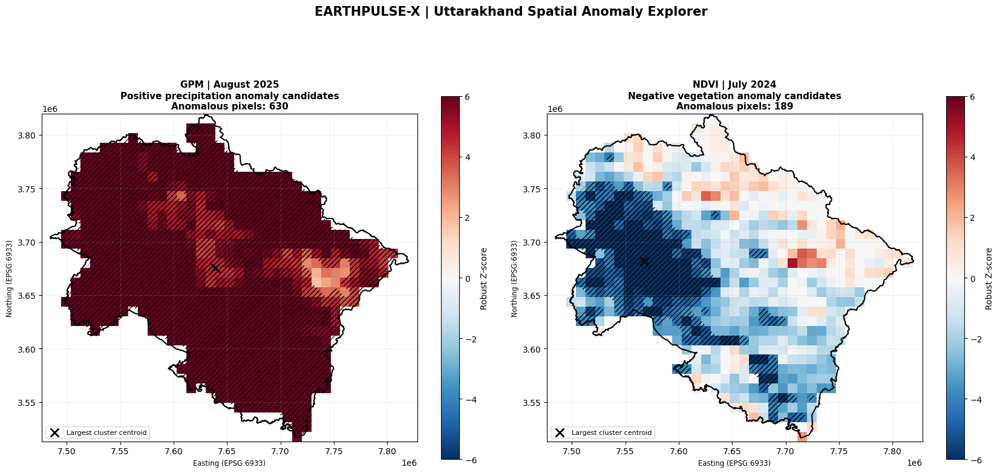


MAPS SAVED: /content/drive/MyDrive/EARTHPULSE_X/reports/earthpulse_x_spatial_anomaly_maps.png

SPATIAL ANOMALY MAPPING COMPLETE


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.ndimage import label

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

ARRAY_FILE = META / "earthpulse_x_pixel_anomaly_arrays.npz"
CLUSTER_FILE = META / "earthpulse_x_spatial_anomaly_clusters.csv"
BOUNDARY_FILE = ROOT / "data/raw/boundaries/uttarakhand_study_area.geojson"

for path in [ARRAY_FILE, CLUSTER_FILE, BOUNDARY_FILE]:
    if not path.exists():
        raise FileNotFoundError(path)

# Load canonical Uttarakhand boundary
boundary = gpd.read_file(BOUNDARY_FILE)

if boundary.crs is None:
    raise ValueError("Boundary CRS is missing.")

boundary = boundary.to_crs("EPSG:6933")

# Load detected clusters
clusters = pd.read_csv(CLUSTER_FILE)
clusters["month"] = clusters["month"].astype(str)

# Two events selected from actual detected results
events = [
    {
        "variable": "GPM",
        "month": "2025-08",
        "direction": "POSITIVE",
        "title": "GPM | August 2025",
        "description": "Positive precipitation anomaly candidates"
    },
    {
        "variable": "NDVI",
        "month": "2024-07",
        "direction": "NEGATIVE",
        "title": "NDVI | July 2024",
        "description": "Negative vegetation anomaly candidates"
    }
]

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

with np.load(ARRAY_FILE, allow_pickle=True) as data:

    months = pd.to_datetime(data["months"].astype(str))
    x = data["x"]
    y = data["y"]
    study_mask = data["study_mask"].astype(bool)

    for ax, event in zip(axes, events):

        variable = event["variable"]
        month = event["month"]

        matching_indices = np.where(
            months.strftime("%Y-%m") == month
        )[0]

        if len(matching_indices) != 1:
            raise ValueError(f"Expected exactly one month: {month}")

        idx = matching_indices[0]

        z = data[f"{variable}_robust_z"][idx]

        if event["direction"] == "POSITIVE":
            anomaly_mask = (z >= 3.5) & np.isfinite(z) & study_mask
        else:
            anomaly_mask = (z <= -3.5) & np.isfinite(z) & study_mask

        # Background: pixel-level robust z-score
        image = ax.pcolormesh(
            x, y, np.ma.masked_where(~study_mask, z),
            shading="nearest",
            cmap="RdBu_r",
            vmin=-6,
            vmax=6
        )

        # Highlight anomaly pixels
        if anomaly_mask.any():
            ax.contourf(
                x, y, anomaly_mask.astype(float),
                levels=[0.5, 1.5],
                colors="none",
                hatches=["////"]
            )

        # Study-area boundary
        boundary.boundary.plot(
            ax=ax,
            color="black",
            linewidth=1.5
        )

        event_clusters = clusters[
            (clusters["variable"] == variable)
            & (clusters["month"] == month)
            & (clusters["direction"] == event["direction"])
        ]

        largest = (
            event_clusters.sort_values(
                "pixel_count", ascending=False
            ).iloc[0]
            if len(event_clusters) else None
        )

        if largest is not None:
            ax.scatter(
                largest["centroid_x"],
                largest["centroid_y"],
                marker="x",
                color="black",
                s=100,
                linewidths=2,
                label="Largest cluster centroid"
            )
            ax.legend(loc="lower left", fontsize=8)

        valid_anomalies = int(anomaly_mask.sum())

        ax.set_title(
            f"{event['title']}\n"
            f"{event['description']}\n"
            f"Anomalous pixels: {valid_anomalies}",
            fontsize=11,
            fontweight="bold"
        )

        ax.set_xlabel("Easting (EPSG:6933)")
        ax.set_ylabel("Northing (EPSG:6933)")
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)

        fig.colorbar(
            image,
            ax=ax,
            shrink=0.72,
            label="Robust Z-score"
        )

plt.suptitle(
    "EARTHPULSE-X | Uttarakhand Spatial Anomaly Explorer",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

output = ROOT / "reports/earthpulse_x_spatial_anomaly_maps.png"
output.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output, dpi=220, bbox_inches="tight")
plt.show()

print("\nMAPS SAVED:", output)
print("\nSPATIAL ANOMALY MAPPING COMPLETE")

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
FILE = ROOT / "data/metadata/earthpulse_x_regional_monthly_timeseries.csv"

df = pd.read_csv(FILE)

print("=" * 70)
print("EARTHPULSE-X | EARTH INTERACTION GRAPH")
print("=" * 70)

print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDate range:")
date_col = next(
    (c for c in df.columns if c.lower() in ["month", "date", "year_month"]),
    None
)

if date_col is None:
    raise ValueError("Could not identify the monthly date column.")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

print(df[date_col].min(), "to", df[date_col].max())

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nRegional time-series input inspection complete.")

EARTHPULSE-X | EARTH INTERACTION GRAPH

Dataset shape: (126, 31)

Columns:
['month', 'year', 'month_number', 'lst_strict_mean', 'lst_strict_valid_pixels', 'lst_strict_coverage_pct', 'lst_relaxed_mean', 'lst_relaxed_valid_pixels', 'lst_relaxed_coverage_pct', 'ndvi_strict_mean', 'ndvi_strict_valid_pixels', 'ndvi_strict_coverage_pct', 'ndvi_relaxed_mean', 'ndvi_relaxed_valid_pixels', 'ndvi_relaxed_coverage_pct', 'smap_am_strict_mean', 'smap_am_strict_valid_pixels', 'smap_am_strict_coverage_pct', 'smap_am_relaxed_mean', 'smap_am_relaxed_valid_pixels', 'smap_am_relaxed_coverage_pct', 'smap_pm_strict_mean', 'smap_pm_strict_valid_pixels', 'smap_pm_strict_coverage_pct', 'smap_pm_relaxed_mean', 'smap_pm_relaxed_valid_pixels', 'smap_pm_relaxed_coverage_pct', 'gpm_monthly_precipitation_mean', 'gpm_monthly_precipitation_valid_pixels', 'gpm_monthly_precipitation_coverage_pct', 'gpm_monthly_precipitation_units']

First 5 rows:


,month,year,month_number,lst_strict_mean,lst_strict_valid_pixels,lst_strict_coverage_pct,lst_relaxed_mean,lst_relaxed_valid_pixels,lst_relaxed_coverage_pct,ndvi_strict_mean,...,smap_pm_strict_mean,smap_pm_strict_valid_pixels,smap_pm_strict_coverage_pct,smap_pm_relaxed_mean,smap_pm_relaxed_valid_pixels,smap_pm_relaxed_coverage_pct,gpm_monthly_precipitation_mean,gpm_monthly_precipitation_valid_pixels,gpm_monthly_precipitation_coverage_pct,gpm_monthly_precipitation_units
0,2015-04,2015,4,292.803040,664,100.0,292.810429,664,100.0,0.573048,...,0.219825,35,4.715115,0.350159,522,79.071826,92.730792,643,97.842255,mm/month
1,2015-05,2015,5,297.411292,664,100.0,297.343460,664,100.0,0.546476,...,0.215256,34,4.559786,0.276838,611,92.133986,23.168694,643,97.842255,mm/month
2,2015-06,2015,6,299.183759,664,100.0,298.387692,664,100.0,0.559045,...,0.252451,32,4.340866,0.304154,652,98.356283,172.492666,643,97.842255,mm/month
3,2015-07,2015,7,296.439579,664,100.0,295.436136,664,100.0,0.685667,...,0.361379,33,4.338706,0.426373,635,95.703894,419.206694,643,97.842255,mm/month
4,2015-08,2015,8,295.640605,664,100.0,294.334771,664,100.0,0.695764,...,0.285521,37,4.827014,0.390295,659,99.294424,310.070977,643,97.842255,mm/month



Date range:
2015-04-01 00:00:00 to 2025-09-01 00:00:00

Missing values:


,missing_count
month,0
year,0
month_number,0
lst_strict_mean,0
lst_strict_valid_pixels,0
lst_strict_coverage_pct,0
lst_relaxed_mean,0
lst_relaxed_valid_pixels,0
lst_relaxed_coverage_pct,0
ndvi_strict_mean,0



Regional time-series input inspection complete.


In [20]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(META / "earthpulse_x_regional_monthly_timeseries.csv")
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

variables = {
    "LST": "lst_relaxed_mean",
    "NDVI": "ndvi_relaxed_mean",
    "SMAP_AM": "smap_am_relaxed_mean",
    "SMAP_PM": "smap_pm_relaxed_mean",
    "GPM": "gpm_monthly_precipitation_mean"
}

# Seasonal anomaly: subtract each calendar month's median
anomalies = pd.DataFrame({"month": df["month"]})

for name, column in variables.items():
    values = pd.to_numeric(df[column], errors="coerce")
    climatology = values.groupby(df["month"].dt.month).transform("median")
    anomalies[name] = values - climatology

# Test all unique variable pairs across lags -3 to +3
# Positive lag: X leads Y. Negative lag: Y leads X.
results = []

names = list(variables.keys())

for i, x_name in enumerate(names):
    for y_name in names[i + 1:]:

        for lag in range(-3, 4):

            x = anomalies[x_name]
            y = anomalies[y_name]

            if lag > 0:
                x = x.iloc[:-lag].reset_index(drop=True)
                y = y.iloc[lag:].reset_index(drop=True)
            elif lag < 0:
                k = abs(lag)
                x = x.iloc[k:].reset_index(drop=True)
                y = y.iloc[:-k].reset_index(drop=True)
            else:
                x = x.reset_index(drop=True)
                y = y.reset_index(drop=True)

            valid = x.notna() & y.notna()
            x_valid = x[valid]
            y_valid = y[valid]

            if len(x_valid) < 80:
                continue

            rho, p_value = spearmanr(x_valid, y_valid)

            results.append({
                "variable_x": x_name,
                "variable_y": y_name,
                "lag_months": lag,
                "lead_interpretation": (
                    f"{x_name} leads {y_name}" if lag > 0
                    else f"{y_name} leads {x_name}" if lag < 0
                    else "Same-month association"
                ),
                "spearman_rho": float(rho),
                "p_value": float(p_value),
                "sample_size": int(len(x_valid))
            })

edges = pd.DataFrame(results)

if edges.empty:
    raise ValueError("No valid pairwise correlations were calculated.")

# Correct for multiple comparisons across all tested pairs and lags
edges["fdr_q_value"] = multipletests(
    edges["p_value"].values,
    method="fdr_bh"
)[1]

edges["fdr_significant_05"] = edges["fdr_q_value"] < 0.05

# Strongest absolute association per variable pair
best_edges = (
    edges.assign(abs_rho=edges["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
    .groupby(["variable_x", "variable_y"], as_index=False)
    .first()
    .drop(columns="abs_rho")
    .sort_values("spearman_rho", key=lambda s: s.abs(), ascending=False)
)

edge_file = META / "earthpulse_x_interaction_edges.csv"
best_file = META / "earthpulse_x_interaction_best_edges.csv"
summary_file = META / "earthpulse_x_interaction_summary.json"

edges.to_csv(edge_file, index=False)
best_edges.to_csv(best_file, index=False)

summary = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "period": "2015-04 to 2025-09",
    "method": "Spearman correlation on month-of-year median anomalies",
    "lag_range_months": [-3, 3],
    "positive_lag_definition": "variable_x leads variable_y",
    "minimum_pairwise_samples": 80,
    "total_tests": len(edges),
    "fdr_significant_tests": int(edges["fdr_significant_05"].sum()),
    "warning": "Exploratory associations; autocorrelation and temporal dependence may affect p-values. No causal interpretation."
}

summary_file.write_text(json.dumps(summary, indent=2))

print("=" * 70)
print("EARTHPULSE-X | LAGGED INTERACTION ANALYSIS")
print("=" * 70)

print("Tests performed:", len(edges))
print("FDR-significant tests:", int(edges["fdr_significant_05"].sum()))

print("\nSTRONGEST RELATIONSHIP PER VARIABLE PAIR")
display(
    best_edges[[
        "variable_x", "variable_y", "lag_months",
        "lead_interpretation", "spearman_rho",
        "p_value", "fdr_q_value", "fdr_significant_05",
        "sample_size"
    ]].round(4)
)

print("\nTOP 10 ABSOLUTE CORRELATIONS")
display(
    edges.assign(abs_rho=edges["spearman_rho"].abs())
    .nlargest(10, "abs_rho")
    .round(4)
)

print("\nSAVED:")
print(edge_file)
print(best_file)
print(summary_file)

print("\nINTERACTION ANALYSIS COMPLETE")

EARTHPULSE-X | LAGGED INTERACTION ANALYSIS
Tests performed: 70
FDR-significant tests: 20

STRONGEST RELATIONSHIP PER VARIABLE PAIR


,variable_x,variable_y,lag_months,lead_interpretation,spearman_rho,p_value,fdr_q_value,fdr_significant_05,sample_size
8,SMAP_AM,SMAP_PM,0,Same-month association,0.9385,0.0000,0.0000,True,126
7,SMAP_AM,GPM,0,Same-month association,0.5938,0.0000,0.0000,True,126
2,LST,SMAP_AM,0,Same-month association,-0.5915,0.0000,0.0000,True,126
9,SMAP_PM,GPM,0,Same-month association,0.5281,0.0000,0.0000,True,126
0,LST,GPM,0,Same-month association,-0.5208,0.0000,0.0000,True,126
3,LST,SMAP_PM,0,Same-month association,-0.4589,0.0000,0.0000,True,126
1,LST,NDVI,1,LST leads NDVI,-0.3896,0.0000,0.0001,True,125
5,NDVI,SMAP_AM,-1,SMAP_AM leads NDVI,0.2031,0.0231,0.0734,False,125
4,NDVI,GPM,-1,GPM leads NDVI,0.1878,0.0360,0.1095,False,125
6,NDVI,SMAP_PM,2,NDVI leads SMAP_PM,-0.1602,0.0756,0.1959,False,124



TOP 10 ABSOLUTE CORRELATIONS


,variable_x,variable_y,lag_months,lead_interpretation,spearman_rho,p_value,sample_size,fdr_q_value,fdr_significant_05,abs_rho
52,SMAP_AM,SMAP_PM,0,Same-month association,0.9385,0.0,126,0.0000,True,0.9385
59,SMAP_AM,GPM,0,Same-month association,0.5938,0.0,126,0.0000,True,0.5938
10,LST,SMAP_AM,0,Same-month association,-0.5915,0.0,126,0.0000,True,0.5915
66,SMAP_PM,GPM,0,Same-month association,0.5281,0.0,126,0.0000,True,0.5281
24,LST,GPM,0,Same-month association,-0.5208,0.0,126,0.0000,True,0.5208
17,LST,SMAP_PM,0,Same-month association,-0.4589,0.0,126,0.0000,True,0.4589
53,SMAP_AM,SMAP_PM,1,SMAP_AM leads SMAP_PM,0.4569,0.0,125,0.0000,True,0.4569
51,SMAP_AM,SMAP_PM,-1,SMAP_PM leads SMAP_AM,0.4229,0.0,125,0.0000,True,0.4229
4,LST,NDVI,1,LST leads NDVI,-0.3896,0.0,125,0.0001,True,0.3896
23,LST,GPM,-1,GPM leads LST,-0.3635,0.0,125,0.0002,True,0.3635



SAVED:
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_edges.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_best_edges.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_summary.json

INTERACTION ANALYSIS COMPLETE


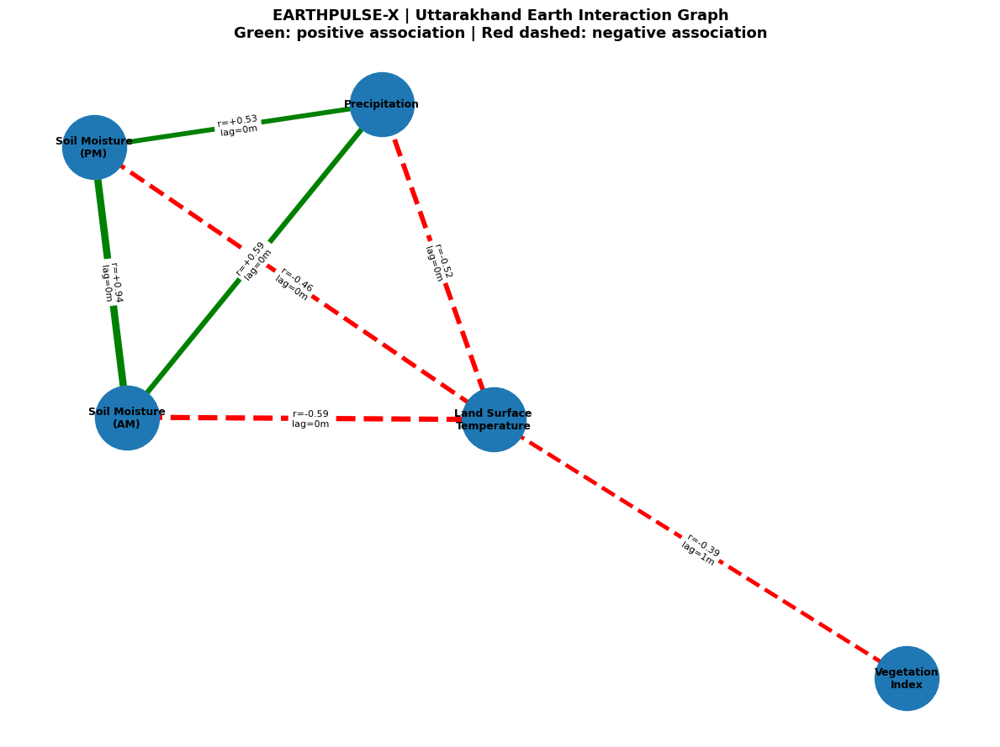

NODES: 5
SELECTED SIGNIFICANT EDGES: 7

SELECTED EDGES:


,variable_x,variable_y,lag_months,spearman_rho,fdr_q_value,lead_interpretation
0,LST,GPM,0,-0.5208,0.0000,Same-month association
1,LST,NDVI,1,-0.3896,0.0001,LST leads NDVI
2,LST,SMAP_AM,0,-0.5915,0.0000,Same-month association
3,LST,SMAP_PM,0,-0.4589,0.0000,Same-month association
4,SMAP_AM,GPM,0,0.5938,0.0000,Same-month association
5,SMAP_AM,SMAP_PM,0,0.9385,0.0000,Same-month association
6,SMAP_PM,GPM,0,0.5281,0.0000,Same-month association



SAVED:
/content/drive/MyDrive/EARTHPULSE_X/reports/earthpulse_x_interaction_graph.png
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_graph.graphml
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_graph_selected_edges.csv
/content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_interaction_graph_summary.json

EARTH INTERACTION GRAPH COMPLETE


In [21]:
from pathlib import Path
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REPORTS = ROOT / "reports"

edges = pd.read_csv(META / "earthpulse_x_interaction_edges.csv")

# Retain significant tests, then select strongest lag per pair
significant = edges[edges["fdr_significant_05"] == True].copy()

selected = (
    significant.assign(abs_rho=significant["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
    .groupby(["variable_x", "variable_y"], as_index=False)
    .first()
)

G = nx.Graph()

node_labels = {
    "LST": "Land Surface\nTemperature",
    "NDVI": "Vegetation\nIndex",
    "SMAP_AM": "Soil Moisture\n(AM)",
    "SMAP_PM": "Soil Moisture\n(PM)",
    "GPM": "Precipitation"
}

for node, label in node_labels.items():
    G.add_node(node, label=label)

for _, row in selected.iterrows():
    G.add_edge(
        row["variable_x"],
        row["variable_y"],
        correlation=float(row["spearman_rho"]),
        lag=int(row["lag_months"]),
        q_value=float(row["fdr_q_value"]),
        sample_size=int(row["sample_size"]),
        interpretation=row["lead_interpretation"]
    )

# Save machine-readable graph and edge list
graphml_path = META / "earthpulse_x_interaction_graph.graphml"
edge_path = META / "earthpulse_x_interaction_graph_selected_edges.csv"
image_path = REPORTS / "earthpulse_x_interaction_graph.png"
json_path = META / "earthpulse_x_interaction_graph_summary.json"

nx.write_graphml(G, graphml_path)
selected.to_csv(edge_path, index=False)

# Visualize
fig, ax = plt.subplots(figsize=(12, 9))

positions = nx.spring_layout(G, seed=42, k=1.5)

positive_edges = [
    (u, v) for u, v, d in G.edges(data=True)
    if d["correlation"] > 0
]
negative_edges = [
    (u, v) for u, v, d in G.edges(data=True)
    if d["correlation"] < 0
]

widths = [
    1.5 + abs(G[u][v]["correlation"]) * 5
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G, positions, node_size=3000, ax=ax
)

nx.draw_networkx_labels(
    G, positions, labels=node_labels,
    font_size=9, font_weight="bold", ax=ax
)

nx.draw_networkx_edges(
    G, positions,
    edgelist=positive_edges,
    width=[
        1.5 + abs(G[u][v]["correlation"]) * 5
        for u, v in positive_edges
    ],
    edge_color="green",
    ax=ax
)

nx.draw_networkx_edges(
    G, positions,
    edgelist=negative_edges,
    width=[
        1.5 + abs(G[u][v]["correlation"]) * 5
        for u, v in negative_edges
    ],
    edge_color="red",
    style="dashed",
    ax=ax
)

edge_labels = {
    (u, v): (
        f"r={d['correlation']:+.2f}\n"
        f"lag={d['lag']}m"
    )
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G, positions, edge_labels=edge_labels,
    font_size=8, ax=ax
)

ax.set_title(
    "EARTHPULSE-X | Uttarakhand Earth Interaction Graph\n"
    "Green: positive association | Red dashed: negative association",
    fontsize=13,
    fontweight="bold"
)

ax.axis("off")
plt.tight_layout()

REPORTS.mkdir(parents=True, exist_ok=True)
plt.savefig(image_path, dpi=220, bbox_inches="tight")
plt.show()

summary = {
    "region": "Uttarakhand, India",
    "nodes": G.number_of_nodes(),
    "selected_significant_edges": G.number_of_edges(),
    "selection": "Strongest absolute FDR-significant lag per variable pair",
    "positive_edges": len(positive_edges),
    "negative_edges": len(negative_edges),
    "caveat": "Exploratory associations; p-values do not account for temporal autocorrelation. Edges do not imply causation."
}

json_path.write_text(json.dumps(summary, indent=2))

print("NODES:", G.number_of_nodes())
print("SELECTED SIGNIFICANT EDGES:", G.number_of_edges())
print("\nSELECTED EDGES:")
display(
    selected[[
        "variable_x", "variable_y", "lag_months",
        "spearman_rho", "fdr_q_value",
        "lead_interpretation"
    ]].round(4)
)

print("\nSAVED:")
print(image_path)
print(graphml_path)
print(edge_path)
print(json_path)

print("\nEARTH INTERACTION GRAPH COMPLETE")

In [22]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import json

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"

df = pd.read_csv(META / "earthpulse_x_regional_monthly_timeseries.csv")
df["month"] = pd.to_datetime(df["month"])

columns = {
    "LST": "lst_relaxed_mean",
    "NDVI": "ndvi_relaxed_mean",
    "SMAP_AM": "smap_am_relaxed_mean",
    "SMAP_PM": "smap_pm_relaxed_mean",
    "GPM": "gpm_monthly_precipitation_mean"
}

anomaly = pd.DataFrame({"month": df["month"]})

for name, col in columns.items():
    values = pd.to_numeric(df[col], errors="coerce")
    anomaly[name] = values - values.groupby(
        df["month"].dt.month
    ).transform("median")

tests = [
    ("GPM", "SMAP_AM", 0, "Positive", "Rainfall–soil moisture"),
    ("GPM", "SMAP_PM", 0, "Positive", "Rainfall–soil moisture"),
    ("GPM", "SMAP_AM", 1, "Positive", "Rainfall leads soil moisture"),
    ("GPM", "SMAP_PM", 1, "Positive", "Rainfall leads soil moisture"),
    ("SMAP_AM", "LST", 0, "Negative", "Soil moisture–temperature"),
    ("SMAP_PM", "LST", 0, "Negative", "Soil moisture–temperature"),
    ("SMAP_AM", "NDVI", 1, "Positive", "Soil moisture leads vegetation"),
    ("SMAP_PM", "NDVI", 1, "Positive", "Soil moisture leads vegetation"),
    ("GPM", "NDVI", 1, "Positive", "Rainfall leads vegetation"),
    ("GPM", "NDVI", 2, "Positive", "Rainfall leads vegetation")
]

results = []

for x_name, y_name, lag, expected, hypothesis in tests:

    x = anomaly[x_name]
    y = anomaly[y_name]

    if lag > 0:
        x = x.iloc[:-lag].reset_index(drop=True)
        y = y.iloc[lag:].reset_index(drop=True)

    valid = x.notna() & y.notna()
    rho, p = spearmanr(x[valid], y[valid])

    expected_sign = 1 if expected == "Positive" else -1

    results.append({
        "hypothesis": hypothesis,
        "variable_x": x_name,
        "variable_y": y_name,
        "lag_months": lag,
        "expected_direction": expected,
        "observed_rho": float(rho),
        "p_value": float(p),
        "sample_size": int(valid.sum()),
        "direction_consistent": bool(rho * expected_sign > 0)
    })

result_df = pd.DataFrame(results)

output = META / "earthpulse_x_physics_consistency_checks.csv"
summary_path = META / "earthpulse_x_physics_consistency_summary.json"

result_df.to_csv(output, index=False)

summary = {
    "region": "Uttarakhand, India",
    "method": "Exploratory seasonal-anomaly Spearman checks",
    "tests": len(result_df),
    "direction_consistent": int(result_df["direction_consistent"].sum()),
    "direction_inconsistent": int((~result_df["direction_consistent"]).sum()),
    "interpretation": "Directional consistency only; not proof of physical causation."
}

summary_path.write_text(json.dumps(summary, indent=2))

display(result_df.round(4))

print("\nDirectionally consistent:",
      summary["direction_consistent"], "/", summary["tests"])
print("\nSaved:", output)
print("Saved:", summary_path)
print("\nPHYSICS CONSISTENCY CHECK COMPLETE")

,hypothesis,variable_x,variable_y,lag_months,expected_direction,observed_rho,p_value,sample_size,direction_consistent
0,Rainfall–soil moisture,GPM,SMAP_AM,0,Positive,0.5938,0.0000,126,True
1,Rainfall–soil moisture,GPM,SMAP_PM,0,Positive,0.5281,0.0000,126,True
2,Rainfall leads soil moisture,GPM,SMAP_AM,1,Positive,0.3269,0.0002,125,True
3,Rainfall leads soil moisture,GPM,SMAP_PM,1,Positive,0.2541,0.0042,125,True
4,Soil moisture–temperature,SMAP_AM,LST,0,Negative,-0.5915,0.0000,126,True
5,Soil moisture–temperature,SMAP_PM,LST,0,Negative,-0.4589,0.0000,126,True
6,Soil moisture leads vegetation,SMAP_AM,NDVI,1,Positive,0.2031,0.0231,125,True
7,Soil moisture leads vegetation,SMAP_PM,NDVI,1,Positive,0.1121,0.2132,125,True
8,Rainfall leads vegetation,GPM,NDVI,1,Positive,0.1878,0.0360,125,True
9,Rainfall leads vegetation,GPM,NDVI,2,Positive,0.1660,0.0654,124,True



Directionally consistent: 10 / 10

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_physics_consistency_checks.csv
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/earthpulse_x_physics_consistency_summary.json

PHYSICS CONSISTENCY CHECK COMPLETE


In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
REPORTS = ROOT / "experiments/results"

REPORTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(META / "earthpulse_x_regional_monthly_timeseries.csv")
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

columns = {
    "LST": "lst_relaxed_mean",
    "NDVI": "ndvi_relaxed_mean",
    "SMAP_AM": "smap_am_relaxed_mean",
    "SMAP_PM": "smap_pm_relaxed_mean",
    "GPM": "gpm_monthly_precipitation_mean"
}

# Calculate month-of-year median seasonal anomalies
anomaly = pd.DataFrame({"month": df["month"]})

for name, col in columns.items():
    values = pd.to_numeric(df[col], errors="coerce")
    anomaly[name] = values - values.groupby(
        df["month"].dt.month
    ).transform("median")

# Predict current-month NDVI using previous-month observations
feature_names = ["LST", "NDVI", "SMAP_AM", "SMAP_PM", "GPM"]

data = pd.DataFrame({
    f"{name}_previous_month": anomaly[name].shift(1)
    for name in feature_names
})

data["target_NDVI_anomaly"] = anomaly["NDVI"]
data["persistence_prediction"] = anomaly["NDVI"].shift(1)
data["month"] = anomaly["month"]

data = data.dropna().reset_index(drop=True)

X = data[[f"{name}_previous_month" for name in feature_names]]
y = data["target_NDVI_anomaly"]

# Chronological split: first 80% train, final 20% test
split = int(len(data) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=4,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=150,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=2
    )
}

predictions = {}
metrics = []

# Persistence baseline
predictions["Persistence"] = data["persistence_prediction"].iloc[split:].to_numpy()

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

for name, pred in predictions.items():
    metrics.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

metrics_df = pd.DataFrame(metrics).sort_values("RMSE")

prediction_df = pd.DataFrame({
    "month": data["month"].iloc[split:].dt.strftime("%Y-%m"),
    "actual_NDVI_anomaly": y_test.to_numpy()
})

for name, pred in predictions.items():
    prediction_df[f"{name}_prediction"] = pred

metrics_file = REPORTS / "earthpulse_x_ndvi_ml_model_comparison.csv"
predictions_file = REPORTS / "earthpulse_x_ndvi_ml_test_predictions.csv"
summary_file = REPORTS / "earthpulse_x_ndvi_ml_experiment_summary.json"

metrics_df.to_csv(metrics_file, index=False)
prediction_df.to_csv(predictions_file, index=False)

summary = {
    "experiment": "Next-month NDVI anomaly prediction",
    "region": "Uttarakhand, India",
    "features": feature_names,
    "feature_timing": "Previous month only",
    "target": "Current-month NDVI seasonal anomaly",
    "total_samples": len(data),
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "split": "Chronological 80/20",
    "best_model_by_test_RMSE": str(metrics_df.iloc[0]["model"]),
    "metrics": metrics_df.round(6).to_dict(orient="records"),
    "warning": "Single chronological holdout; small dataset. Test performance is exploratory, not proof of generalization."
}

summary_file.write_text(json.dumps(summary, indent=2))

print("=" * 70)
print("EARTHPULSE-X | NDVI ANOMALY PREDICTION")
print("=" * 70)
print("Total samples:", len(data))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test period:", prediction_df["month"].iloc[0], "to", prediction_df["month"].iloc[-1])

print("\nMODEL COMPARISON")
display(metrics_df.round(4))

print("\nTEST PREDICTIONS")
display(prediction_df.head(10).round(4))

print("\nSAVED:")
print(metrics_file)
print(predictions_file)
print(summary_file)

print("\nML EXPERIMENT COMPLETE")

EARTHPULSE-X | NDVI ANOMALY PREDICTION
Total samples: 125
Training samples: 100
Testing samples: 25
Test period: 2023-09 to 2025-09

MODEL COMPARISON


,model,MAE,RMSE,R2
2,Random Forest,0.0134,0.0184,0.1753
1,Ridge,0.0156,0.0196,0.0670
3,XGBoost,0.0138,0.0197,0.0541
0,Persistence,0.0137,0.0210,-0.0736



TEST PREDICTIONS


,month,actual_NDVI_anomaly,Persistence_prediction,Ridge_prediction,Random Forest_prediction,XGBoost_prediction
100,2023-09,0.0083,0.0024,-0.0014,0.0047,0.0051
101,2023-10,0.0121,0.0083,-0.0002,0.0113,0.0130
102,2023-11,0.0175,0.0121,0.0037,0.0078,0.0077
103,2023-12,0.0205,0.0175,0.0051,0.0105,0.0120
104,2024-01,0.0280,0.0205,0.0055,0.0124,0.0113
105,2024-02,0.0169,0.0280,0.0034,0.0075,0.0070
106,2024-03,0.0081,0.0169,0.0100,0.0096,0.0095
107,2024-04,0.0000,0.0081,0.0053,0.0052,0.0043
108,2024-05,0.0000,0.0000,-0.0025,-0.0014,-0.0018
109,2024-06,-0.0186,0.0000,-0.0054,-0.0047,-0.0070



SAVED:
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_model_comparison.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_test_predictions.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_experiment_summary.json

ML EXPERIMENT COMPLETE


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "experiments/results"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(META / "earthpulse_x_regional_monthly_timeseries.csv")
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)

columns = {
    "LST": "lst_relaxed_mean",
    "NDVI": "ndvi_relaxed_mean",
    "SMAP_AM": "smap_am_relaxed_mean",
    "SMAP_PM": "smap_pm_relaxed_mean",
    "GPM": "gpm_monthly_precipitation_mean"
}

# Determine chronological test boundary before fitting climatology
split = int((len(df) - 1) * 0.80)
test_start = df["month"].iloc[split + 1]

# Fit month-of-year climatology on training period only
train_reference = df[df["month"] < test_start]

anomaly = pd.DataFrame({"month": df["month"]})

for name, col in columns.items():
    values = pd.to_numeric(df[col], errors="coerce")
    train_values = pd.to_numeric(
        train_reference[col], errors="coerce"
    )

    month_medians = train_values.groupby(
        train_reference["month"].dt.month
    ).median()

    anomaly[name] = values - df["month"].dt.month.map(month_medians)

# Previous-month predictors, current-month NDVI target
data = pd.DataFrame({"month": anomaly["month"]})

for name in columns:
    data[f"{name}_previous_month"] = anomaly[name].shift(1)

data["target"] = anomaly["NDVI"]
data["persistence"] = anomaly["NDVI"].shift(1)

data = data.dropna().reset_index(drop=True)

split = int(len(data) * 0.80)

X_cols = [f"{name}_previous_month" for name in columns]
X_train, X_test = data.loc[:split-1, X_cols], data.loc[split:, X_cols]
y_train, y_test = data.loc[:split-1, "target"], data.loc[split:, "target"]

models = {
    "Ridge": make_pipeline(
        StandardScaler(), Ridge(alpha=10.0)
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=3,
        min_samples_leaf=4, max_features=0.8,
        random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=150, max_depth=2,
        learning_rate=0.03, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=5,
        objective="reg:squarederror",
        random_state=42, n_jobs=2
    )
}

predictions = {
    "Persistence": data.loc[split:, "persistence"].to_numpy()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

results = []

for name, pred in predictions.items():
    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

metrics = pd.DataFrame(results).sort_values("RMSE")

pred_df = pd.DataFrame({
    "month": data.loc[split:, "month"].dt.strftime("%Y-%m"),
    "actual_NDVI_anomaly": y_test.to_numpy()
})

for name, pred in predictions.items():
    pred_df[f"{name}_prediction"] = pred

metrics_path = OUT / "earthpulse_x_ndvi_ml_leakage_safe_comparison.csv"
pred_path = OUT / "earthpulse_x_ndvi_ml_leakage_safe_predictions.csv"
summary_path = OUT / "earthpulse_x_ndvi_ml_leakage_safe_summary.json"

metrics.to_csv(metrics_path, index=False)
pred_df.to_csv(pred_path, index=False)

best = metrics.iloc[0]
persistence_rmse = float(
    metrics.loc[metrics["model"] == "Persistence", "RMSE"].iloc[0]
)

summary = {
    "experiment": "Leakage-safe next-month NDVI anomaly prediction",
    "training_climatology_end": str(test_start.date()),
    "test_start": str(pd.to_datetime(pred_df["month"].iloc[0]).date()),
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "best_model": str(best["model"]),
    "best_test_RMSE": float(best["RMSE"]),
    "persistence_RMSE": persistence_rmse,
    "rmse_improvement_vs_persistence_pct": float(
        (persistence_rmse - best["RMSE"]) / persistence_rmse * 100
    ),
    "caveat": "Single chronological holdout with training-only seasonal climatology; small test set."
}

summary_path.write_text(json.dumps(summary, indent=2))

print("=" * 65)
print("LEAKAGE-SAFE NDVI PREDICTION")
print("=" * 65)
print("Training climatology fitted before:", test_start.date())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nMODEL COMPARISON")
display(metrics.round(4))
print("\nTEST PREDICTIONS")
display(pred_df.head(10).round(4))
print("\nBest model:", summary["best_model"])
print("RMSE improvement vs persistence:",
      round(summary["rmse_improvement_vs_persistence_pct"], 2), "%")
print("\nSaved:", metrics_path, pred_path, summary_path)

LEAKAGE-SAFE NDVI PREDICTION
Training climatology fitted before: 2023-09-01
Training samples: 100
Testing samples: 25

MODEL COMPARISON


,model,MAE,RMSE,R2
2,Random Forest,0.0164,0.0199,0.0990
1,Ridge,0.0182,0.0215,-0.0483
0,Persistence,0.0158,0.0223,-0.1269
3,XGBoost,0.0183,0.0229,-0.1852



TEST PREDICTIONS


,month,actual_NDVI_anomaly,Persistence_prediction,Ridge_prediction,Random Forest_prediction,XGBoost_prediction
100,2023-09,0.0125,0.0024,0.0013,0.0033,0.0054
101,2023-10,0.0231,0.0125,0.0048,0.0134,0.0145
102,2023-11,0.0246,0.0231,0.0104,0.0113,0.0109
103,2023-12,0.0264,0.0246,0.0086,0.0142,0.0158
104,2024-01,0.0320,0.0264,0.0088,0.0145,0.0142
105,2024-02,0.0176,0.0320,0.0045,0.0093,0.0072
106,2024-03,0.0192,0.0176,0.0128,0.0115,0.0111
107,2024-04,0.0023,0.0192,0.0109,0.0096,0.0073
108,2024-05,0.0060,0.0023,-0.0008,-0.0015,-0.0049
109,2024-06,-0.0186,0.0060,-0.0012,0.0000,-0.0037



Best model: Random Forest
RMSE improvement vs persistence: 10.59 %

Saved: /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_leakage_safe_comparison.csv /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_leakage_safe_predictions.csv /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_ndvi_ml_leakage_safe_summary.json


In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

from sklearn.ensemble import IsolationForest

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
OUT = ROOT / "experiments/results"
OUT.mkdir(parents=True, exist_ok=True)

ARRAY_FILE = META / "earthpulse_x_pixel_anomaly_arrays.npz"

variables = ["LST", "NDVI", "SMAP_AM", "SMAP_PM", "GPM"]

with np.load(ARRAY_FILE, allow_pickle=True) as data:

    months = pd.to_datetime(data["months"].astype(str))
    x_coords = data["x"]
    y_coords = data["y"]
    study_mask = data["study_mask"].astype(bool)

    # Exclude 2015 because its seasonal climatology has limited history
    time_indices = np.where(months.year >= 2016)[0]

    feature_cubes = [
        data[f"{v}_robust_z"][time_indices]
        for v in variables
    ]

    # Shape: time x rows x columns x variables
    feature_cube = np.stack(feature_cubes, axis=-1)

    n_time, n_rows, n_cols, n_features = feature_cube.shape

    valid_mask = (
        np.isfinite(feature_cube).all(axis=-1)
        & study_mask[None, :, :]
    )

    valid_positions = np.argwhere(valid_mask)
    X = feature_cube[valid_mask]

    print("Analysis months:", len(time_indices))
    print("Study-area cells:", int(study_mask.sum()))
    print("Complete pixel-month samples:", len(X))
    print("Features:", variables)

    if len(X) < 100:
        raise ValueError("Insufficient complete pixel-month samples.")

    # Two contamination settings for sensitivity comparison
    predictions = {}

    for contamination in [0.02, 0.05]:

        model = IsolationForest(
            n_estimators=250,
            max_samples="auto",
            contamination=contamination,
            random_state=42,
            n_jobs=-1
        )

        labels = model.fit_predict(X)
        scores = model.decision_function(X)

        predictions[contamination] = {
            "labels": labels,
            "scores": scores
        }

    # Construct spatial-temporal event table
    rows = []

    for i, (t, r, c) in enumerate(valid_positions):

        record = {
            "month": months[time_indices[t]].strftime("%Y-%m"),
            "row": int(r),
            "column": int(c),
            "x_epsg6933": float(x_coords[c]),
            "y_epsg6933": float(y_coords[r])
        }

        for j, variable in enumerate(variables):
            record[f"{variable}_robust_z"] = float(X[i, j])

        for contamination in [0.02, 0.05]:
            suffix = str(int(contamination * 100))
            record[f"if_anomaly_{suffix}pct"] = bool(
                predictions[contamination]["labels"][i] == -1
            )
            record[f"if_score_{suffix}pct"] = float(
                predictions[contamination]["scores"][i]
            )

        rows.append(record)

events = pd.DataFrame(rows)

# Summary by contamination threshold
summary_rows = []

for contamination in [0.02, 0.05]:

    suffix = str(int(contamination * 100))
    flag = events[f"if_anomaly_{suffix}pct"]

    summary_rows.append({
        "contamination_pct": int(contamination * 100),
        "complete_samples": len(events),
        "detected_anomalies": int(flag.sum()),
        "detected_percentage": float(flag.mean() * 100),
        "unique_months_with_anomalies": int(
            events.loc[flag, "month"].nunique()
        ),
        "unique_spatial_cells": int(
            events.loc[flag, ["row", "column"]]
            .drop_duplicates().shape[0]
        )
    })

summary_df = pd.DataFrame(summary_rows)

# Compare anomaly flags between thresholds
overlap = int(
    (
        events["if_anomaly_2pct"]
        & events["if_anomaly_5pct"]
    ).sum()
)

events_path = OUT / "earthpulse_x_spatial_isolation_forest_events.csv"
summary_path = OUT / "earthpulse_x_spatial_isolation_forest_summary.csv"
json_path = OUT / "earthpulse_x_spatial_isolation_forest_report.json"

events.to_csv(events_path, index=False)
summary_df.to_csv(summary_path, index=False)

report = {
    "project": "EARTHPULSE-X",
    "region": "Uttarakhand, India",
    "period": "2016-01 to 2025-09",
    "method": "Multivariate Isolation Forest",
    "features": variables,
    "complete_pixel_month_samples": len(events),
    "contamination_sensitivity": summary_rows,
    "overlap_between_2pct_and_5pct": overlap,
    "interpretation": (
        "Unusual multivariate pixel-month combinations. "
        "These are exploratory candidates, not confirmed hazards."
    ),
    "limitations": [
        "Spatial and temporal samples are dependent.",
        "Isolation Forest contamination is a modelling setting, not an observed event rate.",
        "Complete-case filtering excludes pixel-months with missing variables.",
        "Coordinates are in EPSG:6933, not latitude/longitude."
    ]
}

json_path.write_text(json.dumps(report, indent=2))

print("\n" + "=" * 70)
print("EARTHPULSE-X | SPATIAL MULTIVARIATE ISOLATION FOREST")
print("=" * 70)

display(summary_df.round(3))

print("\nOverlap between 2% and 5% anomaly sets:", overlap)

print("\nTOP 15 MOST UNUSUAL PIXEL-MONTHS (5% setting)")
display(
    events[events["if_anomaly_5pct"]]
    .nsmallest(15, "if_score_5pct")
    .round(3)
)

print("\nSAVED:")
print(events_path)
print(summary_path)
print(json_path)

print("\nSPATIAL ISOLATION FOREST COMPLETE")

Analysis months: 117
Study-area cells: 664
Complete pixel-month samples: 50449
Features: ['LST', 'NDVI', 'SMAP_AM', 'SMAP_PM', 'GPM']

EARTHPULSE-X | SPATIAL MULTIVARIATE ISOLATION FOREST


,contamination_pct,complete_samples,detected_anomalies,detected_percentage,unique_months_with_anomalies,unique_spatial_cells
0,2,50449,1009,2.000,44,365
1,5,50449,2523,5.001,63,432



Overlap between 2% and 5% anomaly sets: 1009

TOP 15 MOST UNUSUAL PIXEL-MONTHS (5% setting)


,month,row,column,x_epsg6933,y_epsg6933,LST_robust_z,NDVI_robust_z,SMAP_AM_robust_z,SMAP_PM_robust_z,GPM_robust_z,if_anomaly_2pct,if_score_2pct,if_anomaly_5pct,if_score_5pct
28483,2021-06,30,26,7715384.78,3544671.189,-4.449,2.720,2.076,4.798,5.944,True,-0.106,True,-0.142
28481,2021-06,30,24,7697368.68,3544671.189,-4.146,1.804,4.247,4.966,4.592,True,-0.106,True,-0.141
28472,2021-06,29,23,7688360.63,3553679.239,-3.338,3.499,4.165,3.983,4.228,True,-0.105,True,-0.141
28482,2021-06,30,25,7706376.73,3544671.189,-4.194,2.544,3.046,4.450,5.146,True,-0.105,True,-0.141
28473,2021-06,29,24,7697368.68,3553679.239,-3.497,3.941,2.694,4.560,5.180,True,-0.102,True,-0.137
28489,2021-06,33,26,7715384.78,3517647.039,-2.831,5.478,3.570,4.267,4.498,True,-0.100,True,-0.136
28476,2021-06,29,27,7724392.83,3553679.239,-2.589,4.083,4.361,4.684,4.497,True,-0.100,True,-0.136
49857,2025-08,21,4,7517207.68,3625743.639,-15.946,0.000,3.933,2.195,8.979,True,-0.098,True,-0.134
28475,2021-06,29,26,7715384.78,3553679.239,-2.779,4.180,3.838,3.782,5.670,True,-0.095,True,-0.131
28485,2021-06,31,25,7706376.73,3535663.139,-3.732,1.767,3.709,4.522,4.831,True,-0.094,True,-0.129



SAVED:
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_spatial_isolation_forest_events.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_spatial_isolation_forest_summary.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_spatial_isolation_forest_report.json

SPATIAL ISOLATION FOREST COMPLETE


In [26]:
import torch
import tensorflow as tf
import numpy as np

print("=" * 65)
print("EARTHPULSE-X | DEEP LEARNING ENVIRONMENT")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

print("PyTorch CUDA:", torch.cuda.is_available())
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

print("\nCPU threads:", torch.get_num_threads())
print("\nDeep-learning environment check complete.")

EARTHPULSE-X | DEEP LEARNING ENVIRONMENT
PyTorch: 2.14.1+cpu
TensorFlow: 2.21.0
NumPy: 2.4.6
PyTorch CUDA: False
TensorFlow GPUs: []

CPU threads: 1

Deep-learning environment check complete.


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import json

# Same 3-month sequences for both models
# Flatten LSTM sequences into tabular features for Random Forest

X_train_rf = X_train.reshape(len(X_train), -1)
X_test_rf = X_test.reshape(len(X_test), -1)

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=4,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

rf_predictions = rf_model.predict(X_test_rf)

predictions = {
    "Persistence": persistence_test,
    "Random Forest": rf_predictions,
    "LSTM": lstm_predictions
}

results = []

for name, pred in predictions.items():
    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

metrics = pd.DataFrame(results).sort_values("RMSE")

comparison = pd.DataFrame({
    "month": target_dates[test_mask].strftime("%Y-%m"),
    "actual_NDVI_anomaly": y_test,
    "Persistence": persistence_test,
    "Random_Forest": rf_predictions,
    "LSTM": lstm_predictions
})

metrics_path = OUT / "earthpulse_x_fair_lstm_rf_comparison.csv"
pred_path = OUT / "earthpulse_x_fair_lstm_rf_predictions.csv"
summary_path = OUT / "earthpulse_x_fair_lstm_rf_summary.json"

metrics.to_csv(metrics_path, index=False)
comparison.to_csv(pred_path, index=False)

summary = {
    "experiment": "Fair LSTM vs Random Forest comparison",
    "same_training_samples": len(X_train),
    "same_testing_samples": len(X_test),
    "sequence_length": window,
    "same_features": feature_names,
    "same_target": "NDVI seasonal anomaly",
    "same_climatology": True,
    "best_model": str(metrics.iloc[0]["model"]),
    "metrics": metrics.to_dict(orient="records"),
    "caveat": "Single chronological holdout; limited monthly observations."
}

summary_path.write_text(json.dumps(summary, indent=2))

print("=" * 65)
print("FAIR LSTM vs RANDOM FOREST COMPARISON")
print("=" * 65)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input window:", window, "months")

display(metrics.round(5))

print("\nTEST PREDICTIONS")
display(comparison.head(10).round(5))

print("\nBEST MODEL:", summary["best_model"])
print("\nSaved:", metrics_path)
print(pred_path)
print(summary_path)

print("\nFAIR MODEL COMPARISON COMPLETE")

FAIR LSTM vs RANDOM FOREST COMPARISON
Training samples: 97
Testing samples: 26
Input window: 3 months


,model,MAE,RMSE,R2
1,Random Forest,0.01510,0.01841,0.21319
0,Persistence,0.01634,0.02260,-0.18552
2,LSTM,0.01976,0.02423,-0.36250



TEST PREDICTIONS


,month,actual_NDVI_anomaly,Persistence,Random_Forest,LSTM
0,2023-08,0.00277,0.03232,0.00919,0.00526
1,2023-09,0.01252,0.00277,0.00638,0.00268
2,2023-10,0.02312,0.01252,0.00809,0.00169
3,2023-11,0.02460,0.02312,0.00930,0.00143
4,2023-12,0.02640,0.02460,0.01442,0.00213
5,2024-01,0.03196,0.02640,0.01220,0.00291
6,2024-02,0.01756,0.03196,0.01276,0.00100
7,2024-03,0.01920,0.01756,0.01219,0.00291
8,2024-04,0.00226,0.01920,0.01485,0.00479
9,2024-05,0.00595,0.00226,0.00578,0.00245



BEST MODEL: Random Forest

Saved: /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_fair_lstm_rf_comparison.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_fair_lstm_rf_predictions.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_fair_lstm_rf_summary.json

FAIR MODEL COMPARISON COMPLETE


EARTHPULSE-X | FEATURE IMPORTANCE

15 TEMPORAL FEATURES


,feature,importance,variable
11,NDVI_t_minus_1,0.45429,NDVI
6,NDVI_t_minus_2,0.09071,NDVI
10,LST_t_minus_1,0.07259,LST
12,SMAP_AM_t_minus_1,0.06292,SMAP_AM
13,SMAP_PM_t_minus_1,0.04657,SMAP_PM
2,SMAP_AM_t_minus_3,0.03876,SMAP_AM
14,GPM_t_minus_1,0.03716,GPM
1,NDVI_t_minus_3,0.03087,NDVI
0,LST_t_minus_3,0.03075,LST
4,GPM_t_minus_3,0.02987,GPM



AGGREGATED ENVIRONMENTAL VARIABLE IMPORTANCE


,variable,importance
2,NDVI,0.57586
1,LST,0.12704
3,SMAP_AM,0.12110
0,GPM,0.08909
4,SMAP_PM,0.08690


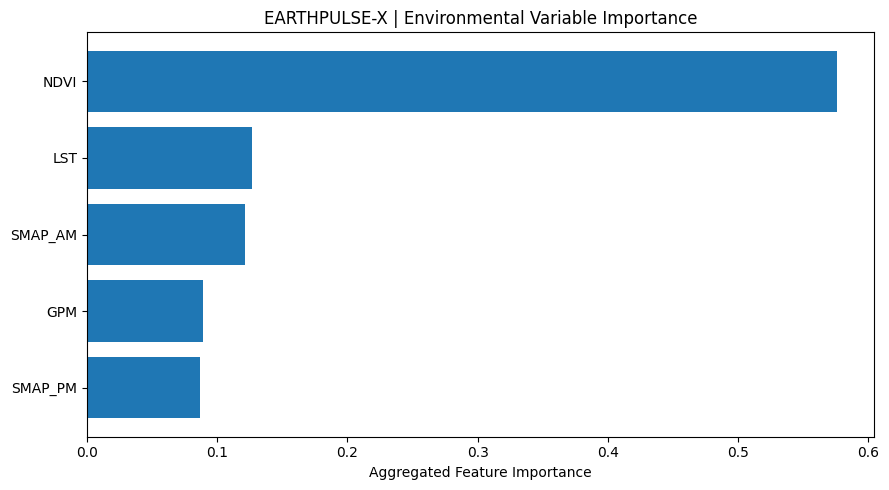


Saved:
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_rf_temporal_feature_importance.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_rf_variable_importance.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_rf_feature_importance.png

FEATURE IMPORTANCE COMPLETE


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 3-month sequence flattened into 15 features
base_variables = ["LST", "NDVI", "SMAP_AM", "SMAP_PM", "GPM"]

feature_names = [
    f"{variable}_t_minus_{lag}"
    for lag in [3, 2, 1]
    for variable in base_variables
]

importance_values = rf_model.feature_importances_

if len(feature_names) != len(importance_values):
    raise ValueError(
        f"Feature mismatch: model={len(importance_values)}, "
        f"names={len(feature_names)}"
    )

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
})

importance["variable"] = importance["feature"].str.extract(
    r"^(.*?)_t_minus_"
)

# Aggregate importance across the three input months
variable_importance = (
    importance.groupby("variable", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

print("=" * 65)
print("EARTHPULSE-X | FEATURE IMPORTANCE")
print("=" * 65)

print("\n15 TEMPORAL FEATURES")
display(importance.sort_values("importance", ascending=False).round(5))

print("\nAGGREGATED ENVIRONMENTAL VARIABLE IMPORTANCE")
display(variable_importance.round(5))

# Save detailed results
importance_path = OUT / "earthpulse_x_rf_temporal_feature_importance.csv"
variable_path = OUT / "earthpulse_x_rf_variable_importance.csv"
plot_path = OUT / "earthpulse_x_rf_feature_importance.png"

importance.to_csv(importance_path, index=False)
variable_importance.to_csv(variable_path, index=False)

# Plot aggregated importance
plt.figure(figsize=(9, 5))
plt.barh(
    variable_importance["variable"][::-1],
    variable_importance["importance"][::-1]
)
plt.xlabel("Aggregated Feature Importance")
plt.title("EARTHPULSE-X | Environmental Variable Importance")
plt.tight_layout()
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(importance_path)
print(variable_path)
print(plot_path)

print("\nFEATURE IMPORTANCE COMPLETE")

GLOBAL SHAP IMPORTANCE


,feature,mean_absolute_shap
11,NDVI_t_minus_1,0.010339
6,NDVI_t_minus_2,0.001414
10,LST_t_minus_1,0.001014
13,SMAP_PM_t_minus_1,0.000663
12,SMAP_AM_t_minus_1,0.000526
5,LST_t_minus_2,0.000517
4,GPM_t_minus_3,0.000343
14,GPM_t_minus_1,0.000333
3,SMAP_PM_t_minus_3,0.000327
9,GPM_t_minus_2,0.000307


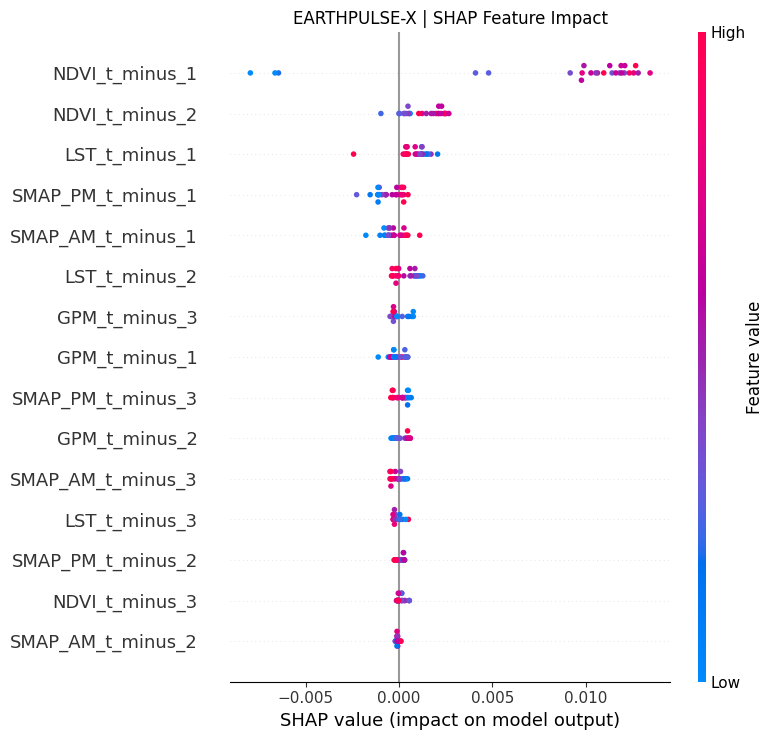

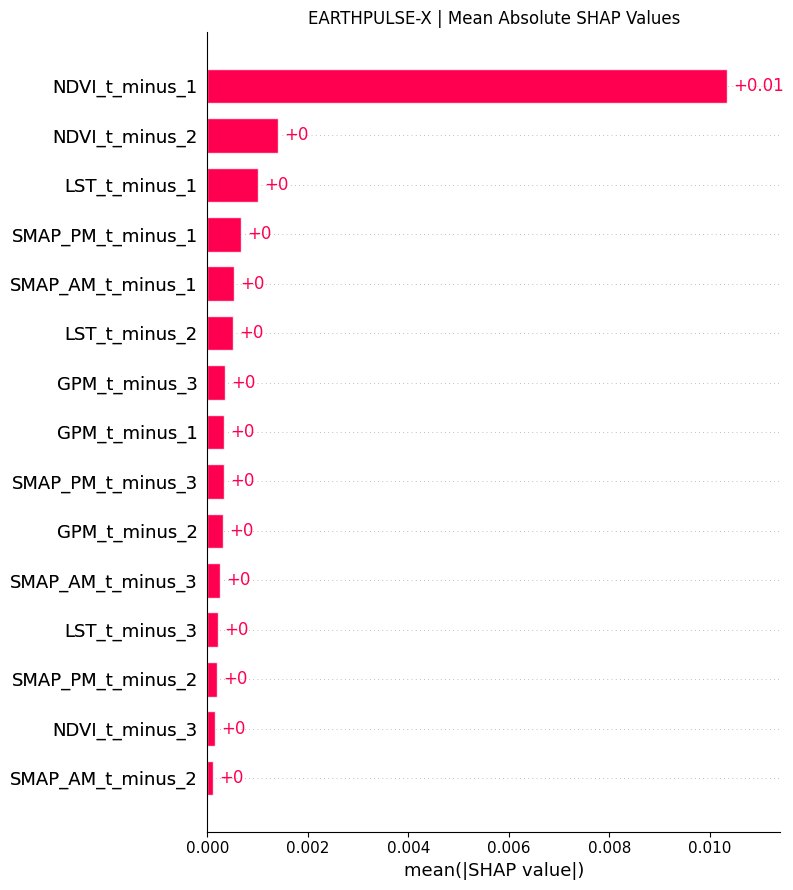


SAVED:
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_shap_importance.csv
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_shap_beeswarm.png
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_shap_importance.png

SHAP ANALYSIS COMPLETE


In [32]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Explain the trained fair Random Forest
feature_names = [
    f"{variable}_t_minus_{lag}"
    for lag in [3, 2, 1]
    for variable in ["LST", "NDVI", "SMAP_AM", "SMAP_PM", "GPM"]
]

X_test_flat = X_test.reshape(len(X_test), -1)

X_test_df = pd.DataFrame(
    X_test_flat,
    columns=feature_names
)

# Small background and test samples for faster CPU execution
background = pd.DataFrame(
    X_train.reshape(len(X_train), -1),
    columns=feature_names
).sample(min(30, len(X_train)), random_state=42)

explain_sample = X_test_df.sample(
    min(26, len(X_test_df)), random_state=42
)

explainer = shap.TreeExplainer(
    rf_model,
    data=background,
    feature_perturbation="interventional"
)

shap_values = explainer(explain_sample)

# Global SHAP importance
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values("mean_absolute_shap", ascending=False)

print("GLOBAL SHAP IMPORTANCE")
display(shap_importance.round(6))

# Beeswarm plot
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("EARTHPULSE-X | SHAP Feature Impact")
plt.tight_layout()

shap_path = OUT / "earthpulse_x_shap_beeswarm.png"
plt.savefig(shap_path, dpi=200, bbox_inches="tight")
plt.show()

# Bar plot
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("EARTHPULSE-X | Mean Absolute SHAP Values")
plt.tight_layout()

bar_path = OUT / "earthpulse_x_shap_importance.png"
plt.savefig(bar_path, dpi=200, bbox_inches="tight")
plt.show()

shap_csv = OUT / "earthpulse_x_shap_importance.csv"
shap_importance.to_csv(shap_csv, index=False)

print("\nSAVED:")
print(shap_csv)
print(shap_path)
print(bar_path)

print("\nSHAP ANALYSIS COMPLETE")

In [33]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import os, json, hashlib, platform, sys
import pandas as pd
import importlib.metadata as md

# 1. Ensure Google Drive is mounted
from google.colab import drive

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

if not ROOT.exists():
    drive.mount("/content/drive", force_remount=True)

assert ROOT.exists(), "EARTHPULSE_X project folder not found!"

# 2. Create checkpoint directory
BACKUP_DIR = ROOT / "reports" / "session_backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# 3. Important project directories to inventory
TARGET_DIRS = [
    "data/metadata",
    "experiments/results",
    "reports",
    "checkpoints",
    "src",
    "configs",
    "app",
    "models",
    "logs"
]

# 4. Generate file inventory with SHA256
inventory = []

for folder in TARGET_DIRS:
    base = ROOT / folder

    if not base.exists():
        continue

    for file in base.rglob("*"):
        if not file.is_file():
            continue

        try:
            digest = hashlib.sha256()
            with open(file, "rb") as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b""):
                    digest.update(chunk)

            inventory.append({
                "relative_path": str(file.relative_to(ROOT)),
                "size_bytes": file.stat().st_size,
                "sha256": digest.hexdigest(),
                "status": "VERIFIED"
            })

        except Exception as e:
            inventory.append({
                "relative_path": str(file.relative_to(ROOT)),
                "size_bytes": None,
                "sha256": None,
                "status": f"ERROR: {str(e)}"
            })

inventory_df = pd.DataFrame(inventory)

inventory_path = (
    BACKUP_DIR / "earthpulse_x_current_runtime_inventory.csv"
)
inventory_df.to_csv(inventory_path, index=False)

# 5. Important experiment output verification
KEY_FILES = [
    "data/metadata/earthpulse_x_regional_monthly_timeseries.csv",
    "data/metadata/earthpulse_x_seasonal_trend_baseline.csv",
    "data/metadata/earthpulse_x_monthly_seasonal_anomalies.csv",
    "data/metadata/earthpulse_x_robust_anomaly_detection.csv",
    "data/metadata/earthpulse_x_pixel_anomaly_events.csv",
    "data/metadata/earthpulse_x_spatial_anomaly_clusters.csv",
    "data/metadata/earthpulse_x_interaction_edges.csv",
    "data/metadata/earthpulse_x_interaction_graph.graphml",
    "data/metadata/earthpulse_x_physics_consistency_checks.csv",
    "experiments/results/earthpulse_x_ndvi_ml_leakage_safe_comparison.csv",
    "experiments/results/earthpulse_x_fair_lstm_rf_comparison.csv",
    "experiments/results/earthpulse_x_rf_temporal_feature_importance.csv",
    "experiments/results/earthpulse_x_rf_variable_importance.csv",
    "experiments/results/earthpulse_x_shap_importance.csv",
    "experiments/results/earthpulse_x_shap_beeswarm.png",
    "experiments/results/earthpulse_x_shap_importance.png"
]

key_status = {
    path: {
        "exists": (ROOT / path).is_file(),
        "size_bytes": (
            (ROOT / path).stat().st_size
            if (ROOT / path).is_file() else None
        )
    }
    for path in KEY_FILES
}

# 6. Capture environment information
packages = {}

for package in [
    "numpy", "pandas", "scipy", "scikit-learn",
    "xgboost", "torch", "tensorflow", "shap",
    "xarray", "rasterio", "geopandas",
    "statsmodels", "networkx", "plotly"
]:
    try:
        packages[package] = md.version(package)
    except md.PackageNotFoundError:
        packages[package] = "NOT INSTALLED"

# 7. Prepare runtime handoff
now = datetime.now(ZoneInfo("Asia/Kolkata"))

handoff = {
    "project": "EARTHPULSE-X",
    "project_title": "Physics-Aware, Uncertainty-Guided Earth System Intelligence",
    "study_region": "Uttarakhand, India ONLY",
    "study_period": "2015-04-01 to 2025-09-30",
    "checkpoint_time_ist": now.isoformat(),
    "checkpoint_status": "CREATED",
    "inventory_file": str(inventory_path),
    "inventory_file_count": len(inventory_df),
    "inventory_errors": int(
        inventory_df["status"].str.startswith("ERROR").sum()
    ),
    "key_outputs": key_status,
    "environment": {
        "python": sys.version,
        "platform": platform.platform(),
        "packages": packages
    },
    "completed_milestones": [
        "MODIS monthly production and independent validation",
        "GPM monthly processing and corrected harmonization",
        "SMAP monthly processing and independent validation",
        "126-month harmonized dataset",
        "Regional monthly time-series extraction",
        "Regional trend detection",
        "Regional and spatial anomaly detection",
        "Spatial anomaly clustering and mapping",
        "Earth Interaction Graph",
        "Physics consistency checks",
        "Leakage-safe ML comparison",
        "Fair LSTM vs Random Forest comparison",
        "Random Forest feature importance",
        "SHAP explainability"
    ],
    "next_steps": [
        "Consolidate scientific experiment results",
        "Prepare final research report",
        "Build FastAPI backend",
        "Build premium 3D React/Next.js frontend",
        "Connect real scientific outputs to dashboard",
        "Prepare NASA Space Apps presentation and demo"
    ],
    "runtime_recovery_instructions": [
        "Remount Google Drive after runtime reset",
        "Restore required Python packages",
        "Set ROOT to the EARTHPULSE_X Drive folder",
        "Read this handoff JSON and inventory CSV",
        "Verify existing outputs before running anything",
        "Do not rerun completed satellite acquisition or monthly processing"
    ]
}

handoff_path = BACKUP_DIR / "earthpulse_x_runtime_handoff.json"

with open(handoff_path, "w") as f:
    json.dump(handoff, f, indent=4)

# 8. Final verification
with open(handoff_path, "r") as f:
    verified_handoff = json.load(f)

assert verified_handoff["checkpoint_status"] == "CREATED"
assert inventory_path.exists()
assert handoff_path.exists()

print("\n" + "=" * 65)
print("EARTHPULSE-X | DRIVE CHECKPOINT COMPLETE")
print("=" * 65)

print(f"Project folder       : {ROOT}")
print(f"Inventory files      : {len(inventory_df)}")
print(f"Inventory errors     : {handoff['inventory_errors']}")
print(f"Key outputs present  : {sum(v['exists'] for v in key_status.values())}/{len(KEY_FILES)}")
print(f"Checkpoint time      : {now.strftime('%Y-%m-%d %H:%M:%S IST')}")

print("\nSAVED FILES:")
print(inventory_path)
print(handoff_path)

print("\nDRIVE CHECKPOINT VERIFIED")
print("SAFE TO RESET RUNTIME")


EARTHPULSE-X | DRIVE CHECKPOINT COMPLETE
Project folder       : /content/drive/MyDrive/EARTHPULSE_X
Inventory files      : 553
Inventory errors     : 0
Key outputs present  : 16/16
Checkpoint time      : 2026-11-09 10:41:52 IST

SAVED FILES:
/content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_current_runtime_inventory.csv
/content/drive/MyDrive/EARTHPULSE_X/reports/session_backups/earthpulse_x_runtime_handoff.json

DRIVE CHECKPOINT VERIFIED
SAFE TO RESET RUNTIME


In [34]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from pathlib import Path

# Project directory
ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

# Load our existing 126-month regional dataset
file_path = ROOT / "data/metadata/earthpulse_x_regional_monthly_timeseries.csv"

df = pd.read_csv(file_path, parse_dates=["month"])
df = df.sort_values("month").reset_index(drop=True)

# Environmental variables
variables = {
    "LST": "lst_relaxed_mean",
    "NDVI": "ndvi_relaxed_mean",
    "SMAP_AM": "smap_am_relaxed_mean",
    "SMAP_PM": "smap_pm_relaxed_mean",
    "GPM": "gpm_monthly_precipitation_mean"
}

print("=" * 65)
print("EARTHPULSE-X | INTEGRATED EARTH SYSTEM ANALYSIS")
print("=" * 65)

print(f"\nStudy Region: Uttarakhand, India")
print(f"Study Period: {df['month'].min()} to {df['month'].max()}")
print(f"Monthly Records: {len(df)}")

# Seasonal anomaly calculation
# Remove month-specific median climatology
anomalies = pd.DataFrame()
anomalies["month"] = df["month"]

for name, column in variables.items():
    if column not in df.columns:
        raise ValueError(f"Missing column: {column}")

    climatology = df.groupby(
        df["month"].dt.month
    )[column].transform("median")

    anomalies[name] = df[column] - climatology

# Pairwise lagged relationships
# Positive lag means first variable leads second variable.
results = []

names = list(variables.keys())

for i, x_name in enumerate(names):
    for y_name in names[i + 1:]:

        for lag in range(-3, 4):

            x = anomalies[x_name]
            y = anomalies[y_name]

            if lag > 0:
                paired = pd.concat(
                    [x.iloc[:-lag].reset_index(drop=True),
                     y.iloc[lag:].reset_index(drop=True)],
                    axis=1
                )
            elif lag < 0:
                k = abs(lag)
                paired = pd.concat(
                    [x.iloc[k:].reset_index(drop=True),
                     y.iloc[:-k].reset_index(drop=True)],
                    axis=1
                )
            else:
                paired = pd.concat(
                    [x.reset_index(drop=True),
                     y.reset_index(drop=True)],
                    axis=1
                )

            paired.columns = ["x", "y"]
            paired = paired.dropna()

            if len(paired) < 80:
                continue

            rho, p_value = spearmanr(
                paired["x"], paired["y"]
            )

            results.append({
                "variable_x": x_name,
                "variable_y": y_name,
                "lag_months": lag,
                "sample_size": len(paired),
                "spearman_rho": rho,
                "p_value": p_value
            })

# Multiple testing correction
results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df["fdr_q_value"] = multipletests(
        results_df["p_value"],
        method="fdr_bh"
    )[1]

    results_df["fdr_significant"] = (
        results_df["fdr_q_value"] < 0.05
    )

    results_df = results_df.sort_values(
        "fdr_q_value"
    )

# Save results
output_path = (
    ROOT / "experiments/results/"
    "earthpulse_x_integrated_interaction_analysis.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)

print("\nTOP ENVIRONMENTAL RELATIONSHIPS")
display(results_df.head(15).round(5))

print("\nFDR-SIGNIFICANT RELATIONSHIPS:",
      int(results_df["fdr_significant"].sum()))

print("\nTOTAL RELATIONSHIPS TESTED:", len(results_df))

print("\nRESULT SAVED:")
print(output_path)

print("\nINTEGRATED INTERACTION ANALYSIS COMPLETE")

EARTHPULSE-X | INTEGRATED EARTH SYSTEM ANALYSIS

Study Region: Uttarakhand, India
Study Period: 2015-04-01 00:00:00 to 2025-09-01 00:00:00
Monthly Records: 126

TOP ENVIRONMENTAL RELATIONSHIPS


,variable_x,variable_y,lag_months,sample_size,spearman_rho,p_value,fdr_q_value,fdr_significant
52,SMAP_AM,SMAP_PM,0,126,0.93854,0.00000,0.00000,True
10,LST,SMAP_AM,0,126,-0.59151,0.00000,0.00000,True
59,SMAP_AM,GPM,0,126,0.59378,0.00000,0.00000,True
66,SMAP_PM,GPM,0,126,0.52811,0.00000,0.00000,True
24,LST,GPM,0,126,-0.52081,0.00000,0.00000,True
17,LST,SMAP_PM,0,126,-0.45895,0.00000,0.00000,True
53,SMAP_AM,SMAP_PM,1,125,0.45689,0.00000,0.00000,True
51,SMAP_AM,SMAP_PM,-1,125,0.42292,0.00000,0.00001,True
4,LST,NDVI,1,125,-0.38962,0.00001,0.00006,True
23,LST,GPM,-1,125,-0.36351,0.00003,0.00022,True



FDR-SIGNIFICANT RELATIONSHIPS: 20

TOTAL RELATIONSHIPS TESTED: 70

RESULT SAVED:
/content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_integrated_interaction_analysis.csv

INTEGRATED INTERACTION ANALYSIS COMPLETE



       EARTHPULSE-X | EARTH SYSTEM INTELLIGENCE

RESEARCH QUESTION:
What environmental conditions were unusual in Uttarakhand in 2025-08?

[1/5] Loading harmonized satellite observations...
Historical monthly records: 126
Satellite systems: MODIS LST, MODIS NDVI, SMAP, GPM
Study region: Uttarakhand, India

[2/5] Comparing observations with historical August conditions...


,variable,current_value,historical_median,difference,robust_z,historical_samples
0,Land Surface Temperature,291.4376,294.1469,-2.7093,-6.2418,10
1,Vegetation (NDVI),0.6732,0.6768,-0.0037,-0.7626,10
2,Soil Moisture (AM),0.3729,0.3733,-0.0004,-0.0392,10
3,Soil Moisture (PM),0.3659,0.3954,-0.0295,-2.5062,10
4,Precipitation,543.2142,315.2716,227.9426,15.5795,10



[3/5] Checking previously validated anomaly detections...
Available anomaly result columns: ['month', 'year', 'month_number', 'lst_robust_z', 'lst_anomaly_flag', 'lst_coverage_pct', 'ndvi_robust_z', 'ndvi_anomaly_flag', 'ndvi_coverage_pct', 'smap_am_robust_z', 'smap_am_anomaly_flag', 'smap_am_coverage_pct', 'smap_pm_robust_z', 'smap_pm_anomaly_flag', 'smap_pm_coverage_pct', 'gpm_robust_z', 'gpm_anomaly_flag', 'gpm_coverage_pct', 'total_anomalous_variables']


,month,year,month_number,lst_robust_z,lst_anomaly_flag,lst_coverage_pct,ndvi_robust_z,ndvi_anomaly_flag,ndvi_coverage_pct,smap_am_robust_z,smap_am_anomaly_flag,smap_am_coverage_pct,smap_pm_robust_z,smap_pm_anomaly_flag,smap_pm_coverage_pct,gpm_robust_z,gpm_anomaly_flag,gpm_coverage_pct,total_anomalous_variables
124,2025-08-01,2025,8,-1.879583,False,100.0,-0.164321,False,100.0,0.0,False,99.605082,-0.899315,False,99.605082,8.207101,True,97.842255,1



[4/5] Generating environmental intelligence visualization...


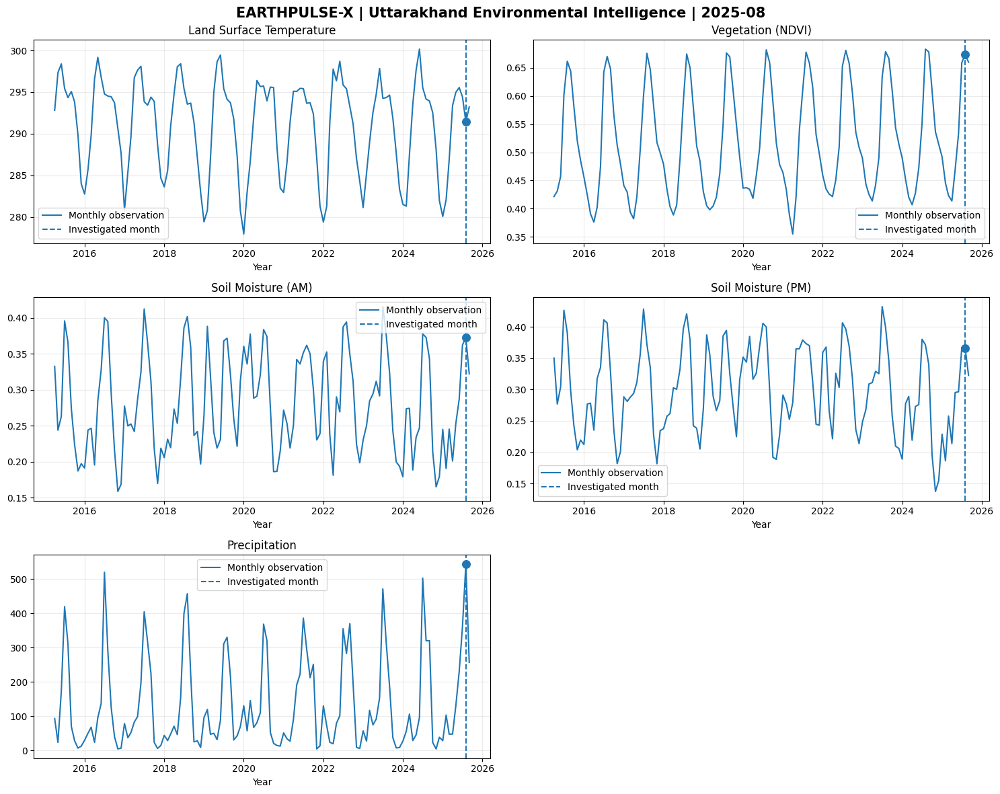


[5/5] Generating scientific interpretation...

                 EARTHPULSE-X FINDINGS

Land Surface Temperature
  Observed value: 291.4376
  Historical median: 294.1469
  Value is below its historical August median.
  Robust Z-score: -6.242
  Assessment: UNUSUAL ANOMALY CANDIDATE

Vegetation (NDVI)
  Observed value: 0.6732
  Historical median: 0.6768
  Value is below its historical August median.
  Robust Z-score: -0.763
  Assessment: WITHIN EXPLORATORY RANGE

Soil Moisture (AM)
  Observed value: 0.3729
  Historical median: 0.3733
  Value is below its historical August median.
  Robust Z-score: -0.039
  Assessment: WITHIN EXPLORATORY RANGE

Soil Moisture (PM)
  Observed value: 0.3659
  Historical median: 0.3954
  Value is below its historical August median.
  Robust Z-score: -2.506
  Assessment: NOTABLE DEVIATION

Precipitation
  Observed value: 543.2142
  Historical median: 315.2716
  Value is above its historical August median.
  Robust Z-score: 15.580
  Assessment: UNUSUAL ANOMALY 

In [36]:
# ============================================================
# EARTHPULSE-X | LIVE EARTH SYSTEM DETECTIVE
# Judge Demonstration 01
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
META = ROOT / "data/metadata"
RESULTS = ROOT / "experiments/results"

# ------------------------------------------------------------
# 1. LOAD REAL SATELLITE-DERIVED REGIONAL OBSERVATIONS
# ------------------------------------------------------------

df = pd.read_csv(
    META / "earthpulse_x_regional_monthly_timeseries.csv",
    parse_dates=["month"]
).sort_values("month")

variables = {
    "Land Surface Temperature": "lst_relaxed_mean",
    "Vegetation (NDVI)": "ndvi_relaxed_mean",
    "Soil Moisture (AM)": "smap_am_relaxed_mean",
    "Soil Moisture (PM)": "smap_pm_relaxed_mean",
    "Precipitation": "gpm_monthly_precipitation_mean"
}

# ------------------------------------------------------------
# 2. JUDGE'S QUESTION
# ------------------------------------------------------------

TARGET_MONTH = "2025-08"

target_date = pd.Period(TARGET_MONTH, freq="M")
target = df[df["month"].dt.to_period("M") == target_date]

if len(target) != 1:
    raise ValueError(f"Target month {TARGET_MONTH} not found.")

target = target.iloc[0]

print("\n" + "=" * 72)
print("       EARTHPULSE-X | EARTH SYSTEM INTELLIGENCE")
print("=" * 72)

print("\nRESEARCH QUESTION:")
print(f"What environmental conditions were unusual in Uttarakhand in {TARGET_MONTH}?")

print("\n[1/5] Loading harmonized satellite observations...")
print(f"Historical monthly records: {len(df)}")
print("Satellite systems: MODIS LST, MODIS NDVI, SMAP, GPM")
print("Study region: Uttarakhand, India")

# ------------------------------------------------------------
# 3. COMPARE WITH HISTORICAL SEASONAL BASELINE
# ------------------------------------------------------------

month_number = target_date.month

historical = df[
    (df["month"].dt.month == month_number) &
    (df["month"].dt.to_period("M") != target_date)
]

if len(historical) < 5:
    raise ValueError("Insufficient historical seasonal observations.")

findings = []

for name, column in variables.items():

    historical_values = historical[column].dropna()
    current_value = target[column]

    if pd.isna(current_value) or len(historical_values) < 5:
        continue

    baseline = historical_values.median()
    mad = np.median(np.abs(historical_values - baseline))

    robust_z = (
        0.6745 * (current_value - baseline) / mad
        if mad > 0 else np.nan
    )

    findings.append({
        "variable": name,
        "current_value": current_value,
        "historical_median": baseline,
        "difference": current_value - baseline,
        "robust_z": robust_z,
        "historical_samples": len(historical_values)
    })

result = pd.DataFrame(findings)

print("\n[2/5] Comparing observations with historical August conditions...")
display(result.round(4))

# ------------------------------------------------------------
# 4. LOAD EXISTING ANOMALY DETECTION EVIDENCE
# ------------------------------------------------------------

anomaly_file = META / "earthpulse_x_robust_anomaly_detection.csv"

if anomaly_file.exists():

    anomaly_df = pd.read_csv(anomaly_file)

    print("\n[3/5] Checking previously validated anomaly detections...")

    # Detect the actual column names in the saved result
    print("Available anomaly result columns:", list(anomaly_df.columns))

    date_column = next(
        (c for c in anomaly_df.columns
         if c.lower() in ["month", "date", "timestamp"]),
        None
    )

    if date_column:
        anomaly_df[date_column] = pd.to_datetime(
            anomaly_df[date_column], errors="coerce"
        )

        event_rows = anomaly_df[
            anomaly_df[date_column].dt.to_period("M") == target_date
        ]

        display(event_rows)

else:
    print("\n[3/5] Existing anomaly report unavailable.")

# ------------------------------------------------------------
# 5. VISUALIZE THE FIVE ENVIRONMENTAL VARIABLES
# ------------------------------------------------------------

print("\n[4/5] Generating environmental intelligence visualization...")

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, (name, column) in enumerate(variables.items()):

    ax = axes[i]

    series = df[["month", column]].dropna()

    ax.plot(
        series["month"],
        series[column],
        linewidth=1.5,
        label="Monthly observation"
    )

    ax.axvline(
        pd.Timestamp(target["month"]),
        linestyle="--",
        linewidth=1.5,
        label="Investigated month"
    )

    ax.scatter(
        [target["month"]],
        [target[column]],
        s=70,
        zorder=5
    )

    ax.set_title(name)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].axis("off")

plt.suptitle(
    f"EARTHPULSE-X | Uttarakhand Environmental Intelligence | {TARGET_MONTH}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. GENERATE SYSTEM EXPLANATION
# ------------------------------------------------------------

print("\n[5/5] Generating scientific interpretation...")

print("\n" + "=" * 72)
print("                 EARTHPULSE-X FINDINGS")
print("=" * 72)

for _, row in result.iterrows():

    z = row["robust_z"]

    if pd.notna(z) and abs(z) >= 3.5:
        status = "UNUSUAL ANOMALY CANDIDATE"
    elif pd.notna(z) and abs(z) >= 2:
        status = "NOTABLE DEVIATION"
    else:
        status = "WITHIN EXPLORATORY RANGE"

    direction = (
        "above" if row["difference"] > 0
        else "below" if row["difference"] < 0
        else "equal to"
    )

    print(f"\n{row['variable']}")
    print(f"  Observed value: {row['current_value']:.4f}")
    print(f"  Historical median: {row['historical_median']:.4f}")
    print(f"  Value is {direction} its historical August median.")
    print(f"  Robust Z-score: {z:.3f}")
    print(f"  Assessment: {status}")

print("\n" + "-" * 72)
print("SCIENTIFIC INTERPRETATION")
print("-" * 72)

gpm = result[result["variable"] == "Precipitation"]

if not gpm.empty:
    z = gpm.iloc[0]["robust_z"]

    if pd.notna(z) and abs(z) >= 3.5:
        print(
            "The precipitation observation is an unusual "
            "statistical candidate relative to historical August conditions."
        )
    else:
        print(
            "The precipitation observation does not cross "
            "the selected extreme-anomaly threshold."
        )

print(
    "\nThese findings are regional statistical comparisons, "
    "not proof of causation or a confirmed natural disaster."
)

print("\n" + "=" * 72)
print("EARTHPULSE-X ANALYSIS COMPLETE")
print("=" * 72)

In [37]:
from pathlib import Path
import json
import geopandas as gpd
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

print("=" * 65)
print("EARTHPULSE-X | DISTRICT INTELLIGENCE PREPARATION")
print("=" * 65)

# 1. Find existing district boundary files
boundary_root = ROOT / "data/raw/boundaries"

print("\n1. AVAILABLE BOUNDARY FILES")

for ext in ["*.geojson", "*.shp", "*.gpkg", "*.json"]:
    for f in boundary_root.rglob(ext):
        print(f.relative_to(ROOT))

# 2. Check spatial anomaly outputs
print("\n2. SPATIAL ANOMALY OUTPUTS")

spatial_files = [
    "data/metadata/earthpulse_x_pixel_anomaly_events.csv",
    "data/metadata/earthpulse_x_spatial_anomaly_clusters.csv",
    "data/metadata/earthpulse_x_spatial_cluster_monthly_summary.csv",
    "data/metadata/earthpulse_x_pixel_anomaly_arrays.npz",
    "data/metadata/uttarakhand_boundary_metadata.json",
    "data/metadata/canonical_study_area.json"
]

for name in spatial_files:
    path = ROOT / name
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {name}")

# 3. Inspect district-like boundary files
print("\n3. BOUNDARY SCHEMA INSPECTION")

for f in boundary_root.rglob("*"):
    if f.suffix.lower() not in [".geojson", ".shp", ".gpkg"]:
        continue

    try:
        gdf = gpd.read_file(f)

        print(f"\nFILE: {f.name}")
        print("CRS:", gdf.crs)
        print("Rows:", len(gdf))
        print("Columns:", list(gdf.columns))

        # Look for possible district-level boundaries
        for col in gdf.columns:
            if gdf[col].dtype == "object":
                examples = gdf[col].dropna().astype(str).unique()[:12]
                print(f"{col} examples:", examples)

    except Exception as e:
        print("Could not inspect:", f.name, str(e))

print("\n4. SPATIAL DATA INSPECTION COMPLETE")

EARTHPULSE-X | DISTRICT INTELLIGENCE PREPARATION

1. AVAILABLE BOUNDARY FILES
data/raw/boundaries/india_adm1_full.geojson
data/raw/boundaries/uttarakhand_adm1.geojson
data/raw/boundaries/uttarakhand_study_area.geojson

2. SPATIAL ANOMALY OUTPUTS
FOUND: data/metadata/earthpulse_x_pixel_anomaly_events.csv
FOUND: data/metadata/earthpulse_x_spatial_anomaly_clusters.csv
FOUND: data/metadata/earthpulse_x_spatial_cluster_monthly_summary.csv
FOUND: data/metadata/earthpulse_x_pixel_anomaly_arrays.npz
FOUND: data/metadata/uttarakhand_boundary_metadata.json
FOUND: data/metadata/canonical_study_area.json

3. BOUNDARY SCHEMA INSPECTION

FILE: india_adm1_full.geojson
CRS: EPSG:4326
Rows: 36
Columns: ['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']
shapeName examples: ['Puducherry' 'Mahārāshtra' 'Nāgāland' 'Lakshadweep' 'Uttar Pradesh'
 'Tamil Nādu' 'Chhattīsgarh' 'Gujarāt' 'Delhi' 'Sikkim' 'Tripura'
 'West Bengal']
shapeISO examples: ['IN-PY' 'IN-MH' 'IN-NL' 'IN-LD' 'IN-UP

In [38]:
import requests
import geopandas as gpd
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

BOUNDARY_DIR = ROOT / "data/raw/boundaries"
METADATA_DIR = ROOT / "data/metadata"

BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("EARTHPULSE-X | DISTRICT BOUNDARY ACQUISITION")
print("=" * 65)

# 1. Request India ADM2 metadata
api_url = "https://www.geoboundaries.org/api/current/gbOpen/IND/ADM2/"

response = requests.get(api_url, timeout=60)
response.raise_for_status()

metadata = response.json()

download_url = metadata.get("gjDownloadURL")

if not download_url:
    raise ValueError("GeoBoundaries did not provide a GeoJSON download URL.")

print("\nBoundary source:", metadata.get("boundarySource"))
print("Boundary year:", metadata.get("boundaryYear"))
print("Boundary type:", metadata.get("boundaryType"))
print("License:", metadata.get("license"))

# 2. Download ADM2 GeoJSON
geojson_path = BOUNDARY_DIR / "india_adm2_geoboundaries.geojson"

if not geojson_path.exists():
    data_response = requests.get(download_url, timeout=180)
    data_response.raise_for_status()

    with open(geojson_path, "wb") as f:
        f.write(data_response.content)

    print("\nDownloaded India ADM2 boundaries.")
else:
    print("\nExisting ADM2 file found. Reusing it.")

# 3. Read district boundaries
districts = gpd.read_file(geojson_path)

print("\nTotal ADM2 records:", len(districts))
print("CRS:", districts.crs)
print("Available columns:", list(districts.columns))

# 4. Inspect Uttarakhand-related records
print("\nBOUNDARY PROPERTY INSPECTION")

for column in districts.columns:
    if column != "geometry":
        print(f"\n{column}:")
        print(districts[column].dropna().astype(str).unique()[:20])

# 5. Save source metadata
metadata_path = METADATA_DIR / "india_adm2_boundary_source.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\nSaved source metadata:", metadata_path)
print("Saved boundary file:", geojson_path)

print("\nDISTRICT BOUNDARY ACQUISITION COMPLETE")

EARTHPULSE-X | DISTRICT BOUNDARY ACQUISITION

Boundary source: Pathways Data Pvt. Ltd., lgdirectory.gov.in
Boundary year: None
Boundary type: ADM2
License: None

Downloaded India ADM2 boundaries.

Total ADM2 records: 735
CRS: EPSG:4326
Available columns: ['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']

BOUNDARY PROPERTY INSPECTION

shapeName:
['Ashoknagar' 'Raisen' 'Chhindwara' 'Betul' 'Hoshangabad' 'Sehore'
 'Jabalpur' 'Narsimhapur' 'Panna' 'Ujjain' 'Rewa' 'Dindori' 'Balaghat'
 'Barwani' 'Satna' 'Chhatarpur' 'Indore' 'Ratlam' 'Harda' 'Sagar']

shapeISO:
['']

shapeID:
['76128533B75548370501185' '76128533B57893545331548'
 '76128533B70646408240587' '76128533B82559220423608'
 '76128533B45314020251888' '76128533B39959897010345'
 '76128533B27615708126939' '76128533B20683890392439'
 '76128533B81607600692021' '76128533B89286042589317'
 '76128533B31161316175613' '76128533B20502827346807'
 '76128533B66134271591289' '76128533B668165975951'
 '76128533B39705008578419' 

In [40]:
import geopandas as gpd
import pandas as pd
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
BD = ROOT / "data/raw/boundaries"
META = ROOT / "data/metadata"

# Load previously extracted polygons
districts = gpd.read_file(
    BD / "uttarakhand_adm2_districts.geojson"
)

# Calculate area using equal-area CRS
districts_area = districts.to_crs("EPSG:6933").copy()
districts_area["area_km2"] = (
    districts_area.geometry.area / 1_000_000
)

# Remove tiny cross-border slivers
clean = districts_area[
    districts_area["area_km2"] >= 100
].copy()

# Standardize known source-name variants
name_mapping = {
    "Garhwal": "Pauri Garhwal",
    "Hardwar": "Haridwar"
}

clean["district_name"] = clean["shapeName"].replace(
    name_mapping
)

clean = clean.sort_values("district_name").reset_index(drop=True)

# Expected district inventory for validation
expected = {
    "Almora", "Bageshwar", "Chamoli", "Champawat",
    "Dehradun", "Pauri Garhwal", "Haridwar",
    "Nainital", "Pithoragarh", "Rudraprayag",
    "Tehri Garhwal", "Udham Singh Nagar", "Uttarkashi"
}

actual = set(clean["district_name"])

missing = sorted(expected - actual)
unexpected = sorted(actual - expected)

# Save corrected district boundaries
output = clean.to_crs("EPSG:4326")

geojson_path = BD / "uttarakhand_13_districts.geojson"
output.to_file(geojson_path, driver="GeoJSON")

inventory = output[
    ["district_name", "shapeName", "shapeID"]
].copy()

inventory["area_km2"] = clean["area_km2"].values

inventory_path = META / "uttarakhand_13_district_inventory.csv"
inventory.to_csv(inventory_path, index=False)

validation = {
    "study_region": "Uttarakhand, India",
    "expected_district_count": 13,
    "extracted_district_count": len(output),
    "district_names": sorted(actual),
    "missing_districts": missing,
    "unexpected_districts": unexpected,
    "sliver_threshold_km2": 100,
    "validation_status": (
        "PASS" if len(actual) == 13 and not missing and not unexpected
        else "REVIEW_REQUIRED"
    ),
    "source_boundary_year": None,
    "source_license": None
}

with open(
    META / "uttarakhand_13_district_validation.json", "w"
) as f:
    json.dump(validation, f, indent=4)

print("=" * 65)
print("EARTHPULSE-X | CORRECTED DISTRICT VALIDATION")
print("=" * 65)

display(inventory.round(2))

print("\nDistrict count:", len(output))
print("Missing:", missing)
print("Unexpected:", unexpected)
print("Validation:", validation["validation_status"])

print("\nSaved:", geojson_path)
print("Saved:", inventory_path)

print("\nDISTRICT VALIDATION COMPLETE")

EARTHPULSE-X | CORRECTED DISTRICT VALIDATION


,district_name,shapeName,shapeID,area_km2
0,Almora,Almora,76128533B74917207853309,3114.41
1,Bageshwar,Bageshwar,76128533B64217423710469,2272.90
2,Chamoli,Chamoli,76128533B69844709752120,7865.75
3,Champawat,Champawat,76128533B2761749808956,1734.97
4,Dehradun,Dehradun,76128533B67005208112053,3071.11
5,Haridwar,Hardwar,76128533B87833640460819,2237.86
6,Nainital,Nainital,76128533B50374927918374,4031.31
7,Pauri Garhwal,Garhwal,76128533B46926146855114,5273.76
8,Pithoragarh,Pithoragarh,76128533B38561771925520,7143.88
9,Rudraprayag,Rudraprayag,76128533B46038384763988,1936.10



District count: 13
Missing: []
Unexpected: []
Validation: PASS

Saved: /content/drive/MyDrive/EARTHPULSE_X/data/raw/boundaries/uttarakhand_13_districts.geojson
Saved: /content/drive/MyDrive/EARTHPULSE_X/data/metadata/uttarakhand_13_district_inventory.csv

DISTRICT VALIDATION COMPLETE


In [42]:
import re
import xarray as xr
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")
MONTHLY_DIR = ROOT / "data/processed/harmonized/monthly"

files = sorted(MONTHLY_DIR.glob("*.nc"))

def identify_month(file, ds):
    # 1. Check NetCDF attributes
    for key in ["month", "date", "time_coverage_start"]:
        value = ds.attrs.get(key)

        if value:
            match = re.search(r"(20\d{2})[-_](0[1-9]|1[0-2])", str(value))
            if match:
                return f"{match.group(1)}_{match.group(2)}"

    # 2. Check filename
    match = re.search(
        r"(20\d{2})[-_](0[1-9]|1[0-2])",
        file.name
    )

    if match:
        return f"{match.group(1)}_{match.group(2)}"

    return None


records = []

for file in files:
    with xr.open_dataset(file) as ds:
        month = identify_month(file, ds)

        if month:
            records.append({
                "month": month,
                "file": str(file)
            })

print("=" * 65)
print("EARTHPULSE-X | MONTH IDENTIFICATION AUDIT")
print("=" * 65)

print("Files found:", len(files))
print("Months identified:", len(records))

months = [r["month"] for r in records]

print("Unique months:", len(set(months)))
print("Duplicate months:", len(months) - len(set(months)))

target = [r for r in records if r["month"] == "2025_08"]

print("\nAUGUST 2025 MATCH:")
for item in target:
    print(item["file"])

print("\nSAMPLE MONTH IDENTIFICATION:")
for item in records[:5]:
    print(item["month"], "->", Path(item["file"]).name)

if len(target) == 1:
    print("\nSUCCESS: August 2025 identified correctly.")
else:
    print("\nREVIEW REQUIRED: August 2025 match count =", len(target))

EARTHPULSE-X | MONTH IDENTIFICATION AUDIT
Files found: 126
Months identified: 126
Unique months: 126
Duplicate months: 0

AUGUST 2025 MATCH:
/content/drive/MyDrive/EARTHPULSE_X/data/processed/harmonized/monthly/earthpulse_x_2025_08.nc

SAMPLE MONTH IDENTIFICATION:
2015_04 -> earthpulse_x_2015_04.nc
2015_05 -> earthpulse_x_2015_05.nc
2015_06 -> earthpulse_x_2015_06.nc
2015_07 -> earthpulse_x_2015_07.nc
2015_08 -> earthpulse_x_2015_08.nc

SUCCESS: August 2025 identified correctly.


EARTHPULSE-X | DISTRICT-LEVEL ENVIRONMENTAL INTELLIGENCE

Monthly files identified: 126
Historical August observations: 10
Target raster shape: (34, 39)

Valid anomaly-score pixels: 643
High precipitation anomaly pixels: 552
Low precipitation anomaly pixels: 0
Excluded zero-MAD / invalid pixels: 683


/tmp/ipykernel_1814/2928035054.py:122: RuntimeWarning: All-NaN slice encountered
  baseline = np.nanmedian(history, axis=0)
/tmp/ipykernel_1814/2928035054.py:124: RuntimeWarning: All-NaN slice encountered
  mad = np.nanmedian(


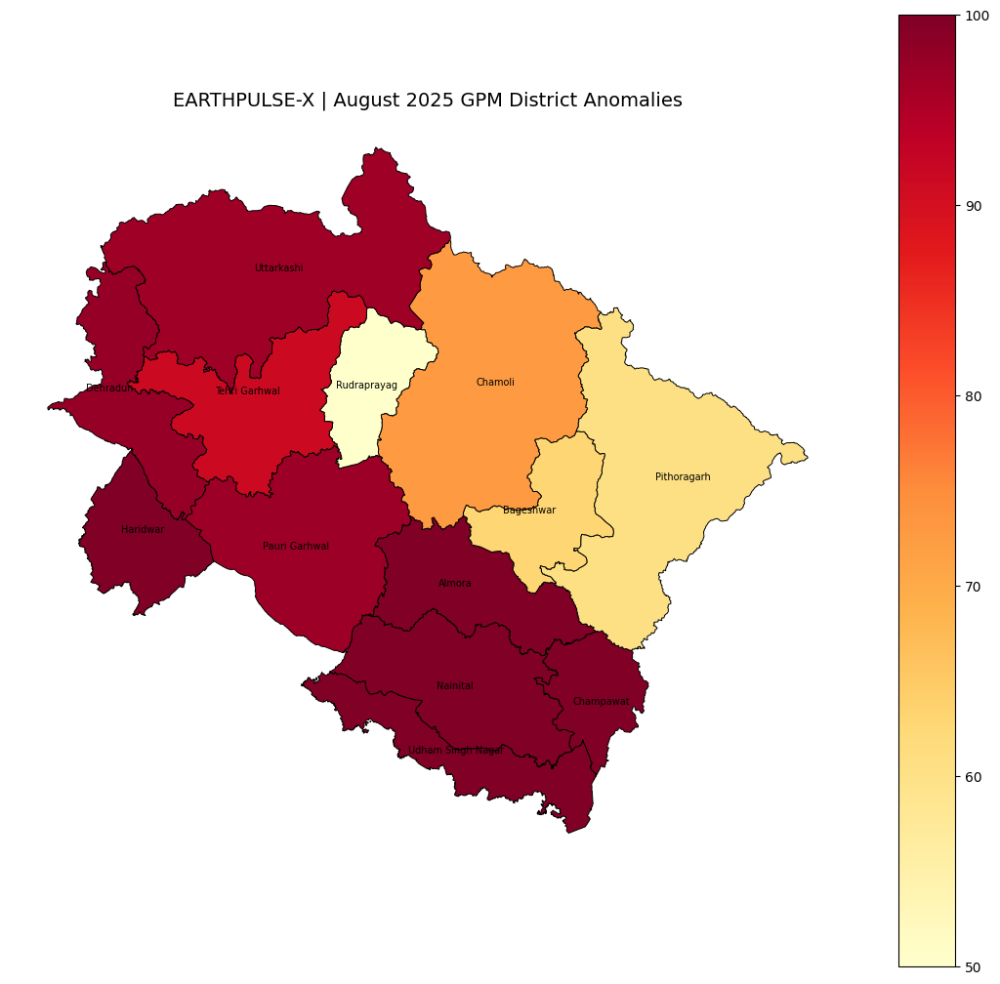


DISTRICT-LEVEL ANOMALY RESULTS


,district_name,valid_pixels,high_anomaly_pixels,low_anomaly_pixels,mean_precipitation_mm,mean_absolute_robust_z,maximum_absolute_robust_z,total_anomaly_pixels,anomaly_pixel_percentage
0,Almora,37,37,0,616.464,7.898,14.611,37,100.000
3,Champawat,23,23,0,505.904,8.481,16.010,23,100.000
11,Udham Singh Nagar,27,27,0,527.525,7.316,10.666,27,100.000
6,Nainital,50,50,0,571.426,7.267,13.560,50,100.000
5,Haridwar,29,29,0,522.379,11.073,24.410,29,100.000
4,Dehradun,40,39,0,570.195,5.223,8.250,39,97.500
7,Pauri Garhwal,64,62,0,587.575,7.123,13.267,62,96.875
12,Uttarkashi,95,92,0,459.259,7.348,15.154,92,96.842
10,Tehri Garhwal,46,42,0,587.853,7.149,13.409,42,91.304
2,Chamoli,99,72,0,560.731,7.276,30.272,72,72.727



DISTRICTS WITH DETECTED ANOMALIES:


,district_name,high_anomaly_pixels,low_anomaly_pixels,anomaly_pixel_percentage,maximum_absolute_robust_z
0,Almora,37,0,100.000,14.611
3,Champawat,23,0,100.000,16.010
11,Udham Singh Nagar,27,0,100.000,10.666
6,Nainital,50,0,100.000,13.560
5,Haridwar,29,0,100.000,24.410
4,Dehradun,39,0,97.500,8.250
7,Pauri Garhwal,62,0,96.875,13.267
12,Uttarkashi,92,0,96.842,15.154
10,Tehri Garhwal,42,0,91.304,13.409
2,Chamoli,72,0,72.727,30.272



Saved: /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_aug2025_gpm_district_intelligence.csv
Saved: /content/drive/MyDrive/EARTHPULSE_X/experiments/results/earthpulse_x_aug2025_gpm_district_map.png

DISTRICT INTELLIGENCE ANALYSIS COMPLETE


In [43]:
import re
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path
from shapely.geometry import Point

ROOT = Path("/content/drive/MyDrive/EARTHPULSE_X")

MONTHLY_DIR = ROOT / "data/processed/harmonized/monthly"
BOUNDARY_PATH = ROOT / "data/raw/boundaries/uttarakhand_13_districts.geojson"
OUT = ROOT / "experiments/results"
OUT.mkdir(parents=True, exist_ok=True)

TARGET_MONTH = "2025_08"
THRESHOLD = 3.5
VARIABLE = "gpm_monthly_precipitation"

print("=" * 70)
print("EARTHPULSE-X | DISTRICT-LEVEL ENVIRONMENTAL INTELLIGENCE")
print("=" * 70)

# --------------------------------------------------
# 1. Identify monthly files correctly
# --------------------------------------------------

def identify_month(file, ds):
    for key in ["month", "date", "time_coverage_start"]:
        value = ds.attrs.get(key)

        if value:
            match = re.search(
                r"(20\d{2})[-_](0[1-9]|1[0-2])",
                str(value)
            )
            if match:
                return f"{match.group(1)}_{match.group(2)}"

    match = re.search(
        r"(20\d{2})[-_](0[1-9]|1[0-2])",
        file.name
    )

    return (
        f"{match.group(1)}_{match.group(2)}"
        if match else None
    )


monthly_files = {}

for file in sorted(MONTHLY_DIR.glob("*.nc")):
    with xr.open_dataset(file) as ds:
        month = identify_month(file, ds)

    if month:
        if month in monthly_files:
            raise ValueError(f"Duplicate month detected: {month}")

        monthly_files[month] = file

if TARGET_MONTH not in monthly_files:
    raise ValueError("August 2025 file not found.")

print("\nMonthly files identified:", len(monthly_files))

# --------------------------------------------------
# 2. Load target and historical August GPM rasters
# --------------------------------------------------

def read_gpm(file):
    with xr.open_dataset(file) as ds:
        if VARIABLE not in ds:
            raise ValueError(f"{VARIABLE} missing in {file.name}")

        da = ds[VARIABLE].squeeze()

        if "y" not in da.dims or "x" not in da.dims:
            raise ValueError(f"Unexpected raster dimensions: {da.dims}")

        da = da.transpose("y", "x")

        values = da.values.astype(float)
        x = ds["x"].values.astype(float)
        y = ds["y"].values.astype(float)

        fill = da.attrs.get(
            "_FillValue",
            da.encoding.get("_FillValue", -9999.9)
        )

        values[values == fill] = np.nan

    return values, x, y


target_data, x, y = read_gpm(monthly_files[TARGET_MONTH])

historical_data = []

for month, file in sorted(monthly_files.items()):
    if month.endswith("_08") and month != TARGET_MONTH:
        values, hx, hy = read_gpm(file)

        if not np.array_equal(x, hx) or not np.array_equal(y, hy):
            raise ValueError(f"Grid mismatch in {month}")

        historical_data.append(values)

history = np.stack(historical_data)

print("Historical August observations:", len(history))
print("Target raster shape:", target_data.shape)

# --------------------------------------------------
# 3. Pixel-wise historical anomaly calculation
# --------------------------------------------------

baseline = np.nanmedian(history, axis=0)

mad = np.nanmedian(
    np.abs(history - baseline),
    axis=0
)

robust_z = np.divide(
    0.6745 * (target_data - baseline),
    mad,
    out=np.full(target_data.shape, np.nan),
    where=np.isfinite(mad) & (mad > 0)
)

valid_mask = np.isfinite(target_data) & np.isfinite(robust_z)

high_anomaly = valid_mask & (robust_z >= THRESHOLD)
low_anomaly = valid_mask & (robust_z <= -THRESHOLD)

print("\nValid anomaly-score pixels:", int(valid_mask.sum()))
print("High precipitation anomaly pixels:", int(high_anomaly.sum()))
print("Low precipitation anomaly pixels:", int(low_anomaly.sum()))
print("Excluded zero-MAD / invalid pixels:",
      int(target_data.size - valid_mask.sum()))

# --------------------------------------------------
# 4. Convert valid pixel centres into GIS points
# --------------------------------------------------

rows, cols = np.where(valid_mask)

pixels = gpd.GeoDataFrame(
    {
        "row": rows,
        "col": cols,
        "precipitation_mm": target_data[rows, cols],
        "robust_z": robust_z[rows, cols],
        "high_anomaly": high_anomaly[rows, cols],
        "low_anomaly": low_anomaly[rows, cols],
        "absolute_z": np.abs(robust_z[rows, cols])
    },
    geometry=[
        Point(float(x[c]), float(y[r]))
        for r, c in zip(rows, cols)
    ],
    crs="EPSG:6933"
)

# --------------------------------------------------
# 5. Spatially attribute pixels to districts
# --------------------------------------------------

districts = gpd.read_file(BOUNDARY_PATH).to_crs("EPSG:6933")

if len(districts) != 13:
    raise ValueError("Expected 13 validated Uttarakhand districts.")

joined = gpd.sjoin(
    pixels,
    districts[["district_name", "geometry"]],
    how="inner",
    predicate="within"
)

# --------------------------------------------------
# 6. District-wise evidence summary
# --------------------------------------------------

summary = (
    joined.groupby("district_name")
    .agg(
        valid_pixels=("robust_z", "size"),
        high_anomaly_pixels=("high_anomaly", "sum"),
        low_anomaly_pixels=("low_anomaly", "sum"),
        mean_precipitation_mm=("precipitation_mm", "mean"),
        mean_absolute_robust_z=("absolute_z", "mean"),
        maximum_absolute_robust_z=("absolute_z", "max")
    )
    .reset_index()
)

summary["total_anomaly_pixels"] = (
    summary["high_anomaly_pixels"] +
    summary["low_anomaly_pixels"]
)

summary["anomaly_pixel_percentage"] = (
    100 * summary["total_anomaly_pixels"] /
    summary["valid_pixels"]
)

# Include districts with no valid pixels
summary = districts[["district_name"]].merge(
    summary,
    on="district_name",
    how="left"
)

summary = summary.sort_values(
    "anomaly_pixel_percentage",
    ascending=False,
    na_position="last"
)

# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

csv_path = OUT / "earthpulse_x_aug2025_gpm_district_intelligence.csv"
summary.to_csv(csv_path, index=False)

# --------------------------------------------------
# 8. Generate district map
# --------------------------------------------------

district_map = districts.merge(
    summary,
    on="district_name",
    how="left"
)

fig, ax = plt.subplots(figsize=(11, 12))

district_map.plot(
    column="anomaly_pixel_percentage",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.7,
    missing_kwds={"color": "lightgrey"},
    ax=ax
)

for _, row in district_map.iterrows():
    point = row.geometry.representative_point()

    ax.annotate(
        row["district_name"],
        (point.x, point.y),
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "EARTHPULSE-X | August 2025 GPM District Anomalies",
    fontsize=14
)

ax.axis("off")
plt.tight_layout()

map_path = OUT / "earthpulse_x_aug2025_gpm_district_map.png"
plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 9. Final scientific summary
# --------------------------------------------------

print("\n" + "=" * 70)
print("DISTRICT-LEVEL ANOMALY RESULTS")
print("=" * 70)

display(summary.round(3))

print("\nDISTRICTS WITH DETECTED ANOMALIES:")

detected = summary[
    summary["total_anomaly_pixels"].fillna(0) > 0
]

if len(detected):
    display(
        detected[
            [
                "district_name",
                "high_anomaly_pixels",
                "low_anomaly_pixels",
                "anomaly_pixel_percentage",
                "maximum_absolute_robust_z"
            ]
        ].round(3)
    )
else:
    print("No district-level anomalies crossed the selected threshold.")

print("\nSaved:", csv_path)
print("Saved:", map_path)

print("\nDISTRICT INTELLIGENCE ANALYSIS COMPLETE")

In [46]:
# ============================================================
# EARTHPULSE-X | GROQ MODEL DISCOVERY + SCIENTIFIC AGENT
# ============================================================

# 1. Fetch models actually available to your API key
available_models = client.models.list()

model_ids = sorted([model.id for model in available_models.data])

print("AVAILABLE GROQ MODELS:")
for model_id in model_ids:
    print(" -", model_id)

# 2. Select a supported replacement
preferred_models = [
    "openai/gpt-oss-120b",
    "qwen/qwen3.8-27b",
    "openai/gpt-oss-20b"
]

MODEL_NAME = next(
    (m for m in preferred_models if m in model_ids),
    None
)

if MODEL_NAME is None:
    raise RuntimeError(
        "No recommended model found. Check the available models above."
    )

print("\nSELECTED MODEL:", MODEL_NAME)

# 3. Run scientific reasoning
response = client.chat.completions.create(
    model=MODEL_NAME,
    messages=[
        {"role": "system", "content": system_prompt},
        {
            "role": "user",
            "content": (
                "Analyse these verified EARTHPULSE-X results. "
                "Explain the August 2025 precipitation anomalies "
                "district-wise. Follow all scientific limitations.\n\n"
                + json.dumps(scientific_data, indent=2)
            )
        }
    ],
    temperature=0.2,
    max_tokens=1800
)

scientific_report = response.choices[0].message.content

print("\n" + "=" * 65)
print("EARTHPULSE-X | SCIENTIFIC REASONING AGENT")
print("MODEL:", MODEL_NAME)
print("=" * 65)
print(scientific_report)

# 4. Save output
output_path = (
    "/content/drive/MyDrive/EARTHPULSE_X/reports/"
    "august_2025_llm_scientific_analysis.txt"
)

with open(output_path, "w", encoding="utf-8") as f:
    f.write(scientific_report)

print("\nREPORT SAVED:", output_path)

AVAILABLE GROQ MODELS:
 - allam-2-7b
 - canopylabs/orpheus-arabic-saudi
 - canopylabs/orpheus-v1-english
 - meta-llama/llama-prompt-guard-2-22m
 - meta-llama/llama-prompt-guard-2-86m
 - openai/gpt-oss-120b
 - openai/gpt-oss-20b
 - openai/gpt-oss-safeguard-20b
 - qwen/qwen3.8-27b
 - whisper-large-v3
 - whisper-large-v3-turbo

SELECTED MODEL: openai/gpt-oss-120b

EARTHPULSE-X | SCIENTIFIC REASONING AGENT
MODEL: openai/gpt-oss-120b
**A. Executive Summary**  
- In August 2025 the GPM satellite recorded unusually high precipitation over Uttarakhand.  
- Using a robust Z‑score (threshold > 3.5) 552 out of 643 valid pixels were classified as “high‑precipitation anomalies.”  
- All districts with valid pixels show a majority of anomalous pixels; five districts (Almora, Champawat, Udham Singh Nagar, Nainital, Haridwar) have 100 % of their scoreable pixels flagged.  
- Mean robust Z‑scores across districts range from 4.38 to 11.07, with maximum values up to 30.27 in Chamoli.  
- The results desc